<img src = "https://drive.google.com/uc?export=view&id=10DJdk95gzrY6H-dKEFKshN814gdMc9FV" alt = "Encabezado MLDS" width = "100%">  </img>

# **Priorización de mesas electorales mediante clasificación, regresión y detección de anomalías: primera vuelta presidencial de Colombia, 2026**
---

**Proyecto aplicado · Entrega final** · Machine Learning · Maestría en Ingeniería de Sistemas y Computación · Universidad Nacional de Colombia

Este notebook reúne, en un solo documento, todas las fases del proyecto desarrolladas con la metodología CRISP-DM: entendimiento del negocio y carga de datos, entendimiento de los datos, preparación de los datos, modelamiento, evaluación y conclusiones.

## **Integrantes del equipo de trabajo**
---

| Integrante | Identificación |
|---|---|
| Alejandra Jaramillo Mejía | 1002652912 |
| Santiago Chaparro Suzunaga | 1002760592 |
| Brayan Sebastián Yepes García | 1015457884 |

**Video de presentación (YouTube):** [AGREGAR ENLACE DEL VIDEO]

## **Resumen del proyecto**
---

**Problema.** En la primera vuelta presidencial de 2026, el escrutinio corrigió el resultado del preconteo en 5 998 de las 118 350 mesas nacionales (5,07 %). Los auditores y observadores electorales no pueden revisar todas las mesas y no cuentan con un criterio analítico para decidir cuáles revisar primero.

**Objetivo de negocio.** Ofrecer un ordenamiento de mesas basado en evidencia, construido solo con información disponible antes del escrutinio, que concentre en pocas mesas la mayor parte de los casos que ameritan revisión.

**Datos.** Archivos oficiales de la Registraduría Nacional del Estado Civil (*Archivos Básicos para Auditores*): preconteo, escrutinio, novedades de los formularios E-11 y E-14, y catálogos (DIVIPOL, candidatos y partidos).

**Enfoque.** Tres componentes de aprendizaje automático sobre un dataset maestro de una fila por mesa:

| Componente | Pregunta | Mejor modelo | Resultado en prueba | Referencia |
|---|---|---|---|---|
| Clasificación | ¿La mesa será corregida? | Random Forest | AP = 0,912; precisión 87 %, recall 89 % | Regla preconteo ≠ E-11: precisión 57 %, recall 90 % |
| Regresión | ¿Cuántos votos cambiarán? | Random Forest | MAE = 3,2 votos; R² = 0,78 | Mediana: MAE = 10,8 votos |
| Detección de anomalías | ¿Qué mesas son atípicas, sin etiquetas? | Isolation Forest | Lift@5 % = 1,90 | Azar: Lift = 1 |

**Resultado principal.** Combinando clasificación y regresión, revisar el **1 % de las mesas cubre el 62,4 % de los votos corregidos**, frente al 8,9 % si se ordena solo por la probabilidad de corrección.

## **Contenido**
---

| Parte | Fase CRISP-DM | Contenido |
|---|---|---|
| **I** | Entendimiento del negocio y carga de datos | Trasfondo, objetivos, alcance, plan, origen y carga de los datos |
| **II** | Entendimiento de los datos | Análisis exploratorio, tipos de variables, calidad y relaciones entre variables del preconteo, el escrutinio y las novedades; comparación entre fuentes |
| **III** | Preparación de los datos | Limpieza de cada fuente (faltantes, duplicados, atípicos, inconsistencias, datos corruptos), selección de datos y construcción del dataset maestro |
| **IV** | Modelamiento, evaluación y aplicación | Selección y diseño de modelos, entrenamiento e hiperparámetros, evaluación en prueba y aplicación para priorizar mesas |
| **V** | Conclusiones | Conclusiones generales, cumplimiento de los objetivos, limitaciones y trabajo futuro |

## **Instrucciones de ejecución**
---

- Ubique este notebook dentro de una subcarpeta de `notebooks/` del repositorio (por ejemplo, `notebooks/05_Final/`). Todas las rutas son relativas: `../../data/raw/`, `../../data/external/geo/` y `../../data/processed/`.
- Los datos originales deben estar descomprimidos en `data/raw/elecciones_2026/extracted/MMV_Presidente1V_2026/MMV_Presidente1V_2026/`. Los ZIP internos se descomprimen en una carpeta temporal, sin modificar los datos originales.
- Las salidas intermedias (`tabla_escrutinio`, `dataset_maestro_v1.csv` y `dataset_maestro.csv`) se guardan en `data/processed/`.
- Librerías: `pandas`, `numpy`, `matplotlib`, `seaborn`, `plotly`, `scipy`, `geopandas` y `scikit-learn`.
- La ejecución completa tarda alrededor de 90 minutos; la búsqueda de hiperparámetros de la clasificación (sección 5.2.1) es la parte más lenta.

# **Parte I. Entendimiento del negocio y carga de datos**
---

## **1. Marco de Proyecto**
---

Normalmente, se suele construir un marco de proyecto para mostrar los resultados del entendimiento del negocio. Para ello, se debe dar respuesta a los siguientes elementos:

### **1.1. Trasfondo del Negocio**
---

- ¿Quién es el cliente o los beneficiarios del proyecto? ¿En qué dominio se encuentran (marketing, medicina, entre otros)?
- ¿Qué problemas del negocio o del dominio estamos tratando de solucionar?

* ¿Quién es el cliente o los beneficiarios del proyecto? ¿En qué dominio se encuentran (marketing, medicina, entre otros)?

El dominio es la auditoría de procesos electorales, en la intersección entre administración pública y análisis de datos.

Se trata de un proyecto académico, sin un cliente institucional que lo haya encargado. Sin embargo, el problema que aborda pertenece a la función de auditoría electoral. Los datos provienen del paquete que la Registraduría Nacional del Estado Civil publica bajo el nombre *Archivos Básicos para Auditores*, concebido para que terceros puedan verificar el proceso de forma independiente; por eso el usuario natural de la solución es quien realiza esa verificación.

De ahí se desprenden los beneficiarios potenciales:

- Los auditores de sistemas que la Registraduría acredita para cada elección, que son el público natural de estos archivos.
- El Consejo Nacional Electoral, que declara los resultados definitivos y resuelve las reclamaciones.
- Los partidos políticos y sus testigos electorales, que tienen derecho a revisar el escrutinio pero carecen de herramientas para priorizar qué revisar entre más de cien mil mesas.
- La Misión de Observación Electoral y otras organizaciones de sociedad civil que hacen seguimiento al proceso.

Y el beneficiario último es la ciudadanía, en la medida en que la confianza en el sistema electoral depende de que existan mecanismos de verificación efectivos y auditables.

* ¿Qué problemas del negocio o del dominio estamos tratando de solucionar?

El análisis de resultados electorales implica procesar numerosos registros asociados a mesas de votación, candidatos, partidos y ubicaciones geográficas. Identificar manualmente patrones inusuales en estos datos puede resultar complejo, especialmente cuando se requiere comparar mesas dentro de un mismo puesto de votación o examinar diferencias entre distintas fuentes de información.

El problema que aborda este proyecto es la ausencia de un procedimiento analítico automatizado que permita identificar y priorizar mesas cuyos patrones de votación se aparten de los observados en otras mesas comparables. Estas diferencias pueden estar relacionadas con características legítimas del comportamiento electoral, particularidades territoriales, problemas de calidad de los datos u otras circunstancias que requieran un análisis adicional.

Para abordar esta necesidad, se propone un prototipo de aprendizaje automático con tres componentes complementarios: (1) un **clasificador supervisado** que estima la probabilidad de que una mesa presente novedades documentadas en los registros oficiales; (2) un **modelo de regresión supervisada** que estima la magnitud de las discrepancias entre preconteo y escrutinio; y (3) un **detector no supervisado** de mesas con patrones multivariados atípicos. Los tres producen puntuaciones que permiten ordenar las mesas y priorizar cuáles revisar primero.

La solución no pretende determinar automáticamente la existencia de fraude ni atribuir irregularidades a las mesas identificadas. Su propósito es apoyar el análisis exploratorio, facilitar la identificación de patrones poco frecuentes y proporcionar información que contribuya a orientar revisiones posteriores. La utilidad de los resultados dependerá de la calidad de los datos, de la comparabilidad entre las mesas y de la validación estadística de los patrones encontrados.


### **1.2. Alcance**
---


Detección de anomalías electorales mediante aprendizaje automático supervisado y no supervisado: estudio de caso de la primera vuelta de las elecciones presidenciales de Colombia de 2026.

#### Objetivo de negocio

Reducir el esfuerzo de revisión de los auditores y observadores electorales, que hoy deben elegir qué revisar entre más de 122 000 mesas sin un criterio analítico de priorización, ofreciéndoles un ordenamiento de mesas basado en evidencia que concentre en pocas mesas la mayor parte de los casos que ameritan revisión.

#### Objetivo general del proyecto de *machine learning*

Desarrollar y evaluar un prototipo de aprendizaje automático supervisado y no supervisado, utilizando exclusivamente registros electorales oficiales de la primera vuelta presidencial de Colombia de 2026, para clasificar novedades documentadas, modelar discrepancias entre preconteo y escrutinio e identificar patrones estadísticamente atípicos, comparando los resultados con métodos estadísticos de referencia y analizando sus limitaciones como herramienta de apoyo a la auditoría electoral.

#### Objetivos específicos

1. Integrar y validar los registros oficiales de preconteo, escrutinio, novedades y catálogos a nivel de mesa.
2. Caracterizar las mesas mediante análisis exploratorio e indicadores de participación, distribución y concentración del voto, y consistencia entre fuentes.
3. Entrenar y comparar clasificadores (regresión logística, árbol de decisión y Random Forest) que estimen la probabilidad de que una mesa presente novedades documentadas.
4. Entrenar y comparar modelos de regresión (lineal, Random Forest y Gradient Boosting) que estimen la magnitud de la discrepancia entre preconteo y escrutinio.
5. Aplicar Isolation Forest y LOF para asignar a cada mesa una puntuación de atipicidad y producir un listado priorizado.
6. Comparar todos los modelos contra métodos estadísticos de referencia y documentar sus limitaciones e interpretación.



In [1]:
import base64
from IPython.display import Image, display

def mermaid(codigo):
    b64 = base64.urlsafe_b64encode(codigo.encode("utf-8")).decode("ascii")
    display(Image(url="https://mermaid.ink/img/" + b64))



#### ¿Qué solución se desea implementar?

Se propone desarrollar un **prototipo académico de análisis de registros electorales mediante técnicas de aprendizaje automático**, orientado a identificar patrones estadísticamente atípicos, clasificar novedades administrativas documentadas y estimar discrepancias entre los resultados de preconteo y escrutinio de la primera vuelta de las elecciones presidenciales de Colombia de 2026.

La solución se implementará utilizando registros electorales oficiales de preconteo, escrutinio, novedades administrativas y catálogos auxiliares. La información se integrará principalmente a nivel de mesa de votación, mediante procedimientos de validación, limpieza, análisis exploratorio e ingeniería de características.

El proyecto comprenderá tres componentes principales de aprendizaje automático:

1. **Clasificación supervisada:** predecir la presencia o ausencia de novedades electorales documentadas mediante regresión logística, árboles de decisión y Random Forest, utilizando etiquetas construidas a partir de registros oficiales.

2. **Regresión supervisada:** estimar la magnitud de las discrepancias observadas entre preconteo y escrutinio mediante modelos de regresión lineal, Random Forest y Gradient Boosting. Se contemplará un enfoque en dos etapas para considerar la elevada proporción de registros sin discrepancias.

3. **Detección no supervisada de anomalías:** identificar mesas de votación con comportamientos estadísticamente atípicos mediante Isolation Forest y Local Outlier Factor (LOF), a partir de indicadores electorales y variables de consistencia.

De manera complementaria, se utilizarán técnicas de **agrupamiento exploratorio**, como K-Means y agrupamiento jerárquico, para caracterizar perfiles de puestos de votación, así como métodos estadísticos robustos que sirvan como referencia para comparar los resultados.

La solución permitirá generar indicadores descriptivos, métricas de evaluación, puntuaciones de atipicidad, visualizaciones y listados de registros que faciliten el análisis comparativo de los diferentes enfoques y la identificación de observaciones que ameriten una revisión adicional.

In [2]:

mermaid("""
%%{init: {
  "theme": "base",
  "flowchart": {
    "curve": "basis",
    "nodeSpacing": 40,
    "rankSpacing": 60,
    "padding": 20,
    "htmlLabels": true
  },
  "themeVariables": {
    "fontFamily": "Helvetica, Arial, sans-serif",
    "fontSize": "14px",
    "lineColor": "#94A3B8",
    "primaryBorderColor": "#CBD5E1",
    "clusterBkg": "#F8FAFC",
    "clusterBorder": "#E2E8F0"
  }
}}%%

flowchart LR

    %% ============================
    %% ACTOR Y ACCESO
    %% ============================

    A(["Investigador, observador<br/>o analista electoral"])

    B["Ejecución del prototipo<br/>en Jupyter Notebook"]

    %% ============================
    %% EXPLORACIÓN Y ANÁLISIS
    %% ============================

    C["Exploración de indicadores<br/>Clasificación · Regresión · Anomalías"]

    D["Análisis de resultados<br/>Modelos · Mesas priorizadas"]

    %% ============================
    %% VALIDACIÓN E INTERPRETACIÓN
    %% ============================

    E["Contraste de hallazgos<br/>con documentación electoral"]

    F(["Documentación de hallazgos<br/>Explicaciones · Limitaciones"])

    %% ============================
    %% FLUJO DE INTERACCIÓN
    %% ============================

    A --> B --> C --> D --> E --> F

    %% ============================
    %% SISTEMA DE DISEÑO
    %% ============================

    classDef data fill:#EFF6FF,stroke:#3B82F6,stroke-width:1.5px,color:#1E40AF

    classDef finding fill:#FEF3C7,stroke:#D97706,stroke-width:2px,color:#92400E

    classDef decision fill:#FFF7ED,stroke:#F59E0B,stroke-width:1.5px,color:#92400E

    classDef alternative fill:#F8FAFC,stroke:#CBD5E1,stroke-width:1.2px,color:#334155

    classDef validation fill:#ECFDF5,stroke:#10B981,stroke-width:1.5px,color:#065F46

    classDef warning fill:#FFF1F2,stroke:#E11D48,stroke-width:2px,color:#9F1239

    %% ============================
    %% ESTILOS COMPLEMENTARIOS
    %% ============================

    classDef actor fill:#FFFFFF,stroke:#3B82F6,stroke-width:2px,color:#1E40AF

    classDef output fill:#DBEAFE,stroke:#2563EB,stroke-width:2px,color:#1E3A8A

    %% ============================
    %% ASIGNACIÓN DE ESTILOS
    %% ============================

    class A actor
    class B,C data
    class D finding
    class E validation
    class F output

    %% ============================
    %% CONECTORES
    %% ============================

    linkStyle default stroke:#94A3B8,stroke-width:1.5px
""")


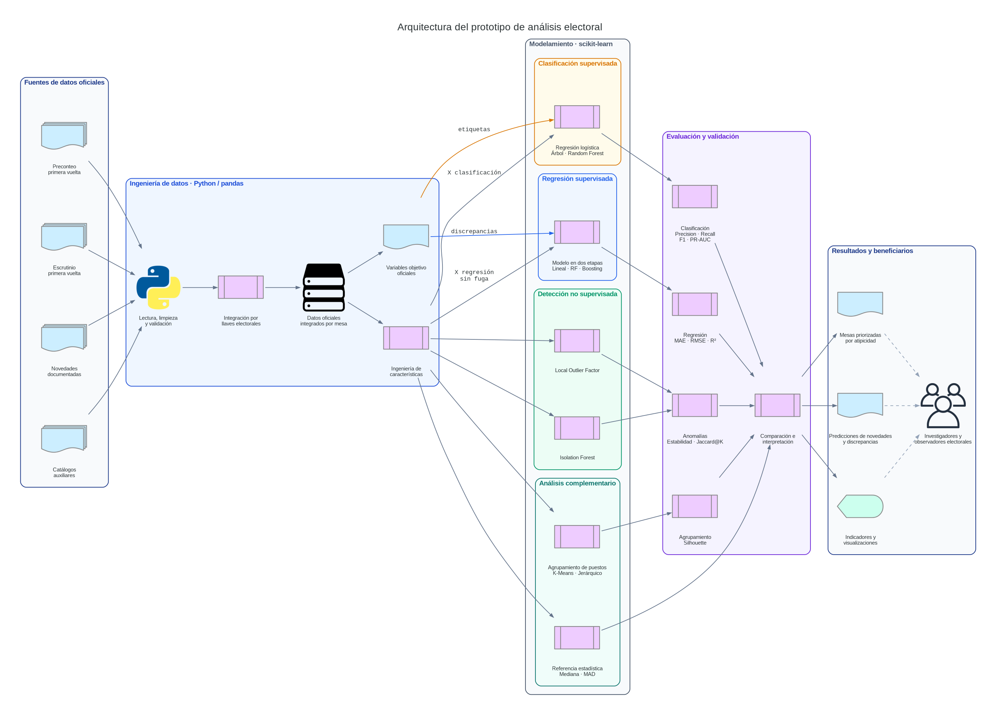

<details><summary>Código de la figura (librería <code>diagrams</code>, requiere Graphviz)</summary>

```python
# Instalación: pip install diagrams (y Graphviz en el sistema)
from diagrams import Diagram, Cluster, Edge
from diagrams.onprem.client import Users
from diagrams.programming.language import Python
from diagrams.programming.flowchart import (
    MultipleDocuments,
    PredefinedProcess,
    Document,
    Display
)
from diagrams.generic.storage import Storage
from IPython.display import Image, display

# ============================================================
# CONFIGURACIÓN VISUAL
# ============================================================

graph_attr = {
    "fontname": "Helvetica",
    "fontsize": "21",
    "bgcolor": "white",
    "pad": "0.6",
    "nodesep": "0.65",
    "ranksep": "1.0",
    "splines": "spline",
    "labelloc": "t"
}

node_attr = {
    "fontname": "Helvetica",
    "fontsize": "11"
}

edge_attr = {
    "color": "#64748B",
    "penwidth": "1.4",
    "arrowsize": "0.8"
}

def zona(fondo, borde):
    return {
        "bgcolor": fondo,
        "pencolor": borde,
        "penwidth": "1.5",
        "fontname": "Helvetica-Bold",
        "fontsize": "14",
        "fontcolor": borde,
        "style": "rounded",
        "margin": "18"
    }

# ============================================================
# ARQUITECTURA DEL PROTOTIPO
# ============================================================

with Diagram(
    "Arquitectura del prototipo de análisis electoral",
    filename="arquitectura",
    outformat="png",
    show=False,
    direction="LR",
    graph_attr=graph_attr,
    node_attr=node_attr,
    edge_attr=edge_attr
):

    # --------------------------------------------------------
    # 1. FUENTES OFICIALES
    # --------------------------------------------------------

    with Cluster(
        "Fuentes de datos oficiales",
        graph_attr=zona("#F8FAFC", "#1E3A8A")
    ):
        pre = MultipleDocuments(
            "Preconteo\nprimera vuelta"
        )

        esc = MultipleDocuments(
            "Escrutinio\nprimera vuelta"
        )

        nov = MultipleDocuments(
            "Novedades\ndocumentadas"
        )

        cat = MultipleDocuments(
            "Catálogos\nauxiliares"
        )

    # --------------------------------------------------------
    # 2. INGENIERÍA DE DATOS
    # --------------------------------------------------------

    with Cluster(
        "Ingeniería de datos · Python / pandas",
        graph_attr=zona("#EFF6FF", "#1D4ED8")
    ):
        etl = Python(
            "Lectura, limpieza\ny validación"
        )

        join = PredefinedProcess(
            "Integración por\nllaves electorales"
        )

        ds = Storage(
            "Datos oficiales\nintegrados por mesa"
        )

        feat = PredefinedProcess(
            "Ingeniería de\ncaracterísticas"
        )

        objetivos = Document(
            "Variables objetivo\noficiales"
        )

        etl >> join >> ds
        ds >> feat
        ds >> objetivos

    # --------------------------------------------------------
    # 3. MODELAMIENTO
    # --------------------------------------------------------

    with Cluster(
        "Modelamiento · scikit-learn",
        graph_attr=zona("#F8FAFC", "#475569")
    ):

        with Cluster(
            "Clasificación supervisada",
            graph_attr=zona("#FFFBEB", "#D97706")
        ):
            clf = PredefinedProcess(
                "Regresión logística\nÁrbol · Random Forest"
            )

        with Cluster(
            "Regresión supervisada",
            graph_attr=zona("#EFF6FF", "#2563EB")
        ):
            reg = PredefinedProcess(
                "Modelo en dos etapas\nLineal · RF · Boosting"
            )

        with Cluster(
            "Detección no supervisada",
            graph_attr=zona("#ECFDF5", "#059669")
        ):
            iso = PredefinedProcess(
                "Isolation Forest"
            )

            lof = PredefinedProcess(
                "Local Outlier Factor"
            )

        with Cluster(
            "Análisis complementario",
            graph_attr=zona("#F0FDFA", "#0F766E")
        ):
            cluster = PredefinedProcess(
                "Agrupamiento de puestos\nK-Means · Jerárquico"
            )

            base = PredefinedProcess(
                "Referencia estadística\nMediana · MAD"
            )

    # --------------------------------------------------------
    # 4. EVALUACIÓN
    # --------------------------------------------------------

    with Cluster(
        "Evaluación y validación",
        graph_attr=zona("#F5F3FF", "#6D28D9")
    ):
        ev_clf = PredefinedProcess(
            "Clasificación\nPrecision · Recall\nF1 · PR-AUC"
        )

        ev_reg = PredefinedProcess(
            "Regresión\nMAE · RMSE · R²"
        )

        ev_uns = PredefinedProcess(
            "Anomalías\nEstabilidad · Jaccard@K"
        )

        ev_group = PredefinedProcess(
            "Agrupamiento\nSilhouette"
        )

        ev = PredefinedProcess(
            "Comparación e\ninterpretación"
        )

    # --------------------------------------------------------
    # 5. RESULTADOS Y BENEFICIARIOS
    # --------------------------------------------------------

    with Cluster(
        "Resultados y beneficiarios",
        graph_attr=zona("#F8FAFC", "#1E3A8A")
    ):
        rank = Document(
            "Mesas priorizadas\npor atipicidad"
        )

        results = Document(
            "Predicciones de novedades\ny discrepancias"
        )

        viz = Display(
            "Indicadores y\nvisualizaciones"
        )

        user = Users(
            "Investigadores y\nobservadores electorales"
        )

    # ========================================================
    # CONEXIONES
    # ========================================================

    # Fuentes -> ingeniería
    for fuente in [pre, esc, nov, cat]:
        fuente >> etl

    # Objetivos supervisados:
    # etiquetas de novedades y discrepancias observadas
    objetivos >> Edge(
        label="etiquetas",
        color="#D97706"
    ) >> clf

    objetivos >> Edge(
        label="discrepancias",
        color="#2563EB"
    ) >> reg

    # Características específicas para cada tarea.
    # En regresión se excluyen variables que revelen
    # directamente la discrepancia objetivo.

    feat >> Edge(
        label="X clasificación"
    ) >> clf

    feat >> Edge(
        label="X regresión\nsin fuga"
    ) >> reg

    feat >> [iso, lof, cluster, base]

    # Modelos -> evaluación
    clf >> ev_clf
    reg >> ev_reg

    iso >> ev_uns
    lof >> ev_uns

    cluster >> ev_group

    # Evaluación integrada
    for evaluacion in [
        ev_clf, ev_reg, ev_uns, ev_group, base
    ]:
        evaluacion >> ev

    # Resultados
    ev >> [rank, results, viz]

    # Revisión humana
    for salida in [rank, results, viz]:
        salida >> Edge(
            style="dashed",
            color="#94A3B8"
        ) >> user

display(Image(filename="arquitectura.png"))
```
</details>

**Figura 2.** *Arquitectura técnica del prototipo de análisis electoral mediante aprendizaje automático (elaboración propia).*

La Figura 2 presenta la integración de registros electorales oficiales, su procesamiento y la construcción de variables para los componentes supervisados y no supervisados. Las variables objetivo se obtienen de novedades documentadas y discrepancias observadas, mientras que las características de entrada se seleccionan según cada tarea para evitar fugas de información. Los resultados se someten a evaluación y comparación antes de generar predicciones, indicadores y listados de observaciones priorizadas para su interpretación por parte de los beneficiarios.

#### ¿Cuáles son los límites y fronteras del proyecto de *machine learning*? ¿Qué aspectos específicos del negocio se incluirán y cuáles se excluyen?

El proyecto se delimita al **análisis retrospectivo de los registros oficiales de la primera vuelta presidencial de Colombia de 2026**, utilizando como unidad principal de análisis la mesa de votación y, de manera complementaria, el puesto electoral. Su alcance comprende la preparación de información, el análisis exploratorio, el desarrollo de modelos de aprendizaje automático y la evaluación de sus resultados.

La delimitación de los aspectos incluidos y excluidos se presenta a continuación.

| Dimensión | Incluido en el alcance | Excluido del alcance |
|---|---|---|
| **Información** | Registros oficiales de preconteo, escrutinio, novedades electorales y catálogos auxiliares. | Datos sintéticos, etiquetas simuladas e información personal de votantes. |
| **Cobertura** | Primera vuelta presidencial de Colombia de 2026, con análisis por mesa, puesto y agrupaciones territoriales. | Predicción de elecciones futuras y generalización automática a otros procesos electorales. |
| **Preparación de datos** | Validación de fuentes, integración de registros, limpieza, análisis descriptivo e ingeniería de características. | Modificación artificial de resultados electorales para generar escenarios hipotéticos. |
| **Clasificación supervisada** | Predicción de novedades administrativas documentadas mediante etiquetas oficiales. | Clasificación de mesas como fraudulentas o legítimas. |
| **Regresión supervisada** | Estimación de la magnitud de las discrepancias entre preconteo y escrutinio. | Determinación de las causas de las discrepancias o de una posible manipulación electoral. |
| **Análisis no supervisado** | Identificación de patrones atípicos y agrupamiento exploratorio de perfiles electorales. | Interpretación automática de anomalías como irregularidades demostradas. |
| **Evaluación** | Métricas específicas por tarea, comparación con referencias estadísticas y validación agrupada territorialmente. | Certificación institucional o jurídica de los resultados. |
| **Producto** | Notebook de Jupyter reproducible, con indicadores, visualizaciones, resultados y documentación metodológica. | Plataforma institucional de auditoría en tiempo real o sistema automático de decisiones. |

**Condiciones y limitaciones metodológicas**

La viabilidad de los componentes supervisados dependerá de la disponibilidad, integridad y correspondencia de los registros oficiales. La clasificación requerirá etiquetas administrativas válidas, mientras que la regresión exigirá un emparejamiento confiable entre preconteo y escrutinio. Se establecerán variables de entrada específicas para cada tarea con el fin de evitar fugas de información desde las variables objetivo.

La evaluación contemplará métricas como precisión, sensibilidad, F1 y PR-AUC para clasificación; MAE, RMSE y R² para regresión; y estabilidad, concordancia entre métodos y Jaccard@K para los análisis no supervisados. Cuando corresponda, se utilizarán particiones agrupadas por departamento para examinar la capacidad de generalización territorial.

Finalmente, **una novedad administrativa, una discrepancia entre registros y una anomalía estadística representan fenómenos diferentes y ninguno constituye, por sí mismo, evidencia de fraude electoral**. Los resultados tendrán carácter exploratorio y deberán interpretarse considerando el contexto y la documentación disponible (Chandola et al., 2009).

#### ¿De qué forma el cliente o beneficiario utilizará el producto del proyecto?

Los usuarios potenciales de la solución son los auditores de sistemas que acredita la Registraduría Nacional del Estado Civil, que son el público al que está dirigido el paquete *Archivos Básicos para Auditores*. Al tratarse de un proyecto académico, no existe un acuerdo formal con la entidad: el prototipo se plantea como una herramienta que estos usuarios, así como el Consejo Nacional Electoral, los testigos de los partidos y organizaciones de observación como la MOE, podrían utilizar para priorizar la revisión de mesas.

El producto consistirá en un **Jupyter Notebook reproducible**, que permitirá ejecutar el procesamiento de registros oficiales, consultar indicadores electorales y examinar los resultados de los modelos desarrollados.

El proceso de utilización comprenderá seis actividades:

1. **Carga y preparación de información:** incorporar los archivos electorales oficiales y ejecutar los procedimientos de lectura, validación e integración de registros.

2. **Exploración de indicadores:** consultar estadísticas descriptivas y visualizaciones de participación, distribución de votos, concentración electoral y consistencia entre fuentes.

3. **Consulta de resultados:** examinar las predicciones de novedades administrativas, las estimaciones de discrepancias y las puntuaciones de atipicidad generadas por los modelos.

4. **Priorización de registros:** identificar mesas que ameriten una revisión adicional a partir de indicadores, resultados de los modelos y criterios de priorización documentados.

5. **Contraste documental:** revisar las observaciones seleccionadas frente a los registros oficiales disponibles, considerando su contexto territorial y administrativo.

6. **Documentación de hallazgos:** registrar las observaciones, posibles explicaciones y limitaciones del análisis para facilitar su interpretación y reproducción.

La **Figura 1** presenta esta secuencia de utilización, desde la ejecución del prototipo hasta la documentación de los hallazgos.

**Figura 1.** *Secuencia de uso previsto del prototipo por beneficiarios potenciales (elaboración propia).*

El valor del producto radica en facilitar el análisis reproducible de información electoral y apoyar la selección de registros para revisión estadística o documental. Su utilización estará orientada a la exploración y el análisis académico, sin reemplazar los procedimientos oficiales de las autoridades electorales.

In [3]:

mermaid("""
%%{init: {
  "theme": "base",
  "flowchart": {
    "curve": "basis",
    "nodeSpacing": 40,
    "rankSpacing": 65,
    "padding": 20,
    "htmlLabels": true
  },
  "themeVariables": {
    "fontFamily": "Helvetica, Arial, sans-serif",
    "fontSize": "14px",
    "lineColor": "#94A3B8",
    "primaryBorderColor": "#CBD5E1",
    "clusterBkg": "#F8FAFC",
    "clusterBorder": "#E2E8F0"
  }
}}%%

flowchart LR

    %% ============================
    %% FUENTES Y PREPROCESAMIENTO
    %% ============================

    A["Datos electorales oficiales<br/>Preconteo · Escrutinio · Novedades<br/>Primera vuelta presidencial 2026"]

    B["Integración y<br/>validación de datos"]

    C["Análisis exploratorio e<br/>ingeniería de características"]

    %% ============================
    %% MODELOS DE MACHINE LEARNING
    %% ============================

    D["Aprendizaje no supervisado<br/>Isolation Forest · LOF"]

    E["Clasificación supervisada<br/>Regresión logística · Random Forest"]

    H["Regresión supervisada<br/>Discrepancias preconteo–escrutinio"]

    %% ============================
    %% EVALUACIÓN Y RESULTADOS
    %% ============================

    F["Evaluación y comparación<br/>con métodos estadísticos"]

    G["Visualización de resultados<br/>Indicadores · Registros priorizados"]

    %% ============================
    %% FLUJO PRINCIPAL
    %% ============================

    A --> B --> C

    C --> D
    C --> E
    C --> H

    D --> F
    E --> F
    H --> F

    F --> G

    %% ============================
    %% SISTEMA DE DISEÑO
    %% ============================

    classDef data fill:#EFF6FF,stroke:#3B82F6,stroke-width:1.5px,color:#1E40AF

    classDef finding fill:#FEF3C7,stroke:#D97706,stroke-width:2px,color:#92400E

    classDef decision fill:#FFF7ED,stroke:#F59E0B,stroke-width:1.5px,color:#92400E

    classDef alternative fill:#F8FAFC,stroke:#CBD5E1,stroke-width:1.2px,color:#334155

    classDef validation fill:#ECFDF5,stroke:#10B981,stroke-width:1.5px,color:#065F46

    classDef warning fill:#FFF1F2,stroke:#E11D48,stroke-width:2px,color:#9F1239

    %% ============================
    %% ASIGNACIÓN DE ESTILOS
    %% ============================

    class A data
    class B,C validation
    class D,E,H alternative
    class F finding
    class G data

    %% ============================
    %% CONECTORES
    %% ============================

    linkStyle default stroke:#94A3B8,stroke-width:1.5px
""")


### **1.3. Plan**
---

Puede agregar una lista de actividades con tiempos estimados, un diagrama de Gantt o integrar alguna herramienta de gestión de proyectos para mostrar la planeación del proyecto como [*Jira*](https://www.atlassian.com/software/jira?&aceid=&adposition=&adgroup=144583570757&campaign=19313283508&creative=641924587890&device=c&keyword=jira%20software%20online&matchtype=p&network=g&placement=&ds_kids=p74602877891&ds_e=GOOGLE&ds_eid=700000001558501&ds_e1=GOOGLE&gad_source=1&gclid=CjwKCAiAqNSsBhAvEiwAn_tmxStBdySS6RxbLNGXE0tWTeJc32ffjQD_1EXZvH6hmQkYZm5bTa3sgBoCX3oQAvD_BwE&gclsrc=aw.ds) o [*Trello*](https://trello.com/?&aceid=&adposition=&adgroup=144675712219&campaign=19250238609&creative=641300630637&device=c&keyword=trello&matchtype=e&network=g&placement=&ds_kids=p74526213668&ds_e=GOOGLE&ds_eid=700000001557344&ds_e1=GOOGLE&gad_source=1&gclid=CjwKCAiAqNSsBhAvEiwAn_tmxWW7Gdzf0Szf-mA-piM2GPM7tk8R0HsgpBALLGHNFq1-2xXMQbxB1RoCs-sQAvD_BwE&gclsrc=aw.ds).

El proyecto se planeó siguiendo las fases de CRISP-DM, con una entrega al cierre de cada una:

| Fase | Periodo | Actividades principales | Entregable |
|---|---|---|---|
| 1. Entendimiento del negocio y carga de datos | 10 – 14 oct | Objetivos de negocio, metas de ML, planeación, recolección y código de carga de los datos | Notebook fase 1 |
| 2. Entendimiento de los datos | 15 – 21 oct | Autenticación de fuentes, diccionario de datos, calidad, análisis descriptivo y exploratorio, visualizaciones | Notebook fase 2 |
| 3. Preparación de los datos | 22 – 28 oct | Limpieza, tabla por mesa, variables de consistencia, variable objetivo, preprocesamiento y partición | Notebook fase 3 |
| 4. Modelamiento y validación | 29 oct – 4 nov | Diseño experimental, métricas, clasificación, regresión y detección de anomalías | Notebook fase 4 |
| 5. Evaluación y entrega final | 4 – 9 nov | Evaluación en prueba, impacto sobre los objetivos de negocio, notebook integrado, video y sustentación (7 nov) | Notebook final y video |

## **2. Datos**
---

En esta sección debe adjuntar una descripción de los datos y agregar el código que permite su tratamiento.

### **2.1. Origen**
---

#### ¿De dónde vienen los datos?

Los datos son de la **Registraduría Nacional del Estado Civil (RNEC)** y corresponden a la **primera vuelta presidencial del 31 de mayo de 2026**. Forman parte del paquete que la RNEC pone a disposición de los auditores electorales para verificar los resultados de forma independiente.

Un archivo **MMV (*Mesa a Mesa con Votos*)** registra los votos de cada candidatura en cada mesa de votación del país. Es el nivel más desagregado de resultados que publica la RNEC. El proyecto usa estos archivos:

| Archivo | Contenido | Registros |
|---|---|---|
| `PRE1v_MMV_9999_PRECONTEO.txt` | MMV del **preconteo**: conteo rápido de la noche electoral | 1 479 506 |
| `_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv` | MMV del **escrutinio**: conteo oficial con validez jurídica | 1 952 320 |
| `Novedad20260603.csv` | Novedades por mesa: reconteos, tachaduras, estado del sobre, mesas excluidas, votos en urna, E-11 y E-14 | 118 350 |
| `ARCHIVOSBASICOS_..._V3.zip` | Catálogos de puestos (`DIVIPOL`), candidatos, partidos y tipos de puesto | — |
| `Estructuras_Basicas_1808.pdf` | Diccionario oficial de campos | — |

#### ¿Se usa alguna herramienta o proceso para la descarga de la información?

No se usa una API ni *web scraping*. El archivo `MMV_Presidente1V_2026.zip` se descarga manualmente del [Observatorio Electoral de la RNEC](https://observatorio.registraduria.gov.co/views/electoral/historicos-resultados.php). Antes de cargar los datos, su integridad se verifica con las **huellas criptográficas (MD5 y SHA-256)** que publica la RNEC junto con cada archivo.

#### ¿Qué tipo de datos estamos manejando?

Son **datos estructurados y tabulares** de una sola jornada electoral. La **unidad de análisis es la mesa**: 122 020 mesas en total, de las cuales 118 350 tienen registro de novedades. Las 3 670 restantes son del exterior.

- **Categóricos:** códigos de departamento, municipio, zona, puesto, mesa, partido y candidato.
- **Numéricos discretos:** votos, potencial de votantes, sufragantes, votos en urna y votos incinerados.
- **Dicotómicos (SI/NO):** las novedades del escrutinio, que se usarán para construir la etiqueta supervisada.

Los MMV vienen en **formato largo**: una fila por mesa y candidatura, con 16 candidaturas por mesa (13 candidatos más voto en blanco, nulo y no marcado). Los formatos también son distintos: el preconteo es de ancho fijo, el escrutinio está separado por `;` y los catálogos están codificados en latin-1.

El paquete se descarga del portal de resultados históricos de la Registraduría:

https://observatorio.registraduria.gov.co/views/electoral/historicos-resultados.php

Primera vuelta 31 de mayo 2026

### **2.2. Carga o Adquisición de Datos**
---

**Antes de ejecutar:** el paquete `MMV_Presidente1V_2026.zip` debe estar descomprimido en `data/raw/elecciones_2026/extracted/` del repositorio (ver *Instrucciones de ejecución*).

El proceso de carga tiene cinco pasos: descomprimir el paquete, verificar las huellas oficiales, leer cada archivo según *Estructuras Básicas*, normalizar las llaves de mesa y comprobar el cruce entre fuentes.

#### 2.2.1. Descompresión

In [4]:
import hashlib
import zipfile
from pathlib import Path
import pandas as pd

import tempfile

# Paquete descomprimido dentro del repositorio
DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)
assert DATA_DIR.is_dir(), f"No se encontró el directorio de datos: {DATA_DIR.resolve()}"

# Los ZIP internos se descomprimen en una carpeta temporal
EXTRA_DIR = Path(tempfile.gettempdir()) / "mmv_presidente_2026"
EXTRA_DIR.mkdir(parents=True, exist_ok=True)

def buscar_archivo(patron: str, directorios=(DATA_DIR, EXTRA_DIR)) -> Path:
    for d in directorios:
        resultados = list(Path(d).rglob(patron))
        if resultados:
            return resultados[0]
    raise FileNotFoundError(f"No se encontró '{patron}'")

for zip_interno in ["ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip", "Novedad20260603.zip"]:
    with zipfile.ZipFile(DATA_DIR / zip_interno) as z:
        z.extractall(EXTRA_DIR / Path(zip_interno).stem)

ARCH_PRECONTEO  = buscar_archivo("PRE1v_MMV_9999_PRECONTEO.txt")
ARCH_ESCRUTINIO = buscar_archivo("_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv")
ARCH_NOVEDADES  = buscar_archivo("Novedad20260603.csv")
DIR_BASICOS     = buscar_archivo("HASH.txt").parent

#### 2.2.2. Verificación de integridad

Se compara la huella de cada archivo con la publicada por la RNEC. Si alguna no coincide, la ejecución se detiene.

In [5]:
def calcular_hash(ruta: Path, algoritmo: str = "md5") -> str:
    h = hashlib.new(algoritmo)
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

def hashes_rnec(ruta_hash: Path) -> dict:
    """Lee el HASH.txt de los archivos básicos (UTF-16) -> {archivo: md5}."""
    out, nombre = {}, None
    for linea in ruta_hash.read_text(encoding="utf-16").splitlines():
        if ":" not in linea:
            continue
        clave, valor = [s.strip() for s in linea.split(":", 1)]
        if clave == "Filename":
            nombre = valor
        elif clave == "MD5" and nombre:
            out[nombre] = valor.lower()
    return out

# MD5 de los MMV tomados de los archivos HASH_*.txt de la RNEC
MD5_OFICIAL = {
    ARCH_PRECONTEO.name:  "f957d26d6c9ab7eba8e25d14b48047ea",
    ARCH_ESCRUTINIO.name: "08ae9a4affd1f0c7fdab6c90e8ea2805",
}
MD5_OFICIAL.update(hashes_rnec(DIR_BASICOS / "HASH.txt"))

rutas = {ARCH_PRECONTEO.name: ARCH_PRECONTEO, ARCH_ESCRUTINIO.name: ARCH_ESCRUTINIO}
verificacion = [(n, "md5", calcular_hash(rutas.get(n, DIR_BASICOS / n)) == ref)
                for n, ref in MD5_OFICIAL.items()]

sha_ref = buscar_archivo("HuellaHash.txt").read_text().strip().lower()
verificacion.append((ARCH_NOVEDADES.name, "sha256",
                     calcular_hash(ARCH_NOVEDADES, "sha256") == sha_ref))

df_hash = pd.DataFrame(verificacion, columns=["archivo", "algoritmo", "coincide"])
display(df_hash)
assert df_hash["coincide"].all(), "Algún archivo no coincide con la huella publicada"

,archivo,algoritmo,coincide
0,PRE1v_MMV_9999_PRECONTEO.txt,md5,True
1,_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv,md5,True
2,INDICADORES_20260526_132437_01.TXT,md5,True
3,DIVIPOL_20260526_132437_01.TXT,md5,True
4,CANDIDATOS_20260516_083436_01.TXT,md5,True
5,CIRCUNSCRIPCION_20260516_083436_01.TXT,md5,True
6,CORPORACION_20260516_083436_01.TXT,md5,True
7,PARTIDOS_20260516_083436_01.TXT,md5,True
8,Novedad20260603.csv,sha256,True


#### 2.2.3. Archivos MMV

El preconteo es de ancho fijo (38 caracteres por registro) y el escrutinio está delimitado por `;`. Las llaves se leen como texto para no perder los ceros a la izquierda.

In [6]:
COLS_PRE   = ["dep", "mun", "zona", "puesto", "mesa", "jal", "comunicado",
              "circ", "partido", "candidato", "votos"]
ANCHOS_PRE = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]
precon = pd.read_fwf(ARCH_PRECONTEO, widths=ANCHOS_PRE, names=COLS_PRE,
                     dtype=str, encoding="latin-1")
precon["votos"] = precon["votos"].astype("int64")

COLS_ESC = ["comunicado", "dep", "mun", "zona", "puesto", "mesa", "comuna",
            "corporacion", "circ", "partido", "candidato", "votos"]
escru = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, usecols=range(12),
                    names=COLS_ESC, dtype=str, encoding="latin-1")
escru["votos"] = escru["votos"].astype("int64")

display(precon.head(3), escru.head(3))

,dep,mun,zona,puesto,mesa,jal,comunicado,circ,partido,candidato,votos
0,01,001,01,01,000001,00,9999,0,00009,011,27
1,01,001,01,01,000001,00,9999,0,00015,012,5
2,01,001,01,01,000001,00,9999,0,00020,006,1


,comunicado,dep,mun,zona,puesto,mesa,comuna,corporacion,circ,partido,candidato,votos
0,9999,01,001,001,01,000001,00,001,0,0026,001,30
1,9999,01,001,001,01,000001,00,001,0,1004,002,1
2,9999,01,001,001,01,000001,00,001,0,1001,003,0


#### 2.2.4. Novedades

En 45 líneas el nombre del puesto contiene comas sin comillas. El lector une esos campos en vez de descartar las líneas, así que conserva las 118 350 mesas.

In [7]:
def leer_novedades(ruta: Path) -> pd.DataFrame:
    with open(ruta, encoding="utf-8") as f:   # el archivo de novedades está en UTF-8
        encabezado = f.readline().rstrip("\r\n").split(",")
        n_campos, i_nombre = len(encabezado), encabezado.index("puestoNombre")
        n_cola = n_campos - i_nombre - 1
        filas, reparadas = [], 0
        for linea in f:
            partes = linea.rstrip("\r\n").split(",")
            if len(partes) > n_campos:
                partes = (partes[:i_nombre]
                          + [",".join(partes[i_nombre:len(partes) - n_cola])]
                          + partes[-n_cola:])
                reparadas += 1
            filas.append(partes)
    print(f"Novedades: {reparadas} líneas reparadas")
    return pd.DataFrame(filas, columns=encabezado)

noved = leer_novedades(ARCH_NOVEDADES)
COLS_NUM_NOV = ["potencial", "sufragantesSegunE11", "firmasJurados", "votosUrna",
                "votosIncinerados", "sufragantesE11SegunE14", "totalVotos"]
noved[COLS_NUM_NOV] = noved[COLS_NUM_NOV].apply(pd.to_numeric, errors="coerce")
noved.head(3)

Novedades: 45 líneas reparadas


,id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,...,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos
0,010100101011,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,1,001,...,BUENO,NO,NO,NO,NO,6,128,0,128,127
1,010100101012,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,2,001,...,BUENO,NO,NO,NO,NO,6,65,0,65,65
2,010100101013,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,3,001,...,BUENO,NO,NO,NO,NO,6,107,0,107,107


#### 2.2.5. Catálogos y normalización de llaves

Los catálogos son de ancho fijo y están en latin-1. Después de leerlos se igualan las longitudes de las llaves (zona a 3 dígitos, partido a 5, mesa a 6), de modo que todas las fuentes comparten la llave de mesa `dep + mun + zona + puesto + mesa`.

In [8]:
def leer_catalogo(prefijo: str, anchos, nombres) -> pd.DataFrame:
    ruta = next(DIR_BASICOS.glob(f"{prefijo}_*.TXT"))
    df = pd.read_fwf(ruta, widths=anchos, names=nombres, dtype=str, encoding="latin-1")
    return df.apply(lambda s: s.str.strip())

divipol = leer_catalogo(
    "DIVIPOL", [2, 3, 2, 2, 12, 30, 40, 1, 8, 8, 6, 2, 30],
    ["dep", "mun", "zona", "puesto", "dep_nombre", "mun_nombre", "puesto_nombre",
     "indicador_puesto", "potencial_hombres", "potencial_mujeres", "n_mesas",
     "comuna", "comuna_nombre"])
for c in ["potencial_hombres", "potencial_mujeres", "n_mesas"]:
    divipol[c] = divipol[c].astype("int64")

partidos = leer_catalogo("PARTIDOS", [5, 200], ["partido", "partido_nombre"])
candidatos = leer_catalogo(
    "CANDIDATOS", [3, 1, 2, 3, 2, 5, 3, 1, 50, 50, 15, 1, 2],
    ["corporacion", "circ", "dep", "mun", "comuna", "partido", "candidato",
     "preferente", "nombre", "apellido", "cedula", "genero", "sorteo"])
indicadores = leer_catalogo("INDICADORES", [1, 100, 4],
                            ["indicador_puesto", "descripcion", "potencial_max_mesa"])
ESPECIALES = {"996": "VOTO EN BLANCO", "997": "VOTOS NULOS", "998": "VOTOS NO MARCADOS"}

# Normalización de llaves
LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]
for df in (precon, escru):
    df["zona"] = df["zona"].str.zfill(3)
    df["partido"] = df["partido"].str.zfill(5)
divipol["zona"] = divipol["zona"].str.zfill(3)

noved = noved.rename(columns={"departamentoCodigo": "dep", "municipioCodigo": "mun",
                              "zonaNombre": "zona", "puestoCodigo": "puesto",
                              "mesaNumero": "mesa"})
noved["zona"] = noved["zona"].str.zfill(3)
noved["mesa"] = noved["mesa"].str.zfill(6)

candidatos[["candidato", "nombre", "apellido", "partido"]]

,candidato,nombre,apellido,partido
0,001,IVÁN,CEPEDA CASTRO,00026
1,002,CLAUDIA,LÓPEZ,01004
2,003,RAÚL SANTIAGO,BOTERO JARAMILLO,01001
3,004,ABELARDO,DE LA ESPRIELLA,01003
4,005,ÓSCAR MAURICIO,LIZCANO ARANGO,03001
5,006,MIGUEL,URIBE LONDOÑO,00020
6,007,SONDRA MACOLLINS,GARVIN PINTO,01002
7,008,ROY LEONARDO,BARRERAS MONTEALEGRE,00022
8,009,CARLOS EDUARDO,CAICEDO OMAR,01006
9,010,GUSTAVO,MATAMOROS CAMACHO,00021


#### 2.2.6. Tipos de datos

Perfil de las columnas de las tres fuentes principales. Las llaves se mantienen como texto para conservar los ceros a la izquierda, y los conteos son enteros.

In [9]:
def perfil(df: pd.DataFrame, nombre: str) -> pd.DataFrame:
    return pd.DataFrame({
        "fuente": nombre,
        "columna": df.columns,
        "tipo": df.dtypes.astype(str).values,
        "no_nulos": df.notna().sum().values,
        "valores_unicos": df.nunique().values,
        "ejemplo": df.iloc[0].astype(str).values,
    })

tipos = pd.concat([perfil(precon, "preconteo"),
                   perfil(escru, "escrutinio"),
                   perfil(noved, "novedades")], ignore_index=True)
display(tipos)

,fuente,columna,tipo,no_nulos,valores_unicos,ejemplo
0,preconteo,dep,str,1479506,34,01
1,preconteo,mun,str,1479506,309,001
2,preconteo,zona,str,1479506,52,001
3,preconteo,puesto,str,1479506,208,01
4,preconteo,mesa,str,1479506,228,000001
5,preconteo,jal,str,1479506,1,00
6,preconteo,comunicado,str,1479506,1,9999
7,preconteo,circ,str,1479506,1,0
8,preconteo,partido,str,1479506,14,00009
9,preconteo,candidato,str,1479506,16,011


Las llaves electorales (departamento, municipio, zona, puesto y mesa) y los códigos de partido y candidato se conservan como texto (`object`) para no perder los ceros a la izquierda, y todos los conteos de votos y sufragantes quedan como enteros (`int64`). Ninguna columna de las tres fuentes presenta valores nulos. Las seis banderas del archivo de novedades (`enTerminos`, `estadoSobre`, `tachadurasEnmendaduras`, `recontadaJurados`, `recontadaComision` y `excluida`) tienen dos valores posibles, pero están almacenadas como texto; en la fase de preparación se convertirán a variables binarias (0/1) para construir la etiqueta supervisada.

#### 2.2.7. Resumen de la carga

Resultado esperado: 122 020 mesas en el preconteo y en el escrutinio, y 118 350 en novedades, todas presentes en el escrutinio.

In [10]:
resumen = pd.DataFrame({
    "fuente":   ["preconteo", "escrutinio", "novedades", "divipol", "partidos", "candidatos"],
    "filas":    [len(precon), len(escru), len(noved), len(divipol), len(partidos), len(candidatos)],
    "columnas": [precon.shape[1], escru.shape[1], noved.shape[1], divipol.shape[1],
                 partidos.shape[1], candidatos.shape[1]],
    "mesas":    [precon[LLAVE_MESA].drop_duplicates().shape[0],
                 escru[LLAVE_MESA].drop_duplicates().shape[0],
                 noved[LLAVE_MESA].drop_duplicates().shape[0], None, None, None],
    "votos_totales": [precon["votos"].sum(), escru["votos"].sum(), None, None, None, None],
})
display(resumen)

m_pre = set(map(tuple, precon[LLAVE_MESA].drop_duplicates().values))
m_esc = set(map(tuple, escru[LLAVE_MESA].drop_duplicates().values))
m_nov = set(map(tuple, noved[LLAVE_MESA].drop_duplicates().values))
print(f"Mesas en preconteo ∩ escrutinio: {len(m_pre & m_esc):,}")
print(f"Mesas de novedades en escrutinio: {len(m_nov & m_esc):,} de {len(m_nov):,}")

,fuente,filas,columnas,mesas,votos_totales
0,preconteo,1479506,11,122020.0,23978304.0
1,escrutinio,1952320,12,122020.0,23990635.0
2,novedades,118350,24,118350.0,NaN
3,divipol,14438,13,NaN,NaN
4,partidos,13,2,NaN,NaN
5,candidatos,13,13,NaN,NaN


Mesas en preconteo ∩ escrutinio: 122,020
Mesas de novedades en escrutinio: 118,350 de 118,350


#### 2.2.8. Conclusiones de la carga y observaciones sobre los datos

La carga cumple el resultado esperado: las seis fuentes se leyeron completas, las huellas criptográficas coinciden con las publicadas por la RNEC y las 122 020 mesas del preconteo y del escrutinio se emparejan una a una mediante la llave `dep + mun + zona + puesto + mesa`, al igual que las 118 350 mesas del archivo de novedades. A partir de la carga se identifican las siguientes características de los datos, que se tendrán en cuenta en las fases siguientes:

- **El preconteo omite los registros con cero votos.** El escrutinio tiene exactamente 16 filas por mesa (122 020 × 16 = 1 952 320), mientras que el preconteo tiene 1 479 506 porque no incluye las combinaciones mesa–candidatura sin votos. Para comparar ambas fuentes, la ausencia de un registro en el preconteo se interpretará como cero votos.
- **Los totales de ambas fuentes difieren.** El escrutinio suma 23 990 635 votos y el preconteo 23 978 304, una diferencia de 12 331 votos (0.05 %). Esta diferencia agregada es pequeña, pero se distribuye de forma desigual entre mesas y constituye la base de la variable de discrepancia.
- **Candidatos retirados.** Los votos de los candidatos con código 009 y 013 se trasladan al código 998 (votos no marcados) en el escrutinio. Este traslado administrativo no es una corrección de la mesa y se aislará al construir la variable de discrepancia, para no confundirlo con diferencias reales entre preconteo y escrutinio.
- **Cobertura de las novedades.** Las 3 670 mesas del exterior no tienen registro de novedades, por lo que el componente de clasificación se limitará a las 118 350 mesas nacionales.
- **Calidad del archivo de novedades.** 45 líneas tienen comas dentro del nombre del puesto; se repararon sin descartar ninguna mesa. Este archivo no está descrito en el documento *Estructuras Básicas*, por lo que su diccionario de campos se construirá en la Fase 2.

# **Parte II. Entendimiento de los datos**
---

## **1. Análisis Exploratorio de los Datos**
---

Normalmente en el análisis exploratorio, se trata de dar respuesta a los siguientes elementos:

#### Contexto: cómo se registra la votación en una mesa

Para interpretar los archivos es necesario conocer los formularios que diligencian los jurados de votación el día de la elección. Los dos principales son el E-11 y el E-14 (Registraduría Nacional del Estado Civil, s. f.).

**Formulario E-11: *Acta de instalación y registro general de votantes*.** Es la lista de las personas que votaron en la mesa. Los jurados registran en él a cada votante, con sus nombres, firma y huella. Al cerrar la votación, el número total de personas registradas es el número de **sufragantes** de la mesa: cuántas personas votaron realmente.

**Formulario E-14: *Acta de escrutinio de los jurados de votación*.** Es el acta donde los jurados anotan los **resultados de la mesa**: los votos de cada candidato y los votos en blanco, nulos y no marcados. Se diligencia en tres copias, cada una con un destino distinto:

| Copia del E-14 | Destino | Relación con los datos del proyecto |
|---|---|---|
| Transmisión | Se entrega al delegado del puesto para transmitir los resultados esa misma noche, con carácter informativo | Origen del **preconteo** |
| Claveros | Se guarda en un sobre y sirve de soporte a la comisión escrutadora | Base del **escrutinio**, el conteo oficial |
| Delegados | Se escanea y se publica en la página de la Registraduría | Consulta pública |

**Secuencia en la mesa.** El proceso sigue este orden:

1. **Votación:** cada votante queda registrado en el E-11.
2. **Nivelación:** al cerrar, los jurados comparan el número de votantes del E-11 con el número de votos de la urna. Si hay más votos que votantes, sacan al azar los votos sobrantes y los **incineran** sin abrirlos.
3. **Conteo:** los jurados cuentan los votos de cada candidato y los anotan en el E-14. Si un testigo lo solicita, pueden **recontar** los votos una sola vez.
4. **Escrutinio:** días después, las comisiones escrutadoras revisan las actas, resuelven reclamaciones y, si es necesario, recuentan votos o excluyen mesas. El resultado es el conteo oficial.

**Relación con las columnas de los archivos.**

| Columna | Qué registra | Etapa |
|---|---|---|
| `sufragantesSegunE11` (novedades) | Personas que votaron, según el E-11 | 1. Votación |
| `votosUrna` (novedades) | Votos encontrados al abrir la urna | 2. Nivelación |
| `votosIncinerados` (novedades) | Votos sobrantes destruidos en la nivelación | 2. Nivelación |
| `sufragantesE11SegunE14` (novedades) | Número de votantes del E-11, tal como se anotó en el E-14 | 3. Conteo |
| `recontadaJurados` (novedades) | Si los jurados recontaron los votos | 3. Conteo |
| Archivo de **preconteo** | Votos por candidato de la copia de transmisión del E-14 | 3. Conteo |
| `recontadaComision`, `excluida` (novedades) | Reconteo o exclusión por la comisión escrutadora | 4. Escrutinio |
| Archivo de **escrutinio** y `totalVotos` (novedades) | Votos por candidato después del escrutinio oficial | 4. Escrutinio |

En una mesa sin problemas, el E-11, los votos de la urna y el total del E-14 coinciden. Por eso, comparar estas cifras entre sí y con el preconteo permite identificar mesas con errores de registro o discrepancias.

Los formularios E-11 y E-14 son documentos físicos diligenciados en cada mesa y no forman parte del paquete de datos. Los archivos de preconteo y de novedades contienen únicamente valores digitados a partir de ellos; por eso, las inconsistencias encontradas pueden deberse tanto a errores en las actas como a errores de digitación, y no es posible distinguir entre ambos con los datos disponibles.

## Preconteo

In [11]:
import base64
import urllib.request
import urllib.error
from IPython.display import Image, display

def mostrar_mermaid(codigo):
    codificado = base64.urlsafe_b64encode(codigo.strip().encode("utf-8")).decode()
    url = f"https://mermaid.ink/img/{codificado}?type=png&bgColor=white"
    peticion = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    try:
        with urllib.request.urlopen(peticion) as respuesta:
            display(Image(data=respuesta.read()))
    except urllib.error.HTTPError as e:
        print(f"mermaid.ink no pudo dibujar el diagrama (error {e.code}). Revisa la sintaxis.")

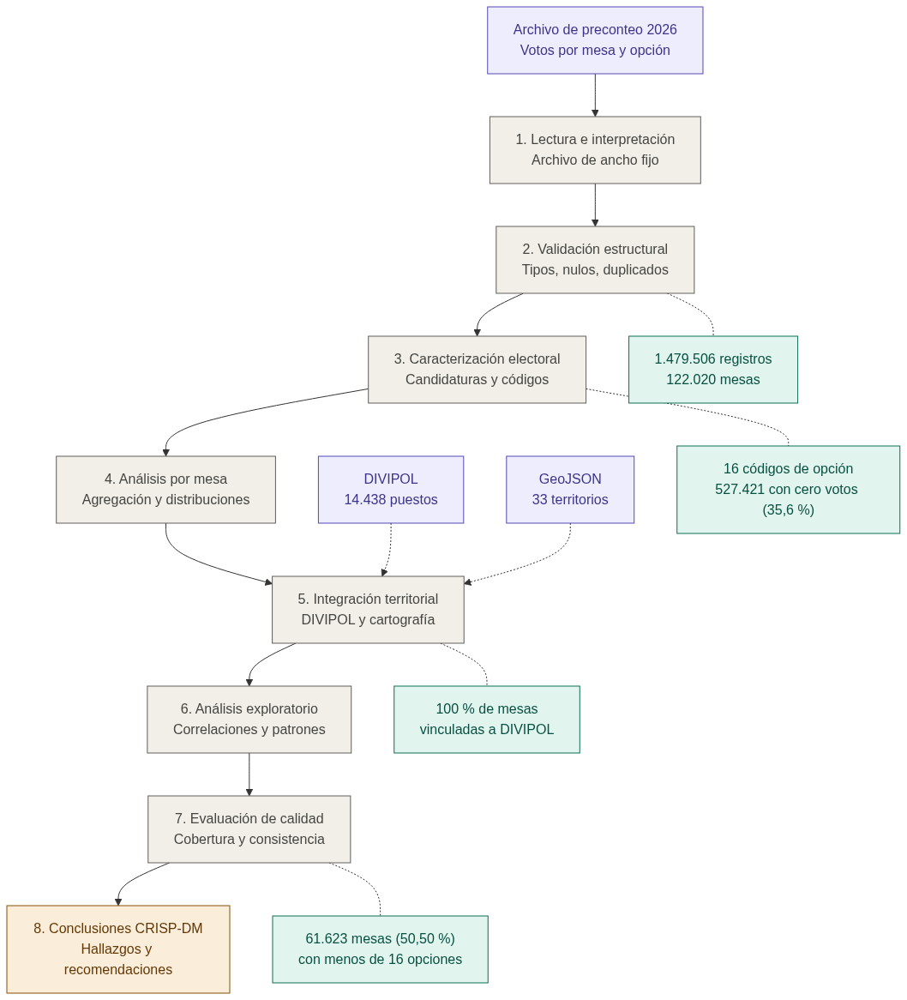

In [12]:
flujo_analisis = """
flowchart TD
    A["Archivo de preconteo 2026<br/>Votos por mesa y opción"]
    B["1. Lectura e interpretación<br/>Archivo de ancho fijo"]
    C["2. Validación estructural<br/>Tipos, nulos, duplicados"]
    D["3. Caracterización electoral<br/>Candidaturas y códigos"]
    E["4. Análisis por mesa<br/>Agregación y distribuciones"]
    F["5. Integración territorial<br/>DIVIPOL y cartografía"]
    G["6. Análisis exploratorio<br/>Correlaciones y patrones"]
    H["7. Evaluación de calidad<br/>Cobertura y consistencia"]
    I["8. Conclusiones CRISP-DM<br/>Hallazgos y recomendaciones"]

    A --> B --> C --> D --> E --> F --> G --> H --> I

    J["DIVIPOL<br/>14.438 puestos"]
    K["GeoJSON<br/>33 territorios"]
    J -.-> F
    K -.-> F

    C -.- R1["1.479.506 registros<br/>122.020 mesas"]
    D -.- R2["16 códigos de opción<br/>527.421 con cero votos (35,6 %)"]
    F -.- R3["100 % de mesas<br/>vinculadas a DIVIPOL"]
    H -.- R4["61.623 mesas (50,50 %)<br/>con menos de 16 opciones"]

    classDef fuente fill:#EEEDFE,stroke:#534AB7,color:#3C3489
    classDef proceso fill:#F1EFE8,stroke:#5F5E5A,color:#444441
    classDef resultado fill:#E1F5EE,stroke:#0F6E56,color:#085041
    classDef conclusion fill:#FAEEDA,stroke:#854F0B,color:#633806

    class A,J,K fuente
    class B,C,D,E,F,G,H proceso
    class R1,R2,R3,R4 resultado
    class I conclusion
"""

mostrar_mermaid(flujo_analisis)

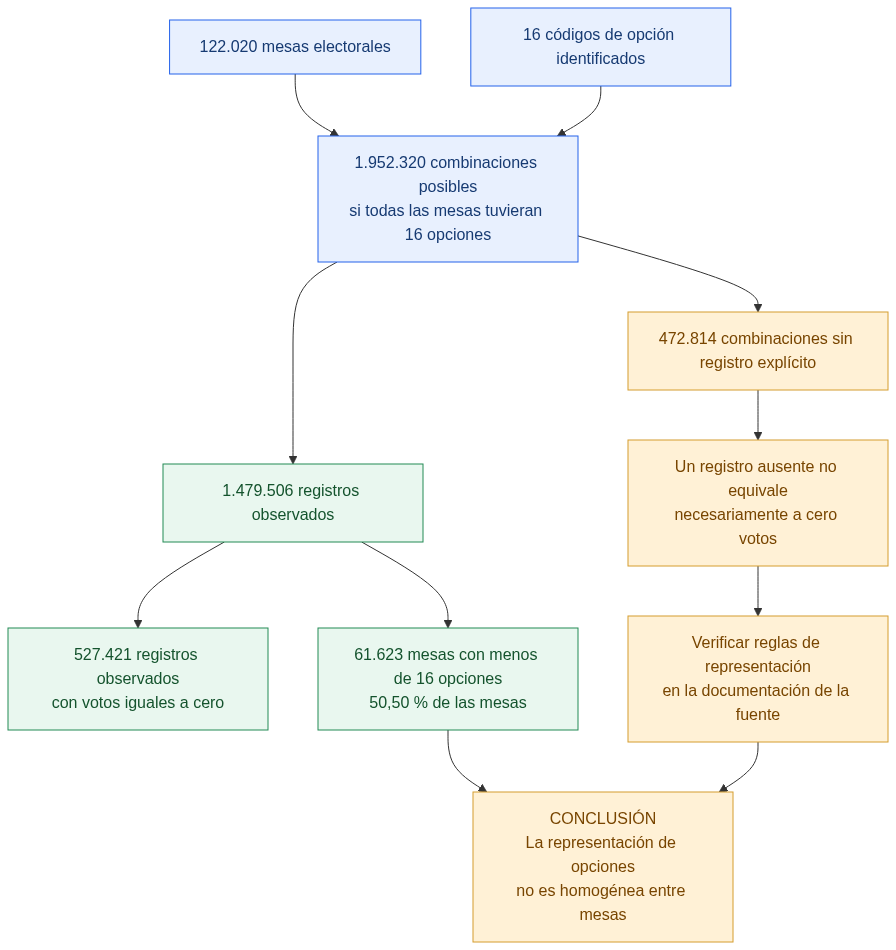

In [13]:
cobertura_opciones = """
flowchart TD
    A["122.020 mesas electorales"]
    B["16 códigos de opción identificados"]
    C["1.952.320 combinaciones posibles<br/>si todas las mesas tuvieran 16 opciones"]
    D["1.479.506 registros observados"]
    E["472.814 combinaciones sin registro explícito"]
    F["527.421 registros observados<br/>con votos iguales a cero"]
    G["Un registro ausente no equivale<br/>necesariamente a cero votos"]
    H["Verificar reglas de representación<br/>en la documentación de la fuente"]
    I["61.623 mesas con menos de 16 opciones<br/>50,50 % de las mesas"]
    J["CONCLUSIÓN<br/>La representación de opciones<br/>no es homogénea entre mesas"]

    A --> C
    B --> C
    C --> D
    C --> E
    D --> F
    D --> I
    E --> G --> H
    I --> J
    H --> J

    classDef dato fill:#e8f0fe,stroke:#2563eb,color:#163a72
    classDef observado fill:#e9f7ef,stroke:#238b55,color:#14532d
    classDef precaucion fill:#fff1d6,stroke:#d69e2e,color:#784500

    class A,B,C dato
    class D,F,I observado
    class E,G,H,J precaucion
"""

mostrar_mermaid(cobertura_opciones)

### Resumen General

**Preguntas abordadas:**
- ¿Cuántos documentos tiene el dataset?
- ¿En qué formato están almacenados los datos?
- ¿Qué tamaño en MB tiene el conjunto de datos?

Los resultados se presentan en el inventario de archivos y en la inspección de las fuentes de información.

### Descripción y alcance del conjunto de datos

El presente análisis se desarrolla en el marco de la fase **Data Understanding** de la metodología CRISP-DM, utilizando los datos de preconteo correspondientes a la primera vuelta de las elecciones presidenciales de Colombia de 2026.

El objetivo de esta etapa es comprender la procedencia, estructura, contenido y características generales de los registros electorales antes de realizar procedimientos de preparación de datos o implementar algoritmos de Machine Learning.

El estudio se concentra en el archivo `PRE1v_MMV_9999_PRECONTEO.txt`, incluido en el paquete `MMV_Presidente1V_2026.zip`. Los demás archivos se consideran recursos documentales o auxiliares, según su función y pertinencia.

El análisis comprende:

- Identificación e inventario de las fuentes disponibles.
- Revisión de la documentación técnica oficial.
- Caracterización del formato y estructura de los registros.
- Verificación preliminar de integridad estructural.
- Identificación de patrones de codificación alfanumérica.
- Evaluación inicial de la viabilidad para construir un conjunto de datos analítico.

Esta etapa se limita a la comprensión de los datos originales. No se realizarán transformaciones irreversibles ni se interpretarán observaciones atípicas como evidencia de irregularidades electorales.

### Fuente de información e inventario de archivos

Los datos provienen de un paquete de información electoral atribuido a la Registraduría Nacional del Estado Civil de Colombia, que contiene registros de votación mesa a mesa, documentación técnica y archivos auxiliares.

Como actividad inicial de *Data Understanding*, se realiza un inventario de los recursos disponibles para identificar sus formatos, tamaños y funciones dentro del proyecto.

| Archivo | Formato | Función dentro del paquete |
|---|---|---|
| `PRE1v_MMV_9999_PRECONTEO.txt` | TXT | Archivo principal de registros de preconteo |
| `_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv` | CSV | Archivo de escrutinio, excluido del alcance analítico |
| `Estructuras Basicas (1808).pdf` | PDF | Especificaciones de campos, tipos y longitudes |
| `HASH_PRE1v_MMV_9999_PRECONTEO.txt` | TXT | Información de integridad del archivo de preconteo |
| `HASH_ficheros_MMV_4_MMV_9999_ESCRUTINIO.txt` | TXT | Información de integridad del archivo de escrutinio |
| `ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip` | ZIP | Archivos auxiliares para interpretación de códigos |
| `Novedad20260603.zip` | ZIP | Archivos complementarios de novedades, pendientes de caracterización |

Los archivos originales se conservan en `data/raw/`, sin modificaciones.

El inventario programático permite verificar la existencia física de los recursos y registrar sus tamaños. La inspección del contenido de los archivos comprimidos auxiliares se realizará posteriormente, antes de utilizarlos como fuentes de referencia.

###### Carga de los datos

Se reutiliza el código de carga de la Fase 1, con un cambio: el archivo de novedades se lee en UTF-8, que es su codificación real. En la Fase 1 se leía en latin-1, lo que alteraba los nombres de puesto con tildes y eñes.

**Nota sobre las dos tablas del preconteo.** La celda siguiente crea `precon` con la carga de la Fase 1 (con `zona` rellenada a 3 caracteres para unificarla con escrutinio y novedades). Más abajo, la sección de preconteo construye `df_preconteo` directamente desde el archivo de ancho fijo, conservando las longitudes originales. Ambas contienen los mismos 1.479.506 registros. La limpieza (sección 1) se hace sobre `df_preconteo`; `precon` se usa en algunas verificaciones territoriales y en las gráficas de presencia de filas.


In [14]:
import zipfile
import tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# --- Ubicación de los datos en el repositorio ---
DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)
assert DATA_DIR.is_dir(), f"No se encontró el directorio de datos: {DATA_DIR.resolve()}"

# Los ZIP internos (catálogos y novedades) se descomprimen en una carpeta temporal,
# para no modificar la carpeta de datos originales del repositorio.
EXTRA_DIR = Path(tempfile.gettempdir()) / "mmv_presidente_2026"
EXTRA_DIR.mkdir(parents=True, exist_ok=True)
for zip_interno in ["ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip", "Novedad20260603.zip"]:
    with zipfile.ZipFile(DATA_DIR / zip_interno) as z:
        z.extractall(EXTRA_DIR / Path(zip_interno).stem)

def buscar_archivo(patron, directorios=(DATA_DIR, EXTRA_DIR)):
    for d in directorios:
        resultados = list(Path(d).rglob(patron))
        if resultados:
            return resultados[0]
    raise FileNotFoundError(f"No se encontró '{patron}'")

ARCH_PRECONTEO  = buscar_archivo("PRE1v_MMV_9999_PRECONTEO.txt")
ARCH_ESCRUTINIO = buscar_archivo("_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv")
ARCH_NOVEDADES  = buscar_archivo("Novedad20260603.csv")
DIR_BASICOS     = buscar_archivo("HASH.txt").parent
PRECONTEO_PATH  = ARCH_PRECONTEO          # nombre que usa la sección de preconteo

# --- Preconteo (ancho fijo) ---
COLS_PRE   = ["dep", "mun", "zona", "puesto", "mesa", "jal", "comunicado",
              "circ", "partido", "candidato", "votos"]
ANCHOS_PRE = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]
precon = pd.read_fwf(ARCH_PRECONTEO, widths=ANCHOS_PRE, names=COLS_PRE,
                     dtype=str, encoding="latin-1")
precon["votos"] = precon["votos"].astype("int64")

# --- Escrutinio (separado por ;) ---
COLS_ESC = ["comunicado", "dep", "mun", "zona", "puesto", "mesa", "comuna",
            "corporacion", "circ", "partido", "candidato", "votos"]
escru = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, usecols=range(12),
                    names=COLS_ESC, dtype=str, encoding="latin-1")
escru["votos"] = escru["votos"].astype("int64")

# --- Novedades (UTF-8; repara las 45 líneas con comas en el nombre del puesto) ---
def leer_novedades(ruta):
    with open(ruta, encoding="utf-8") as f:
        encabezado = f.readline().rstrip("\r\n").split(",")
        n_campos, i_nombre = len(encabezado), encabezado.index("puestoNombre")
        n_cola = n_campos - i_nombre - 1
        filas = []
        for linea in f:
            partes = linea.rstrip("\r\n").split(",")
            if len(partes) > n_campos:
                partes = (partes[:i_nombre]
                          + [",".join(partes[i_nombre:len(partes) - n_cola])]
                          + partes[-n_cola:])
            filas.append(partes)
    return pd.DataFrame(filas, columns=encabezado)

noved = leer_novedades(ARCH_NOVEDADES)
COLS_NUM_NOV = ["potencial", "sufragantesSegunE11", "firmasJurados", "votosUrna",
                "votosIncinerados", "sufragantesE11SegunE14", "totalVotos"]
noved[COLS_NUM_NOV] = noved[COLS_NUM_NOV].apply(pd.to_numeric, errors="coerce")

# --- Catálogos (ancho fijo) ---
def leer_catalogo(prefijo, anchos, nombres):
    ruta = next(DIR_BASICOS.glob(f"{prefijo}_*.TXT"))
    df = pd.read_fwf(ruta, widths=anchos, names=nombres, dtype=str, encoding="latin-1")
    return df.apply(lambda s: s.str.strip())

divipol = leer_catalogo(
    "DIVIPOL", [2, 3, 2, 2, 12, 30, 40, 1, 8, 8, 6, 2, 30],
    ["dep", "mun", "zona", "puesto", "dep_nombre", "mun_nombre", "puesto_nombre",
     "indicador_puesto", "potencial_hombres", "potencial_mujeres", "n_mesas",
     "comuna", "comuna_nombre"])
for c in ["potencial_hombres", "potencial_mujeres", "n_mesas"]:
    divipol[c] = divipol[c].astype("int64")
candidatos = leer_catalogo(
    "CANDIDATOS", [3, 1, 2, 3, 2, 5, 3, 1, 50, 50, 15, 1, 2],
    ["corporacion", "circ", "dep", "mun", "comuna", "partido", "candidato",
     "preferente", "nombre", "apellido", "cedula", "genero", "sorteo"])

# --- Normalización de llaves ---
LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]
for df in (precon, escru):
    df["zona"] = df["zona"].str.zfill(3)
    df["partido"] = df["partido"].str.zfill(5)
divipol["zona"] = divipol["zona"].str.zfill(3)
noved = noved.rename(columns={"departamentoCodigo": "dep", "municipioCodigo": "mun",
                              "zonaNombre": "zona", "puestoCodigo": "puesto",
                              "mesaNumero": "mesa"})
noved["zona"] = noved["zona"].str.zfill(3)
noved["mesa"] = noved["mesa"].str.zfill(6)

print(f"Preconteo: {len(precon):,} | Escrutinio: {len(escru):,} | "
      f"Novedades: {len(noved):,} | DIVIPOL: {len(divipol):,}")

Preconteo: 1,479,506 | Escrutinio: 1,952,320 | Novedades: 118,350 | DIVIPOL: 14,438


In [15]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)

PRECONTEO_PATH = DATA_DIR / "PRE1v_MMV_9999_PRECONTEO.txt"

assert DATA_DIR.is_dir(), "No se encontró el directorio de datos."
assert PRECONTEO_PATH.is_file(), "No se encontró el archivo de preconteo."

### Documentación oficial y formato de almacenamiento

La interpretación del archivo de preconteo se fundamenta en el documento `Estructuras Basicas (1808).pdf`, incluido en el paquete electoral.

La documentación describe la organización de los archivos de votación mesa a mesa (MMV) y establece las características de almacenamiento de sus registros.

#### Formato de longitud fija

El archivo de preconteo utiliza una estructura de **ancho fijo (*fixed-width format*)**. A diferencia de un archivo CSV convencional, los campos no están separados por delimitadores, sino que ocupan posiciones predeterminadas dentro de cada registro.

La estructura documentada tiene una longitud de 38 caracteres, sin incluir los caracteres de terminación de línea.

Los registros finalizan con `CRLF`, correspondiente a retorno de carro y avance de línea.

Los campos numéricos utilizan longitudes definidas y pueden contener ceros a la izquierda. Por esta razón, los códigos administrativos deben conservarse inicialmente como cadenas de caracteres, evitando conversiones numéricas que alteren su representación.

#### Diccionario estructural de preconteo

| Campo oficial | Tipo | Longitud | Posiciones |
|---|---|---:|---|
| Código departamento | Numérico | 2 | 1–2 |
| Código municipio | Numérico | 3 | 3–5 |
| Zona | Alfanumérico | 2 | 6–7 |
| Puesto | Alfanumérico | 2 | 8–9 |
| Número de mesa | Numérico | 6 | 10–15 |
| Código JAL | Numérico | 2 | 16–17 |
| Número del comunicado | Numérico | 4 | 18–21 |
| Código de circunscripción | Numérico | 1 | 22 |
| Código de Lista o Partido | Numérico | 5 | 23–27 |
| Código de candidato | Numérico | 3 | 28–30 |
| Votos | Numérico | 8 | 31–38 |
| **Total** | | **38** | |

La documentación establece que el campo `Número del comunicado` tiene el valor `9999` para esta estructura.

#### Granularidad de los registros

Cada fila contiene información de identificación territorial y de mesa, junto con códigos electorales y una cantidad de votos.

En consecuencia, no debe suponerse que cada fila representa una mesa diferente. Una misma mesa puede estar asociada con múltiples registros electorales.

La identificación de una clave lógica y la definición de la unidad de análisis se realizarán después de cargar e inspeccionar los campos.

**Implicación metodológica:** cualquier agregación de votos por mesa o territorio deberá respetar la estructura documentada y las categorías electorales correspondientes.

El archivo es de **ancho fijo** y está en **formato largo**: cada fila es una combinación *mesa × candidatura* con votos. Las posiciones, longitudes y tipos oficiales de cada campo, así como la validación de que todos los registros los cumplen, están en el notebook principal (`Copy_of_M2U3_fase_2_Entendimiento_de_los_datos`, secciones *Documentación oficial y formato de almacenamiento* y *Validación de los campos según la documentación oficial*). Aquí se documenta el significado de cada variable y su papel en el proyecto.

| # | Variable | Descripción | Tipo estadístico | Dominio observado | Papel en el proyecto |
|---|---|---|---|---|---|
| 1 | `dep` | Código del departamento según la DIVIPOL de la RNEC (no coincide con el código DANE). El código `88` agrupa las mesas del exterior. | Categórica nominal | 34 códigos (`01`–`72` y `88`) | Llave de mesa; agrupación territorial y partición agrupada por departamento. |
| 2 | `mun` | Código del municipio dentro del departamento. Solo es único en combinación con `dep`; en el exterior (`dep = 88`) hay 67 códigos. | Categórica nominal | 309 códigos (`001`–`900`) | Llave de mesa; agrupación territorial. |
| 3 | `zona` | Código de la zona electoral dentro del municipio. Se normaliza a 3 dígitos (`zfill(3)`) para cruzar con escrutinio, novedades y DIVIPOL. | Categórica nominal | 52 códigos (`000`–`099`) | Llave de mesa. |
| 4 | `puesto` | Código del puesto de votación dentro de la zona. Es **alfanumérico**: además de `00`–`99` hay códigos como `A1` o `Z5`. | Categórica nominal | 208 códigos | Llave de mesa; unidad de comparación entre mesas del mismo puesto. |
| 5 | `mesa` | Número de la mesa dentro del puesto, con ceros a la izquierda. | Categórica nominal (identificador) | 228 códigos (`000001`–`000228`) | Llave de mesa; **unidad de análisis**. |
| 6 | `jal` | Código de comuna/JAL (Junta Administradora Local). No aplica a la elección presidencial. | Categórica (constante) | Un único valor (`00`) | Sin variabilidad: se descarta como predictor. |
| 7 | `comunicado` | Número del boletín del preconteo. `9999` identifica el consolidado final. | Categórica (constante) | Un único valor (`9999`) | Metadato de versión; se descarta como predictor. |
| 8 | `circ` | Código de circunscripción. La elección presidencial tiene circunscripción nacional única. | Categórica (constante) | Un único valor (`0`) | Sin variabilidad: se descarta como predictor. |
| 9 | `partido` | Código del partido o agrupación que inscribe la candidatura. Se normaliza a 5 dígitos (`zfill(5)`); se traduce con el catálogo `PARTIDOS`. Los códigos especiales 996, 997 y 998 llevan partido `00000`, que no está en el catálogo. | Categórica nominal | 14 códigos (13 partidos y `00000`) | Identifica la candidatura junto con `candidato`. |
| 10 | `candidato` | Código de la candidatura: `001`–`013` son los candidatos (catálogo `CANDIDATOS`); `996` voto en blanco, `997` votos nulos y `998` votos no marcados. | Categórica nominal | 16 códigos | Pivote para pasar a una fila por mesa; base de los indicadores de distribución y concentración del voto. |
| 11 | `votos` | Número de votos de la candidatura en la mesa según el preconteo. | Numérica discreta (conteo ≥ 0) | 0 – 694 (398 valores distintos) | Base de la variable de discrepancia preconteo–escrutinio (regresión) y de los indicadores para la detección de anomalías. |

**Llave de mesa.** Ninguna variable identifica la mesa por sí sola: la llave es la combinación `dep + mun + zona + puesto + mesa`, compartida con el escrutinio y las novedades tras la normalización. La llave de cada fila del preconteo es `llave de mesa + candidato`.

Los dominios observados se obtuvieron sobre el archivo completo. La celda siguiente los recalcula directamente sobre los datos.

In [16]:
DESCRIPCIONES = {
    "dep":        "Código del departamento (DIVIPOL RNEC)",
    "mun":        "Código del municipio dentro del departamento",
    "zona":       "Código de la zona electoral (normalizado a 3 dígitos)",
    "puesto":     "Código del puesto de votación dentro de la zona",
    "mesa":       "Número de la mesa dentro del puesto",
    "jal":        "Código de comuna/JAL (no aplica a presidencial)",
    "comunicado": "Número de boletín (9999 = consolidado final)",
    "circ":       "Código de circunscripción",
    "partido":    "Código del partido (normalizado a 5 dígitos)",
    "candidato":  "Código de candidatura (001-013, 996, 997, 998)",
    "votos":      "Votos de la candidatura en la mesa",
}
TIPO_ESTADISTICO = {c: "Categórica nominal" for c in COLS_PRE}
TIPO_ESTADISTICO["votos"] = "Numérica discreta"

def resumir_dominio(s: pd.Series) -> str:
    if pd.api.types.is_numeric_dtype(s):
        return f"[{s.min():,} – {s.max():,}]"
    valores = sorted(s.unique())
    if len(valores) <= 16:
        return ", ".join(valores)
    return f"{valores[0]} … {valores[-1]}"

diccionario_pre = pd.DataFrame({
    "variable": COLS_PRE,
    "descripcion": [DESCRIPCIONES[c] for c in COLS_PRE],
    "tipo_estadistico": [TIPO_ESTADISTICO[c] for c in COLS_PRE],
    "valores_unicos": precon[COLS_PRE].nunique().values,
    "dominio": [resumir_dominio(precon[c]) for c in COLS_PRE],
})
pd.set_option("display.max_colwidth", 120)
display(diccionario_pre)

,variable,descripcion,tipo_estadistico,valores_unicos,dominio
0,dep,Código del departamento (DIVIPOL RNEC),Categórica nominal,34,01 … 88
1,mun,Código del municipio dentro del departamento,Categórica nominal,309,001 … 900
2,zona,Código de la zona electoral (normalizado a 3 dígitos),Categórica nominal,52,000 … 099
3,puesto,Código del puesto de votación dentro de la zona,Categórica nominal,208,00 … Z5
4,mesa,Número de la mesa dentro del puesto,Categórica nominal,228,000001 … 000228
5,jal,Código de comuna/JAL (no aplica a presidencial),Categórica nominal,1,00
6,comunicado,Número de boletín (9999 = consolidado final),Categórica nominal,1,9999
7,circ,Código de circunscripción,Categórica nominal,1,0
8,partido,Código del partido (normalizado a 5 dígitos),Categórica nominal,14,"00000, 00009, 00015, 00020, 00021, 00022, 00026, 01001, 01002, 01003, 01004, 01005, 01006, 03001"
9,candidato,"Código de candidatura (001-013, 996, 997, 998)",Categórica nominal,16,"001, 002, 003, 004, 005, 006, 007, 008, 009, 010, 011, 012, 013, 996, 997, 998"


#### Cobertura territorial: departamentos, municipios y consulados

El código de departamento `88` corresponde a los consulados. Se separan las combinaciones territoriales nacionales de las del exterior, porque los consulados no tienen formulario E-11 y más adelante se excluyen del análisis.

In [17]:
print(sorted(precon['dep'].unique()))
print('Categorias sin consulados:', precon.loc[precon['dep']!='88'].nunique()

)

# Total de categorías territoriales
print("Total:", precon["dep"].drop_duplicates().shape[0])

# Códigos sin consulados
deps_sin_consulados = sorted(
    precon.loc[precon["dep"] != "88", "dep"].unique()
)

print("Departamentos + Bogotá:", len(deps_sin_consulados))

# Filas correspondientes a consulados
print(
    "Registros de consulados:",
    precon.loc[precon["dep"] == "88"].shape[0]
)

print('numeros de municipios', precon[["dep", "mun"]].drop_duplicates().shape[0]
)

['01', '03', '05', '07', '09', '11', '12', '13', '15', '16', '17', '19', '21', '23', '24', '25', '26', '27', '28', '29', '31', '40', '44', '46', '48', '50', '52', '54', '56', '60', '64', '68', '72', '88']
Categorias sin consulados: dep            33
mun           263
zona           42
puesto        208
mesa          228
jal             1
comunicado      1
circ            1
partido        14
candidato      16
votos         301
dtype: int64
Total: 34
Departamentos + Bogotá: 33
Registros de consulados: 45683
numeros de municipios 1189


In [18]:
# Combinaciones territoriales nacionales
municipios_nacionales = (
    precon.loc[precon["dep"] != "88", ["dep", "mun"]]
    .drop_duplicates()
)

# Combinaciones asociadas a consulados
municipios_exterior = (
    precon.loc[precon["dep"] == "88", ["dep", "mun"]]
    .drop_duplicates()
)

print("Combinaciones nacionales:", len(municipios_nacionales))
print("Combinaciones exterior:", len(municipios_exterior))
print("Total:", len(municipios_nacionales) + len(municipios_exterior))

Combinaciones nacionales: 1122
Combinaciones exterior: 67
Total: 1189


In [19]:
display(
    municipios_exterior.sort_values(["dep", "mun"])
)

,dep,mun
1433823,88,115
1433874,88,120
1434527,88,130
1434564,88,135
1434600,88,140
...,...,...
1474296,88,765
1474408,88,770
1474590,88,785
1474714,88,805


### Inspección física de los registros

Antes de construir un DataFrame, se realiza una inspección directa del archivo original en modo binario.

Este procedimiento permite observar su representación física sin introducir supuestos sobre delimitadores, codificación o tipos de datos.

Se examinan los primeros registros y se verifica el tamaño del archivo. Posteriormente se analizará la consistencia de las longitudes, la presencia de registros vacíos y la duplicidad exacta.

La lectura en modo binario permite identificar explícitamente los caracteres de terminación de línea y preservar el contenido original durante la inspección.

In [20]:
print("Archivo:", PRECONTEO_PATH.name)
print("Existe:", PRECONTEO_PATH.exists())
print(
    "Tamaño (MiB):",
    round(PRECONTEO_PATH.stat().st_size / 1024**2, 2)
)

with PRECONTEO_PATH.open("rb") as archivo:
    for i in range(5):
        print(f"Registro {i + 1}:", repr(archivo.readline()))

Archivo: PRE1v_MMV_9999_PRECONTEO.txt
Existe: True
Tamaño (MiB): 56.44
Registro 1: b'01001010100000100999900000901100000027\r\n'
Registro 2: b'01001010100000100999900001501200000005\r\n'
Registro 3: b'01001010100000100999900002000600000001\r\n'
Registro 4: b'01001010100000100999900002101000000000\r\n'
Registro 5: b'01001010100000100999900002200800000000\r\n'


#### Resultados de la lectura preliminar

La inspección confirmó la existencia del archivo `PRE1v_MMV_9999_PRECONTEO.txt`, con un tamaño aproximado de **56,44 MiB**.

Los cinco registros examinados presentan una secuencia de 38 caracteres, seguida por los caracteres de terminación `\r\n`.

El resultado es compatible con el formato de longitud fija descrito en la documentación técnica.

No se identificaron encabezados ni delimitadores convencionales en los registros inspeccionados. Por tanto, la lectura posterior deberá realizarse mediante posiciones de campos y no mediante separación por comas o puntos y coma.

Esta observación inicial no permite concluir que todos los registros cumplen el formato. Para ello se realiza una verificación sobre el archivo completo.

### Perfilamiento estructural del archivo completo

Se realiza un procedimiento de *structural data profiling* para evaluar las características físicas de todos los registros.

Se consideran cinco indicadores:

- **Número de registros:** volumen total de observaciones.
- **Longitud de registros:** consistencia con la estructura de 38 caracteres.
- **Registros vacíos:** presencia de líneas sin contenido.
- **Registros con caracteres no numéricos:** identificación preliminar de valores alfanuméricos.
- **Duplicados exactos:** frecuencia de líneas con contenido idéntico.

La presencia de caracteres no numéricos no se considera automáticamente un error, debido a que la documentación oficial define campos alfanuméricos.

Asimismo, la ausencia de duplicados exactos no garantiza la unicidad lógica de los registros electorales, dado que esta depende de la identificación de una clave apropiada.

In [21]:
from collections import Counter

longitudes = Counter()
registros_vacios = 0
registros_no_numericos = 0
duplicados_exactos = 0
registros_vistos = set()
total_registros = 0

with PRECONTEO_PATH.open("rb") as archivo:
    for linea in archivo:
        registro = linea.rstrip(b"\r\n")
        total_registros += 1

        longitudes[len(registro)] += 1

        if not registro:
            registros_vacios += 1

        if not registro.isdigit():
            registros_no_numericos += 1

        if registro in registros_vistos:
            duplicados_exactos += 1
        else:
            registros_vistos.add(registro)

resumen_estructura = pd.DataFrame({
    "Indicador": [
        "Total de registros",
        "Registros de 38 caracteres",
        "Registros vacíos",
        "Registros con caracteres no numéricos",
        "Duplicados exactos"
    ],
    "Cantidad": [
        total_registros,
        longitudes[38],
        registros_vacios,
        registros_no_numericos,
        duplicados_exactos
    ]
})

resumen_estructura["Porcentaje"] = (
    100 * resumen_estructura["Cantidad"] / total_registros
)

display(resumen_estructura)
print("Distribución de longitudes:", dict(longitudes))

,Indicador,Cantidad,Porcentaje
0,Total de registros,1479506,100.000000
1,Registros de 38 caracteres,1479506,100.000000
2,Registros vacíos,0,0.000000
3,Registros con caracteres no numéricos,12517,0.846026
4,Duplicados exactos,0,0.000000


Distribución de longitudes: {38: 1479506}


#### Resultados del perfilamiento estructural

El análisis completo produjo los siguientes resultados:

| Indicador | Resultado |
|---|---:|
| Total de registros | 1.479.506 |
| Registros de 38 caracteres | 1.479.506 |
| Registros con longitud diferente | 0 |
| Registros vacíos | 0 |
| Registros con caracteres no numéricos | 12.517 |
| Registros duplicados exactos | 0 |

La totalidad de los registros presenta una longitud uniforme de 38 caracteres, lo que confirma la consistencia física del archivo respecto a la longitud establecida en la documentación.

No se identificaron registros vacíos ni líneas exactamente duplicadas.

Se encontraron **12.517 registros (aproximadamente 0,85 %)** con caracteres distintos de dígitos. Este resultado requiere examinar su ubicación dentro de la estructura antes de determinar si representa alguna inconsistencia.

En términos generales, el archivo presenta una estructura física homogénea. Sin embargo, la validación de los tipos de campos y de los códigos administrativos requiere comprobaciones adicionales.

### Validación de los campos según la documentación oficial

Una vez verificada la longitud de los registros, se contrasta su contenido con las restricciones establecidas en `Estructuras Basicas (1808).pdf`.

Esta validación examina:

- La longitud total de 38 caracteres.
- La composición numérica de los campos declarados como numéricos.
- La composición alfanumérica de los campos `Zona` y `Puesto`.
- El valor constante `9999` del campo `Número del comunicado`.

Esta comprobación evalúa el cumplimiento del esquema físico y de los tipos de datos documentados. No constituye todavía una validación completa de los dominios electorales, que requerirá consultar los archivos básicos auxiliares.

In [22]:
campos = [
    ("departamento", 2, "numerico"),
    ("municipio", 3, "numerico"),
    ("zona", 2, "alfanumerico"),
    ("puesto", 2, "alfanumerico"),
    ("mesa", 6, "numerico"),
    ("jal", 2, "numerico"),
    ("comunicado", 4, "numerico"),
    ("circunscripcion", 1, "numerico"),
    ("lista_partido", 5, "numerico"),
    ("candidato", 3, "numerico"),
    ("votos", 8, "numerico"),
]

assert sum(longitud for _, longitud, _ in campos) == 38

errores = Counter()
ejemplos_errores = []

with PRECONTEO_PATH.open("rb") as archivo:
    for numero_linea, linea in enumerate(archivo, start=1):
        registro = linea.rstrip(b"\r\n")

        if len(registro) != 38:
            errores["longitud_incorrecta"] += 1
            continue

        inicio = 0

        for nombre, longitud, tipo in campos:
            valor = registro[inicio:inicio + longitud]
            inicio += longitud

            if tipo == "numerico":
                valido = valor.isdigit()
            else:
                valido = all(
                    48 <= c <= 57 or
                    65 <= c <= 90 or
                    97 <= c <= 122
                    for c in valor
                )

            if not valido:
                errores[f"tipo_invalido_{nombre}"] += 1

                if len(ejemplos_errores) < 10:
                    ejemplos_errores.append(
                        (numero_linea, nombre, repr(valor))
                    )

        if registro[17:21] != b"9999":
            errores["comunicado_incorrecto"] += 1

print("Inconsistencias por regla:", dict(errores))
print("Ejemplos:", ejemplos_errores)

Inconsistencias por regla: {}
Ejemplos: []


#### Interpretación de la validación estructural

La validación del esquema oficial permite determinar si los registros cumplen las restricciones de longitud, tipo de campo y valor constante del comunicado.

La ausencia de incumplimientos en estas comprobaciones indicaría que el archivo es estructuralmente compatible con el formato documentado por la Registraduría.

No obstante, esta validación no garantiza que todos los códigos de departamento, municipio, zona, puesto, partido o candidato correspondan a valores reconocidos en los catálogos oficiales.

La evaluación de esos dominios se realizará en la etapa de calidad de los datos, mediante el contraste con los archivos auxiliares disponibles.

### Caracterización de los campos alfanuméricos

Durante el perfilamiento inicial se identificaron 12.517 registros con caracteres diferentes de dígitos.

La documentación oficial establece que los campos `Zona` y `Puesto` son alfanuméricos. Por tanto, resulta necesario estudiar la ubicación y frecuencia de estos caracteres para verificar su correspondencia con las posiciones documentadas.

Se analizarán las frecuencias de cada carácter, sus posiciones dentro del registro y ejemplos de las observaciones identificadas.

Este procedimiento permite diferenciar características legítimas del formato de posibles inconsistencias de codificación.

In [23]:
caracteres = Counter()
posiciones = Counter()
ejemplos = []

with PRECONTEO_PATH.open("rb") as archivo:
    for numero_linea, linea in enumerate(archivo, start=1):
        registro = linea.rstrip(b"\r\n")

        if not registro.isdigit():
            if len(ejemplos) < 10:
                ejemplos.append((
                    numero_linea,
                    registro.decode("ascii", errors="replace")
                ))

            for posicion, caracter in enumerate(registro, start=1):
                if not (48 <= caracter <= 57):
                    caracteres[chr(caracter)] += 1
                    posiciones[posicion] += 1

df_caracteres = pd.DataFrame(
    caracteres.items(),
    columns=["Carácter", "Frecuencia"]
).sort_values("Frecuencia", ascending=False)

df_posiciones = pd.DataFrame(
    posiciones.items(),
    columns=["Posición", "Frecuencia"]
).sort_values("Posición")

display(df_caracteres)
display(df_posiciones)

print("Ejemplos:")
for numero, registro in ejemplos:
    print(f"Línea {numero}: {registro}")

,Carácter,Frecuencia
0,A,6074
1,B,3941
2,C,524
3,D,448
4,E,192
22,W,144
14,P,116
17,R,102
10,K,96
7,H,96


,Posición,Frecuencia
0,8,12517
1,9,16


Ejemplos:
Línea 79745: 0100199A100000100999900000901100000032
Línea 79746: 0100199A100000100999900001501200000009
Línea 79747: 0100199A100000100999900002000600000001
Línea 79748: 0100199A100000100999900002101000000000
Línea 79749: 0100199A100000100999900002200800000000
Línea 79750: 0100199A100000100999900002600100000029
Línea 79751: 0100199A100000100999900000099600000000
Línea 79752: 0100199A100000100999900000099700000002
Línea 79753: 0100199A100000100999900000099800000004
Línea 79754: 0100199A100000100999900100100300000001


#### Resultados de la caracterización alfanumérica

El análisis identificó 12.517 registros con caracteres alfabéticos, equivalentes aproximadamente al 0,85 % del conjunto de datos.

Se encontraron 26 letras mayúsculas diferentes. Las más frecuentes fueron `A` (6.074 apariciones) y `B` (3.941 apariciones).

Los caracteres se localizaron exclusivamente en las posiciones 8 y 9:

| Posición | Apariciones |
|---|---:|
| 8 | 12.517 |
| 9 | 16 |

De acuerdo con la estructura oficial, ambas posiciones pertenecen al campo `Puesto`, cuya longitud es de dos caracteres y cuyo tipo es alfanumérico.

Por consiguiente, la presencia de letras en estas posiciones **es compatible con la especificación del archivo y no representa por sí misma un error de calidad**.

Este resultado evidencia la importancia de conservar los códigos administrativos como cadenas de caracteres y utilizar la documentación técnica para interpretar los datos.

La validación de los códigos concretos de puesto frente a los catálogos oficiales permanece pendiente.

### Interpretación de un registro mediante las posiciones oficiales

Para ilustrar la estructura del archivo, se selecciona un registro real que contiene un código de puesto alfanumérico.

El registro se divide utilizando las longitudes establecidas en la documentación oficial. Este procedimiento permite observar cómo se encuentran representados los campos sin alterar los datos originales.

La segmentación también sirve como comprobación preliminar del procedimiento que se utilizará posteriormente para construir el DataFrame.

In [24]:
registro = "0100199A100000100999900000901100000032"

inicio = 0
segmentos = []

for nombre, longitud, tipo in campos:
    valor = registro[inicio:inicio + longitud]

    segmentos.append({
        "Campo": nombre,
        "Posición inicial": inicio + 1,
        "Posición final": inicio + longitud,
        "Valor": valor,
        "Tipo oficial": tipo,
    })

    inicio += longitud

df_segmentos = pd.DataFrame(segmentos)

display(df_segmentos)

,Campo,Posición inicial,Posición final,Valor,Tipo oficial
0,departamento,1,2,01,numerico
1,municipio,3,5,001,numerico
2,zona,6,7,99,alfanumerico
3,puesto,8,9,A1,alfanumerico
4,mesa,10,15,000001,numerico
5,jal,16,17,00,numerico
6,comunicado,18,21,9999,numerico
7,circunscripcion,22,22,0,numerico
8,lista_partido,23,27,00009,numerico
9,candidato,28,30,011,numerico


### Conclusiones de la caracterización estructural

La revisión documental y el análisis preliminar del archivo de preconteo permiten establecer los siguientes hallazgos:

- El archivo contiene **1.479.506 registros** de longitud fija, cada uno con 38 caracteres.
- No se identificaron registros vacíos ni duplicados exactos.
- La estructura observada es consistente con las longitudes especificadas en la documentación oficial.
- Los 12.517 registros que contienen caracteres alfabéticos presentan dichos caracteres en posiciones correspondientes al campo `Puesto`, definido como alfanumérico.
- Los registros contienen información territorial, identificadores electorales y cantidades de votos, pero todavía no se ha determinado la clave lógica que identifica cada observación.

En consecuencia, la inspección inicial proporciona evidencia favorable sobre la consistencia física del archivo, aunque todavía no permite concluir que los datos estén completamente libres de errores.

#### Aspectos pendientes

Para continuar con *Data Understanding* será necesario construir una representación tabular de los registros, identificar las categorías y dominios de cada campo, examinar los catálogos auxiliares y determinar la granularidad apropiada para el análisis electoral.

Estas actividades permitirán avanzar hacia el estudio de distribuciones, calidad de datos y relaciones entre variables, manteniendo la trazabilidad respecto de los archivos originales.

### Construcción de la representación tabular

Una vez comprobada la estructura física del archivo de preconteo, se procede a construir una representación tabular utilizando `pandas`.

La transformación consiste en segmentar cada registro de 38 caracteres según las posiciones y longitudes establecidas en la documentación oficial. Esta operación no modifica los archivos originales y permite analizar los campos de manera independiente.

Inicialmente, todas las variables se conservarán como cadenas de caracteres. Esta decisión es especialmente importante para los códigos administrativos y electorales, cuyos ceros iniciales forman parte de su representación.

Posteriormente, el campo `votos` se convertirá a un tipo entero, previa verificación de su composición numérica.

La construcción del DataFrame constituye una transformación de representación necesaria para la exploración, pero no implica todavía limpieza, eliminación de registros, agregación territorial ni ingeniería de características.

### Construcción y caracterización del conjunto de datos

Una vez verificada la estructura física del archivo de preconteo y su correspondencia con la documentación técnica, se procede a construir una representación tabular mediante la biblioteca `pandas`.

El objetivo de este procedimiento es identificar las dimensiones del

In [25]:
import pandas as pd

nombres_columnas = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "jal",
    "comunicado",
    "circunscripcion",
    "lista_partido",
    "candidato",
    "votos",
]

longitudes = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]

limites = [0]

for longitud in longitudes:
    limites.append(limites[-1] + longitud)

colspecs = list(zip(limites[:-1], limites[1:]))

df_preconteo = pd.read_fwf(
    PRECONTEO_PATH,
    colspecs=colspecs,
    names=nombres_columnas,
    dtype="string",
    header=None,
    keep_default_na=False,
)

assert len(df_preconteo) == total_registros
assert df_preconteo.shape[1] == 11

df_preconteo["votos"] = pd.to_numeric(
    df_preconteo["votos"],
    errors="raise",
).astype("int64")

print("Dimensiones:", df_preconteo.shape)
display(df_preconteo.head(10))

Dimensiones: (1479506, 11)


,departamento,municipio,zona,puesto,mesa,jal,comunicado,circunscripcion,lista_partido,candidato,votos
0,01,001,01,01,000001,00,9999,0,00009,011,27
1,01,001,01,01,000001,00,9999,0,00015,012,5
2,01,001,01,01,000001,00,9999,0,00020,006,1
3,01,001,01,01,000001,00,9999,0,00021,010,0
4,01,001,01,01,000001,00,9999,0,00022,008,0
5,01,001,01,01,000001,00,9999,0,00026,001,30
6,01,001,01,01,000001,00,9999,0,00000,996,3
7,01,001,01,01,000001,00,9999,0,00000,997,0
8,01,001,01,01,000001,00,9999,0,00000,998,1
9,01,001,01,01,000001,00,9999,0,01001,003,0


### Verificación de la representación tabular

Después de cargar el archivo, se verifica que el número de observaciones coincida con el obtenido durante la inspección física y que la representación contenga los once campos establecidos en la documentación oficial.

También se revisan los primeros registros para comprobar que los valores fueron segmentados correctamente y que los códigos conservan su longitud y sus ceros iniciales.

El campo `votos` se representa como una cantidad entera, mientras que los demás campos permanecen como cadenas de caracteres.

Esta verificación es necesaria para evitar errores de interpretación que podrían propagarse a los análisis descriptivos y a las fases posteriores de Machine Learning.

## 1.3. Tipos de variables

**Preguntas abordadas:**
- ¿El conjunto de datos tiene una variable objetivo a estimar? De ser así, ¿es continua o categórica?
- ¿Cómo se distribuyen las variables o etiquetas? ¿Existe desbalance?
- ¿Qué variables adicionales contiene el conjunto de datos y cuáles podrían utilizarse posteriormente en el modelado?

A continuación se presenta la caracterización de las variables del preconteo, sus tipos, cardinalidades y distribuciones.

### Caracterización de variables y cardinalidad

El análisis de variables permite identificar las características generales de los campos disponibles y evaluar su posible utilidad para el problema de investigación.

Se distinguen tres tipos conceptuales de variables:

- **Identificadores administrativos y electorales:** códigos que permiten localizar o relacionar registros, pero que no representan magnitudes cuantitativas.
- **Variables categóricas:** campos que identifican clases, agrupaciones o modalidades electorales.
- **Variables cuantitativas:** cantidades numéricas sobre las cuales pueden realizarse operaciones aritméticas, como el número de votos.

Se calculará la cardinalidad de cada variable, entendida como el número de valores distintos presentes en el conjunto de datos.

También se verificará la presencia de valores vacíos y la longitud de los códigos, como parte de la evaluación preliminar de completitud y consistencia.

Una cardinalidad elevada no constituye necesariamente un problema de calidad. En campos identificadores puede ser una característica esperada de su función.

In [26]:
perfil = []

for columna in df_preconteo.columns:
    serie = df_preconteo[columna]

    perfil.append({
        "Variable": columna,
        "Tipo pandas": str(serie.dtype),
        "Valores únicos": serie.nunique(dropna=True),
        "Valores nulos": serie.isna().sum(),
        "Valores vacíos": (
            serie.eq("").sum()
            if pd.api.types.is_string_dtype(serie)
            else 0
        ),
    })

df_perfil = pd.DataFrame(perfil)

display(df_perfil)

print("\nTipos de datos:")
df_preconteo.info(
    memory_usage="deep",
    show_counts=True
)

,Variable,Tipo pandas,Valores únicos,Valores nulos,Valores vacíos
0,departamento,string,34,0,0
1,municipio,string,309,0,0
2,zona,string,52,0,0
3,puesto,string,208,0,0
4,mesa,string,228,0,0
5,jal,string,1,0,0
6,comunicado,string,1,0,0
7,circunscripcion,string,1,0,0
8,lista_partido,string,14,0,0
9,candidato,string,16,0,0



Tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 1479506 entries, 0 to 1479505
Data columns (total 11 columns):
 #   Column           Non-Null Count    Dtype 
---  ------           --------------    ----- 
 0   departamento     1479506 non-null  string
 1   municipio        1479506 non-null  string
 2   zona             1479506 non-null  string
 3   puesto           1479506 non-null  string
 4   mesa             1479506 non-null  string
 5   jal              1479506 non-null  string
 6   comunicado       1479506 non-null  string
 7   circunscripcion  1479506 non-null  string
 8   lista_partido    1479506 non-null  string
 9   candidato        1479506 non-null  string
 10  votos            1479506 non-null  int64 
dtypes: int64(1), string(10)
memory usage: 745.0 MB


### Identificación de la unidad de observación

Determinar la granularidad del conjunto de datos es indispensable para realizar análisis estadísticos válidos.

La documentación establece que los registros contienen identificadores territoriales, de mesa y de opciones electorales. Sin embargo, la presencia de un identificador de mesa no implica que exista una sola fila por mesa.

Se estudiará la cantidad de combinaciones únicas de departamento, municipio, zona, puesto y mesa, así como el número de registros asociados a cada combinación.

Adicionalmente, se examinará la unicidad de una clave compuesta que incluya los campos electorales disponibles. Esta comprobación permitirá identificar posibles registros repetidos a nivel lógico, sin asumir previamente que una combinación específica constituye una clave primaria definitiva.

La determinación de la granularidad será fundamental para evitar pseudorreplicación, agregaciones incorrectas y problemas de *data leakage* en etapas posteriores.

In [27]:
columnas_mesa = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
]

columnas_clave_candidata = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "jal",
    "comunicado",
    "circunscripcion",
    "lista_partido",
    "candidato",
]

total_mesas = (
    df_preconteo[columnas_mesa]
    .drop_duplicates()
    .shape[0]
)

duplicados_clave = df_preconteo.duplicated(
    subset=columnas_clave_candidata
).sum()

registros_por_mesa = (
    df_preconteo
    .groupby(columnas_mesa, dropna=False)
    .size()
    .rename("n_registros")
    .reset_index()
)

print(f"Registros totales: {len(df_preconteo):,}")
print(f"Combinaciones de mesa: {total_mesas:,}")
print(f"Duplicados de clave candidata: {duplicados_clave:,}")

print("\nDistribución de registros por mesa:")
display(
    registros_por_mesa["n_registros"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
)

Registros totales: 1,479,506
Combinaciones de mesa: 122,020
Duplicados de clave candidata: 0

Distribución de registros por mesa:


,n_registros
count,122020.000000
mean,12.125111
std,4.055918
min,1.000000
25%,8.000000
50%,13.000000
75%,16.000000
90%,16.000000
95%,16.000000
99%,16.000000


#### Resultados de la representación tabular y granularidad

La lectura del archivo de preconteo produjo un DataFrame de **1.479.506 observaciones y 11 variables**, coincidente con el volumen de registros identificado durante la inspección física.

Diez variables se conservaron como cadenas de caracteres (`string`), mientras que `votos` se representó mediante enteros de 64 bits (`int64`). Esta separación permite preservar los identificadores administrativos y realizar operaciones aritméticas sobre las cantidades de votos.

La representación tabular ocupa aproximadamente **745 MB de memoria**, según el cálculo de uso profundo de memoria de pandas.

Al examinar las combinaciones de departamento, municipio, zona, puesto y mesa, se identificaron **122.020 combinaciones distintas**, con un promedio aproximado de **12,13 registros por combinación**.

Esto confirma que la unidad de observación del archivo no corresponde a una mesa electoral única, sino a registros más detallados asociados con mesas y códigos electorales.

Adicionalmente, no se encontraron duplicados bajo la clave compuesta candidata que incluye los identificadores territoriales, de mesa y de opción electoral.

**Implicación metodológica**

La ausencia de duplicados bajo esta clave constituye evidencia favorable sobre la unicidad de los registros, pero no demuestra por sí sola que la clave sea la definición oficial de identificación.

Antes de construir variables agregadas por mesa, será necesario comprender los códigos electorales, verificar los catálogos auxiliares y estudiar la distribución de registros por mesa.

### Distribución de registros por mesa electoral

Una vez identificadas las combinaciones únicas de mesa, se analiza el número de registros asociados a cada una.

Este análisis permite estudiar la heterogeneidad de la representación de las mesas dentro del archivo de preconteo e identificar posibles diferencias en la cantidad de registros electorales asociados a ellas.

Se calcularán medidas de tendencia central y dispersión, incluyendo media, mediana, desviación estándar, valores extremos y cuantiles.

Posteriormente, se utilizarán un histograma y un diagrama de caja (*boxplot*) para examinar la distribución.

Es importante señalar que una cantidad inusual de registros por mesa no constituye automáticamente una anomalía electoral. Su interpretación requiere conocer las reglas de generación de registros y las categorías electorales incluidas.

,Registros por mesa
count,122020.000000
mean,12.125111
std,4.055918
min,1.000000
1%,4.000000
5%,6.000000
25%,8.000000
50%,13.000000
75%,16.000000
95%,16.000000


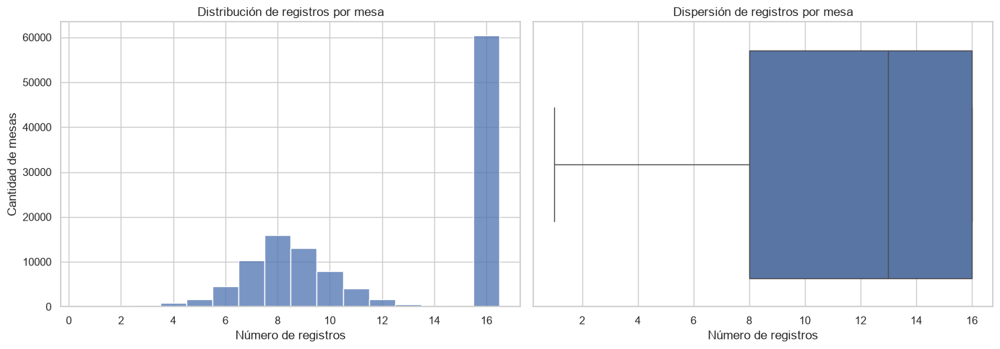

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

conteos = registros_por_mesa["n_registros"]

display(
    conteos.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame("Registros por mesa")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    conteos,
    discrete=True,
    ax=axes[0],
)

axes[0].set_title("Distribución de registros por mesa")
axes[0].set_xlabel("Número de registros")
axes[0].set_ylabel("Cantidad de mesas")

sns.boxplot(
    x=conteos,
    ax=axes[1],
)

axes[1].set_title("Dispersión de registros por mesa")
axes[1].set_xlabel("Número de registros")

plt.tight_layout()
plt.show()

#### Interpretación de la distribución de registros por mesa

El conjunto de preconteo contiene 122.020 combinaciones únicas de mesa electoral, con un promedio de 12,13 registros por mesa y una desviación estándar de 4,06.

La mediana es de 13 registros, mientras que el primer y tercer cuartil corresponden a 8 y 16 registros, respectivamente. Esto indica que la mitad central de las mesas presenta entre 8 y 16 registros.

Se observa un mínimo de 1 registro y un máximo de 16. Además, los percentiles 75, 95 y 99 coinciden en 16 registros, lo cual evidencia una concentración de observaciones en la parte superior de la distribución.

Estos resultados confirman que el número de registros asociados a cada mesa es variable. Sin embargo, esta variabilidad no puede interpretarse directamente como una inconsistencia, dado que todavía no se han caracterizado completamente los códigos de candidato, lista y las reglas de inclusión de registros.

La distribución observada constituye un punto de partida para investigar la estructura electoral de los registros y determinar la unidad de análisis apropiada para etapas posteriores.

### Frecuencia de registros por mesa y composición electoral

Para profundizar en la granularidad del conjunto de datos, se examina la frecuencia de mesas según su número de registros y se comparan los códigos electorales presentes en mesas con diferentes cantidades de observaciones.

Este análisis busca identificar patrones de representación asociados a los campos `lista_partido`, `candidato` y `circunscripcion`.

El propósito es establecer si las diferencias observadas en el número de registros por mesa se relacionan con la composición de las opciones electorales registradas.

No se asumirá que la ausencia de un código equivale a cero votos hasta verificar las reglas de generación del archivo.

In [29]:
frecuencias = (
    registros_por_mesa["n_registros"]
    .value_counts()
    .sort_index()
    .rename_axis("Registros por mesa")
    .reset_index(name="Cantidad de mesas")
)

frecuencias["Porcentaje"] = (
    100 * frecuencias["Cantidad de mesas"] / total_mesas
).round(2)

display(frecuencias)

,Registros por mesa,Cantidad de mesas,Porcentaje
0,1,167,0.14
1,2,228,0.19
2,3,412,0.34
3,4,832,0.68
4,5,1720,1.41
5,6,4514,3.70
6,7,10247,8.40
7,8,15954,13.07
8,9,13012,10.66
9,10,7906,6.48


In [30]:
# Cardinalidad y valores más frecuentes de códigos electorales
for columna in [
    "circunscripcion",
    "lista_partido",
    "candidato",
    "jal",
    "comunicado",
]:
    print(f"\n{columna}")
    print("Valores distintos:", df_preconteo[columna].nunique())

    display(
        df_preconteo[columna]
        .value_counts()
        .head(20)
        .to_frame("Frecuencia")
    )


circunscripcion
Valores distintos: 1


,Frecuencia
circunscripcion,
0,1479506



lista_partido
Valores distintos: 14


,Frecuencia
lista_partido,
00000,302867
00026,121967
01003,121597
00009,120346
00015,117646
01004,106109
01001,102972
03001,78894
00020,73312



candidato
Valores distintos: 16


,Frecuencia
candidato,
001,121967
004,121597
011,120346
012,117646
996,117243
997,109397
002,106109
003,102972
005,78894



jal
Valores distintos: 1


,Frecuencia
jal,
00,1479506



comunicado
Valores distintos: 1


,Frecuencia
comunicado,
9999,1479506


#### Resultados de la caracterización de códigos electorales

El análisis de frecuencias identificó una estructura heterogénea en el número de registros asociados a cada mesa electoral.

De las 122.020 combinaciones de mesa, 60.397 presentan exactamente 16 registros, equivalentes al 49,50 % del total. Las demás combinaciones presentan entre 1 y 15 registros.

En cuanto a los campos electorales, se identificaron 14 valores distintos en `lista_partido` y 16 en `candidato`. Esta cardinalidad sugiere una estructura de registros asociada con un conjunto limitado de opciones electorales.

Adicionalmente, las variables `circunscripcion`, `jal` y `comunicado` presentan un único valor en todas las observaciones. Por tanto, no contienen variabilidad que pueda utilizarse directamente como información predictiva dentro de este archivo.

La presencia de códigos especiales como `996`, `997` y `998` requiere una interpretación respaldada por los archivos oficiales auxiliares.

Finalmente, aunque el máximo de registros por mesa coincide con la cardinalidad del campo `candidato`, es necesario examinar las combinaciones entre `lista_partido` y `candidato` antes de establecer la granularidad electoral definitiva.

### Relación entre códigos de lista y candidato

Para comprender la organización de los registros electorales, se estudia la relación entre los campos `lista_partido` y `candidato`.

El análisis busca identificar las combinaciones distintas de ambos códigos y determinar si existe una correspondencia estable entre ellos.

También se verificará si una misma mesa contiene registros repetidos para una combinación electoral específica.

Esta evaluación permitirá avanzar en la identificación de la clave lógica del conjunto de datos y establecer una base para futuras agregaciones.

Los resultados describirán las relaciones observadas entre códigos, sin atribuirles todavía nombres de candidatos o categorías de votación no confirmados documentalmente.

In [31]:
combinaciones_electorales = (
    df_preconteo
    .groupby(
        ["lista_partido", "candidato"],
        dropna=False
    )
    .agg(
        registros=("votos", "size"),
        mesas_con_registro=("mesa", "size")
    )
    .reset_index()
    .drop(columns="mesas_con_registro")
    .sort_values(
        ["lista_partido", "candidato"]
    )
)

print(
    "Combinaciones electorales distintas:",
    len(combinaciones_electorales)
)

display(combinaciones_electorales)

Combinaciones electorales distintas: 16


,lista_partido,candidato,registros
0,00000,996,117243
1,00000,997,109397
2,00000,998,76227
3,00009,011,120346
4,00015,012,117646
5,00020,006,73312
6,00021,010,63261
7,00022,008,67626
8,00026,001,121967
9,01001,003,102972


In [32]:
clave_mesa_opcion = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "lista_partido",
    "candidato",
]

duplicados_mesa_opcion = df_preconteo.duplicated(
    subset=clave_mesa_opcion,
    keep=False
)

print(
    "Registros con combinación mesa-opción repetida:",
    duplicados_mesa_opcion.sum()
)

if duplicados_mesa_opcion.any():
    display(
        df_preconteo.loc[
            duplicados_mesa_opcion,
            clave_mesa_opcion + ["votos"]
        ].sort_values(clave_mesa_opcion).head(20)
    )

Registros con combinación mesa-opción repetida: 0


In [33]:
opciones_por_mesa = (
    df_preconteo
    .groupby(columnas_mesa)
    .agg(
        registros=("votos", "size"),
        candidatos_distintos=("candidato", "nunique"),
        listas_distintas=("lista_partido", "nunique"),
    )
    .reset_index()
)

display(
    opciones_por_mesa[
        [
            "registros",
            "candidatos_distintos",
            "listas_distintas"
        ]
    ].describe()
)

print(
    "Mesas donde registros != candidatos distintos:",
    (
        opciones_por_mesa["registros"]
        != opciones_por_mesa["candidatos_distintos"]
    ).sum()
)

,registros,candidatos_distintos,listas_distintas
count,122020.000000,122020.000000,122020.000000
mean,12.125111,12.125111,10.626619
std,4.055918,4.055918,3.517905
min,1.000000,1.000000,1.000000
25%,8.000000,8.000000,7.000000
50%,13.000000,13.000000,11.000000
75%,16.000000,16.000000,14.000000
max,16.000000,16.000000,14.000000


Mesas donde registros != candidatos distintos: 0


In [34]:
clave_registro = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "candidato",
]

### Identificación de la granularidad electoral

El análisis de las combinaciones entre `lista_partido` y `candidato` identificó 16 opciones electorales distintas en el archivo de preconteo.

Se verificó que cada combinación de mesa y opción electoral aparece como máximo una vez. Asimismo, para las 122.020 combinaciones únicas de mesa, el número de registros coincide exactamente con la cantidad de códigos de candidato distintos.

Estos resultados permiten caracterizar la unidad de observación como un **registro de votos asociado a una opción electoral específica dentro de una mesa**.

En consecuencia, la combinación de departamento, municipio, zona, puesto, mesa y candidato constituye una clave lógica única observada para este conjunto de datos.

La distribución del número de opciones registradas por mesa no es uniforme: 60.397 mesas, equivalentes al 49,50 %, contienen las 16 opciones identificadas, mientras que las restantes presentan entre 1 y 15.

La ausencia de determinadas opciones en una mesa no debe interpretarse automáticamente como un error o como un valor de cero votos. Para determinar su significado será necesario contrastar las reglas de generación de registros con la documentación electoral.

Esta caracterización establece una base para la construcción posterior de una representación a nivel de mesa, apropiada para estudiar distribuciones de votación y desarrollar métodos de detección de anomalías.

### Presencia de opciones electorales y registros con cero votos

La identificación de 16 opciones electorales permite investigar la completitud de las combinaciones mesa-opción.

Aunque todas las opciones aparecen en el conjunto de datos, no todas están representadas en cada mesa. Adicionalmente, la inspección inicial confirma que existen registros explícitos con cero votos.

Por tanto, es necesario distinguir entre dos situaciones:

- Una opción electoral presente en una mesa con `votos = 0`.
- Una opción electoral sin registro asociado a esa mesa.

Estas situaciones son distintas desde el punto de vista de la representación de los datos y no deben equipararse sin una justificación documental.

Se calculará la frecuencia de aparición de cada opción electoral, la proporción de registros con cero votos y el número de mesas donde cada opción no aparece.

El análisis permitirá identificar patrones de representación y formular hipótesis sobre la estructura del archivo, sin atribuir automáticamente las ausencias a errores de captura o a resultados electorales nulos.

In [35]:
resumen_opciones = (
    df_preconteo
    .groupby(["lista_partido", "candidato"])
    .agg(
        mesas_presentes=("votos", "size"),
        registros_cero=("votos", lambda s: (s == 0).sum()),
        votos_minimos=("votos", "min"),
        votos_maximos=("votos", "max"),
        votos_mediana=("votos", "median"),
    )
    .reset_index()
)

resumen_opciones["mesas_ausentes"] = (
    total_mesas - resumen_opciones["mesas_presentes"]
)

resumen_opciones["porcentaje_presencia"] = (
    100 * resumen_opciones["mesas_presentes"] / total_mesas
).round(2)

resumen_opciones["porcentaje_ceros"] = (
    100
    * resumen_opciones["registros_cero"]
    / resumen_opciones["mesas_presentes"]
).round(2)

display(
    resumen_opciones.sort_values(
        "porcentaje_presencia",
        ascending=False
    )
)

,lista_partido,candidato,mesas_presentes,registros_cero,votos_minimos,votos_maximos,votos_mediana,mesas_ausentes,porcentaje_presencia,porcentaje_ceros
8,00026,001,121967,100,0,325,75.0,53,99.96,0.08
11,01003,004,121597,260,0,694,77.0,423,99.65,0.21
3,00009,011,120346,4255,0,139,10.0,1674,98.63,3.54
4,00015,012,117646,9046,0,98,6.0,4374,96.42,7.69
0,00000,996,117243,10113,0,70,3.0,4777,96.09,8.63
1,00000,997,109397,22753,0,111,2.0,12623,89.65,20.80
12,01004,002,106109,34606,0,245,1.0,15911,86.96,32.61
9,01001,003,102972,23425,0,179,1.0,19048,84.39,22.75
15,03001,005,78894,46567,0,136,0.0,43126,64.66,59.02
2,00000,998,76227,47450,0,227,0.0,45793,62.47,62.25


In [36]:
resumen_mesas = (
    df_preconteo
    .groupby(columnas_mesa)
    .agg(
        opciones_presentes=("candidato", "nunique"),
        suma_votos_registrados=("votos", "sum"),
        registros_cero=("votos", lambda s: (s == 0).sum()),
    )
    .reset_index()
)

resumen_por_cantidad_opciones = (
    resumen_mesas
    .groupby("opciones_presentes")
    .agg(
        cantidad_mesas=("mesa", "size"),
        mediana_votos=("suma_votos_registrados", "median"),
        promedio_votos=("suma_votos_registrados", "mean"),
        mediana_ceros=("registros_cero", "median"),
    )
    .reset_index()
)

display(resumen_por_cantidad_opciones)

,opciones_presentes,cantidad_mesas,mediana_votos,promedio_votos,mediana_ceros
0,1,167,50.0,67.688623,0.0
1,2,228,37.0,63.486842,0.0
2,3,412,31.0,54.361650,0.0
3,4,832,41.0,65.704327,0.0
4,5,1720,96.0,117.150581,0.0
5,6,4514,178.0,173.283784,0.0
6,7,10247,203.0,198.128428,0.0
7,8,15954,219.0,215.397894,0.0
8,9,13012,230.0,226.909007,0.0
9,10,7906,239.0,235.633443,0.0


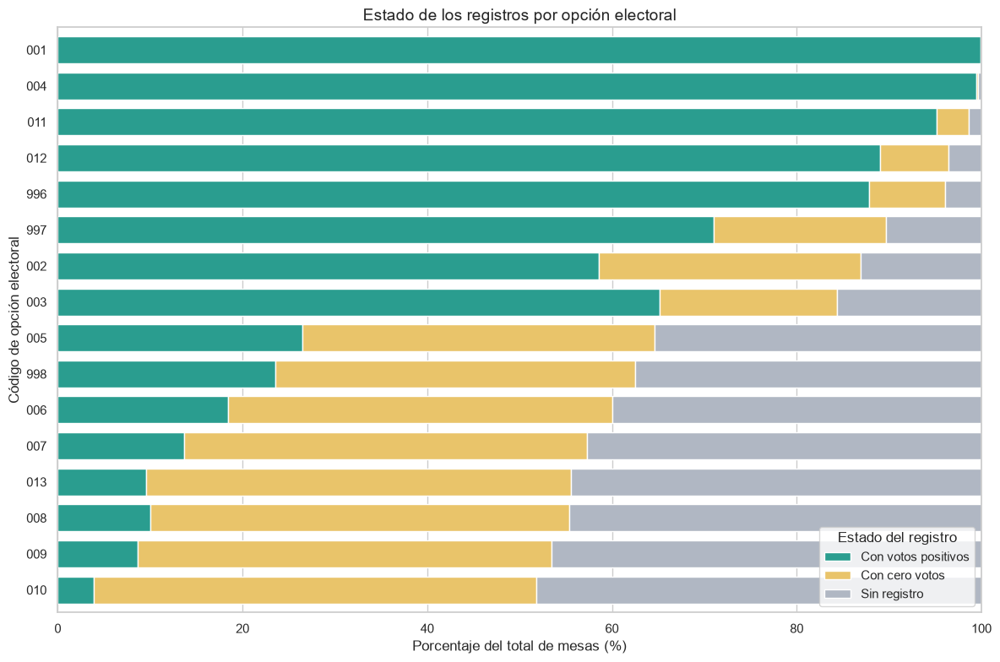

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# Crear una copia para la visualización
df_grafica = resumen_opciones.copy()

# Mesas con votos positivos
df_grafica["mesas_positivas"] = (
    df_grafica["mesas_presentes"]
    - df_grafica["registros_cero"]
)

# Porcentajes calculados sobre TODAS las mesas
df_grafica["Con votos positivos"] = (
    100 * df_grafica["mesas_positivas"] / total_mesas
)

df_grafica["Con cero votos"] = (
    100 * df_grafica["registros_cero"] / total_mesas
)

df_grafica["Sin registro"] = (
    100 * df_grafica["mesas_ausentes"] / total_mesas
)

# Preparar las categorías para graficar
df_grafica["codigo"] = df_grafica["candidato"].astype(str)

df_grafica = df_grafica.sort_values(
    "porcentaje_presencia",
    ascending=True
)

columnas = [
    "Con votos positivos",
    "Con cero votos",
    "Sin registro"
]

ax = df_grafica.set_index("codigo")[columnas].plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    color=["#2A9D8F", "#E9C46A", "#B0B7C3"],
    width=0.75
)

ax.set_title(
    "Estado de los registros por opción electoral",
    fontsize=14
)

ax.set_xlabel("Porcentaje del total de mesas (%)")
ax.set_ylabel("Código de opción electoral")
ax.set_xlim(0, 100)

ax.legend(
    title="Estado del registro",
    loc="lower right"
)

plt.tight_layout()
plt.show()

#### Interpretación de la presencia de opciones electorales y los registros con cero votos

El análisis de las 16 opciones electorales evidencia diferencias considerables en su frecuencia de aparición dentro de las 122.020 combinaciones de mesa.

La opción identificada mediante el código `001` presenta la mayor cobertura, con registros en el 99,96 % de las mesas. Por el contrario, la opción `010` aparece en el 51,84 % de las mesas.

También se observa una relación descriptiva entre la frecuencia de aparición de las opciones y la proporción de registros con cero votos. Algunas opciones con menor cobertura presentan porcentajes de cero superiores al 80 %, mientras que las opciones de mayor presencia registran proporciones considerablemente menores.

Por otra parte, las mesas con 16 opciones presentan una mediana de nueve registros con cero votos, mientras que las mesas con entre una y catorce opciones presentan una mediana de cero.

Este contraste sugiere que la representación de opciones electorales podría responder a diferentes reglas de inclusión de registros. Sin embargo, los resultados no permiten determinar por sí solos cuáles son dichas reglas.

La relación entre el número de opciones presentes y la suma de votos registrados tampoco es estrictamente creciente. Las mesas con 16 opciones presentan una mediana de 188 votos, inferior a la observada en varios grupos con menos opciones.

Estos hallazgos justifican una investigación adicional sobre la estructura de los registros, particularmente sobre la coexistencia de valores explícitos de cero y opciones ausentes.

Las diferencias observadas no deben interpretarse como anomalías electorales sin verificar previamente la documentación y los mecanismos de producción del archivo.

### Análisis de patrones de presencia y ausencia de opciones electorales

El archivo de preconteo presenta una estructura de hasta 16 opciones electorales por mesa, pero no todas las opciones aparecen en todas las mesas.

Adicionalmente, los resultados muestran que existen registros explícitos con cero votos y diferencias considerables en la cantidad de opciones registradas.

Para profundizar en este comportamiento, se construirá una matriz binaria de presencia de opciones electorales por mesa.

Cada fila representará una combinación única de mesa y cada columna una opción electoral. El valor uno indicará que existe un registro para esa opción, mientras que el valor cero indicará que no existe una fila correspondiente en el archivo original.

Esta matriz describe exclusivamente la presencia de registros y no debe confundirse con una matriz de votos. En particular, una ausencia de registro no se interpretará como cero votos.

In [38]:
matriz_presencia = (
    df_preconteo
    .assign(presente=1)
    .pivot_table(
        index=columnas_mesa,
        columns="candidato",
        values="presente",
        aggfunc="max",
        fill_value=0
    )
    .astype("int8")
)

print("Dimensiones:", matriz_presencia.shape)

display(matriz_presencia.head())

Dimensiones: (122020, 16)


candidato                                  001  002  003  004  005  006  007  \
departamento municipio zona puesto mesa                                        
01           001       01   01     000001    1    1    1    1    1    1    1   
                                   000002    1    1    1    1    1    1    1   
                                   000003    1    1    1    1    1    1    1   
                                   000004    1    1    1    1    1    1    1   
                                   000005    1    1    1    1    1    1    1   

candidato                                  008  009  010  011  012  013  996  \
departamento municipio zona puesto mesa                                        
01           001       01   01     000001    1    1    1    1    1    1    1   
                                   000002    1    1    1    1    1    1    1   
                                   000003    1    1    1    1    1    1    1   
                                   000004    1    1    1    1    1    1    1   
                                   000005    1    1    1    1    1    1    1   

candidato                                  997  998  
departamento municipio zona puesto mesa              
01           001       01   01     000001    1    1  
                                   000002    1    1  
                                   000003    1    1  
                                   000004    1    1  
                                   000005    1    1

In [39]:
patrones = (
    matriz_presencia
    .value_counts()
    .rename("cantidad_mesas")
    .reset_index()
    .sort_values("cantidad_mesas", ascending=False)
)

patrones["porcentaje"] = (
    100 * patrones["cantidad_mesas"] / total_mesas
).round(2)

print("Patrones distintos:", len(patrones))

display(patrones.head(15))

Patrones distintos: 2766


,001,002,003,004,005,006,007,008,009,010,011,012,013,996,997,998,cantidad_mesas,porcentaje
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,60397,49.50
1,1,1,1,1,0,0,0,0,0,0,1,1,0,1,1,0,7263,5.95
2,1,0,1,1,0,0,0,0,0,0,1,1,0,1,1,0,2559,2.10
3,1,1,1,1,1,0,0,0,0,0,1,1,0,1,1,0,2549,2.09
4,1,1,0,1,0,0,0,0,0,0,1,1,0,1,1,0,2105,1.73
5,1,1,1,1,0,0,0,0,0,0,1,1,0,1,0,0,1702,1.39
6,1,1,1,1,0,0,0,0,0,0,1,1,0,1,1,1,1443,1.18
7,1,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,1377,1.13
8,1,1,1,1,0,1,0,0,0,0,1,1,0,1,1,0,1193,0.98
9,1,1,1,1,0,0,1,0,0,0,1,1,0,1,1,0,864,0.71


In [40]:
comparacion = (
    resumen_mesas
    .assign(
        grupo=lambda x: np.where(
            x["opciones_presentes"] == 16,
            "16 opciones",
            "Menos de 16 opciones"
        )
    )
    .groupby("grupo")
    .agg(
        mesas=("mesa", "size"),
        mediana_votos=("suma_votos_registrados", "median"),
        mediana_ceros=("registros_cero", "median"),
        promedio_ceros=("registros_cero", "mean")
    )
)

display(comparacion)

,mesas,mediana_votos,mediana_ceros,promedio_ceros
grupo,,,,
16 opciones,60397,188.0,9.0,8.656986
Menos de 16 opciones,61623,220.0,0.0,0.074079


### Identificación de catálogos y archivos auxiliares

El análisis estructural permitió identificar 16 combinaciones únicas de códigos electorales, definidas mediante los campos `lista_partido` y `candidato`.

Sin embargo, los códigos numéricos no permiten establecer por sí solos la identidad de los candidatos, las organizaciones políticas o las categorías especiales de votación.

Para avanzar en la comprensión semántica del conjunto de datos, se examinarán los archivos auxiliares incluidos en el paquete de información electoral.

El propósito de esta exploración es identificar los catálogos que permitan relacionar los códigos observados con sus respectivas descripciones oficiales, así como reconocer posibles reglas de codificación relevantes para interpretar los registros del preconteo.

Esta actividad corresponde a la descripción y exploración de los datos dentro de CRISP-DM. No se realizarán todavía transformaciones destinadas al entrenamiento de modelos.

In [41]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd

ruta_catalogos = (
    DATA_DIR / "ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip"
)

assert ruta_catalogos.exists(), (
    f"No se encontró el archivo: {ruta_catalogos}"
)

with ZipFile(ruta_catalogos, "r") as zip_file:
    archivos_catalogos = [
        {
            "archivo": info.filename,
            "extension": Path(info.filename).suffix.lower(),
            "tamano_kib": round(info.file_size / 1024, 2),
        }
        for info in zip_file.infolist()
        if not info.is_dir()
    ]

df_catalogos = pd.DataFrame(archivos_catalogos)

print("Total de archivos:", len(df_catalogos))

display(
    df_catalogos.sort_values("archivo").reset_index(drop=True)
)

Total de archivos: 7


,archivo,extension,tamano_kib
0,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT,.txt,1.76
1,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT,.txt,0.10
2,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT,.txt,0.20
3,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/DIVIPOL_20260526_132437_01.TXT,.txt,2072.64
4,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/HASH.txt,.txt,13.94
5,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/INDICADORES_20260526_132437_01.TXT,.txt,0.62
6,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/PARTIDOS_20260516_083436_01.TXT,.txt,2.63


In [42]:
terminos = [
    "candidato",
    "partido",
    "lista",
    "presidente",
    "codigo",
    "diccionario",
    "voto",
    "opcion",
]

if not df_catalogos.empty:
    patron = "|".join(terminos)

    posibles_catalogos = df_catalogos[
        df_catalogos["archivo"].str.contains(
            patron,
            case=False,
            na=False,
            regex=True
        )
    ]

    display(posibles_catalogos)

,archivo,extension,tamano_kib
0,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT,.txt,1.76
1,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT,.txt,0.10
2,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT,.txt,0.20
3,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/DIVIPOL_20260526_132437_01.TXT,.txt,2072.64
4,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/HASH.txt,.txt,13.94
5,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/INDICADORES_20260526_132437_01.TXT,.txt,0.62
6,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/PARTIDOS_20260516_083436_01.TXT,.txt,2.63


In [43]:
for i, archivo in enumerate(df_catalogos["archivo"], start=1):
    print(f"{i}. {archivo}")

1. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
2. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT
3. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT
4. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/DIVIPOL_20260526_132437_01.TXT
5. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/HASH.txt
6. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/INDICADORES_20260526_132437_01.TXT
7. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/PARTIDOS_20260516_083436_01.TXT


In [44]:
with ZipFile(ruta_catalogos, "r") as zip_file:
    for nombre in zip_file.namelist():
        if nombre.endswith("/"):
            continue

        print("\n" + "=" * 80)
        print("ARCHIVO:", nombre)
        print("=" * 80)

        with zip_file.open(nombre) as archivo:
            for _, linea in zip(range(5), archivo):
                print(linea.decode("latin-1").rstrip())


ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
00100000000000260011IVÁN                                              CEPEDA CASTRO                                     79262397       M01
00100000000010040021CLAUDIA                                           LÓPEZ                                             51992648       F03
00100000000010010031RAÚL SANTIAGO                                     BOTERO JARAMILLO                                  98567762       M04
00100000000010030041ABELARDO                                          DE LA ESPRIELLA                                   11004242       M05
00100000000030010051ÓSCAR MAURICIO                                    LIZCANO ARANGO                                    79960663       M06

ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT
0NACIONAL

ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT
001PRESIDENCIA Y VICEP

### Exploración semántica de los catálogos electorales

La inspección de los archivos auxiliares permitió identificar catálogos de candidatos, partidos políticos, circunscripciones, corporaciones, división político-administrativa e indicadores de mesas.

Estos archivos complementan la estructura del preconteo al proporcionar descripciones asociadas con los códigos utilizados en sus registros.

El catálogo de circunscripciones identifica el código `0` como `NACIONAL`, mientras que el catálogo de corporaciones contiene la denominación `PRESIDENCIA Y VICEPRESIDENCIA`.

Para interpretar las opciones electorales se examinarán los catálogos de candidatos y partidos, verificando sus estructuras antes de establecer correspondencias con los códigos presentes en el preconteo.

La información territorial de DIVIPOL y los indicadores de mesas se reservarán para una exploración posterior de las diferencias geográficas y operativas.

In [45]:
with ZipFile(ruta_catalogos, "r") as zip_file:

    for tipo in ["CANDIDATOS_", "PARTIDOS_"]:

        nombre = next(
            n for n in zip_file.namelist()
            if Path(n).name.upper().startswith(tipo)
        )

        contenido = zip_file.read(nombre).decode("latin-1")
        lineas = contenido.splitlines()

        print(f"\n{'=' * 70}")
        print(f"CATÁLOGO: {tipo}")
        print(f"Archivo: {nombre}")
        print(f"Registros: {len(lineas)}")

        print(
            "Longitudes observadas:",
            sorted(set(map(len, lineas)))
        )

        print("\nRegistros:")
        for linea in lineas[:25]:
            print(repr(linea))


CATÁLOGO: CANDIDATOS_
Archivo: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
Registros: 13
Longitudes observadas: [138]

Registros:
'00100000000000260011IVÁN                                              CEPEDA CASTRO                                     79262397       M01'
'00100000000010040021CLAUDIA                                           LÓPEZ                                             51992648       F03'
'00100000000010010031RAÚL SANTIAGO                                     BOTERO JARAMILLO                                  98567762       M04'
'00100000000010030041ABELARDO                                          DE LA ESPRIELLA                                   11004242       M05'
'00100000000030010051ÓSCAR MAURICIO                                    LIZCANO ARANGO                                    79960663       M06'
'00100000000000200061MIGUEL                                            URIBE LONDOÑO                                     8319134 

### Interpretación de los códigos de candidatos y organizaciones políticas

La inspección de los catálogos auxiliares identificó 13 registros de candidatos y 13 registros de organizaciones políticas.

Los registros del catálogo de candidatos presentan una longitud uniforme de 138 caracteres, mientras que los del catálogo de partidos tienen una longitud uniforme de 206 caracteres.

El preconteo contiene 16 opciones electorales distintas. De ellas, 13 corresponden a los códigos de candidatura `001` a `013`, mientras que tres utilizan los códigos `996`, `997` y `998`.

Para interpretar estas opciones se establecerá una correspondencia entre los identificadores de candidato, los códigos de lista o partido y las descripciones disponibles en los catálogos.

Los códigos especiales se mantendrán separados de las candidaturas ordinarias hasta confirmar documentalmente su significado.

Esta interpretación semántica permitirá realizar posteriormente una exploración estadística de los votos utilizando categorías comprensibles, sin alterar los registros originales.

In [46]:
opciones_preconteo = (
    df_preconteo[
        ["lista_partido", "candidato"]
    ]
    .drop_duplicates()
    .sort_values(
        ["candidato", "lista_partido"]
    )
    .reset_index(drop=True)
)

display(opciones_preconteo)

,lista_partido,candidato
0,00026,001
1,01004,002
2,01001,003
3,01003,004
4,03001,005
5,00020,006
6,01002,007
7,00022,008
8,01006,009
9,00021,010


In [47]:
with ZipFile(ruta_catalogos, "r") as z:
    nombre_candidatos = next(
        n for n in z.namelist()
        if Path(n).name.startswith("CANDIDATOS_")
    )

    nombre_partidos = next(
        n for n in z.namelist()
        if Path(n).name.startswith("PARTIDOS_")
    )

    lineas_candidatos = (
        z.read(nombre_candidatos)
        .decode("latin-1")
        .splitlines()
    )

    lineas_partidos = (
        z.read(nombre_partidos)
        .decode("latin-1")
        .splitlines()
    )

assert all(len(linea) == 138 for linea in lineas_candidatos)
assert all(len(linea) == 206 for linea in lineas_partidos)

df_candidatos = pd.DataFrame([
    {
        "lista_partido": linea[11:16],
        "candidato": linea[16:19],
        "nombre": linea[21:71].strip(),
        "apellido": linea[71:121].strip(),
    }
    for linea in lineas_candidatos
])

df_candidatos["nombre_completo"] = (
    df_candidatos["nombre"]
    + " "
    + df_candidatos["apellido"]
)

df_partidos = pd.DataFrame([
    {
        "lista_partido": linea[:5],
        "organizacion_politica": linea[5:205].strip(),
    }
    for linea in lineas_partidos
])

catalogo_electoral = df_candidatos.merge(
    df_partidos,
    on="lista_partido",
    how="left",
    validate="many_to_one"
)

display(catalogo_electoral)

,lista_partido,candidato,nombre,apellido,nombre_completo,organizacion_politica
0,00026,001,VÁN C,EPEDA CASTRO 7,VÁN C EPEDA CASTRO 7,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
1,01004,002,LAUDIA L,ÓPEZ 5,LAUDIA L ÓPEZ 5,CON CLAUDIA IMPARABLES
2,01001,003,AÚL SANTIAGO B,OTERO JARAMILLO 9,AÚL SANTIAGO B OTERO JARAMILLO 9,ROMPER EL SISTEMA
3,01003,004,BELARDO D,E LA ESPRIELLA 1,BELARDO D E LA ESPRIELLA 1,DEFENSORES DE LA PATRIA
4,03001,005,SCAR MAURICIO L,IZCANO ARANGO 7,SCAR MAURICIO L IZCANO ARANGO 7,COALICIÓN F.A.M.I.L.I.A
5,00020,006,IGUEL U,RIBE LONDOÑO 8,IGUEL U RIBE LONDOÑO 8,PARTIDO DEMÓCRATA COLOMBIANO
6,01002,007,ONDRA MACOLLINS G,ARVIN PINTO 6,ONDRA MACOLLINS G ARVIN PINTO 6,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
7,00022,008,OY LEONARDO B,ARRERAS MONTEALEGRE 7,OY LEONARDO B ARRERAS MONTEALEGRE 7,PARTIDO POLÍTICO LA FUERZA
8,01006,009,ARLOS EDUARDO C,AICEDO OMAR 8,ARLOS EDUARDO C AICEDO OMAR 8,CAICEDO
9,00021,010,USTAVO M,ATAMOROS CAMACHO 7,USTAVO M ATAMOROS CAMACHO 7,PARTIDO ECOLOGISTA COLOMBIANO


In [48]:
# Estructura observada del catálogo CANDIDATOS:
# [0:11]   Identificadores iniciales
# [11:16]  Código de lista o partido
# [16:19]  Código de candidato
# [19:20]  Campo auxiliar
# [20:70]  Nombres
# [70:120] Apellidos

df_candidatos = pd.DataFrame([
    {
        "lista_partido": linea[11:16],
        "candidato": linea[16:19],
        "nombre": linea[20:70].strip(),
        "apellido": linea[70:120].strip(),
    }
    for linea in lineas_candidatos
])

df_candidatos["nombre_completo"] = (
    df_candidatos["nombre"]
    + " "
    + df_candidatos["apellido"]
)

catalogo_electoral = df_candidatos.merge(
    df_partidos,
    on="lista_partido",
    how="left",
    validate="many_to_one"
)

display(
    catalogo_electoral[
        [
            "lista_partido",
            "candidato",
            "nombre_completo",
            "organizacion_politica"
        ]
    ]
)

,lista_partido,candidato,nombre_completo,organizacion_politica
0,00026,001,IVÁN CEPEDA CASTRO,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
1,01004,002,CLAUDIA LÓPEZ,CON CLAUDIA IMPARABLES
2,01001,003,RAÚL SANTIAGO BOTERO JARAMILLO,ROMPER EL SISTEMA
3,01003,004,ABELARDO DE LA ESPRIELLA,DEFENSORES DE LA PATRIA
4,03001,005,ÓSCAR MAURICIO LIZCANO ARANGO,COALICIÓN F.A.M.I.L.I.A
5,00020,006,MIGUEL URIBE LONDOÑO,PARTIDO DEMÓCRATA COLOMBIANO
6,01002,007,SONDRA MACOLLINS GARVIN PINTO,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
7,00022,008,ROY LEONARDO BARRERAS MONTEALEGRE,PARTIDO POLÍTICO LA FUERZA
8,01006,009,CARLOS EDUARDO CAICEDO OMAR,CAICEDO
9,00021,010,GUSTAVO MATAMOROS CAMACHO,PARTIDO ECOLOGISTA COLOMBIANO


In [49]:
# Identificar las 13 candidaturas ordinarias del preconteo
opciones_ordinarias = (
    df_preconteo.loc[
        ~df_preconteo["candidato"].isin(["996", "997", "998"]),
        ["lista_partido", "candidato"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Verificar correspondencia con el catálogo oficial
verificacion = opciones_ordinarias.merge(
    catalogo_electoral,
    on=["lista_partido", "candidato"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("Candidaturas ordinarias:", len(opciones_ordinarias))
print("Candidaturas identificadas:",
      (verificacion["_merge"] == "both").sum())

assert len(opciones_ordinarias) == 13
assert (verificacion["_merge"] == "both").all()
assert verificacion["nombre_completo"].notna().all()
assert verificacion["organizacion_politica"].notna().all()

display(
    verificacion[
        [
            "lista_partido",
            "candidato",
            "nombre_completo",
            "organizacion_politica"
        ]
    ].sort_values("candidato")
)

Candidaturas ordinarias: 13
Candidaturas identificadas: 13


,lista_partido,candidato,nombre_completo,organizacion_politica
5,00026,001,IVÁN CEPEDA CASTRO,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
9,01004,002,CLAUDIA LÓPEZ,CON CLAUDIA IMPARABLES
6,01001,003,RAÚL SANTIAGO BOTERO JARAMILLO,ROMPER EL SISTEMA
8,01003,004,ABELARDO DE LA ESPRIELLA,DEFENSORES DE LA PATRIA
12,03001,005,ÓSCAR MAURICIO LIZCANO ARANGO,COALICIÓN F.A.M.I.L.I.A
2,00020,006,MIGUEL URIBE LONDOÑO,PARTIDO DEMÓCRATA COLOMBIANO
7,01002,007,SONDRA MACOLLINS GARVIN PINTO,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
4,00022,008,ROY LEONARDO BARRERAS MONTEALEGRE,PARTIDO POLÍTICO LA FUERZA
11,01006,009,CARLOS EDUARDO CAICEDO OMAR,CAICEDO
3,00021,010,GUSTAVO MATAMOROS CAMACHO,PARTIDO ECOLOGISTA COLOMBIANO


### Análisis descriptivo de la variable votos

La variable `votos` representa el número de votos registrado para una opción electoral en una mesa determinada.

Se analizará su distribución mediante estadísticas descriptivas, frecuencias y representaciones gráficas, con el propósito de caracterizar su comportamiento y reconocer posibles particularidades de los datos.

El análisis distinguirá entre valores iguales a cero, valores positivos y observaciones de magnitud elevada. Asimismo, se examinarán medidas de tendencia central, dispersión y posición.

Es importante señalar que cada registro corresponde a una opción electoral dentro de una mesa, por lo que la distribución obtenida no representa directamente la participación electoral por mesa. Los valores extremos tampoco constituyen, por sí mismos, evidencia de irregularidades.

In [50]:
import pandas as pd
import numpy as np

votos = df_preconteo["votos"]

resumen_votos = pd.Series({
    "Total de registros": len(votos),
    "Valores distintos": votos.nunique(),
    "Mínimo": votos.min(),
    "Máximo": votos.max(),
    "Media": votos.mean(),
    "Mediana": votos.median(),
    "Desviación estándar": votos.std(),
    "Registros con cero": (votos == 0).sum(),
    "Porcentaje de ceros": (votos == 0).mean() * 100,
    "Registros positivos": (votos > 0).sum(),
    "Percentil 25": votos.quantile(0.25),
    "Percentil 75": votos.quantile(0.75),
    "Percentil 90": votos.quantile(0.90),
    "Percentil 95": votos.quantile(0.95),
    "Percentil 99": votos.quantile(0.99),
    "Percentil 99.9": votos.quantile(0.999),
})

display(
    resumen_votos.to_frame(
        name="Valor"
    ).round(3)
)

,Valor
Total de registros,1479506.000
Valores distintos,398.000
Mínimo,0.000
Máximo,694.000
Media,16.207
Mediana,1.000
Desviación estándar,35.863
Registros con cero,527421.000
Porcentaje de ceros,35.648
Registros positivos,952085.000


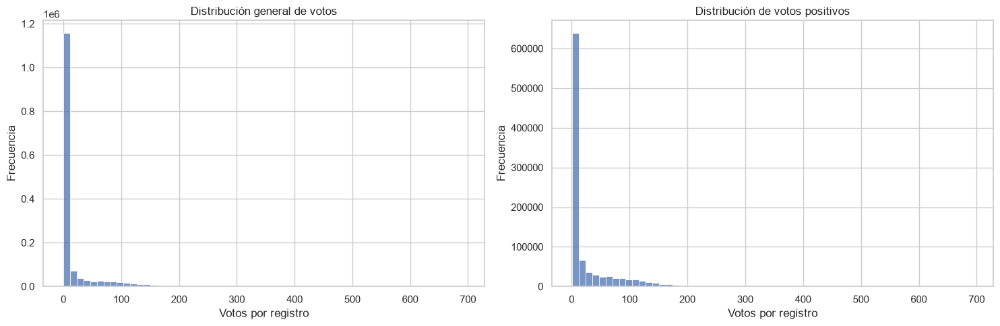

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

sns.histplot(
    data=df_preconteo,
    x="votos",
    bins=60,
    ax=axes[0]
)

axes[0].set_title("Distribución general de votos")
axes[0].set_xlabel("Votos por registro")
axes[0].set_ylabel("Frecuencia")

sns.histplot(
    x=df_preconteo.loc[
        df_preconteo["votos"] > 0,
        "votos"
    ],
    bins=60,
    ax=axes[1]
)

axes[1].set_title("Distribución de votos positivos")
axes[1].set_xlabel("Votos por registro")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [52]:
frecuencias_votos = (
    df_preconteo["votos"]
    .value_counts()
    .rename_axis("votos")
    .reset_index(name="frecuencia")
)

frecuencias_votos["porcentaje"] = (
    frecuencias_votos["frecuencia"]
    / len(df_preconteo)
    * 100
)

display(
    frecuencias_votos
    .head(20)
    .round(3)
)

,votos,frecuencia,porcentaje
0,0,527421,35.648
1,1,237402,16.046
2,2,114083,7.711
3,3,74591,5.042
4,4,53288,3.602
5,5,39904,2.697
6,6,30358,2.052
7,7,23502,1.589
8,8,18471,1.248
9,9,14759,0.998


### Interpretación de la distribución de votos

El análisis descriptivo de los 1.479.506 registros del preconteo evidencia una distribución marcadamente asimétrica hacia la derecha. La media de 16,207 votos supera considerablemente la mediana de 1 voto, lo que indica una concentración de observaciones en valores pequeños y una extensión de la distribución hacia valores elevados.

Se identificaron 527.421 registros con cero votos, equivalentes al 35,648 % del conjunto de datos. Este hallazgo confirma que el archivo contiene registros explícitos con valor cero, por lo que la ausencia de una combinación mesa-opción no puede interpretarse automáticamente como un resultado de cero votos.

El 75 % de los registros presenta ocho votos o menos, mientras que los percentiles 95 y 99 corresponden a 104 y 164 votos, respectivamente. El máximo observado es de 694 votos.

La distribución agregada combina diferentes candidaturas y categorías electorales, cuyas magnitudes de votación pueden variar sustancialmente. Por esta razón, los valores elevados no deben considerarse anomalías únicamente por su posición en la distribución global.

Los resultados justifican profundizar en el comportamiento de los votos por opción electoral y posteriormente por mesa, conservando la distinción entre valores observados, registros explícitos con cero y opciones ausentes.

In [53]:
# Trabajar únicamente con las 13 candidaturas identificadas
df_candidaturas = df_preconteo[
    df_preconteo["candidato"].isin(
        catalogo_electoral["candidato"]
    )
].copy()

# Incorporar nombres sin modificar los datos originales
df_candidaturas = df_candidaturas.merge(
    catalogo_electoral[
        ["lista_partido", "candidato", "nombre_completo"]
    ],
    on=["lista_partido", "candidato"],
    how="left",
    validate="many_to_one"
)

resumen_candidaturas = (
    df_candidaturas
    .groupby(["candidato", "nombre_completo"])
    .agg(
        registros=("votos", "size"),
        votos_totales=("votos", "sum"),
        media=("votos", "mean"),
        mediana=("votos", "median"),
        desviacion=("votos", "std"),
        maximo=("votos", "max"),
        registros_cero=("votos", lambda x: (x == 0).sum())
    )
    .reset_index()
)

resumen_candidaturas["porcentaje_ceros"] = (
    resumen_candidaturas["registros_cero"]
    / resumen_candidaturas["registros"]
    * 100
)

display(
    resumen_candidaturas
    .sort_values("candidato")
    .round(2)
)

,candidato,nombre_completo,registros,votos_totales,media,mediana,desviacion,maximo,registros_cero,porcentaje_ceros
0,001,IVÁN CEPEDA CASTRO,121967,9688361,79.43,75.0,43.53,325,100,0.08
1,002,CLAUDIA LÓPEZ,106109,225517,2.13,1.0,3.14,245,34606,32.61
2,003,RAÚL SANTIAGO BOTERO JARAMILLO,102972,206140,2.00,1.0,2.36,179,23425,22.75
3,004,ABELARDO DE LA ESPRIELLA,121597,10361499,85.21,77.0,53.01,694,260,0.21
4,005,ÓSCAR MAURICIO LIZCANO ARANGO,78894,53839,0.68,0.0,1.73,136,46567,59.02
5,006,MIGUEL URIBE LONDOÑO,73312,28657,0.39,0.0,0.73,60,50846,69.36
6,007,SONDRA MACOLLINS GARVIN PINTO,69947,19889,0.28,0.0,0.60,25,53296,76.19
7,008,ROY LEONARDO BARRERAS MONTEALEGRE,67626,14108,0.21,0.0,0.51,18,55423,81.96
8,009,CARLOS EDUARDO CAICEDO OMAR,65201,12694,0.19,0.0,0.54,24,54686,83.87
9,010,GUSTAVO MATAMOROS CAMACHO,63261,5627,0.09,0.0,0.44,29,58454,92.40


### Distribución de votos por candidatura

El análisis desagregado de las 13 candidaturas evidencia una heterogeneidad considerable en las distribuciones de votos registrados por mesa.

Las candidaturas presentan diferencias tanto en sus medidas de tendencia central como en la proporción de registros con cero votos. Las medianas observadas oscilan entre 0 y 77 votos, mientras que los porcentajes de registros con cero varían entre 0,08 % y 92,40 %.

Adicionalmente, la cantidad de registros disponibles difiere entre candidaturas. Esta característica debe considerarse al interpretar las estadísticas, ya que los registros presentes no necesariamente constituyen el mismo conjunto de mesas para todas las opciones electorales.

Los resultados indican que la distribución agregada de votos combina poblaciones con comportamientos estadísticos distintos. Por consiguiente, la identificación de observaciones atípicas mediante umbrales globales podría resultar inadecuada, dado que valores habituales para una candidatura podrían ser poco frecuentes para otra.

En esta fase de entendimiento de los datos, estos hallazgos justifican explorar las distribuciones por candidatura y estudiar la relación entre presencia de registros, valores explícitos de cero y magnitudes de votación. No se atribuyen causas a las diferencias observadas ni se interpretan como evidencia de irregularidades electorales.

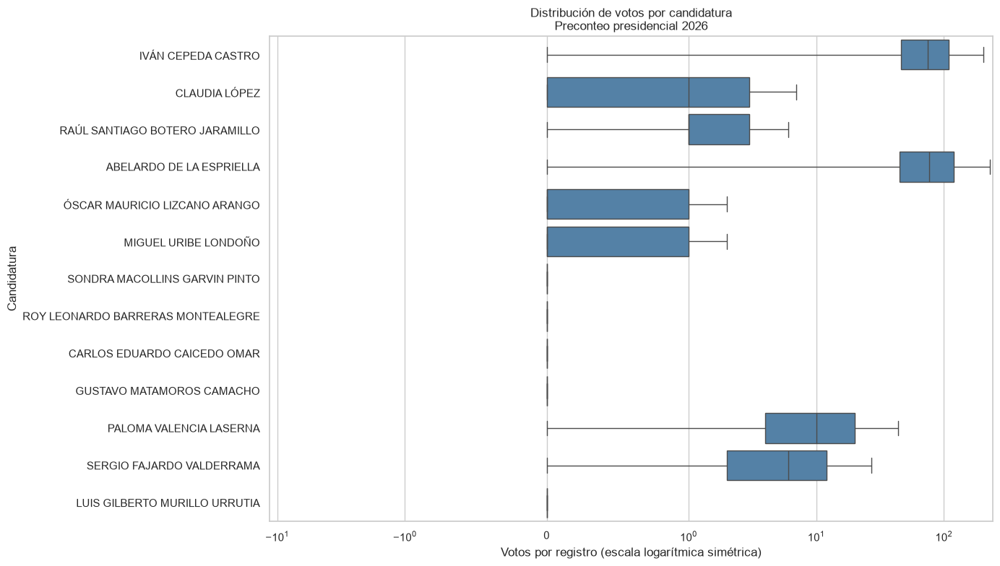

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ordenar por código de candidatura
orden_candidatos = (
    catalogo_electoral
    .sort_values("candidato")["nombre_completo"]
    .tolist()
)

plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df_candidaturas,
    x="votos",
    y="nombre_completo",
    order=orden_candidatos,
    showfliers=False,
    color="steelblue"
)

plt.xscale("symlog", linthresh=1)

plt.title(
    "Distribución de votos por candidatura\n"
    "Preconteo presidencial 2026"
)

plt.xlabel("Votos por registro (escala logarítmica simétrica)")
plt.ylabel("Candidatura")

plt.tight_layout()
plt.show()

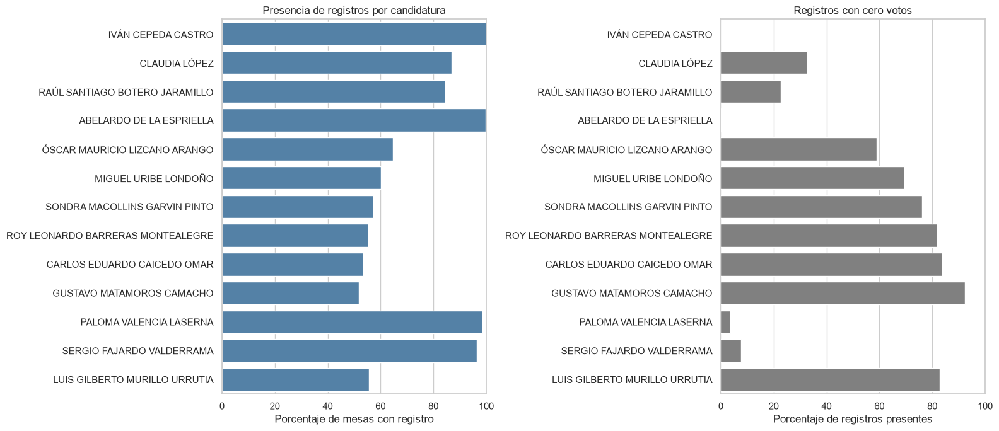

In [55]:
total_mesas = 122020

grafico_candidaturas = resumen_candidaturas.copy()

grafico_candidaturas["porcentaje_presencia"] = (
    grafico_candidaturas["registros"]
    / total_mesas * 100
)

grafico_candidaturas = (
    grafico_candidaturas
    .sort_values("candidato")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=grafico_candidaturas,
    x="porcentaje_presencia",
    y="nombre_completo",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Presencia de registros por candidatura")
axes[0].set_xlabel("Porcentaje de mesas con registro")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 100)

sns.barplot(
    data=grafico_candidaturas,
    x="porcentaje_ceros",
    y="nombre_completo",
    ax=axes[1],
    color="gray"
)

axes[1].set_title("Registros con cero votos")
axes[1].set_xlabel("Porcentaje de registros presentes")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()

### Distribución de votos agregados por mesa electoral

La exploración anterior permitió identificar diferencias significativas en las distribuciones de votos entre candidaturas, así como variaciones en la presencia de registros y en la frecuencia de valores explícitos de cero.

En esta sección se adopta la mesa electoral como unidad de análisis, definida mediante la combinación de departamento, municipio, zona, puesto y mesa.

Para cada unidad se calculará la suma de los votos registrados en las distintas opciones electorales. Esta agregación permitirá describir la distribución de las magnitudes de votación observadas entre mesas y examinar la presencia de valores extremos.

Debe tenerse en cuenta que la suma de votos registrados no equivale necesariamente al número de sufragantes ni a la participación electoral, ya que todavía no se ha verificado la completitud de todas las categorías electorales ni su correspondencia con los indicadores oficiales de votación.

In [56]:
# Verificar las variables necesarias
columnas_requeridas = [
    "opciones_presentes",
    "suma_votos_registrados",
    "registros_cero"
]

assert all(
    columna in resumen_mesas.columns
    for columna in columnas_requeridas
)

votos_mesa = resumen_mesas["suma_votos_registrados"]

estadisticas_mesas = pd.Series({
    "Total de mesas": len(resumen_mesas),
    "Votos registrados (suma global)": votos_mesa.sum(),
    "Mínimo": votos_mesa.min(),
    "Máximo": votos_mesa.max(),
    "Media": votos_mesa.mean(),
    "Mediana": votos_mesa.median(),
    "Desviación estándar": votos_mesa.std(),
    "Percentil 1": votos_mesa.quantile(0.01),
    "Percentil 5": votos_mesa.quantile(0.05),
    "Percentil 25": votos_mesa.quantile(0.25),
    "Percentil 75": votos_mesa.quantile(0.75),
    "Percentil 95": votos_mesa.quantile(0.95),
    "Percentil 99": votos_mesa.quantile(0.99),
    "Mesas con suma cero": (votos_mesa == 0).sum(),
})

display(
    estadisticas_mesas
    .to_frame("Valor")
    .round(2)
)

,Valor
Total de mesas,122020.00
Votos registrados (suma global),23978304.00
Mínimo,0.00
Máximo,942.00
Media,196.51
Mediana,205.00
Desviación estándar,71.70
Percentil 1,16.00
Percentil 5,56.00
Percentil 25,154.00


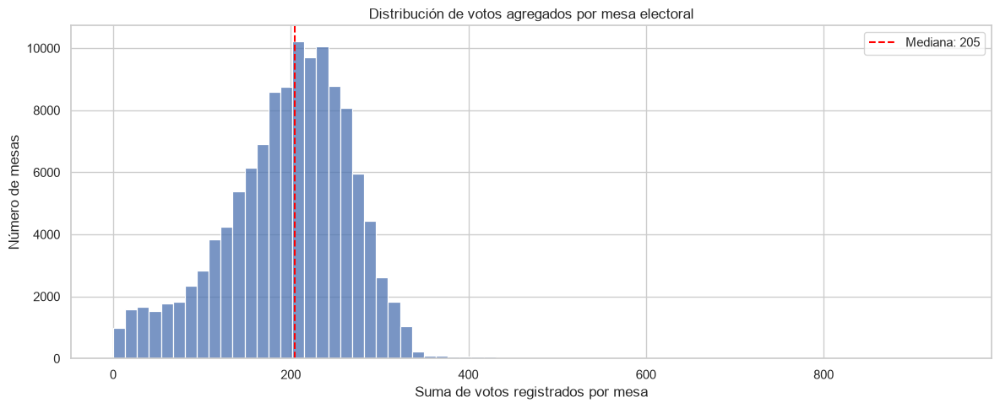

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(
    data=resumen_mesas,
    x="suma_votos_registrados",
    bins=70,
    ax=ax
)

ax.axvline(
    votos_mesa.median(),
    color="red",
    linestyle="--",
    label=f"Mediana: {votos_mesa.median():.0f}"
)

ax.set_title(
    "Distribución de votos agregados por mesa electoral"
)
ax.set_xlabel("Suma de votos registrados por mesa")
ax.set_ylabel("Número de mesas")
ax.legend()

plt.tight_layout()
plt.show()

In [58]:
columnas_resultado = (
    columnas_mesa
    + [
        "opciones_presentes",
        "suma_votos_registrados",
        "registros_cero"
    ]
)

print("Mesas con las mayores sumas de votos registrados")

display(
    resumen_mesas
    .nlargest(15, "suma_votos_registrados")[
        columnas_resultado
    ]
)

print("Mesas con las menores sumas de votos registrados")

display(
    resumen_mesas
    .nsmallest(15, "suma_votos_registrados")[
        columnas_resultado
    ]
)

Mesas con las mayores sumas de votos registrados


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
120275,88,360,35,81,000001,8,942,0
120760,88,360,57,85,000001,16,663,10
119677,88,355,05,85,000009,16,639,8
120758,88,360,57,83,000001,16,635,8
120679,88,360,55,84,000001,9,625,2
120830,88,360,59,81,000003,16,615,9
120503,88,360,40,83,000007,16,603,8
118924,88,285,05,84,000001,9,597,1
118925,88,285,05,85,000001,10,596,1
120759,88,360,57,84,000001,16,593,9


Mesas con las menores sumas de votos registrados


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
67657,17,001,99,25,000001,1,0,1
67664,17,001,99,33,000001,1,0,1
67868,17,010,99,17,000001,1,0,1
67930,17,011,99,40,000001,1,0,1
67931,17,011,99,41,000001,1,0,1
68221,17,025,99,17,000001,1,0,1
118413,88,130,05,81,000001,1,0,1
118414,88,130,05,82,000001,1,0,1
118415,88,130,05,83,000001,1,0,1
118416,88,130,05,84,000001,1,0,1


### Caracterización estadística de las mesas electorales

La mesa electoral constituye una unidad de análisis fundamental para el estudio del preconteo. A diferencia del análisis por candidatura, esta perspectiva permite examinar la magnitud total de votos registrados y la cantidad de opciones electorales presentes en cada mesa.

Se estudiará la distribución de las sumas de votos, prestando especial atención a sus percentiles y a las observaciones situadas en los extremos. También se examinará la relación entre la cantidad de opciones registradas y la suma de votos observada.

Estas comparaciones tienen un carácter exclusivamente descriptivo. La presencia de valores extremos o de un número reducido de opciones electorales no constituye, por sí misma, evidencia de errores o irregularidades.

In [59]:
import pandas as pd

votos_mesa = resumen_mesas["suma_votos_registrados"]

estadisticas_mesas = pd.Series({
    "Total de mesas": len(resumen_mesas),
    "Suma global de votos registrados": votos_mesa.sum(),
    "Mínimo": votos_mesa.min(),
    "Máximo": votos_mesa.max(),
    "Media": votos_mesa.mean(),
    "Mediana": votos_mesa.median(),
    "Desviación estándar": votos_mesa.std(),
    "Percentil 1": votos_mesa.quantile(0.01),
    "Percentil 5": votos_mesa.quantile(0.05),
    "Percentil 25": votos_mesa.quantile(0.25),
    "Percentil 75": votos_mesa.quantile(0.75),
    "Percentil 95": votos_mesa.quantile(0.95),
    "Percentil 99": votos_mesa.quantile(0.99),
    "Mesas con suma cero": (votos_mesa == 0).sum(),
})

display(estadisticas_mesas.to_frame("Valor").round(2))

columnas_resultado = columnas_mesa + [
    "opciones_presentes",
    "suma_votos_registrados",
    "registros_cero"
]

print("\nMesas con mayores sumas de votos")
display(
    resumen_mesas.nlargest(
        10, "suma_votos_registrados"
    )[columnas_resultado]
)

print("\nMesas con menores sumas de votos")
display(
    resumen_mesas.nsmallest(
        10, "suma_votos_registrados"
    )[columnas_resultado]
)

,Valor
Total de mesas,122020.00
Suma global de votos registrados,23978304.00
Mínimo,0.00
Máximo,942.00
Media,196.51
Mediana,205.00
Desviación estándar,71.70
Percentil 1,16.00
Percentil 5,56.00
Percentil 25,154.00



Mesas con mayores sumas de votos


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
120275,88,360,35,81,000001,8,942,0
120760,88,360,57,85,000001,16,663,10
119677,88,355,05,85,000009,16,639,8
120758,88,360,57,83,000001,16,635,8
120679,88,360,55,84,000001,9,625,2
120830,88,360,59,81,000003,16,615,9
120503,88,360,40,83,000007,16,603,8
118924,88,285,05,84,000001,9,597,1
118925,88,285,05,85,000001,10,596,1
120759,88,360,57,84,000001,16,593,9



Mesas con menores sumas de votos


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
67657,17,001,99,25,000001,1,0,1
67664,17,001,99,33,000001,1,0,1
67868,17,010,99,17,000001,1,0,1
67930,17,011,99,40,000001,1,0,1
67931,17,011,99,41,000001,1,0,1
68221,17,025,99,17,000001,1,0,1
118413,88,130,05,81,000001,1,0,1
118414,88,130,05,82,000001,1,0,1
118415,88,130,05,83,000001,1,0,1
118416,88,130,05,84,000001,1,0,1


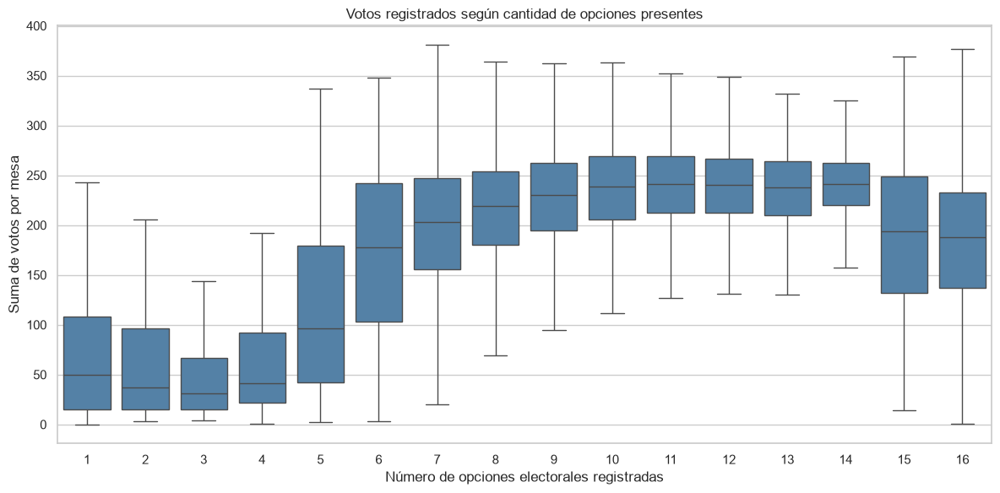

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(
    data=resumen_mesas,
    x="opciones_presentes",
    y="suma_votos_registrados",
    showfliers=False,
    color="steelblue",
    ax=ax
)

ax.set_title(
    "Votos registrados según cantidad de opciones presentes"
)
ax.set_xlabel("Número de opciones electorales registradas")
ax.set_ylabel("Suma de votos por mesa")

plt.tight_layout()
plt.show()

### Exploración de valores extremos por mesa

La inspección de las mesas con mayores sumas de votos registrados identificó un máximo observado de 942 votos. Las diez mesas con mayores sumas pertenecen al código departamental `88`, lo que sugiere la conveniencia de examinar su correspondencia territorial y sus características operativas.

Por otra parte, entre las mesas con menores sumas se identificaron registros cuya agregación es igual a cero. Las observaciones mostradas contienen una única opción electoral registrada con cero votos.

Estos resultados evidencian que los extremos de la distribución requieren contextualización territorial y operativa. La magnitud de votos agregados, por sí sola, no permite determinar si un registro es incorrecto o irregular.

En consecuencia, se propone examinar los códigos territoriales de las mesas extremas mediante el catálogo DIVIPOL, antes de formular interpretaciones adicionales.

In [61]:
with ZipFile(ruta_catalogos, "r") as z:
    nombre_divipol = next(
        n for n in z.namelist()
        if Path(n).name.upper().startswith("DIVIPOL_")
    )

    lineas_divipol = (
        z.read(nombre_divipol)
        .decode("latin-1")
        .splitlines()
    )

print("Total de registros DIVIPOL:", len(lineas_divipol))

print(
    "Longitudes observadas:",
    sorted(set(map(len, lineas_divipol)))
)

for departamento in ["17", "88"]:
    print(f"\nDepartamento {departamento}")

    ejemplos = [
        linea for linea in lineas_divipol
        if linea.startswith(departamento)
    ]

    print("Registros encontrados:", len(ejemplos))

    for linea in ejemplos[:10]:
        print(repr(linea))

Total de registros DIVIPOL: 14438
Longitudes observadas: [146]

Departamento 17
Registros encontrados: 449
'170010101CHOCO       QUIBDO                        COLEGIO PEDRO GRAU AROLA                1000032560000289600001801COMUNA 1                      '
'170010102CHOCO       QUIBDO                        COLEGIO MANUEL CAÑIZALES                1000062640000471400003202COMUNA 2                      '
'170010103CHOCO       QUIBDO                        IE ARMANDO LUNA ROA                     1000048890000339900002402COMUNA 2                      '
'170010104CHOCO       QUIBDO                        I.E. MIA JORGE VALENCIA LOZANO          1000003190000017300000202COMUNA 2                      '
'170010105CHOCO       QUIBDO                        ESCUELA EL REPOSO                       1000008580000063600000501COMUNA 1                      '
'170010106CHOCO       QUIBDO                        IE ANTONIO MARIA CLARET SEDE MIRAFLORES 1000007910000055500000401COMUNA 1                      '

In [62]:
mesas_extremas = pd.concat([
    resumen_mesas.nlargest(
        10, "suma_votos_registrados"
    ),
    resumen_mesas.nsmallest(
        10, "suma_votos_registrados"
    )
])

display(
    mesas_extremas[
        columnas_mesa
        + ["opciones_presentes", "suma_votos_registrados"]
    ]
    .sort_values(
        ["departamento", "municipio", "zona", "puesto"]
    )
)

,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados
67657,17,001,99,25,000001,1,0
67664,17,001,99,33,000001,1,0
67868,17,010,99,17,000001,1,0
67930,17,011,99,40,000001,1,0
67931,17,011,99,41,000001,1,0
68221,17,025,99,17,000001,1,0
118413,88,130,05,81,000001,1,0
118414,88,130,05,82,000001,1,0
118415,88,130,05,83,000001,1,0
118416,88,130,05,84,000001,1,0


### Contextualización territorial de los valores extremos

La exploración del catálogo DIVIPOL identificó 14.438 registros de longitud uniforme de 146 caracteres, correspondientes a unidades territoriales y puestos electorales.

Se confirmó que el código departamental `17` corresponde a Chocó, mientras que el código `88` identifica la categoría `CONSULADOS`, asociada con la votación en el exterior.

Las diez mesas con mayores sumas de votos registrados pertenecen al código `88`. Este hallazgo indica que los valores extremos superiores observados se concentran, dentro del conjunto examinado, en mesas del exterior.

Por otra parte, las mesas con sumas iguales a cero que se inspeccionaron pertenecen tanto a Chocó como a consulados y presentan un único registro electoral con cero votos.

Estos resultados muestran la importancia de considerar la dimensión territorial y las características operativas de las mesas antes de interpretar valores extremos. No se concluye que estas observaciones constituyan errores o irregularidades.

In [63]:
import pandas as pd

# Estructura territorial observada:
# [0:2]   Departamento
# [2:5]   Municipio
# [5:7]   Zona
# [7:9]   Puesto
# [9:21]  Nombre del departamento o categoría
# [21:51] Nombre del municipio o país
# [51:91] Nombre del puesto

df_divipol = pd.DataFrame([
    {
        "departamento": linea[0:2],
        "municipio": linea[2:5],
        "zona": linea[5:7],
        "puesto": linea[7:9],
        "nombre_departamento": linea[9:21].strip(),
        "nombre_municipio": linea[21:51].strip(),
        "nombre_puesto": linea[51:91].strip(),
    }
    for linea in lineas_divipol
])

columnas_puesto = [
    "departamento", "municipio", "zona", "puesto"
]

print("Registros DIVIPOL:", len(df_divipol))
print(
    "Claves de puesto únicas:",
    df_divipol[columnas_puesto]
    .drop_duplicates()
    .shape[0]
)

display(df_divipol.head())

Registros DIVIPOL: 14438
Claves de puesto únicas: 14438


,departamento,municipio,zona,puesto,nombre_departamento,nombre_municipio,nombre_puesto
0,01,001,01,01,ANTIOQUIA,MEDELLIN,SEC. ESC. LA ESPERANZA No 2
1,01,001,01,02,ANTIOQUIA,MEDELLIN,INST.EDUC. LA CANDELARIA
2,01,001,01,03,ANTIOQUIA,MEDELLIN,IE MARIA DE LOS ANGELES CANO MARQUEZ
3,01,001,01,04,ANTIOQUIA,MEDELLIN,SEC. ESC. MEDELLIN
4,01,001,01,05,ANTIOQUIA,MEDELLIN,I.E.FE Y ALEGRIA GRANIZAL


In [64]:
mesas_extremas = pd.concat([
    resumen_mesas.nlargest(
        10, "suma_votos_registrados"
    ),
    resumen_mesas.nsmallest(
        10, "suma_votos_registrados"
    )
]).copy()

mesas_extremas["tipo_extremo"] = (
    ["Superior"] * 10
    + ["Inferior"] * 10
)

mesas_extremas_territorio = mesas_extremas.merge(
    df_divipol,
    on=columnas_puesto,
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Correspondencia con DIVIPOL:")
print(mesas_extremas_territorio["_merge"].value_counts())

display(
    mesas_extremas_territorio[
        [
            "tipo_extremo",
            "nombre_departamento",
            "nombre_municipio",
            "nombre_puesto",
            "mesa",
            "opciones_presentes",
            "suma_votos_registrados",
            "_merge"
        ]
    ]
)

Correspondencia con DIVIPOL:
_merge
both          20
left_only      0
right_only     0
Name: count, dtype: int64


,tipo_extremo,nombre_departamento,nombre_municipio,nombre_puesto,mesa,opciones_presentes,suma_votos_registrados,_merge
0,Superior,CONSULADOS,ESTADOS UNIDOS,LUNES LOS ANGELES - CONSULADO,000001,8,942,both
1,Superior,CONSULADOS,ESTADOS UNIDOS,VIERNES NEWARK - CONSULADO,000001,16,663,both
2,Superior,CONSULADOS,ESPAÑA,VIERNES MADRID - CONSULADO,000009,16,639,both
3,Superior,CONSULADOS,ESTADOS UNIDOS,MIERCOLES NEWARK - CONSULADO,000001,16,635,both
4,Superior,CONSULADOS,ESTADOS UNIDOS,JUEVES NUEVA YORK - CONSULADO,000001,9,625,both
5,Superior,CONSULADOS,ESTADOS UNIDOS,LUNES ORLANDO - CONSULADO,000003,16,615,both
6,Superior,CONSULADOS,ESTADOS UNIDOS,MIERCOLES MIAMI - CONSULADO,000007,16,603,both
7,Superior,CONSULADOS,COSTA RICA,JUEVES SAN JOSÉ - CONSULADO,000001,9,597,both
8,Superior,CONSULADOS,COSTA RICA,VIERNES SAN JOSÉ - CONSULADO,000001,10,596,both
9,Superior,CONSULADOS,ESTADOS UNIDOS,JUEVES NEWARK - CONSULADO,000001,16,593,both


### Correspondencia territorial de las mesas extremas

El catálogo DIVIPOL contiene 14.438 registros y el mismo número de claves únicas de puesto electoral, lo que permite establecer correspondencias mediante departamento, municipio, zona y puesto.

La vinculación de las diez mesas con mayores sumas de votos y las diez mesas con menores sumas produjo una correspondencia completa con DIVIPOL.

Las mayores sumas observadas se localizaron en puestos consulares de Estados Unidos, España y Costa Rica. El máximo de 942 votos corresponde al puesto identificado como `LUNES LOS ANGELES - CONSULADO`.

Las mesas con suma cero examinadas se localizaron en puestos de Chocó y Argelia. En todos estos casos se había identificado un único registro electoral con valor cero.

Los resultados evidencian que la contextualización territorial aporta información relevante para interpretar las observaciones extremas. Sin embargo, no permiten establecer por sí solos las causas de dichas magnitudes ni determinar si corresponden a situaciones anómalas.

La coincidencia de las 20 mesas examinadas con DIVIPOL constituye una validación parcial de las claves territoriales. Para evaluar la cobertura completa del catálogo es necesario extender la comprobación a todas las mesas del preconteo.

In [65]:
columnas_puesto = [
    "departamento", "municipio", "zona", "puesto"
]

# Cada mesa debe encontrar como máximo un puesto DIVIPOL
resumen_mesas_territorio = resumen_mesas.merge(
    df_divipol,
    on=columnas_puesto,
    how="left",
    validate="many_to_one",
    indicator=True
)

cobertura = (
    resumen_mesas_territorio["_merge"]
    .value_counts()
    .rename_axis("estado")
    .reset_index(name="mesas")
)

cobertura["porcentaje"] = (
    cobertura["mesas"]
    / len(resumen_mesas_territorio)
    * 100
)

display(cobertura)

print(
    "Mesas sin correspondencia:",
    (resumen_mesas_territorio["_merge"] == "left_only").sum()
)

,estado,mesas,porcentaje
0,both,122020,100.0
1,left_only,0,0.0
2,right_only,0,0.0


Mesas sin correspondencia: 0


In [66]:
resumen_departamentos = (
    resumen_mesas_territorio
    .groupby(
        ["departamento", "nombre_departamento"],
        dropna=False
    )
    .agg(
        mesas=("mesa", "size"),
        votos_registrados=("suma_votos_registrados", "sum"),
        media_votos_mesa=("suma_votos_registrados", "mean"),
        mediana_votos_mesa=("suma_votos_registrados", "median"),
        media_opciones=("opciones_presentes", "mean")
    )
    .reset_index()
)

resumen_departamentos["porcentaje_votos"] = (
    100
    * resumen_departamentos["votos_registrados"]
    / resumen_departamentos["votos_registrados"].sum()
)

display(
    resumen_departamentos
    .sort_values("votos_registrados", ascending=False)
    .round(2)
)

,departamento,nombre_departamento,mesas,votos_registrados,media_votos_mesa,mediana_votos_mesa,media_opciones,porcentaje_votos
9,16,BOGOTA D.C.,17164,4130084,240.62,249.0,8.28,17.22
0,01,ANTIOQUIA,15801,3209520,203.12,211.0,15.86,13.39
20,31,VALLE,11087,2133237,192.41,200.0,7.91,8.90
8,15,CUNDINAMARCA,6916,1625534,235.04,245.0,8.79,6.78
17,27,SANTANDER,5690,1210680,212.77,225.0,15.90,5.05
1,03,ATLANTICO,6190,1060147,171.27,173.0,15.79,4.42
2,05,BOLIVAR,5355,827020,154.44,156.0,15.86,3.45
15,25,NORTE DE SAN,4079,741716,181.84,197.0,15.93,3.09
7,13,CORDOBA,4180,711571,170.23,173.0,15.82,2.97
13,23,NARIÑO,3901,701088,179.72,194.0,15.86,2.92


In [67]:
resumen_mesas_territorio["ambito"] = np.where(
    resumen_mesas_territorio["departamento"] == "88",
    "Consulados",
    "Territorio nacional"
)

resumen_ambito = (
    resumen_mesas_territorio
    .groupby("ambito")
    .agg(
        mesas=("mesa", "size"),
        suma_votos=("suma_votos_registrados", "sum"),
        media_votos_mesa=("suma_votos_registrados", "mean"),
        mediana_votos_mesa=("suma_votos_registrados", "median"),
        media_opciones=("opciones_presentes", "mean"),
        mesas_suma_cero=(
            "suma_votos_registrados",
            lambda x: (x == 0).sum()
        ),
    )
    .reset_index()
)

display(resumen_ambito.round(2))

,ambito,mesas,suma_votos,media_votos_mesa,mediana_votos_mesa,media_opciones,mesas_suma_cero
0,Consulados,3670,589829,160.72,112.0,12.45,9
1,Territorio nacional,118350,23388475,197.62,206.0,12.12,6


### Validación de cobertura territorial mediante DIVIPOL

La División Político-Electoral (DIVIPOL) constituye el catálogo territorial de referencia para identificar los puestos de votación asociados con los registros del preconteo.

El archivo DIVIPOL examinado contiene 14.438 registros de longitud fija, con claves únicas compuestas por departamento, municipio, zona y puesto electoral.

Se evaluará la correspondencia entre los puestos registrados en el preconteo y el catálogo DIVIPOL, con el propósito de identificar posibles claves sin correspondencia y establecer la cobertura territorial de los datos.

Esta validación permitirá determinar si las unidades electorales observadas pueden asociarse con una descripción territorial, condición necesaria para desarrollar posteriormente el análisis geográfico.

In [68]:
columnas_puesto = [
    "departamento",
    "municipio",
    "zona",
    "puesto"
]


total_mesas = len(resumen_mesas_territorio)

mesas_con_divipol = (
    resumen_mesas_territorio["_merge"] == "both"
).sum()

mesas_sin_divipol = (
    resumen_mesas_territorio["_merge"] == "left_only"
).sum()

print(f"Total de mesas: {total_mesas:,}")
print(f"Mesas con DIVIPOL: {mesas_con_divipol:,}")
print(f"Mesas sin DIVIPOL: {mesas_sin_divipol:,}")

print(
    f"Cobertura territorial: "
    f"{mesas_con_divipol / total_mesas * 100:.2f}%"
)

# Puestos distintos observados en el preconteo
puestos_preconteo = (
    resumen_mesas[columnas_puesto]
    .drop_duplicates()
)

print(
    "Puestos únicos en preconteo:",
    len(puestos_preconteo)
)

print(
    "Puestos del catálogo DIVIPOL:",
    len(df_divipol)
)

# Inspeccionar posibles claves sin correspondencia
display(
    resumen_mesas_territorio.loc[
        resumen_mesas_territorio["_merge"] == "left_only",
        columnas_mesa
    ].head(20)
)

Total de mesas: 122,020
Mesas con DIVIPOL: 122,020
Mesas sin DIVIPOL: 0
Cobertura territorial: 100.00%
Puestos únicos en preconteo: 14438
Puestos del catálogo DIVIPOL: 14438


,departamento,municipio,zona,puesto,mesa


### Resultados de la validación territorial

La validación de integridad referencial entre el preconteo y el catálogo DIVIPOL permitió identificar una correspondencia completa para las 122.020 mesas electorales registradas.

Se identificaron 14.438 puestos únicos en el preconteo, cifra que coincide con el número de puestos disponibles en DIVIPOL. No se encontraron mesas con claves territoriales sin correspondencia.

Por tanto, la cobertura territorial observada es del 100 % y todos los puestos del catálogo se encuentran representados en el conjunto de datos.

Este resultado respalda la consistencia de las claves territoriales y permite desarrollar análisis descriptivos por departamento, municipio, zona y puesto electoral.

No obstante, la correspondencia completa con DIVIPOL no implica que los registros electorales sean exhaustivos ni que sus valores numéricos estén libres de errores.

### Distribución de votos registrados por departamento

Se analizará la distribución territorial de los votos registrados mediante la agregación de los resultados del preconteo por departamento.

Se calcularán el número de mesas, la suma de votos registrados, la media y mediana de votos por mesa, y el promedio de opciones electorales presentes.

Dado que los territorios difieren en su número de mesas, se distinguirá entre la magnitud absoluta de los votos registrados y las medidas descriptivas por mesa.

La categoría de consulados se conservará inicialmente para examinar su contribución, pero se tratará de forma independiente en las visualizaciones geográficas de Colombia.

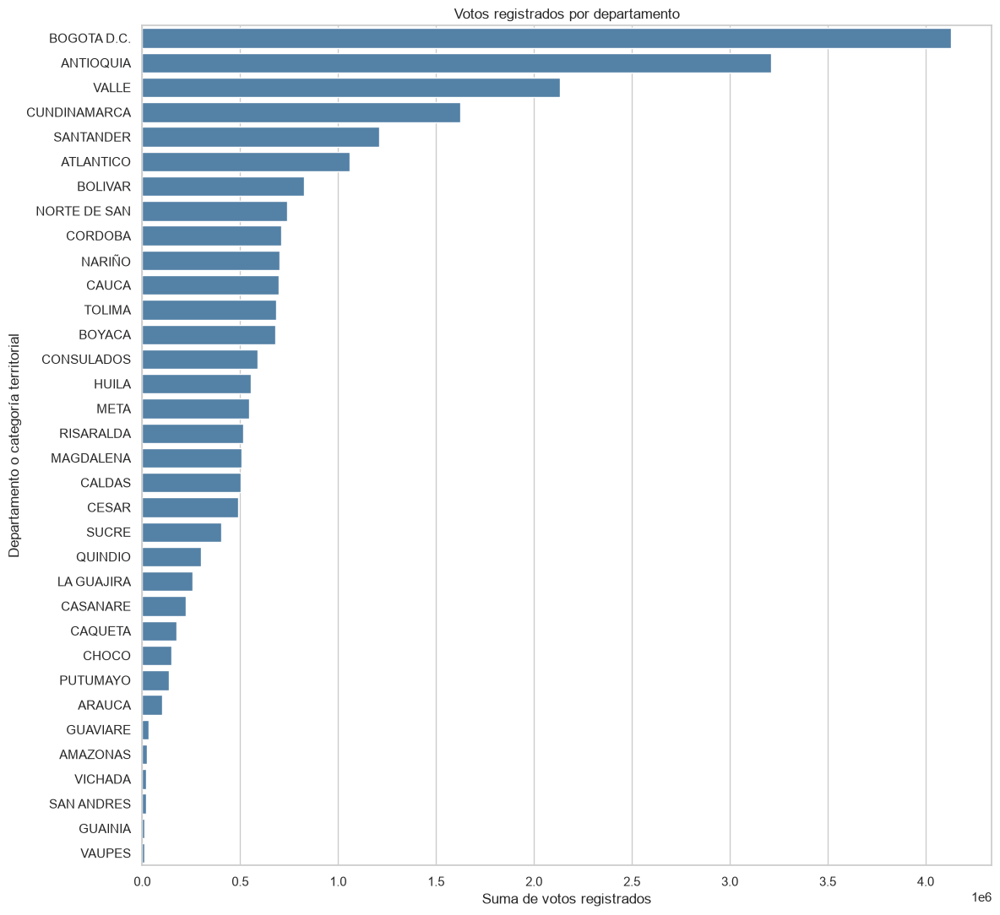

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

datos_grafico = (
    resumen_departamentos
    .sort_values("votos_registrados", ascending=False)
)

plt.figure(figsize=(12, 11))

sns.barplot(
    data=datos_grafico,
    x="votos_registrados",
    y="nombre_departamento",
    color="steelblue"
)

plt.title("Votos registrados por departamento")
plt.xlabel("Suma de votos registrados")
plt.ylabel("Departamento o categoría territorial")

plt.tight_layout()
plt.show()

### Caracterización territorial del preconteo

La agregación departamental permitió identificar diferencias en la distribución de votos registrados, el número de mesas y la cantidad de opciones electorales presentes por mesa.

Bogotá D. C. concentra el 17,22 % de los votos registrados, seguida de Antioquia (13,39 %) y Valle (8,90 %). Estas diferencias reflejan magnitudes absolutas y no deben interpretarse como tasas de participación, dado que no se han incorporado denominadores de población electoral habilitada.

Se identificó una heterogeneidad considerable en el número promedio de opciones electorales registradas por mesa. Mientras algunos departamentos presentan valores cercanos a las 16 opciones identificadas en el archivo, otros registran promedios inferiores a nueve.

Esta característica resulta relevante para la comprensión de la estructura de los datos, especialmente porque se han observado tanto registros con cero votos como ausencia de registros para determinadas opciones electorales.

Se recomienda profundizar en la distribución territorial de opciones presentes y examinar si las diferencias observadas se relacionan con patrones de registro, características de los puestos electorales u otros factores no identificados en esta etapa.

In [70]:
resumen_opciones_territorio = (
    resumen_mesas_territorio
    .groupby(
        ["departamento", "nombre_departamento"]
    )
    .agg(
        mesas=("mesa", "size"),
        media_opciones=("opciones_presentes", "mean"),
        mediana_opciones=("opciones_presentes", "median"),
        mesas_16=(
            "opciones_presentes",
            lambda x: (x == 16).sum()
        ),
        mesas_menos_10=(
            "opciones_presentes",
            lambda x: (x < 10).sum()
        )
    )
    .reset_index()
)

resumen_opciones_territorio["porcentaje_16"] = (
    resumen_opciones_territorio["mesas_16"]
    / resumen_opciones_territorio["mesas"] * 100
)

resumen_opciones_territorio["porcentaje_menos_10"] = (
    resumen_opciones_territorio["mesas_menos_10"]
    / resumen_opciones_territorio["mesas"] * 100
)

display(
    resumen_opciones_territorio[
        [
            "nombre_departamento",
            "mesas",
            "media_opciones",
            "porcentaje_16",
            "porcentaje_menos_10"
        ]
    ]
    .sort_values("media_opciones")
    .round(2)
)

,nombre_departamento,mesas,media_opciones,porcentaje_16,porcentaje_menos_10
10,CHOCO,1252,6.43,0.00,86.34
32,VICHADA,197,6.50,0.00,88.32
31,VAUPES,88,6.53,0.00,90.91
28,SAN ANDRES,156,6.62,0.00,97.44
25,GUAINIA,117,7.21,0.00,89.74
20,VALLE,11087,7.91,0.00,82.71
30,PUTUMAYO,809,8.08,0.00,78.49
29,AMAZONAS,176,8.15,0.00,75.57
21,ARAUCA,662,8.18,0.00,77.34
5,CAUCA,3427,8.19,0.12,71.40


### Heterogeneidad territorial en el registro de opciones electorales

El análisis de la cantidad de opciones electorales presentes por mesa reveló diferencias territoriales pronunciadas.

En departamentos como Huila, Santander, Norte de Santander y Antioquia, más del 98 % de las mesas presentan las 16 opciones electorales identificadas en el archivo. En contraste, Bogotá D. C., Valle, Chocó y Vichada no presentan mesas con las 16 opciones, y una proporción considerable de sus mesas contiene menos de diez opciones registradas.

Los resultados evidencian que la estructura de registros por mesa no es homogénea entre territorios. Esta diferencia resulta especialmente importante porque el archivo contiene tanto registros explícitos con cero votos como opciones electorales ausentes.

Por tanto, no es metodológicamente válido asumir que una opción ausente equivale a cero votos sin una justificación documental o una validación adicional.

La heterogeneidad identificada constituye un hallazgo relevante de calidad y estructura de los datos que deberá considerarse en las fases posteriores del proyecto. En esta etapa no es posible determinar si responde a diferencias operativas, mecanismos de registro u otras características del proceso de preconteo.

In [71]:
# Total de mesas por departamento
total_mesas_depto = (
    resumen_mesas
    .groupby("departamento")
    .size()
    .rename("total_mesas")
)

# Número de mesas donde aparece cada opción
presencia = (
    df_preconteo
    .groupby(["departamento", "candidato"])
    .size()
    .rename("mesas_con_opcion")
    .reset_index()
)

presencia = presencia.merge(
    total_mesas_depto,
    on="departamento",
    validate="many_to_one"
)

presencia["porcentaje_presencia"] = (
    100 * presencia["mesas_con_opcion"]
    / presencia["total_mesas"]
)

# Departamentos con patrones contrastantes
departamentos_interes = ["01", "16", "17", "31", "88"]

matriz_presencia = (
    presencia[
        presencia["departamento"].isin(
            departamentos_interes
        )
    ]
    .pivot(
        index="candidato",
        columns="departamento",
        values="porcentaje_presencia"
    )
    .fillna(0)
    .round(2)
)

matriz_presencia.columns = [
    {
        "01": "Antioquia",
        "16": "Bogotá",
        "17": "Chocó",
        "31": "Valle",
        "88": "Consulados"
    }.get(c, c)
    for c in matriz_presencia.columns
]

display(matriz_presencia)

,Antioquia,Bogotá,Chocó,Valle,Consulados
candidato,,,,,
001,99.97,99.99,99.52,99.99,99.26
002,99.13,96.52,32.27,58.85,79.97
003,99.54,61.43,43.69,63.94,70.08
004,99.97,99.98,89.06,99.41,99.21
005,98.66,28.64,20.37,23.14,58.64
006,98.57,18.96,19.09,15.39,59.37
007,98.50,13.58,15.50,13.43,59.07
008,98.43,9.58,13.26,11.94,57.82
009,98.35,6.48,7.51,6.57,57.19


### Presencia territorial de las opciones electorales

El análisis de presencia de opciones electorales por mesa evidenció diferencias significativas en términos descriptivos entre los departamentos examinados.

En Antioquia, las 16 opciones electorales aparecen en porcentajes superiores al 98 % de las mesas. En contraste, Bogotá, Valle y Chocó presentan una presencia mucho menor de determinadas candidaturas, especialmente aquellas con menor cantidad de votos registrados.

Las candidaturas `001` y `004` presentan una cobertura cercana al 100 % en los territorios seleccionados, mientras que otras candidaturas muestran diferencias de varias decenas de puntos porcentuales.

Los códigos especiales `996`, `997` y `998` también presentan patrones de presencia heterogéneos, cuya interpretación requiere establecer previamente su significado oficial.

Estos resultados sugieren que la ausencia de un registro electoral no puede tratarse automáticamente como un voto igual a cero. Se recomienda conservar la distinción entre valores explícitos de cero y opciones no registradas, hasta disponer de evidencia suficiente sobre el mecanismo de generación de los datos.

### Visualización geográfica departamental

Se propone construir un mapa coroplético de Colombia para representar la distribución territorial de los votos registrados en el preconteo.

La visualización permitirá identificar concentraciones geográficas y diferencias entre departamentos. Se distinguirán los votos absolutos de las medidas normalizadas por mesa, evitando interpretar la magnitud de votos como una tasa de participación electoral.

Para su construcción se integrará el resumen departamental con cartografía oficial o verificable de los límites administrativos de Colombia. La categoría de consulados se analizará por separado, debido a que no corresponde a un departamento geográfico del territorio nacional.

In [72]:
from pathlib import Path
import geopandas as gpd
import urllib.request

GEO_DIR = Path("../../data/external/geo")
GEO_DIR.mkdir(parents=True, exist_ok=True)

GEO_PATH = GEO_DIR / "colombia_departamentos.geojson"

URL = (
    "https://raw.githubusercontent.com/ytolosa/mapas-colombia/"
    "main/output/geojson/"
    "col_departamentos_real_nacional.geojson"
)

urllib.request.urlretrieve(URL, GEO_PATH)

gdf_departamentos = gpd.read_file(GEO_PATH)

print("Geometrías:", len(gdf_departamentos))
print("CRS:", gdf_departamentos.crs)
print("Columnas:", gdf_departamentos.columns.tolist())

display(gdf_departamentos.head())

Geometrías: 33
CRS: EPSG:4326
Columnas: ['divipola_dep', 'divipola_dep_n', 'dpto_nombre', 'area_km2', 'geometry']


,divipola_dep,divipola_dep_n,dpto_nombre,area_km2,geometry
0,05,5,ANTIOQUIA,62788.7331,"POLYGON ((-74.8305 8.2, -74.824 8.1985, -74.8115 8.1825, -74.812 8.167, -74.7985 8.1595, -74.7955 8.148, -74.785 8.1..."
1,08,8,ATLÁNTICO,3324.2958,"POLYGON ((-74.911 10.254, -74.9655 10.3265, -74.9815 10.3415, -75.006 10.361, -75.0245 10.3635, -75.044 10.375, -75...."
2,11,11,"BOGOTÁ, D.C.",1620.5408,"POLYGON ((-74.053 4.833, -74.0315 4.8235, -74.009 4.8205, -74.0005 4.8055, -74.0055 4.798, -74.013 4.798, -74.016 4...."
3,13,13,BOLÍVAR,26680.8064,"MULTIPOLYGON (((-73.916 7.2955, -74.0785 7.1515, -74.2075 7.0375, -74.246 7.0025, -74.259 7.0045, -74.2605 7.0085, -..."
4,15,15,BOYACÁ,23073.3970,"POLYGON ((-74.665 5.7685, -74.661 5.7785, -74.6535 5.7865, -74.647 5.8085, -74.6515 5.824, -74.651 5.833, -74.638 5...."


### Integración de información electoral y cartográfica

Para realizar el análisis espacial, se integraron los registros del preconteo electoral con la cartografía departamental de Colombia mediante GeoPandas.

Debido a que los códigos territoriales utilizados por la Registraduría Nacional del Estado Civil difieren de los códigos DIVIPOLA empleados en la cartografía, la integración se efectuó mediante nombres departamentales normalizados.

Se identificaron tres diferencias de nomenclatura: *Norte de San* frente a *Norte de Santander*, *San Andrés* frente a *Archipiélago de San Andrés, Providencia y Santa Catalina*, y *Valle* frente a *Valle del Cauca*. Estas diferencias se resolvieron mediante un diccionario explícito de equivalencias.

La integración se validó mediante una relación uno a uno, con el propósito de conservar las 33 unidades territoriales representadas en la cartografía y evitar duplicaciones o pérdidas de información.

Los registros correspondientes a consulados se mantuvieron fuera de la representación geográfica nacional, sin eliminarlos del conjunto de datos original.

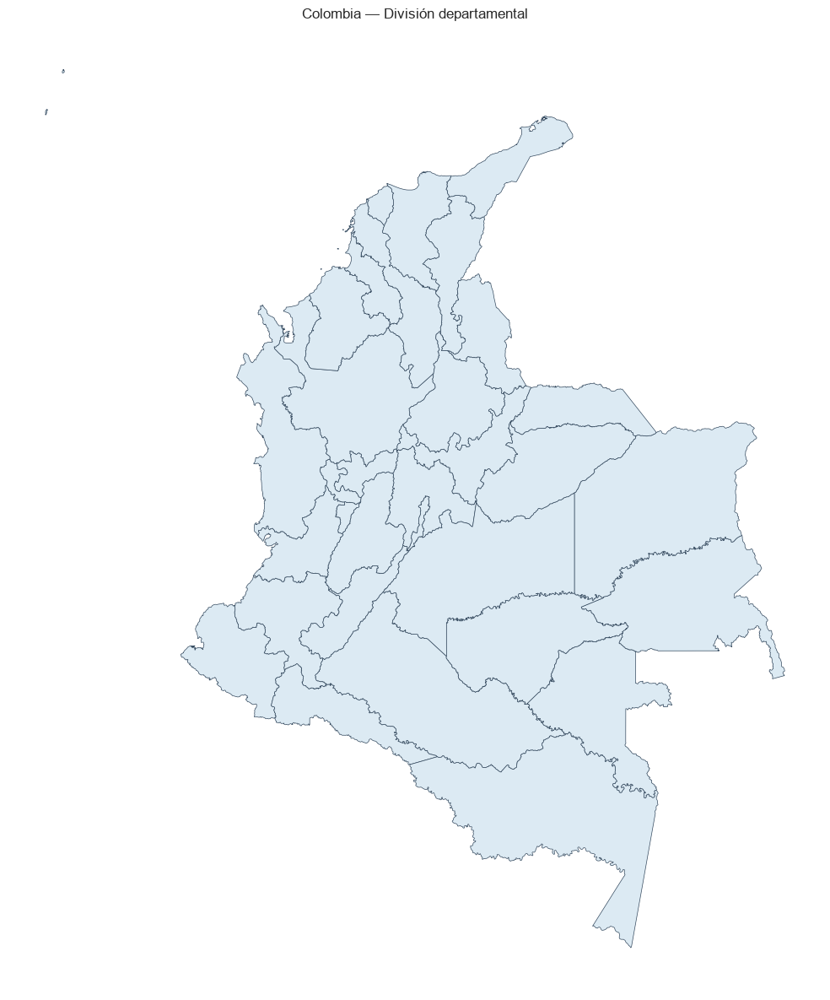

In [73]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 12))

gdf_departamentos.plot(
    ax=ax,
    color="#DCEAF3",
    edgecolor="#34495E",
    linewidth=0.5
)

ax.set_title("Colombia — División departamental")
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [74]:
import unicodedata

def normalizar_nombre(valor):
    if valor is None:
        return None

    texto = str(valor).upper().strip()

    texto = "".join(
        c for c in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(c)
    )

    return " ".join(texto.split())


print("Departamentos en cartografía:")
display(
    gdf_departamentos[
        ["divipola_dep", "dpto_nombre"]
    ].head(10)
)

print("Departamentos en preconteo:")
display(
    resumen_departamentos[
        ["departamento", "nombre_departamento"]
    ].head(10)
)

Departamentos en cartografía:


,divipola_dep,dpto_nombre
0,05,ANTIOQUIA
1,08,ATLÁNTICO
2,11,"BOGOTÁ, D.C."
3,13,BOLÍVAR
4,15,BOYACÁ
5,17,CALDAS
6,18,CAQUETÁ
7,19,CAUCA
8,20,CESAR
9,23,CÓRDOBA


Departamentos en preconteo:


,departamento,nombre_departamento
0,01,ANTIOQUIA
1,03,ATLANTICO
2,05,BOLIVAR
3,07,BOYACA
4,09,CALDAS
5,11,CAUCA
6,12,CESAR
7,13,CORDOBA
8,15,CUNDINAMARCA
9,16,BOGOTA D.C.


In [75]:
import pandas as pd
import unicodedata
import re

# Copias de trabajo
gdf_deptos = gdf_departamentos.copy()
df_deptos = resumen_departamentos.copy()

gdf_deptos["nombre_normalizado"] = (
    gdf_deptos["dpto_nombre"].apply(normalizar_nombre)
)

df_deptos["nombre_normalizado"] = (
    df_deptos["nombre_departamento"].apply(normalizar_nombre)
)

# Excluir consulados del mapa nacional
df_deptos = df_deptos[
    df_deptos["departamento"] != "88"
].copy()

# Verificar correspondencias
nombres_geo = set(gdf_deptos["nombre_normalizado"])
nombres_datos = set(df_deptos["nombre_normalizado"])

print("Sin correspondencia en cartografía:")
print(sorted(nombres_datos - nombres_geo))

print("\nSin correspondencia en preconteo:")
print(sorted(nombres_geo - nombres_datos))

Sin correspondencia en cartografía:
['BOGOTA D.C.', 'NORTE DE SAN', 'SAN ANDRES', 'VALLE']

Sin correspondencia en preconteo:
['ARCHIPIELAGO DE SAN ANDRES, PROVIDENCIA Y SANTA CATALINA', 'BOGOTA, D.C.', 'NORTE DE SANTANDER', 'VALLE DEL CAUCA']


In [76]:
# Equivalencias entre denominaciones electorales y cartográficas
equivalencias_departamentos = {
    "NORTE DE SAN": "NORTE DE SANTANDER",
    "SAN ANDRES": "ARCHIPIELAGO DE SAN ANDRES, PROVIDENCIA Y SANTA CATALINA",
    "VALLE": "VALLE DEL CAUCA",
    "BOGOTA D.C.": "BOGOTA, D.C.",
}

# Crear una clave de unión sin modificar el nombre original
df_deptos["nombre_union"] = (
    df_deptos["nombre_normalizado"]
    .replace(equivalencias_departamentos)
)

gdf_deptos["nombre_union"] = gdf_deptos["nombre_normalizado"]

# Verificar diferencias restantes
sin_geometria = (
    set(df_deptos["nombre_union"])
    - set(gdf_deptos["nombre_union"])
)

sin_preconteo = (
    set(gdf_deptos["nombre_union"])
    - set(df_deptos["nombre_union"])
)

print("Sin geometría:", sorted(sin_geometria))
print("Sin preconteo:", sorted(sin_preconteo))

assert not sin_geometria
assert not sin_preconteo

Sin geometría: []
Sin preconteo: []


In [77]:
print("Departamentos del preconteo sin geometría:")
for nombre in sorted(sin_geometria):
    print(repr(nombre))

print("\nDepartamentos de la cartografía sin preconteo:")
for nombre in sorted(sin_preconteo):
    print(repr(nombre))

Departamentos del preconteo sin geometría:

Departamentos de la cartografía sin preconteo:


In [78]:
gdf_electoral = gdf_deptos.merge(
    df_deptos,
    on="nombre_union",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert len(gdf_electoral) == 33
assert (gdf_electoral["_merge"] == "both").all()

print("Departamentos integrados:", len(gdf_electoral))
print("Geometrías faltantes:", gdf_electoral.geometry.isna().sum())
print("Valores electorales faltantes:", gdf_electoral["votos_registrados"].isna().sum())

display(
    gdf_electoral[
        [
            "dpto_nombre",
            "departamento",
            "nombre_departamento",
            "mesas",
            "votos_registrados"
        ]
    ].head(10)
)

Departamentos integrados: 33
Geometrías faltantes: 0
Valores electorales faltantes: 0


,dpto_nombre,departamento,nombre_departamento,mesas,votos_registrados
0,ANTIOQUIA,01,ANTIOQUIA,15801,3209520
1,ATLÁNTICO,03,ATLANTICO,6190,1060147
2,"BOGOTÁ, D.C.",16,BOGOTA D.C.,17164,4130084
3,BOLÍVAR,05,BOLIVAR,5355,827020
4,BOYACÁ,07,BOYACA,3126,677633
5,CALDAS,09,CALDAS,2492,502807
6,CAQUETÁ,44,CAQUETA,983,174993
7,CAUCA,11,CAUCA,3427,696829
8,CESAR,12,CESAR,2754,488601
9,CÓRDOBA,13,CORDOBA,4180,711571


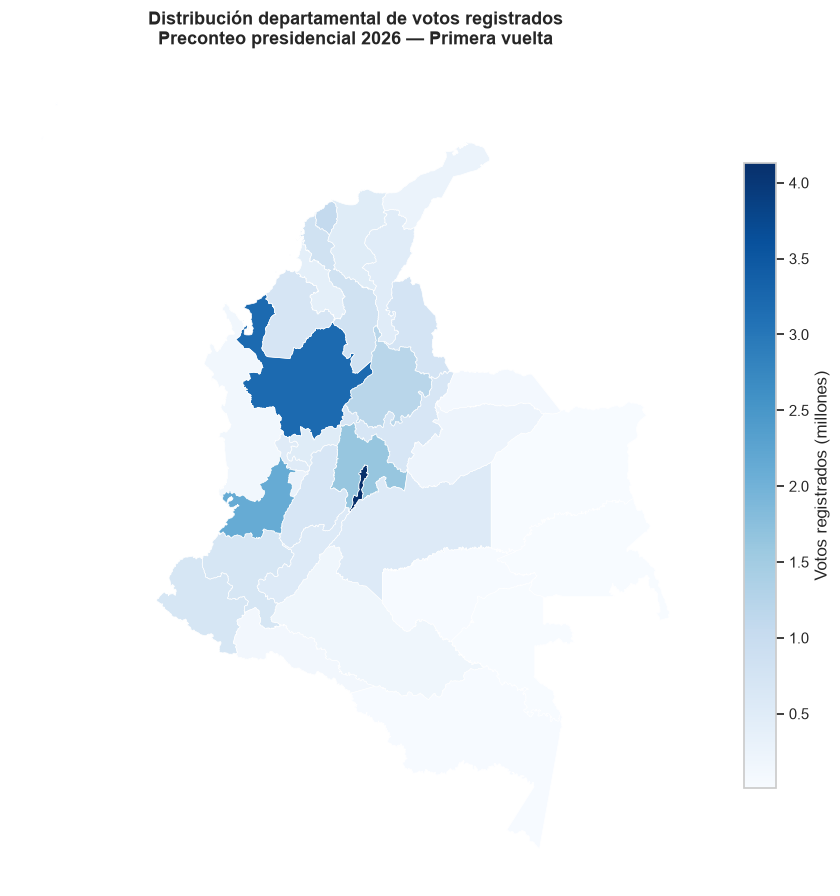

In [79]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(9, 10))

gdf_electoral.plot(
    column="votos_registrados",
    cmap="Blues",
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    ax=ax,
    legend_kwds={
        "label": "Votos registrados (millones)",
        "shrink": 0.65,
        "format": FuncFormatter(
            lambda x, pos: f"{x / 1_000_000:.1f}"
        )
    }
)

ax.set_title(
    "Distribución departamental de votos registrados\n"
    "Preconteo presidencial 2026 — Primera vuelta",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

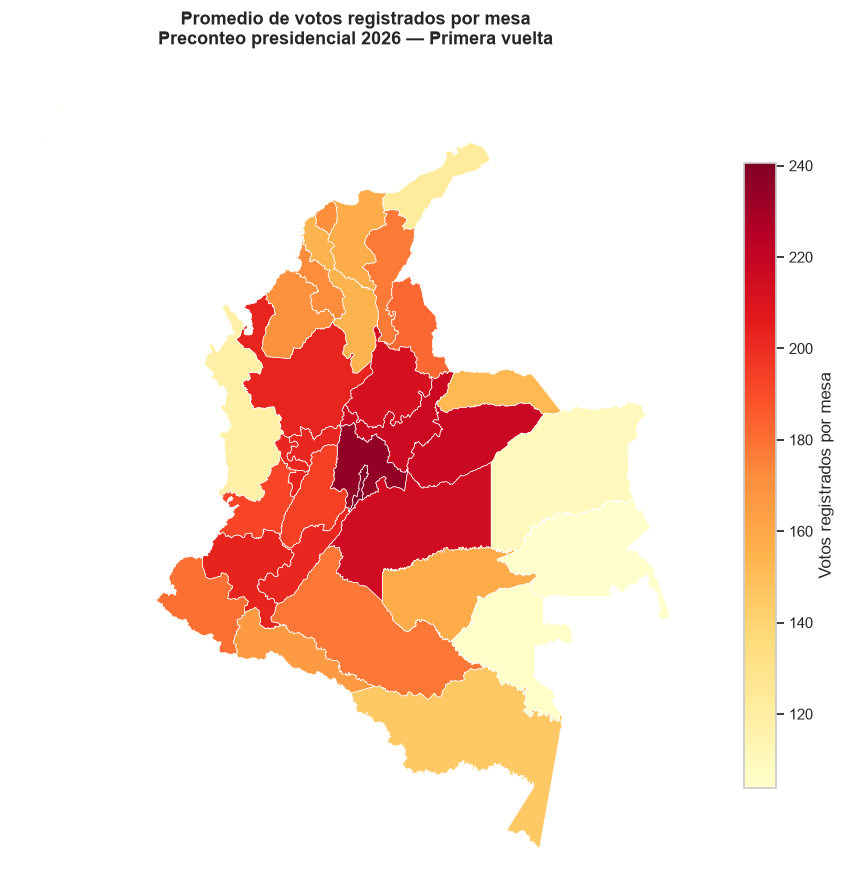

In [80]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 10))

gdf_electoral.plot(
    column="media_votos_mesa",
    cmap="YlOrRd",
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    ax=ax,
    legend_kwds={
        "label": "Votos registrados por mesa",
        "shrink": 0.65,
        "format": "%.0f"
    }
)

ax.set_title(
    "Promedio de votos registrados por mesa\n"
    "Preconteo presidencial 2026 — Primera vuelta",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

In [81]:
import pandas as pd
import geopandas as gpd
import plotly.graph_objects as go
import json

# Candidaturas identificadas (001 a 013)
codigos_candidaturas = [f"{i:03d}" for i in range(1, 14)]

# Votos por departamento y candidatura
votos_departamento_candidato = (
    df_preconteo[
        df_preconteo["candidato"].isin(codigos_candidaturas)
        & (df_preconteo["departamento"] != "88")
    ]
    .groupby(["departamento", "candidato"], as_index=False)["votos"]
    .sum()
)

# Total de votos de candidaturas por departamento
totales_departamento = (
    votos_departamento_candidato
    .groupby("departamento")["votos"]
    .sum()
    .rename("total_votos_candidaturas")
    .reset_index()
)

votos_departamento_candidato = votos_departamento_candidato.merge(
    totales_departamento,
    on="departamento",
    validate="many_to_one"
)

votos_departamento_candidato["porcentaje"] = (
    100
    * votos_departamento_candidato["votos"]
    / votos_departamento_candidato["total_votos_candidaturas"]
)

# Matriz de porcentajes: departamentos × candidaturas
matriz_porcentajes = (
    votos_departamento_candidato
    .pivot(
        index="departamento",
        columns="candidato",
        values="porcentaje"
    )
    .reindex(columns=codigos_candidaturas)
)

# Incorporar porcentajes al GeoDataFrame existente
gdf_candidaturas_mapa = gdf_electoral.merge(
    matriz_porcentajes,
    left_on="departamento",
    right_index=True,
    how="left",
    validate="one_to_one"
)

assert len(gdf_candidaturas_mapa) == 33

print("Departamentos:", len(gdf_candidaturas_mapa))
print("Candidaturas:", len(codigos_candidaturas))

display(matriz_porcentajes.head())

Departamentos: 33
Candidaturas: 13


candidato,001,002,003,004,005,006,007,008,009,010,011,012,013
departamento,,,,,,,,,,,,,
01,25.907733,0.433547,0.973439,55.420383,0.146059,0.141943,0.089494,0.062643,0.041226,0.024279,9.464652,7.237747,0.056854
03,52.738510,0.257742,0.316512,41.559858,0.198204,0.058194,0.048783,0.029289,0.060018,0.022087,2.010849,2.670377,0.029577
05,54.894243,0.290184,0.516090,38.712786,0.325854,0.112953,0.070472,0.053380,0.065889,0.023408,2.950392,1.943231,0.041119
07,32.850299,1.240851,0.923315,51.268476,0.176224,0.142224,0.101697,0.066179,0.037947,0.022920,8.743181,4.379483,0.047205
09,30.368467,1.019469,1.265612,45.459021,2.868971,0.228072,0.126914,0.097211,0.059199,0.030534,12.855324,5.546635,0.074570


In [82]:
# Crear identificador único para las geometrías
gdf_plot = gdf_candidaturas_mapa.reset_index(drop=True).copy()
gdf_plot["geo_id"] = gdf_plot.index.astype(str)

geojson = json.loads(gdf_plot.to_json())

# Crear trazas, una por candidatura
fig = go.Figure()

for i, codigo in enumerate(codigos_candidaturas):

    votos_codigo = (
        gdf_plot["departamento"]
        .map(
            votos_departamento_candidato[
                votos_departamento_candidato["candidato"] == codigo
            ].set_index("departamento")["votos"]
        )
        .fillna(0)
    )

    fig.add_trace(
        go.Choropleth(
            geojson=geojson,
            locations=gdf_plot["geo_id"],
            featureidkey="properties.geo_id",
            z=gdf_plot[codigo],
            zmin=0,
            zmax=100,
            colorscale="Blues",
            visible=(i == 0),
            customdata=list(
                zip(
                    gdf_plot["dpto_nombre"],
                    votos_codigo
                )
            ),
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>"
                "Porcentaje: %{z:.2f}%<br>"
                "Votos: %{customdata[1]:,.0f}"
                "<extra></extra>"
            ),
            colorbar=dict(title="Porcentaje (%)")
        )
    )

# Menú desplegable
botones = []

for i, codigo in enumerate(codigos_candidaturas):
    visibilidad = [j == i for j in range(len(codigos_candidaturas))]

    botones.append(
        dict(
            label=f"Candidatura {codigo}",
            method="update",
            args=[
                {"visible": visibilidad},
                {"title": (
                    "Distribución departamental de votos<br>"
                    f"Candidatura {codigo} — Preconteo 2026"
                )}
            ]
        )
    )

fig.update_layout(
    title=(
        "Distribución departamental de votos<br>"
        "Candidatura 001 — Preconteo 2026"
    ),
    updatemenus=[
        dict(
            buttons=botones,
            direction="down",
            x=0.02,
            y=1.05,
            xanchor="left",
            yanchor="bottom"
        )
    ],
    geo=dict(
        fitbounds="locations",
        visible=False
    ),
    height=800,
    margin=dict(l=0, r=0, t=110, b=0)
)

fig.show()

In [83]:
validacion = (
    votos_departamento_candidato
    .groupby("departamento")["porcentaje"]
    .sum()
)

print("Porcentaje mínimo:", validacion.min())
print("Porcentaje máximo:", validacion.max())

assert validacion.between(99.999, 100.001).all()

print("Validación correcta.")

Porcentaje mínimo: 100.0
Porcentaje máximo: 100.0
Validación correcta.


### Distribución territorial de las preferencias electorales

Con el propósito de explorar la heterogeneidad espacial de las preferencias electorales, se calculó la proporción de votos registrados para cada candidatura respecto al total de votos correspondientes a las 13 candidaturas identificadas en cada departamento.

La representación mediante mapas coropléticos interactivos permite comparar la distribución territorial relativa de las candidaturas, reduciendo la influencia del tamaño absoluto del electorado departamental sobre la interpretación visual.

Se utilizó una escala porcentual común entre 0 % y 100 % para facilitar la comparación entre candidaturas. Los códigos especiales `996`, `997` y `998` se excluyeron del denominador, dado que su significado requiere verificación documental.

Los resultados deben interpretarse como proporciones calculadas sobre los votos registrados para candidaturas en el conjunto de datos, y no como porcentajes de participación electoral ni como resultados oficiales definitivos.

## Relación Entre Variables

**Preguntas abordadas:**

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

### Análisis de relaciones entre variables

Se examina la relación entre el número de opciones electorales presentes en cada mesa y la suma de votos registrados en ella. Este análisis busca identificar patrones de asociación y posibles diferencias entre unidades territoriales.

Es importante distinguir entre la presencia de un registro y la obtención de votos: una opción puede aparecer con cero votos explícitos, mientras que la ausencia de un registro no permite concluir automáticamente que su votación fue cero.

Las asociaciones identificadas tienen carácter descriptivo y no permiten establecer relaciones causales.

In [84]:
import plotly.express as px

fig = px.box(
    resumen_mesas,
    x="opciones_presentes",
    y="suma_votos_registrados",
    points=False,
    labels={
        "opciones_presentes": "Número de opciones presentes",
        "suma_votos_registrados": "Votos registrados por mesa"
    },
    title="Distribución de votos por mesa según opciones presentes"
)

fig.update_layout(
    template="plotly_white",
    height=550
)

fig.show()

In [85]:
from scipy.stats import pearsonr, spearmanr

x = resumen_mesas["opciones_presentes"]
y = resumen_mesas["suma_votos_registrados"]

r_pearson, p_pearson = pearsonr(x, y)
r_spearman, p_spearman = spearmanr(x, y)

print(f"Pearson:  r = {r_pearson:.4f}, p = {p_pearson:.4g}")
print(f"Spearman: ρ = {r_spearman:.4f}, p = {p_spearman:.4g}")

Pearson:  r = -0.0865, p = 1.626e-201
Spearman: ρ = -0.1030, p = 1.014e-284


In [86]:
fig = px.scatter(
    resumen_departamentos.query("departamento != '88'"),
    x="media_opciones",
    y="media_votos_mesa",
    size="mesas",
    hover_name="nombre_departamento",
    hover_data={
        "mesas": True,
        "votos_registrados": True
    },
    labels={
        "media_opciones": "Promedio de opciones presentes por mesa",
        "media_votos_mesa": "Promedio de votos registrados por mesa",
        "mesas": "Número de mesas"
    },
    title="Opciones presentes y votos por mesa: comparación departamental"
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()

In [87]:
diagnostico_departamentos = (
    resumen_departamentos[
        resumen_departamentos["departamento"] != "88"
    ][
        [
            "nombre_departamento",
            "mesas",
            "media_opciones",
            "media_votos_mesa",
            "mediana_votos_mesa"
        ]
    ]
    .sort_values("media_opciones")
    .reset_index(drop=True)
)

display(diagnostico_departamentos)

,nombre_departamento,mesas,media_opciones,media_votos_mesa,mediana_votos_mesa
0,CHOCO,1252,6.430511,117.616613,121.0
1,VICHADA,197,6.502538,109.497462,111.0
2,VAUPES,88,6.534091,105.159091,105.0
3,SAN ANDRES,156,6.615385,116.134615,112.5
4,GUAINIA,117,7.205128,103.709402,106.0
5,VALLE,11087,7.908632,192.408857,200.0
6,PUTUMAYO,809,8.076638,166.247219,172.0
7,AMAZONAS,176,8.153409,145.210227,143.0
8,ARAUCA,662,8.179758,152.158610,160.0
9,CAUCA,3427,8.190546,203.334987,222.0


In [88]:
import plotly.express as px

df_diagnostico = diagnostico_departamentos.copy()

fig = px.bar(
    df_diagnostico,
    x="nombre_departamento",
    y="media_opciones",
    color="media_opciones",
    color_continuous_scale="Viridis",
    hover_data=["mesas", "media_votos_mesa"],
    labels={
        "nombre_departamento": "Departamento",
        "media_opciones": "Opciones promedio por mesa"
    },
    title="Heterogeneidad departamental en la presencia de opciones electorales"
)

fig.update_layout(
    template="plotly_white",
    height=600,
    xaxis_tickangle=-55,
    coloraxis_showscale=False
)

fig.show()

In [89]:
# Porcentaje de mesas con registro de cada opción, por departamento
presencia_opciones = (
    df_preconteo[
        df_preconteo["departamento"] != "88"
    ]
    .groupby(["departamento", "candidato"])
    .size()
    .unstack(fill_value=0)
)

# Total de mesas únicas por departamento
total_mesas = (
    resumen_mesas[
        resumen_mesas["departamento"] != "88"
    ]
    .groupby("departamento")
    .size()
)

porcentaje_presencia = (
    presencia_opciones
    .div(total_mesas, axis=0)
    .mul(100)
)

# Añadir nombres departamentales
nombres_departamentos = (
    resumen_departamentos
    .set_index("departamento")["nombre_departamento"]
)

porcentaje_presencia.index = (
    porcentaje_presencia.index.map(nombres_departamentos)
)

fig = px.imshow(
    porcentaje_presencia,
    labels={
        "x": "Código de opción electoral",
        "y": "Departamento",
        "color": "Mesas con registro (%)"
    },
    color_continuous_scale="Blues",
    zmin=0,
    zmax=100,
    aspect="auto",
    title="Presencia de opciones electorales por departamento"
)

fig.update_layout(
    height=850,
    template="plotly_white"
)

fig.show()

### Heterogeneidad territorial en la presencia de opciones electorales

El análisis departamental evidencia una marcada heterogeneidad en el número promedio de opciones electorales registradas por mesa. Se identifican dos conjuntos diferenciados: uno con promedios entre 6,43 y 9,60 opciones y otro con promedios entre 15,78 y 15,94.

Esta separación sugiere que la estructura de los registros no es homogénea entre departamentos. Adicionalmente, las diferencias observadas no parecen corresponder exclusivamente al volumen promedio de votos por mesa, puesto que existen departamentos con cantidades similares de votos registrados, pero con promedios de opciones considerablemente distintos.

El hallazgo requiere examinar la presencia individual de cada código electoral y verificar las reglas de representación de opciones en el archivo de preconteo. Por tanto, no es posible atribuir estas diferencias a errores, irregularidades electorales o mecanismos específicos de procesamiento sin evidencia adicional.

In [90]:
import plotly.express as px

diagnostico_ceros = (
    df_preconteo[df_preconteo["departamento"] != "88"]
    .assign(es_cero=lambda d: d["votos"].eq(0))
    .groupby("departamento")
    .agg(
        registros=("votos", "size"),
        registros_cero=("es_cero", "sum")
    )
    .reset_index()
)

diagnostico_ceros["porcentaje_ceros"] = (
    100 * diagnostico_ceros["registros_cero"]
    / diagnostico_ceros["registros"]
)

diagnostico_ceros = diagnostico_ceros.merge(
    resumen_departamentos[
        ["departamento", "nombre_departamento", "media_opciones"]
    ],
    on="departamento",
    validate="one_to_one"
)

fig = px.scatter(
    diagnostico_ceros,
    x="media_opciones",
    y="porcentaje_ceros",
    hover_name="nombre_departamento",
    size="registros",
    labels={
        "media_opciones": "Opciones promedio por mesa",
        "porcentaje_ceros": "Registros con cero votos (%)",
        "registros": "Número de registros"
    },
    title="Presencia de opciones y proporción de ceros explícitos"
)

fig.update_layout(template="plotly_white", height=550)
fig.show()

### Patrones territoriales de presencia de opciones electorales

El análisis exploratorio evidencia dos grupos departamentales claramente diferenciados según el número promedio de opciones electorales registradas por mesa. El primer grupo presenta promedios aproximados entre 6,4 y 9,6 opciones, mientras que el segundo registra valores cercanos a las 16 opciones identificadas en el conjunto de datos.

El mapa de calor muestra que esta heterogeneidad está asociada principalmente con diferencias en la presencia de determinados códigos electorales, especialmente entre `004` y `011`. En consecuencia, la estructura de los registros no es uniforme entre departamentos.

Estos resultados sugieren la necesidad de distinguir entre ausencia de registros y valores de votación iguales a cero. La evidencia disponible no permite establecer las causas de la heterogeneidad ni atribuirla a irregularidades electorales.

Este hallazgo constituye una limitación relevante para cualquier análisis posterior que suponga una representación homogénea de las opciones electorales entre mesas y territorios.

In [91]:
import pandas as pd

columnas_mesa = [
    "departamento", "municipio", "zona", "puesto", "mesa"
]

columnas_opcion = columnas_mesa + ["candidato"]

total_registros = len(df_preconteo)
total_mesas = len(resumen_mesas)

calidad_datos = pd.DataFrame([
    {
        "dimension": "Completitud",
        "indicador": "Registros con valores nulos",
        "valor": int(df_preconteo.isna().any(axis=1).sum()),
        "interpretacion": "Ausencia de valores nulos en las columnas analizadas"
    },
    {
        "dimension": "Unicidad",
        "indicador": "Duplicados mesa-opción",
        "valor": int(df_preconteo.duplicated(columnas_opcion).sum()),
        "interpretacion": "Verificación de unicidad de registros electorales"
    },
    {
        "dimension": "Consistencia",
        "indicador": "Registros con votos negativos",
        "valor": int((df_preconteo["votos"] < 0).sum()),
        "interpretacion": "Verificación del dominio de la variable votos"
    },
    {
        "dimension": "Representación",
        "indicador": "Registros con cero votos",
        "valor": int(df_preconteo["votos"].eq(0).sum()),
        "interpretacion": "Ceros explícitos; no equivalen a registros ausentes"
    },
    {
        "dimension": "Cobertura",
        "indicador": "Mesas con menos de 16 opciones",
        "valor": int(resumen_mesas["opciones_presentes"].lt(16).sum()),
        "interpretacion": "Variación en la representación de opciones por mesa"
    },
    {
        "dimension": "Cobertura territorial",
        "indicador": "Mesas sin correspondencia DIVIPOL",
        "valor": int(
            resumen_mesas_territorio["nombre_departamento"]
            .isna().sum()
        ),
        "interpretacion": "Validación de referencia territorial"
    },
    {
        "dimension": "Interpretabilidad",
        "indicador": "Registros con códigos 996, 997 y 998",
        "valor": int(
            df_preconteo["candidato"].isin(
                ["996", "997", "998"]
            ).sum()
        ),
        "interpretacion": "Códigos especiales pendientes de validación semántica"
    }
])

display(calidad_datos)

,dimension,indicador,valor,interpretacion
0,Completitud,Registros con valores nulos,0,Ausencia de valores nulos en las columnas analizadas
1,Unicidad,Duplicados mesa-opción,0,Verificación de unicidad de registros electorales
2,Consistencia,Registros con votos negativos,0,Verificación del dominio de la variable votos
3,Representación,Registros con cero votos,527421,Ceros explícitos; no equivalen a registros ausentes
4,Cobertura,Mesas con menos de 16 opciones,61623,Variación en la representación de opciones por mesa
5,Cobertura territorial,Mesas sin correspondencia DIVIPOL,0,Validación de referencia territorial
6,Interpretabilidad,"Registros con códigos 996, 997 y 998",302867,Códigos especiales pendientes de validación semántica


In [92]:
import plotly.express as px

distribucion_opciones = (
    resumen_mesas["opciones_presentes"]
    .value_counts()
    .sort_index()
    .rename_axis("opciones_presentes")
    .reset_index(name="mesas")
)

distribucion_opciones["porcentaje"] = (
    100 * distribucion_opciones["mesas"] / total_mesas
)

fig = px.bar(
    distribucion_opciones,
    x="opciones_presentes",
    y="mesas",
    text="porcentaje",
    labels={
        "opciones_presentes": "Opciones registradas por mesa",
        "mesas": "Número de mesas"
    },
    title="Distribución del número de opciones registradas por mesa"
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    height=550,
    xaxis=dict(dtick=1)
)

fig.show()

In [93]:
total_original = int(df_preconteo["votos"].sum())

total_agregado = int(
    resumen_mesas["suma_votos_registrados"].sum()
)

print(f"Total original: {total_original:,}")
print(f"Total agregado: {total_agregado:,}")
print(f"Diferencia: {total_original - total_agregado:,}")

assert total_original == total_agregado

print("Integridad de agregación verificada.")

Total original: 23,978,304
Total agregado: 23,978,304
Diferencia: 0
Integridad de agregación verificada.


In [94]:
mesas_unicas = (
    df_preconteo[columnas_mesa]
    .drop_duplicates()
    .shape[0]
)

assert mesas_unicas == total_mesas

print("Mesas únicas:", mesas_unicas)
print("Mesas agregadas:", total_mesas)

Mesas únicas: 122020
Mesas agregadas: 122020


In [95]:
import matplotlib.ticker as mtick

# Colores que usan las gráficas de esta parte
AZUL, NARANJA, GRIS_AUSENTE = "#2a78d6", "#eb6834", "#c3c2b7"
FONDO, TINTA_2 = "#fcfcfb", "#52514e"
AZULES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

# Etiqueta corta de cada candidatura: código y primer apellido
ESPECIALES = {"996": "VOTO EN BLANCO", "997": "VOTOS NULOS", "998": "VOTOS NO MARCADOS"}
primer_apellido = candidatos["apellido"].str.extract(r"^((?:(?:DE|LA|DEL)\s+)*\S+)")[0].str.title()
etiqueta_cand = dict(zip(candidatos["candidato"], candidatos["candidato"] + " · " + primer_apellido))
etiqueta_cand.update({c: f"{c} · {n.capitalize()}" for c, n in ESPECIALES.items()})

# Una fila por mesa del preconteo (se vuelve a crear porque más arriba "mesas" se usa con otro sentido)
mesas = precon.groupby(LLAVE_MESA).agg(filas=("votos", "size"), votos=("votos", "sum")).reset_index()
N_MESAS = len(mesas)

# Estado de cada candidatura en las mesas: con votos, cero explícito o ausente
estado = (precon.assign(estado=np.where(precon["votos"] > 0, "Con votos", "Cero explícito"))
          .groupby(["candidato", "estado"]).size().unstack(fill_value=0))
estado["Ausente"] = N_MESAS - estado.sum(axis=1)
estado_pct = 100 * estado[["Con votos", "Cero explícito", "Ausente"]] / N_MESAS

print("Mesas:", N_MESAS)

Mesas: 122020


### Filas ausentes por departamento
---

Si las filas ausentes fueran un error de captura, se esperaría que se concentraran en algunos departamentos. El mapa de calor muestra, para cada departamento y candidatura, el porcentaje de mesas que **no traen fila**. Los departamentos se ordenan de mayor a menor número de mesas y las candidaturas de mayor a menor ausencia nacional.

Dimensiones: (33, 16)
Valores válidos: 528


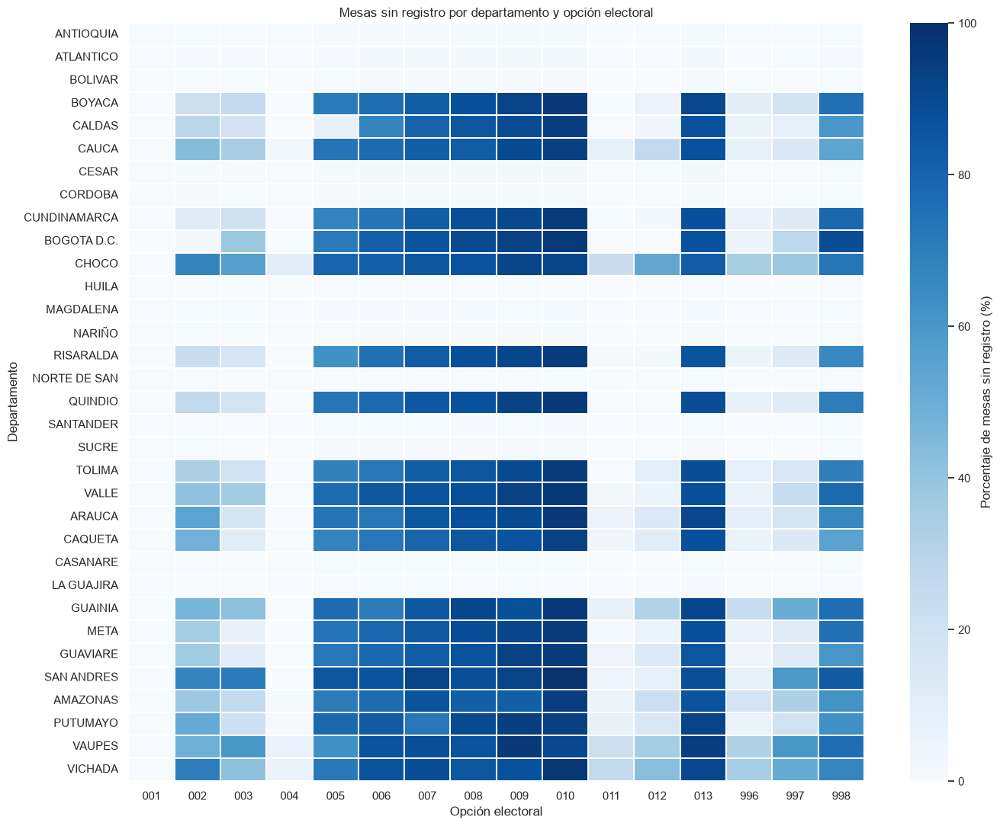

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular ausencia a partir de presencia
ausencia_dep = 100 - porcentaje_presencia

# Comprobar que hay datos válidos
print("Dimensiones:", ausencia_dep.shape)
print("Valores válidos:", ausencia_dep.notna().sum().sum())

# Crear el mapa de calor
plt.figure(figsize=(14, 11))

sns.heatmap(
    ausencia_dep,
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.2,
    cbar_kws={
        "label": "Porcentaje de mesas sin registro (%)"
    }
)

plt.title(
    "Mesas sin registro por departamento y opción electoral"
)
plt.xlabel("Opción electoral")
plt.ylabel("Departamento")

plt.tight_layout()
plt.show()

#### Interpretación

Las filas ausentes **no están repartidas al azar: dependen del departamento.** El mapa muestra dos grupos casi sin términos medios:

- **Departamentos sin ausencias.** Antioquia, Atlántico, Santander, Bolívar, Córdoba, Norte de Santander, Nariño, Magdalena, Cesar, Huila, Sucre, La Guajira y Casanare tienen cerca de 0 % de filas ausentes en todas las candidaturas. Sus mesas traen las 16 filas, incluidas las que tienen cero votos.
- **Departamentos con ausencias.** En Bogotá, Valle, Cundinamarca, Tolima, Cauca, Boyacá, el Eje Cafetero, Meta, Chocó y los antiguos territorios nacionales, las candidaturas pequeñas faltan en el 60 %–100 % de las mesas. Allí la fila solo aparece cuando la candidatura tiene votos.
- **Consulados (exterior)** queda en un punto intermedio, con ausencias cercanas al 50 %.

La sección 3.4 lo confirma: el 100 % de las mesas con 16 filas tiene al menos un cero explícito, frente al 2,9 % de las mesas con menos filas. Es decir, el preconteo parece transmitirse con **dos formatos según el territorio**: uno con todas las filas y otro solo con las filas que tienen votos.

**Consecuencias:**
- El número de filas por mesa refleja el formato de transmisión y no el resultado electoral, así que **no debe usarse como variable predictora**.
- Una partición por departamento separaría también los dos formatos, lo que hay que tener en cuenta al validar los modelos.

*Nota:* el catálogo DIVIPOL guarda el nombre del departamento en 12 caracteres, por eso aparece cortado "Norte De San".

###  Jerarquía territorial: mesas por puesto y por municipio
---

El diccionario señala que `mun`, `zona`, `puesto` y `mesa` solo identifican algo dentro de su nivel superior. Estas dos gráficas muestran cuántas mesas agrupa cada puesto de votación y cada municipio. Esto importa para la partición de los datos y para comparar mesas del mismo puesto: un puesto con una sola mesa no tiene con qué compararse.

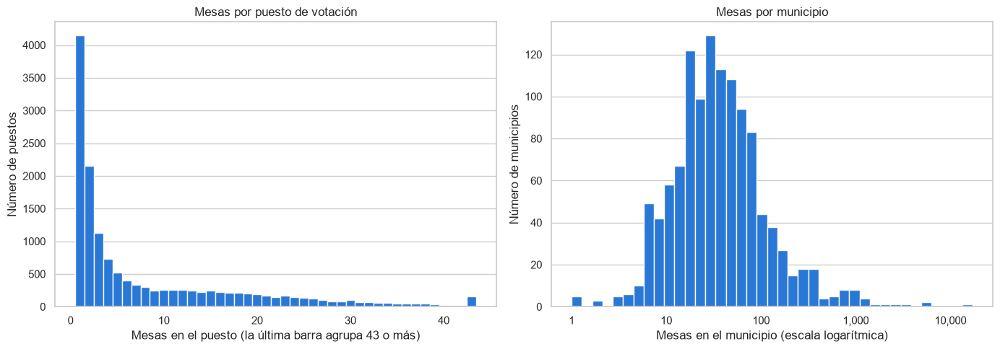

Puestos: 14,438 | mediana de mesas por puesto: 3 | puestos con una sola mesa: 4,146 (28.7 %)
Municipios: 1,189 | mediana de mesas por municipio: 33 | máximo: 17,164 (BOGOTA D.C., mun 001)
Los 10 municipios con más mesas concentran el 33.5 % de las mesas


In [97]:
# Nombre del departamento por código (desde el catálogo DIVIPOL de la Fase 1)
nombre_dep = divipol.drop_duplicates("dep").set_index("dep")["dep_nombre"].to_dict()

mesas_puesto = mesas.groupby(["dep", "mun", "zona", "puesto"]).size()
mesas_mun = mesas.groupby(["dep", "mun"]).size()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tope = int(mesas_puesto.quantile(0.99))
axes[0].hist(mesas_puesto.clip(upper=tope), bins=np.arange(0.5, tope + 1.5), color=AZUL,
             edgecolor=FONDO, linewidth=1)
axes[0].set_title("Mesas por puesto de votación")
axes[0].set_xlabel(f"Mesas en el puesto (la última barra agrupa {tope} o más)")
axes[0].set_ylabel("Número de puestos")
axes[0].grid(axis="x", visible=False)

bordes = np.logspace(0, np.log10(mesas_mun.max()), 40)
axes[1].hist(mesas_mun, bins=bordes, color=AZUL, edgecolor=FONDO, linewidth=1)
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
axes[1].set_title("Mesas por municipio")
axes[1].set_xlabel("Mesas en el municipio (escala logarítmica)")
axes[1].set_ylabel("Número de municipios")
axes[1].grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

print(f"Puestos: {len(mesas_puesto):,} | mediana de mesas por puesto: {mesas_puesto.median():.0f} "
      f"| puestos con una sola mesa: {(mesas_puesto == 1).sum():,} ({100 * (mesas_puesto == 1).mean():.1f} %)")
print(f"Municipios: {len(mesas_mun):,} | mediana de mesas por municipio: {mesas_mun.median():.0f} "
      f"| máximo: {mesas_mun.max():,} ({nombre_dep.get(mesas_mun.idxmax()[0])}, mun {mesas_mun.idxmax()[1]})")
top_mun = mesas_mun.sort_values(ascending=False)
print(f"Los 10 municipios con más mesas concentran el {100 * top_mun.head(10).sum() / N_MESAS:.1f} % de las mesas")

#### Interpretación

- **Puestos.** Hay 14 438 puestos de votación y la mitad tiene 3 mesas o menos. **4 146 puestos (28,7 %) tienen una sola mesa**, así que en ellos no se puede comparar una mesa con sus vecinas del mismo puesto. Esa comparación es una de las ideas para detectar anomalías, y para estas mesas habrá que usar el municipio o la zona como referencia.
- **Municipios.** Hay 1 189 códigos de municipio, incluidos los 67 del exterior. La distribución es muy asimétrica: la mediana es de 33 mesas, pero Bogotá tiene 17 164. **Los 10 municipios con más mesas concentran el 33,5 % de todas las mesas.**
- **Consecuencia para la partición:** una división aleatoria de mesas dejaría casi todos los municipios grandes en entrenamiento y prueba a la vez. Si se agrupa por territorio, conviene estratificar por tamaño para que unas pocas ciudades no dominen un conjunto.

### Número de filas según el tamaño de la mesa
---

El notebook principal muestra que las mesas traen entre 1 y 16 filas. Esta gráfica cruza ese número con el total de votos de la mesa, para ver si las mesas con menos filas son simplemente mesas más pequeñas, donde varias candidaturas no recibieron votos.

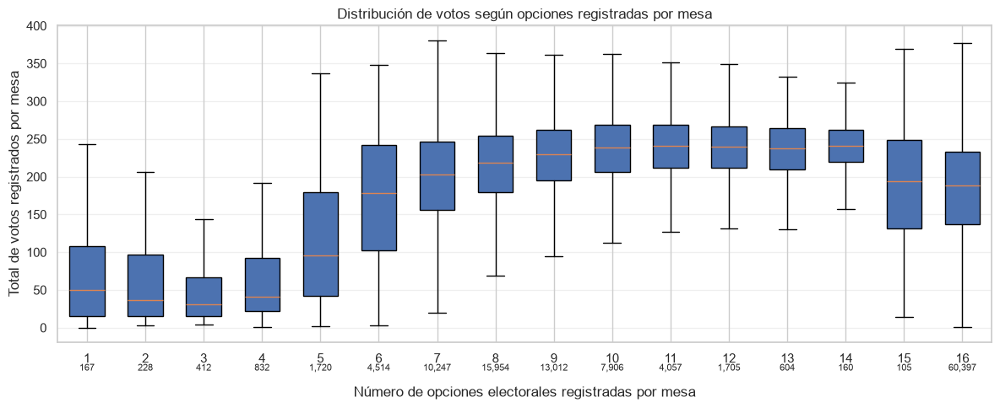

Mesas con 16 opciones y al menos un cero explícito: 100.0%
Mesas con menos de 16 opciones y al menos un cero explícito: 2.9%


In [98]:
import matplotlib.pyplot as plt

# Usar el resumen de mesas que ya existe en el notebook
mesas = resumen_mesas.rename(
    columns={
        "opciones_presentes": "filas",
        "suma_votos_registrados": "votos"
    }
)

# Agrupar los votos según la cantidad de registros por mesa
grupos = [
    mesas.loc[mesas["filas"] == k, "votos"]
    for k in range(1, 17)
]

# Crear el gráfico
fig, ax = plt.subplots(figsize=(12, 5))

ax.boxplot(
    grupos,
    positions=range(1, 17),
    widths=0.6,
    showfliers=False,
    patch_artist=True
)

# Mostrar cuántas mesas tiene cada grupo
for k, g in zip(range(1, 17), grupos):
    ax.text(
        k, -0.09, f"{len(g):,}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        fontsize=8
    )

ax.set_xticks(range(1, 17))
ax.set_xlabel(
    "Número de opciones electorales registradas por mesa",
    labelpad=18
)
ax.set_ylabel("Total de votos registrados por mesa")
ax.set_title(
    "Distribución de votos según opciones registradas por mesa"
)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Comparar registros con cero votos
tiene_ceros = mesas["registros_cero"] > 0

print(
    "Mesas con 16 opciones y al menos un cero explícito:",
    f"{tiene_ceros[mesas['filas'] == 16].mean():.1%}"
)

print(
    "Mesas con menos de 16 opciones y al menos un cero explícito:",
    f"{tiene_ceros[mesas['filas'] < 16].mean():.1%}"
)

#### Interpretación

- **De 1 a 14 filas, más filas significa una mesa más grande.** Las mesas con 1 a 4 filas son pequeñas (mediana de 30 a 50 votos). Desde 9 filas, la mediana se estabiliza alrededor de 230–240 votos. Esto concuerda con el formato que solo trae las candidaturas con votos: en una mesa con pocos votantes, pocas candidaturas reciben alguno.
- **Las mesas con 16 filas no siguen ese patrón.** Su mediana (188 votos) es menor que la de las mesas con 9 a 14 filas, y su dispersión es mayor. Corresponden al formato que trae todas las filas, así que reúnen mesas de todos los tamaños.
- **Los ceros explícitos separan los dos formatos casi por completo.** El 100 % de las mesas con 16 filas tiene al menos una candidatura con cero votos escrita en el archivo. Entre las mesas con menos filas, eso solo ocurre en el 2,9 %.

Los números bajo el eje indican cuántas mesas hay en cada grupo. Los grupos de 1 a 4 y de 14 a 15 filas tienen pocas mesas, así que sus cajas son menos estables.

## Resumen de la Calidad de los Datos

**Preguntas abordadas:**
- ¿Se detectan datos ausentes, archivos vacíos o registros de baja calidad?
- ¿Existen archivos ilegibles o problemas de codificación?
- ¿La diversidad de formatos afecta la consistencia o comprensión de los datos?
- ¿Se identificaron valores atípicos, duplicados o datos faltantes? ¿Cómo se abordaron?

A continuación se sintetizan los resultados de las verificaciones de integridad, consistencia y calidad realizadas sobre los registros del preconteo.

### Evaluación de la calidad de los datos

La evaluación de calidad del conjunto de datos se desarrolló considerando las dimensiones de completitud, unicidad, consistencia, cobertura territorial, representación e interpretabilidad.

Las comprobaciones estructurales previas no identificaron valores nulos ni duplicados para la combinación de mesa y opción electoral. Asimismo, la integración con el catálogo DIVIPOL permitió establecer correspondencia territorial para la totalidad de las mesas identificadas.

No obstante, se detectó una heterogeneidad considerable en el número de opciones electorales registradas por mesa, con patrones claramente diferenciados entre departamentos. También se identificaron registros con votación igual a cero y opciones que no aparecen explícitamente en determinadas mesas.

Estos dos últimos casos deben distinguirse: un valor de cero representa una observación registrada, mientras que la ausencia de una opción constituye una falta de registro cuya interpretación requiere información adicional.

Por otra parte, los códigos especiales `996`, `997` y `998` requieren validación semántica mediante la documentación oficial de la fuente.

En consecuencia, aunque el conjunto presenta características favorables de integridad estructural y correspondencia territorial, persisten limitaciones de representación e interpretación que deben documentarse antes de utilizar los datos en procedimientos posteriores de preparación o modelado.

In [99]:
import pandas as pd

n_registros = len(df_preconteo)
n_mesas = len(resumen_mesas)
n_puestos = df_preconteo[
    ["departamento", "municipio", "zona", "puesto"]
].drop_duplicates().shape[0]

n_ceros = int(df_preconteo["votos"].eq(0).sum())
n_mesas_incompletas = int(
    resumen_mesas["opciones_presentes"].lt(16).sum()
)

n_duplicados = int(
    df_preconteo.duplicated(
        [
            "departamento", "municipio", "zona",
            "puesto", "mesa", "candidato"
        ]
    ).sum()
)

n_mesas_sin_divipol = int(
    resumen_mesas_territorio["nombre_departamento"]
    .isna().sum()
)

indicadores_finales = pd.DataFrame({
    "Indicador": [
        "Registros electorales",
        "Mesas únicas",
        "Puestos electorales",
        "Opciones electorales identificadas",
        "Registros con cero votos",
        "Porcentaje de registros con cero votos",
        "Mesas con menos de 16 opciones",
        "Porcentaje de mesas con menos de 16 opciones",
        "Duplicados mesa-opción",
        "Mesas sin correspondencia DIVIPOL"
    ],
    "Valor": [
        n_registros,
        n_mesas,
        n_puestos,
        df_preconteo["candidato"].nunique(),
        n_ceros,
        round(100 * n_ceros / n_registros, 2),
        n_mesas_incompletas,
        round(100 * n_mesas_incompletas / n_mesas, 2),
        n_duplicados,
        n_mesas_sin_divipol
    ]
})

display(indicadores_finales)

,Indicador,Valor
0,Registros electorales,1479506.00
1,Mesas únicas,122020.00
2,Puestos electorales,14438.00
3,Opciones electorales identificadas,16.00
4,Registros con cero votos,527421.00
5,Porcentaje de registros con cero votos,35.65
6,Mesas con menos de 16 opciones,61623.00
7,Porcentaje de mesas con menos de 16 opciones,50.50
8,Duplicados mesa-opción,0.00
9,Mesas sin correspondencia DIVIPOL,0.00


### Síntesis de resultados del entendimiento de los datos

El análisis exploratorio del conjunto de datos correspondiente al preconteo de la primera vuelta presidencial de Colombia en 2026 permitió caracterizar su estructura, granularidad, distribución territorial y principales limitaciones de interpretación.

**Estructura y granularidad.** Se identificaron 1.479.506 registros electorales correspondientes a 122.020 mesas. La unidad de observación está definida por la combinación de identificadores territoriales, mesa y opción electoral. Se identificaron 16 códigos de opción, de los cuales 13 corresponden a candidaturas y tres requieren validación semántica adicional.

**Integridad estructural.** Las verificaciones realizadas no identificaron valores nulos ni duplicados para la combinación de mesa y opción electoral. La integración con DIVIPOL permitió establecer correspondencia territorial para la totalidad de las mesas identificadas.

**Representación de las opciones electorales.** Se identificaron 527.421 registros con cero votos explícitos, equivalentes aproximadamente al 35,65 % de los registros. Adicionalmente, el número de opciones presentes varía entre mesas, por lo que no debe equipararse automáticamente la ausencia de un registro con un valor de cero.

**Heterogeneidad territorial.** La exploración departamental evidenció diferencias importantes en el volumen de votos registrados, los promedios de votos por mesa y la cantidad de opciones electorales presentes. En particular, se observaron dos grupos departamentales claramente diferenciados en términos del número promedio de opciones registradas por mesa.

**Análisis geográfico.** La integración con cartografía departamental permitió construir representaciones espaciales de los votos registrados y explorar la distribución relativa de las candidaturas. Los registros correspondientes a consulados se conservaron para análisis independiente, sin incorporarlos a los mapas del territorio nacional.

**Limitaciones.** Los resultados corresponden a la información contenida en el archivo de preconteo analizado. No deben interpretarse como resultados oficiales definitivos ni como indicadores de participación electoral. Además, la interpretación de los códigos especiales y de los registros ausentes requiere documentación adicional de la fuente.

#### Carga de los datos

Se reutiliza el código de carga de la Fase 1, con un cambio: el archivo de novedades se lee en UTF-8, que es su codificación real. En la Fase 1 se leía en latin-1, lo que alteraba los nombres de puesto con tildes y eñes.

## Escrutinio

### **1.1. Resumen General**
---

- ¿Cuántos documentos tiene el *dataset*?
- ¿En qué formato están almacenados los datos?
- ¿Qué tamaño en MB tiene el conjunto de datos?

In [100]:
escru.head()

,comunicado,dep,mun,zona,puesto,mesa,comuna,corporacion,circ,partido,candidato,votos
0,9999,01,001,001,01,000001,00,001,0,00026,001,30
1,9999,01,001,001,01,000001,00,001,0,01004,002,1
2,9999,01,001,001,01,000001,00,001,0,01001,003,0
3,9999,01,001,001,01,000001,00,001,0,01003,004,59
4,9999,01,001,001,01,000001,00,001,0,03001,005,0


In [101]:
escru.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1952320 entries, 0 to 1952319
Data columns (total 12 columns):
 #   Column       Dtype
---  ------       -----
 0   comunicado   str  
 1   dep          str  
 2   mun          str  
 3   zona         str  
 4   puesto       str  
 5   mesa         str  
 6   comuna       str  
 7   corporacion  str  
 8   circ         str  
 9   partido      str  
 10  candidato    str  
 11  votos        int64
dtypes: int64(1), str(11)
memory usage: 1.1 GB


In [102]:
esc_diccionario = pd.DataFrame([
    ("comunicado",  "Valor fijo (9999)",   "Numérico",     4, "Valor fijo; siempre 9999"),
    ("dep",         "Código Departamento", "Numérico",     2, "Departamento de la mesa (88 = consulados)"),
    ("mun",         "Código Municipio",    "Numérico",     3, "Municipio dentro del departamento"),
    ("zona",        "Código Zona",         "Numérico",     3, "Zona electoral dentro del municipio"),
    ("puesto",      "Código Puesto",       "Alfanumérico", 2, "Puesto de votación dentro de la zona"),
    ("mesa",        "Número de mesa",      "Numérico",     6, "Mesa dentro del puesto; con las cuatro llaves anteriores identifica la mesa"),
    ("comuna",      "Código Comuna",       "Numérico",     2, "Comuna o localidad; siempre 00 en este archivo"),
    ("corporacion", "Código corporación",  "Numérico",     3, "Cargo que se elige; 001 = Presidente"),
    ("circ",        "Circunscripción",     "Numérico",     1, "Circunscripción electoral; siempre 0 en este archivo"),
    ("partido",     "Código de partido",   "Numérico",     4, "Partido que inscribe al candidato (completado a 5 dígitos en la carga)"),
    ("candidato",   "Código de candidato", "Numérico",     3, "Candidato (001–013) o voto especial: 996 blanco, 997 nulo, 998 no marcado"),
    ("votos",       "Votos",               "Numérico",     8, "Votos de la candidatura en la mesa según el escrutinio oficial"),
], columns=["columna", "campo_oficial", "tipo_oficial", "longitud", "descripcion"])

esc_diccionario["tipo_pandas"]    = esc_diccionario["columna"].map(escru.dtypes.astype(str))
esc_diccionario["valores_unicos"] = esc_diccionario["columna"].map(escru.nunique())
esc_diccionario["ejemplo"]        = esc_diccionario["columna"].map(escru.iloc[0])
esc_diccionario = esc_diccionario[["columna", "campo_oficial", "tipo_oficial", "longitud",
                                   "tipo_pandas", "valores_unicos", "ejemplo", "descripcion"]]
display(esc_diccionario)

,columna,campo_oficial,tipo_oficial,longitud,tipo_pandas,valores_unicos,ejemplo,descripcion
0,comunicado,Valor fijo (9999),Numérico,4,str,1,9999,Valor fijo; siempre 9999
1,dep,Código Departamento,Numérico,2,str,34,01,Departamento de la mesa (88 = consulados)
2,mun,Código Municipio,Numérico,3,str,309,001,Municipio dentro del departamento
3,zona,Código Zona,Numérico,3,str,52,001,Zona electoral dentro del municipio
4,puesto,Código Puesto,Alfanumérico,2,str,208,01,Puesto de votación dentro de la zona
5,mesa,Número de mesa,Numérico,6,str,228,000001,Mesa dentro del puesto; con las cuatro llaves anteriores identifica la mesa
6,comuna,Código Comuna,Numérico,2,str,1,00,Comuna o localidad; siempre 00 en este archivo
7,corporacion,Código corporación,Numérico,3,str,1,001,Cargo que se elige; 001 = Presidente
8,circ,Circunscripción,Numérico,1,str,1,0,Circunscripción electoral; siempre 0 en este archivo
9,partido,Código de partido,Numérico,4,str,14,00026,Partido que inscribe al candidato (completado a 5 dígitos en la carga)


In [103]:
esc_mesas = escru.groupby(LLAVE_MESA).agg(filas=("votos", "size"),
                                          ceros=("votos", lambda s: (s == 0).sum()))
esc_resumen = pd.Series(dtype=object, data={
    "Registros": len(escru),
    "Columnas": escru.shape[1],
    "Mesas": len(esc_mesas),
    "Mesas completas (16 filas)": (esc_mesas["filas"] == 16).sum(),
    "Mesas incompletas (< 16 filas)": (esc_mesas["filas"] < 16).sum(),
    "Filas con 0 votos": (escru["votos"] == 0).sum(),
    "Filas ausentes frente a la rejilla 122 020 × 16": len(esc_mesas) * 16 - len(escru),
    "Votos totales": escru["votos"].sum(),
    "Tamaño en disco (MB)": round(os.path.getsize(ARCH_ESCRUTINIO) / 1024**2, 2),
    "Tamaño en memoria (MB)": round(escru.memory_usage(deep=True).sum() / 1024**2, 1),
})
display(esc_resumen.to_frame("valor"))
display(esc_mesas["filas"].value_counts().sort_index().to_frame("mesas"))   # filas por mesa

,valor
Registros,1952320
Columnas,12
Mesas,122020
Mesas completas (16 filas),122020
Mesas incompletas (< 16 filas),0
Filas con 0 votos,1008827
Filas ausentes frente a la rejilla 122 020 × 16,0
Votos totales,23990635
Tamaño en disco (MB),100.54
Tamaño en memoria (MB),1081.8


,mesas
filas,
16,122020


**¿Cuántos documentos tiene el *dataset*?**

El archivo de escrutinio contiene **1 952 320 registros** y 12 columnas. Cada registro representa la votación oficial de una candidatura en una mesa. Los registros cubren las **122 020 mesas** de la elección (118 350 nacionales y 3 670 en consulados), y **todas las mesas tienen exactamente 16 registros**: los 13 candidatos más el voto en blanco (996), el voto nulo (997) y los votos no marcados (998).

A diferencia del preconteo, donde 61 623 mesas omiten las candidaturas sin votos, el escrutinio es una rejilla completa (122 020 × 16 = 1 952 320). No le falta ningún registro e incluye todas las candidaturas aunque no hayan obtenido votos. Por eso 1 008 827 registros (51,7 %) tienen cero votos. En total, el escrutinio suma **23 990 635 votos**, 12 331 más que el preconteo.

**¿En qué formato están almacenados los datos?**

El escrutinio es un archivo de valores separados por punto y coma (`.csv` con `;`), sin encabezado y codificado en latin-1. Cada línea contiene los 12 campos definidos en el documento *Estructuras Básicas*, que se describen en la tabla anterior con su tipo oficial, su longitud y el tipo con el que se cargaron en *pandas*. Las líneas terminan con un `;` adicional que genera una decimotercera columna vacía; por eso la carga lee únicamente los 12 primeros campos.

Los campos se completan con ceros a la izquierda. Por eso las llaves y los códigos se conservan como texto (`object`) y solo `votos` se convierte a entero (`int64`). Ninguna columna presenta valores nulos. Cuatro campos tienen un único valor en todo el archivo (`comunicado` = 9999, `comuna` = 00, `corporacion` = 001 y `circ` = 0), por lo que no aportan información para el análisis.

El formato difiere del preconteo en dos llaves: la zona tiene 3 dígitos en el escrutinio (2 en el preconteo) y el partido 4 dígitos (5 en el preconteo y en el catálogo de partidos). Durante la carga, el partido se completó a 5 dígitos (por ejemplo, `0026` → `00026`) para poder cruzar las fuentes.

**¿Qué tamaño en MB tiene el conjunto de datos?**

El archivo ocupa **100,54 MB en disco**, y es la fuente más pesada del paquete. Una vez cargado en *pandas*, ocupa **1 081,8 MB en memoria** (aproximadamente 1,1 GB), unas 11 veces más, porque las once columnas de texto almacenan cada valor como un objeto independiente.

### **1.2. Resumen de la Calidad de los datos**
---

- ¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad en el conjunto?
- ¿Se identifican documentos ilegibles o con dificultades de codificación durante la revisión del conjunto de datos?
- ¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?
- ¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?

#### Escrutinio


**¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad?**

In [104]:
LONGITUD_OFICIAL = {"comunicado": 4, "dep": 2, "mun": 3, "zona": 3, "puesto": 2, "mesa": 6,
                    "comuna": 2, "corporacion": 3, "circ": 1, "partido": 4, "candidato": 3}

revision = pd.DataFrame({
    "longitud_oficial": LONGITUD_OFICIAL,
    "longitudes_encontradas": {c: sorted(escru[c].str.len().unique()) for c in LONGITUD_OFICIAL},
    "solo_digitos": {c: escru[c].str.isdigit().all() for c in LONGITUD_OFICIAL},
})
display(revision)

print("Departamentos que no están en DIVIPOL:", set(escru["dep"]) - set(divipol["dep"]))
print("Candidatos que no están en el catálogo:", set(escru["candidato"]) - set(candidatos["candidato"]))

,longitud_oficial,longitudes_encontradas,solo_digitos
comunicado,4,[4],True
dep,2,[2],True
mun,3,[3],True
zona,3,[3],True
puesto,2,[2],False
mesa,6,[6],True
comuna,2,[2],True
corporacion,3,[3],True
circ,1,[1],True
partido,4,[5],True


Departamentos que no están en DIVIPOL: set()
Candidatos que no están en el catálogo: {'998', '997', '996'}


In [105]:
# ¿Cada departamento + municipio existe en DIVIPOL?
esc_mun = escru[["dep", "mun"]].drop_duplicates()
cat_mun = divipol[["dep", "mun", "dep_nombre", "mun_nombre"]].drop_duplicates()
cruce_mun = esc_mun.merge(cat_mun, on=["dep", "mun"], how="left")
print("Municipios en el escrutinio:", len(esc_mun))
print("Municipios sin nombre en DIVIPOL:", cruce_mun["mun_nombre"].isnull().sum())
display(cruce_mun.head())

# ¿Cada puesto existe en DIVIPOL?
esc_puesto = escru[["dep", "mun", "zona", "puesto"]].drop_duplicates()
cruce_puesto = esc_puesto.merge(divipol[["dep", "mun", "zona", "puesto", "puesto_nombre"]],
                                on=["dep", "mun", "zona", "puesto"], how="left")
print("Puestos en el escrutinio:", len(esc_puesto))
print("Puestos sin nombre en DIVIPOL:", cruce_puesto["puesto_nombre"].isnull().sum())

Municipios en el escrutinio: 1189
Municipios sin nombre en DIVIPOL: 0


,dep,mun,dep_nombre,mun_nombre
0,01,001,ANTIOQUIA,MEDELLIN
1,01,004,ANTIOQUIA,ABEJORRAL
2,01,007,ANTIOQUIA,ABRIAQUI
3,01,010,ANTIOQUIA,ALEJANDRIA
4,01,013,ANTIOQUIA,AMAGA


Puestos en el escrutinio: 14438
Puestos sin nombre en DIVIPOL: 0


Valores nulos por columna:
comunicado     0
dep            0
mun            0
zona           0
puesto         0
mesa           0
comuna         0
corporacion    0
circ           0
partido        0
candidato      0
votos          0
dtype: int64

Mesas con 0 votos: 46
excluida
NO    118313
SI        37
Name: count, dtype: int64

Rango de votos por fila: 0 a 694
Rango de votos por mesa: 0 a 942


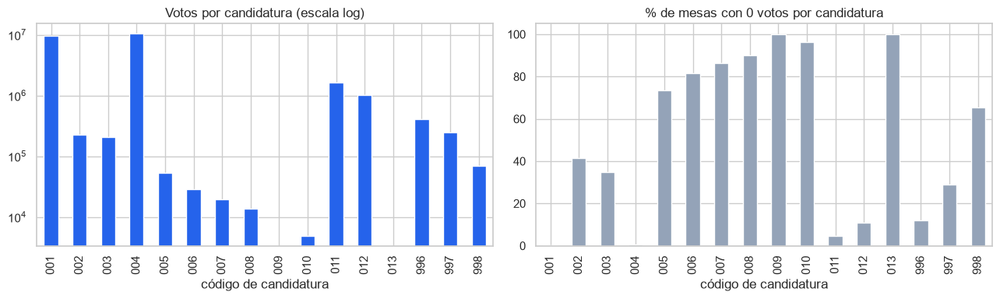

In [106]:
print("Valores nulos por columna:")
print(escru.isnull().sum())

votos_mesa = escru.groupby(LLAVE_MESA)["votos"].sum()
print("\nMesas con 0 votos:", (votos_mesa == 0).sum())
print(noved["excluida"].value_counts())
print("\nRango de votos por fila:", escru["votos"].min(), "a", escru["votos"].max())
print("Rango de votos por mesa:", votos_mesa.min(), "a", votos_mesa.max())

votos_cand = escru.groupby("candidato")["votos"].sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
votos_cand.plot.bar(ax=ax[0], color="#2563EB")
ax[0].set_yscale("log")
ax[0].set_title("Votos por candidatura (escala log)")
ax[0].set_xlabel("código de candidatura")
(escru["votos"] == 0).groupby(escru["candidato"]).mean().mul(100).plot.bar(ax=ax[1], color="#94A3B8")
ax[1].set_title("% de mesas con 0 votos por candidatura")
ax[1].set_xlabel("código de candidatura")
plt.tight_layout()
plt.show()

In [107]:
print(escru.nunique())

comunicado       1
dep             34
mun            309
zona            52
puesto         208
mesa           228
comuna           1
corporacion      1
circ             1
partido         14
candidato       16
votos          398
dtype: int64


In [108]:
print("Votos negativos:", (escru["votos"] < 0).sum())

Votos negativos: 0


No hay datos ausentes. Ninguna columna tiene valores nulos y, como el archivo incluye todas las combinaciones de mesa y candidatura, no falta ninguna mesa ni ninguna candidatura.

Se identifican **46 mesas vacías**, con cero votos en total. Nueve son de consulados. Las otras 37 coinciden con las 37 mesas que el archivo de novedades marca como excluidas: la comisión escrutadora anuló su votación, así que el cero es el resultado esperado y no un error de datos.

No se encontraron valores de baja calidad. No hay votos negativos; el total por mesa va de 0 a 942 votos, y el máximo de una sola candidatura en una mesa es 694.

**Figura 1.** *Votos totales y porcentaje de mesas sin votos por candidatura en el escrutinio (elaboración propia).*

La Figura 1 muestra dos situaciones a tener en cuenta en el análisis:

- **Candidatos retirados.** Los candidatos 009 y 013 no aparecen en la gráfica de la izquierda porque tienen cero votos en todas las mesas (100 % en la gráfica de la derecha): el escrutinio aplicó su retiro. Sus columnas no aportan información.
- **Abundancia de ceros.** El 51,7 % de los registros tiene cero votos. Esto es esperable: dos candidatos (001 y 004) concentran la votación y aparecen en casi todas las mesas, mientras que los candidatos minoritarios (005 a 010) no reciben votos en la mayoría de ellas. Lo mismo ocurre con los votos no marcados (998), que están en cero en cerca de dos tercios de las mesas.

También se verificó que cada campo cumpla la especificación de *Estructuras Básicas*. Todos los códigos tienen exactamente la longitud indicada y contienen solo dígitos, con dos excepciones esperadas: el puesto, que el documento define como alfanumérico (108 códigos combinan una letra y un número, como `A1`), y el partido, que tiene 5 dígitos porque se completó durante la carga para cruzarlo con el preconteo. Todos los departamentos existen en el catálogo DIVIPOL, y todos los candidatos en el catálogo oficial, salvo los códigos 996, 997 y 998, que corresponden a votos en blanco, nulos y no marcados. No se encontraron errores de digitación en los códigos.

Además de la longitud, se comprobó que los códigos correspondan a lugares reales, cruzándolos con el catálogo DIVIPOL. Como el código de municipio solo es único dentro de su departamento (el `001` es Medellín en Antioquia, pero otro municipio en otro departamento), la verificación se hizo con la pareja departamento–municipio. Las 1 189 combinaciones del escrutinio y sus 14 438 puestos de votación existen en DIVIPOL y tienen nombre asignado; en el caso de los consulados (departamento 88), cada código de municipio corresponde a un país. Por tanto, no hay códigos geográficos inexistentes ni mal digitados.

El conteo de valores únicos por columna (método `nunique()`) confirma que `comunicado`, `comuna`, `corporacion` y `circ` tienen un solo valor y no aportan información. También muestra que los códigos geográficos son jerárquicos: la columna `mesa` tiene solo 228 valores distintos, aunque el archivo contiene 122 020 mesas, porque el número de mesa se repite en cada puesto (todos los puestos tienen una mesa `000001`). Lo mismo ocurre con el municipio (309 códigos para 1 189 municipios) y el puesto (208 códigos para 14 438 puestos), según el cruce con el catálogo DIVIPOL. Por eso, una mesa solo queda identificada de forma única con la combinación de sus cinco códigos: departamento, municipio, zona, puesto y mesa.

**¿Se identifican documentos ilegibles o con dificultades de codificación?**

In [109]:
# 1. Legibilidad: las primeras líneas se leen bien y el archivo cargó completo
with open(ARCH_ESCRUTINIO, encoding="latin-1") as f:
    for _ in range(3):
        print(repr(f.readline()))
print("\nRegistros cargados:", len(escru), "| esperados (122 020 × 16):", 122020 * 16)

# 2. Codificación: caracteres distintos de dígitos y letras mayúsculas
texto = escru.select_dtypes(exclude="number").columns
print("\nValores con caracteres extraños por columna:")
print(escru[texto].apply(lambda s: s.str.contains(r"[^0-9A-Z]").sum()))

# 3. Puestos con letra (alfanuméricos según la documentación)
print("\nCódigos de puesto con letras:", escru["puesto"][~escru["puesto"].str.isdigit()].nunique())

'9999;01;001;001;01;000001;00;001;0;0026;001;00000030;\n'
'9999;01;001;001;01;000001;00;001;0;1004;002;00000001;\n'
'9999;01;001;001;01;000001;00;001;0;1001;003;00000000;\n'

Registros cargados: 1952320 | esperados (122 020 × 16): 1952320

Valores con caracteres extraños por columna:
comunicado     0
dep            0
mun            0
zona           0
puesto         0
mesa           0
comuna         0
corporacion    0
circ           0
partido        0
candidato      0
dtype: int64

Códigos de puesto con letras: 108


No. El archivo de escrutinio es legible y no presenta problemas de codificación.

**Legibilidad.** Las primeras líneas del archivo se leen correctamente. Por ejemplo, `9999;01;001;001;01;000001;00;001;0;0026;001;00000030;` indica que en la mesa 1 del puesto 1 de Medellín (departamento 01, municipio 001) el candidato 001 obtuvo 30 votos. Además, se cargaron los 1 952 320 registros esperados (122 020 mesas × 16 candidaturas), lo que confirma que ninguna línea se perdió ni se dañó durante la lectura. Su huella MD5 también coincide con la publicada por la Registraduría (Fase 1).

**Codificación.** Ninguna columna contiene caracteres distintos de dígitos y letras mayúsculas. Esto es esperable, porque el escrutinio solo almacena códigos y votos, no nombres con tildes o eñes que pudieran alterarse si el archivo se leyera con una codificación equivocada.

La única particularidad son 108 códigos de puesto que combinan una letra y un número (por ejemplo, `A1` o `Z5`). No son errores: el documento *Estructuras Básicas* define el puesto como un campo alfanumérico.

Por último, los códigos 996, 997 y 998 (voto en blanco, nulo y no marcado) no figuran en el catálogo de candidatos ni en la documentación oficial; su significado se infirió de las magnitudes de votos.

**¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?**

In [110]:
# 1. Cómo viene el archivo sin ajustes: 13 columnas, la última vacía
crudo = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, dtype=str, nrows=5)
display(crudo)

# 2. Formato de cada campo en todo el archivo
display(pd.DataFrame({
    "longitudes": {c: sorted(escru[c].str.len().unique()) for c in escru.columns if c != "votos"},
    "solo_digitos": {c: escru[c].str.isdigit().all() for c in escru.columns if c != "votos"},
}))

# 3. Candidatos y votos especiales en la misma columna
print(escru.groupby("candidato")["partido"].first())

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,9999,01,001,001,01,000001,00,001,0,0026,001,00000030,NaN
1,9999,01,001,001,01,000001,00,001,0,1004,002,00000001,NaN
2,9999,01,001,001,01,000001,00,001,0,1001,003,00000000,NaN
3,9999,01,001,001,01,000001,00,001,0,1003,004,00000059,NaN
4,9999,01,001,001,01,000001,00,001,0,3001,005,00000000,NaN


,longitudes,solo_digitos
comunicado,[4],True
dep,[2],True
mun,[3],True
zona,[3],True
puesto,[2],False
mesa,[6],True
comuna,[2],True
corporacion,[3],True
circ,[1],True
partido,[5],True


candidato
001    00026
002    01004
003    01001
004    01003
005    03001
006    00020
007    01002
008    00022
009    01006
010    00021
011    00009
012    00015
013    01005
996    00000
997    00000
998    00000
Name: partido, dtype: str


No se observa una diversidad de formatos dentro del archivo de escrutinio. Todas sus líneas siguen la misma estructura de 12 campos separados por punto y coma, y la segunda tabla muestra que cada campo conserva una única longitud en todo el archivo: el departamento siempre tiene 2 dígitos, el municipio 3, la mesa 6, y así sucesivamente.

Sin embargo, hay cuatro particularidades de formato que dificultan su comprensión si no se conocen, y que se tuvieron en cuenta durante la carga:

- **Columna adicional vacía.** Cada línea termina con un `;` de más. Por eso, al leer el archivo sin ajustes aparecen 13 columnas, y la última (columna 12) está vacía (`NaN`), como muestra la primera tabla. Se resolvió leyendo únicamente los 12 primeros campos.
- **Códigos que parecen números pero no lo son.** Casi todos los campos están definidos como numéricos en la documentación, pero se completan con ceros a la izquierda (`01`, `001`, `000001`). Si se leyeran como números, esos ceros se perderían y los códigos cambiarían. Por eso se cargaron como texto.
- **Puesto alfanumérico.** El puesto es el único campo con `False` en la columna `solo_digitos`, porque mezcla códigos numéricos (`01`) con códigos de letra y número (`A1`, `Z5`). Ambos son válidos según la documentación.
- **Votos especiales mezclados con los candidatos.** La columna `candidato` incluye, además de los 13 candidatos, los códigos 996, 997 y 998 (voto en blanco, nulo y no marcado), que no son personas. Como muestra la última salida, se distinguen porque su partido es `00000`. En el análisis deben tratarse por separado de los candidatos.

El partido aparece con 5 dígitos en la segunda tabla, aunque el archivo trae 4, porque se completó durante la carga para cruzarlo con el preconteo.

Por tanto, el formato es consistente, pero exige conocer estas convenciones para interpretar correctamente los datos.

**¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?**

Filas duplicadas: 0
Mesa + candidato duplicados: 0

Q1: 157.0 | Mediana: 206.0 | Q3: 247.0
Límite inferior: 22.0 | Límite superior: 382.0
Atípicas bajas: 1482
Atípicas altas: 56


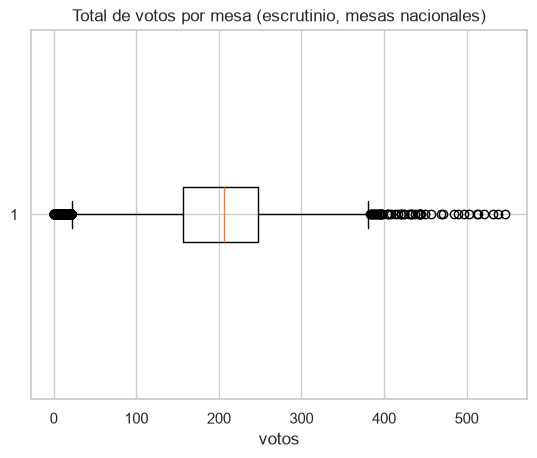

In [111]:
print("Filas duplicadas:", escru.duplicated().sum())
print("Mesa + candidato duplicados:", escru.duplicated(subset=LLAVE_MESA + ["candidato"]).sum())

nac = votos_mesa[votos_mesa.index.get_level_values("dep") != "88"]
Q1 = nac.quantile(0.25)
Q3 = nac.quantile(0.75)
IQR = Q3 - Q1
print("\nQ1:", Q1, "| Mediana:", nac.median(), "| Q3:", Q3)
print("Límite inferior:", Q1 - 1.5 * IQR, "| Límite superior:", Q3 + 1.5 * IQR)
print("Atípicas bajas:", (nac < Q1 - 1.5 * IQR).sum())
print("Atípicas altas:", (nac > Q3 + 1.5 * IQR).sum())
plt.boxplot(nac, orientation="horizontal")
plt.title("Total de votos por mesa (escrutinio, mesas nacionales)")
plt.xlabel("votos")
plt.show()

**Duplicados.** No hay registros duplicados, ni filas completas repetidas ni combinaciones de mesa y candidatura que aparezcan más de una vez. Cada mesa tiene exactamente una fila por candidatura.

**Datos faltantes.** No hay valores nulos en ninguna columna, y las 122 020 mesas tienen sus 16 candidaturas (pregunta anterior). Las 46 mesas con cero votos no son datos faltantes: corresponden a 9 mesas de consulados y a las 37 mesas excluidas por las comisiones escrutadoras.

**Valores atípicos.** Se aplicó el criterio del rango intercuartílico (IQR) al total de votos de las 118 350 mesas nacionales. Se excluyeron los consulados porque sus mesas tienen un tope de votantes distinto. La mitad central de las mesas tiene entre 157 y 247 votos, con una mediana de 206, y los límites del criterio son 22 y 382 votos.

**Figura 2.** *Diagrama de caja del total de votos por mesa en el escrutinio, mesas nacionales (elaboración propia).*

Como muestra la Figura 2, hay atípicos en ambos extremos:

- **1 482 mesas atípicas bajas**, con menos de 22 votos. Forman una franja continua de puntos cerca de cero, no casos aislados. Pueden corresponder a mesas con pocos votantes asignados, como la última mesa de un puesto.
- **56 mesas atípicas altas**, con más de 382 votos. Son pocas y están dispersas. Pueden corresponder a puestos con un tope mayor de votantes por mesa (500 u 800).

**Tratamiento.** Estos valores no se eliminan en esta fase, porque pueden reflejar la organización de las mesas y no errores de registro. Se documentan para tratarlos en la preparación de los datos (Fase 3), por ejemplo usando tasas en lugar de conteos absolutos, de modo que una mesa pequeña sea comparable con una grande.

### **1.3. Tipos de variables**
---

- ¿El conjunto de datos tiene una variable objetivo a estimar?, de ser así, ¿es una variable continúa o categórica?
- Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.
- ¿El conjunto de datos cuenta con otras variables adicionales?, de ser así, debe analizar cuáles se incorporarán en el modelo y hacer un análisis descriptivo de las mismas.

#### Escrutinio

**¿El conjunto de datos tiene una variable objetivo a estimar? De ser así, ¿es una variable continua o categórica?**

El archivo de escrutinio no contiene por sí solo una variable objetivo. Su única medición es `votos`, una variable **numérica discreta** (un conteo entre 0 y 694 por candidatura y mesa); las demás columnas son códigos que identifican la mesa y la candidatura.

Las variables objetivo del proyecto se construyen al **comparar el escrutinio con el preconteo**, según el diseño de la Fase 1:

- **Clasificación:** si la mesa presenta una discrepancia entre ambos conteos. Es una variable **categórica binaria** (sí / no).
- **Regresión:** la magnitud de esa discrepancia, medida en votos. Es una variable **numérica discreta**.

En ambos casos, el escrutinio aporta el valor oficial de referencia. La construcción de las etiquetas y el análisis de su balance se presentan en la sección de comparación entre fuentes, porque requieren los dos archivos.

**Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.**

count    1952320.0
mean          12.3
std           32.0
min            0.0
25%            0.0
50%            0.0
75%            4.0
max          694.0
Name: votos, dtype: float64


,votos,porcentaje
candidato,,
004,10366143,43.21
001,9703921,40.45
011,1640989,6.84
012,1009346,4.21
996,407304,1.70
997,245179,1.02
002,224137,0.93
003,205319,0.86
998,69400,0.29


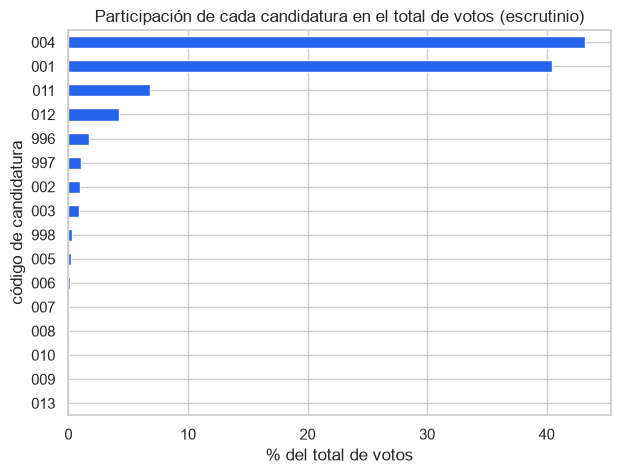

In [112]:
print(escru["votos"].describe().round(1))

part = escru.groupby("candidato")["votos"].sum().to_frame("votos")
part["porcentaje"] = (part["votos"] / part["votos"].sum() * 100).round(2)
display(part.sort_values("votos", ascending=False))

part["porcentaje"].sort_values().plot.barh(color="#2563EB", figsize=(7, 5))
plt.title("Participación de cada candidatura en el total de votos (escrutinio)")
plt.xlabel("% del total de votos")
plt.ylabel("código de candidatura")
plt.show()


La mediana de votos por candidatura y mesa es 0 y el percentil 75 es apenas 4, mientras que el máximo llega a 694. La distribución es muy asimétrica: la mayoría de los registros tiene muy pocos votos y unos pocos concentran la mayor parte.

**Por candidatura.** Como muestra el gráfico de barras horizontales, dos candidatos concentran el 83,7 % de los 23 990 635 votos: el 004 (43,21 %) y el 001 (40,45 %). Les siguen el 011 (6,84 %) y el 012 (4,21 %). Los demás candidatos tienen menos del 1 % cada uno, y el 009 y el 013 tienen 0 % por su retiro. El voto en blanco representa el 1,70 %, el nulo el 1,02 % y el no marcado el 0,29 %.

Este desbalance tiene una consecuencia para el modelado: las candidaturas minoritarias aparecen con cero votos en la mayoría de las mesas, por lo que tomadas una por una aportan poca información.

,mesas,votos,% 001,% 004,% blanco
dep_nombre,,,,,
BOGOTA D.C.,17164,4128330,41.3,37.4,1.7
ANTIOQUIA,15801,3210392,25.1,53.7,1.9
VALLE,11087,2137681,52.6,33.3,1.9
CUNDINAMARCA,6916,1624893,36.9,44.6,1.8
ATLANTICO,6190,1063339,52.0,40.7,1.2
SANTANDER,5690,1211083,28.4,56.5,1.5
BOLIVAR,5355,827000,53.6,37.8,1.6
CORDOBA,4180,713796,55.3,37.7,1.3
NORTE DE SAN,4079,741828,17.3,70.0,1.2


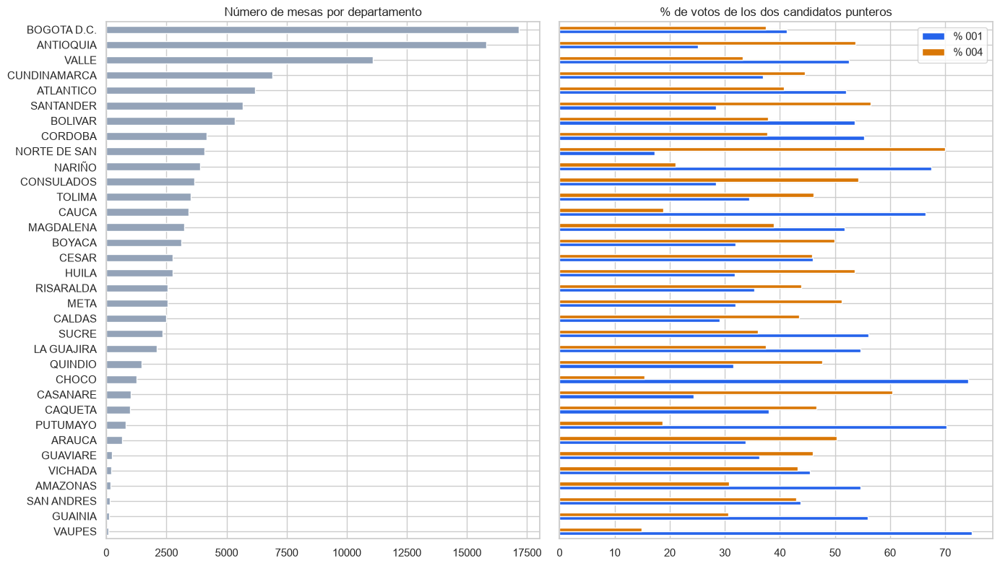

In [113]:
nombres = divipol[["dep", "dep_nombre"]].drop_duplicates()
esc_dep = escru.merge(nombres, on="dep")

votos_dep = esc_dep.pivot_table(index="dep_nombre", columns="candidato", values="votos", aggfunc="sum")
tabla_dep = pd.DataFrame({
    "mesas": (esc_dep.groupby("dep_nombre").size() / 16).astype(int),
    "votos": votos_dep.sum(axis=1),
})
tabla_dep["% 001"] = (votos_dep["001"] / tabla_dep["votos"] * 100).round(1)
tabla_dep["% 004"] = (votos_dep["004"] / tabla_dep["votos"] * 100).round(1)
tabla_dep["% blanco"] = (votos_dep["996"] / tabla_dep["votos"] * 100).round(1)
tabla_dep = tabla_dep.sort_values("mesas")
display(tabla_dep.sort_values("mesas", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
tabla_dep["mesas"].plot.barh(ax=ax[0], color="#94A3B8")
ax[0].set_title("Número de mesas por departamento")
ax[0].set_ylabel("")
tabla_dep[["% 001", "% 004"]].plot.barh(ax=ax[1], color=["#2563EB", "#D97706"])
ax[1].set_title("% de votos de los dos candidatos punteros")
plt.tight_layout()
plt.show()

**Por departamento.** El análisis por departamento muestra dos desbalances que el total nacional no revela.

*Número de mesas y porcentaje de votos de los dos candidatos punteros por departamento, según el escrutinio (elaboración propia).*

- **Tamaño de los departamentos.** El número de mesas varía mucho: Bogotá tiene 17 164 y Vaupés solo 88, unas 195 veces menos. Bogotá, Antioquia y Valle concentran juntos el 36 % de las mesas del país. Como la validación de los modelos se hará agrupando por departamento, los grupos tendrán tamaños muy desiguales, y esto deberá tenerse en cuenta al interpretar los resultados de cada partición.
- **Composición del voto.** Aunque a nivel nacional los dos punteros están cerca (40,45 % y 43,21 %), por departamento la diferencia es grande: el candidato 001 obtiene desde el 17,3 % (Norte de Santander) hasta el 74,9 % (Vaupés), y supera al 004 en 18 de los 34 departamentos. El voto en blanco también varía, entre el 0,8 % (consulados) y el 3,7 % (San Andrés).



**¿El conjunto de datos cuenta con otras variables adicionales? De ser así, analice cuáles se incorporarán en el modelo y haga un análisis descriptivo de las mismas.**

Mesas analizadas: 118313


,count,mean,std,min,25%,50%,75%,max
total_votos,118313.0,197.775,67.988,3.0,157.000,206.000,247.000,546.000
tasa_blanco,118313.0,0.018,0.016,0.0,0.008,0.015,0.026,0.429
tasa_nulo,118313.0,0.011,0.012,0.0,0.000,0.008,0.015,0.333
tasa_no_marcado,118313.0,0.003,0.006,0.0,0.000,0.000,0.005,0.200
cuota_001,118313.0,0.428,0.204,0.0,0.263,0.419,0.580,1.000
cuota_004,118313.0,0.415,0.180,0.0,0.283,0.410,0.545,1.000
candidatos_con_voto,118313.0,5.825,1.395,1.0,5.000,6.000,7.000,11.000



Asimetría:
total_votos           -0.55
tasa_blanco            2.66
tasa_nulo              3.28
tasa_no_marcado        4.73
cuota_001              0.25
cuota_004              0.07
candidatos_con_voto   -0.05
dtype: float64

% de mesas con tasa igual a 0:
tasa_blanco        11.0
tasa_nulo          27.3
tasa_no_marcado    64.7
dtype: float64


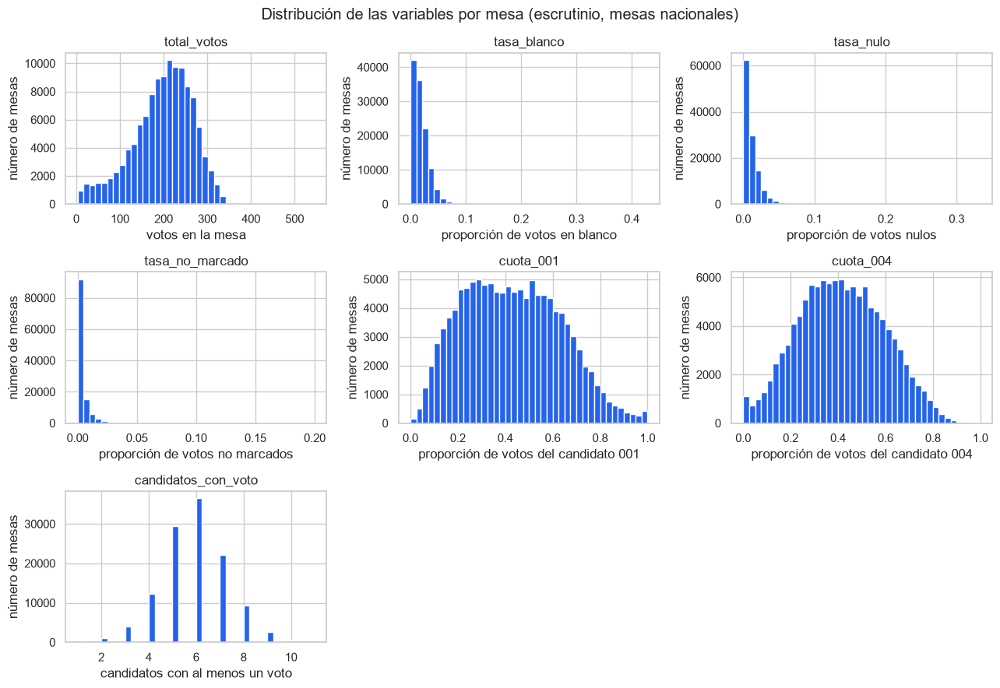

In [114]:
# Una fila por mesa y una columna por candidatura (solo mesas nacionales con votos)
esc_w = escru.pivot_table(index=LLAVE_MESA, columns="candidato", values="votos", aggfunc="sum")
esc_w = esc_w[esc_w.index.get_level_values("dep") != "88"]
esc_w = esc_w[esc_w.sum(axis=1) > 0]
ACTIVOS = ["001", "002", "003", "004", "005", "006", "007", "008", "010", "011", "012"]

# Variables por mesa
esc_vars = pd.DataFrame(index=esc_w.index)
esc_vars["total_votos"] = esc_w.sum(axis=1)
esc_vars["tasa_blanco"] = esc_w["996"] / esc_vars["total_votos"]
esc_vars["tasa_nulo"] = esc_w["997"] / esc_vars["total_votos"]
esc_vars["tasa_no_marcado"] = esc_w["998"] / esc_vars["total_votos"]
esc_vars["cuota_001"] = esc_w["001"] / esc_vars["total_votos"]
esc_vars["cuota_004"] = esc_w["004"] / esc_vars["total_votos"]
esc_vars["candidatos_con_voto"] = (esc_w[ACTIVOS] > 0).sum(axis=1)

# Análisis descriptivo
print("Mesas analizadas:", len(esc_vars))
display(esc_vars.describe().T.round(3))
print("\nAsimetría:")
print(esc_vars.skew().round(2))
print("\n% de mesas con tasa igual a 0:")
print((esc_vars[["tasa_blanco", "tasa_nulo", "tasa_no_marcado"]] == 0).mean().mul(100).round(1))

# Histogramas con nombres en los ejes
ETIQUETAS_X = {
    "total_votos": "votos en la mesa",
    "tasa_blanco": "proporción de votos en blanco",
    "tasa_nulo": "proporción de votos nulos",
    "tasa_no_marcado": "proporción de votos no marcados",
    "cuota_001": "proporción de votos del candidato 001",
    "cuota_004": "proporción de votos del candidato 004",
    "candidatos_con_voto": "candidatos con al menos un voto",
}

ejes = esc_vars.hist(bins=40, figsize=(13, 9), color="#2563EB")
for ax in ejes.flatten():
    if ax.get_title() in ETIQUETAS_X:
        ax.set_xlabel(ETIQUETAS_X[ax.get_title()])
        ax.set_ylabel("número de mesas")
plt.suptitle("Distribución de las variables por mesa (escrutinio, mesas nacionales)")
plt.tight_layout()
plt.show()

Además de `votos`, el escrutinio tiene tres grupos de variables:

| Variable | Tipo | ¿Se incorpora al modelo? |
|---|---|---|
| `dep`, `mun`, `zona`, `puesto`, `mesa` | Categóricas nominales y jerárquicas | No como entradas directas. Forman la llave de la mesa, y el departamento se usará para agrupar la validación cruzada. |
| `candidato` | Categórica nominal (16 valores) | Indirectamente: sus votos se resumen en las variables por mesa. |
| `partido` | Categórica nominal (14 valores) | No: cada candidato tiene un solo partido, así que repite la información de `candidato`. |
| `comunicado`, `comuna`, `corporacion`, `circ` | Constantes | No: no varían. |


Los histogramas muestran la forma de la distribución de cada variable, lo que orienta su preparación en la Fase 3: las variables muy asimétricas pueden requerir una transformación, y las que casi no varían aportan poca información al modelo.

- **`total_votos`:** votos de la mesa. Tiene forma de campana, con mediana de 206 votos y rango de 3 a 546. Su asimetría es negativa (−0,55): la cola se extiende hacia la izquierda, por las mesas con pocos votantes identificadas como atípicas bajas en la sección de calidad.
- **`tasa_blanco`, `tasa_nulo` y `tasa_no_marcado`:** proporción de votos en blanco, nulos y no marcados sobre el total de la mesa. Son valores pequeños (medianas de 1,5 %, 0,8 % y 0 %) y muy asimétricos hacia la derecha (asimetrías de 2,66, 3,28 y 4,73). Los histogramas muestran casi todas las mesas pegadas al cero: el 11,0 %, el 27,3 % y el 64,7 % de las mesas, respectivamente, no tienen ningún voto de ese tipo. Unas pocas mesas alcanzan valores altos, con máximos de 42,9 %, 33,3 % y 20 %.
- **`cuota_001` y `cuota_004`:** proporción de votos de los dos candidatos punteros. Tienen distribuciones amplias y casi simétricas (asimetrías de 0,25 y 0,07), con medias de 42,8 % y 41,5 %. Van de 0 a 1: hay mesas donde uno de los dos no obtuvo votos y mesas donde obtuvo todos. Esta amplitud confirma lo observado por departamento: la votación entre ambos varía mucho de una mesa a otra.
- **`candidatos_con_voto`:** cuántos de los 11 candidatos activos recibieron al menos un voto en la mesa. Es una variable discreta, con mediana de 6 y rango de 1 a 11; la mayoría de las mesas tiene entre 5 y 7.

Se usan tasas y cuotas en lugar de conteos para que mesas de distinto tamaño sean comparables: 5 votos nulos significan algo muy distinto en una mesa de 20 votos que en una de 300. Los conteos no se incluyen como variables adicionales porque pueden reconstruirse multiplicando cada tasa por `total_votos`, que sí se incorpora; incluir ambos daría al modelo información repetida. Esta redundancia se verifica en la sección de relación entre variables.

Las variables que se incorporarán al modelo son estas siete. Las tasas, por su fuerte asimetría, podrían requerir una transformación (por ejemplo, logarítmica) en la Fase 3.



### **1.4. Relación Entre Variables**
---

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

#### Escrutinio

**Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.**

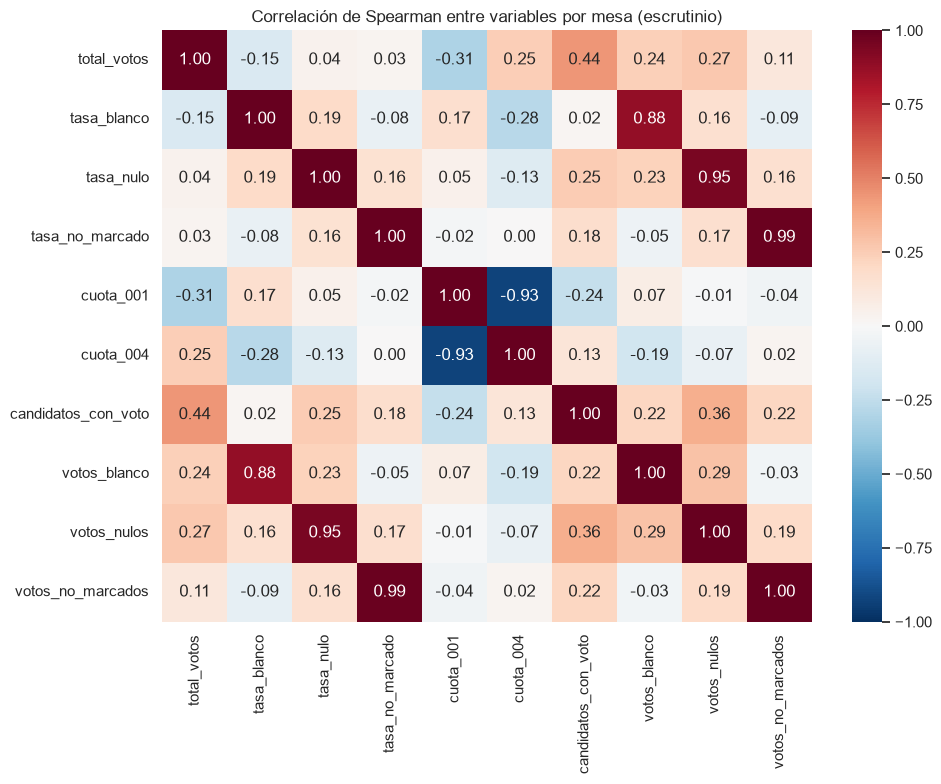

In [115]:


# Variables de la 1.3 más los conteos, para comparar tasas contra conteos
esc_corr = esc_vars.copy()
esc_corr["votos_blanco"] = esc_w["996"]
esc_corr["votos_nulos"] = esc_w["997"]
esc_corr["votos_no_marcados"] = esc_w["998"]

corr = esc_corr.corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlación de Spearman entre variables por mesa (escrutinio)")
plt.tight_layout()
plt.show()

Para medir la relación entre las variables se usó el coeficiente de correlación de Spearman, que va de −1 a 1 y no supone relaciones lineales. Se prefirió sobre el de Pearson porque varias variables, como las tasas, son muy asimétricas, y Spearman es menos sensible a los valores extremos. Además de las siete variables por mesa, se incluyeron los conteos de votos en blanco, nulos y no marcados, para comparar tasas contra conteos.


La Figura de correlación muestra que la mayoría de las variables se relacionan poco entre sí: casi todos los coeficientes están entre −0,3 y 0,3. Esto es favorable para el modelo, porque cada variable aporta información distinta. Las relaciones más relevantes son:

- **Relaciones fuertes (|ρ| ≥ 0,85):**
  - Cada tasa con su conteo: votos no marcados (ρ = 0,99), nulos (ρ = 0,95) y en blanco (ρ = 0,88). Es esperable, porque la tasa es el conteo dividido por el total de la mesa.
  - Las cuotas de los dos candidatos punteros, con una relación negativa muy fuerte (ρ = −0,93): en las mesas donde uno obtiene más votos, el otro obtiene menos.
- **Relaciones moderadas:**
  - `total_votos` con `candidatos_con_voto` (ρ = 0,44): en las mesas con más votantes, más candidatos alcanzan a recibir al menos un voto.
  - `total_votos` con `cuota_001` (ρ = −0,31) y con `cuota_004` (ρ = 0,25): el tamaño de la mesa se asocia levemente con cómo se reparte el voto entre los punteros.

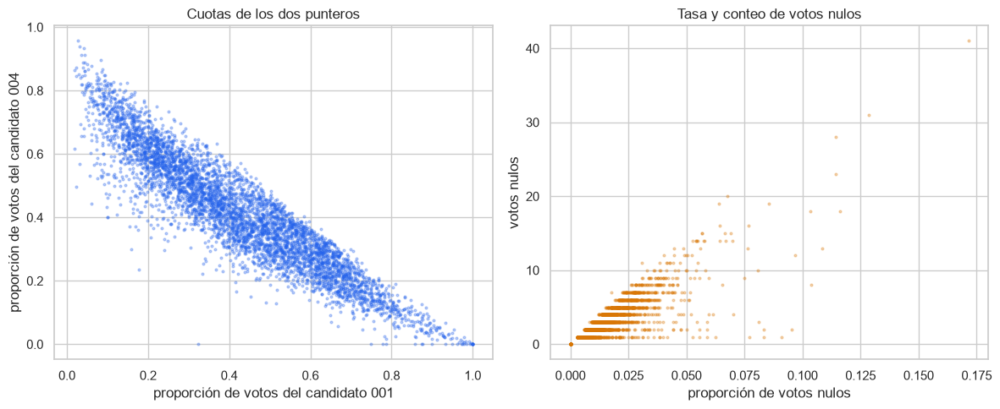

In [116]:
muestra = esc_corr.sample(5000, random_state=42)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(muestra["cuota_001"], muestra["cuota_004"], s=4, alpha=0.3, color="#2563EB")
ax[0].set_xlabel("proporción de votos del candidato 001")
ax[0].set_ylabel("proporción de votos del candidato 004")
ax[0].set_title("Cuotas de los dos punteros")
ax[1].scatter(muestra["tasa_nulo"], muestra["votos_nulos"], s=4, alpha=0.3, color="#D97706")
ax[1].set_xlabel("proporción de votos nulos")
ax[1].set_ylabel("votos nulos")
ax[1].set_title("Tasa y conteo de votos nulos")
plt.tight_layout()
plt.show()

*Diagramas de dispersión de las dos relaciones más fuertes, en una muestra aleatoria de 5 000 mesas.*

La Figura hace visibles estas relaciones. A la izquierda, los puntos forman una franja descendente: cuando la cuota del candidato 001 sube, la del 004 baja casi en la misma medida. Los puntos no forman una línea perfecta porque una parte de los votos se reparte entre los demás candidatos y los votos en blanco y nulos. A la derecha, la tasa y el conteo de votos nulos crecen juntos: cada franja horizontal corresponde a un número fijo de votos nulos (1, 2, 3…) en mesas de distinto tamaño.

**Identifique si hay redundancia entre las variables para una posterior eliminación o selección.**

In [117]:
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().reset_index()
pares.columns = ["variable_1", "variable_2", "rho"]
pares = pares[pares["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False)
display(pares.round(3))

,variable_1,variable_2,rho
39,tasa_no_marcado,votos_no_marcados,0.988
28,tasa_nulo,votos_nulos,0.948
45,cuota_001,cuota_004,-0.928
17,tasa_blanco,votos_blanco,0.875


Se consideran redundantes los pares de variables con una correlación de Spearman mayor que 0,8 en valor absoluto, porque en ese caso una variable repite casi toda la información de la otra. Se identificaron cuatro pares:

| Par redundante | ρ | Decisión |
|---|---|---|
| `tasa_no_marcado` – `votos_no_marcados` | 0,99 | Conservar la tasa |
| `tasa_nulo` – `votos_nulos` | 0,95 | Conservar la tasa |
| `cuota_001` – `cuota_004` | −0,93 | Conservar una sola cuota |
| `tasa_blanco` – `votos_blanco` | 0,88 | Conservar la tasa |

**Tasas frente a conteos.** Los tres conteos son redundantes con sus tasas, lo que confirma la decisión de la sección anterior de no incluirlos: además, pueden reconstruirse multiplicando la tasa por `total_votos`. Se conservan las tasas porque permiten comparar mesas de distinto tamaño.

**Cuotas de los punteros.** Las cuotas de los candidatos 001 y 004 se mueven casi como espejo, así que una de las dos basta para describir cómo se reparte el voto entre ambos. Se propone conservar solo una, o reemplazar ambas por su diferencia, que resume el margen entre los dos candidatos en una sola variable. La elección se hará en la Fase 3.

Con estas decisiones, el conjunto final de variables por mesa del escrutinio queda en seis variables no redundantes: `total_votos`, `tasa_blanco`, `tasa_nulo`, `tasa_no_marcado`, una cuota de los punteros (o su diferencia) y `candidatos_con_voto`.

Esta selección es útil sobre todo para modelos como la regresión logística, que se vuelven inestables cuando reciben variables casi idénticas. Los modelos basados en árboles, como Random Forest, toleran mejor la redundancia, pero eliminarla igualmente simplifica la interpretación de los resultados.

## Novedades
---

Normalmente en el análisis exploratorio, se trata de dar respuesta a los siguientes elementos:

In [118]:
with open(ARCH_NOVEDADES, encoding="utf-8") as f:
    for _ in range(3):
        print(repr(f.readline()))

'id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,corporacionNombre,potencial,sufragantesSegunE11,enTerminos,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos\n'
'010100101011,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,1,001,PRESIDENTE,360,128,SI,BUENO,NO,NO,NO,NO,6,128,0,128,127\n'
'010100101012,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,2,001,PRESIDENTE,360,65,SI,BUENO,NO,NO,NO,NO,6,65,0,65,65\n'


### **1.1. Resumen General**
---

- ¿Cuántos documentos tiene el *dataset*?
- ¿En qué formato están almacenados los datos?
- ¿Qué tamaño en MB tiene el conjunto de datos?

In [119]:
noved.head()

,id,dep,departamentoNombre,mun,municipioNombre,zona,puesto,puestoNombre,mesa,corporacionCodigo,...,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos
0,010100101011,01,ANTIOQUIA,001,MEDELLIN,001,01,SEC. ESC. LA ESPERANZA No 2,000001,001,...,BUENO,NO,NO,NO,NO,6,128,0,128,127
1,010100101012,01,ANTIOQUIA,001,MEDELLIN,001,01,SEC. ESC. LA ESPERANZA No 2,000002,001,...,BUENO,NO,NO,NO,NO,6,65,0,65,65
2,010100101013,01,ANTIOQUIA,001,MEDELLIN,001,01,SEC. ESC. LA ESPERANZA No 2,000003,001,...,BUENO,NO,NO,NO,NO,6,107,0,107,107
3,010100101014,01,ANTIOQUIA,001,MEDELLIN,001,01,SEC. ESC. LA ESPERANZA No 2,000004,001,...,BUENO,NO,NO,NO,NO,6,143,0,143,143
4,010100101015,01,ANTIOQUIA,001,MEDELLIN,001,01,SEC. ESC. LA ESPERANZA No 2,000005,001,...,BUENO,NO,NO,NO,NO,6,177,0,177,177


**¿Cuántos documentos tiene el *dataset*?**

In [120]:
print("Registros:", len(noved), "| columnas:", noved.shape[1])
print("Mesas repetidas:", noved.duplicated(LLAVE_MESA).sum())
print("Departamentos:", noved["dep"].nunique())
print("Corporaciones:", noved["corporacionNombre"].unique())

# ¿Qué mesas del escrutinio tienen registro de novedades?
mesas_esc = escru[LLAVE_MESA].drop_duplicates()
cobertura = mesas_esc.merge(noved[LLAVE_MESA], on=LLAVE_MESA, how="left", indicator=True)
print("\nCobertura frente a las 122 020 mesas del escrutinio:")
print(cobertura["_merge"].map({"both": "con novedades", "left_only": "sin novedades"}).value_counts())
print("Departamentos de las mesas sin novedades:", cobertura.loc[cobertura["_merge"] == "left_only", "dep"].unique())

Registros: 118350 | columnas: 24
Mesas repetidas: 0
Departamentos: 33
Corporaciones: <StringArray>
['PRESIDENTE']
Length: 1, dtype: str

Cobertura frente a las 122 020 mesas del escrutinio:
_merge
con novedades    118350
sin novedades      3670
Name: count, dtype: int64
Departamentos de las mesas sin novedades: <StringArray>
['88']
Length: 1, dtype: str


El archivo de novedades contiene **118 350 registros** y 24 columnas. A diferencia del preconteo y del escrutinio, aquí cada registro corresponde a **una mesa completa**, no a una candidatura, y no hay mesas repetidas. El archivo no registra votos por candidato, sino cómo se desarrolló el proceso en cada mesa: por ejemplo, cuántos votantes firmaron el formulario E-11, cuántos votos había en la urna, cuántos jurados firmaron el acta y si la mesa fue recontada o excluida.

Al cruzarlo con las 122 020 mesas del escrutinio, las 118 350 mesas de novedades coinciden una a una con mesas del escrutinio. Las 3 670 mesas restantes son todas de consulados (departamento 88): el archivo cubre únicamente las **mesas nacionales** de los 33 departamentos, incluido Bogotá. Además, solo contiene la corporación PRESIDENTE.

In [121]:
# ¿Coinciden los votos en la urna con los votantes del E-11?
coinciden = noved["votosUrna"] == noved["sufragantesSegunE11"]
print("\nMesas donde votos en la urna = votantes del E-11:", coinciden.sum(),
      f"({coinciden.mean() * 100:.1f} %)")
print("Mesas con más votos en la urna que votantes:", (noved["votosUrna"] > noved["sufragantesSegunE11"]).sum())
print("Mesas con menos votos en la urna que votantes:", (noved["votosUrna"] < noved["sufragantesSegunE11"]).sum())


Mesas donde votos en la urna = votantes del E-11: 112628 (95.2 %)
Mesas con más votos en la urna que votantes: 1642
Mesas con menos votos en la urna que votantes: 4080


lo anterior muestra que la gran mayoría de las mesas está sobre una curva principal, donde los votos en la urna son iguales a los votantes del E-11: así ocurre en 112 628 mesas (95,2 %). En las demás, 1 642 tienen más votos en la urna que votantes y 4 080 tienen menos. Fuera de esa curva aparecen tres patrones de error de registro:

Para identificar datos de baja calidad se aplicaron reglas de validación que un dato correcto siempre debe cumplir: **completitud** (no hay valores nulos ni vacíos), **rango** (los conteos no son negativos ni superan el máximo de votantes de la mesa), **coherencia entre campos** (no hay más votos que votantes, y los votos en la urna coinciden con los votantes del E-11),

**¿En qué formato están almacenados los datos?**

In [122]:
noved.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 118350 entries, 0 to 118349
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   id                      118350 non-null  str  
 1   dep                     118350 non-null  str  
 2   departamentoNombre      118350 non-null  str  
 3   mun                     118350 non-null  str  
 4   municipioNombre         118350 non-null  str  
 5   zona                    118350 non-null  str  
 6   puesto                  118350 non-null  str  
 7   puestoNombre            118350 non-null  str  
 8   mesa                    118350 non-null  str  
 9   corporacionCodigo       118350 non-null  str  
 10  corporacionNombre       118350 non-null  str  
 11  potencial               118350 non-null  int64
 12  sufragantesSegunE11     118350 non-null  int64
 13  enTerminos              118350 non-null  str  
 14  estadoSobre             118350 non-null  str  
 15  tachadurasE

In [123]:
nov_diccionario = pd.DataFrame([
    ("id",                     "Texto",                  "Identificador de la mesa"),
    ("dep",                    "Código",                 "Código del departamento (columna original: departamentoCodigo)"),
    ("departamentoNombre",     "Texto",                  "Nombre del departamento"),
    ("mun",                    "Código",                 "Código del municipio (columna original: municipioCodigo)"),
    ("municipioNombre",        "Texto",                  "Nombre del municipio"),
    ("zona",                   "Código",                 "Código de la zona (columna original: zonaNombre)"),
    ("puesto",                 "Código",                 "Código del puesto (columna original: puestoCodigo)"),
    ("puestoNombre",           "Texto",                  "Nombre del puesto de votación"),
    ("mesa",                   "Código",                 "Número de la mesa (columna original: mesaNumero)"),
    ("corporacionCodigo",      "Código",                 "Cargo que se elige; 001 = Presidente"),
    ("corporacionNombre",      "Texto",                  "Nombre del cargo"),
    ("potencial",              "Numérico",               "Máximo de votantes permitido en la mesa"),
    ("sufragantesSegunE11",    "Numérico",               "Votantes registrados en el formulario E-11"),
    ("enTerminos",             "Categórico (SI/NO)",     "Si los documentos de la mesa se entregaron dentro de los plazos"),
    ("estadoSobre",            "Categórico (BUENO/MAL)", "Estado del sobre con los documentos de la mesa"),
    ("tachadurasEnmendaduras", "Categórico (SI/NO)",     "Si el acta presenta tachaduras o enmendaduras"),
    ("recontadaJurados",       "Categórico (SI/NO)",     "Si los jurados recontaron los votos de la mesa"),
    ("recontadaComision",      "Categórico (SI/NO)",     "Si la comisión escrutadora recontó los votos"),
    ("excluida",               "Categórico (SI/NO)",     "Si la mesa fue excluida del cómputo"),
    ("firmasJurados",          "Numérico",               "Número de firmas de jurados en el acta (0 a 6)"),
    ("votosUrna",              "Numérico",               "Votos encontrados en la urna"),
    ("votosIncinerados",       "Numérico",               "Votos sobrantes destruidos"),
    ("sufragantesE11SegunE14", "Numérico",               "Votantes del E-11 según lo registrado en el acta E-14"),
    ("totalVotos",             "Numérico",               "Total de votos de la mesa"),
], columns=["columna", "tipo", "descripcion"])

nov_diccionario["tipo_pandas"]    = nov_diccionario["columna"].map(noved.dtypes.astype(str))
nov_diccionario["valores_unicos"] = nov_diccionario["columna"].map(noved.nunique())
nov_diccionario["ejemplo"]        = nov_diccionario["columna"].map(noved.iloc[0])
nov_diccionario = nov_diccionario[["columna", "tipo", "tipo_pandas", "valores_unicos", "ejemplo", "descripcion"]]
display(nov_diccionario)

,columna,tipo,tipo_pandas,valores_unicos,ejemplo,descripcion
0,id,Texto,str,118350,010100101011,Identificador de la mesa
1,dep,Código,str,33,01,Código del departamento (columna original: departamentoCodigo)
2,departamentoNombre,Texto,str,33,ANTIOQUIA,Nombre del departamento
3,mun,Código,str,263,001,Código del municipio (columna original: municipioCodigo)
4,municipioNombre,Texto,str,1036,MEDELLIN,Nombre del municipio
5,zona,Código,str,42,001,Código de la zona (columna original: zonaNombre)
6,puesto,Código,str,208,01,Código del puesto (columna original: puestoCodigo)
7,puestoNombre,Texto,str,10485,SEC. ESC. LA ESPERANZA No 2,Nombre del puesto de votación
8,mesa,Código,str,228,000001,Número de la mesa (columna original: mesaNumero)
9,corporacionCodigo,Código,str,1,001,Cargo que se elige; 001 = Presidente


In [124]:
nov_resumen = pd.Series(dtype=object, data={
    "Registros (mesas)": len(noved),
    "Columnas": noved.shape[1],
    "Mesas repetidas": noved.duplicated(LLAVE_MESA).sum(),
    "Departamentos": noved["dep"].nunique(),
    "Mesas de consulados (dep 88)": (noved["dep"] == "88").sum(),
    "Corporaciones": noved["corporacionNombre"].unique().tolist(),
    "Tamaño en disco (MB)": round(os.path.getsize(ARCH_NOVEDADES) / 1024**2, 2),
    "Tamaño en memoria (MB)": round(noved.memory_usage(deep=True).sum() / 1024**2, 1),
})
display(nov_resumen.to_frame("valor"))

,valor
Registros (mesas),118350
Columnas,24
Mesas repetidas,0
Departamentos,33
Mesas de consulados (dep 88),0
Corporaciones,[PRESIDENTE]
Tamaño en disco (MB),14.9
Tamaño en memoria (MB),111.5


In [125]:
# Primeras líneas tal como vienen en el archivo
with open(ARCH_NOVEDADES, encoding="utf-8") as f:
    for _ in range(3):
        print(repr(f.readline()))

# Líneas con comas dentro del nombre del puesto
with open(ARCH_NOVEDADES, encoding="utf-8") as f:
    encabezado = f.readline().rstrip("\r\n").split(",")
    lineas_con_comas = sum(len(l.rstrip("\r\n").split(",")) > len(encabezado) for l in f)
print("\nColumnas en el encabezado:", len(encabezado))
print("Líneas con comas dentro del nombre del puesto:", lineas_con_comas)
print("Ejemplo reparado:", noved.loc[noved["puestoNombre"].str.contains(",", regex=False), "puestoNombre"].iloc[0])

# Efecto de la codificación sobre los nombres
ejemplo = noved.loc[noved["puestoNombre"].str.contains("Ñ"), "puestoNombre"].iloc[0]
print("\nLeído en UTF-8:  ", ejemplo)
print("Leído en latin-1:", ejemplo.encode("utf-8").decode("latin-1"))

'id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,corporacionNombre,potencial,sufragantesSegunE11,enTerminos,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos\n'
'010100101011,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,1,001,PRESIDENTE,360,128,SI,BUENO,NO,NO,NO,NO,6,128,0,128,127\n'
'010100101012,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,2,001,PRESIDENTE,360,65,SI,BUENO,NO,NO,NO,NO,6,65,0,65,65\n'

Columnas en el encabezado: 24
Líneas con comas dentro del nombre del puesto: 45
Ejemplo reparado: I.E.D.LA PAZ, MEGA COL. LA PAZ

Leído en UTF-8:   I.E. MONSEÑOR FRANCISCO CRISTOBAL TORO
Leído en latin-1: I.E. MONSEÃOR FRANCISCO CRISTOBAL TORO


Es un archivo de valores separados por comas (`.csv`), **con encabezado** y codificado en **UTF-8**, distribuido dentro del comprimido `Novedad20260603.zip` junto con su huella SHA-256. Se diferencia de las otras fuentes en cuatro aspectos:

- **No está descrito en el documento *Estructuras Básicas*.** Por eso la tabla anterior no tiene tipos ni longitudes oficiales: el diccionario de columnas se construyó a partir del nombre de cada campo y de sus valores, y debe tomarse como una interpretación del grupo.
- **Incluye nombres, no solo códigos.** Trae el nombre del departamento, del municipio y del puesto, que contienen tildes y eñes. Por eso la codificación sí importa en este archivo: como muestra la salida anterior, al leerlo en latin-1 (como se hacía en la Fase 1) la Ñ de "MONSEÑOR" se convierte en caracteres extraños. En esta fase la lectura se corrigió a UTF-8.
- **Algunos nombres de puesto contienen comas.** En 45 líneas, el nombre del puesto incluye comas sin comillas (por ejemplo, "I.E.D.LA PAZ, MEGA COL. LA PAZ"), que se confunden con el separador de columnas. La carga las repara uniendo esos fragmentos, sin descartar ninguna mesa.
- **Las llaves tienen otro formato.** En el archivo original la zona tiene 2 dígitos y la mesa no tiene ceros a la izquierda (`1` en lugar de `000001`). Durante la carga se renombraron las columnas de llave (por ejemplo, `departamentoCodigo` → `dep`) y se completaron con ceros, para que coincidan con las del escrutinio.

Las 24 columnas se agrupan en cuatro tipos: **identificación de la mesa** (códigos y nombres de departamento, municipio, zona, puesto y mesa), **corporación** (constante), **seis variables categóricas** que registran novedades del proceso, con valores SI/NO o BUENO/MAL, y **siete variables numéricas** con conteos de votantes, votos y firmas. Las llaves y las categorías se conservan como texto (`object`) y los conteos como enteros (`int64`).

**¿Qué tamaño en MB tiene el conjunto de datos?**

In [126]:
print("En disco (CSV):  ", round(os.path.getsize(ARCH_NOVEDADES) / 1024**2, 2), "MB")
print("Comprimido (ZIP):", round(os.path.getsize(buscar_archivo("Novedad20260603.zip")) / 1024**2, 2), "MB")
print("En memoria:      ", round(noved.memory_usage(deep=True).sum() / 1024**2, 1), "MB")

En disco (CSV):   14.9 MB
Comprimido (ZIP): 2.02 MB
En memoria:       111.5 MB


El archivo ocupa **14,9 MB en disco** y apenas **2 MB comprimido**. Una vez cargado en *pandas* ocupa unos **111 MB en memoria**, porque las columnas de texto, en especial los nombres de puesto, almacenan cada valor como un objeto independiente. Es la fuente más liviana de las tres, porque tiene una sola fila por mesa y no una por candidatura.

### **1.2. Resumen de la Calidad de los datos**
---

- ¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad en el conjunto?
- ¿Se identifican documentos ilegibles o con dificultades de codificación durante la revisión del conjunto de datos?
- ¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?
- ¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?

**¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad?**

Valores nulos: 0
Celdas vacías: 0


,count,mean,std,min,25%,50%,75%,max
potencial,118350.0,364.7,52.1,360.0,360.0,360.0,360.0,1200.0
sufragantesSegunE11,118350.0,198.1,68.2,0.0,157.0,206.0,247.0,800.0
firmasJurados,118350.0,5.9,0.4,0.0,6.0,6.0,6.0,6.0
votosUrna,118350.0,199.3,92.0,0.0,157.0,206.0,247.0,8195.0
votosIncinerados,118350.0,0.1,3.3,0.0,0.0,0.0,0.0,360.0
sufragantesE11SegunE14,118350.0,198.3,69.6,0.0,157.0,206.0,247.0,3025.0
totalVotos,118350.0,197.7,68.1,0.0,157.0,206.0,247.0,546.0


Valores negativos: 0
votosUrna mayor que el máximo de la mesa: 112
E-14 mayor que el máximo de la mesa: 6
Más votos que votantes (totalVotos > E-11): 2
Mesas excluidas con totalVotos = 0: 37 de 37


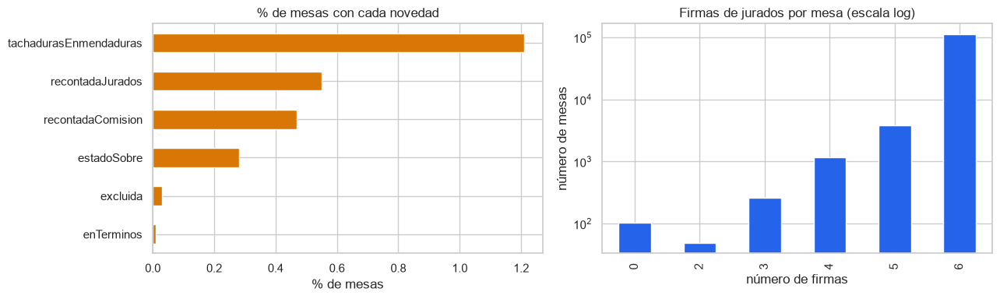

In [127]:
print("Valores nulos:", noved.isnull().sum().sum())
print("Celdas vacías:", (noved.select_dtypes(exclude="number") == "").sum().sum())

NUM = ["potencial", "sufragantesSegunE11", "firmasJurados", "votosUrna",
       "votosIncinerados", "sufragantesE11SegunE14", "totalVotos"]
display(noved[NUM].describe().T.round(1))

print("Valores negativos:", (noved[NUM] < 0).sum().sum())
print("votosUrna mayor que el máximo de la mesa:", (noved["votosUrna"] > noved["potencial"]).sum())
print("E-14 mayor que el máximo de la mesa:", (noved["sufragantesE11SegunE14"] > noved["potencial"]).sum())
print("Más votos que votantes (totalVotos > E-11):", (noved["totalVotos"] > noved["sufragantesSegunE11"]).sum())
print("Mesas excluidas con totalVotos = 0:",
      ((noved["excluida"] == "SI") & (noved["totalVotos"] == 0)).sum(), "de", (noved["excluida"] == "SI").sum())

NOVEDAD = {"enTerminos": "NO", "estadoSobre": "MAL", "tachadurasEnmendaduras": "SI",
           "recontadaJurados": "SI", "recontadaComision": "SI", "excluida": "SI"}
pct = pd.Series({c: (noved[c] == v).mean() * 100 for c, v in NOVEDAD.items()}).round(2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pct.sort_values().plot.barh(ax=ax[0], color="#D97706")
ax[0].set_title("% de mesas con cada novedad")
ax[0].set_xlabel("% de mesas")
noved["firmasJurados"].value_counts().sort_index().plot.bar(ax=ax[1], color="#2563EB")
ax[1].set_yscale("log")
ax[1].set_title("Firmas de jurados por mesa (escala log)")
ax[1].set_xlabel("número de firmas")
ax[1].set_ylabel("número de mesas")
plt.tight_layout()
plt.show()

**Datos ausentes y documentos vacíos.** No hay valores nulos ni celdas vacías: las 118 350 mesas tienen las 24 columnas diligenciadas. Las 37 mesas excluidas tienen `totalVotos` igual a cero, lo que coincide con las 37 mesas vacías encontradas en el escrutinio: la exclusión anuló su votación.

**Datos de baja calidad.** No hay valores negativos, pero sí valores imposibles:

- **112 mesas registran más votos en la urna que el máximo de votantes permitido en la mesa.** El caso extremo es una mesa con 8 195 votos en la urna, cuando su máximo es 360. En la pregunta 4 se muestra que la mayoría corresponde a errores de digitación.
- **6 mesas** registran en el acta E-14 más sufragantes que el máximo de la mesa, y **2 mesas** tienen más votos totales que votantes según el E-11.
- **El campo `potencial` no es el número de votantes inscritos en la mesa**, sino el **máximo permitido** según el tipo de puesto: solo toma cuatro valores (360, 500, 800 y 1 200), y el 98,9 % de las mesas tiene 360. Por eso no sirve para calcular la participación real de cada mesa.

La figura anterior muestra que las novedades son **poco frecuentes**: la más común son las tachaduras o enmendaduras en el acta (1,21 % de las mesas), seguida del reconteo por los jurados (0,55 %) y por la comisión escrutadora (0,47 %); las demás afectan a menos del 0,3 %. Esto anticipa que, si se usan como etiqueta, habrá un fuerte desbalance de clases.

En las firmas, 112 910 mesas (95,4 %) tienen las seis firmas de jurados, pero 5 440 tienen menos y **104 mesas no tienen ninguna**. Un acta sin firmas es una debilidad documental, aunque no necesariamente un error en los conteos.

**¿Se identifican documentos ilegibles o con dificultades de codificación?**

In [128]:
texto = noved.select_dtypes(exclude="number").columns
print("Valores con caracteres mal decodificados (Ã):",
      noved[texto].apply(lambda s: s.str.contains("Ã", regex=False).sum()).sum())
print("Nombres de puesto con tildes o eñes:", noved["puestoNombre"].str.contains(r"[ÁÉÍÓÚÑÜ]").sum())
print(noved.loc[noved["puestoNombre"].str.contains(r"[ÁÉÍÓÚÑÜ]"), "puestoNombre"].head(3).tolist())

Valores con caracteres mal decodificados (Ã): 0
Nombres de puesto con tildes o eñes: 4996
['I.E. MONSEÑOR FRANCISCO CRISTOBAL TORO', 'I.E. MONSEÑOR FRANCISCO CRISTOBAL TORO', 'I.E. MONSEÑOR FRANCISCO CRISTOBAL TORO']


El archivo no es ilegible, pero **sí presentó una dificultad de codificación**. Está codificado en UTF-8, mientras que las demás fuentes del paquete usan latin-1. En la Fase 1 se leía en latin-1, lo que dañaba los nombres con tildes y eñes (como se mostró en el resumen general, "MONSEÑOR" aparecía con caracteres extraños). Con la lectura corregida a UTF-8, ningún valor contiene caracteres mal decodificados, y los 4 996 nombres de puesto con tildes o eñes se leen correctamente.

La otra dificultad de lectura son las **45 líneas** cuyo nombre de puesto contiene comas sin comillas, que se confunden con el separador de columnas. Como se explicó en el resumen general, la carga las repara sin descartar ninguna mesa.

Este problema afecta solo a los nombres, no a los códigos ni a los conteos, por lo que no altera el cruce con las demás fuentes ni los análisis numéricos.

**¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?**

In [129]:
print("Longitud del id:", noved["id"].str.len().value_counts().sort_index().to_dict())
display(noved[["id", "dep", "mun", "zona", "puesto", "mesa"]].iloc[[0, 500]])

print("\nValores de las variables categóricas:")
for c in NOVEDAD:
    print(f"  {c}: {sorted(noved[c].unique())}")
print("Valores distintos de potencial:", sorted(noved["potencial"].unique()))

print("\nCombinaciones departamento–municipio:", noved[["dep", "mun"]].drop_duplicates().shape[0])
print("Nombres de municipio distintos:", noved["municipioNombre"].nunique())
rep = noved[["dep", "municipioNombre"]].drop_duplicates().groupby("municipioNombre").size()
print("Nombres repetidos en varios departamentos:", rep[rep > 1].sort_values(ascending=False).head(5).to_dict())

Longitud del id: {12: 64608, 13: 53613, 14: 129}


,id,dep,mun,zona,puesto,mesa
0,010100101011,01,001,001,01,000001
500,0101001040210,01,001,004,02,000010



Valores de las variables categóricas:
  enTerminos: ['NO', 'SI']
  estadoSobre: ['BUENO', 'MAL']
  tachadurasEnmendaduras: ['NO', 'SI']
  recontadaJurados: ['NO', 'SI']
  recontadaComision: ['NO', 'SI']
  excluida: ['NO', 'SI']
Valores distintos de potencial: [np.int64(360), np.int64(500), np.int64(800), np.int64(1200)]

Combinaciones departamento–municipio: 1122
Nombres de municipio distintos: 1036
Nombres repetidos en varios departamentos: {'BOLIVAR': 4, 'BUENAVISTA': 4, 'LA UNION': 4, 'VILLANUEVA': 4, 'EL CARMEN': 3}


Sí. Aunque todas las líneas tienen las mismas 24 columnas, dentro del archivo conviven formatos que dificultan su uso si no se conocen:

- **Identificador de longitud variable.** La columna `id` tiene 12, 13 o 14 caracteres, porque concatena los códigos de la mesa sin completar el número de mesa con ceros (la mesa 1 aporta un dígito y la mesa 10, dos). Por eso no se usa como llave: las fuentes se cruzan con los cinco códigos de la mesa, ya normalizados.
- **Nombres de columna engañosos.** La columna original `zonaNombre` no contiene nombres sino códigos de zona, y `mesaNumero` trae el número sin ceros a la izquierda (`1` en lugar de `000001`). Ambas se renombraron y normalizaron en la carga.
- **Dos vocabularios en las variables categóricas.** Cinco campos usan SI/NO y `estadoSobre` usa BUENO/MAL. Además, en `enTerminos` la novedad es la respuesta NO, mientras que en los demás es SI. Esto obliga a definir con cuidado qué valor indica una novedad antes de convertirlos a 0/1.
- **Nombres de municipio repetidos.** Hay 1 122 combinaciones de departamento y municipio, pero solo 1 036 nombres distintos, porque varios municipios comparten nombre en distintos departamentos (por ejemplo, hay cuatro llamados Bolívar y cuatro llamados Buenavista). Por eso las mesas deben identificarse por código y no por nombre.
- **Un campo cuyo nombre no refleja su contenido.** `potencial` sugiere el número de votantes inscritos, pero contiene el máximo permitido por mesa (cuatro valores posibles).

**¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?**

sufragantesSegunE11: límites [22, 382] | atípicas bajas: 1446 | altas: 58
votosUrna: límites [22, 382] | atípicas bajas: 1535 | altas: 167
sufragantesE11SegunE14: límites [22, 382] | atípicas bajas: 1497 | altas: 65
totalVotos: límites [22, 382] | atípicas bajas: 1482 | altas: 56


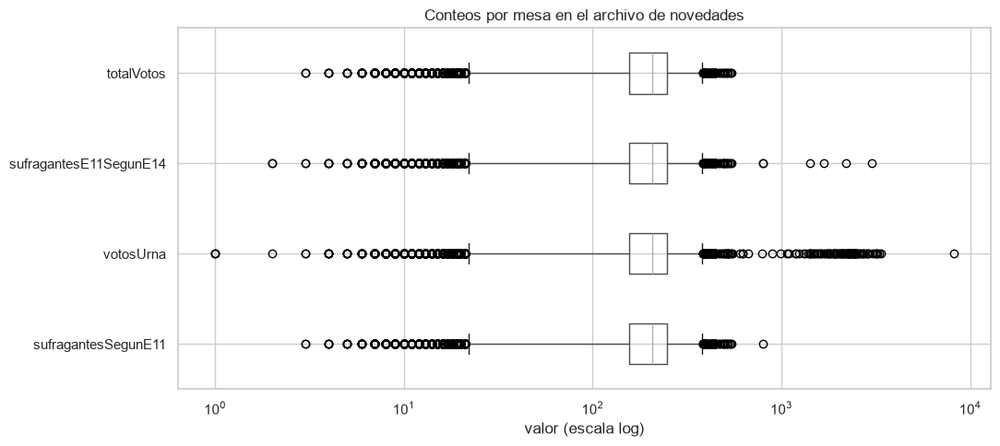

In [130]:
CONTEOS = ["sufragantesSegunE11", "votosUrna", "sufragantesE11SegunE14", "totalVotos"]

for c in CONTEOS:
    Q1 = noved[c].quantile(0.25)
    Q3 = noved[c].quantile(0.75)
    IQR = Q3 - Q1
    print(f"{c}: límites [{Q1 - 1.5 * IQR:.0f}, {Q3 + 1.5 * IQR:.0f}] | "
          f"atípicas bajas: {(noved[c] < Q1 - 1.5 * IQR).sum()} | altas: {(noved[c] > Q3 + 1.5 * IQR).sum()}")

fig, ax = plt.subplots(figsize=(11, 5))
noved[CONTEOS].boxplot(ax=ax, vert=False)
ax.set_xscale("log")
ax.set_xlabel("valor (escala log)")
ax.set_title("Conteos por mesa en el archivo de novedades")
plt.tight_layout()
plt.show()

Las gráficas usan escala logarítmica porque los valores van de unos pocos votos hasta más de 8 000: en escala lineal, las mesas normales quedarían comprimidas y no se distinguirían. Esta escala no puede representar el valor cero, por lo que las mesas sin votos (analizadas en la pregunta 1) no aparecen en estas figuras.

**Valores atípicos por variable.** Se aplicó el criterio del rango intercuartílico (IQR) a los cuatro conteos de la mesa. Los cuatro tienen los mismos límites (22 y 382) y cajas casi idénticas, lo que confirma que en la mayoría de las mesas registran el mismo número.

Diagramas de caja de los conteos por mesa del archivo de novedades, en escala logarítmica.


La diferencia está en los atípicos altos: `votosUrna` tiene 167, frente a 56 de `totalVotos`, y su cola llega hasta 8 195, un valor imposible. El conteo de votantes anotado en el E-14 (`sufragantesE11SegunE14`) también presenta valores imposibles en 6 mesas, con un máximo de 3 025 en una mesa cuyo máximo permitido es 360. En esas mesas, el total de votos sí coincide con los votantes del E-11, lo que indica un error de registro similar al de los votos en la urna, aunque mucho menos frecuente.

Los atípicos bajos, en cambio, aparecen en las cuatro variables a la vez y con valores coherentes entre sí: son mesas con pocos votantes, no errores. Es el mismo patrón observado en el escrutinio.

Sin embargo, el diagrama de caja analiza cada variable por separado, así que no detecta las mesas donde dos conteos que deberían coincidir son distintos pero ambos están dentro del rango normal (por ejemplo, 200 votantes y 195 votos en la urna). Por eso, a continuación se comparan directamente los votos en la urna con los votantes del E-11.

Mesas duplicadas: 0 | id duplicados: 0

votosUrna mayor que el máximo de la mesa: 112 | con un dígito de más al final: 77


,sufragantesSegunE11,votosUrna,totalVotos
397,251,2500,250
696,264,664,264
1209,226,2266,226
1272,173,1730,173
1407,230,2300,230



Mesas con E-11 igual al máximo de la mesa: 143 | mediana de votos en la urna en esas mesas: 221.0

totalVotos igual al total del escrutinio: 100.0 %


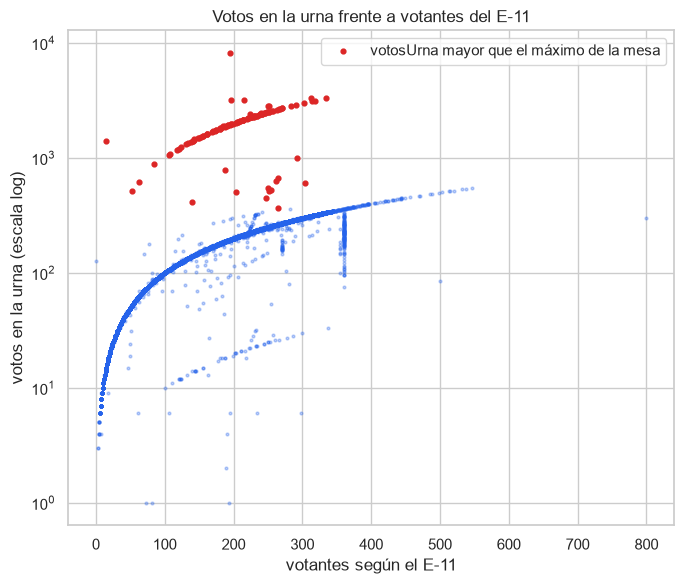

In [131]:
print("Mesas duplicadas:", noved.duplicated(LLAVE_MESA).sum(), "| id duplicados:", noved["id"].duplicated().sum())

# Votos en la urna imposibles
sospechosas = noved[noved["votosUrna"] > noved["potencial"]]
digito_final = (sospechosas["votosUrna"] // 10 == sospechosas["sufragantesSegunE11"]).sum()
print("\nvotosUrna mayor que el máximo de la mesa:", len(sospechosas),
      "| con un dígito de más al final:", digito_final)
display(sospechosas[["sufragantesSegunE11", "votosUrna", "totalVotos"]].head())

# E-11 igual al máximo de la mesa
e11_tope = noved[noved["sufragantesSegunE11"] == noved["potencial"]]
print("\nMesas con E-11 igual al máximo de la mesa:", len(e11_tope),
      "| mediana de votos en la urna en esas mesas:", e11_tope["votosUrna"].median())

# Coincidencia de totalVotos con el escrutinio
esc_total = escru.groupby(LLAVE_MESA)["votos"].sum().rename("total_escrutinio")
cruce = noved.join(esc_total, on=LLAVE_MESA)
print("\ntotalVotos igual al total del escrutinio:",
      round((cruce["totalVotos"] == cruce["total_escrutinio"]).mean() * 100, 1), "%")

plt.figure(figsize=(7, 6))
plt.scatter(noved["sufragantesSegunE11"], noved["votosUrna"], s=4, alpha=0.3, color="#2563EB")
plt.scatter(sospechosas["sufragantesSegunE11"], sospechosas["votosUrna"], s=12, color="#DC2626",
            label="votosUrna mayor que el máximo de la mesa")
plt.yscale("log")
plt.xlabel("votantes según el E-11")
plt.ylabel("votos en la urna (escala log)")
plt.title("Votos en la urna frente a votantes del E-11")
plt.legend()
plt.tight_layout()
plt.show()

**Duplicados y faltantes.** No hay mesas duplicadas ni identificadores repetidos, y no hay datos faltantes (pregunta 1).

**Valores atípicos.** Para analizarlos se comparan los votos en la urna con los votantes registrados en el formulario E-11, porque en una mesa normal ambos deben coincidir.

*Figura: votos en la urna frente a votantes del E-11 por mesa, con escala logarítmica en el eje vertical (elaboración propia).*

La figura anterior muestra que la gran mayoría de las mesas está sobre una curva principal, donde los votos en la urna son iguales a los votantes del E-11 (así ocurre en el 95,2 % de las mesas). Fuera de esa curva aparecen tres patrones de error de registro:

- **Un dígito de más (puntos rojos).** Las 112 mesas con más votos en la urna que el máximo permitido forman una curva paralela, unas diez veces por encima de la principal. En 77 de ellas el valor es exactamente el número de votantes con un dígito agregado al final (por ejemplo, 173 votantes y 1 730 votos en la urna), lo que indica un error de digitación y no votos reales. Así lo confirma `totalVotos`, que en esas mesas sí coincide con los votantes.
- **Un dígito de menos.** Una línea más débil, unas diez veces por debajo de la principal, sugiere el error contrario: votos en la urna registrados con un dígito faltante.
- **E-11 igual al máximo de la mesa.** La columna vertical en 360 corresponde a 143 mesas cuyo número de votantes del E-11 es exactamente el máximo permitido, aunque la mediana de votos en la urna en esas mesas es de solo 223. Esto sugiere que en esas mesas se registró el máximo de la mesa en lugar del número real de votantes.

Estos valores no se eliminan en esta fase. Se documentan para corregirlos o marcarlos en la preparación de los datos (Fase 3). Son importantes porque `sufragantesSegunE11` se usará para comparar con el preconteo, y un error en este campo podría confundirse con una discrepancia real.

**Fuga de información.** La columna `totalVotos` coincide con el total del escrutinio en el 100 % de las mesas: es el resultado final, no una novedad del proceso. Por eso no podrá usarse como variable de entrada en un modelo que prediga discrepancias entre preconteo y escrutinio, porque le daría al modelo la respuesta.

**Conclusión sobre la calidad del archivo de novedades.** El archivo está completo (sin valores faltantes ni mesas duplicadas), pero exige cuidados antes de usarlo en el modelo: el número de votantes del E-11 presenta registros dudosos en 143 mesas, los votos en la urna tienen errores de digitación en al menos 156 mesas (112 con un dígito de más y 44 con uno de menos), el campo `potencial` corresponde al máximo por mesa y no al número de inscritos, y `totalVotos` reproduce el resultado del escrutinio, por lo que constituye una fuga de información. Además, las banderas de novedad son poco frecuentes y no usan una convención uniforme para indicar la presencia de una novedad. Estos aspectos se tratarán en la preparación de los datos (Fase 3).

### **1.3. Tipos de variables**
---

- ¿El conjunto de datos tiene una variable objetivo a estimar?, de ser así, ¿es una variable continúa o categórica?
- Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.
- ¿El conjunto de datos cuenta con otras variables adicionales?, de ser así, debe analizar cuáles se incorporarán en el modelo y hacer un análisis descriptivo de las mismas.

**¿El conjunto de datos tiene una variable objetivo a estimar? De ser así, ¿es una variable continua o categórica?**

Sí. El archivo de novedades contiene la información para construir una de las variables objetivo propuestas en la Fase 1: si una mesa presentó **alguna novedad documentada** durante el proceso. Se construye a partir de las seis banderas del archivo (`enTerminos`, `estadoSobre`, `tachadurasEnmendaduras`, `recontadaJurados`, `recontadaComision` y `excluida`): vale 1 si la mesa tiene al menos una novedad y 0 si no tiene ninguna. Es una variable **categórica binaria**.

Sin embargo, no todas las banderas ocurren en el mismo momento del proceso (ver la sección de contexto), y eso condiciona su uso:

- **Novedades de la mesa**, registradas por los jurados el día de la elección: tachaduras o enmendaduras en el acta y reconteo por los jurados. Ocurren **antes** del preconteo.
- **Novedades del escrutinio**, registradas por las comisiones escrutadoras días después: estado del sobre, entrega en términos, reconteo por la comisión y exclusión de la mesa. Ocurren **durante** el escrutinio, es decir, al mismo tiempo que se corrigen los resultados.

Por eso, si el objetivo del modelo es anticipar qué mesas serán corregidas en el escrutinio, las novedades del escrutinio no pueden usarse como variables de entrada, porque ya son parte de la corrección. La definición final de la variable objetivo se hará al comparar el preconteo con el escrutinio.

**Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.**

,mesas con novedad,% de mesas
alguna_novedad,2898,2.45
tachadurasEnmendaduras,1428,1.21
recontadaJurados,651,0.55
recontadaComision,558,0.47
estadoSobre,334,0.28
excluida,37,0.03
enTerminos,12,0.01


Mesas sin novedad: 115452 | con al menos una: 2898 | relación: 39.8 a 1

Número de novedades por mesa:
0    115452
1      2784
2       106
3         8
Name: count, dtype: int64


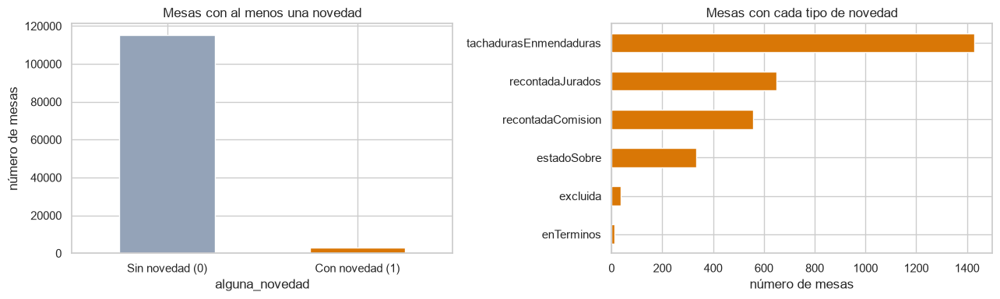

In [132]:
NOVEDAD = {"enTerminos": "NO", "estadoSobre": "MAL", "tachadurasEnmendaduras": "SI",
           "recontadaJurados": "SI", "recontadaComision": "SI", "excluida": "SI"}

# Banderas convertidas a 0/1 (1 = hubo novedad)
nov_bin = pd.DataFrame({c: (noved[c] == v).astype(int) for c, v in NOVEDAD.items()})
nov_bin["alguna_novedad"] = nov_bin.max(axis=1)

balance = pd.DataFrame({"mesas con novedad": nov_bin.sum(),
                        "% de mesas": (nov_bin.mean() * 100).round(2)})
display(balance.sort_values("mesas con novedad", ascending=False))

sin = (nov_bin["alguna_novedad"] == 0).sum()
con = nov_bin["alguna_novedad"].sum()
print(f"Mesas sin novedad: {sin} | con al menos una: {con} | relación: {sin / con:.1f} a 1")
print("\nNúmero de novedades por mesa:")
print(nov_bin.drop(columns="alguna_novedad").sum(axis=1).value_counts().sort_index())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
nov_bin["alguna_novedad"].value_counts().sort_index().plot.bar(ax=ax[0], color=["#94A3B8", "#D97706"])
ax[0].set_xticklabels(["Sin novedad (0)", "Con novedad (1)"], rotation=0)
ax[0].set_title("Mesas con al menos una novedad")
ax[0].set_ylabel("número de mesas")
nov_bin.drop(columns="alguna_novedad").sum().sort_values().plot.barh(ax=ax[1], color="#D97706")
ax[1].set_title("Mesas con cada tipo de novedad")
ax[1].set_xlabel("número de mesas")
plt.tight_layout()
plt.show()

La etiqueta `alguna_novedad` presenta un **desbalance muy fuerte**: solo 2 898 de las 118 350 mesas (2,45 %) tienen al menos una novedad, frente a 115 452 sin ninguna, una relación de casi 40 a 1.

*Figura: mesas con y sin novedad, y número de mesas con cada tipo de novedad (elaboración propia).*

Como muestra la figura anterior, la clase positiva es muy pequeña, y dentro de ella las novedades tampoco se reparten de forma pareja: las tachaduras o enmendaduras (1 428 mesas) explican cerca de la mitad de los casos, mientras que la exclusión de la mesa (37) y la entrega fuera de términos (12) son casi inexistentes. Además, las novedades rara vez se combinan: 2 784 mesas tienen una sola, 106 tienen dos y apenas 8 tienen tres.

Este desbalance tiene consecuencias para el modelado:

- **La exactitud (*accuracy*) no sirve como métrica:** un modelo que siempre prediga "sin novedad" acertaría en el 97,6 % de las mesas sin haber aprendido nada. Se usarán precisión, sensibilidad (*recall*), F1 y PR-AUC.
- **El entrenamiento debe compensar el desbalance,** por ejemplo con pesos de clase, y las particiones deben conservar la proporción de positivos.
- **Las banderas con muy pocos casos** (exclusión y entrega fuera de términos) no son suficientes para modelarse por separado.

**¿El conjunto de datos cuenta con otras variables adicionales? De ser así, analice cuáles se incorporarán en el modelo y haga un análisis descriptivo de las mismas.**

,count,mean,std,min,25%,50%,75%,max
sufragantesSegunE11,118350.0,198.1,68.2,0.0,157.0,206.0,247.0,800.0
dif_urna_e11,118350.0,1.3,61.8,-499.0,0.0,0.0,0.0,8000.0
dif_e14_e11,118350.0,0.2,14.4,-323.0,0.0,0.0,0.0,2723.0
votosIncinerados,118350.0,0.1,3.3,0.0,0.0,0.0,0.0,360.0
firmasJurados,118350.0,5.9,0.4,0.0,6.0,6.0,6.0,6.0



% de mesas con valor distinto de 0:
dif_urna_e11        4.8
dif_e14_e11         1.0
votosIncinerados    1.8
dtype: float64

Mesas con votos incinerados: 2112 | incinerados = urna − E-11: 1323

Tipo de puesto según potencial:
potencial
360     117022
800        572
500        467
1200       289
Name: count, dtype: int64


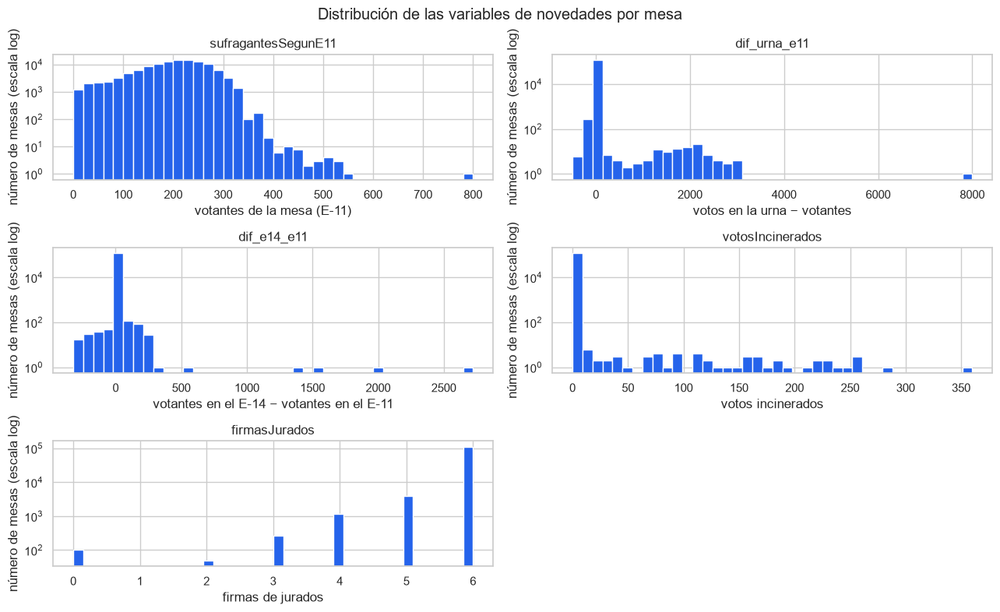

In [133]:
nov_vars = pd.DataFrame({
    "sufragantesSegunE11": noved["sufragantesSegunE11"],
    "dif_urna_e11": noved["votosUrna"] - noved["sufragantesSegunE11"],
    "dif_e14_e11": noved["sufragantesE11SegunE14"] - noved["sufragantesSegunE11"],
    "votosIncinerados": noved["votosIncinerados"],
    "firmasJurados": noved["firmasJurados"],
})
display(nov_vars.describe().T.round(1))

print("\n% de mesas con valor distinto de 0:")
print((nov_vars[["dif_urna_e11", "dif_e14_e11", "votosIncinerados"]] != 0).mean().mul(100).round(1))

inc = noved["votosIncinerados"] > 0
print("\nMesas con votos incinerados:", inc.sum(), "| incinerados = urna − E-11:",
      (noved.loc[inc, "votosIncinerados"] == noved.loc[inc, "votosUrna"] - noved.loc[inc, "sufragantesSegunE11"]).sum())

print("\nTipo de puesto según potencial:")
print(noved["potencial"].value_counts())

ETIQUETAS_NOV = {
    "sufragantesSegunE11": "votantes de la mesa (E-11)",
    "dif_urna_e11": "votos en la urna − votantes",
    "dif_e14_e11": "votantes en el E-14 − votantes en el E-11",
    "votosIncinerados": "votos incinerados",
    "firmasJurados": "firmas de jurados",
}
ejes = nov_vars.hist(bins=40, figsize=(13, 8), color="#2563EB", log=True)
for ax in ejes.flatten():
    if ax.get_title() in ETIQUETAS_NOV:
        ax.set_xlabel(ETIQUETAS_NOV[ax.get_title()])
        ax.set_ylabel("número de mesas (escala log)")
plt.suptitle("Distribución de las variables de novedades por mesa")
plt.tight_layout()
plt.show()

Además de las banderas de novedad, el archivo tiene variables numéricas que describen cómo se desarrolló la votación en la mesa. La siguiente tabla resume cuáles se incorporarán al modelo:

| Variable | Tipo | ¿Se incorpora al modelo? |
|---|---|---|
| `sufragantesSegunE11` | Numérica discreta | **Sí.** Es la referencia del número de votantes, y será clave para compararlo con el preconteo, previa marca de los registros dudosos (pregunta 4 de la 1.2) |
| `votosUrna`, `sufragantesE11SegunE14` | Numéricas discretas | **Sí, como diferencias** con el E-11 (`dif_urna_e11`, `dif_e14_e11`), porque lo informativo es si coinciden o no |
| `votosIncinerados` | Numérica discreta | **Sí.** Indica una nivelación de la mesa (había más votos que votantes) |
| `firmasJurados` | Numérica discreta (0 a 6) | **Sí.** Una firma faltante es una debilidad del acta |
| `tachadurasEnmendaduras`, `recontadaJurados` | Categóricas binarias | **Sí, como entradas,** porque ocurren en la mesa, antes del preconteo |
| `estadoSobre`, `enTerminos`, `recontadaComision`, `excluida` | Categóricas binarias | **No como entradas:** ocurren durante el escrutinio (fuga de información) |
| `potencial` | Categórica (4 valores) | Solo como **tipo de puesto**, no como número de inscritos |
| `totalVotos` | Numérica discreta | **No:** es el resultado del escrutinio (fuga de información) |
| Códigos y nombres de la mesa, corporación, `id` | Identificadores o constantes | **No:** sirven para cruzar las fuentes |

*Figura: histogramas de las variables numéricas de novedades por mesa, con escala logarítmica en el eje vertical (elaboración propia).*

El análisis descriptivo muestra lo siguiente:

- **`sufragantesSegunE11`:** número de votantes de la mesa, con mediana de 206 y la mitad de las mesas entre 157 y 247. Su distribución es la misma que la del total de votos del escrutinio.
- **`dif_urna_e11` y `dif_e14_e11`:** en la gran mayoría de las mesas valen 0 (mediana 0), porque los conteos coinciden. Solo el 4,8 % y el 1,0 % de las mesas, respectivamente, tienen una diferencia. Los histogramas muestran un pico en 0 y colas a ambos lados; en la urna, la cola derecha llega hasta 8 000, el error de digitación ya identificado.
- **`votosIncinerados`:** casi siempre es 0; solo 2 112 mesas (1,8 %) incineraron votos sobrantes. En 1 323 de ellas, los votos incinerados son exactamente la diferencia entre la urna y los votantes, lo que coincide con el procedimiento de nivelación descrito en la sección de contexto.
- **`firmasJurados`:** casi todas las mesas tienen las 6 firmas; las demás se distribuyen en 5, 4, 3, 2 y 0 firmas.
- **`potencial`:** el 98,9 % de las mesas pertenece a puestos con un máximo de 360 votantes; el resto, a puestos con máximos de 500, 800 o 1 200. Se usará como categoría del tipo de puesto.

Las variables de diferencia y los votos incinerados tienen la misma característica que la etiqueta: la gran mayoría de las mesas vale 0. Por eso, en la Fase 3 podría ser más útil convertirlas en indicadores binarios (por ejemplo, "la urna no coincide con el E-11") que usarlas como valores continuos.

### **1.4. Relación Entre Variables**
---

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

**Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.**

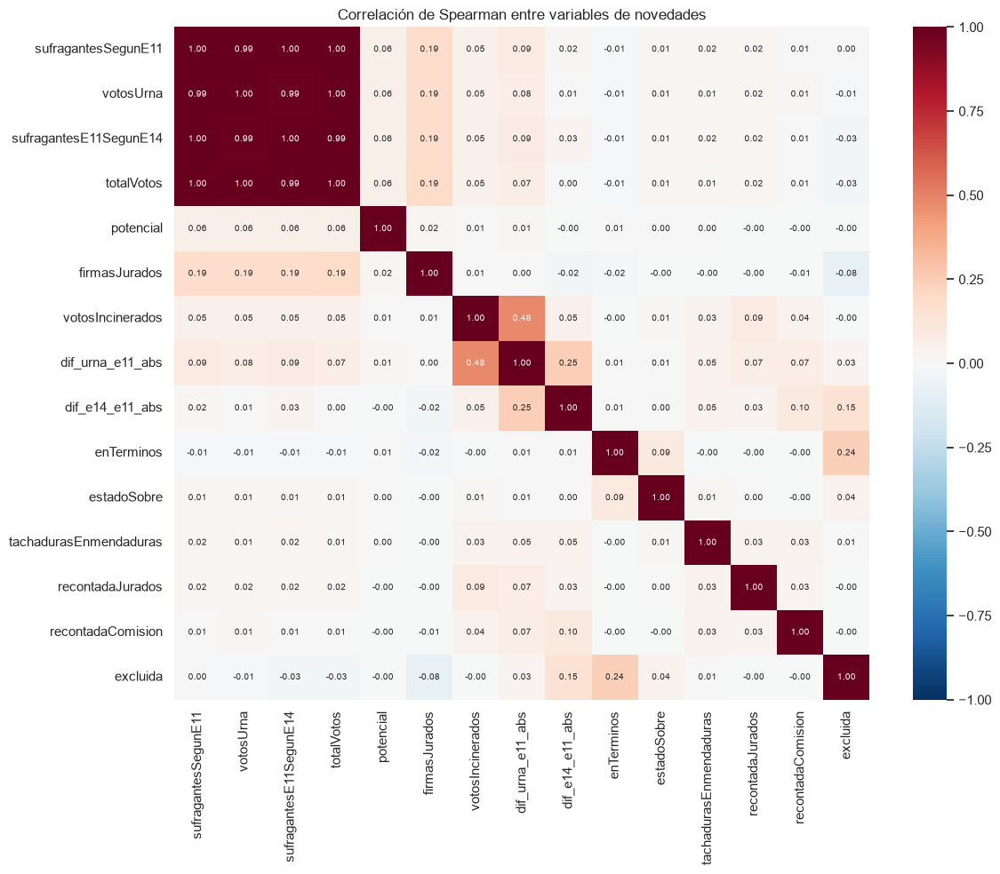

In [134]:


nov_corr = pd.concat([
    noved[["sufragantesSegunE11", "votosUrna", "sufragantesE11SegunE14", "totalVotos",
           "potencial", "firmasJurados", "votosIncinerados"]],
    pd.DataFrame({
        "dif_urna_e11_abs": (noved["votosUrna"] - noved["sufragantesSegunE11"]).abs(),
        "dif_e14_e11_abs": (noved["sufragantesE11SegunE14"] - noved["sufragantesSegunE11"]).abs(),
    }),
    nov_bin.drop(columns="alguna_novedad"),
], axis=1)

corr_nov = nov_corr.corr(method="spearman")

plt.figure(figsize=(12, 10))
sns.heatmap(corr_nov, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlación de Spearman entre variables de novedades")
plt.tight_layout()
plt.show()

In [135]:
base_urna = (nov_corr["dif_urna_e11_abs"] > 0).mean() * 100
base_firmas = (noved["firmasJurados"] < 6).mean() * 100

tabla_rel = pd.DataFrame({
    "% con urna ≠ votantes": {c: (nov_corr.loc[nov_bin[c] == 1, "dif_urna_e11_abs"] > 0).mean() * 100 for c in NOVEDAD},
    "% con menos de 6 firmas": {c: (noved.loc[nov_bin[c] == 1, "firmasJurados"] < 6).mean() * 100 for c in NOVEDAD},
}).round(1)
tabla_rel.loc["TODAS LAS MESAS"] = [round(base_urna, 1), round(base_firmas, 1)]
display(tabla_rel)

print("Firmas de las mesas excluidas:", noved.loc[noved["excluida"] == "SI", "firmasJurados"].value_counts().to_dict())
print("Mesas con 0 firmas:", (noved["firmasJurados"] == 0).sum(),
      "| de ellas, excluidas:", ((noved["firmasJurados"] == 0) & (noved["excluida"] == "SI")).sum())

,% con urna ≠ votantes,% con menos de 6 firmas
enTerminos,16.7,41.7
estadoSobre,6.9,6.3
tachadurasEnmendaduras,13.7,5.4
recontadaJurados,26.4,4.9
recontadaComision,26.9,6.3
excluida,37.8,100.0
TODAS LAS MESAS,4.8,4.6


Firmas de las mesas excluidas: {0: 37}
Mesas con 0 firmas: 104 | de ellas, excluidas: 37


Se usó la correlación de Spearman, igual que en el escrutinio. Para el análisis se agregaron las diferencias absolutas entre los votos en la urna y los votantes (`dif_urna_e11_abs`) y entre los votantes del E-14 y del E-11 (`dif_e14_e11_abs`), junto con las seis banderas de novedad convertidas a 0/1.

*Figura: matriz de correlación de Spearman entre las variables de novedades*

La figura anterior muestra tres patrones:

- **Los cuatro conteos de la mesa están casi perfectamente relacionados** (ρ entre 0,99 y 1,00): votantes del E-11, votos en la urna, votantes del E-14 y total de votos. Es esperable, porque en una mesa normal todos registran el mismo número.
- **Los votos incinerados se relacionan con la diferencia entre la urna y los votantes** (ρ = 0,48). Coincide con el procedimiento de nivelación: cuando hay más votos que votantes, los sobrantes se incineran.
- **Las banderas de novedad casi no se relacionan entre sí** (coeficientes cercanos a 0). Cada una registra un hecho distinto: por ejemplo, de las 651 mesas recontadas por los jurados, solo 20 fueron recontadas también por la comisión.

Sin embargo, la correlación subestima la relación de las banderas con las demás variables, porque cada novedad ocurre en menos del 1,3 % de las mesas. Por eso se compararon porcentajes en la tabla anterior. Mientras que en el total de mesas solo el 4,8 % tiene una urna que no coincide con los votantes, en las mesas recontadas por los jurados el porcentaje sube a 26,4 % y en las recontadas por la comisión a 26,9 %: más de cinco veces. Es decir, **las mesas con novedades tienen muchas más inconsistencias en sus conteos**, lo que respalda el uso de estas variables para identificar mesas que ameritan revisión.

La relación más fuerte es entre la exclusión y las firmas: **las 37 mesas excluidas tienen cero firmas de jurados**. Esto sugiere que la falta de firmas en el acta es una causa de exclusión de la mesa. Aun así, no toda acta sin firmas fue excluida: de las 104 mesas sin firmas, 67 no lo fueron.

## Comparación entre fuentes (preconteo frente a escrutinio)

El objetivo del proyecto es anticipar qué mesas cambian entre el preconteo y el escrutinio. Esta sección construye esa variable objetivo comparando las dos fuentes mesa por mesa y revisa cómo se relaciona con las novedades y con el E-11.

### ¿Las dos fuentes cubren las mismas mesas y los mismos votos?

In [136]:
cmp_esc = escru.pivot_table(index=LLAVE_MESA, columns="candidato", values="votos",
                            aggfunc="sum", fill_value=0)
cmp_pre = (precon.pivot_table(index=LLAVE_MESA, columns="candidato", values="votos",
                              aggfunc="sum", fill_value=0)
                 .reindex(index=cmp_esc.index, columns=cmp_esc.columns, fill_value=0))

print("Mesas en el escrutinio:", len(cmp_esc))
print("Mesas del preconteo encontradas en el escrutinio:",
      precon[LLAVE_MESA].drop_duplicates().merge(cmp_esc.reset_index()[LLAVE_MESA]).shape[0])
print("Candidaturas:", list(cmp_esc.columns))
print("Votos totales — preconteo:", cmp_pre.values.sum(), "| escrutinio:", cmp_esc.values.sum())

Mesas en el escrutinio: 122020
Mesas del preconteo encontradas en el escrutinio: 122020
Candidaturas: ['001', '002', '003', '004', '005', '006', '007', '008', '009', '010', '011', '012', '013', '996', '997', '998']
Votos totales — preconteo: 23978304 | escrutinio: 23990635


Las dos fuentes tienen las mismas 122 020 mesas, así que cada mesa del escrutinio tiene su par en el preconteo. El preconteo suma 23 978 304 votos y el escrutinio 23 990 635, 12 331 más. Para comparar, cada fuente se convirtió en una tabla con una fila por mesa y una columna por candidatura.

In [137]:
cmp_dif = cmp_esc - cmp_pre
traslado = cmp_pre["009"] + cmp_pre["013"]

print("Votos de 009 y 013 — preconteo:", cmp_pre[["009", "013"]].sum().to_dict(),
      "| escrutinio:", cmp_esc[["009", "013"]].sum().to_dict())
print("Mesas con votos de candidatos retirados:", (traslado > 0).sum())
print("Votos no marcados (998) — preconteo:", cmp_pre["998"].sum(),
      "| escrutinio:", cmp_esc["998"].sum())
print("Mesas con algún cambio, comparación directa:", (cmp_dif != 0).any(axis=1).sum())

Votos de 009 y 013 — preconteo: {'009': 12694, '013': 13270} | escrutinio: {'009': 0, '013': 0}
Mesas con votos de candidatos retirados: 20732
Votos no marcados (998) — preconteo: 47586 | escrutinio: 69400
Mesas con algún cambio, comparación directa: 25414


En el preconteo los candidatos 009 y 013 tienen 12 694 y 13 270 votos, y en el escrutinio tienen 0, porque se retiraron y sus votos pasaron al código 998, que sube de 47 586 a 69 400. Esto afecta a 20 732 mesas. Si se restan las fuentes sin más, aparecen cambios en 25 414 mesas, pero la mayoría solo refleja ese traslado y no una corrección del acta. Por eso, para el 998 se descuenta el traslado antes de decidir si una mesa cambió.

### ¿Cómo se define la variable objetivo?

In [138]:
ACTIVOS = [c for c in cmp_esc.columns if c not in ("009", "013", "996", "997", "998")]
cambio_998 = cmp_dif["998"] - traslado

cmp = pd.DataFrame({
    "cambia_candidato":   (cmp_dif[ACTIVOS] != 0).any(axis=1),
    "cambia_blanco_nulo": (cmp_dif[["996", "997"]] != 0).any(axis=1),
    "cambia_998_extra":   cambio_998 != 0,
})
cmp["magnitud"] = cmp_dif[ACTIVOS + ["996", "997"]].abs().sum(axis=1) + cambio_998.abs()
cmp["y_corregida"] = (cmp["magnitud"] > 0).astype(int)
cmp = cmp.reset_index()

print(cmp[["cambia_candidato", "cambia_blanco_nulo", "cambia_998_extra"]].sum())
print("Mesas corregidas (cambio no explicado por el retiro):", cmp["y_corregida"].sum())

cambia_candidato      4337
cambia_blanco_nulo    1304
cambia_998_extra      1170
dtype: int64
Mesas corregidas (cambio no explicado por el retiro): 6122


Se definen dos etiquetas:

- `y_corregida` (clasificación): vale 1 si la mesa tiene algún cambio que no se explica por el retiro, ya sea en un candidato activo, en el voto en blanco (996), en el nulo (997) o en el 998 más allá del traslado.
- `magnitud` (regresión): es la suma de los votos que cambiaron, en valor absoluto.

Hay 4 337 mesas donde cambia algún candidato, 1 304 donde cambia el voto en blanco o el nulo y 1 170 donde el 998 cambia más de lo que explica el traslado. Una mesa puede tener varios de estos cambios a la vez, y en total quedan **6 122 mesas corregidas**.

### ¿Qué tan desbalanceada está la variable objetivo y de qué tamaño son las correcciones?

Todas las mesas: 122020 | corregidas: 6122 (5.02 %) | relación 18.9 a 1
Mesas nacionales: 118350 | corregidas: 5998 (5.07 %) | relación 18.7 a 1

Magnitud de la corrección en las mesas corregidas (votos):
count    6122.0
mean       13.5
std        35.8
min         1.0
50%         3.0
75%         8.0
90%        20.0
99%       200.0
max       490.0
Name: magnitud, dtype: float64


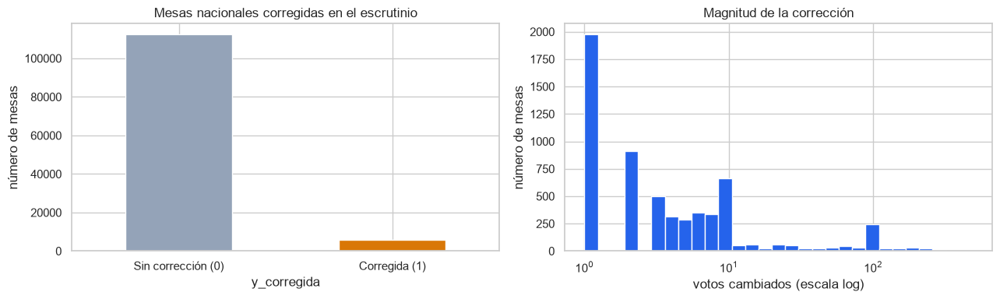

In [139]:
cmp_nac = cmp[cmp["dep"] != "88"].copy()   # 88 = consulados

for nombre, df in [("Todas las mesas", cmp), ("Mesas nacionales", cmp_nac)]:
    n1 = df["y_corregida"].sum()
    n0 = len(df) - n1
    print(f"{nombre}: {len(df)} | corregidas: {n1} ({n1 / len(df) * 100:.2f} %) | relación {n0 / n1:.1f} a 1")

print("\nMagnitud de la corrección en las mesas corregidas (votos):")
print(cmp.loc[cmp["y_corregida"] == 1, "magnitud"].describe(percentiles=[.5, .75, .9, .99]).round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cmp_nac["y_corregida"].value_counts().sort_index().plot.bar(ax=ax[0], color=["#94A3B8", "#D97706"])
ax[0].set_xticklabels(["Sin corrección (0)", "Corregida (1)"], rotation=0)
ax[0].set_ylabel("número de mesas")
ax[0].set_title("Mesas nacionales corregidas en el escrutinio")

mag = cmp.loc[cmp["y_corregida"] == 1, "magnitud"]
ax[1].hist(mag, bins=np.logspace(0, np.log10(mag.max()), 30), color="#2563EB")
ax[1].set_xscale("log")
ax[1].set_xlabel("votos cambiados (escala log)")
ax[1].set_ylabel("número de mesas")
ax[1].set_title("Magnitud de la corrección")
plt.tight_layout()
plt.show()

*Figura: Balance de la variable objetivo y magnitud de las correcciones (elaboración propia).*

El desbalance es fuerte. De todas las mesas, el 5,02 % fue corregido (unas 19 sin corrección por cada mesa corregida). Entre las 118 350 mesas nacionales hay 5 998 corregidas (5,07 %). Por eso, en el modelado conviene usar métricas como precisión, sensibilidad o PR-AUC en lugar de la exactitud, y manejar el desbalance con pesos o con un umbral ajustado.

La figura anterior muestra que la mayoría de las correcciones son pequeñas: la mediana es de 3 votos, el percentil 75 de 8 y el percentil 90 de 20. Unas pocas son muy grandes: el percentil 99 llega a 200 votos y el máximo a 490. Por eso la media (13,5) queda muy por encima de la mediana. Esta asimetría sugiere usar una transformación logarítmica si se modela la magnitud.

### ¿Las novedades registradas se relacionan con que la mesa sea corregida?

In [140]:
NOVEDAD = {"enTerminos": "NO", "estadoSobre": "MAL", "tachadurasEnmendaduras": "SI",
           "recontadaJurados": "SI", "recontadaComision": "SI", "excluida": "SI"}

cmp_nov = cmp_nac.merge(noved[LLAVE_MESA + list(NOVEDAD) + ["sufragantesSegunE11", "potencial"]],
                        on=LLAVE_MESA)
for c, v in NOVEDAD.items():
    cmp_nov[c] = (cmp_nov[c] == v).astype(int)
cmp_nov["alguna_novedad"] = cmp_nov[list(NOVEDAD)].max(axis=1)

print("Mesas cruzadas con novedades:", len(cmp_nov))
display(pd.crosstab(cmp_nov["alguna_novedad"], cmp_nov["y_corregida"], margins=True))

tasa = pd.Series({c: cmp_nov.loc[cmp_nov[c] == 1, "y_corregida"].mean() * 100
                  for c in list(NOVEDAD) + ["alguna_novedad"]})
tasa["SIN NINGUNA NOVEDAD"] = cmp_nov.loc[cmp_nov["alguna_novedad"] == 0, "y_corregida"].mean() * 100
mesas = [cmp_nov[c].sum() for c in list(NOVEDAD) + ["alguna_novedad"]] + [(cmp_nov["alguna_novedad"] == 0).sum()]
display(pd.DataFrame({"mesas": mesas, "% corregidas": tasa.round(1)}))

Mesas cruzadas con novedades: 118350


y_corregida,0,1,All
alguna_novedad,,,
0,110195,5257,115452
1,2157,741,2898
All,112352,5998,118350


,mesas,% corregidas
enTerminos,12,50.0
estadoSobre,334,5.7
tachadurasEnmendaduras,1428,11.8
recontadaJurados,651,12.9
recontadaComision,558,89.2
excluida,37,100.0
alguna_novedad,2898,25.6
SIN NINGUNA NOVEDAD,115452,4.6


Las mesas sin ninguna novedad tienen un 4,6 % de corrección, mientras que las que registran alguna llegan al 25,6 %. Por novedad:

- Tachaduras: 11,8 % (1 428 mesas).
- Reconteo de jurados: 12,9 % (651 mesas).
- Sobre en mal estado: 5,7 % (334 mesas).
- Entrega fuera de términos: 50 %, aunque son solo 12 mesas, así que esta cifra es poco estable.

**Advertencia de fuga de información:** `recontadaComision` (89,2 %) y `excluida` (100 %) no anticipan la corrección: son el propio mecanismo por el que se corrige la mesa, y se registran durante el escrutinio. Si entran al modelo, este acertaría por una razón que no estaría disponible al momento de predecir. Se dejan fuera de las variables de entrada.

### ¿Una diferencia entre el preconteo y el E-11 anticipa la corrección?

Mesas con E-11 dudoso: 143 | % con preconteo ≠ E-11: 100 | % corregidas: 6.3
Preconteo ≠ E-11: 9521 mesas | % corregidas: 56.5
Preconteo = E-11: 108686 mesas | % corregidas: 0.56
De las mesas corregidas, % con preconteo ≠ E-11: 89.8


,mesas,pct
grupo,,
preconteo < E-11,6659,37.9
preconteo = E-11,108686,0.6
preconteo > E-11,2862,99.9


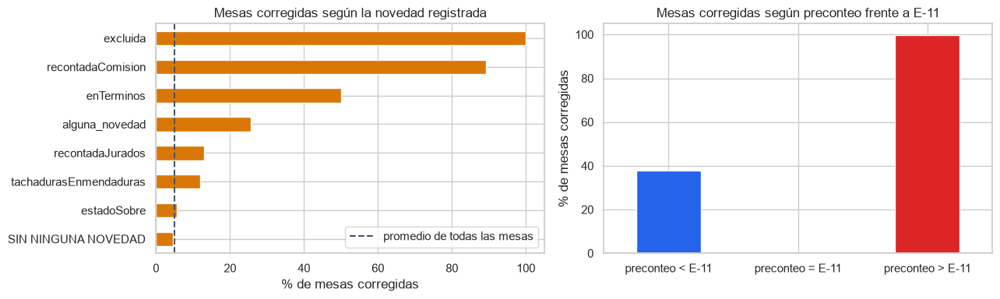

In [141]:
tot_pre = cmp_pre.sum(axis=1).rename("tot_pre").reset_index()
cmp_nov = cmp_nov.merge(tot_pre, on=LLAVE_MESA)
cmp_nov["dif_pre_e11"] = cmp_nov["tot_pre"] - cmp_nov["sufragantesSegunE11"]
cmp_nov["e11_dudoso"] = (cmp_nov["sufragantesSegunE11"] == cmp_nov["potencial"]).astype(int)

dud = cmp_nov[cmp_nov["e11_dudoso"] == 1]
print("Mesas con E-11 dudoso:", len(dud),
      f"| % con preconteo ≠ E-11: {(dud['dif_pre_e11'] != 0).mean() * 100:.0f}",
      f"| % corregidas: {dud['y_corregida'].mean() * 100:.1f}")

conf = cmp_nov[cmp_nov["e11_dudoso"] == 0]
reg = conf["dif_pre_e11"] != 0
print(f"Preconteo ≠ E-11: {reg.sum()} mesas | % corregidas: {conf.loc[reg, 'y_corregida'].mean() * 100:.1f}")
print(f"Preconteo = E-11: {(~reg).sum()} mesas | % corregidas: {conf.loc[~reg, 'y_corregida'].mean() * 100:.2f}")
print(f"De las mesas corregidas, % con preconteo ≠ E-11: {reg[conf['y_corregida'] == 1].mean() * 100:.1f}")

gr = conf.assign(grupo=np.select([conf["dif_pre_e11"] < 0, conf["dif_pre_e11"] == 0],
                                 ["preconteo < E-11", "preconteo = E-11"], "preconteo > E-11"))
display(gr.groupby("grupo")["y_corregida"].agg(mesas="size", pct=lambda s: round(s.mean() * 100, 1)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tasa.sort_values().plot.barh(ax=ax[0], color="#D97706")
ax[0].axvline(cmp_nov["y_corregida"].mean() * 100, color="#475569", linestyle="--",
              label="promedio de todas las mesas")
ax[0].set_xlabel("% de mesas corregidas")
ax[0].set_title("Mesas corregidas según la novedad registrada")
ax[0].legend()

gr.groupby("grupo")["y_corregida"].mean().mul(100).plot.bar(ax=ax[1], color=["#2563EB", "#94A3B8", "#DC2626"])
ax[1].set_ylabel("% de mesas corregidas")
ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=0)
ax[1].set_title("Mesas corregidas según preconteo frente a E-11")
plt.tight_layout()
plt.show()

*Figura: Porcentaje de mesas corregidas según la novedad y según la diferencia entre preconteo y E-11 (elaboración propia).*

Antes de comparar se excluyeron las 143 mesas con E-11 dudoso, en las que el E-11 es igual al potencial de votantes. En ellas el preconteo nunca coincide con el E-11 (100 %), pero solo el 6,3 % fue corregido, así que incluirlas daría alertas falsas.

En las mesas confiables:

- Cuando el preconteo **coincide** con el E-11 (108 686 mesas), solo el 0,56 % fue corregido.
- Cuando **no coincide** (9 521 mesas), el 56,5 % fue corregido.
- El 89,8 % de las mesas corregidas tiene esta diferencia.

La dirección de la diferencia importa. Si el preconteo tiene **más** votos que votantes en el E-11 (2 862 mesas), el 99,9 % fue corregido, lo cual tiene sentido porque una mesa no puede tener más votos que votantes. Si tiene **menos** (6 659 mesas), se corrige el 37,9 %. Esto sugiere crear como variables de entrada la diferencia `preconteo − E-11` y su signo, ambas disponibles antes del escrutinio, y conservar la bandera `e11_dudoso` para que el modelo no confíe en esos casos.

### Conclusión de la comparación

La variable objetivo está bien definida después de descontar el retiro: el 5,1 % de las mesas nacionales fue corregido. Es una clase desbalanceada y la mayoría de las correcciones son pequeñas. Las señales disponibles antes del escrutinio con mayor relación son la diferencia entre preconteo y E-11, las tachaduras y el reconteo de jurados. `recontadaComision` y `excluida` se descartan por fuga de información.

# **Parte III. Preparación de los datos**
---

Con lo aprendido en el entendimiento de los datos, cada fuente se limpia con los mismos criterios: valores faltantes, duplicados, atípicos, datos inconsistentes, datos corruptos y selección de datos. Al final, las tres fuentes se integran en el **dataset maestro** de una fila por mesa, que es la entrada de los modelos.

## **2. Novedades**
---

### Carga y revisión inicial: Novedades

Este notebook trabaja **solo** con el conjunto de datos de *Novedades* (`Novedad20260603.zip`). No se usan los datos de Preconteo ni de Escrutinio.

In [142]:
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path('../../data/raw/elecciones_2026/extracted/MMV_Presidente1V_2026/MMV_Presidente1V_2026')
NOVEDADES_ZIP = DATA_DIR / 'Novedad20260603.zip'

# Estilo de las gráficas: azul como color principal, naranja para lo que requiere atención, gris para el contexto
AZUL, AZUL_CLARO, NARANJA, GRIS = '#2a78d6', '#86b6ef', '#eb6834', '#c3c2b7'
TINTA, TINTA_SUAVE, FONDO = '#0b0b0b', '#52514e', '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GRIS,
    'axes.labelcolor': TINTA_SUAVE, 'xtick.color': TINTA_SUAVE, 'ytick.color': TINTA_SUAVE,
    'text.color': TINTA, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'axes.grid.axis': 'x', 'grid.color': '#e1e0d9', 'grid.linewidth': 0.8,
    'axes.axisbelow': True,
})


def miles(n):
    return f'{n:,.0f}'.replace(',', '.')


def porcentaje(x, decimales=1):
    return f'{x:.{decimales}f} %'.replace('.', ',')


#### Carga de datos

In [143]:
def fix_bad_line(fields):
    # 45 filas traen comas sin comillas en puestoNombre (columna 7): se vuelven a unir
    extra = len(fields) - 24
    if extra < 1:
        return None
    return fields[:7] + [','.join(fields[7:8 + extra])] + fields[8 + extra:]


with zipfile.ZipFile(NOVEDADES_ZIP) as z:
    with z.open('Novedad20260603.csv') as f:
        df = pd.read_csv(f, dtype=str, engine='python', on_bad_lines=fix_bad_line)

print(df.shape)
df.head()


(118350, 24)


,id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,...,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos
0,010100101011,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,1,001,...,BUENO,NO,NO,NO,NO,6,128,0,128,127
1,010100101012,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,2,001,...,BUENO,NO,NO,NO,NO,6,65,0,65,65
2,010100101013,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,3,001,...,BUENO,NO,NO,NO,NO,6,107,0,107,107
3,010100101014,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,4,001,...,BUENO,NO,NO,NO,NO,6,143,0,143,143
4,010100101015,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,5,001,...,BUENO,NO,NO,NO,NO,6,177,0,177,177


#### Estructura general

In [144]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 118350 entries, 0 to 118349
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   id                      118350 non-null  str  
 1   departamentoCodigo      118350 non-null  str  
 2   departamentoNombre      118350 non-null  str  
 3   municipioCodigo         118350 non-null  str  
 4   municipioNombre         118350 non-null  str  
 5   zonaNombre              118350 non-null  str  
 6   puestoCodigo            118350 non-null  str  
 7   puestoNombre            118350 non-null  str  
 8   mesaNumero              118350 non-null  str  
 9   corporacionCodigo       118350 non-null  str  
 10  corporacionNombre       118350 non-null  str  
 11  potencial               118350 non-null  str  
 12  sufragantesSegunE11     118350 non-null  str  
 13  enTerminos              118350 non-null  str  
 14  estadoSobre             118350 non-null  str  
 15  tachadurasE

In [145]:
df.isna().sum()

id                        0
departamentoCodigo        0
departamentoNombre        0
municipioCodigo           0
municipioNombre           0
zonaNombre                0
puestoCodigo              0
puestoNombre              0
mesaNumero                0
corporacionCodigo         0
corporacionNombre         0
potencial                 0
sufragantesSegunE11       0
enTerminos                0
estadoSobre               0
tachadurasEnmendaduras    0
recontadaJurados          0
recontadaComision         0
excluida                  0
firmasJurados             0
votosUrna                 0
votosIncinerados          0
sufragantesE11SegunE14    0
totalVotos                0
dtype: int64

In [146]:
df.describe(include='all').T

,count,unique,top,freq
id,118350,118350,010100101011,1
departamentoCodigo,118350,33,16,17164
departamentoNombre,118350,33,BOGOTA D.C.,17164
municipioCodigo,118350,263,001,52074
municipioNombre,118350,1036,BOGOTA. D.C.,17164
zonaNombre,118350,42,99,19365
puestoCodigo,118350,208,01,23961
puestoNombre,118350,10485,PUESTO CABECERA MUNICIPAL,11780
mesaNumero,118350,228,1,13489
corporacionCodigo,118350,1,001,118350


##### Novedades registradas

Cuántas mesas presentan cada tipo de novedad.

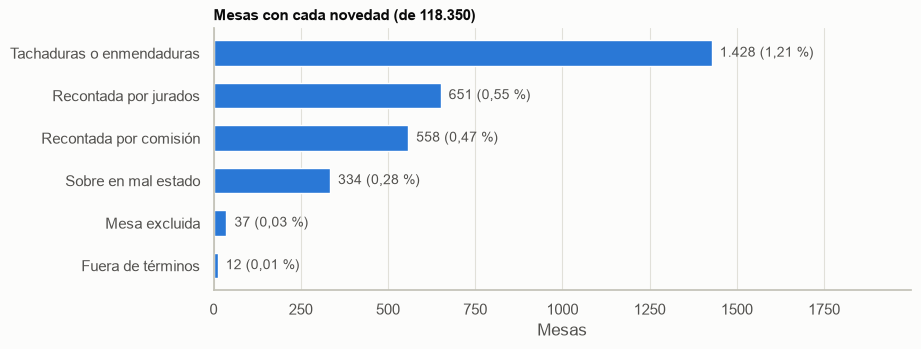

In [147]:
novedades = {
    'Tachaduras o enmendaduras': df['tachadurasEnmendaduras'].eq('SI'),
    'Recontada por jurados': df['recontadaJurados'].eq('SI'),
    'Recontada por comisión': df['recontadaComision'].eq('SI'),
    'Sobre en mal estado': df['estadoSobre'].eq('MAL'),
    'Mesa excluida': df['excluida'].eq('SI'),
    'Fuera de términos': df['enTerminos'].eq('NO'),
}
conteo_novedades = pd.Series({k: int(v.sum()) for k, v in novedades.items()}).sort_values()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(conteo_novedades.index, conteo_novedades.values, color=AZUL, height=0.6)
for y, n in enumerate(conteo_novedades.values):
    ax.text(n, y, f'  {miles(n)} ({porcentaje(n / len(df) * 100, 2)})', va='center', color=TINTA_SUAVE)
ax.set_xlim(0, conteo_novedades.max() * 1.4)
ax.set_xlabel('Mesas')
ax.set_title(f'Mesas con cada novedad (de {miles(len(df))})')
plt.show()

### 1. Limpieza de los Datos

Apartados:
- 1.1 a 1.3. Valores faltantes, duplicados y atípicos
- 1.4. Datos inconsistentes
- 1.5. Transformaciones aplicadas (limpieza de los datos)
- 1.6. Documentación de las decisiones tomadas

En los apartados 1.1 a 1.4 solo se **diagnostica**; las transformaciones se aplican en el apartado 1.5 sobre una copia (`df_clean`) y cada decisión se registra en el apartado 1.6.

#### 1.1. Valores faltantes

In [148]:
COLS_NUM = ['mesaNumero', 'potencial', 'sufragantesSegunE11', 'firmasJurados', 'votosUrna',
            'votosIncinerados', 'sufragantesE11SegunE14', 'totalVotos']

nulos = df.isna().sum().sum()
vacios = df.apply(lambda s: s.str.strip().eq('')).sum().sum()
print(f'Nulos: {nulos} | Cadenas vacías: {vacios}')

# Las columnas numéricas llegan como texto (dtype=str): se verifica que todas se puedan convertir
df_num = df[COLS_NUM].apply(pd.to_numeric, errors='coerce')
print('Valores no numéricos por columna:')
print(df_num.isna().sum().to_string())

Nulos: 0 | Cadenas vacías: 0
Valores no numéricos por columna:
mesaNumero                0
potencial                 0
sufragantesSegunE11       0
firmasJurados             0
votosUrna                 0
votosIncinerados          0
sufragantesE11SegunE14    0
totalVotos                0


**Hallazgo:** no hay nulos, cadenas vacías ni valores no numéricos en las columnas de conteo.

#### 1.2. Valores duplicados

In [149]:
CLAVE_MESA = ['departamentoCodigo', 'municipioCodigo', 'zonaNombre', 'puestoCodigo', 'mesaNumero']

print('Filas completamente duplicadas:', df.duplicated().sum())
print('Valores de id repetidos:', df['id'].duplicated().sum())
print('Mesas repetidas (departamento, municipio, zona, puesto, mesa):', df.duplicated(subset=CLAVE_MESA).sum())
print('Filas iguales ignorando id:', df.drop(columns='id').duplicated().sum())

Filas completamente duplicadas: 0
Valores de id repetidos: 0
Mesas repetidas (departamento, municipio, zona, puesto, mesa): 0
Filas iguales ignorando id: 0


**Hallazgo:** no hay duplicados exactos, de `id` ni de mesa. Cada fila es una mesa única.

#### 1.3. Valores atípicos

Se usa el rango intercuartílico (IQR): son atípicos los valores fuera de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]`, donde Q1 y Q3 son los cuartiles 25 y 75 e IQR = Q3 − Q1. Se aplica a las cuatro columnas de votantes.

In [150]:
print('Valores de potencial:', df_num['potencial'].value_counts().to_dict())

COLS_VOTOS = ['sufragantesSegunE11', 'votosUrna', 'votosIncinerados', 'sufragantesE11SegunE14', 'totalVotos']


def limites_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


resumen = []
for col in COLS_VOTOS:
    lo, hi = limites_iqr(df_num[col])
    resumen.append({
        'columna': col,
        'limite_inf': lo,
        'limite_sup': hi,
        'atipicos_iqr': ((df_num[col] < lo) | (df_num[col] > hi)).sum(),
        'p99': df_num[col].quantile(0.99),
        'maximo': df_num[col].max(),
    })
pd.DataFrame(resumen).set_index('columna')

Valores de potencial: {360: 117022, 800: 572, 500: 467, 1200: 289}


,limite_inf,limite_sup,atipicos_iqr,p99,maximo
columna,,,,,
sufragantesSegunE11,22.0,382.0,1504,325.0,800
votosUrna,22.0,382.0,1702,324.0,8195
votosIncinerados,0.0,0.0,2112,1.0,360
sufragantesE11SegunE14,22.0,382.0,1562,327.0,3025
totalVotos,22.0,382.0,1538,323.0,546


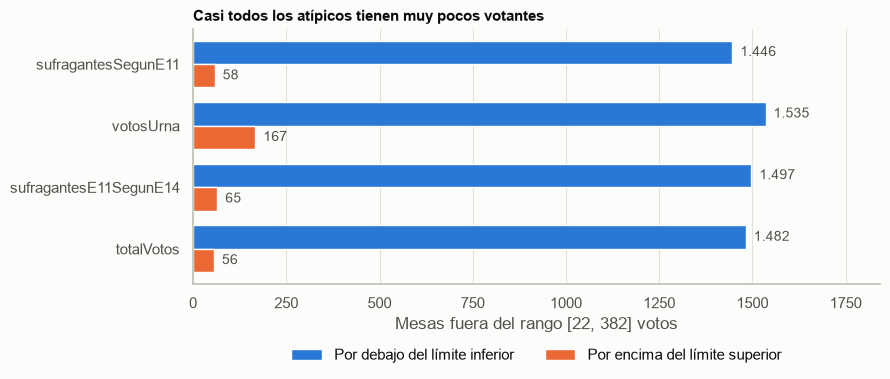

In [151]:
COLS_IQR = ['sufragantesSegunE11', 'votosUrna', 'sufragantesE11SegunE14', 'totalVotos']

limites = {col: limites_iqr(df_num[col]) for col in COLS_IQR}
por_debajo = {col: int((df_num[col] < limites[col][0]).sum()) for col in COLS_IQR}
por_encima = {col: int((df_num[col] > limites[col][1]).sum()) for col in COLS_IQR}

fig, ax = plt.subplots(figsize=(9, 4))

# Atípicos por IQR, según el lado del límite
posiciones = range(len(COLS_IQR))
alto = 0.38
ax.barh([p - alto / 2 for p in posiciones], list(por_debajo.values()), height=alto, color=AZUL,
        label='Por debajo del límite inferior')
ax.barh([p + alto / 2 for p in posiciones], list(por_encima.values()), height=alto, color=NARANJA,
        label='Por encima del límite superior')
for p, (a, b) in enumerate(zip(por_debajo.values(), por_encima.values())):
    ax.text(a, p - alto / 2, f'  {miles(a)}', va='center', color=TINTA_SUAVE)
    ax.text(b, p + alto / 2, f'  {miles(b)}', va='center', color=TINTA_SUAVE)
ax.set_yticks(list(posiciones), COLS_IQR)
ax.set_xlim(0, max(por_debajo.values()) * 1.2)
ax.invert_yaxis()
lo, hi = limites['sufragantesSegunE11']
ax.set_xlabel(f'Mesas fuera del rango [{lo:.0f}, {hi:.0f}] votos')
ax.set_title('Casi todos los atípicos tienen muy pocos votantes')
ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.2))

fig.tight_layout()
plt.show()

**Lectura:**
- El IQR marca entre 1.504 y 1.702 mesas por columna de votantes, con los mismos límites en las cuatro: de 22 a 382 votos.
- Casi todas están por debajo del límite inferior, es decir, mesas con menos de 22 votantes (incluidas las excluidas). Por encima del límite hay pocas (56 a 167 por columna), pero incluyen los extremos 8.195 y 3.025.

La decisión sobre estas mesas se toma en el apartado 1.5.

##### Efecto de leer todas las columnas como texto (`dtype=str`)

El archivo se carga con `dtype=str` para conservar los ceros a la izquierda de los códigos. Riesgos: `isna()` solo detecta lo que pandas convierte a `NaN`, `describe()` e `info()` no resumen conteos y ordenar compara carácter a carácter. Se verifica cada punto.

In [152]:
# 1) Lectura sin ninguna conversión automática a NaN, para comparar con la lectura normal
with zipfile.ZipFile(NOVEDADES_ZIP) as z:
    with z.open('Novedad20260603.csv') as f:
        df_raw = pd.read_csv(f, dtype=str, engine='python', on_bad_lines=fix_bad_line,
                             keep_default_na=False, na_filter=False)

print('Celdas distintas entre ambas lecturas:', int((df.fillna('<NA>') != df_raw).sum().sum()))

MARCADORES = {'', '-', '--', '?', 'NA', 'N/A', 'NULL', 'NAN', 'NONE', 'S/D', 'SD', 'SIN DATO', 'NO APLICA'}
marcadores = df_raw.apply(lambda s: s.str.strip().str.upper().isin(MARCADORES)).sum()
print('Celdas con marcadores de dato ausente:', int(marcadores.sum()))

# 2) Las columnas de conteo deben ser solo dígitos (to_numeric también aceptaría '5.0', '+5', ' 5' o '1e3')
no_digitos = {c: int((~df[c].str.fullmatch(r'\d+')).sum()) for c in COLS_NUM}
print('Conteos que no son solo dígitos:', no_digitos)

# 3) Códigos: ¿alguno no es numérico? (si lo fuera, convertirlo a entero habría fallado o perdido información)
CODIGOS = ['departamentoCodigo', 'municipioCodigo', 'zonaNombre', 'puestoCodigo', 'corporacionCodigo']
print('Códigos no numéricos:', {c: int((~df[c].str.fullmatch(r'\d+')).sum()) for c in CODIGOS})
print('Ejemplos de puestoCodigo no numérico:', df.loc[~df['puestoCodigo'].str.fullmatch(r'\d+'), 'puestoCodigo'].unique()[:8].tolist())

# 4) Máximo como texto frente al máximo numérico
print('Máximo de votosUrna como texto:', df['votosUrna'].max(), '| como número:', df_num['votosUrna'].max())

Celdas distintas entre ambas lecturas: 0
Celdas con marcadores de dato ausente: 0
Conteos que no son solo dígitos: {'mesaNumero': 0, 'potencial': 0, 'sufragantesSegunE11': 0, 'firmasJurados': 0, 'votosUrna': 0, 'votosIncinerados': 0, 'sufragantesE11SegunE14': 0, 'totalVotos': 0}
Códigos no numéricos: {'departamentoCodigo': 0, 'municipioCodigo': 0, 'zonaNombre': 0, 'puestoCodigo': 931, 'corporacionCodigo': 0}
Ejemplos de puestoCodigo no numérico: ['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'B1', 'B2']
Máximo de votosUrna como texto: 990 | como número: 8195


**Lectura:**
- Los 0 nulos son reales: la lectura sin conversión automática da las mismas celdas y no hay marcadores como `-` o `S/D`.
- Los conteos son solo dígitos, así que `to_numeric` no acepta formatos raros.
- Los códigos deben quedarse como texto: `puestoCodigo` tiene 931 filas alfanuméricas (`A1`, `B2`, ...) y los demás tienen ceros a la izquierda.
- El texto engaña al ordenar (el máximo de `votosUrna` es `990` como texto y `8195` como número); los análisis numéricos deben usar `df_num` o `df_clean`.
- Por la misma razón, `df.info()` y `df.describe()` del inicio no resumen los conteos.

#### 1.4. Datos inconsistentes

##### 1.4.1 Coherencia del identificador y de los códigos

El `id` se compone de un prefijo `01` más los códigos de departamento, municipio, zona, puesto y mesa. Se verifica que coincida con las columnas y que cada código tenga un único nombre dentro de su nivel jerárquico (el código de municipio se repite entre departamentos, por lo que se evalúa junto con el del departamento).

In [153]:
id_esperado = '01' + df['departamentoCodigo'] + df['municipioCodigo'] + df['zonaNombre'] + df['puestoCodigo'] + df['mesaNumero']
print('Filas donde el id no coincide con sus códigos:', (id_esperado != df['id']).sum())
print('Códigos de corporación distintos:', df['corporacionCodigo'].unique().tolist(), df['corporacionNombre'].unique().tolist())

JERARQUIA = {
    'departamento': (['departamentoCodigo'], 'departamentoNombre'),
    'municipio': (['departamentoCodigo', 'municipioCodigo'], 'municipioNombre'),
    'puesto': (['departamentoCodigo', 'municipioCodigo', 'zonaNombre', 'puestoCodigo'], 'puestoNombre'),
}
pd.Series({
    nivel: int(df.groupby(claves)[nombre].nunique().gt(1).sum())
    for nivel, (claves, nombre) in JERARQUIA.items()
}, name='códigos con más de un nombre')

Filas donde el id no coincide con sus códigos: 0
Códigos de corporación distintos: ['001'] ['PRESIDENTE']


departamento    0
municipio       0
puesto          0
Name: códigos con más de un nombre, dtype: int64

**Hallazgo:** el `id` coincide con sus códigos en todas las filas, `corporacionCodigo` es constante (`001`, PRESIDENTE) y ningún código tiene más de un nombre. No hay inconsistencias en la jerarquía territorial.

##### 1.4.2 Formato del texto

Se buscan espacios al inicio o al final, espacios dobles y minúsculas en las columnas de texto.

In [154]:
COLS_TEXTO = [c for c in df.columns if c not in COLS_NUM]

formato = pd.DataFrame({
    'espacios_borde': {c: (df[c] != df[c].str.strip()).sum() for c in COLS_TEXTO},
    'espacios_dobles': {c: df[c].str.contains('  ', regex=False).sum() for c in COLS_TEXTO},
    'con_minusculas': {c: (df[c] != df[c].str.upper()).sum() for c in COLS_TEXTO},
})
formato[formato.sum(axis=1) > 0]

,espacios_borde,espacios_dobles,con_minusculas
puestoNombre,21,1251,535


**Hallazgo:** solo `puestoNombre` tiene problemas de formato: 21 filas con espacios en los extremos, 1251 con espacios dobles y 535 con minúsculas. Las demás columnas de texto están normalizadas.

##### 1.4.3 Consistencia entre los conteos de votos

Se asume que `sufragantesSegunE11`, `votosUrna` y `sufragantesE11SegunE14` describen la participación de la misma mesa y, por tanto, deberían ser iguales o muy cercanas, y que `totalVotos` no debería superarlas. Esta suposición conviene contrastarla con la documentación de los formularios E-11 y E-14. Se mide cuántas mesas no coinciden y por cuánto.

In [155]:
PARES = [
    ('votosUrna', 'sufragantesSegunE11'),
    ('votosUrna', 'sufragantesE11SegunE14'),
    ('sufragantesSegunE11', 'sufragantesE11SegunE14'),
]
BINS = [-1, 0, 5, 50, float('inf')]
ETIQUETAS = ['0 (coinciden)', '1 a 5', '6 a 50', 'más de 50']

diferencias = pd.DataFrame({
    f'{a} vs {b}': pd.cut((df_num[a] - df_num[b]).abs(), bins=BINS, labels=ETIQUETAS).value_counts()
    for a, b in PARES
}).loc[ETIQUETAS]
display(diferencias)

excesos = {
    'totalVotos > votosUrna': df_num['totalVotos'] > df_num['votosUrna'],
    'totalVotos > sufragantesSegunE11': df_num['totalVotos'] > df_num['sufragantesSegunE11'],
    'totalVotos > sufragantesE11SegunE14': df_num['totalVotos'] > df_num['sufragantesE11SegunE14'],
}
pd.Series({k: v.sum() for k, v in excesos.items()}, name='filas')

,votosUrna vs sufragantesSegunE11,votosUrna vs sufragantesE11SegunE14,sufragantesSegunE11 vs sufragantesE11SegunE14
0 (coinciden),112628,112742,117162
1 a 5,5101,4868,736
6 a 50,175,110,106
más de 50,446,630,346


totalVotos > votosUrna                 343
totalVotos > sufragantesSegunE11         2
totalVotos > sufragantesE11SegunE14    203
Name: filas, dtype: int64

**Hallazgo:** `votosUrna` es la que más se aleja de las otras (5.722 mesas distintas de `sufragantesSegunE11`, 446 con más de 50 votos de diferencia). `totalVotos` supera a `votosUrna` en 343 mesas y a `sufragantesE11SegunE14` en 203. El apartado 1.4.5 lo muestra en gráficas.

##### 1.4.4 Consistencia de las banderas de novedad

Se revisa si las banderas (`excluida`, `enTerminos`, recuentos, firmas) son coherentes con los conteos.

In [156]:
print('excluida vs totalVotos == 0')
display(pd.crosstab(df['excluida'], df_num['totalVotos'].eq(0), rownames=['excluida'], colnames=['totalVotos == 0']))

print('enTerminos vs excluida')
display(pd.crosstab(df['enTerminos'], df['excluida']))

print('Recontadas por jurados y por comisión a la vez:',
      ((df['recontadaJurados'] == 'SI') & (df['recontadaComision'] == 'SI')).sum())
print('Mesas con 0 firmas de jurados:', (df_num['firmasJurados'] == 0).sum())
print('Mesas no excluidas con 0 sufragantes:',
      ((df_num['sufragantesSegunE11'] == 0) & (df['excluida'] == 'NO')).sum())

excluida vs totalVotos == 0


totalVotos == 0,False,True
excluida,,
NO,118313,0
SI,0,37


enTerminos vs excluida


excluida,NO,SI
enTerminos,,
NO,7,5
SI,118306,32


Recontadas por jurados y por comisión a la vez: 20
Mesas con 0 firmas de jurados: 104
Mesas no excluidas con 0 sufragantes: 1


**Hallazgos:**
- `excluida` es coherente con `totalVotos`: las 37 mesas excluidas tienen 0 votos y ninguna otra mesa tiene 0.
- 12 mesas están fuera de términos (`enTerminos = NO`); 5 de ellas están excluidas y 7 no.
- 20 mesas figuran recontadas tanto por jurados como por comisión. Es posible, pero se deja marcado para revisión.
- 104 mesas tienen 0 firmas de jurados. No se corrige: es información sobre la mesa, no un error de captura.

##### Resumen del apartado 1.4

| Inconsistencia | Filas afectadas | Tratamiento propuesto (apartado 1.5) |
|---|---|---|
| `puestoNombre` con espacios en los extremos o dobles | 21 y 1251 | Normalizar espacios |
| `puestoNombre` con minúsculas | 535 | Pasar a mayúsculas |
| `votosUrna` difiere de `sufragantesSegunE11` por más de 50 | 446 | Marcar con una bandera |
| `totalVotos` > `votosUrna` | 343 | Marcar con una bandera |
| `totalVotos` > `sufragantesE11SegunE14` | 203 | Marcar con una bandera |

Los identificadores, la jerarquía territorial y la relación entre `excluida` y `totalVotos` no presentan inconsistencias.

##### 1.4.5 Comparación de las cuatro variables de votantes

Para ver de forma sencilla si hay consistencia, se comparan `sufragantesSegunE11`, `sufragantesE11SegunE14`, `votosUrna` y `totalVotos` mesa por mesa. Se usan solo las mesas no excluidas, porque las excluidas tienen `totalVotos` en 0 y distorsionarían la comparación.

**Resumen general:** totales y valores típicos de cada variable.

In [157]:
VARS = ['sufragantesSegunE11', 'sufragantesE11SegunE14', 'votosUrna', 'totalVotos']
mesas = df_num.loc[df['excluida'] == 'NO', VARS]

print(f'Mesas comparadas: {len(mesas):,}')
mesas.agg(['sum', 'mean', 'median', 'max']).T.round(1)

Mesas comparadas: 118,313


,sum,mean,median,max
sufragantesSegunE11,23435460.0,198.1,206.0,800.0
sufragantesE11SegunE14,23465025.0,198.3,206.0,3025.0
votosUrna,23586462.0,199.4,206.0,8195.0
totalVotos,23399401.0,197.8,206.0,546.0


**Coincidencia entre pares de variables:** porcentaje de mesas donde dos variables son iguales.

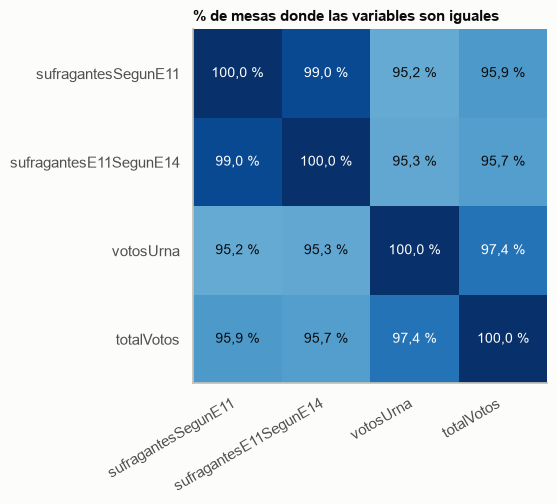

In [158]:
def porcentaje_coincidencia(tolerancia):
    return pd.DataFrame({
        a: {b: ((mesas[a] - mesas[b]).abs() <= tolerancia).mean() * 100 for b in VARS}
        for a in VARS
    })


coincidencia = porcentaje_coincidencia(0)

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.imshow(coincidencia.values, cmap='Blues', vmin=90, vmax=100)
ax.set_xticks(range(len(VARS)), VARS, rotation=30, ha='right')
ax.set_yticks(range(len(VARS)), VARS)
ax.grid(False)
for i in range(len(VARS)):
    for j in range(len(VARS)):
        valor = coincidencia.iloc[i, j]
        ax.text(j, i, porcentaje(valor), ha='center', va='center',
                color='white' if valor >= 96 else TINTA)
ax.set_title('% de mesas donde las variables son iguales')
plt.show()

**Tamaño de la diferencia:** se toma `sufragantesSegunE11` como referencia y se mide cuánto se desvía cada una de las otras tres variables.

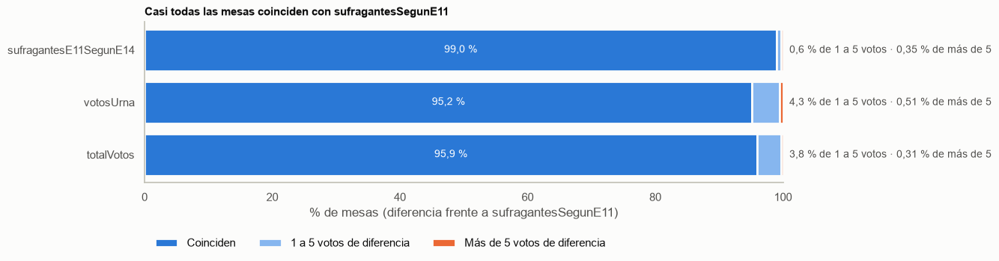

,sufragantesE11SegunE14,votosUrna,totalVotos
mayor que la referencia,0.45,1.39,0.00
igual,99.02,95.18,95.93
menor que la referencia,0.52,3.44,4.07


In [159]:
referencia = mesas['sufragantesSegunE11']
otras = VARS[1:]
dif = pd.DataFrame({v: (mesas[v] - referencia).abs() for v in otras})

grupos = pd.DataFrame({
    'Coinciden': dif.eq(0).mean(),
    '1 a 5 votos de diferencia': (dif.gt(0) & dif.le(5)).mean(),
    'Más de 5 votos de diferencia': dif.gt(5).mean(),
}) * 100

fig, ax = plt.subplots(figsize=(11, 2.8))
acumulado = pd.Series(0.0, index=grupos.index)
for columna, color in zip(grupos.columns, [AZUL, AZUL_CLARO, NARANJA]):
    ax.barh(grupos.index, grupos[columna], left=acumulado, color=color,
            edgecolor=FONDO, linewidth=2, label=columna)
    if columna == 'Coinciden':
        for y, valor in enumerate(grupos[columna]):
            ax.text(valor / 2, y, porcentaje(valor), ha='center', va='center', color='white')
    acumulado += grupos[columna]
for y, (leve, grave) in enumerate(zip(grupos.iloc[:, 1], grupos.iloc[:, 2])):
    ax.text(101, y, f'{porcentaje(leve)} de 1 a 5 votos · {porcentaje(grave, 2)} de más de 5',
            va='center', color=TINTA_SUAVE)

ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.grid(False)
ax.set_xlabel('% de mesas (diferencia frente a sufragantesSegunE11)')
ax.set_title('Casi todas las mesas coinciden con sufragantesSegunE11')
ax.legend(ncol=3, frameon=False, loc='upper left', bbox_to_anchor=(0, -0.28))
plt.show()

# Sentido de la diferencia (% de mesas)
pd.DataFrame({
    v: {
        'mayor que la referencia': (mesas[v] > referencia).mean() * 100,
        'igual': (mesas[v] == referencia).mean() * 100,
        'menor que la referencia': (mesas[v] < referencia).mean() * 100,
    }
    for v in otras
}).round(2)

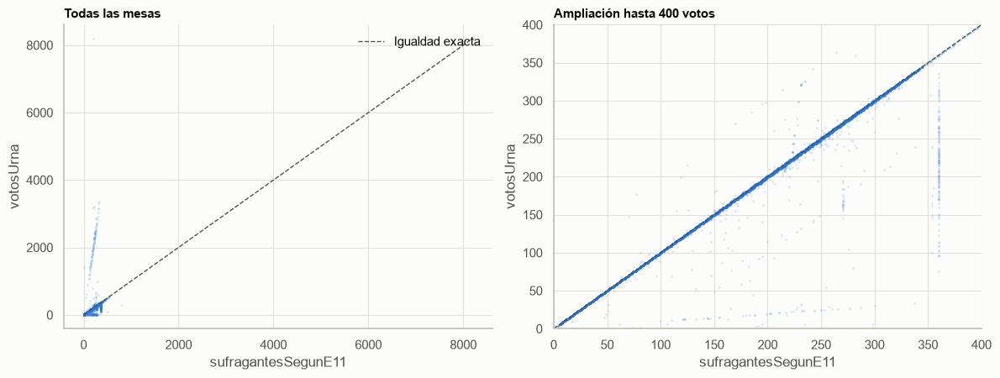

In [160]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, limite, titulo in [(ax1, None, 'Todas las mesas'), (ax2, 400, 'Ampliación hasta 400 votos')]:
    ax.scatter(mesas['sufragantesSegunE11'], mesas['votosUrna'],
               s=4, color=AZUL, alpha=0.15, linewidths=0, rasterized=True)
    tope = limite or mesas['votosUrna'].max()
    ax.plot([0, tope], [0, tope], color=TINTA_SUAVE, linestyle='--', linewidth=1)
    if limite:
        ax.set_xlim(0, limite)
        ax.set_ylim(0, limite)
    ax.grid(True, axis='both')
    ax.set_xlabel('sufragantesSegunE11')
    ax.set_ylabel('votosUrna')
    ax.set_title(titulo)

ax1.plot([], [], color=TINTA_SUAVE, linestyle='--', linewidth=1, label='Igualdad exacta')
ax1.legend(frameon=False, loc='upper right')
fig.tight_layout()
plt.show()

**Lectura:**
- Las cuatro variables son consistentes: frente a `sufragantesSegunE11`, coinciden exactamente en más del 95 % de las mesas y difieren en 5 votos o menos en más del 99 %. La mediana es 206 en todas.
- `sufragantesE11SegunE14` replica a `sufragantesSegunE11` (99 % iguales).
- `votosUrna` es la que más se desvía y tiene el máximo más alto de las cuatro (8.195); su suma total sube por esos valores extremos.
- `totalVotos` nunca supera a `sufragantesSegunE11` (salvo 2 mesas). Es compatible con que cuente solo una parte de los votantes, pero no está confirmado con la documentación.

#### 1.5. Transformaciones aplicadas (limpieza de los datos)

Criterios:
- Se trabaja sobre una copia (`df_clean`); `df` queda intacto para poder comparar.
- Los atípicos se identifican con un único criterio, el IQR sobre las cuatro columnas de votantes, y se **marcan** con la bandera `atipica_iqr` en lugar de excluirse. Una copia de las mesas marcadas se guarda en `df_atipicos`.
- Las inconsistencias entre conteos no modifican valores: solo se marcan con banderas.

##### 1.5.1 Normalización de texto

In [161]:
df_clean = df.copy()

# Espacios en los extremos y dobles, y minúsculas (solo puestoNombre presenta estos problemas)
df_clean['puestoNombre'] = (
    df_clean['puestoNombre']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
    .str.upper()
)

formato_clean = pd.DataFrame({
    'espacios_borde': {c: (df_clean[c] != df_clean[c].str.strip()).sum() for c in COLS_TEXTO},
    'espacios_dobles': {c: df_clean[c].str.contains('  ', regex=False).sum() for c in COLS_TEXTO},
    'con_minusculas': {c: (df_clean[c] != df_clean[c].str.upper()).sum() for c in COLS_TEXTO},
})
print('Problemas de formato restantes:', int(formato_clean.sum().sum()))

# Cada puesto debe seguir teniendo un único nombre
claves, nombre = JERARQUIA['puesto']
print('Puestos con más de un nombre:', int(df_clean.groupby(claves)[nombre].nunique().gt(1).sum()))

Problemas de formato restantes: 0
Puestos con más de un nombre: 0


##### 1.5.2 Tipos de datos

Las columnas de conteo pasan a enteros con soporte de nulos (`Int64`) y las columnas SI/NO a booleanas. Los códigos (departamento, municipio, zona, puesto, corporación) se mantienen como texto: tienen ceros a la izquierda y `puestoCodigo` incluye valores alfanuméricos (`A1`, `B2`, ...), como se verificó en el apartado 1.3 (efecto de leer todas las columnas como texto).

In [162]:
COLS_SI_NO = ['enTerminos', 'tachadurasEnmendaduras', 'recontadaJurados', 'recontadaComision', 'excluida']

df_clean[COLS_NUM] = df_clean[COLS_NUM].apply(pd.to_numeric).astype('Int64')

for col in COLS_SI_NO:
    assert df_clean[col].isin(['SI', 'NO']).all(), col
    df_clean[col] = df_clean[col].eq('SI')

df_clean['estadoSobre'] = df_clean['estadoSobre'].astype('category')
df_clean.dtypes.to_frame('tipo').T

,id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,...,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos
tipo,str,str,str,str,str,str,str,str,Int64,str,...,category,bool,bool,bool,bool,Int64,Int64,Int64,Int64,Int64


##### 1.5.3 Banderas de inconsistencia

Una diferencia entre conteos puede deberse a un error en cualquiera de las columnas, así que no se corrige ningún valor: solo se marcan.
- `urna_difiere_e11`: `votosUrna` y `sufragantesSegunE11` difieren en más de 50 votos.
- `total_mayor_urna` y `total_mayor_e14`: `totalVotos` supera a `votosUrna` o a `sufragantesE11SegunE14`.

In [163]:
df_clean['urna_difiere_e11'] = (df_clean['votosUrna'] - df_clean['sufragantesSegunE11']).abs() > 50
df_clean['total_mayor_urna'] = df_clean['totalVotos'] > df_clean['votosUrna']
df_clean['total_mayor_e14'] = df_clean['totalVotos'] > df_clean['sufragantesE11SegunE14']

COLS_BANDERAS = ['urna_difiere_e11', 'total_mayor_urna', 'total_mayor_e14']
print('Filas marcadas por bandera (antes de excluir atípicos):')
print(df_clean[COLS_BANDERAS].sum().to_string())

Filas marcadas por bandera (antes de excluir atípicos):
urna_difiere_e11    446
total_mayor_urna    343
total_mayor_e14     203


##### 1.5.4 Marcado de atípicos con IQR

Se marca con la bandera `atipica_iqr` toda mesa que quede fuera de los límites del IQR en al menos una de las cuatro columnas de votantes (`COLS_IQR`). Las mesas **no se excluyen**, por tres razones:

- El IQR se calcula sobre todo el conjunto, sin distinguir por `potencial`, así que marca mesas pequeñas legítimas (como la última mesa de cada puesto) y mesas grandes con potencial de 500 u 800 (ver la sección Escrutinio, 1.3).
- Entre ellas hay mesas con novedades, que son la variable objetivo del componente de clasificación.
- El componente de detección de anomalías busca precisamente mesas atípicas: si se eliminan antes, el modelo no las puede encontrar.

Las mesas marcadas también se guardan en `df_atipicos` para poder revisarlas.

In [164]:
es_atipica = pd.concat(
    [(df_num[col] < lo) | (df_num[col] > hi) for col, (lo, hi) in limites.items()],
    axis=1,
).any(axis=1)

df_clean['atipica_iqr'] = es_atipica
df_atipicos = df_clean[es_atipica]

print(f'Mesas marcadas como atípicas por IQR: {miles(len(df_atipicos))} ({porcentaje(len(df_atipicos) / len(df) * 100, 2)})')
print(f'Mesas en df_clean (se conservan todas): {miles(len(df_clean))}')

# Novedades que se habrían perdido si las mesas atípicas se excluyeran
marcadas = pd.DataFrame({
    'total': {k: int(v.sum()) for k, v in novedades.items()},
    'marcadas_atipicas': {k: int((v & es_atipica).sum()) for k, v in novedades.items()},
})
marcadas['% del total'] = (marcadas['marcadas_atipicas'] / marcadas['total'] * 100).round(1)
print('Mesas con alguna novedad entre las atípicas:', int((pd.concat(novedades, axis=1).any(axis=1) & es_atipica).sum()))
marcadas

Mesas marcadas como atípicas por IQR: 1.746 (1,48 %)
Mesas en df_clean (se conservan todas): 118.350
Mesas con alguna novedad entre las atípicas: 67


,total,marcadas_atipicas,% del total
Tachaduras o enmendaduras,1428,24,1.7
Recontada por jurados,651,2,0.3
Recontada por comisión,558,5,0.9
Sobre en mal estado,334,7,2.1
Mesa excluida,37,37,100.0
Fuera de términos,12,6,50.0


**Lectura:** se marcan 1.746 mesas (1,48 %), casi todas por tener menos de 22 votantes. Entre ellas hay 67 mesas con alguna novedad, incluidas las 37 con `excluida = SI` (100 %) y 6 de las 12 fuera de términos. Si se hubieran excluido, se perderían casos de la variable objetivo de la clasificación; por eso se conservan con la bandera `atipica_iqr`.

##### 1.5.5 Validación de la limpieza

In [165]:
print('Filas originales / en df_clean / marcadas como atípicas:',
      miles(len(df)), '/', miles(len(df_clean)), '/', miles(int(df_clean['atipica_iqr'].sum())))
print('id únicos:', df_clean['id'].is_unique)
print('Nulos en df_clean:', int(df_clean.isna().sum().sum()))
print('Rango de los conteos (los atípicos se conservan):')
display(df_clean[COLS_IQR].agg(['min', 'max']))
df_clean.head()

Filas originales / en df_clean / marcadas como atípicas: 118.350 / 118.350 / 1.746
id únicos: True
Nulos en df_clean: 0
Rango de los conteos (los atípicos se conservan):


,sufragantesSegunE11,votosUrna,sufragantesE11SegunE14,totalVotos
min,0,0,0,0
max,800,8195,3025,546


,id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,...,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos,urna_difiere_e11,total_mayor_urna,total_mayor_e14,atipica_iqr
0,010100101011,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA NO 2,1,001,...,False,6,128,0,128,127,False,False,False,False
1,010100101012,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA NO 2,2,001,...,False,6,65,0,65,65,False,False,False,False
2,010100101013,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA NO 2,3,001,...,False,6,107,0,107,107,False,False,False,False
3,010100101014,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA NO 2,4,001,...,False,6,143,0,143,143,False,False,False,False
4,010100101015,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA NO 2,5,001,...,False,6,177,0,177,177,False,False,False,False


#### 1.6. Documentación de las decisiones tomadas

##### 1.6.1 Registro de decisiones

| # | Hallazgo | Filas | Decisión | Justificación | Alternativa descartada |
|---|---|---|---|---|---|
| 1 | Coma sin comillas en `puestoNombre` del CSV (error de carga) | 45 | Reunir los campos sobrantes con `on_bad_lines` | Las filas son válidas; solo les falta el entrecomillado del campo | Descartar las filas con `on_bad_lines='skip'` (se perderían mesas) |
| 2 | Valores faltantes | 0 | Ninguna | No hay nulos ni cadenas vacías | — |
| 3 | Duplicados (fila, `id` o mesa) | 0 | Ninguna | Cada fila es una mesa única | — |
| 4 | `puestoNombre` con espacios en los extremos, espacios dobles y minúsculas | 21 / 1251 / 535 | Quitar espacios y pasar a mayúsculas | Unifica el formato sin cambiar el significado | Dejarlo igual (dificultaría agrupar por puesto) |
| 5 | Conteos y SI/NO como texto; `puestoCodigo` con valores alfanuméricos | todas | Conteos a `Int64`, SI/NO a booleano, códigos como texto | Permite operar sin perder ceros a la izquierda ni códigos como `A1` | Convertir los códigos a entero |
| 6 | Atípicos por IQR en las 4 columnas de votantes (límites 22 a 382) | 1.746 (1,48 %) | Marcar con la bandera `atipica_iqr` y conservar (copia en `df_atipicos`) | Son mesas reales (pequeñas o con potencial mayor), incluyen 67 mesas con novedades y son el insumo de la detección de anomalías | Excluirlas de `df_clean` (se perderían, entre otras, las 37 mesas excluidas) |
| 7 | `potencial` y `votosIncinerados` | — | No se les aplica IQR | Su IQR es 0 (casi un solo valor) y marcaría 1.328 y 2.112 mesas legítimas | Aplicar el IQR a todas las columnas numéricas |
| 8 | `votosUrna` difiere de `sufragantesSegunE11` en más de 50 votos | 446 | Solo bandera `urna_difiere_e11` | No se puede saber cuál de los dos conteos es el correcto | Imputar o anular uno de los dos |
| 9 | `totalVotos` > `votosUrna` o > `sufragantesE11SegunE14` | 343 / 203 | Solo banderas `total_mayor_urna` y `total_mayor_e14` | Puede deberse a un error en cualquiera de las columnas | Corregir `totalVotos` |
| 10 | Mesas con alguna novedad (tachaduras, recuentos, sobre en mal estado, excluida, fuera de términos) | 2.898 | Se conservan todas | Son las novedades que estudia este conjunto | Excluir las 67 que caen en el IQR |
| 11 | Id, jerarquía territorial y relación `excluida` / `totalVotos` | 0 | Ninguna | Son coherentes | — |

##### 1.6.2 Supuestos y limitaciones

- Se asume que `sufragantesSegunE11`, `votosUrna` y `sufragantesE11SegunE14` deberían coincidir o ser muy cercanas. No está contrastado con la documentación de los formularios E-11 y E-14; si miden cosas distintas, las banderas 8 y 9 deben revisarse.
- El IQR se calcula sobre todo el conjunto, sin distinguir por `potencial`. Una mesa con muy poca asistencia, o una mesa grande (`potencial` 500, 800 o 1.200) con más de 382 votos, puede quedar marcada sin ser un error; por eso los atípicos se marcan y no se excluyen.
- La mayoría de los atípicos (cola inferior) son mesas con menos de 22 votantes. No se verificó si son errores o participación real muy baja.
- El umbral de 50 votos de `urna_difiere_e11` es arbitrario.
- Las mesas marcadas como atípicas siguen en `df_clean` (con `atipica_iqr = True`) y se copian en `df_atipicos`.

##### 1.6.3 Comparación antes y después

In [166]:
def resumen_estado(datos):
    return {
        'filas': len(datos),
        'columnas': datos.shape[1],
        'nulos': int(datos.isna().sum().sum()),
        'máx. votosUrna': int(datos['votosUrna'].max()),
    }


pd.DataFrame({
    'df (original)': resumen_estado(df_num.join(df.drop(columns=COLS_NUM))),
    'df_clean': resumen_estado(df_clean),
}).T

,filas,columnas,nulos,máx. votosUrna
df (original),118350,24,0,8195
df_clean,118350,28,0,8195


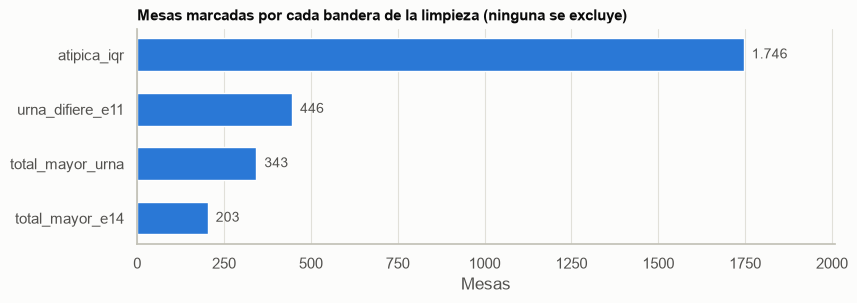

In [167]:
tratamientos = df_clean[COLS_BANDERAS + ['atipica_iqr']].sum().sort_values()

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(tratamientos.index, tratamientos.values, height=0.6, color=AZUL)
for y, n in enumerate(tratamientos.values):
    ax.text(n, y, f'  {miles(n)}', va='center', color=TINTA_SUAVE)
ax.set_xlim(0, tratamientos.max() * 1.15)
ax.set_xlabel('Mesas')
ax.set_title('Mesas marcadas por cada bandera de la limpieza (ninguna se excluye)')
plt.show()

## **3. Preconteo**
---

El entendimiento detallado del preconteo se presentó en la Parte II. Esta sección aplica la limpieza sobre la tabla `df_preconteo` construida allí.

### 1. Limpieza de los Datos

La preparación de los datos de preconteo electoral se desarrolla siguiendo la metodología CRISP-DM, con el propósito de garantizar la calidad, integridad y consistencia de la información utilizada en las etapas posteriores de aprendizaje automático. Debido a la naturaleza de los registros electorales, se prioriza la conservación de la información original, la trazabilidad de las transformaciones y la diferenciación entre errores de calidad y comportamientos estadísticamente anómalos.

**1. ¿Cuáles fueron los criterios utilizados para identificar y tratar valores atípicos, datos faltantes o cualquier otra anomalía en el conjunto de datos durante el proceso de limpieza?**

Se establecieron criterios de calidad basados en la **completitud, unicidad, consistencia estructural, validez e integridad de los registros electorales**. Para identificar valores faltantes se inspeccionaron las 11 variables del preconteo mediante la detección de valores nulos y cadenas vacías, obteniéndose un porcentaje de ausencia del 0 %. Adicionalmente, se verificó la cobertura de opciones electorales por mesa, lo que permitió identificar dos formatos de transmisión que requirieron estandarización (sección 1.4).

Para los demás problemas de calidad se contemplaron verificaciones de duplicidad mediante claves electorales compuestas, validaciones de longitud y formato de los registros, y análisis estadísticos de las cantidades de votos para identificar observaciones extremas.

Como criterio general, se decidió evitar la eliminación o modificación automática de registros atípicos, debido a que estos podrían representar comportamientos electorales legítimos o situaciones relevantes para los objetivos de detección de anomalías. Cualquier transformación deberá estar respaldada por reglas de validación y evidencia verificable.

**2. ¿Cómo se justificaría la necesidad de cada paso de preprocesamiento en términos de mejora de la calidad de los datos y preparación para el análisis subsiguiente?**

Cada procedimiento responde a la necesidad de construir un conjunto de datos confiable, reproducible y adecuado para los modelos de clasificación, regresión y detección de anomalías planteados en el proyecto.

La identificación de valores faltantes permite evaluar la completitud de la información; la verificación de duplicados busca evitar posibles sobreestimaciones en los conteos de votos; y la validación de formatos y códigos electorales garantiza la correcta identificación de las mesas y facilita su integración con otras fuentes oficiales.

Por otra parte, el análisis de valores atípicos permite distinguir posibles errores de observaciones excepcionales que deben conservarse para su posterior evaluación. Asimismo, mantener los identificadores electorales como cadenas de caracteres evita la pérdida de ceros a la izquierda, mientras que la agregación de registros a nivel de mesa permite establecer una unidad de análisis consistente con los objetivos de investigación.

En conjunto, estas decisiones buscan **mejorar la calidad de los datos sin alterar injustificadamente los resultados electorales**, preservar la representatividad de las observaciones y reducir el riesgo de introducir sesgos durante el preprocesamiento.

#### 1.1. Valores faltantes

In [168]:
# Diagnóstico de valores faltantes del preconteo

df = df_preconteo.copy()

reporte = []

for columna in df.columns:
    serie = df[columna]

    nulos = serie.isna().sum()

    if pd.api.types.is_string_dtype(serie):
        vacios = (
            serie.str.strip()
            .eq("")
            .fillna(False)
            .sum()
        )
    else:
        vacios = 0

    reporte.append({
        "Variable": columna,
        "Nulos": int(nulos),
        "Cadenas vacías": int(vacios),
        "Total faltantes": int(nulos + vacios),
        "Porcentaje (%)": round(
            100 * (nulos + vacios) / len(df), 4
        )
    })

reporte_faltantes = pd.DataFrame(reporte)

display(reporte_faltantes)

print(
    "Total de registros:",
    f"{len(df):,}"
)

,Variable,Nulos,Cadenas vacías,Total faltantes,Porcentaje (%)
0,departamento,0,0,0,0.0
1,municipio,0,0,0,0.0
2,zona,0,0,0,0.0
3,puesto,0,0,0,0.0
4,mesa,0,0,0,0.0
5,jal,0,0,0,0.0
6,comunicado,0,0,0,0.0
7,circunscripcion,0,0,0,0.0
8,lista_partido,0,0,0,0.0
9,candidato,0,0,0,0.0


Total de registros: 1,479,506


##### Análisis y tratamiento de valores faltantes

Se realizó un diagnóstico de valores faltantes sobre las 11 variables del conjunto de datos de preconteo electoral, considerando tanto los valores nulos (`NaN` o `None`) como las cadenas vacías o compuestas únicamente por espacios.

Los resultados evidenciaron que ninguna de las variables presenta valores faltantes, obteniéndose un porcentaje del **0 % en todas las columnas**. En consecuencia, no fue necesario aplicar técnicas de imputación estadística ni eliminar observaciones por ausencia de información.

**1. ¿Cómo afectan estos valores a la integridad y representatividad de la información?**

Los valores faltantes pueden comprometer la integridad de los registros electorales, especialmente cuando afectan identificadores territoriales, códigos de candidatos o cantidades de votos. Su presencia podría dificultar la identificación de las mesas, alterar las agregaciones y generar sesgos en los análisis posteriores. Sin embargo, el diagnóstico realizado sobre las 11 variables del preconteo evidenció un **0 % de valores faltantes**, por lo que no se identificaron afectaciones de este tipo en los registros analizados. Este resultado no implica necesariamente que estén representadas todas las combinaciones posibles de mesa y opción electoral.

**2. ¿Cómo se identificaron los valores faltantes en el conjunto de datos?**

Se realizó una inspección sistemática de las 11 variables mediante Python y la biblioteca `pandas`. Se utilizó el método `isna()` para identificar valores nulos y `str.strip()` para detectar cadenas vacías o compuestas únicamente por espacios. Posteriormente, se calcularon las frecuencias absolutas y relativas de valores faltantes por variable. Los resultados mostraron **cero valores nulos y cero cadenas vacías en todas las columnas**, equivalentes al 0 % del conjunto de datos.

**3. ¿Cuáles fueron los criterios para decidir si rellenar con valores estimados o eliminar los valores faltantes? En caso de aplicar, ¿qué método se utilizó y por qué?**

Se estableció como criterio preservar la información electoral original y evitar imputaciones que pudieran modificar artificialmente los resultados. En particular, los identificadores territoriales y electorales no deben reemplazarse mediante estimaciones estadísticas, dado que representan códigos oficiales. Asimismo, la ausencia de un registro no debe interpretarse automáticamente como cero votos sin verificar las reglas de representación de la fuente. Debido a que no se identificaron valores faltantes, **no fue necesario aplicar técnicas de imputación ni eliminar registros**.

**4. ¿Se realizó un análisis de la distribución de los valores faltantes en relación con las variables clave? ¿Cómo podría afectar su presencia la interpretación de los resultados?**

Se evaluó la distribución de valores faltantes por columna, incluyendo las variables críticas `departamento`, `municipio`, `zona`, `puesto`, `mesa`, `candidato` y `votos`. Todas presentaron un porcentaje de faltantes del 0 %, por lo que no se identificó concentración de valores ausentes en ninguna variable. En consecuencia, no fue necesario realizar análisis adicionales de patrones de ausencia entre variables. No obstante, como la ausencia de registros completos de determinadas mesas u opciones electorales no puede detectarse únicamente con `isna()`, se evaluó mediante controles de cobertura, cuyos resultados se presentan en el análisis complementario.

Se decidió conservar la totalidad de los registros y mantener los identificadores territoriales y electorales como cadenas de caracteres, evitando alteraciones en los códigos que contienen ceros a la izquierda.

Es importante señalar que la ausencia de valores nulos no garantiza que estén representadas todas las combinaciones posibles de mesa y opción electoral. Por tanto, la completitud estructural del conjunto de datos se diferencia de la cobertura de los registros electorales, que requiere validaciones adicionales.

Esta decisión permite preservar la integridad de la información original y evita introducir valores artificiales que podrían afectar los análisis posteriores de anomalías electorales.

**Análisis complementario de cobertura y completitud estructural**

Aunque el diagnóstico de valores faltantes evidenció un 0 % de valores nulos y cadenas vacías en las 11 variables, este resultado no garantiza la completitud estructural del conjunto de datos. El análisis de cobertura identificó **61.623 mesas (50,50 %) con menos de 16 opciones electorales registradas**, lo que evidencia diferencias en la cantidad de registros disponibles por mesa.

El análisis exploratorio permitió explicar el origen de estas ausencias: **no se distribuyen al azar, sino que dependen del departamento**. En unos departamentos las mesas traen las 16 filas, incluidas las opciones con cero votos; en otros solo aparecen las opciones que recibieron votos. El 100 % de las mesas con 16 filas tiene al menos un cero explícito, frente al 2,9 % de las mesas con menos filas. Además, el archivo de escrutinio contiene exactamente 1.952.320 filas, es decir, 122.020 mesas × 16 opciones, lo que confirma que el universo esperado es de 16 opciones por mesa.

Por tanto, las filas ausentes no corresponden a información perdida ni a errores de captura, sino a **ceros implícitos** de un formato de transmisión distinto. Como esta conclusión se apoya en evidencia y no en un supuesto, sí es posible tratarlas como cero votos, siempre que se conserve la marca de cuáles ceros fueron completados.

Se decidió conservar el archivo original intacto y tratar esta diferencia como una **inconsistencia de formato** (sección 1.4). Allí se construye una versión estandarizada con las 16 opciones por mesa y una variable indicadora `cero_implicito`, que distingue los ceros escritos en el archivo de los ceros completados. Completar con cero no altera la suma de votos, que se verifica explícitamente.

En consecuencia, se distingue entre **completitud de atributos**, verificada mediante la ausencia de valores nulos, y **completitud estructural**, relacionada con la cobertura de las combinaciones electorales esperadas. Esta distinción permite preservar la trazabilidad del conjunto de datos y reconocer las limitaciones que deberán considerarse durante las siguientes fases del análisis.

#### 1.2. Valores duplicados

Se realizó una evaluación de duplicidad sobre los **1.479.506 registros del preconteo electoral**, considerando tanto la repetición exacta de registros como la duplicidad lógica definida mediante identificadores territoriales y electorales. El objetivo fue verificar la unicidad de las observaciones sin eliminar información legítima correspondiente a distintas opciones electorales de una misma mesa.

**1. ¿Cómo se identificaron y manejaron los valores duplicados en el conjunto de datos?**

La identificación se realizó mediante dos procedimientos complementarios. Primero, se inspeccionó el archivo original de ancho fijo para detectar registros exactamente iguales, obteniéndose cero duplicados. Posteriormente, utilizando Python y `pandas`, se aplicó el método `duplicated()` sobre una clave compuesta candidata formada por departamento, municipio, zona, puesto, mesa, JAL, comunicado, circunscripción, lista o partido y candidato. Esta verificación tampoco identificó registros duplicados. En consecuencia, no fue necesario eliminar ni consolidar observaciones.

**2. ¿Hubo alguna consideración especial al tratar duplicados en función de ciertas variables?**

Sí. Se consideró especialmente la granularidad de los registros electorales, debido a que una misma mesa puede contener múltiples observaciones correspondientes a diferentes opciones de votación. Por tanto, la repetición de identificadores territoriales o del número de mesa no constituye por sí misma una duplicidad. Se utilizaron claves compuestas que incorporan tanto la identificación territorial como los códigos electorales, evitando clasificar incorrectamente registros legítimos como duplicados.

**3. ¿Pueden estos duplicados sesgar el análisis, y en qué medida?**

La presencia de duplicados podría generar sobreestimaciones en los totales de votos, alterar las distribuciones por candidatura y territorio e introducir distorsiones en los indicadores utilizados durante el análisis estadístico y el modelado posterior. La magnitud del sesgo dependería de la cantidad, distribución y características de los registros repetidos. Sin embargo, las verificaciones realizadas identificaron **cero duplicados exactos y cero duplicados bajo la clave compuesta candidata**, por lo que no se evidenció sesgo atribuible a estas formas de duplicidad en el conjunto analizado.

**4. ¿Se justifica la eliminación de duplicados para mantener la coherencia y singularidad de los datos?**

La eliminación estaría justificada únicamente cuando se demostrara que dos o más registros representan indebidamente la misma observación electoral. No sería adecuado eliminar registros por compartir identificadores de mesa, dado que pueden corresponder a opciones electorales diferentes. Como no se identificaron duplicados mediante los criterios establecidos, se decidió conservar la totalidad de las observaciones, preservando la integridad y trazabilidad de la información original.

**5. ¿Cómo se aseguró de que la eliminación de duplicados no afectara negativamente la representación del conjunto de datos?**

Dado que no fue necesario eliminar registros, la representación original del conjunto de datos permaneció intacta. La verificación de unicidad se realizó mediante procedimientos de diagnóstico que no modificaron el DataFrame. Adicionalmente, se identificaron **122.020 mesas únicas**, con un promedio de 12,13 registros por mesa, confirmando que la existencia de múltiples registros asociados a una misma mesa responde a la granularidad del conjunto de datos y no necesariamente a duplicaciones.

En conclusión, las verificaciones realizadas proporcionan evidencia favorable sobre la unicidad de los registros bajo los criterios examinados. No obstante, la clave compuesta utilizada se considera candidata y su correspondencia con la identificación oficial de cada observación debe mantenerse sujeta a validación documental.

In [169]:
# 1.2 Evidencia: duplicados exactos y lógicos
n_mesas_unicas = df_preconteo[columnas_mesa].drop_duplicates().shape[0]

evidencia_duplicados = pd.DataFrame({
    "Verificación": [
        "Líneas idénticas en el archivo original",
        "Duplicados por clave candidata de 10 campos",
        "Duplicados por combinación mesa-opción",
    ],
    "Cantidad": [
        duplicados_exactos,
        int(df_preconteo.duplicated(subset=columnas_clave_candidata).sum()),
        int(df_preconteo.duplicated(subset=columnas_mesa + ["lista_partido", "candidato"]).sum()),
    ],
})
display(evidencia_duplicados)

print(f"Mesas únicas: {n_mesas_unicas:,}")
print(f"Registros por mesa (promedio): {len(df_preconteo) / n_mesas_unicas:.2f}")


,Verificación,Cantidad
0,Líneas idénticas en el archivo original,0
1,Duplicados por clave candidata de 10 campos,0
2,Duplicados por combinación mesa-opción,0


Mesas únicas: 122,020
Registros por mesa (promedio): 12.13


#### 1.3. Valores atípicos

Se realizó un análisis exploratorio de valores extremos en el conjunto de datos de preconteo electoral, considerando la distribución de votos por registro, las diferencias entre candidaturas y las sumas de votos por mesa electoral. El objetivo fue identificar observaciones estadísticamente inusuales y determinar si correspondían a posibles errores de calidad o a comportamientos que requieren contextualización.

**1. ¿Son errores de medición o representan información válida pero excepcional?**

Los valores extremos identificados no pueden clasificarse automáticamente como errores de medición. La distribución de votos presenta una marcada asimetría positiva, con una concentración de observaciones en valores pequeños y una extensión hacia cantidades elevadas. Asimismo, se identificaron 527.421 registros con cero votos, equivalentes al 35,648 % del conjunto de datos. Este porcentaje debe leerse con cautela: como cerca de la mitad de las mesas omite las filas con cero votos (ver 1.4), la proporción de ceros refleja en parte el formato de transmisión y no solo el comportamiento electoral. En la versión estandarizada de 16 opciones por mesa hay 1.000.235 ceros (1.952.320 filas menos 952.085 registros positivos), es decir, el 51,2 %.

En el análisis agregado por mesa se observó un máximo de 942 votos registrados. Las diez mesas con mayores sumas pertenecen al código departamental `88`, correspondiente a consulados y votación en el exterior, según la contextualización realizada mediante DIVIPOL.

En el extremo inferior se identificaron **15 mesas cuya suma total de votos es cero**. Las diez de menor suma tienen una única opción registrada, con cero votos, y se ubican en el departamento `17` y en consulados (departamento `88`). Estas mesas no pueden explicarse por el formato de transmisión, ya que incluso en el formato que omite las opciones sin votos se esperaría al menos una fila con votos. Por ello se consideran observaciones que requieren verificación, ya sea porque no se instalaron, no recibieron votantes o no transmitieron resultados en el preconteo.

Estos resultados sugieren que los valores extremos pueden estar asociados a diferencias territoriales, operativas o de comportamiento electoral. Sin embargo, su validez individual no ha sido confirmada mediante una verificación externa, por lo que deben considerarse observaciones que requieren análisis adicional y no errores demostrados.

**2. ¿Qué criterios o técnicas se utilizaron para identificar los valores atípicos?**

Se utilizaron criterios estadísticos descriptivos basados en medidas de tendencia central, dispersión y posición, incluyendo media, mediana, desviación estándar, valores mínimos y máximos, cuartiles y percentiles.

El análisis se desarrolló en tres niveles: registros individuales de votos, distribuciones por candidatura y sumas de votos por mesa electoral.

Para la variable `votos`, el percentil 75 fue de ocho votos, mientras que los percentiles 95 y 99 correspondieron a 104 y 164 votos, respectivamente. Estos resultados permitieron caracterizar la asimetría de la distribución e identificar su cola superior.

Adicionalmente, se examinó la cantidad de opciones electorales registradas por mesa, cuya distribución presentó valores entre 1 y 16, con el propósito de contextualizar diferencias de cobertura.

Como referencia adicional, se aplicó la regla de 1,5 veces el rango intercuartílico sobre la suma de votos por mesa (celda siguiente), únicamente para cuantificar cuántas mesas quedan fuera del rango y dónde se ubican, no para excluirlas. Con esta regla, el rango esperado fue de 14 a 386 votos por mesa, y **1.508 mesas (1,24 %) quedaron fuera de él**: 1.103 por debajo del límite inferior y 405 por encima del superior. Los consulados concentran 736 de estas mesas, y en particular **353 de las 405 mesas por encima del límite (87 %)**, lo que confirma que los valores altos responden sobre todo a la organización de la votación en el exterior y no a errores de captura. En el territorio nacional predominan las mesas por debajo del límite (720), lo que es coherente con la existencia de puestos pequeños y con las mesas de suma cero descritas en la respuesta 1.

Los percentiles se utilizaron como referencias descriptivas y no como umbrales automáticos para eliminar observaciones.

**3. ¿Se aplicaron métodos estadísticos o visuales para detectar los valores atípicos?**

Sí. Se aplicaron estadísticas descriptivas mediante Python, utilizando `pandas` y sus métodos `describe()`, `quantile()`, `mean()`, `median()` y `std()`.

También se emplearon histogramas y diagramas de caja (*boxplots*) para visualizar la distribución de registros por mesa, la dispersión de votos entre candidaturas y las diferencias en las sumas de votos según la cantidad de opciones electorales presentes.

En la comparación por candidatura se utilizó una escala logarítmica simétrica para facilitar la visualización de distribuciones con magnitudes diferentes.

Los diagramas de caja permitieron examinar la dispersión de los datos; sin embargo, algunas visualizaciones se generaron con `showfliers=False`, por lo que los puntos extremos no se mostraron individualmente. Su análisis se complementó con estadísticas descriptivas, percentiles e inspección de las mesas con mayores y menores sumas de votos.

**4. ¿Cuál fue la decisión final sobre cómo tratar los valores atípicos y por qué?**

Se decidió conservar los valores extremos identificados, sin aplicar eliminación, imputación, truncamiento o transformación irreversible durante esta etapa de limpieza.

Esta decisión se fundamenta en que una observación estadísticamente inusual no constituye necesariamente un error de calidad ni una irregularidad electoral. Eliminar valores extremos sin verificar su naturaleza podría modificar artificialmente las distribuciones, reducir la representatividad territorial y excluir comportamientos relevantes para el objetivo del proyecto.

Adicionalmente, las diferencias observadas entre candidaturas y territorios indican que la identificación posterior de anomalías deberá considerar grupos de comparación apropiados, en lugar de utilizar exclusivamente umbrales globales.

En consecuencia, los valores extremos se conservarán para su análisis posterior, manteniendo la trazabilidad de los registros originales. Su eventual clasificación como anomalías requerirá criterios adicionales de consistencia, contextualización territorial y validación con información oficial.

**Conclusión**

El análisis permitió identificar distribuciones asimétricas y observaciones extremas cuya interpretación depende de la granularidad electoral y del contexto territorial. No se encontraron evidencias suficientes para justificar su eliminación automática. Por tanto, se priorizó la conservación de la información original y la diferenciación entre valores estadísticamente atípicos, errores de calidad y posibles anomalías electorales.

In [170]:
# 1.3 Evidencia: valores extremos por registro y por mesa
display(
    resumen_votos.loc[["Mínimo", "Mediana", "Percentil 75", "Percentil 95",
                       "Percentil 99", "Máximo", "Porcentaje de ceros"]]
    .to_frame("Votos por registro").round(2)
)

suma_mesa = resumen_mesas_territorio["suma_votos_registrados"]
q1, q3 = suma_mesa.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

fuera_rango = resumen_mesas_territorio[
    (suma_mesa < limite_inferior) | (suma_mesa > limite_superior)
].assign(
    ambito=lambda d: np.where(d["departamento"].eq("88"), "Consulados", "Territorio nacional"),
    lado=lambda d: np.where(d["suma_votos_registrados"] > limite_superior, "Superior", "Inferior"),
)

print(f"Regla 1,5×IQR sobre votos por mesa: [{limite_inferior:.0f}, {limite_superior:.0f}]")
print(f"Mesas fuera del rango: {len(fuera_rango):,} ({100 * len(fuera_rango) / len(suma_mesa):.2f} %)")
display(fuera_rango.groupby(["ambito", "lado"]).size().rename("mesas").to_frame())

top_mesas = resumen_mesas_territorio.nlargest(10, "suma_votos_registrados")[
    columnas_mesa + ["nombre_departamento", "nombre_municipio",
                     "opciones_presentes", "suma_votos_registrados"]
]
display(top_mesas)
print("De las 10 mesas con más votos, en consulados (departamento 88):",
      int(top_mesas["departamento"].eq("88").sum()))


,Votos por registro
Mínimo,0.00
Mediana,1.00
Percentil 75,8.00
Percentil 95,104.00
Percentil 99,164.00
Máximo,694.00
Porcentaje de ceros,35.65


Regla 1,5×IQR sobre votos por mesa: [14, 386]
Mesas fuera del rango: 1,508 (1.24 %)


mesas
ambito              lado           
Consulados          Inferior    383
                    Superior    353
Territorio nacional Inferior    720
                    Superior     52

,departamento,municipio,zona,puesto,mesa,nombre_departamento,nombre_municipio,opciones_presentes,suma_votos_registrados
120275,88,360,35,81,000001,CONSULADOS,ESTADOS UNIDOS,8,942
120760,88,360,57,85,000001,CONSULADOS,ESTADOS UNIDOS,16,663
119677,88,355,05,85,000009,CONSULADOS,ESPAÑA,16,639
120758,88,360,57,83,000001,CONSULADOS,ESTADOS UNIDOS,16,635
120679,88,360,55,84,000001,CONSULADOS,ESTADOS UNIDOS,9,625
120830,88,360,59,81,000003,CONSULADOS,ESTADOS UNIDOS,16,615
120503,88,360,40,83,000007,CONSULADOS,ESTADOS UNIDOS,16,603
118924,88,285,05,84,000001,CONSULADOS,COSTA RICA,9,597
118925,88,285,05,85,000001,CONSULADOS,COSTA RICA,10,596
120759,88,360,57,84,000001,CONSULADOS,ESTADOS UNIDOS,16,593


De las 10 mesas con más votos, en consulados (departamento 88): 10


#### 1.4. Datos inconsistentes

Se evaluó la consistencia estructural, semántica y territorial del conjunto de datos de preconteo electoral, tomando como referencia la documentación técnica del formato de almacenamiento y los catálogos auxiliares disponibles. El análisis permitió distinguir entre errores potenciales, representaciones válidas de códigos administrativos y diferencias de nomenclatura entre fuentes.

**1. ¿Cómo se identificaron las inconsistencias en los datos?**

Se implementaron verificaciones mediante Python y `pandas`, examinando la longitud de los registros, los tipos de campo, los dominios de las variables y la correspondencia de los identificadores territoriales con DIVIPOL.

El perfilamiento de 1.479.506 registros confirmó que todos tenían la longitud esperada de 38 caracteres, sin registros vacíos ni duplicados exactos.

Adicionalmente, se identificaron 12.517 registros con caracteres alfabéticos, equivalentes aproximadamente al 0,85 % del conjunto de datos. Su inspección permitió establecer que dichos caracteres aparecían exclusivamente en las posiciones correspondientes al campo `Puesto`, definido oficialmente como alfanumérico. Por tanto, no constituyen inconsistencias por sí mismos.

**2. ¿Las inconsistencias son lo suficientemente significativas como para justificar una estandarización?**

Sí. La inconsistencia más importante es de **formato de transmisión**: el preconteo combina dos formatos según el departamento. En uno, cada mesa trae las 16 opciones, incluidas las de cero votos; en el otro, solo las opciones que recibieron votos. Por eso 61.623 mesas (50,50 %) tienen menos de 16 filas. Si no se estandariza, cualquier conteo de filas, proporción de ceros o promedio por opción mezcla dos representaciones distintas del mismo fenómeno, y el número de filas por mesa termina separando departamentos en lugar de resultados electorales.

Además, se identificaron diferencias de representación durante la integración de información electoral y cartográfica.

Aunque no se evidenciaron errores generalizados en la estructura física del archivo, se encontraron diferencias entre las denominaciones territoriales utilizadas por las fuentes. Por ejemplo, `VALLE` frente a `VALLE DEL CAUCA`, y `NORTE DE SAN` frente a `NORTE DE SANTANDER`.

Estas diferencias no necesariamente representan errores en las fuentes originales, pero dificultan la correspondencia automática de registros y pueden generar pérdidas de información durante las operaciones de integración.

Por ello, se consideró necesario normalizar las claves utilizadas para relacionar conjuntos de datos, conservando los valores originales para mantener su trazabilidad.

**3. ¿Cómo se pueden homogeneizar unidades y formatos para garantizar coherencia en el análisis?**

La homogeneización se realizó de acuerdo con la naturaleza de cada variable.

Los identificadores administrativos y electorales se trataron como variables categóricas, preservando los ceros iniciales y los caracteres alfanuméricos válidos. En la tabla principal (`df_preconteo`) los códigos conservan exactamente la longitud del archivo original (por ejemplo, `zona` con 2 caracteres), la misma que usa DIVIPOL, por lo que no fue necesario rellenarlos para el cruce territorial. En la carga reutilizada de la Fase 1 (`precon`), `zona` se rellena a 3 caracteres para unificarla con escrutinio y novedades. Ambas tablas provienen del mismo archivo y contienen los mismos 1.479.506 registros.

Los votos se interpretaron como cantidades numéricas discretas, expresadas en una unidad común: número de votos por opción electoral y mesa.

Para integrar información cartográfica, se implementó una función de normalización de nombres territoriales que convierte el texto a mayúsculas, elimina espacios innecesarios y normaliza caracteres acentuados mediante Unicode. Posteriormente, se aplicaron equivalencias explícitas entre denominaciones territoriales.

Estas transformaciones permitieron construir claves de correspondencia homogéneas sin reemplazar los nombres originales de las fuentes.

**4. ¿Qué estrategias se implementaron para abordar las inconsistencias y asegurar la coherencia?**

Se aplicaron estrategias de validación y estandarización orientadas a preservar la información original.

Primero, se verificó la estructura del archivo de ancho fijo y se interpretaron sus campos conforme a la documentación oficial. Segundo, se conservaron los códigos alfanuméricos válidos, evitando conversiones numéricas que pudieran alterar los identificadores.

Tercero, se utilizaron catálogos electorales para contextualizar los códigos administrativos y se realizó una validación de integridad referencial con DIVIPOL. Esta comprobación identificó correspondencia para las 122.020 mesas electorales y los 14.438 puestos únicos registrados, sin claves territoriales sin correspondencia.

Cuarto, se construyeron claves normalizadas y equivalencias territoriales para integrar la información electoral con la cartografía departamental.

Finalmente, para resolver la coexistencia de los dos formatos, se construyó `df_preconteo_estandar`: una tabla con las 16 opciones para cada una de las 122.020 mesas, donde las combinaciones ausentes se completan con cero votos y se marcan con `cero_implicito = True`. Se agrega también la variable `formato` de cada mesa. El archivo original no se modifica. En total se completaron **472.814 ceros implícitos**, que sumados a los 527.421 ceros explícitos dan 1.000.235 ceros en la versión estandarizada (51,2 % de 1.952.320 filas), mientras que la suma total de votos se mantiene en 23.978.304.

**5. ¿Se establecieron reglas de validación específicas para garantizar la consistencia?**

Sí. Se implementaron las siguientes comprobaciones:

- **Consistencia estructural:** verificación de la longitud de 38 caracteres por registro y de las restricciones de los campos definidas en la documentación técnica.
- **Consistencia de tipos:** diferenciación entre identificadores categóricos, campos alfanuméricos y cantidades numéricas de votos.
- **Unicidad:** identificación de registros duplicados mediante claves compuestas territoriales y electorales.
- **Integridad referencial:** correspondencia de las claves de departamento, municipio, zona y puesto con el catálogo DIVIPOL.
- **Consistencia de integración:** comprobación de equivalencias entre denominaciones territoriales de las fuentes electorales y cartográficas, mediante verificaciones programáticas.
- **Completitud por mesa tras la estandarización:** cada mesa tiene exactamente 16 opciones, la suma de votos es idéntica a la del archivo original y el número de filas no completadas coincide con 1.479.506.
- **Consistencia de agregaciones:** validación de que los porcentajes de votos por candidatura sumaran aproximadamente el 100 % dentro de cada departamento, utilizando una tolerancia numérica de 99,999 % a 100,001 %.

Estas verificaciones proporcionan evidencia sobre la coherencia estructural, territorial y analítica del conjunto de datos. Sin embargo, no garantizan por sí mismas la exactitud de todos los valores de votos frente a las actas electorales originales.

El conjunto de datos presentó una estructura física homogénea y correspondencia territorial completa con DIVIPOL. Las principales necesidades de estandarización estuvieron relacionadas con la coexistencia de dos formatos de transmisión, la representación de identificadores y las diferencias de nomenclatura entre fuentes.

Las acciones implementadas permitieron mejorar la interoperabilidad y consistencia de la información sin eliminar registros ni modificar arbitrariamente los valores electorales originales.

In [171]:
# 1.4 Evidencia: dos formatos de transmisión según el departamento
formato_mesa = resumen_mesas_territorio[
    columnas_mesa + ["nombre_departamento", "opciones_presentes", "registros_cero"]
].assign(
    formato=lambda d: np.where(
        d["opciones_presentes"].eq(16), "Completo (16 filas)", "Solo opciones con votos"
    )
)

print("Mesas por formato:")
display(formato_mesa["formato"].value_counts().to_frame("mesas"))

print("Porcentaje de mesas con al menos un cero explícito, por formato:")
display(
    formato_mesa.assign(tiene_cero=formato_mesa["registros_cero"] > 0)
    .groupby("formato")["tiene_cero"].mean().mul(100).round(1).to_frame("% con cero explícito")
)

tabla_formato = (
    formato_mesa.groupby(["departamento", "nombre_departamento"])["formato"]
    .value_counts(normalize=True).unstack(fill_value=0).mul(100).round(1)
    .sort_values("Completo (16 filas)", ascending=False)
)
display(tabla_formato)

print(f"Filas del escrutinio: {len(escru):,} | mesas × 16 opciones: {len(resumen_mesas) * 16:,}")


Mesas por formato:


,mesas
formato,
Solo opciones con votos,61623
Completo (16 filas),60397


Porcentaje de mesas con al menos un cero explícito, por formato:


,% con cero explícito
formato,
Completo (16 filas),100.0
Solo opciones con votos,2.9


,formato,Completo (16 filas),Solo opciones con votos
departamento,nombre_departamento,,
25,NORTE DE SAN,99.2,0.8
19,HUILA,99.1,0.9
46,CASANARE,98.9,1.1
48,LA GUAJIRA,98.8,1.2
27,SANTANDER,98.7,1.3
28,SUCRE,98.3,1.7
23,NARIÑO,98.3,1.7
05,BOLIVAR,98.3,1.7
21,MAGDALENA,98.2,1.8


Filas del escrutinio: 1,952,320 | mesas × 16 opciones: 1,952,320


In [172]:
# 1.4 Estandarización: 16 opciones por mesa, con marca de ceros implícitos
catalogo_opciones = df_preconteo[["lista_partido", "candidato"]].drop_duplicates()
assert catalogo_opciones["candidato"].is_unique and len(catalogo_opciones) == 16

clave_opcion = columnas_mesa + ["lista_partido", "candidato"]

plantilla = resumen_mesas[columnas_mesa].merge(catalogo_opciones, how="cross")

df_preconteo_estandar = plantilla.merge(
    df_preconteo[clave_opcion + ["votos"]],
    on=clave_opcion, how="left", validate="one_to_one", indicator=True,
)
df_preconteo_estandar["cero_implicito"] = df_preconteo_estandar["_merge"].eq("left_only")
df_preconteo_estandar["votos"] = df_preconteo_estandar["votos"].fillna(0).astype("int64")
df_preconteo_estandar = (
    df_preconteo_estandar.drop(columns="_merge")
    .merge(formato_mesa[columnas_mesa + ["formato"]], on=columnas_mesa,
           how="left", validate="many_to_one")
)

# Reglas de validación de la estandarización
assert len(df_preconteo_estandar) == len(resumen_mesas) * 16
assert df_preconteo_estandar.groupby(columnas_mesa).size().eq(16).all()
assert df_preconteo_estandar["votos"].sum() == df_preconteo["votos"].sum()
assert (~df_preconteo_estandar["cero_implicito"]).sum() == len(df_preconteo)

print(f"Filas estandarizadas: {len(df_preconteo_estandar):,}")
print(f"Ceros implícitos completados: {df_preconteo_estandar['cero_implicito'].sum():,}")
print(f"Ceros totales: {df_preconteo_estandar['votos'].eq(0).sum():,} "
      f"({100 * df_preconteo_estandar['votos'].eq(0).mean():.1f} %)")
print("Suma de votos sin cambios:", f"{df_preconteo_estandar['votos'].sum():,}")


Filas estandarizadas: 1,952,320
Ceros implícitos completados: 472,814
Ceros totales: 1,000,235 (51.2 %)
Suma de votos sin cambios: 23,978,304


#### 1.5. Datos corruptos

Se evaluó la posible presencia de datos corruptos en el archivo de preconteo electoral, considerando errores de almacenamiento, registros incompletos, alteraciones de formato y contenido incompatible con la estructura documentada. Para ello, se realizaron verificaciones sobre el archivo original antes y después de su transformación a una representación tabular.

**1. ¿Cómo se determinó la presencia de datos corruptos en el conjunto de datos?**

La identificación de posibles datos corruptos se realizó mediante una inspección física del archivo original en modo binario y una validación estructural de sus registros utilizando Python.

Se analizaron los 1.479.506 registros del archivo `PRE1v_MMV_9999_PRECONTEO.txt`, verificando su longitud, contenido y compatibilidad con el esquema de ancho fijo establecido en la documentación técnica.

Los resultados mostraron que la totalidad de los registros tenía exactamente 38 caracteres, sin líneas vacías ni registros con longitudes incorrectas. Posteriormente, se verificaron las restricciones de tipo de los 11 campos y el valor constante del campo `comunicado`, sin identificar incumplimientos.

También se examinaron 12.517 registros que contenían caracteres alfabéticos. Se comprobó que estos aparecían en el campo `puesto`, definido como alfanumérico, por lo que no constituían evidencia de corrupción.

En consecuencia, **no se identificaron registros corruptos mediante las reglas estructurales aplicadas**.

**2. ¿Qué medidas se tomaron para corregir o eliminar los datos corruptos?**

Dado que las verificaciones no identificaron registros corruptos, no fue necesario aplicar procedimientos de eliminación, reconstrucción o corrección de observaciones.

Se decidió conservar la totalidad de los registros originales y realizar su transformación a un DataFrame mediante la segmentación de las posiciones definidas en el esquema de ancho fijo.

Esta decisión permitió preservar la trazabilidad de la información y evitar modificaciones innecesarias que pudieran alterar los resultados electorales.

Adicionalmente, se mantuvo una estrategia de validación preventiva mediante comprobaciones de longitud, tipos de datos, estructura de campos e integridad referencial con el catálogo DIVIPOL.

**3. ¿Hubo casos en los que la corrupción de datos no pudo ser manejada y cómo se justificó esa decisión?**

No se identificaron casos de corrupción estructural que requirieran procedimientos de recuperación o exclusión de registros.

Sin embargo, las verificaciones realizadas tienen limitaciones. El cumplimiento de las restricciones de formato no garantiza que todos los valores electorales sean correctos ni permite descartar alteraciones que mantengan una estructura técnicamente válida.

Por ejemplo, un valor numérico de votos podría cumplir las restricciones del campo y, aun así, no coincidir con el resultado registrado en el acta electoral correspondiente.

Asimismo, las comprobaciones realizadas no constituyen una verificación criptográfica de integridad del archivo mediante una suma de comprobación oficial.

Por tanto, no se afirma que el conjunto de datos esté completamente libre de errores, sino que **no se encontraron evidencias de corrupción física o estructural bajo los criterios evaluados**. La comprobación de posibles errores semánticos o alteraciones de contenido requeriría contrastar los registros con fuentes electorales oficiales independientes.

El conjunto de datos presentó condiciones favorables de integridad física y estructural, con el 100 % de los registros ajustados a la longitud y las restricciones de formato evaluadas.

No fue necesario eliminar ni reconstruir observaciones. Se conservó la información original y se documentaron las limitaciones de las verificaciones realizadas, diferenciando la integridad estructural de la exactitud de los resultados electorales.

In [173]:
# 1.5 Evidencia: integridad física y estructural del archivo
display(resumen_estructura)

print("Incumplimientos de tipo de campo o del comunicado 9999:", dict(errores) or "ninguno")
print("Registros con votos negativos:", int((df_preconteo["votos"] < 0).sum()))
print("Caracteres alfabéticos por campo:", dict(zip(df_posiciones["Posición"], df_posiciones["Frecuencia"])) if "df_posiciones" in globals() else "ver caracterización alfanumérica")

total_archivo = int(df_preconteo["votos"].sum())
total_mesas_agregado = int(resumen_mesas["suma_votos_registrados"].sum())
print(f"Votos en el archivo: {total_archivo:,} | votos agregados por mesa: {total_mesas_agregado:,}")
assert total_archivo == total_mesas_agregado

,Indicador,Cantidad,Porcentaje
0,Total de registros,1479506,100.000000
1,Registros de 38 caracteres,1479506,100.000000
2,Registros vacíos,0,0.000000
3,Registros con caracteres no numéricos,12517,0.846026
4,Duplicados exactos,0,0.000000


Incumplimientos de tipo de campo o del comunicado 9999: ninguno
Registros con votos negativos: 0
Caracteres alfabéticos por campo: {8: 12517, 9: 16}
Votos en el archivo: 23,978,304 | votos agregados por mesa: 23,978,304


#### 1.6. Selección de datos

La selección de datos se realizó considerando los objetivos del análisis exploratorio del preconteo electoral, la granularidad de los registros y la necesidad de preservar información relevante para el estudio de patrones y posibles anomalías electorales.

Se priorizó la conservación de los registros originales y la construcción de conjuntos derivados mediante agregaciones y selecciones específicas de variables, evitando reducir anticipadamente la información disponible.

**1. ¿Qué criterios se utilizaron para seleccionar los datos relevantes para el análisis?**

Se utilizaron tres criterios principales: relevancia para los objetivos del proyecto, capacidad de identificación de las unidades electorales y utilidad para el análisis estadístico y territorial.

En primer lugar, se conservaron las variables de identificación territorial (`departamento`, `municipio`, `zona`, `puesto` y `mesa`), necesarias para reconocer las unidades electorales y relacionarlas con el catálogo DIVIPOL.

En segundo lugar, se consideraron los identificadores electorales (`jal`, `comunicado`, `circunscripcion`, `lista_partido` y `candidato`), que permiten interpretar la estructura de los registros y distinguir las opciones electorales. Sin embargo, `jal`, `comunicado` y `circunscripcion` toman un único valor en todo el archivo (`00`, `9999` y `0`), por lo que no aportan información para distinguir observaciones. Se conservan en el archivo original como parte de la validación estructural, pero se excluyen de la tabla de trabajo para el modelado.

Finalmente, se conservó la variable `votos`, correspondiente a la cantidad registrada para cada opción electoral, por ser fundamental para estudiar distribuciones, agregaciones y comportamientos extremos.

A partir de estas variables se construyeron indicadores derivados, como la suma de votos registrados por mesa, la cantidad de opciones presentes, la cantidad de registros con cero votos y las estadísticas territoriales agregadas.

Esta selección permitió estudiar los datos en diferentes niveles de granularidad sin perder la información original.

**2. ¿Se aplicaron técnicas de muestreo o filtrado para reducir el tamaño del conjunto de datos?**

No se aplicaron técnicas de muestreo aleatorio, estratificado ni sistemático para reducir permanentemente el conjunto de datos original.

Se conservaron los 1.479.506 registros del preconteo, debido a que la cobertura territorial y la identificación de comportamientos poco frecuentes son relevantes para los objetivos del proyecto.

Sin embargo, sí se realizaron filtrados y agregaciones con fines exploratorios.

Por ejemplo, se construyeron subconjuntos para comparar mesas nacionales y consulados, analizar candidaturas específicas y estudiar diferencias entre departamentos.

También se realizaron agregaciones por mesa electoral, obteniendo 122.020 unidades únicas, y por departamento, con el propósito de caracterizar patrones territoriales.

Estas operaciones permitieron reducir la dimensionalidad de determinadas tablas de análisis sin eliminar observaciones del conjunto original.

La conservación de todos los registros evita introducir sesgos de selección derivados de un muestreo innecesario y permite mantener observaciones poco frecuentes que podrían resultar relevantes para análisis posteriores.

**3. ¿Cómo se justificó la inclusión o exclusión de ciertas variables en la selección de datos?**

La inclusión de variables se justificó principalmente por su utilidad para identificar registros, interpretar resultados electorales y construir indicadores estadísticos.

Las variables territoriales se conservaron porque permiten realizar agrupaciones espaciales y establecer correspondencias con DIVIPOL.

Los identificadores de lista o partido y candidatura se incluyeron porque permiten diferenciar las opciones electorales y analizar su presencia y distribución de votos.

La variable `votos` se mantuvo como medida cuantitativa central para caracterizar los resultados registrados.

Por otra parte, algunas variables no se incorporaron directamente a todas las tablas derivadas cuando no eran necesarias para el nivel de agregación correspondiente. Por ejemplo, los identificadores individuales de candidatura no se requieren como columnas de agrupación al calcular el total de votos por mesa, aunque sus registros originales continúan disponibles.

Asimismo, las representaciones cartográficas utilizaron variables territoriales e indicadores agregados, sin requerir todos los campos del archivo original.

Estas exclusiones fueron específicas de cada procedimiento analítico y no implicaron la eliminación definitiva de variables.

Tampoco se usará como variable predictora el número de filas por mesa (`opciones_presentes`), porque refleja el formato de transmisión de cada departamento y no el resultado electoral. Usarla introduciría una señal artificial que un modelo podría aprender como si fuera un patrón real.

En esta etapa tampoco se realizó una selección automática de características mediante métodos como importancia de variables, eliminación recursiva o pruebas de asociación orientadas a un modelo predictivo. La selección definitiva de características deberá establecerse en una fase posterior, de acuerdo con el problema de aprendizaje automático y la estrategia de validación.

**Conclusión**

La selección de datos se orientó a preservar la cobertura y granularidad del preconteo electoral, conservando en el archivo original las 11 variables y la totalidad de los registros. Para la siguiente fase se define una tabla de trabajo basada en la versión estandarizada (16 opciones por mesa), sin las tres variables constantes y sin el número de filas por mesa como predictor.

Se utilizaron filtrados exploratorios, agregaciones por mesa y departamento e integración con fuentes territoriales para construir representaciones apropiadas para cada análisis.

Esta estrategia permitió mantener la trazabilidad de los datos y evitar pérdidas prematuras de información, sin confundir las transformaciones exploratorias con una selección definitiva de variables para el modelado.

In [174]:
# 1.6 Selección: variables constantes y tabla de trabajo para el modelado
cardinalidad = df_preconteo.nunique().rename("valores_unicos").to_frame()
cardinalidad["ejemplo"] = df_preconteo.iloc[0]
cardinalidad["constante"] = cardinalidad["valores_unicos"].eq(1)
display(cardinalidad)

variables_constantes = cardinalidad.index[cardinalidad["constante"]].tolist()
print("Variables constantes (se excluyen de la tabla de trabajo):", variables_constantes)

columnas_trabajo = [c for c in df_preconteo_estandar.columns if c not in variables_constantes]
df_trabajo = df_preconteo_estandar[columnas_trabajo]

print("Columnas de la tabla de trabajo:", columnas_trabajo)
print(f"Dimensiones: {df_trabajo.shape}")
print("Nota: 'formato' y 'cero_implicito' se conservan como variables de control, "
      "no como predictores del resultado electoral.")


,valores_unicos,ejemplo,constante
departamento,34,01,False
municipio,309,001,False
zona,52,01,False
puesto,208,01,False
mesa,228,000001,False
jal,1,00,True
comunicado,1,9999,True
circunscripcion,1,0,True
lista_partido,14,00009,False
candidato,16,011,False


Variables constantes (se excluyen de la tabla de trabajo): ['jal', 'comunicado', 'circunscripcion']
Columnas de la tabla de trabajo: ['departamento', 'municipio', 'zona', 'puesto', 'mesa', 'lista_partido', 'candidato', 'votos', 'cero_implicito', 'formato']
Dimensiones: (1952320, 10)
Nota: 'formato' y 'cero_implicito' se conservan como variables de control, no como predictores del resultado electoral.


## **4. Escrutinio**

In [175]:
import zipfile
import tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# --- Ubicación de los datos en el repositorio ---
DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)
assert DATA_DIR.is_dir(), f"No se encontró el directorio de datos: {DATA_DIR.resolve()}"

# Los ZIP internos (catálogos y novedades) se descomprimen en una carpeta temporal,
# para no modificar la carpeta de datos originales del repositorio.
EXTRA_DIR = Path(tempfile.gettempdir()) / "mmv_presidente_2026"
EXTRA_DIR.mkdir(parents=True, exist_ok=True)
for zip_interno in ["ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip", "Novedad20260603.zip"]:
    with zipfile.ZipFile(DATA_DIR / zip_interno) as z:
        z.extractall(EXTRA_DIR / Path(zip_interno).stem)

def buscar_archivo(patron, directorios=(DATA_DIR, EXTRA_DIR)):
    for d in directorios:
        resultados = list(Path(d).rglob(patron))
        if resultados:
            return resultados[0]
    raise FileNotFoundError(f"No se encontró '{patron}'")

ARCH_PRECONTEO  = buscar_archivo("PRE1v_MMV_9999_PRECONTEO.txt")
ARCH_ESCRUTINIO = buscar_archivo("_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv")
ARCH_NOVEDADES  = buscar_archivo("Novedad20260603.csv")
DIR_BASICOS     = buscar_archivo("HASH.txt").parent
PRECONTEO_PATH  = ARCH_PRECONTEO          # nombre que usa la sección de preconteo

# --- Preconteo (ancho fijo) ---
COLS_PRE   = ["dep", "mun", "zona", "puesto", "mesa", "jal", "comunicado",
              "circ", "partido", "candidato", "votos"]
ANCHOS_PRE = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]
precon = pd.read_fwf(ARCH_PRECONTEO, widths=ANCHOS_PRE, names=COLS_PRE,
                     dtype=str, encoding="latin-1")
precon["votos"] = precon["votos"].astype("int64")

# --- Escrutinio (separado por ;) ---
COLS_ESC = ["comunicado", "dep", "mun", "zona", "puesto", "mesa", "comuna",
            "corporacion", "circ", "partido", "candidato", "votos"]
escru = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, usecols=range(12),
                    names=COLS_ESC, dtype=str, encoding="latin-1")
escru["votos"] = escru["votos"].astype("int64")

# --- Novedades (UTF-8; repara las 45 líneas con comas en el nombre del puesto) ---
def leer_novedades(ruta):
    with open(ruta, encoding="utf-8") as f:
        encabezado = f.readline().rstrip("\r\n").split(",")
        n_campos, i_nombre = len(encabezado), encabezado.index("puestoNombre")
        n_cola = n_campos - i_nombre - 1
        filas = []
        for linea in f:
            partes = linea.rstrip("\r\n").split(",")
            if len(partes) > n_campos:
                partes = (partes[:i_nombre]
                          + [",".join(partes[i_nombre:len(partes) - n_cola])]
                          + partes[-n_cola:])
            filas.append(partes)
    return pd.DataFrame(filas, columns=encabezado)

noved = leer_novedades(ARCH_NOVEDADES)
COLS_NUM_NOV = ["potencial", "sufragantesSegunE11", "firmasJurados", "votosUrna",
                "votosIncinerados", "sufragantesE11SegunE14", "totalVotos"]
noved[COLS_NUM_NOV] = noved[COLS_NUM_NOV].apply(pd.to_numeric, errors="coerce")

# --- Catálogos (ancho fijo) ---
def leer_catalogo(prefijo, anchos, nombres):
    ruta = next(DIR_BASICOS.glob(f"{prefijo}_*.TXT"))
    df = pd.read_fwf(ruta, widths=anchos, names=nombres, dtype=str, encoding="latin-1")
    return df.apply(lambda s: s.str.strip())

divipol = leer_catalogo(
    "DIVIPOL", [2, 3, 2, 2, 12, 30, 40, 1, 8, 8, 6, 2, 30],
    ["dep", "mun", "zona", "puesto", "dep_nombre", "mun_nombre", "puesto_nombre",
     "indicador_puesto", "potencial_hombres", "potencial_mujeres", "n_mesas",
     "comuna", "comuna_nombre"])
for c in ["potencial_hombres", "potencial_mujeres", "n_mesas"]:
    divipol[c] = divipol[c].astype("int64")
candidatos = leer_catalogo(
    "CANDIDATOS", [3, 1, 2, 3, 2, 5, 3, 1, 50, 50, 15, 1, 2],
    ["corporacion", "circ", "dep", "mun", "comuna", "partido", "candidato",
     "preferente", "nombre", "apellido", "cedula", "genero", "sorteo"])

# --- Normalización de llaves ---
LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]
for df in (precon, escru):
    df["zona"] = df["zona"].str.zfill(3)
    df["partido"] = df["partido"].str.zfill(5)
divipol["zona"] = divipol["zona"].str.zfill(3)
noved = noved.rename(columns={"departamentoCodigo": "dep", "municipioCodigo": "mun",
                              "zonaNombre": "zona", "puestoCodigo": "puesto",
                              "mesaNumero": "mesa"})
noved["zona"] = noved["zona"].str.zfill(3)
noved["mesa"] = noved["mesa"].str.zfill(6)

print(f"Preconteo: {len(precon):,} | Escrutinio: {len(escru):,} | "
      f"Novedades: {len(noved):,} | DIVIPOL: {len(divipol):,}")

Preconteo: 1,479,506 | Escrutinio: 1,952,320 | Novedades: 118,350 | DIVIPOL: 14,438


### **1. Limpieza de los Datos**
---

La elección de las técnicas de preprocesamiento puede diferir en cada conjunto de datos. Recuerde que es posible aplicar, según sea necesario (no necesariamente todas), las técnicas generales que se han explorado en el curso. La elección dependerá del tipo de datos con el que esté trabajando.

A lo largo de esta entrega, busque responder las siguientes preguntas:

- ¿Cuáles fueron los criterios utilizados para identificar y tratar valores atípicos, datos faltantes o cualquier otra anomalía en el conjunto de datos durante el proceso de limpieza?
- ¿Cómo se justificaría la necesidad de cada paso de preprocesamiento en términos de mejora de la calidad de los datos y preparación para el análisis subsiguiente?

A continuación encontrará los puntos a tratar a medida que va realizando la preparación de los datos. En cada punto defina el estado en que se encontraba el dataset, ademas de explicar y justificar las acciones y decisiones que se tomaron.

#### **1.1. Valores faltantes**
---
Al encontrarnos con valores faltantes en el conjunto de datos, es crucial preguntarse:
* ¿Cómo afectan estos valores a la integridad y representatividad de la información?
* ¿Cómo se identificaron los valores faltantes en el conjunto de datos?
* ¿Cuáles fueron los criterios para decidir si rellenar con valores estimados o eliminar los valores faltantes? En caso que aplique, ¿qué método de relleno se utilizó y por qué se consideró apropiado?
* ¿Se realizó un análisis de la distribución de los valores faltantes en relación con las variables clave? Por ejemplo, si hay valores faltantes en una variable crítica, ¿cómo podría afectar la interpretación de los resultados?

##### Escrutinio

**¿Cómo se identificaron los valores faltantes en el conjunto de datos?**

In [176]:
print("Valores nulos por columna:")
print(escru.isnull().sum())

texto = escru.select_dtypes(exclude="number").columns
print("\nCeldas vacías o solo con espacios:", (escru[texto].apply(lambda s: s.str.strip()) == "").sum().sum())

filas_mesa = escru.groupby(LLAVE_MESA).size()
print("\nMesas:", len(filas_mesa), "| filas por mesa:", filas_mesa.value_counts().to_dict())
print("Filas esperadas (mesas x 16):", len(filas_mesa) * 16, "| filas reales:", len(escru))

Valores nulos por columna:
comunicado     0
dep            0
mun            0
zona           0
puesto         0
mesa           0
comuna         0
corporacion    0
circ           0
partido        0
candidato      0
votos          0
dtype: int64

Celdas vacías o solo con espacios: 0

Mesas: 122020 | filas por mesa: {16: 122020}
Filas esperadas (mesas x 16): 1952320 | filas reales: 1952320


Se revisaron tres formas en que un dato puede faltar:

1. **Valores nulos** (`isnull`): ninguna de las 12 columnas tiene nulos.
2. **Celdas vacías o con solo espacios**, que `isnull` no detecta porque se leen como texto: hay 0.
3. **Filas ausentes**: en un archivo en formato largo, un dato también falta si una mesa no tiene fila para alguna candidatura. Las 122 020 mesas tienen exactamente 16 filas, una por cada opción, y el total de filas (1 952 320) es igual a mesas × 16. El escrutinio trae la rejilla completa.

En conclusión, el estado inicial del escrutinio es **sin valores faltantes**. Esto lo diferencia del preconteo, al que le faltan filas. Cuando se comparen las dos fuentes, el escrutinio sirve de referencia completa.

**¿Se realizó un análisis de la distribución de los valores faltantes en relación con las variables clave?**

candidato
001      0.1
002     41.4
003     34.8
004      0.6
005     73.5
006     81.6
007     86.4
008     90.0
009    100.0
010     96.2
011      4.7
012     10.9
013    100.0
996     12.1
997     29.0
998     65.4


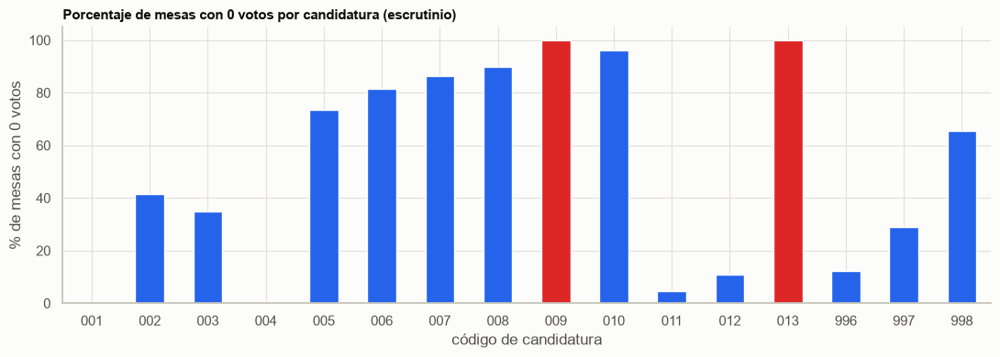

In [177]:
pct_ceros = escru.groupby("candidato")["votos"].apply(lambda s: (s == 0).mean() * 100).round(1)
print(pct_ceros.to_string())

fig, ax = plt.subplots(figsize=(11, 4))
colores = ["#DC2626" if c in ("009", "013") else "#2563EB" for c in pct_ceros.index]
pct_ceros.plot.bar(ax=ax, color=colores)
ax.set_xlabel("código de candidatura")
ax.set_ylabel("% de mesas con 0 votos")
ax.set_title("Porcentaje de mesas con 0 votos por candidatura (escrutinio)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

*Figura: Porcentaje de mesas con 0 votos por candidatura en el escrutinio; en rojo, los candidatos retirados (elaboración propia).*

Aunque no hay faltantes, se revisó si algún **cero** podía ser en realidad un dato faltante. Un 0 en `votos` es un valor registrado: la candidatura no recibió votos en esa mesa. La proporción de ceros depende de cada candidatura, desde 0,1 % (001) hasta 96,2 % (010), lo que refleja su votación y no una falla de registro.

La excepción son **009 y 013, con 0 votos en el 100 % de las mesas**. No es que falten sus datos: los dos candidatos se retiraron y en el escrutinio sus votos pasaron al código 998. Son columnas sin información, pero no se rellenan ni se reconstruyen. El traslado se descuenta al construir la variable objetivo, y la decisión sobre conservarlas o eliminarlas se toma en la selección de datos (1.6).

In [178]:
votos_mesa = escru.groupby(LLAVE_MESA)["votos"].sum().reset_index()
mesas_cero = votos_mesa[votos_mesa["votos"] == 0]
mesas_cero = mesas_cero.merge(noved[LLAVE_MESA + ["excluida"]], on=LLAVE_MESA, how="left")
mesas_cero["origen"] = np.where(mesas_cero["dep"] == "88", "consulado",
                       np.where(mesas_cero["excluida"] == "SI", "excluida en escrutinio", "otra"))

print("Mesas con 0 votos en total:", len(mesas_cero))
print(mesas_cero["origen"].value_counts())
print("Mesas excluidas en todo el archivo de novedades:", (noved["excluida"] == "SI").sum())

pre_mesa = precon.groupby(LLAVE_MESA)["votos"].sum().rename("votos_pre").reset_index()
excluidas = mesas_cero[mesas_cero["origen"] == "excluida en escrutinio"].merge(pre_mesa, on=LLAVE_MESA)
print("Excluidas con votos en el preconteo:", (excluidas["votos_pre"] > 0).sum(), "de", len(excluidas))

Mesas con 0 votos en total: 46
origen
excluida en escrutinio    37
consulado                  9
Name: count, dtype: int64
Mesas excluidas en todo el archivo de novedades: 37
Excluidas con votos en el preconteo: 37 de 37


También se revisaron las mesas **sin ningún voto**, porque una mesa vacía podría ser un acta que no llegó. Hay 46 y todas tienen explicación:

- **37 mesas excluidas en el escrutinio.** Son exactamente las 37 que el archivo de novedades marca con `excluida = SI`: la comisión anuló su votación. No son faltantes sino el resultado real del escrutinio, así que **se conservan**. Además, son mesas corregidas (en el preconteo sí tenían votos), por lo que eliminarlas quitaría casos positivos de la variable objetivo.
- **9 mesas de consulados** donde nadie votó.

**¿Cuáles fueron los criterios para decidir si rellenar con valores estimados o eliminar los valores faltantes?**

En el escrutinio no fue necesario rellenar ni eliminar registros, porque no hay valores faltantes. El criterio aplicado fue verificar si los valores que podían parecer faltantes lo eran en realidad:

- **Ceros por candidatura:** son valores reales (nadie votó por esa opción en la mesa) y se conservan tal como están.
- **Ceros de 009 y 013:** se deben al retiro de los candidatos, no a datos perdidos. No se rellenan. El traslado de sus votos se descuenta al construir la variable objetivo, y en la selección de datos (1.6) se decide si sus columnas se conservan.
- **Las 46 mesas sin votos:** corresponden a 37 mesas excluidas por la comisión y 9 mesas de consulados donde nadie votó. Son resultados reales, por lo que se conservan.

**Método de relleno:** no aplica. No se usó ningún método de relleno (media, mediana, moda ni otro), porque en el escrutinio no hay valores faltantes y los ceros son resultados reales. Rellenarlos cambiaría los votos de cada mesa.

##### Faltantes al cruzar el escrutinio con las novedades

El escrutinio está completo por sí solo. Sin embargo, para construir el conjunto de modelado hay que unirlo con el archivo de novedades, que aporta las variables del formulario (E-11, E-14, votos en urna, firmas). Por eso se revisó si alguna mesa del escrutinio queda sin esa información al hacer el cruce.

In [179]:
votos_mesa = escru.groupby(LLAVE_MESA)["votos"].sum().reset_index()
cruce = votos_mesa[LLAVE_MESA].merge(noved[LLAVE_MESA], on=LLAVE_MESA, how="left", indicator=True)

print("Mesas del escrutinio:", len(cruce))
print("Mesas con registro en novedades:", (cruce["_merge"] == "both").sum())
print("Mesas sin registro en novedades:", (cruce["_merge"] == "left_only").sum())
print("\nDepartamento de las mesas sin novedades:")
print(cruce.loc[cruce["_merge"] == "left_only", "dep"].value_counts())

Mesas del escrutinio: 122020
Mesas con registro en novedades: 118350
Mesas sin registro en novedades: 3670

Departamento de las mesas sin novedades:
dep
88    3670
Name: count, dtype: int64


In [180]:
votos_mesa = escru.groupby(LLAVE_MESA)["votos"].sum().reset_index()
print("Escrutinio, todas las mesas:", votos_mesa["votos"].sum())
print("Escrutinio, solo consulados:", votos_mesa.loc[votos_mesa["dep"] == "88", "votos"].sum())
print("Escrutinio, sin consulados: ", votos_mesa.loc[votos_mesa["dep"] != "88", "votos"].sum())
print("Novedades (totalVotos):     ", noved["totalVotos"].sum())

m = votos_mesa.merge(noved[LLAVE_MESA + ["totalVotos"]], on=LLAVE_MESA)
print("% de mesas donde coinciden:", (m["votos"] == m["totalVotos"]).mean() * 100)

Escrutinio, todas las mesas: 23990635
Escrutinio, solo consulados: 591234
Escrutinio, sin consulados:  23399401
Novedades (totalVotos):      23399401
% de mesas donde coinciden: 100.0


La diferencia entre el total del escrutinio (23 990 635) y el `totalVotos` de novedades (23 399 401) es exactamente la votación de los consulados (591 234). En las mesas nacionales los dos totales coinciden en el 100 % de las mesas, lo que confirma que la única diferencia de cobertura entre las fuentes son los consulados.

Al cruzar las dos fuentes, **3 670 mesas del escrutinio quedan sin datos del formulario**, y todas son del departamento 88 (consulados). El archivo de novedades solo incluye mesas nacionales. Las otras 118 350 mesas cruzan sin problema.

**Decisión: eliminar las mesas de consulados en lugar de rellenarlas.** Las razones son tres:

1. Las variables que les faltan son las más importantes para el modelo, en especial la diferencia entre el preconteo y el E-11. Un valor estimado inventaría justo la señal que el modelo debe aprender.
2. Las variables faltan para todo el grupo de consulados, no al azar dentro de él, así que no hay información de mesas parecidas para estimarlas.
3. Los consulados siguen un proceso de escrutinio distinto al nacional.

**Efecto en la representatividad:** el modelo queda limitado al escrutinio nacional, que corresponde al 97 % de las mesas (118 350 de 122 020). Sus conclusiones no deben extenderse al voto en el exterior.

In [181]:
escru_nac = escru[escru["dep"] != "88"].copy()

print("Antes:  ", len(escru), "filas |", escru.groupby(LLAVE_MESA).ngroups, "mesas")
print("Después:", len(escru_nac), "filas |", escru_nac.groupby(LLAVE_MESA).ngroups, "mesas")

Antes:   1952320 filas | 122020 mesas
Después: 1893600 filas | 118350 mesas


El escrutinio pasa de 1 952 320 filas (122 020 mesas) a **1 893 600 filas (118 350 mesas nacionales)**. Las 9 mesas de consulados sin votos salen junto con ellas. Desde aquí, las secciones siguientes trabajan con `escru_nac`.

**Faltantes en una variable crítica.**

 El E-11 es la variable más importante del modelo, porque la diferencia entre el preconteo y el E-11 es la principal señal de que una mesa será corregida. Si se conservaran los consulados con el E-11 vacío o estimado, el modelo podría interpretar como discrepancia algo que en realidad es un dato inventado o ausente. Esto inflaría o distorsionaría la relación entre esa diferencia y la corrección. Al excluirlos, todas las mesas del modelo tienen el E-11 real y la relación se interpreta sin ese sesgo.

**¿Cómo afectan estos valores a la integridad y representatividad de la información?**

In [182]:
mesas_total = escru.groupby(LLAVE_MESA).ngroups
mesas_nac = escru_nac.groupby(LLAVE_MESA).ngroups
votos_total = escru["votos"].sum()
votos_nac = escru_nac["votos"].sum()

print(f"Mesas:  {mesas_nac} de {mesas_total} ({mesas_nac / mesas_total * 100:.1f} %)")
print(f"Votos:  {votos_nac} de {votos_total} ({votos_nac / votos_total * 100:.1f} %)")
print("Departamentos que quedan:", escru_nac["dep"].nunique(), "de", escru["dep"].nunique())

Mesas:  118350 de 122020 (97.0 %)
Votos:  23399401 de 23990635 (97.5 %)
Departamentos que quedan: 33 de 34


**Integridad.** El escrutinio no tiene nulos ni celdas vacías, cada mesa tiene sus 16 filas y los ceros (incluidos los de los candidatos retirados y las 46 mesas sin votos) son resultados reales que se conservan. Como no se rellenó ningún valor, los votos de cada mesa son exactamente los que reporta la Registraduría.

Los faltantes aparecen solo **al unir** el escrutinio con las novedades. Las 3 670 mesas de consulados no tienen registro en el archivo de novedades, por lo que en la tabla unida quedarían con las variables del formulario vacías. Si se conservaran, la integridad del conjunto de modelado sí se vería afectada, porque esas mesas no tendrían el E-11, que es la variable más importante. Al excluirlas, todas las mesas que quedan tienen sus datos completos y reales en las dos fuentes.

**Representatividad.** El único efecto viene de excluir las mesas de consulados. El conjunto que queda conserva el 97,0 % de las mesas (118 350 de 122 020) y el 97,5 % de los votos, con los 33 departamentos del territorio nacional. Por lo tanto, es representativo del **escrutinio nacional**. En cambio, no representa el voto en el exterior: los resultados del modelo no deben extenderse a los consulados, que además siguen un proceso de escrutinio distinto.

#### **1.2. Valores duplicados**
----
Ante la presencia de valores duplicados, es esencial reflexionar sobre su impacto en los resultados.

* ¿Cómo se identificaron y manejaron los valores duplicados en el conjunto de datos?
* ¿Hubo alguna consideración especial al tratar duplicados en función de ciertas variables?
* ¿Pueden estos duplicados sesgar el análisis, y en qué medida?
* ¿Se justifica la eliminación de duplicados para mantener la coherencia y singularidad de los datos?
* ¿Cómo se aseguró de que la eliminación de duplicados no afectara negativamente la representación del conjunto de datos?

La identificación y eliminación de duplicados busca asegurar que cada registro aporte información única y valiosa.

##### Escrutinio

**¿Cómo se identificaron y manejaron los valores duplicados en el conjunto de datos?**

In [183]:
print("Filas completas duplicadas:", escru_nac.duplicated().sum())
print("Mesa + candidatura duplicadas:", escru_nac.duplicated(subset=LLAVE_MESA + ["candidato"]).sum())

Filas completas duplicadas: 0
Mesa + candidatura duplicadas: 0


Se buscaron duplicados en dos niveles:

1. **Filas completas repetidas** (`duplicated()`): dos filas idénticas en todas sus columnas. Hay 0.
2. **Duplicados por llave**: la misma mesa con la misma candidatura más de una vez, aunque los votos fueran distintos. Este es el duplicado más peligroso, porque significaría que una mesa reportó dos resultados para la misma opción. Hay 0.

Como no se encontraron duplicados, no fue necesario eliminar registros.

**¿Hubo alguna consideración especial al tratar duplicados en función de ciertas variables?**

In [184]:
print("Números de mesa distintos:", escru_nac["mesa"].nunique())
print("Mesas reales (llave completa):", escru_nac.groupby(LLAVE_MESA).ngroups)

print("\n'Duplicados' si se usa solo mesa + candidatura:",
      escru_nac.duplicated(subset=["mesa", "candidato"]).sum())
print("'Duplicados' si se usa puesto + mesa + candidatura:",
      escru_nac.duplicated(subset=["puesto", "mesa", "candidato"]).sum())

Números de mesa distintos: 228
Mesas reales (llave completa): 118350

'Duplicados' si se usa solo mesa + candidatura: 1889952
'Duplicados' si se usa puesto + mesa + candidatura: 1827184


Sí. La consideración principal fue **usar la llave completa de la mesa**. El número de mesa solo identifica una mesa dentro de su puesto: la "mesa 1" existe en casi todos los puestos del país. Por eso hay solo 228 números de mesa distintos, pero 118 350 mesas reales.

Si los duplicados se buscaran solo con `mesa` + candidatura, aparecerían 1 889 952 "duplicados" falsos. Incluso agregando el puesto, aparecerían 1 827 184, porque los códigos de puesto también se repiten entre municipios. Eliminar esos registros habría borrado casi todo el conjunto. Por eso la verificación se hizo con la llave completa: departamento, municipio, zona, puesto y mesa.

**¿Pueden estos duplicados sesgar el análisis, y en qué medida?**

In [185]:
esc_mesa = escru_nac.pivot_table(index=LLAVE_MESA, columns="candidato", values="votos",
                                 aggfunc="sum").reset_index()
CANDS = [c for c in esc_mesa.columns if c not in LLAVE_MESA]
esc_mesa["total"] = esc_mesa[CANDS].sum(axis=1)
esc_mesa["opciones_con_votos"] = (esc_mesa[CANDS] > 0).sum(axis=1)

PUESTO = ["dep", "mun", "zona", "puesto"]
igual_puesto = esc_mesa.duplicated(subset=PUESTO + CANDS, keep=False) & (esc_mesa["total"] > 0)
igual_pais = esc_mesa.duplicated(subset=CANDS, keep=False) & (esc_mesa["total"] > 0)
print("Mesas con resultado idéntico a otra del MISMO puesto:", igual_puesto.sum())
print("Mesas con resultado idéntico a otra de cualquier parte del país:", igual_pais.sum())

iguales = esc_mesa[igual_pais]
print(f"\nDe esas {len(iguales)} mesas:")
print(f"- mediana de votos: {iguales['total'].median():.0f} (todas las mesas: {esc_mesa['total'].median():.0f})")
print(f"- con 30 votos o menos: {(iguales['total'] <= 30).mean() * 100:.1f} %")
print(f"- con votos en solo 1 o 2 opciones: {(iguales['opciones_con_votos'] <= 2).mean() * 100:.1f} %")
print(f"- en zona rural (099): {(iguales['zona'] == '099').mean() * 100:.1f} % "
      f"(todas las mesas: {(esc_mesa['zona'] == '099').mean() * 100:.1f} %)")

Mesas con resultado idéntico a otra del MISMO puesto: 0
Mesas con resultado idéntico a otra de cualquier parte del país: 551

De esas 551 mesas:
- mediana de votos: 13 (todas las mesas: 206)
- con 30 votos o menos: 80.9 %
- con votos en solo 1 o 2 opciones: 60.3 %
- en zona rural (099): 67.5 % (todas las mesas: 16.4 %)


Si existieran, los duplicados sí sesgarían el análisis: una mesa repetida contaría doble sus votos y, en el modelo, tendría el doble de peso en el entrenamiento. Por eso, además de las filas, se revisó un tipo de duplicado más sutil: **actas copiadas**, es decir, dos mesas con exactamente los mismos votos en las 16 opciones. Esto podría indicar que un resultado se transcribió dos veces.

- **Dentro del mismo puesto no hay ninguna mesa con resultado idéntico a otra.** Es el caso donde una copia sería más probable, porque las actas se diligencian en el mismo lugar.
- **En todo el país hay 551 mesas** (0,5 %) cuyo resultado coincide con el de otra mesa de otro puesto. Estas coincidencias tienen una explicación por azar: son mesas muy pequeñas (mediana de 13 votos frente a 206 en general; el 80,9 % tiene 30 votos o menos), con votos concentrados en 1 o 2 opciones (60,3 %) y ubicadas sobre todo en zona rural (67,5 % frente a 16,4 % en general). Con tan pocos votos y tan concentrados, es esperable que dos mesas lejanas den el mismo resultado.

Por eso estas 551 mesas no se consideran duplicados y **se conservan**: son mesas distintas, en lugares distintos, con resultados que coinciden por azar.

**¿Se justifica la eliminación de duplicados? ¿Cómo se aseguró de que no afectara negativamente la representación del conjunto de datos?**

In [186]:
print("Antes de la revisión: ", len(escru_nac), "filas |", escru_nac.groupby(LLAVE_MESA).ngroups, "mesas")
escru_nac = escru_nac.drop_duplicates()
print("Después de la revisión:", len(escru_nac), "filas |", escru_nac.groupby(LLAVE_MESA).ngroups, "mesas")
print("Votos totales:", escru_nac["votos"].sum())

Antes de la revisión:  1893600 filas | 118350 mesas
Después de la revisión: 1893600 filas | 118350 mesas
Votos totales: 23399401


No se justificó eliminar registros, porque no hay duplicados reales. Igualmente se aplicó `drop_duplicates()` como paso de control y se comparó el conjunto antes y después: conserva las mismas 1 893 600 filas, las mismas 118 350 mesas y los mismos 23 399 401 votos. Así se confirma que la revisión no alteró la representación del conjunto.

Se descartaron dos acciones que sí la habrían afectado: buscar duplicados con una llave incompleta, que habría borrado casi todo el conjunto, y eliminar las 551 mesas con resultados coincidentes, que habría quitado sobre todo mesas rurales pequeñas y sesgado el conjunto hacia las mesas urbanas.

Este control se repetirá al unir el escrutinio con el preconteo y las novedades, verificando que cada mesa siga apareciendo una sola vez.

In [187]:
print("Mesas en el escrutinio:", len(esc_mesa), "| repetidas:", esc_mesa.duplicated(subset=LLAVE_MESA).sum())
print("Mesas en novedades:", len(noved), "| repetidas:", noved.duplicated(subset=LLAVE_MESA).sum())

unida = esc_mesa.merge(noved, on=LLAVE_MESA, how="outer", validate="1:1", indicator=True)
print("\nFilas de la tabla unida:", len(unida))
print(unida["_merge"].value_counts())
print("Mesas repetidas en la tabla unida:", unida.duplicated(subset=LLAVE_MESA).sum())

Mesas en el escrutinio: 118350 | repetidas: 0
Mesas en novedades: 118350 | repetidas: 0

Filas de la tabla unida: 118350
_merge
both          118350
left_only          0
right_only         0
Name: count, dtype: int64
Mesas repetidas en la tabla unida: 0


**Duplicados al unir el escrutinio con las novedades.** Los duplicados también pueden aparecer al unir fuentes: si una mesa estuviera dos veces en novedades, la unión la repetiría y sus votos contarían doble. Para evitarlo, se verificó que cada mesa aparezca una sola vez en cada fuente y se hizo la unión con `validate="1:1"`, que detiene la ejecución con un error si alguna mesa se empareja con más de una fila.

La unión resultó uno a uno: las 118 350 mesas del escrutinio encuentran exactamente una pareja en novedades (`both`), no sobra ninguna de ningún lado y la tabla unida tiene 118 350 filas, sin mesas repetidas.

#### **1.3. Valores atípicos**
---
Al abordar valores atípicos, es relevante cuestionarse sobre la naturaleza de estos puntos extremos.
* ¿Son errores de medición o representan información válida pero excepcional?
* ¿Qué criterios o técnicas se utilizaron para identificar los valores atípicos?
* ¿Se aplicaron métodos estadísticos o visuales para detectar los valores atípicos?
* ¿Cuál fue la decisión final sobre cómo tratar los valores atípicos y por qué?

La elección entre eliminar o transformar estos valores debe basarse en su influencia en la distribución y la interpretación de los resultados, asegurando que el análisis refleje de manera precisa la realidad del conjunto de datos.

##### Escrutinio

**¿Qué criterios o técnicas se utilizaron para identificar los valores atípicos? ¿Se aplicaron métodos estadísticos o visuales?**

Q1: 157 | mediana: 206 | Q3: 247 | IQR: 90
Límite inferior: 22 | límite superior: 382
atipico
normal    116812
bajo        1482
alto          56
Name: count, dtype: int64


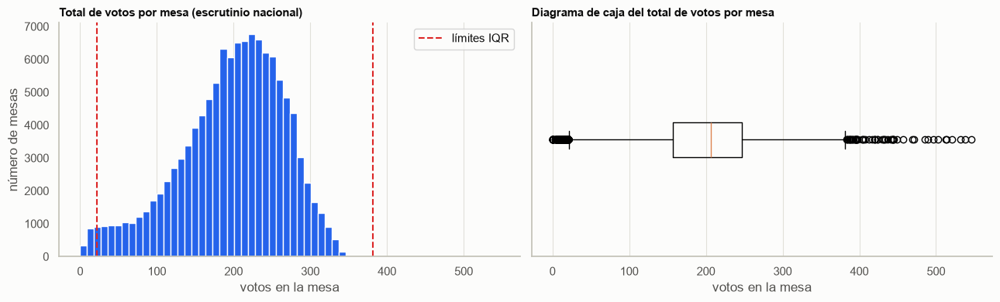

In [188]:
votos_mesa = escru_nac.groupby(LLAVE_MESA)["votos"].sum().rename("total").reset_index()

Q1 = votos_mesa["total"].quantile(0.25)
Q3 = votos_mesa["total"].quantile(0.75)
IQR = Q3 - Q1
lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(f"Q1: {Q1:.0f} | mediana: {votos_mesa['total'].median():.0f} | Q3: {Q3:.0f} | IQR: {IQR:.0f}")
print(f"Límite inferior: {lim_inf:.0f} | límite superior: {lim_sup:.0f}")

votos_mesa["atipico"] = np.select([votos_mesa["total"] < lim_inf, votos_mesa["total"] > lim_sup],
                                  ["bajo", "alto"], "normal")
print(votos_mesa["atipico"].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(votos_mesa["total"], bins=60, color="#2563EB")
ax[0].axvline(lim_inf, color="#DC2626", linestyle="--", label="límites IQR")
ax[0].axvline(lim_sup, color="#DC2626", linestyle="--")
ax[0].set_xlabel("votos en la mesa")
ax[0].set_ylabel("número de mesas")
ax[0].set_title("Total de votos por mesa (escrutinio nacional)")
ax[0].legend()
ax[1].boxplot(votos_mesa["total"], orientation="horizontal")
ax[1].set_xlabel("votos en la mesa")
ax[1].set_yticks([])
ax[1].set_title("Diagrama de caja del total de votos por mesa")
plt.tight_layout()
plt.show()

*Figura: Distribución del total de votos por mesa con los límites del rango intercuartílico (elaboración propia).*

Se usaron un método estadístico y uno visual sobre el **total de votos por mesa**, que es la medida que resume el resultado de cada acta:

- **Estadístico, rango intercuartílico (IQR).** Se considera atípica una mesa por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR. Con Q1 = 157, Q3 = 247 e IQR = 90, los límites son 22 y 382 votos. Se eligió el IQR porque no supone una distribución normal, y la distribución de los votos por mesa es asimétrica, con una cola larga hacia los valores bajos.
- **Visual: histograma y diagrama de caja.** Muestran que la mayoría de las mesas está entre 100 y 300 votos, con una cola de mesas pequeñas a la izquierda y unos pocos puntos aislados a la derecha.

Resultado: **1 482 atípicos bajos** (menos de 22 votos) y **56 atípicos altos** (más de 382 votos), es decir, el 1,3 % de las 118 350 mesas.

**¿Son errores de medición o representan información válida pero excepcional?**

Para responder se usa la columna `potencial` de novedades, que indica el número **máximo** de votantes que puede tener cada mesa (no cuántos votaron). Casi todas las mesas tienen un potencial de 360, y algunas mesas especiales de 500, 800 o 1 200.

In [189]:
votos_mesa = votos_mesa.merge(noved[LLAVE_MESA + ["potencial", "excluida"]], on=LLAVE_MESA)
print("Mesas con más votos que su potencial máximo:", (votos_mesa["total"] > votos_mesa["potencial"]).sum())
print("Máximo de votos / potencial:", round((votos_mesa["total"] / votos_mesa["potencial"]).max(), 3))

votos_mesa["n_mesa"] = votos_mesa["mesa"].astype(int)
PUESTO = ["dep", "mun", "zona", "puesto"]
votos_mesa["ultima_mesa"] = votos_mesa["n_mesa"] == votos_mesa.groupby(PUESTO)["n_mesa"].transform("max")

bajos = votos_mesa[votos_mesa["atipico"] == "bajo"]
print(f"\nAtípicos bajos: {len(bajos)}")
print(f"- son la última mesa de su puesto: {bajos['ultima_mesa'].mean() * 100:.1f} % "
      f"(todas las mesas: {votos_mesa['ultima_mesa'].mean() * 100:.1f} %)")
print(f"- mesas excluidas por la comisión (0 votos): {(bajos['excluida'] == 'SI').sum()}")

altos = votos_mesa[votos_mesa["atipico"] == "alto"]
print(f"\nAtípicos altos: {len(altos)}")
print("- potencial máximo de esas mesas:", altos["potencial"].value_counts().to_dict())
print("- potencial máximo de todas las mesas:", votos_mesa["potencial"].value_counts().to_dict())

Mesas con más votos que su potencial máximo: 0
Máximo de votos / potencial: 0.969

Atípicos bajos: 1482
- son la última mesa de su puesto: 87.2 % (todas las mesas: 11.4 %)
- mesas excluidas por la comisión (0 votos): 37

Atípicos altos: 56
- potencial máximo de esas mesas: {800: 54, 500: 2}
- potencial máximo de todas las mesas: {360: 117022, 800: 572, 500: 467, 1200: 289}


Para saber si los atípicos eran errores se aplicó una **regla de validación**: una mesa no puede tener más votos que su potencial máximo (`potencial`, el número máximo de votantes que la ley permite asignarle). **Ninguna mesa supera su potencial**; la que más se acerca llega al 96,9 %. No hay valores imposibles, así que los atípicos no son errores de registro. Cada grupo tiene además una explicación propia:

- **Atípicos bajos (1 482): son en su mayoría la última mesa del puesto.** El 87,2 % de ellos es la mesa con el número más alto de su puesto, frente al 11,4 % del total de mesas. Los votantes se reparten entre las mesas en orden y la última recibe solo los que sobran, por eso tiene pocos votos. Entre ellos están también las 37 mesas excluidas por la comisión, que tienen 0 votos.
- **Atípicos altos (56): son mesas diseñadas para más votantes.** Las 56 tienen un potencial de 800 (54) o 500 (2), cuando casi todas las mesas del país (117 022) tienen un potencial de 360. Su tamaño es atípico frente al total, pero normal frente a su capacidad.

Por lo tanto, los atípicos representan **información válida pero excepcional**: mesas pequeñas o grandes por la forma en que se organiza la votación.

**¿Cuál fue la decisión final sobre cómo tratar los valores atípicos y por qué?**

**Se conservan los 1 538 atípicos sin eliminarlos ni recortarlos**, por tres razones:

1. **No son errores.** Ninguna mesa supera su potencial y cada grupo tiene una explicación en la organización de la votación (última mesa del puesto, mesas con potencial mayor).
2. **Eliminarlos sesgaría el conjunto.** Quitar los atípicos bajos borraría sobre todo las últimas mesas de cada puesto y las 37 mesas excluidas, que además son mesas corregidas. Quitarlos le restaría casos positivos a la variable objetivo.
3. **Lo atípico es parte de lo que el modelo debe aprender.** El objetivo es detectar mesas que cambian en el escrutinio. Recortar o reemplazar valores extremos borraría información que puede estar asociada a esos cambios.

Tampoco se aplicó una transformación en esta etapa. Si en el modelado se usan modelos sensibles a la escala (como la regresión logística), se evaluará estandarizar o aplicar logaritmos. Los modelos basados en árboles no lo necesitan.

#### **1.4. Datos Inconsistentes**
---
Frente a inconsistencias en los datos, es importante analizar cómo estas discrepancias podrían afectar la comparabilidad y comprensión de la información.

* ¿Cómo se identificaron las inconsistencias en los datos?
* ¿Las inconsistencias son lo suficientemente significativas como para justificar una estandarización?
* ¿Cómo se pueden homogeneizar unidades y formatos para garantizar coherencia en el análisis?
* ¿Qué estrategias se implementaron para abordar las inconsistencias y asegurar la coherencia?
* ¿Se establecieron reglas de validación específicas para garantizar la consistencia?

##### Escrutinio

**¿Cómo se identificaron las inconsistencias en los datos?**

In [190]:
# Se vuelven a leer los códigos tal como vienen en los archivos originales (sin normalizar)
esc_crudo = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, usecols=[1, 2, 3, 4, 5, 9],
                        names=["dep", "mun", "zona", "puesto", "mesa", "partido"],
                        dtype=str, encoding="latin-1")
pre_crudo = pd.read_fwf(ARCH_PRECONTEO, widths=ANCHOS_PRE, names=COLS_PRE,
                        dtype=str, encoding="latin-1")
nov_crudo = leer_novedades(ARCH_NOVEDADES).rename(columns={
    "departamentoCodigo": "dep", "municipioCodigo": "mun", "zonaNombre": "zona",
    "puestoCodigo": "puesto", "mesaNumero": "mesa"})

CODIGOS = ["dep", "mun", "zona", "puesto", "mesa", "partido"]
formatos = pd.DataFrame({
    "escrutinio": [sorted(esc_crudo[c].str.len().unique().tolist()) for c in CODIGOS],
    "preconteo":  [sorted(pre_crudo[c].str.len().unique().tolist()) for c in CODIGOS],
    "novedades":  [sorted(nov_crudo[c].str.len().unique().tolist()) if c in nov_crudo else "-" for c in CODIGOS],
}, index=CODIGOS)
print("Número de dígitos de cada código en los archivos originales:")
display(formatos)

print("Primera mesa de cada archivo (zona, mesa):")
print("  escrutinio:", esc_crudo.loc[0, ["zona", "mesa"]].tolist())
print("  preconteo: ", pre_crudo.loc[0, ["zona", "mesa"]].tolist())
print("  novedades: ", nov_crudo.loc[0, ["zona", "mesa"]].tolist())

Número de dígitos de cada código en los archivos originales:


,escrutinio,preconteo,novedades
dep,[2],[2],[2]
mun,[3],[3],[3]
zona,[3],[2],[2]
puesto,[2],[2],[2]
mesa,[6],[6],"[1, 2, 3]"
partido,[4],[5],-


Primera mesa de cada archivo (zona, mesa):
  escrutinio: ['001', '000001']
  preconteo:  ['01', '000001']
  novedades:  ['01', '1']


Las inconsistencias se identificaron comparando el **formato de los códigos** que forman la llave de la mesa en las tres fuentes. Como los códigos se leen como texto, se contó cuántos dígitos tiene cada uno en cada archivo. Se encontraron tres diferencias:

- **Zona:** el escrutinio usa 3 dígitos (`001`); el preconteo y las novedades usan 2 (`01`).
- **Mesa:** el escrutinio y el preconteo usan 6 dígitos con ceros a la izquierda (`000001`); las novedades no usan ceros (`1`, `12`, `123`).
- **Partido:** el escrutinio usa 4 dígitos (`0026`); el preconteo usa 5 (`00026`).

Es decir, la misma mesa aparece escrita de forma distinta en cada fuente: zona `001` y mesa `000001` en el escrutinio, pero zona `01` y mesa `1` en las novedades. Los demás códigos (departamento, municipio y puesto) tienen el mismo formato en todas.

**¿Las inconsistencias son lo suficientemente significativas como para justificar una estandarización?**

In [191]:
mesas_esc_crudo = esc_crudo[esc_crudo["dep"] != "88"][LLAVE_MESA].drop_duplicates()
cruce_crudo = mesas_esc_crudo.merge(nov_crudo[LLAVE_MESA], on=LLAVE_MESA)

mesas_esc = escru_nac[LLAVE_MESA].drop_duplicates()
cruce_norm = mesas_esc.merge(noved[LLAVE_MESA], on=LLAVE_MESA)

print("Mesas del escrutinio:", len(mesas_esc))
print("Mesas emparejadas con novedades — formatos originales:   ", len(cruce_crudo))
print("Mesas emparejadas con novedades — formatos estandarizados:", len(cruce_norm))

del esc_crudo, pre_crudo, nov_crudo   # liberar memoria

Mesas del escrutinio: 118350
Mesas emparejadas con novedades — formatos originales:    0
Mesas emparejadas con novedades — formatos estandarizados: 118350


Sí, son críticas. Con los formatos originales, **ninguna** de las 118 350 mesas del escrutinio se empareja con las novedades: para pandas, `001` y `01` son textos distintos. Sin estandarizar, no se podrían unir las fuentes ni construir la variable objetivo. Con los formatos estandarizados se emparejan las 118 350 mesas.

**¿Cómo se pueden homogeneizar unidades y formatos para garantizar coherencia en el análisis?**

In [192]:
print("Dígitos después de estandarizar:")
for c in ["zona", "mesa", "partido"]:
    linea = (f"  {c}: escrutinio {sorted(escru_nac[c].str.len().unique().tolist())}"
             f" | preconteo {sorted(precon[c].str.len().unique().tolist())}")
    if c in noved:
        linea += f" | novedades {sorted(noved[c].str.len().unique().tolist())}"
    print(linea)

print("\nTipos de dato del escrutinio:")
print(escru_nac.dtypes.to_string())

Dígitos después de estandarizar:
  zona: escrutinio [3] | preconteo [3] | novedades [3]
  mesa: escrutinio [6] | preconteo [6] | novedades [6]
  partido: escrutinio [5] | preconteo [5]

Tipos de dato del escrutinio:
comunicado       str
dep              str
mun              str
zona             str
puesto           str
mesa             str
comuna           str
corporacion      str
circ             str
partido          str
candidato        str
votos          int64


**Formatos.** Se tomó como estándar el formato más largo de cada código y se completaron los demás con ceros a la izquierda usando `str.zfill()` (en la celda de carga): zona a 3 dígitos, mesa a 6 y partido a 5. Después de estandarizar, cada código tiene la misma cantidad de dígitos en todas las fuentes.

**Tipos de dato.** Los códigos se mantienen como **texto** y no como números. Si se convirtieran a número, `01` y `1` quedarían iguales, pero se perderían los ceros a la izquierda y códigos como `00026` dejarían de corresponder al catálogo oficial. La única variable numérica es `votos`, que se convierte a entero (`int64`).

**Unidades.** No hubo que homogeneizar unidades: todas las variables numéricas del escrutinio son conteos de votos, en la misma unidad.

**¿Qué estrategias se implementaron para abordar las inconsistencias y asegurar la coherencia?**

In [193]:
tot_pre = precon[precon["dep"] != "88"].groupby("candidato")["votos"].sum()
tot_esc = escru_nac.groupby("candidato")["votos"].sum()

retiro = pd.DataFrame({"preconteo": tot_pre[["009", "013", "998"]],
                       "escrutinio": tot_esc[["009", "013", "998"]]})
retiro.loc["009 + 013 + 998"] = retiro.sum()
display(retiro)

,preconteo,escrutinio
candidato,,
009,12523,0
013,13018,0
998,47341,68732
009 + 013 + 998,72882,68732


Además de estandarizar los códigos, se encontró una **inconsistencia de contenido entre fuentes**: los candidatos 009 y 013 tienen votos en el preconteo (12 523 y 13 018 en las mesas nacionales), pero 0 en el escrutinio, porque se retiraron y sus votos pasaron a la categoría 998 (votos no marcados). Si las fuentes se comparan sin tener esto en cuenta, casi todas las mesas con votos para esos candidatos parecerían corregidas, aunque el acta no haya cambiado.

La estrategia fue **comparar las tres categorías juntas**. En el preconteo, 009 + 013 + 998 suman 72 882 votos, y en el escrutinio la categoría 998 tiene 68 732. Al construir la variable objetivo, el traslado de 009 y 013 se descuenta mesa por mesa. Así solo cuentan como corrección los cambios del 998 que van **más allá** del traslado, como los 4 150 votos de diferencia que quedan en el total.

En resumen, las estrategias fueron:

1. Estandarizar los códigos con ceros a la izquierda, para que la misma mesa se escriba igual en todas las fuentes.
2. Mantener los códigos como texto y los votos como enteros.
3. Descontar el traslado de los candidatos retirados al comparar las fuentes.
4. Verificar la coherencia con reglas de validación (siguiente pregunta).

**¿Se establecieron reglas de validación específicas para garantizar la consistencia?**

In [194]:
votos_mesa = (escru_nac.groupby(LLAVE_MESA)["votos"].agg(total="sum", filas="size").reset_index()
              .merge(noved[LLAVE_MESA + ["potencial", "sufragantesSegunE11",
                                         "sufragantesE11SegunE14", "totalVotos"]], on=LLAVE_MESA))

CODIGOS_VALIDOS = set(candidatos["candidato"]) | {"996", "997", "998"}
partido_esc = escru_nac[["candidato", "partido"]].drop_duplicates()
partido_pre = precon[["candidato", "partido"]].drop_duplicates()
puestos = escru_nac[["dep", "mun", "zona", "puesto"]].drop_duplicates()
en_divipol = puestos.merge(divipol[["dep", "mun", "zona", "puesto"]], how="left", indicator=True)

reglas = pd.DataFrame({
    "regla": [
        "Votos no negativos",
        "Cada mesa tiene 16 filas (una por opción)",
        "Código de candidatura existe en el catálogo",
        "Cada candidatura tiene un solo partido, igual en ambas fuentes",
        "El puesto existe en DIVIPOL",
        "Candidatos retirados (009, 013) con 0 votos",
        "Total de la mesa ≤ potencial máximo",
        "Total de la mesa = totalVotos de novedades",
        "Total de la mesa ≤ votantes del E-11",
    ],
    "incumplimientos": [
        (escru_nac["votos"] < 0).sum(),
        (votos_mesa["filas"] != 16).sum(),
        (~escru_nac["candidato"].isin(CODIGOS_VALIDOS)).sum(),
        len(partido_esc.merge(partido_pre, how="outer", indicator=True).query("_merge != 'both'"))
            + partido_esc["candidato"].duplicated().sum(),
        (en_divipol["_merge"] == "left_only").sum(),
        (escru_nac.loc[escru_nac["candidato"].isin(["009", "013"]), "votos"] > 0).sum(),
        (votos_mesa["total"] > votos_mesa["potencial"]).sum(),
        (votos_mesa["total"] != votos_mesa["totalVotos"]).sum(),
        (votos_mesa["total"] > votos_mesa["sufragantesSegunE11"]).sum(),
    ],
})
display(reglas)

print("Mesas donde el escrutinio supera al E-11:")
display(votos_mesa.loc[votos_mesa["total"] > votos_mesa["sufragantesSegunE11"],
                       LLAVE_MESA + ["total", "sufragantesSegunE11", "sufragantesE11SegunE14"]])

,regla,incumplimientos
0,Votos no negativos,0
1,Cada mesa tiene 16 filas (una por opción),0
2,Código de candidatura existe en el catálogo,0
3,"Cada candidatura tiene un solo partido, igual en ambas fuentes",0
4,El puesto existe en DIVIPOL,0
5,"Candidatos retirados (009, 013) con 0 votos",0
6,Total de la mesa ≤ potencial máximo,0
7,Total de la mesa = totalVotos de novedades,0
8,Total de la mesa ≤ votantes del E-11,2


Mesas donde el escrutinio supera al E-11:


,dep,mun,zona,puesto,mesa,total,sufragantesSegunE11,sufragantesE11SegunE14
28042,07,061,000,00,000004,127,0,127
54369,16,001,006,36,000004,295,287,295


Sí. Se definieron nueve reglas que un escrutinio coherente debe cumplir: unas revisan el archivo por dentro (valores, estructura y catálogos) y otras lo comparan con las demás fuentes. **El escrutinio cumple ocho de las nueve reglas sin ninguna excepción**: no hay votos negativos, todas las mesas tienen sus 16 opciones, los códigos y partidos coinciden con el catálogo y con el preconteo, los 13 489 puestos existen en DIVIPOL, los candidatos retirados tienen 0 votos, ninguna mesa supera su potencial y el total coincide con `totalVotos` en todas las mesas.

La única regla con incumplimientos es **"total ≤ votantes del E-11"**, en 2 de 118 350 mesas: el escrutinio tiene más votos que personas registradas en el E-11. En las dos, el valor que no cuadra es el E-11 y no el escrutinio:

- En una mesa el E-11 es **0**, pero el acta E-14 registra 127 votantes y el escrutinio tiene 127 votos.
- En la otra el E-11 es **287**, mientras el E-14 y el escrutinio coinciden en 295.

Como el E-14 confirma los votos del escrutinio, la inconsistencia está en el registro del E-11 del archivo de novedades. Por eso el escrutinio no se modifica, y el tratamiento de esos registros del E-11 se aborda en datos corruptos (1.5).

#### **1.5. Datos corruptos**
---
En la detección de datos corruptos, pregunte si hay posibles errores de entrada o problemas de transferencia que podrían haber afectado la integridad de los datos.
* ¿Cómo se determinó la presencia de datos corruptos en el conjunto de datos?
* ¿Qué medidas se tomaron para corregir o eliminar los datos corruptos?
* ¿Hubo casos en los que la corrupción de datos no pudo ser manejada y cómo se justificó esa decisión?

##### Escrutinio

**¿Cómo se determinó la presencia de datos corruptos en el conjunto de datos?**

Se revisaron dos tipos de corrupción: (1) que el archivo se haya dañado o modificado durante la descarga o la transferencia, y (2) que haya líneas mal formadas o con caracteres que no corresponden.

In [195]:
import hashlib
import re

# 1. Integridad del archivo: huella MD5 publicada por la Registraduría frente a la calculada
texto_hash = buscar_archivo("HASH_ficheros_MMV_4_MMV_9999_ESCRUTINIO.txt").read_text(encoding="utf-16")
md5_oficial = re.search(r"MD5\s*:\s*(\w+)", texto_hash).group(1)

md5 = hashlib.md5()
with open(ARCH_ESCRUTINIO, "rb") as f:
    for bloque in iter(lambda: f.read(1024 * 1024), b""):
        md5.update(bloque)

print("MD5 oficial:  ", md5_oficial)
print("MD5 calculado:", md5.hexdigest())
print("¿Coinciden?", md5_oficial == md5.hexdigest())
print("Tamaño en disco:", os.path.getsize(ARCH_ESCRUTINIO), "bytes")

MD5 oficial:   08ae9a4affd1f0c7fdab6c90e8ea2805
MD5 calculado: 08ae9a4affd1f0c7fdab6c90e8ea2805
¿Coinciden? True
Tamaño en disco: 105425280 bytes


**Integridad del archivo.** La Registraduría publica junto a cada archivo una huella MD5, un código que cambia por completo si se altera un solo byte. La huella calculada sobre el archivo descargado (`08ae9a4affd1f0c7fdab6c90e8ea2805`) es **idéntica a la oficial**, y el tamaño (105 425 280 bytes) coincide con el publicado. Esto garantiza que el archivo no se dañó en la descarga ni se modificó después.

In [196]:
# 2. Revisión línea por línea del archivo original
from collections import Counter

campos_por_linea = Counter()
lineas_no_numericas = 0
total_lineas = 0
with open(ARCH_ESCRUTINIO, encoding="latin-1") as f:
    for linea in f:
        total_lineas += 1
        partes = linea.rstrip("\r\n").split(";")
        campos_por_linea[len(partes)] += 1
        if not all(p.isdigit() for p in partes[:12]):
            lineas_no_numericas += 1

print("Líneas leídas:", total_lineas, "| filas cargadas en el DataFrame:", len(escru))
print("Campos por línea:", dict(campos_por_linea))
print("Líneas con algún campo no numérico:", lineas_no_numericas)

Líneas leídas: 1952320 | filas cargadas en el DataFrame: 1952320
Campos por línea: {13: 1952320}
Líneas con algún campo no numérico: 14896


**Estructura de las líneas.** Las 1 952 320 líneas tienen exactamente 13 campos (12 datos más un campo final vacío), y todas se cargaron en el DataFrame, sin líneas cortadas ni perdidas. Sin embargo, **14 896 líneas tienen algún campo con caracteres no numéricos**, aunque el escrutinio debería contener solo códigos y votos numéricos. Se investigaron en la siguiente celda.

In [197]:
alfa = escru[~escru["puesto"].str.isdigit()]
print("Filas con código de puesto alfanumérico:", len(alfa))
print("Mesas:", alfa.groupby(LLAVE_MESA).ngroups,
      "| puestos:", alfa[["dep", "mun", "zona", "puesto"]].drop_duplicates().shape[0])
print("Ejemplos de códigos:", sorted(alfa["puesto"].unique())[:10])
print("Zonas donde aparecen:", alfa["zona"].value_counts().to_dict())

puestos_alfa = alfa[["dep", "mun", "zona", "puesto"]].drop_duplicates().merge(
    divipol[["dep", "mun", "zona", "puesto", "puesto_nombre"]], how="left", indicator=True)
print("Puestos alfanuméricos que existen en DIVIPOL:", (puestos_alfa["_merge"] == "both").sum(),
      "de", len(puestos_alfa))
display(puestos_alfa[["dep", "mun", "zona", "puesto", "puesto_nombre"]].head(3))

Filas con código de puesto alfanumérico: 14896
Mesas: 931 | puestos: 187
Ejemplos de códigos: ['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'B1']
Zonas donde aparecen: {'099': 10608, '008': 2496, '011': 1792}
Puestos alfanuméricos que existen en DIVIPOL: 187 de 187


,dep,mun,zona,puesto,puesto_nombre
0,01,001,099,A1,IE SAN ANTONIO DE PRADO
1,01,001,099,A2,I.E. MANUEL J. BETANCUR
2,01,001,099,A3,IE MONSEÑOR VICTOR WIEDEMANN


Todos los caracteres no numéricos están en el **código de puesto**, que en 187 puestos (931 mesas) tiene letras: `A1`, `A2`, `B1`, etc. Se ubican sobre todo en la zona 099 (rural). Parecían datos corruptos, pero no lo son: **los 187 códigos existen en el catálogo oficial DIVIPOL**, que les asigna nombres de puestos reales (por ejemplo, `A1` = IE San Antonio de Prado, en Medellín). Es una forma válida de codificar puestos, y el preconteo usa los mismos códigos.

Este hallazgo confirma por qué los códigos se mantienen como **texto**. Si se convirtieran a número, estos 187 puestos producirían errores o se perderían.

**¿Qué medidas se tomaron para corregir o eliminar los datos corruptos?**

In [198]:
validacion = (escru_nac.groupby(LLAVE_MESA)["votos"].sum().rename("total_esc").reset_index()
              .merge(noved[LLAVE_MESA + ["potencial", "sufragantesSegunE11"]], on=LLAVE_MESA))

validacion["e11_igual_potencial"] = validacion["sufragantesSegunE11"] == validacion["potencial"]
validacion["e11_menor_escrutinio"] = validacion["sufragantesSegunE11"] < validacion["total_esc"]
validacion["e11_sospechoso"] = (validacion["e11_igual_potencial"]
                                | validacion["e11_menor_escrutinio"]).astype(int)

print("E-11 igual al potencial máximo:", validacion["e11_igual_potencial"].sum())
print("E-11 menor que los votos del escrutinio:", validacion["e11_menor_escrutinio"].sum())
print("Mesas marcadas con e11_sospechoso:", validacion["e11_sospechoso"].sum(), "de", len(validacion))

s = validacion[validacion["e11_igual_potencial"]]
print(f"\nMesas con E-11 = potencial: mediana del E-11 {s['sufragantesSegunE11'].median():.0f} | "
      f"mediana de votos del escrutinio {s['total_esc'].median():.0f}")
print(f"Porcentaje de mesas marcadas: {validacion['e11_sospechoso'].mean() * 100:.2f} %")

E-11 igual al potencial máximo: 143
E-11 menor que los votos del escrutinio: 2
Mesas marcadas con e11_sospechoso: 145 de 118350

Mesas con E-11 = potencial: mediana del E-11 360 | mediana de votos del escrutinio 221
Porcentaje de mesas marcadas: 0.12 %


**En el escrutinio no fue necesario corregir ni eliminar nada.** El archivo coincide con la huella oficial, todas sus líneas están completas y los únicos valores que parecían anómalos (los puestos alfanuméricos) son códigos válidos.

Donde sí hay registros corruptos es en el **E-11** del archivo de novedades, que se usa para validar el escrutinio y construir la principal variable del modelo:

- **143 mesas con el E-11 igual al potencial máximo.** El E-11 dice que firmaron 360 personas (el máximo de la mesa), pero el escrutinio tiene una mediana de 221 votos. Lo más probable es que se haya registrado el potencial en lugar del número real de votantes.
- **2 mesas con el E-11 menor que los votos del escrutinio** (las encontradas en la 1.4): una con E-11 = 0 y otra con 287 votantes frente a 295 votos.

**Medida tomada: marcar, no eliminar ni corregir.** Se creó la bandera `e11_sospechoso`, que vale 1 en estas **145 mesas**. Las mesas se conservan, porque su escrutinio es válido y algunas pueden ser mesas corregidas. Al construir las variables del modelo, la diferencia entre el preconteo y el E-11 de estas mesas se dejará como faltante, para que el modelo no tome un error de registro como señal de corrección.

La bandera se guarda en la tabla `validacion` (una fila por mesa) y se incorpora al conjunto de modelado en la selección de datos (1.6).

**¿Hubo casos en los que la corrupción de datos no pudo ser manejada y cómo se justificó esa decisión?**

Sí: el **valor real del E-11** de las 145 mesas marcadas no se puede recuperar. Para conocerlo habría que consultar el formulario físico, que no forma parte de los datos publicados. Estimarlo con el E-14 o con los votos del escrutinio no es correcto, porque el modelo justamente compara esas fuentes. Rellenar el E-11 con una de ellas haría que coincidieran de forma artificial.

Por eso se decidió no corregirlo y solo marcarlo. La bandera deja constancia del problema, y estas mesas son el 0,12 % del conjunto (145 de 118 350), así que su efecto en el modelo es pequeño.

También hay una limitación general: la huella MD5 garantiza que el archivo es el que publicó la Registraduría, pero no que lo publicado coincida con las actas físicas. Esa verificación está fuera del alcance de este trabajo.

#### **1.6. Selección de datos**
---
En la selección de datos, reflexione sobre las variables que son realmente relevantes para sus objetivos de análisis.
* ¿Qué criterios se utilizaron para seleccionar los datos relevantes para el análisis?
* ¿Se aplicaron técnicas de muestreo o filtrado para reducir el tamaño del conjunto de datos?
* ¿Cómo se justificó la inclusión o exclusión de ciertas variables en la selección de datos?

##### Escrutinio

**¿Qué criterios se utilizaron para seleccionar los datos relevantes para el análisis?**

In [199]:
print("Valores distintos por columna (escrutinio nacional):")
print(escru_nac.nunique().to_string())

pares = escru_nac[["candidato", "partido"]].drop_duplicates()
print("\nCandidaturas:", escru_nac["candidato"].nunique(),
      "| combinaciones candidatura-partido:", len(pares))

Valores distintos por columna (escrutinio nacional):
comunicado       1
dep             33
mun            263
zona            42
puesto         208
mesa           228
comuna           1
corporacion      1
circ             1
partido         14
candidato       16
votos          301

Candidaturas: 16 | combinaciones candidatura-partido: 16


El criterio principal fue el **objetivo del proyecto**: predecir si una mesa será corregida en el escrutinio usando información disponible **antes** del escrutinio. Por eso el escrutinio cumple un solo papel en el conjunto de modelado: **aportar la variable objetivo**. Sus votos se usan para saber si la mesa cambió, pero no pueden ser variables de entrada, porque son justamente el resultado que se quiere anticipar.

Con ese criterio se revisaron las 12 columnas del escrutinio:

- **Se conservan** las cinco columnas de la llave (`dep`, `mun`, `zona`, `puesto`, `mesa`), necesarias para unir el escrutinio con el preconteo y las novedades, y `candidato` y `votos`, necesarias para construir la variable objetivo.
- **Se excluyen** `comunicado`, `comuna`, `corporacion` y `circ`, porque tienen **un solo valor** en todo el archivo: no aportan información.
- **Se excluye** `partido`, porque es **redundante** con `candidato`: cada una de las 16 candidaturas tiene un único partido (16 combinaciones para 16 candidaturas). Tiene 14 valores y no 16 porque blanco, nulo y no marcado comparten el código `00000`.

In [200]:
pre_nac = precon[precon["dep"] != "88"]

# Una fila por mesa y una columna por opción, en cada fuente
esc_ancho = escru_nac.pivot_table(index=LLAVE_MESA, columns="candidato", values="votos",
                                  aggfunc="sum", fill_value=0)
pre_ancho = (pre_nac.pivot_table(index=LLAVE_MESA, columns="candidato", values="votos",
                                 aggfunc="sum", fill_value=0)
                    .reindex(index=esc_ancho.index, columns=esc_ancho.columns, fill_value=0))

# Cambio de cada opción entre preconteo y escrutinio, descontando el retiro de 009 y 013
dif = esc_ancho - pre_ancho
traslado = pre_ancho["009"] + pre_ancho["013"]
ACTIVOS = [c for c in esc_ancho.columns if c not in ("009", "013", "996", "997", "998")]
cambio_998 = dif["998"] - traslado

objetivo = pd.DataFrame(index=esc_ancho.index)
objetivo["magnitud"] = dif[ACTIVOS + ["996", "997"]].abs().sum(axis=1) + cambio_998.abs()
objetivo["y_corregida"] = (objetivo["magnitud"] > 0).astype(int)
objetivo = objetivo.reset_index()

n1 = objetivo["y_corregida"].sum()
print("Mesas:", len(objetivo))
print(f"Mesas corregidas (y = 1): {n1} ({n1 / len(objetivo) * 100:.2f} %)")
print(f"Mesas sin corrección (y = 0): {len(objetivo) - n1}")
print(f"Relación: {(len(objetivo) - n1) / n1:.1f} mesas sin corrección por cada corregida")

Mesas: 118350
Mesas corregidas (y = 1): 5998 (5.07 %)
Mesas sin corrección (y = 0): 112352
Relación: 18.7 mesas sin corrección por cada corregida


Con las columnas seleccionadas se construyó la **variable objetivo** `y_corregida`, que vale 1 si la mesa tuvo algún cambio entre el preconteo y el escrutinio que **no** se explica por el retiro de los candidatos 009 y 013 (ver 1.4): un cambio en una candidatura activa, en el voto en blanco (996), en el nulo (997) o en el 998 más allá del traslado. También se calculó `magnitud`, el número de votos que cambiaron, como variable complementaria para el análisis; no se usa como entrada del modelo.

De las 118 350 mesas nacionales, **5 998 fueron corregidas (5,07 %)**, unas 18,7 mesas sin corrección por cada mesa corregida. Este desbalance se tendrá en cuenta en el modelado (métricas como precisión, sensibilidad o PR-AUC en lugar de la exactitud).

**¿Se aplicaron técnicas de muestreo o filtrado para reducir el tamaño del conjunto de datos?**

In [201]:
mb_largo = escru_nac.memory_usage(deep=True).sum() / 1024**2
mb_ancho = objetivo.memory_usage(deep=True).sum() / 1024**2
print(f"Escrutinio en formato largo: {len(escru_nac):>9,} filas | {mb_largo:,.0f} MB")
print(f"Una fila por mesa:           {len(objetivo):>9,} filas | {mb_ancho:,.0f} MB")
print("\nMesas corregidas disponibles para entrenar:", objetivo["y_corregida"].sum())

Escrutinio en formato largo: 1,893,600 filas | 1,049 MB
Una fila por mesa:             118,350 filas | 31 MB

Mesas corregidas disponibles para entrenar: 5998


**No se aplicó muestreo.** Las 118 350 mesas se pueden procesar completas sin problema, y un muestreo reduciría las mesas corregidas disponibles para entrenar, que ya son pocas (5 998). Las técnicas para manejar el desbalance, como pesos de clase o submuestreo de la clase mayoritaria, se evaluarán en el modelado, solo sobre el conjunto de entrenamiento.

**Sí se aplicaron dos filtros:**

1. **Exclusión de los consulados** (ver 1.1), porque no tienen datos del formulario en el archivo de novedades.
2. **Cambio de formato largo a una fila por mesa.** La unidad de análisis del proyecto es la mesa, así que el escrutinio pasó de 1 893 600 filas (una por mesa y candidatura) a 118 350 filas (una por mesa). Esto reduce el tamaño en memoria de unos 1 049 MB a 31 MB, sin perder información para el objetivo.

**¿Cómo se justificó la inclusión o exclusión de ciertas variables en la selección de datos?**

In [202]:
fuga = objetivo.merge(noved[LLAVE_MESA + ["enTerminos", "estadoSobre", "recontadaComision", "excluida"]],
                      on=LLAVE_MESA, validate="1:1")

print(f"Promedio general de mesas corregidas: {fuga['y_corregida'].mean() * 100:.1f} %\n")
for col, valor in {"enTerminos": "NO", "estadoSobre": "MAL",
                   "recontadaComision": "SI", "excluida": "SI"}.items():
    marcadas = fuga[col] == valor
    print(f"{col} = {valor}: {marcadas.sum():>4} mesas | % corregidas: "
          f"{fuga.loc[marcadas, 'y_corregida'].mean() * 100:.1f}")

Promedio general de mesas corregidas: 5.1 %

enTerminos = NO:   12 mesas | % corregidas: 50.0
estadoSobre = MAL:  334 mesas | % corregidas: 5.7
recontadaComision = SI:  558 mesas | % corregidas: 89.2
excluida = SI:   37 mesas | % corregidas: 100.0


La exclusión de variables se justificó con el criterio de **fuga de información**: una variable que se registra durante o después del escrutinio no estará disponible al momento de hacer la predicción. Si se incluyera, el modelo acertaría por una razón que no existe en la práctica. Por eso se excluyen como variables de entrada:

- **Los votos del escrutinio**, por candidatura y en total: son el resultado que se quiere anticipar.
- **`totalVotos`** de novedades: es igual al total del escrutinio en el 100 % de las mesas (ver 1.4).
- **`recontadaComision`** y **`excluida`**: son decisiones de la comisión escrutadora y forman parte del mecanismo de la corrección. El 89,2 % de las mesas recontadas por la comisión y el 100 % de las excluidas fueron corregidas.
- **`estadoSobre`** y **`enTerminos`**: se registran cuando la comisión recibe los sobres, es decir, durante el escrutinio. Su relación con la corrección es más débil (5,7 % y 50 %, este último con solo 12 mesas), pero se excluyen por el mismo criterio de momento de registro.

| Variable | ¿Se incluye? | Razón |
|---|---|---|
| Llave de la mesa (`dep`, `mun`, `zona`, `puesto`, `mesa`) | Sí | Necesaria para unir las fuentes |
| `y_corregida` | Sí, como **objetivo** | Variable a predecir |
| `magnitud` | Sí, como complementaria | Análisis del tamaño de las correcciones; no es entrada |
| `e11_sospechoso` | Sí | Bandera de calidad del E-11 (ver 1.5) |
| `comunicado`, `comuna`, `corporacion`, `circ` | No | Un solo valor en todo el archivo |
| `partido` | No | Redundante con `candidato` |
| Votos del escrutinio, `totalVotos` | No | Fuga: son el resultado del escrutinio |
| `recontadaComision`, `excluida`, `estadoSobre`, `enTerminos` | No | Fuga: se registran durante el escrutinio |

In [203]:
tabla_escrutinio = objetivo.merge(validacion[LLAVE_MESA + ["e11_sospechoso"]],
                                  on=LLAVE_MESA, validate="1:1")
assert len(tabla_escrutinio) == 118350 and not tabla_escrutinio.duplicated(LLAVE_MESA).any()

print("Forma:", tabla_escrutinio.shape)
print("Columnas:", list(tabla_escrutinio.columns))
print("Nulos:", tabla_escrutinio.isnull().sum().sum())
display(tabla_escrutinio.head())

SALIDA = Path("../../data/processed")
SALIDA.mkdir(parents=True, exist_ok=True)
tabla_escrutinio.to_csv(SALIDA / "objetivo_escrutinio.csv", index=False)
print("Guardado en:", (SALIDA / "objetivo_escrutinio.csv").resolve())

Forma: (118350, 8)
Columnas: ['dep', 'mun', 'zona', 'puesto', 'mesa', 'magnitud', 'y_corregida', 'e11_sospechoso']
Nulos: 0


,dep,mun,zona,puesto,mesa,magnitud,y_corregida,e11_sospechoso
0,01,001,001,01,000001,0,0,0
1,01,001,001,01,000002,0,0,0
2,01,001,001,01,000003,0,0,0
3,01,001,001,01,000004,0,0,0
4,01,001,001,01,000005,0,0,0


Guardado en: C:\Users\aleja\Documents\maestria\machine_learning\proyecto\proyecto_git\ml-final-project\data\processed\objetivo_escrutinio.csv


La selección del escrutinio queda en la tabla `tabla_escrutinio`, con **118 350 mesas y 8 columnas**: la llave de la mesa, `magnitud`, `y_corregida` y `e11_sospechoso`. No tiene nulos ni mesas repetidas, y se guardó en `data/processed/objetivo_escrutinio.csv`.

Esta tabla se une por la llave de la mesa con las variables del preconteo y de las novedades, disponibles antes del escrutinio, para formar el conjunto de modelado. En esa unión, la diferencia entre el preconteo y el E-11 de las 145 mesas con `e11_sospechoso = 1` se dejará como faltante (ver 1.5). Para leer el archivo sin perder los ceros a la izquierda de los códigos, se debe usar `pd.read_csv(..., dtype={"dep": str, "mun": str, "zona": str, "puesto": str, "mesa": str})`.

## **5.0. Dataset maestro**
---

Las tres fuentes limpias se integran en una tabla de una fila por mesa, con la variable objetivo, las variables de entrada disponibles antes del escrutinio y las variables de consistencia entre formularios. Esta tabla es la entrada de los modelos de la Parte IV.

In [204]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd

LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]

DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)

PRECONTEO_PATH = DATA_DIR / "PRE1v_MMV_9999_PRECONTEO.txt"

assert PRECONTEO_PATH.exists(), (
    f"No se encontró el archivo: {PRECONTEO_PATH.resolve()}"
)

print("Archivo encontrado:", PRECONTEO_PATH.name)
print("Tamaño (MB):", round(PRECONTEO_PATH.stat().st_size / 1e6, 2))

Archivo encontrado: PRE1v_MMV_9999_PRECONTEO.txt
Tamaño (MB): 59.18


In [205]:
COLUMNAS_PRE = [
    "dep", "mun", "zona", "puesto", "mesa",
    "jal", "comunicado", "circunscripcion",
    "partido", "candidato", "votos"
]

ANCHOS_PRE = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]

preconteo = pd.read_fwf(
    PRECONTEO_PATH,
    widths=ANCHOS_PRE,
    names=COLUMNAS_PRE,
    dtype="string",
    header=None,
    keep_default_na=False
)

preconteo["votos"] = pd.to_numeric(
    preconteo["votos"],
    errors="raise"
).astype("int64")

print("Dimensiones:", preconteo.shape)
display(preconteo.head())

Dimensiones: (1479506, 11)


,dep,mun,zona,puesto,mesa,jal,comunicado,circunscripcion,partido,candidato,votos
0,01,001,01,01,000001,00,9999,0,00009,011,27
1,01,001,01,01,000001,00,9999,0,00015,012,5
2,01,001,01,01,000001,00,9999,0,00020,006,1
3,01,001,01,01,000001,00,9999,0,00021,010,0
4,01,001,01,01,000001,00,9999,0,00022,008,0


In [206]:
for col in LLAVE_MESA:
    preconteo[col] = preconteo[col].str.strip()

# Mantener únicamente mesas nacionales
pre_nacional = preconteo.loc[
    preconteo["dep"] != "88"
].copy()

print("Registros nacionales:", len(pre_nacional))
print(
    "Mesas únicas:",
    pre_nacional[LLAVE_MESA].drop_duplicates().shape[0]
)

print("\nValores faltantes en la llave:")
print(pre_nacional[LLAVE_MESA].isna().sum())

print("\nVotos negativos:")
print((pre_nacional["votos"] < 0).sum())

Registros nacionales: 1433823
Mesas únicas: 118350

Valores faltantes en la llave:
dep       0
mun       0
zona      0
puesto    0
mesa      0
dtype: int64

Votos negativos:
0


In [207]:
pre_mesa = (
    pre_nacional
    .groupby(LLAVE_MESA, as_index=False)
    .agg(
        total_votos_preconteo=("votos", "sum"),
        numero_registros=("votos", "size"),
        opciones_reportadas=("candidato", "nunique")
    )
)

assert not pre_mesa.duplicated(LLAVE_MESA).any()

print("Dimensiones:", pre_mesa.shape)
display(pre_mesa.head())

Dimensiones: (118350, 8)


,dep,mun,zona,puesto,mesa,total_votos_preconteo,numero_registros,opciones_reportadas
0,01,001,01,01,000001,127,16,16
1,01,001,01,01,000002,65,16,16
2,01,001,01,01,000003,107,16,16
3,01,001,01,01,000004,143,16,16
4,01,001,01,01,000005,177,16,16


In [208]:
# Votos por opción electoral
votos_opcion = (
    pre_nacional
    .groupby(LLAVE_MESA + ["candidato"])["votos"]
    .sum()
    .unstack("candidato", fill_value=0)
)

# Garantizar las tres categorías especiales
for codigo in ["996", "997", "998"]:
    if codigo not in votos_opcion.columns:
        votos_opcion[codigo] = 0

# Excluir categorías especiales y candidaturas retiradas
# para calcular concentración y competitividad.
CODIGOS_EXCLUIDOS = {"009", "013", "996", "997", "998"}

candidaturas = votos_opcion[
    [c for c in votos_opcion.columns
     if c not in CODIGOS_EXCLUIDOS]
]

votos_ordenados = np.sort(
    candidaturas.to_numpy(dtype=float),
    axis=1
)

total = votos_opcion.sum(axis=1)
total_seguro = total.replace(0, np.nan)

features = pd.DataFrame(index=votos_opcion.index)

features["votos_blancos"] = votos_opcion["996"]
features["votos_nulos"] = votos_opcion["997"]
features["votos_no_marcados"] = votos_opcion["998"]

features["proporcion_blancos"] = (
    features["votos_blancos"] / total_seguro
)

features["proporcion_nulos"] = (
    features["votos_nulos"] / total_seguro
)

features["proporcion_no_marcados"] = (
    features["votos_no_marcados"] / total_seguro
)

features["margen_primero_segundo"] = (
    (votos_ordenados[:, -1] - votos_ordenados[:, -2])
    / total_seguro.to_numpy()
)

features["concentracion_maxima"] = (
    votos_ordenados[:, -1] / total_seguro.to_numpy()
)

features = features.reset_index()

pre_mesa = pre_mesa.merge(
    features,
    on=LLAVE_MESA,
    how="left",
    validate="one_to_one"
)

print("Dimensiones finales:", pre_mesa.shape)
display(pre_mesa.head())

Dimensiones finales: (118350, 16)


,dep,mun,zona,puesto,mesa,total_votos_preconteo,numero_registros,opciones_reportadas,votos_blancos,votos_nulos,votos_no_marcados,proporcion_blancos,proporcion_nulos,proporcion_no_marcados,margen_primero_segundo,concentracion_maxima
0,01,001,01,01,000001,127,16,16,3,0,1,0.023622,0.000000,0.007874,0.228346,0.464567
1,01,001,01,01,000002,65,16,16,3,0,0,0.046154,0.000000,0.000000,0.338462,0.615385
2,01,001,01,01,000003,107,16,16,0,2,0,0.000000,0.018692,0.000000,0.046729,0.383178
3,01,001,01,01,000004,143,16,16,3,2,0,0.020979,0.013986,0.000000,0.153846,0.461538
4,01,001,01,01,000005,177,16,16,3,4,1,0.016949,0.022599,0.005650,0.259887,0.502825


In [209]:
print("Mesas únicas:", len(pre_mesa))
print("Duplicados:", pre_mesa.duplicated(LLAVE_MESA).sum())

print("\nValores faltantes:")
display(pre_mesa.isna().sum().to_frame("faltantes"))

print("\nEstadísticas:")
display(pre_mesa.describe())

assert pre_mesa[LLAVE_MESA].notna().all().all()
assert not pre_mesa.duplicated(LLAVE_MESA).any()
assert (pre_mesa["total_votos_preconteo"] >= 0).all()

Mesas únicas: 118350
Duplicados: 0

Valores faltantes:


,faltantes
dep,0
mun,0
zona,0
puesto,0
mesa,0
total_votos_preconteo,0
numero_registros,0
opciones_reportadas,0
votos_blancos,0
votos_nulos,0



Estadísticas:


,total_votos_preconteo,numero_registros,opciones_reportadas,votos_blancos,votos_nulos,votos_no_marcados,proporcion_blancos,proporcion_nulos,proporcion_no_marcados,margen_primero_segundo,concentracion_maxima
count,118350.000000,118350.000000,118350.000000,118350.000000,118350.000000,118350.000000,118344.000000,118344.000000,118344.000000,118344.000000,118344.000000
mean,197.621251,12.115108,12.115108,3.400431,2.064875,0.400008,0.018361,0.010562,0.002151,0.309888,0.578128
std,68.129544,4.054184,4.054184,2.671297,2.383859,1.671074,0.015997,0.012363,0.008184,0.207720,0.121065
min,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.153846
25%,157.000000,8.000000,8.000000,1.000000,0.000000,0.000000,0.007491,0.000000,0.000000,0.141844,0.485714
50%,206.000000,13.000000,13.000000,3.000000,1.000000,0.000000,0.015385,0.007692,0.000000,0.281250,0.562232
75%,247.000000,16.000000,16.000000,5.000000,3.000000,0.000000,0.025641,0.015306,0.000000,0.447162,0.655172
max,546.000000,16.000000,16.000000,70.000000,111.000000,227.000000,0.461538,0.397436,0.630556,1.000000,1.000000


In [210]:
pre_mesa["sin_votos_preconteo"] = (
    pre_mesa["total_votos_preconteo"] == 0
).astype("int8")

print(
    pre_mesa["sin_votos_preconteo"].value_counts()
)

assert not pre_mesa.duplicated(LLAVE_MESA).any()

sin_votos_preconteo
0    118344
1         6
Name: count, dtype: int64


In [211]:
columnas_revisar = [
    "total_votos_preconteo",
    "proporcion_blancos",
    "proporcion_nulos",
    "proporcion_no_marcados",
    "margen_primero_segundo",
    "concentracion_maxima"
]

mesas_faltantes = pre_mesa.loc[
    pre_mesa[columnas_revisar].isna().any(axis=1)
].copy()

print("Mesas con valores faltantes:", len(mesas_faltantes))

display(
    mesas_faltantes[
        LLAVE_MESA + columnas_revisar
    ]
)

print(
    "¿Todas tienen cero votos?",
    (mesas_faltantes["total_votos_preconteo"] == 0).all()
)

Mesas con valores faltantes: 6


,dep,mun,zona,puesto,mesa,total_votos_preconteo,proporcion_blancos,proporcion_nulos,proporcion_no_marcados,margen_primero_segundo,concentracion_maxima
67657,17,001,99,25,000001,0,NaN,NaN,NaN,NaN,NaN
67664,17,001,99,33,000001,0,NaN,NaN,NaN,NaN,NaN
67868,17,010,99,17,000001,0,NaN,NaN,NaN,NaN,NaN
67930,17,011,99,40,000001,0,NaN,NaN,NaN,NaN,NaN
67931,17,011,99,41,000001,0,NaN,NaN,NaN,NaN,NaN
68221,17,025,99,17,000001,0,NaN,NaN,NaN,NaN,NaN


¿Todas tienen cero votos? True


In [212]:
CLAVE_OPCION = LLAVE_MESA + [
    "circunscripcion",
    "partido",
    "candidato"
]

multiplicidad = (
    pre_nacional
    .groupby(CLAVE_OPCION, dropna=False)
    .size()
    .rename("n_registros")
    .reset_index()
)

print("Distribución de registros por opción:")
display(
    multiplicidad["n_registros"]
    .value_counts()
    .sort_index()
)

repetidos = multiplicidad.query("n_registros > 1")

print("Combinaciones repetidas:", len(repetidos))

display(repetidos.head(10))

Distribución de registros por opción:


n_registros
1    1433823
Name: count, dtype: int64

Combinaciones repetidas: 0


,dep,mun,zona,puesto,mesa,circunscripcion,partido,candidato,n_registros


In [213]:
from pathlib import Path

OUTPUT_DIR = Path("../../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ruta_salida = OUTPUT_DIR / "preconteo_mesa.csv"

pre_mesa.to_csv(
    ruta_salida,
    index=False,
    encoding="utf-8"
)

print("Archivo guardado:", ruta_salida)
print("Dimensiones:", pre_mesa.shape)

Archivo guardado: ..\..\data\processed\preconteo_mesa.csv
Dimensiones: (118350, 17)


In [214]:
for archivo in sorted(OUTPUT_DIR.rglob("*")):
    if archivo.is_file():
        print(
            archivo.relative_to(OUTPUT_DIR),
            f"({archivo.stat().st_size / 1e6:.2f} MB)"
        )

dataset_maestro.csv (26.06 MB)
dataset_maestro_v1.csv (14.69 MB)
objetivo_escrutinio.csv (3.32 MB)
preconteo_mesa.csv (13.86 MB)


In [215]:
objetivo = pd.read_csv(
    OUTPUT_DIR / "objetivo_escrutinio.csv",
    dtype={col: "string" for col in LLAVE_MESA}
)

print("Dimensiones:", objetivo.shape)
print("\nColumnas:")
print(objetivo.columns.tolist())

display(objetivo.head())

print("\nDuplicados por mesa:")
print(objetivo.duplicated(LLAVE_MESA).sum())

print("\nValores faltantes:")
display(objetivo.isna().sum())

Dimensiones: (118350, 8)

Columnas:
['dep', 'mun', 'zona', 'puesto', 'mesa', 'magnitud', 'y_corregida', 'e11_sospechoso']


,dep,mun,zona,puesto,mesa,magnitud,y_corregida,e11_sospechoso
0,01,001,001,01,000001,0,0,0
1,01,001,001,01,000002,0,0,0
2,01,001,001,01,000003,0,0,0
3,01,001,001,01,000004,0,0,0
4,01,001,001,01,000005,0,0,0



Duplicados por mesa:
0

Valores faltantes:


dep               0
mun               0
zona              0
puesto            0
mesa              0
magnitud          0
y_corregida       0
e11_sospechoso    0
dtype: int64

In [216]:
# Verificar integridad de las llaves
assert not pre_mesa.duplicated(LLAVE_MESA).any()
assert not objetivo.duplicated(LLAVE_MESA).any()

# Comprobar coincidencia de mesas
comparacion = pre_mesa[LLAVE_MESA].merge(
    objetivo[LLAVE_MESA],
    on=LLAVE_MESA,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print("Correspondencia de mesas:")
print(comparacion["_merge"].value_counts())

Correspondencia de mesas:
_merge
left_only     118350
right_only    118350
both               0
Name: count, dtype: int64


In [217]:
print("PRECONTEO")
display(pre_mesa[LLAVE_MESA].head(10))

print("\nESCRUTINIO")
display(objetivo[LLAVE_MESA].head(10))

print("\nTIPOS PRECONTEO")
print(pre_mesa[LLAVE_MESA].dtypes)

print("\nTIPOS ESCRUTINIO")
print(objetivo[LLAVE_MESA].dtypes)

for col in LLAVE_MESA:
    print(f"\n{col}")
    print("Preconteo:", repr(pre_mesa[col].iloc[0]))
    print("Escrutinio:", repr(objetivo[col].iloc[0]))

PRECONTEO


,dep,mun,zona,puesto,mesa
0,01,001,01,01,000001
1,01,001,01,01,000002
2,01,001,01,01,000003
3,01,001,01,01,000004
4,01,001,01,01,000005
5,01,001,01,01,000006
6,01,001,01,01,000007
7,01,001,01,01,000008
8,01,001,01,01,000009
9,01,001,01,01,000010



ESCRUTINIO


,dep,mun,zona,puesto,mesa
0,01,001,001,01,000001
1,01,001,001,01,000002
2,01,001,001,01,000003
3,01,001,001,01,000004
4,01,001,001,01,000005
5,01,001,001,01,000006
6,01,001,001,01,000007
7,01,001,001,01,000008
8,01,001,001,01,000009
9,01,001,001,01,000010



TIPOS PRECONTEO
dep       string
mun       string
zona      string
puesto    string
mesa      string
dtype: object

TIPOS ESCRUTINIO
dep       string
mun       string
zona      string
puesto    string
mesa      string
dtype: object

dep
Preconteo: '01'
Escrutinio: '01'

mun
Preconteo: '001'
Escrutinio: '001'

zona
Preconteo: '01'
Escrutinio: '001'

puesto
Preconteo: '01'
Escrutinio: '01'

mesa
Preconteo: '000001'
Escrutinio: '000001'


In [218]:
LONGITUDES = {
    "dep": 2,
    "mun": 3,
    "zona": 2,
    "puesto": 2,
    "mesa": 6
}

def normalizar_llaves(df):
    df = df.copy()

    for col, longitud in LONGITUDES.items():
        df[col] = (
            df[col]
            .astype("string")
            .str.strip()
            .str.zfill(longitud)
        )

    return df

pre_mesa = normalizar_llaves(pre_mesa)
objetivo = normalizar_llaves(objetivo)

In [219]:
comparacion = pre_mesa[LLAVE_MESA].merge(
    objetivo[LLAVE_MESA],
    on=LLAVE_MESA,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print(comparacion["_merge"].value_counts())

print("\nEjemplos sin correspondencia:")
display(
    comparacion.loc[
        comparacion["_merge"] != "both"
    ].head(10)
)

_merge
left_only     118350
right_only    118350
both               0
Name: count, dtype: int64

Ejemplos sin correspondencia:


,dep,mun,zona,puesto,mesa,_merge
0,01,001,001,01,000001,right_only
1,01,001,001,01,000002,right_only
2,01,001,001,01,000003,right_only
3,01,001,001,01,000004,right_only
4,01,001,001,01,000005,right_only
5,01,001,001,01,000006,right_only
6,01,001,001,01,000007,right_only
7,01,001,001,01,000008,right_only
8,01,001,001,01,000009,right_only
9,01,001,001,01,000010,right_only


In [220]:
# Comparar los primeros registros campo por campo
for col in LLAVE_MESA:
    a = pre_mesa[col].iloc[0]
    b = objetivo[col].iloc[0]

    print(f"\nColumna: {col}")
    print(f"Preconteo: {repr(a)} | Longitud: {len(a)}")
    print(f"Escrutinio: {repr(b)} | Longitud: {len(b)}")
    print(f"¿Son iguales?: {a == b}")

    print("Unicode preconteo:", [ord(c) for c in a])
    print("Unicode escrutinio:", [ord(c) for c in b])


Columna: dep
Preconteo: '01' | Longitud: 2
Escrutinio: '01' | Longitud: 2
¿Son iguales?: True
Unicode preconteo: [48, 49]
Unicode escrutinio: [48, 49]

Columna: mun
Preconteo: '001' | Longitud: 3
Escrutinio: '001' | Longitud: 3
¿Son iguales?: True
Unicode preconteo: [48, 48, 49]
Unicode escrutinio: [48, 48, 49]

Columna: zona
Preconteo: '01' | Longitud: 2
Escrutinio: '001' | Longitud: 3
¿Son iguales?: False
Unicode preconteo: [48, 49]
Unicode escrutinio: [48, 48, 49]

Columna: puesto
Preconteo: '01' | Longitud: 2
Escrutinio: '01' | Longitud: 2
¿Son iguales?: True
Unicode preconteo: [48, 49]
Unicode escrutinio: [48, 49]

Columna: mesa
Preconteo: '000001' | Longitud: 6
Escrutinio: '000001' | Longitud: 6
¿Son iguales?: True
Unicode preconteo: [48, 48, 48, 48, 48, 49]
Unicode escrutinio: [48, 48, 48, 48, 48, 49]


In [221]:
# Crear tuplas con los identificadores de cada mesa
llaves_pre = set(
    map(tuple, pre_mesa[LLAVE_MESA].to_numpy())
)

llaves_obj = set(
    map(tuple, objetivo[LLAVE_MESA].to_numpy())
)

print("Mesas preconteo:", len(llaves_pre))
print("Mesas escrutinio:", len(llaves_obj))

print("Coincidencias:", len(llaves_pre & llaves_obj))

print("\nEjemplo exclusivo de preconteo:")
print(next(iter(llaves_pre - llaves_obj), None))

print("\nEjemplo exclusivo de escrutinio:")
print(next(iter(llaves_obj - llaves_pre), None))

Mesas preconteo: 118350
Mesas escrutinio: 118350
Coincidencias: 0

Ejemplo exclusivo de preconteo:
('03', '001', '36', '01', '000015')

Ejemplo exclusivo de escrutinio:
('21', '010', '001', '02', '000001')


In [222]:
# Conservar copias antes de modificar
pre_mesa_original = pre_mesa.copy()
objetivo_original = objetivo.copy()

# Normalizar zona a tres caracteres
pre_mesa["zona"] = (
    pre_mesa["zona"]
    .astype("string")
    .str.strip()
    .str.zfill(3)
)

objetivo["zona"] = (
    objetivo["zona"]
    .astype("string")
    .str.strip()
    .str.zfill(3)
)

print("Preconteo:")
display(pre_mesa[LLAVE_MESA].head())

print("\nEscrutinio:")
display(objetivo[LLAVE_MESA].head())

Preconteo:


,dep,mun,zona,puesto,mesa
0,01,001,001,01,000001
1,01,001,001,01,000002
2,01,001,001,01,000003
3,01,001,001,01,000004
4,01,001,001,01,000005



Escrutinio:


,dep,mun,zona,puesto,mesa
0,01,001,001,01,000001
1,01,001,001,01,000002
2,01,001,001,01,000003
3,01,001,001,01,000004
4,01,001,001,01,000005


In [223]:
comparacion = pre_mesa[LLAVE_MESA].merge(
    objetivo[LLAVE_MESA],
    on=LLAVE_MESA,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print(comparacion["_merge"].value_counts())

print("\nMesas sin correspondencia:")
display(
    comparacion.loc[
        comparacion["_merge"] != "both"
    ].head(10)
)

_merge
both          118350
left_only          0
right_only         0
Name: count, dtype: int64

Mesas sin correspondencia:


,dep,mun,zona,puesto,mesa,_merge


In [224]:
assert (comparacion["_merge"] == "both").all(), (
    "Todavía existen mesas sin correspondencia."
)

dataset_maestro = pre_mesa.merge(
    objetivo,
    on=LLAVE_MESA,
    how="left",
    validate="one_to_one"
)

assert len(dataset_maestro) == 118350
assert dataset_maestro["y_corregida"].notna().all()
assert dataset_maestro["magnitud"].notna().all()

print("Dimensiones:", dataset_maestro.shape)

print("\nDistribución de la variable objetivo:")
print(dataset_maestro["y_corregida"].value_counts())

display(dataset_maestro.head())

Dimensiones: (118350, 20)

Distribución de la variable objetivo:
y_corregida
0    112352
1      5998
Name: count, dtype: int64


,dep,mun,zona,puesto,mesa,total_votos_preconteo,numero_registros,opciones_reportadas,votos_blancos,votos_nulos,votos_no_marcados,proporcion_blancos,proporcion_nulos,proporcion_no_marcados,margen_primero_segundo,concentracion_maxima,sin_votos_preconteo,magnitud,y_corregida,e11_sospechoso
0,01,001,001,01,000001,127,16,16,3,0,1,0.023622,0.000000,0.007874,0.228346,0.464567,0,0,0,0
1,01,001,001,01,000002,65,16,16,3,0,0,0.046154,0.000000,0.000000,0.338462,0.615385,0,0,0,0
2,01,001,001,01,000003,107,16,16,0,2,0,0.000000,0.018692,0.000000,0.046729,0.383178,0,0,0,0
3,01,001,001,01,000004,143,16,16,3,2,0,0.020979,0.013986,0.000000,0.153846,0.461538,0,0,0,0
4,01,001,001,01,000005,177,16,16,3,4,1,0.016949,0.022599,0.005650,0.259887,0.502825,0,0,0,0


Auditoria de caracteristicas

In [225]:
proporciones = [
    "proporcion_blancos",
    "proporcion_nulos",
    "proporcion_no_marcados",
    "margen_primero_segundo",
    "concentracion_maxima"
]

print("Proporciones fuera de [0, 1]:")

for col in proporciones:
    invalidos = (
        (dataset_maestro[col] < 0) |
        (dataset_maestro[col] > 1)
    ).sum()

    print(f"{col}: {invalidos}")

print("\nMagnitud:")
display(dataset_maestro["magnitud"].describe())

print("\nCruce entre corrección y magnitud:")
display(
    pd.crosstab(
        dataset_maestro["y_corregida"],
        dataset_maestro["magnitud"] > 0
    )
)

Proporciones fuera de [0, 1]:
proporcion_blancos: 0
proporcion_nulos: 0
proporcion_no_marcados: 0
margen_primero_segundo: 0
concentracion_maxima: 0

Magnitud:


count    118350.000000
mean          0.665788
std           8.203528
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         490.000000
Name: magnitud, dtype: float64


Cruce entre corrección y magnitud:


magnitud,False,True
y_corregida,,
0,112352,0
1,0,5998


In [226]:
ruta_maestro = OUTPUT_DIR / "dataset_maestro_v1.csv"

dataset_maestro.to_csv(
    ruta_maestro,
    index=False,
    encoding="utf-8"
)

print("Guardado:", ruta_maestro)
print("Dimensiones:", dataset_maestro.shape)

Guardado: ..\..\data\processed\dataset_maestro_v1.csv
Dimensiones: (118350, 20)


In [227]:
print("Columnas actuales del dataset maestro:")
print(dataset_maestro.columns.tolist())

print("\nDistribución de e11_sospechoso:")
print(
    dataset_maestro["e11_sospechoso"]
    .value_counts(dropna=False)
)

Columnas actuales del dataset maestro:
['dep', 'mun', 'zona', 'puesto', 'mesa', 'total_votos_preconteo', 'numero_registros', 'opciones_reportadas', 'votos_blancos', 'votos_nulos', 'votos_no_marcados', 'proporcion_blancos', 'proporcion_nulos', 'proporcion_no_marcados', 'margen_primero_segundo', 'concentracion_maxima', 'sin_votos_preconteo', 'magnitud', 'y_corregida', 'e11_sospechoso']

Distribución de e11_sospechoso:
e11_sospechoso
0    118205
1       145
Name: count, dtype: int64


In [228]:
tabla = pd.crosstab(
    dataset_maestro["e11_sospechoso"],
    dataset_maestro["y_corregida"],
    margins=True
)

print("Frecuencias absolutas:")
display(tabla)

print("\nPorcentaje de correcciones por grupo:")

tasas = (
    dataset_maestro
    .groupby("e11_sospechoso")["y_corregida"]
    .agg(["count", "sum", "mean"])
)

tasas["porcentaje_corregidas"] = tasas["mean"] * 100

display(tasas)

Frecuencias absolutas:


y_corregida,0,1,All
e11_sospechoso,,,
0,112216,5989,118205
1,136,9,145
All,112352,5998,118350



Porcentaje de correcciones por grupo:


,count,sum,mean,porcentaje_corregidas
e11_sospechoso,,,,
0,118205,5989,0.050666,5.066622
1,145,9,0.062069,6.206897


In [229]:
from pathlib import Path
import zipfile

# Buscar archivos ZIP relacionados con novedades
for archivo in DATA_DIR.rglob("*.zip"):
    if "novedad" in archivo.name.lower():
        print("Archivo encontrado:", archivo)

        with zipfile.ZipFile(archivo) as z:
            for nombre in z.namelist()[:20]:
                print("  ", nombre)

Archivo encontrado: ..\..\data\raw\elecciones_2026\extracted\MMV_Presidente1V_2026\MMV_Presidente1V_2026\Novedad20260603.zip
   Novedad20260603.csv
   HuellaHash.txt


In [230]:
import zipfile

with zipfile.ZipFile(NOVEDADES_ZIP) as z:
    with z.open("Novedad20260603.csv") as archivo:

        for numero, linea in enumerate(archivo, start=1):

            if numero == 1:
                print("ENCABEZADO:")
                print(linea.decode("utf-8-sig", errors="replace"))

            if numero in [72385, 72386, 72387]:
                print(f"\nLÍNEA {numero}:")
                print(linea.decode("utf-8-sig", errors="replace"))

            if numero > 72387:
                break

ENCABEZADO:
id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,corporacionNombre,potencial,sufragantesSegunE11,enTerminos,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos


LÍNEA 72385:
0121001080318,21,MAGDALENA,001,SANTA MARTA,08,03,IED CAMILO TORRES DE GAIRA SD ISABEL P.F,18,001,PRESIDENTE,360,69,SI,BUENO,NO,NO,NO,NO,5,69,0,69,69


LÍNEA 72386:
012100108041,21,MAGDALENA,001,SANTA MARTA,08,04,I.E.D.LA PAZ, MEGA COL. LA PAZ,1,001,PRESIDENTE,360,192,SI,BUENO,NO,NO,NO,NO,6,191,0,192,191


LÍNEA 72387:
012100108042,21,MAGDALENA,001,SANTA MARTA,08,04,I.E.D.LA PAZ, MEGA COL. LA PAZ,2,001,PRESIDENTE,360,203,SI,BUENO,NO,NO,NO,NO,6,203,0,203,203



In [231]:
import csv
import io
import pandas as pd
import zipfile

with zipfile.ZipFile(NOVEDADES_ZIP) as z:
    with z.open("Novedad20260603.csv") as archivo:
        contenido = io.TextIOWrapper(
            archivo,
            encoding="utf-8-sig",
            newline=""
        )

        lector = csv.reader(contenido)
        columnas = next(lector)

        print("Columnas esperadas:", len(columnas))
        print(columnas)

        assert "puestoNombre" in columnas, (
            "No se encontró puestoNombre. Revisar estructura."
        )

        posicion = columnas.index("puestoNombre")
        total_columnas = len(columnas)

        registros = []
        reparaciones = []
        errores = []

        for numero, fila in enumerate(lector, start=2):

            if len(fila) == total_columnas:
                registros.append(fila)

            elif len(fila) > total_columnas:
                exceso = len(fila) - total_columnas

                fila_reparada = (
                    fila[:posicion]
                    + [",".join(
                        fila[posicion:posicion + exceso + 1]
                    )]
                    + fila[posicion + exceso + 1:]
                )

                if len(fila_reparada) == total_columnas:
                    registros.append(fila_reparada)
                    reparaciones.append(numero)
                else:
                    errores.append((numero, len(fila)))

            else:
                errores.append((numero, len(fila)))

        novedades = pd.DataFrame(
            registros,
            columns=columnas
        ).astype("string")

print("\nDimensiones:", novedades.shape)
print("Filas reparadas:", len(reparaciones))
print("Filas con errores pendientes:", len(errores))

print("\nPrimeras reparaciones:")
print(reparaciones[:10])

display(novedades.head())

Columnas esperadas: 24
['id', 'departamentoCodigo', 'departamentoNombre', 'municipioCodigo', 'municipioNombre', 'zonaNombre', 'puestoCodigo', 'puestoNombre', 'mesaNumero', 'corporacionCodigo', 'corporacionNombre', 'potencial', 'sufragantesSegunE11', 'enTerminos', 'estadoSobre', 'tachadurasEnmendaduras', 'recontadaJurados', 'recontadaComision', 'excluida', 'firmasJurados', 'votosUrna', 'votosIncinerados', 'sufragantesE11SegunE14', 'totalVotos']

Dimensiones: (118350, 24)
Filas reparadas: 45
Filas con errores pendientes: 0

Primeras reparaciones:
[72386, 72387, 72388, 72389, 72390, 72391, 72392, 72393, 72394, 72395]


,id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,...,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos
0,010100101011,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,1,001,...,BUENO,NO,NO,NO,NO,6,128,0,128,127
1,010100101012,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,2,001,...,BUENO,NO,NO,NO,NO,6,65,0,65,65
2,010100101013,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,3,001,...,BUENO,NO,NO,NO,NO,6,107,0,107,107
3,010100101014,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,4,001,...,BUENO,NO,NO,NO,NO,6,143,0,143,143
4,010100101015,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,5,001,...,BUENO,NO,NO,NO,NO,6,177,0,177,177


In [232]:
print("Dimensiones:", novedades.shape)

print("\nColumnas:")
print(novedades.columns.tolist())

print("\nRegistros reparados:")
print(len(reparaciones))

print("\nErrores pendientes:")
print(errores[:10])

print("\nValores faltantes:")
display(
    novedades.isna()
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

assert len(errores) == 0, (
    "Hay registros que requieren revisión manual."
)

Dimensiones: (118350, 24)

Columnas:
['id', 'departamentoCodigo', 'departamentoNombre', 'municipioCodigo', 'municipioNombre', 'zonaNombre', 'puestoCodigo', 'puestoNombre', 'mesaNumero', 'corporacionCodigo', 'corporacionNombre', 'potencial', 'sufragantesSegunE11', 'enTerminos', 'estadoSobre', 'tachadurasEnmendaduras', 'recontadaJurados', 'recontadaComision', 'excluida', 'firmasJurados', 'votosUrna', 'votosIncinerados', 'sufragantesE11SegunE14', 'totalVotos']

Registros reparados:
45

Errores pendientes:
[]

Valores faltantes:


id                     0
departamentoCodigo     0
departamentoNombre     0
municipioCodigo        0
municipioNombre        0
zonaNombre             0
puestoCodigo           0
puestoNombre           0
mesaNumero             0
corporacionCodigo      0
corporacionNombre      0
potencial              0
sufragantesSegunE11    0
enTerminos             0
estadoSobre            0
dtype: int64

In [233]:
print("Filas reparadas:", len(reparaciones))
print("Errores pendientes:", len(errores))
print("Dimensiones:", novedades.shape)

assert len(errores) == 0
assert novedades.shape[1] == 24

# Inspeccionar el puesto de la línea problemática
display(
    novedades.loc[
        novedades["puestoNombre"].str.contains(
            "I.E.D.LA PAZ",
            regex=False,
            na=False
        ),
        [
            "departamentoCodigo",
            "municipioCodigo",
            "zonaNombre",
            "puestoCodigo",
            "puestoNombre",
            "mesaNumero",
            "totalVotos"
        ]
    ].head(10)
)

Filas reparadas: 45
Errores pendientes: 0
Dimensiones: (118350, 24)


,departamentoCodigo,municipioCodigo,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,totalVotos
72384,21,001,08,04,"I.E.D.LA PAZ, MEGA COL. LA PAZ",1,191
72385,21,001,08,04,"I.E.D.LA PAZ, MEGA COL. LA PAZ",2,203
72386,21,001,08,04,"I.E.D.LA PAZ, MEGA COL. LA PAZ",3,194
72387,21,001,08,04,"I.E.D.LA PAZ, MEGA COL. LA PAZ",4,195
72388,21,001,08,04,"I.E.D.LA PAZ, MEGA COL. LA PAZ",5,167
72389,21,001,08,04,"I.E.D.LA PAZ, MEGA COL. LA PAZ",6,197
72390,21,001,08,04,"I.E.D.LA PAZ, MEGA COL. LA PAZ",7,203
72391,21,001,08,04,"I.E.D.LA PAZ, MEGA COL. LA PAZ",8,201
72392,21,001,08,04,"I.E.D.LA PAZ, MEGA COL. LA PAZ",9,204
72393,21,001,08,04,"I.E.D.LA PAZ, MEGA COL. LA PAZ",10,197


In [234]:
LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]

novedades_mesa = novedades.rename(
    columns={
        "departamentoCodigo": "dep",
        "municipioCodigo": "mun",
        "zonaNombre": "zona",
        "puestoCodigo": "puesto",
        "mesaNumero": "mesa"
    }
).copy()

# Normalizar identificadores
anchos = {
    "dep": 2,
    "mun": 3,
    "zona": 3,
    "puesto": 2,
    "mesa": 6
}

for columna, ancho in anchos.items():
    novedades_mesa[columna] = (
        novedades_mesa[columna]
        .astype("string")
        .str.strip()
        .str.zfill(ancho)
    )

print("Dimensiones:", novedades_mesa.shape)

print("\nLlaves duplicadas:")
print(
    novedades_mesa.duplicated(
        subset=LLAVE_MESA
    ).sum()
)

print("\nEjemplo de llaves:")
display(novedades_mesa[LLAVE_MESA].head())

Dimensiones: (118350, 24)

Llaves duplicadas:
0

Ejemplo de llaves:


,dep,mun,zona,puesto,mesa
0,01,001,001,01,000001
1,01,001,001,01,000002
2,01,001,001,01,000003
3,01,001,001,01,000004
4,01,001,001,01,000005


In [235]:
comparacion = dataset_maestro[
    LLAVE_MESA
].merge(
    novedades_mesa[LLAVE_MESA],
    on=LLAVE_MESA,
    how="outer",
    indicator=True
)

print("Correspondencia entre fuentes:")

display(
    comparacion["_merge"].value_counts()
)

print("\nDuplicados en novedades:")
print(
    novedades_mesa.duplicated(
        subset=LLAVE_MESA
    ).sum()
)

print("\nMesas sin correspondencia:")

display(
    comparacion.loc[
        comparacion["_merge"] != "both"
    ].head(10)
)

Correspondencia entre fuentes:


_merge
both          118350
left_only          0
right_only         0
Name: count, dtype: int64


Duplicados en novedades:
0

Mesas sin correspondencia:


,dep,mun,zona,puesto,mesa,_merge


In [236]:
columnas_novedades = LLAVE_MESA + [
    "potencial",
    "sufragantesSegunE11",
    "enTerminos",
    "estadoSobre",
    "tachadurasEnmendaduras",
    "recontadaJurados",
    "recontadaComision",
    "excluida",
    "firmasJurados",
    "votosUrna",
    "votosIncinerados",
    "sufragantesE11SegunE14",
    "totalVotos"
]

novedades_features = novedades_mesa[
    columnas_novedades
].copy()

renombrar = {
    "sufragantesSegunE11": "sufragantes_e11",
    "enTerminos": "en_terminos",
    "estadoSobre": "estado_sobre",
    "tachadurasEnmendaduras": "tachaduras_enmendaduras",
    "recontadaJurados": "recontada_jurados",
    "recontadaComision": "recontada_comision",
    "firmasJurados": "firmas_jurados",
    "votosUrna": "votos_urna",
    "votosIncinerados": "votos_incinerados",
    "sufragantesE11SegunE14": "sufragantes_e11_segun_e14",
    "totalVotos": "total_votos_novedades"
}

novedades_features = novedades_features.rename(
    columns=renombrar
)

numericas = [
    "potencial",
    "sufragantes_e11",
    "firmas_jurados",
    "votos_urna",
    "votos_incinerados",
    "sufragantes_e11_segun_e14",
    "total_votos_novedades"
]

for columna in numericas:
    novedades_features[columna] = pd.to_numeric(
        novedades_features[columna],
        errors="coerce"
    )

print("Dimensiones:", novedades_features.shape)

print("\nNulos después de conversión numérica:")
display(novedades_features[numericas].isna().sum())

print("\nValores de variables categóricas:")
for columna in [
    "en_terminos",
    "estado_sobre",
    "tachaduras_enmendaduras",
    "recontada_jurados",
    "recontada_comision",
    "excluida"
]:
    print(f"\n{columna}:")
    print(novedades_features[columna].value_counts(dropna=False).head(10))

Dimensiones: (118350, 18)

Nulos después de conversión numérica:


potencial                    0
sufragantes_e11              0
firmas_jurados               0
votos_urna                   0
votos_incinerados            0
sufragantes_e11_segun_e14    0
total_votos_novedades        0
dtype: int64


Valores de variables categóricas:

en_terminos:
en_terminos
SI    118338
NO        12
Name: count, dtype: Int64

estado_sobre:
estado_sobre
BUENO    118016
MAL         334
Name: count, dtype: Int64

tachaduras_enmendaduras:
tachaduras_enmendaduras
NO    116922
SI      1428
Name: count, dtype: Int64

recontada_jurados:
recontada_jurados
NO    117699
SI       651
Name: count, dtype: Int64

recontada_comision:
recontada_comision
NO    117792
SI       558
Name: count, dtype: Int64

excluida:
excluida
NO    118313
SI        37
Name: count, dtype: Int64


In [237]:
dataset_maestro_final = dataset_maestro.merge(
    novedades_features,
    on=LLAVE_MESA,
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Dimensiones:", dataset_maestro_final.shape)

print("\nResultado de integración:")
print(dataset_maestro_final["_merge"].value_counts())

assert len(dataset_maestro_final) == 118350
assert dataset_maestro_final["_merge"].eq("both").all()
assert not dataset_maestro_final.duplicated(LLAVE_MESA).any()

dataset_maestro_final = dataset_maestro_final.drop(
    columns="_merge"
)

print("\nDimensiones finales:", dataset_maestro_final.shape)

display(dataset_maestro_final.head())

Dimensiones: (118350, 34)

Resultado de integración:
_merge
both          118350
left_only          0
right_only         0
Name: count, dtype: int64

Dimensiones finales: (118350, 33)


,dep,mun,zona,puesto,mesa,total_votos_preconteo,numero_registros,opciones_reportadas,votos_blancos,votos_nulos,...,estado_sobre,tachaduras_enmendaduras,recontada_jurados,recontada_comision,excluida,firmas_jurados,votos_urna,votos_incinerados,sufragantes_e11_segun_e14,total_votos_novedades
0,01,001,001,01,000001,127,16,16,3,0,...,BUENO,NO,NO,NO,NO,6,128,0,128,127
1,01,001,001,01,000002,65,16,16,3,0,...,BUENO,NO,NO,NO,NO,6,65,0,65,65
2,01,001,001,01,000003,107,16,16,0,2,...,BUENO,NO,NO,NO,NO,6,107,0,107,107
3,01,001,001,01,000004,143,16,16,3,2,...,BUENO,NO,NO,NO,NO,6,143,0,143,143
4,01,001,001,01,000005,177,16,16,3,4,...,BUENO,NO,NO,NO,NO,6,177,0,177,177


In [238]:
import numpy as np

df = dataset_maestro_final.copy()

numericas = [
    "potencial",
    "sufragantes_e11",
    "firmas_jurados",
    "votos_urna",
    "votos_incinerados",
    "sufragantes_e11_segun_e14",
    "total_votos_novedades"
]

print("Valores faltantes en variables numéricas:")
display(df[numericas].isna().sum().to_frame("nulos"))

print("\nEstadísticas descriptivas:")
display(df[numericas].describe().T)

print("\nComparación de totales:")
print(
    "Preconteo = total novedades:",
    (df["total_votos_preconteo"] == df["total_votos_novedades"]).sum()
)

print(
    "Preconteo != total novedades:",
    (df["total_votos_preconteo"] != df["total_votos_novedades"]).sum()
)

print(
    "Votos urna != total novedades:",
    (df["votos_urna"] != df["total_votos_novedades"]).sum()
)

Valores faltantes en variables numéricas:


,nulos
potencial,0
sufragantes_e11,0
firmas_jurados,0
votos_urna,0
votos_incinerados,0
sufragantes_e11_segun_e14,0
total_votos_novedades,0



Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
potencial,118350.0,364.730207,52.093109,360.0,360.0,360.0,360.0,1200.0
sufragantes_e11,118350.0,198.077828,68.246504,0.0,157.0,206.0,247.0,800.0
firmas_jurados,118350.0,5.934001,0.355292,0.0,6.0,6.0,6.0,6.0
votos_urna,118350.0,199.329954,91.981414,0.0,157.0,206.0,247.0,8195.0
votos_incinerados,118350.0,0.080448,3.305422,0.0,0.0,0.0,0.0,360.0
sufragantes_e11_segun_e14,118350.0,198.268061,69.618757,0.0,157.0,206.0,247.0,3025.0
total_votos_novedades,118350.0,197.71357,68.066879,0.0,157.0,206.0,247.0,546.0



Comparación de totales:
Preconteo = total novedades: 112731
Preconteo != total novedades: 5619
Votos urna != total novedades: 3074


In [239]:
from pathlib import Path

OUTPUT_DIR = Path("../../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ruta_salida = OUTPUT_DIR / "dataset_maestro.csv"

dataset_maestro_final.to_csv(
    ruta_salida,
    index=False,
    encoding="utf-8"
)

print("Dataset guardado en:", ruta_salida)
print("Dimensiones:", dataset_maestro_final.shape)

Dataset guardado en: ..\..\data\processed\dataset_maestro.csv
Dimensiones: (118350, 33)


In [240]:
df = dataset_maestro_final.copy()

reglas = {
    "urna_supera_potencial":
        df["votos_urna"] > df["potencial"],

    "e11_supera_potencial":
        df["sufragantes_e11"] > df["potencial"],

    "e14_supera_potencial":
        df["sufragantes_e11_segun_e14"] > df["potencial"],

    "total_supera_potencial":
        df["total_votos_novedades"] > df["potencial"],

    "preconteo_supera_potencial":
        df["total_votos_preconteo"] > df["potencial"],

    "urna_difiere_total":
        df["votos_urna"] != df["total_votos_novedades"],

    "preconteo_difiere_novedades":
        df["total_votos_preconteo"] != df["total_votos_novedades"]
}

auditoria = pd.DataFrame({
    "regla": reglas.keys(),
    "mesas": [cond.sum() for cond in reglas.values()],
    "porcentaje": [
        cond.mean() * 100 for cond in reglas.values()
    ]
})

display(auditoria)

,regla,mesas,porcentaje
0,urna_supera_potencial,112,0.094635
1,e11_supera_potencial,0,0.000000
2,e14_supera_potencial,6,0.005070
3,total_supera_potencial,0,0.000000
4,preconteo_supera_potencial,0,0.000000
5,urna_difiere_total,3074,2.597381
6,preconteo_difiere_novedades,5619,4.747782


In [241]:
columnas_revision = LLAVE_MESA + [
    "potencial",
    "sufragantes_e11",
    "votos_urna",
    "votos_incinerados",
    "sufragantes_e11_segun_e14",
    "total_votos_novedades",
    "total_votos_preconteo",
    "y_corregida",
    "magnitud"
]

display(
    df.nlargest(15, "votos_urna")[
        columnas_revision
    ]
)

,dep,mun,zona,puesto,mesa,potencial,sufragantes_e11,votos_urna,votos_incinerados,sufragantes_e11_segun_e14,total_votos_novedades,total_votos_preconteo,y_corregida,magnitud
102001,31,001,025,04,000073,360,195,8195,0,195,195,195,0,0
97085,29,064,090,01,000002,500,335,3356,0,335,335,335,0,0
51285,16,001,001,42,000017,360,313,3313,0,313,313,313,0,0
70828,19,061,002,06,000004,360,215,3215,0,215,215,215,0,0
100866,31,001,020,01,000028,360,196,3196,0,196,196,196,0,0
62530,16,001,011,86,000011,360,318,3148,0,318,318,318,0,0
51444,16,001,001,57,000005,360,314,3144,0,314,314,314,0,0
62457,16,001,011,80,000015,360,303,3036,0,303,303,303,0,0
13025,01,214,001,03,000009,360,291,2910,0,291,291,291,0,0
87724,27,001,013,06,000012,360,251,2851,0,251,251,251,0,0


### **5.0.1. Propósito y justificación**


El dataset maestro constituye la base analítica central del proyecto de aprendizaje automático aplicado a los resultados de la primera vuelta presidencial de Colombia de 2026.

Su propósito es integrar, en una estructura única y consistente, la información procedente de tres fuentes electorales: **preconteo, escrutinio y novedades**. Esta integración permite analizar el comportamiento electoral a nivel de mesa, construir modelos de clasificación y regresión, e implementar técnicas no supervisadas de detección de anomalías.

La construcción de un dataset maestro responde a una necesidad metodológica fundamental: garantizar que los diferentes enfoques de modelamiento utilicen una población de referencia común, con identificadores estandarizados y definiciones consistentes.

La unidad de análisis es la **mesa electoral**. Cada fila representa una mesa única y cada columna contiene un identificador, una característica electoral, un indicador de novedad o una variable objetivo.

**Resultado de la integración:**

| Indicador | Resultado |
|---|---:|
| Mesas electorales | 118.350 |
| Variables totales | 33 |
| Fuentes integradas | 3 |
| Llaves electorales duplicadas | 0 |
| Correspondencia entre fuentes | 100 % |
| Mesas con corrección (`y_corregida = 1`) | 5.998 |
| Mesas sin corrección (`y_corregida = 0`) | 112.352 |
| Registros de novedades reparados | 45 |

El conjunto resultante conserva las mesas nacionales incluidas en el procesamiento del proyecto, excluyendo los registros consulares identificados mediante el código departamental `88`.


### 5.0.2. Arquitectura de integración


La construcción se desarrolló mediante una estrategia de integración horizontal, utilizando una llave electoral compuesta.

```text
                ┌───────────────────────────┐
                │ PRECONTEO                 │
                │ Resultados por opción     │
                │ electoral y mesa          │
                └─────────────┬─────────────┘
                              │
                              ▼
                ┌───────────────────────────┐
                │ AGREGACIÓN POR MESA       │
                │ Totales, proporciones,    │
                │ márgenes y concentración  │
                └─────────────┬─────────────┘
                              │
                              ▼
┌──────────────────────┐    ┌──────────────────────────┐
│ ESCRUTINIO           │    │ DATASET MAESTRO INICIAL  │
│ magnitud             ├───►│ Preconteo + objetivos    │
│ y_corregida          │    │ 118.350 mesas            │
│ e11_sospechoso       │    └─────────────┬────────────┘
└──────────────────────┘                  │
                                         ▼
┌──────────────────────┐    ┌──────────────────────────┐
│ NOVEDADES            │    │ DATASET MAESTRO FINAL    │
│ E-11, urna, recuento,├───►│ 118.350 filas            │
│ potencial, incidencias│   │ 33 columnas              │
└──────────────────────┘    └─────────────┬────────────┘
                                         │
                          ┌──────────────┼──────────────┐
                          ▼              ▼              ▼
                    Clasificación     Regresión      Anomalías
```

La integración es horizontal porque incorpora nuevas columnas a las mismas unidades de observación, en lugar de apilar registros procedentes de diferentes fuentes.


### 5.0.3. Llave primaria y granularidad


La identificación de cada mesa se realiza mediante cinco campos:

| Campo | Descripción | Formato normalizado |
|---|---|---|
| `dep` | Código de departamento | Texto de 2 caracteres |
| `mun` | Código de municipio | Texto de 3 caracteres |
| `zona` | Código de zona electoral | Texto de 3 caracteres |
| `puesto` | Código de puesto de votación | Texto de 2 caracteres |
| `mesa` | Identificador de mesa | Texto de 6 caracteres |

La llave compuesta se define como:

`LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]`

Estos identificadores se almacenan como cadenas de caracteres, no como cantidades numéricas. Esto evita perder ceros iniciales, que forman parte de su representación.

Durante la integración se identificó una incompatibilidad en el campo `zona`: el preconteo utilizaba dos caracteres y el conjunto objetivo tres. Se normalizaron ambos formatos a tres caracteres mediante relleno de ceros a la izquierda.

Posteriormente se aplicó la misma convención a novedades.

**Validación:** las tres fuentes presentaron correspondencia exacta para las 118.350 llaves, sin duplicados ni registros exclusivos de alguna fuente.

La integridad de la llave es especialmente importante porque una unión incorrecta podría asociar los votos de una mesa con las novedades o correcciones de otra.


### 5.0.4. Fuente 1: preconteo electoral


El preconteo contiene registros de votación desagregados por mesa y opción electoral.

El archivo original fue interpretado como texto de ancho fijo y posteriormente agregado al nivel de mesa. Este procedimiento transformó múltiples registros de opciones electorales en una única observación por mesa.

A partir de los votos registrados se construyeron características destinadas a describir el comportamiento electoral sin recurrir a las etiquetas del escrutinio.

**Variables derivadas del preconteo:**

| Variable | Descripción |
|---|---|
| `total_votos_preconteo` | Suma de votos registrados para la mesa |
| `numero_registros` | Número de registros de preconteo asociados a la mesa |
| `opciones_reportadas` | Número de opciones electorales reportadas |
| `votos_blancos` | Votos de la opción de voto en blanco |
| `votos_nulos` | Votos nulos |
| `votos_no_marcados` | Votos no marcados |
| `proporcion_blancos` | Fracción de votos blancos sobre el total |
| `proporcion_nulos` | Fracción de votos nulos sobre el total |
| `proporcion_no_marcados` | Fracción de votos no marcados sobre el total |
| `margen_primero_segundo` | Diferencia relativa entre las dos opciones candidatas con mayor votación |
| `concentracion_maxima` | Participación relativa de la opción candidata más votada |
| `sin_votos_preconteo` | Indicador de mesas cuyo total de votos es cero |

Para el cálculo del margen y la concentración se excluyeron las categorías especiales de voto y los códigos `009` y `013`, según la transformación implementada en la preparación.

Las proporciones permiten comparar mesas de diferentes tamaños, mientras que el margen y la concentración resumen aspectos de la distribución de preferencias electorales.

Se identificaron seis mesas con cero votos en preconteo. En estos casos, las proporciones que requieren dividir por el total no están matemáticamente definidas, por lo que se conservaron como valores faltantes y se creó el indicador `sin_votos_preconteo`.

Esta decisión evita asignar artificialmente una proporción de cero a una operación indefinida.


### 5.0.5. Fuente 2: escrutinio y variables objetivo


La segunda fuente incorpora información derivada del procesamiento del escrutinio.

Se integraron tres columnas:

| Variable | Función |
|---|---|
| `magnitud` | Variable objetivo numérica para el problema de regresión |
| `y_corregida` | Etiqueta binaria que identifica las mesas clasificadas como corregidas |
| `e11_sospechoso` | Indicador binario de sospecha E-11 construido durante la preparación |

La distribución de `y_corregida` fue:

| Clase | Mesas | Porcentaje aproximado |
|---|---:|---:|
| Sin corrección (0) | 112.352 | 94,93 % |
| Con corrección (1) | 5.998 | 5,07 % |

Esta distribución evidencia un desbalance entre las clases, aspecto que deberá considerarse en la evaluación de modelos supervisados.

Para el análisis no supervisado, `y_corregida` no se utiliza durante el entrenamiento. Se reserva como referencia externa para estudiar si las mesas con puntuaciones de anomalía elevadas presentan una mayor frecuencia de correcciones.

De forma análoga, `magnitud` se reserva como variable objetivo de regresión o como información auxiliar de evaluación.

**Precaución metodológica:** la interpretación exacta de `magnitud` y el procedimiento mediante el cual se construyó `e11_sospechoso` deben mantenerse vinculados a sus definiciones en el procesamiento original. No deben reinterpretarse automáticamente como medidas de fraude o de anomalía confirmada.


### 5.0.6. Fuente 3: novedades electorales


La tercera fuente corresponde a `Novedad20260603.csv`, almacenado dentro de `Novedad20260603.zip`.

El archivo contiene información sobre potencial electoral, sufragantes, estado de los sobres, recuentos, votos en urna y otras incidencias registradas en el proceso.

Durante su lectura se identificaron filas con un número de campos superior al esperado.

El encabezado definía 24 columnas, pero determinadas filas contenían comas adicionales en el nombre del puesto de votación (`puestoNombre`), sin el entrecomillado requerido por el formato CSV.

Por ejemplo:

`I.E.D.LA PAZ, MEGA COL. LA PAZ`

La coma interna provocaba que el analizador interpretara un nombre de puesto como dos campos independientes.

Para resolverlo se implementó una lectura mediante `csv.reader` y una reconstrucción controlada de los registros, utilizando la posición conocida de `puestoNombre`.

**Resultados del procedimiento:**

- 118.350 registros recuperados.
- 24 columnas originales.
- 45 filas reparadas.
- 0 errores estructurales pendientes.
- Ningún registro descartado por el procedimiento de reparación.

Posteriormente se seleccionaron 13 variables de novedades y se normalizaron los identificadores para realizar la integración.

**Variables incorporadas:**

| Variable | Descripción |
|---|---|
| `potencial` | Potencial electoral registrado para la mesa |
| `sufragantes_e11` | Sufragantes registrados según E-11 |
| `en_terminos` | Indicador de cumplimiento de términos |
| `estado_sobre` | Estado registrado del sobre |
| `tachaduras_enmendaduras` | Indicador de tachaduras o enmendaduras |
| `recontada_jurados` | Indicador de recuento por jurados |
| `recontada_comision` | Indicador de recuento por comisión |
| `excluida` | Indicador de exclusión |
| `firmas_jurados` | Número de firmas de jurados |
| `votos_urna` | Cantidad de votos registrada en urna |
| `votos_incinerados` | Votos incinerados registrados |
| `sufragantes_e11_segun_e14` | Sufragantes E-11 consignados según E-14 |
| `total_votos_novedades` | Total de votos registrado en novedades |

Las variables numéricas fueron convertidas mediante `pd.to_numeric`, permitiendo detectar valores no interpretables como números.

La validación realizada no encontró valores faltantes en las siete variables numéricas seleccionadas.


### 5.0.7. Diccionario consolidado del dataset maestro


El conjunto final contiene exactamente 33 columnas, distribuidas en cuatro grupos funcionales.

| Grupo | Columnas | Cantidad |
|---|---|---:|
| Identificadores | `dep`, `mun`, `zona`, `puesto`, `mesa` | 5 |
| Características de preconteo | `total_votos_preconteo`, `numero_registros`, `opciones_reportadas`, `votos_blancos`, `votos_nulos`, `votos_no_marcados`, `proporcion_blancos`, `proporcion_nulos`, `proporcion_no_marcados`, `margen_primero_segundo`, `concentracion_maxima`, `sin_votos_preconteo` | 12 |
| Objetivos e indicadores derivados | `magnitud`, `y_corregida`, `e11_sospechoso` | 3 |
| Novedades | `potencial`, `sufragantes_e11`, `en_terminos`, `estado_sobre`, `tachaduras_enmendaduras`, `recontada_jurados`, `recontada_comision`, `excluida`, `firmas_jurados`, `votos_urna`, `votos_incinerados`, `sufragantes_e11_segun_e14`, `total_votos_novedades` | 13 |
| **Total** | | **33** |

Esta clasificación distingue los identificadores, las características potencialmente predictivas, las variables objetivo y los indicadores cuya utilización requiere verificar su procedencia temporal.


### 5.0.8. Auditoría de consistencia entre fuentes


Una vez integrado el dataset maestro, se aplicaron controles de calidad orientados a identificar discrepancias entre los diferentes registros electorales.

**Comparación de totales:**

| Regla | Mesas | Porcentaje |
|---|---:|---:|
| Preconteo coincide con total de novedades | 112.731 | 95,25 % |
| Preconteo difiere del total de novedades | 5.619 | 4,75 % |
| Votos en urna difieren del total de novedades | 3.074 | 2,60 % |

Las discrepancias entre fuentes son relevantes para el análisis, pero no deben interpretarse automáticamente como errores, porque los campos pueden representar etapas o conceptos distintos del proceso electoral.

También se implementaron controles basados en el potencial de votantes de cada mesa.

**Resultados de las reglas de consistencia:**

| Regla | Mesas identificadas |
|---|---:|
| `votos_urna > potencial` | 112 |
| `sufragantes_e11 > potencial` | 0 |
| `sufragantes_e11_segun_e14 > potencial` | 6 |
| `total_votos_novedades > potencial` | 0 |
| `total_votos_preconteo > potencial` | 0 |

Estas reglas permiten identificar registros prioritarios para revisión, pero no sustituyen la verificación documental ni las reglas oficiales aplicables a mesas especiales.


### 5.0.9. Tratamiento de valores extremos


La exploración descriptiva identificó valores extremos en algunas variables de novedades.

| Variable | Máximo observado |
|---|---:|
| `potencial` | 1.200 |
| `votos_urna` | 8.195 |
| `sufragantes_e11_segun_e14` | 3.025 |
| `total_votos_novedades` | 546 |
| `votos_incinerados` | 360 |

Algunos registros presentan valores de `votos_urna` considerablemente superiores a `total_votos_novedades`, lo que podría indicar problemas de captura, transcripción u otras particularidades de los registros.

No obstante, no se dispone todavía de evidencia suficiente para atribuir una causa definitiva a cada caso.

Por esta razón, se decidió **conservar los valores originales en el dataset maestro**, sin eliminarlos ni modificarlos automáticamente.

Cualquier corrección posterior deberá documentar el registro afectado, el criterio de modificación y la evidencia que la sustenta.

Esta decisión es especialmente importante en detección de anomalías: eliminar indiscriminadamente los valores extremos podría suprimir precisamente las observaciones que se pretende estudiar.


### 5.0.10. Prevención de fuga de información


La integración de diferentes fuentes facilita el análisis, pero también introduce el riesgo de *data leakage*, o fuga de información.

Este problema aparece cuando un modelo utiliza durante su entrenamiento variables que contienen información posterior al momento en el que se supone que debe producir una predicción.

En este proyecto deben distinguirse tres niveles:

**Nivel A. Información del preconteo**

Contiene características de votación agregadas por mesa. Constituye la base del primer experimento no supervisado.

**Nivel B. Información de novedades**

Contiene variables que pueden registrarse en diferentes momentos del proceso electoral. Su utilización predictiva requiere verificar cuándo estuvo disponible cada campo.

**Nivel C. Información objetivo del escrutinio**

Contiene las etiquetas y magnitudes que se pretende explicar, estimar o utilizar como referencia de evaluación.

En consecuencia:

- `y_corregida` no será utilizada como característica de entrada para la detección no supervisada.
- `magnitud` tampoco será utilizada como característica de entrada.
- `e11_sospechoso` se reservará inicialmente para análisis descriptivo y evaluación, hasta verificar su construcción.
- Las variables `recontada_comision` y `excluida` no se incorporarán al modelo predictivo inicial, porque pueden reflejar actuaciones posteriores.
- Las diferencias calculadas entre fuentes se estudiarán separadamente para evitar que el modelo aprenda una definición indirecta de la etiqueta objetivo.

Esta separación permite distinguir la identificación genuina de patrones atípicos de la reproducción de información ya conocida sobre el resultado del escrutinio.


### 5.0.11. Utilidad para los enfoques de aprendizaje automático


El dataset maestro constituye una fuente común para tres problemas de modelamiento, pero cada uno requiere una matriz de características específica.

| Enfoque | Variable objetivo | Finalidad |
|---|---|---|
| Clasificación supervisada | `y_corregida` | Estimar la probabilidad de que una mesa pertenezca a la clase corregida |
| Regresión supervisada | `magnitud` | Estimar la magnitud definida durante la preparación del escrutinio |
| Detección no supervisada | No requiere etiqueta para entrenar | Identificar mesas estadísticamente atípicas |

En clasificación y regresión deberán definirse particiones de entrenamiento y evaluación que permitan estimar la capacidad de generalización de los modelos.

En detección no supervisada, la etiqueta `y_corregida` se utilizará únicamente después de obtener las puntuaciones de anomalía, para estudiar su asociación con las correcciones observadas.

Una corrección electoral no equivale necesariamente a una anomalía estadística y una anomalía estadística no constituye evidencia de fraude.


### 5.0.12. Estrategia de modelamiento no supervisado


El componente no supervisado se desarrolla a partir de un experimento basado exclusivamente en características derivadas del preconteo. Esta decisión establece una línea base independiente de los resultados posteriores del escrutinio y evita incorporar información cuya disponibilidad temporal no ha sido verificada (sección 5.0.10).

Se comparan Isolation Forest, Local Outlier Factor (LOF) y un baseline estadístico robusto, utilizando medidas de priorización como Precision@K, Recall@K y Lift@K. La comparación permite determinar si las mesas priorizadas por los algoritmos presentan una frecuencia de correcciones superior a la prevalencia general de aproximadamente 5,07 %.

Quedan como trabajo futuro dos extensiones: incorporar información contextual, como el potencial electoral y la participación, una vez verificada su disponibilidad temporal; y realizar un análisis retrospectivo basado en los indicadores de novedades, cuya interpretación sería descriptiva y no predictiva.


### 5.0.13. Persistencia y reproducibilidad



El dataset maestro fue almacenado en:

`../../data/processed/dataset_maestro.csv`

El archivo contiene:

- 118.350 observaciones.
- 33 columnas.
- Identificadores electorales normalizados.
- Características agregadas del preconteo.
- Variables objetivo del escrutinio.
- Variables seleccionadas de novedades.

El archivo constituye el punto de partida común para los experimentos de modelamiento.

Para reproducir el proceso es necesario conservar las fuentes originales, las reglas de limpieza, la reparación de las 45 filas del CSV de novedades, las transformaciones de preconteo y la normalización de identificadores.

Al recargar el CSV se deben especificar los tipos de los identificadores para preservar sus ceros iniciales.



### 5.0.14. Limitaciones y consideraciones metodológicas



Aunque se logró una integración completa a nivel de llave electoral, persisten algunas limitaciones:

1. **Disponibilidad temporal:** no todas las variables de novedades necesariamente estaban disponibles al momento del preconteo.
2. **Valores extremos:** algunos registros presentan cantidades que requieren verificación adicional.
3. **Diferencias entre fuentes:** las discrepancias observadas deben interpretarse considerando las definiciones de cada campo.
4. **Desbalance de clases:** las mesas corregidas representan aproximadamente el 5,07 % de las observaciones.
5. **Dependencia territorial:** las mesas pertenecientes a un mismo municipio o puesto pueden compartir características y no deben considerarse necesariamente independientes en todos los análisis.
6. **Interpretación de anomalías:** la detección estadística no establece causalidad, intencionalidad ni fraude electoral.
7. **Representatividad:** los resultados corresponden a las mesas nacionales incluidas en el procesamiento y no incluyen los consulados excluidos.



### 5.0.15. Conclusión de la preparación de datos



La construcción del dataset maestro permitió transformar tres fuentes electorales heterogéneas en una estructura analítica consistente, con una observación única por mesa y correspondencia completa entre los identificadores.

El proceso incorporó agregación de resultados, normalización de códigos, reparación de registros malformados, validación de unicidad y auditoría de consistencia.

El resultado es un conjunto de 118.350 mesas y 33 columnas que proporciona una base común para clasificación, regresión y detección no supervisada de anomalías.

La integración estructural se encuentra validada. No obstante, la calidad semántica de algunos valores extremos y la disponibilidad temporal de ciertas variables continúan siendo aspectos sujetos a revisión.

Por tanto, el dataset maestro se considera **apto como fuente integrada para iniciar el diseño experimental**, siempre que cada modelo utilice únicamente las características pertinentes y se documenten las transformaciones específicas de entrenamiento.

Con esta base se procede a la sección **5.1. Selección y diseño de modelos**.


### **5.0.16. Variables de consistencia y composición del voto**



El dataset maestro tiene por separado el total del preconteo y los conteos de los formularios de la mesa (E-11, E-14 y votos en urna). Aquí se construyen las **diferencias** entre ellos, que son la señal principal para anticipar una corrección, y dos variables de composición del voto que faltaban:

| Variable | Definición | Por qué se agrega |
|---|---|---|
| `dif_pre_e11` | Total del preconteo − sufragantes según el E-11 | Si el preconteo no cuadra con el número de votantes, la mesa probablemente se corrige en el escrutinio. Se deja **vacía** en las 145 mesas con `e11_sospechoso = 1`, como se decidió en la Fase 3, para que un error de registro del E-11 no se tome como señal |
| `abs_dif_pre_e11` | Valor absoluto de la anterior | El tamaño de la diferencia importa más que su signo; un modelo lineal no puede calcularlo a partir de las dos columnas originales |
| `dif_e14_e11` | Sufragantes según el E-14 − según el E-11 | Consistencia entre los dos formularios de la mesa |
| `dif_urna_e11` | Votos en la urna − sufragantes según el E-11 | Consistencia entre el conteo de la urna y el registro de votantes |
| `participacion_e11` | Sufragantes según el E-11 / potencial | Participación de la mesa |
| `tasa_retirados` | Votos de los candidatos retirados (009 y 013) en el preconteo / total del preconteo | Esos votos se trasladan al código 998 en el escrutinio; su peso en la mesa ayuda a distinguir el traslado administrativo de una corrección real |
| `hhi` | Índice de Herfindahl-Hirschman: suma de los cuadrados de las cuotas de cada candidato activo | Concentración del voto entre todos los candidatos, no solo el primero |

Todas se calculan con información disponible **antes** del escrutinio, así que no introducen fuga.

In [242]:
# Votos por opción del preconteo (tabla votos_opcion de la sección 5.0),
# con la zona llevada a 3 dígitos para que coincida con la llave del dataset maestro
votos_op = votos_opcion.reset_index()
votos_op["zona"] = votos_op["zona"].astype("string").str.strip().str.zfill(3)
votos_op = votos_op.set_index(LLAVE_MESA)

for codigo in ["009", "013"]:
    if codigo not in votos_op.columns:
        votos_op[codigo] = 0

ACTIVOS = [c for c in votos_op.columns if c not in {"009", "013", "996", "997", "998"}]
total_pre = votos_op.sum(axis=1)
validos_pre = votos_op[ACTIVOS].sum(axis=1)

composicion = pd.DataFrame(index=votos_op.index)
composicion["tasa_retirados"] = (
    (votos_op["009"] + votos_op["013"]) / total_pre.where(total_pre > 0)
)
cuotas = votos_op[ACTIVOS].div(validos_pre.where(validos_pre > 0), axis=0)
composicion["hhi"] = (cuotas ** 2).sum(axis=1, min_count=1)
composicion = composicion.reset_index()

dataset_maestro_final = dataset_maestro_final.merge(
    composicion, on=LLAVE_MESA, how="left", validate="one_to_one"
)
assert len(dataset_maestro_final) == 118350
print("Candidatos activos usados en el HHI:", ACTIVOS)
display(composicion.describe().T.round(3))

Candidatos activos usados en el HHI: ['001', '002', '003', '004', '005', '006', '007', '008', '010', '011', '012']


,count,mean,std,min,25%,50%,75%,max
tasa_retirados,118344.0,0.001,0.004,0.000,0.000,0.000,0.000,0.45
hhi,118344.0,0.468,0.116,0.185,0.388,0.448,0.517,1.00


In [243]:
df = dataset_maestro_final
sospechosa = df["e11_sospechoso"] == 1

df["dif_pre_e11"] = (
    df["total_votos_preconteo"] - df["sufragantes_e11"]
).where(~sospechosa)
df["abs_dif_pre_e11"] = df["dif_pre_e11"].abs()
df["dif_e14_e11"] = df["sufragantes_e11_segun_e14"] - df["sufragantes_e11"]
df["dif_urna_e11"] = df["votos_urna"] - df["sufragantes_e11"]
df["participacion_e11"] = df["sufragantes_e11"] / df["potencial"]

NUEVAS = ["dif_pre_e11", "abs_dif_pre_e11", "dif_e14_e11", "dif_urna_e11",
          "participacion_e11", "tasa_retirados", "hhi"]

print("Dimensiones:", df.shape)
print("\nVacíos en las variables nuevas:")
print(df[NUEVAS].isna().sum().to_string())
display(df[NUEVAS].describe().T[["mean", "min", "max"]].round(3))

Dimensiones: (118350, 40)

Vacíos en las variables nuevas:
dif_pre_e11          145
abs_dif_pre_e11      145
dif_e14_e11            0
dif_urna_e11           0
participacion_e11      0
tasa_retirados         6
hhi                    6


,mean,min,max
dif_pre_e11,-0.281189,-306.0,292.0
abs_dif_pre_e11,0.596861,0.0,306.0
dif_e14_e11,0.190232,-323.0,2723.0
dif_urna_e11,1.252125,-499.0,8000.0
participacion_e11,0.546558,0.0,1.0
tasa_retirados,0.001149,0.0,0.45
hhi,0.468262,0.185185,1.0


In [244]:
# Relación de la diferencia preconteo − E-11 con la variable objetivo
con_dif = df["dif_pre_e11"].fillna(0) != 0
relacion = pd.DataFrame({
    "mesas": [int(con_dif.sum()), int((~con_dif).sum())],
    "% corregidas": [df.loc[con_dif, "y_corregida"].mean() * 100,
                     df.loc[~con_dif, "y_corregida"].mean() * 100],
}, index=["preconteo ≠ E-11", "preconteo = E-11 (o E-11 sospechoso)"])
display(relacion.round(2))
print(f"Mesas corregidas que tienen diferencia: "
      f"{df.loc[con_dif, 'y_corregida'].sum() / df['y_corregida'].sum():.1%}")

ruta_salida = OUTPUT_DIR / "dataset_maestro.csv"
df.to_csv(ruta_salida, index=False, encoding="utf-8")
print("\nDataset actualizado guardado en:", ruta_salida, "| dimensiones:", df.shape)

,mesas,% corregidas
preconteo ≠ E-11,9519,56.53
preconteo = E-11 (o E-11 sospechoso),108831,0.57


Mesas corregidas que tienen diferencia: 89.7%

Dataset actualizado guardado en: ..\..\data\processed\dataset_maestro.csv | dimensiones: (118350, 40)


**Lectura:** el dataset maestro queda con 40 columnas. Las diferencias solo tienen vacíos donde corresponde: `dif_pre_e11` y `abs_dif_pre_e11` en las 145 mesas con E-11 sospechoso, y `tasa_retirados` y `hhi` en las 6 mesas sin votos en el preconteo. Estos vacíos se imputarán dentro del `Pipeline` de cada modelo, ajustado solo con los datos de entrenamiento.

La diferencia preconteo − E-11 concentra la señal: las mesas donde el preconteo no cuadra con el E-11 tienen una tasa de corrección muchísimo mayor que el resto, y en ellas está la gran mayoría de las mesas corregidas. Por eso es la variable de referencia contra la que se comparan los modelos.

# **Parte IV. Modelamiento, evaluación y aplicación**
---

## **5. Modelamiento**
---

El modelamiento tiene tres componentes: clasificación supervisada (¿la mesa será corregida?), regresión supervisada (¿cuántos votos cambiarán?) y detección no supervisada de anomalías. Cada uno sigue las mismas etapas: selección y diseño (5.1), entrenamiento y selección de hiperparámetros (5.2), evaluación en prueba (5.3) y aplicación (5.4).

**Panorama metodológico de la detección no supervisada de anomalías**
El componente de aprendizaje no supervisado tiene como propósito identificar y priorizar mesas electorales con comportamientos estadísticamente atípicos, utilizando características derivadas del preconteo.

El procedimiento se desarrolla en cuatro etapas: **selección y diseño de modelos (5.1.3)**, **entrenamiento y selección de hiperparámetros (5.2.3)**, **evaluación independiente (5.3.3)** y **aplicación para priorización de mesas (5.4.3)**.

Se comparan tres enfoques: Isolation Forest, Local Outlier Factor (LOF) y un baseline estadístico robusto. Los modelos se ajustan sin utilizar etiquetas de corrección, mientras que estas se emplean posteriormente para seleccionar hiperparámetros en validación y evaluar el desempeño en prueba.

La métrica principal es **Lift@5 %**, que cuantifica la concentración de mesas corregidas entre el 5 % de observaciones con mayor puntuación de anomalía, en comparación con una selección aleatoria esperada.

El siguiente diagrama resume las decisiones metodológicas, el flujo de datos y los resultados principales del componente.


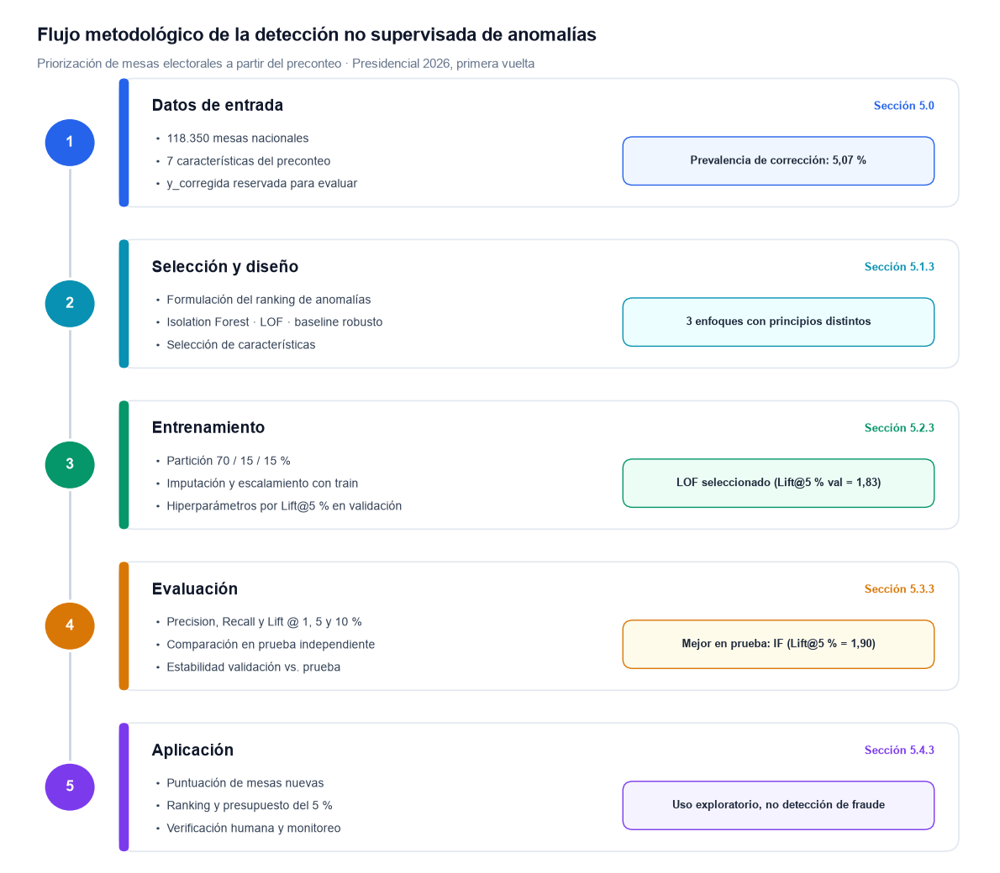

In [245]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle

etapas = [
    ("Datos de entrada", "5.0",
     ["118.350 mesas nacionales", "7 características del preconteo",
      "y_corregida reservada para evaluar"],
     "Prevalencia de corrección: 5,07 %"),
    ("Selección y diseño", "5.1.3",
     ["Formulación del ranking de anomalías", "Isolation Forest · LOF · baseline robusto",
      "Selección de características"],
     "3 enfoques con principios distintos"),
    ("Entrenamiento", "5.2.3",
     ["Partición 70 / 15 / 15 %", "Imputación y escalamiento con train",
      "Hiperparámetros por Lift@5 % en validación"],
     "LOF seleccionado (Lift@5 % val = 1,83)"),
    ("Evaluación", "5.3.3",
     ["Precision, Recall y Lift @ 1, 5 y 10 %", "Comparación en prueba independiente",
      "Estabilidad validación vs. prueba"],
     "Mejor en prueba: IF (Lift@5 % = 1,90)"),
    ("Aplicación", "5.4.3",
     ["Puntuación de mesas nuevas", "Ranking y presupuesto del 5 %",
      "Verificación humana y monitoreo"],
     "Uso exploratorio, no detección de fraude"),
]

acentos = ["#2563EB", "#0891B2", "#059669", "#D97706", "#7C3AED"]
fondos  = ["#EFF6FF", "#ECFEFF", "#ECFDF5", "#FFFBEB", "#F5F3FF"]

fig, ax = plt.subplots(figsize=(12, 10.5))
ax.set_xlim(0, 12); ax.set_ylim(0, 11); ax.axis("off")
fig.patch.set_facecolor("white")

alto, sep, y0 = 1.65, 0.42, 8.45
x_card, w_card = 1.35, 10.25
x_line = 0.75

# Línea de tiempo
y_top = y0 + alto / 2
y_bot = y0 - (len(etapas) - 1) * (alto + sep) + alto / 2
ax.plot([x_line, x_line], [y_bot, y_top], color="#CBD5E1", lw=2, zorder=0)

for i, ((titulo, seccion, items, resultado), ac, bg) in enumerate(zip(etapas, acentos, fondos)):
    y = y0 - i * (alto + sep)          # borde inferior de la tarjeta
    yc = y + alto / 2

    # Tarjeta
    ax.add_patch(FancyBboxPatch((x_card, y), w_card, alto,
        boxstyle="round,pad=0,rounding_size=0.18",
        facecolor="white", edgecolor="#E2E8F0", lw=1.2, zorder=1))
    # Franja de color a la izquierda
    ax.add_patch(FancyBboxPatch((x_card, y), 0.12, alto,
        boxstyle="round,pad=0,rounding_size=0.06",
        facecolor=ac, edgecolor="none", zorder=2))

    # Número en la línea de tiempo
    ax.add_patch(Circle((x_line, yc), 0.32, facecolor=ac, edgecolor="white", lw=2.5, zorder=3))
    ax.text(x_line, yc, str(i + 1), ha="center", va="center",
            fontsize=13, fontweight="bold", color="white", zorder=4)

    # Título y sección
    ax.text(x_card + 0.4, y + alto - 0.36, titulo, ha="left", va="center",
            fontsize=13.5, fontweight="bold", color="#0F172A")
    ax.text(x_card + w_card - 0.3, y + alto - 0.36, f"Sección {seccion}",
            ha="right", va="center", fontsize=9.5, color=ac, fontweight="bold")

    # Contenido
    for j, item in enumerate(items):
        ax.text(x_card + 0.45, y + alto - 0.78 - j * 0.29, "•  " + item,
                ha="left", va="center", fontsize=10.2, color="#334155")

    # Resultado clave
    ax.add_patch(FancyBboxPatch((x_card + 6.15, y + 0.28), 3.8, 0.62,
        boxstyle="round,pad=0,rounding_size=0.12",
        facecolor=bg, edgecolor=ac, lw=1, zorder=2))
    ax.text(x_card + 6.15 + 1.9, y + 0.59, resultado, ha="center", va="center",
            fontsize=9.3, color="#1E293B", fontweight="bold", zorder=3)

ax.text(0.35, 10.65, "Flujo metodológico de la detección no supervisada de anomalías",
        ha="left", va="center", fontsize=16, fontweight="bold", color="#0F172A")
ax.text(0.35, 10.28, "Priorización de mesas electorales a partir del preconteo · Presidencial 2026, primera vuelta",
        ha="left", va="center", fontsize=10.5, color="#64748B")

plt.tight_layout()
plt.show()

### **5.1. Seleccion y diseño de modelos**

In [246]:
import pandas as pd
from pathlib import Path

ruta = Path("../../data/processed/dataset_maestro.csv")

maestro = pd.read_csv(
    ruta,
    dtype={
        "dep": "string",
        "mun": "string",
        "zona": "string",
        "puesto": "string",
        "mesa": "string"
    }
)

print("Dimensiones:", maestro.shape)
print("Columnas:", maestro.columns.tolist())
print("Llaves duplicadas:", maestro.duplicated(
    ["dep", "mun", "zona", "puesto", "mesa"]
).sum())
maestro.head(10)

Dimensiones: (118350, 40)
Columnas: ['dep', 'mun', 'zona', 'puesto', 'mesa', 'total_votos_preconteo', 'numero_registros', 'opciones_reportadas', 'votos_blancos', 'votos_nulos', 'votos_no_marcados', 'proporcion_blancos', 'proporcion_nulos', 'proporcion_no_marcados', 'margen_primero_segundo', 'concentracion_maxima', 'sin_votos_preconteo', 'magnitud', 'y_corregida', 'e11_sospechoso', 'potencial', 'sufragantes_e11', 'en_terminos', 'estado_sobre', 'tachaduras_enmendaduras', 'recontada_jurados', 'recontada_comision', 'excluida', 'firmas_jurados', 'votos_urna', 'votos_incinerados', 'sufragantes_e11_segun_e14', 'total_votos_novedades', 'tasa_retirados', 'hhi', 'dif_pre_e11', 'abs_dif_pre_e11', 'dif_e14_e11', 'dif_urna_e11', 'participacion_e11']
Llaves duplicadas: 0


,dep,mun,zona,puesto,mesa,total_votos_preconteo,numero_registros,opciones_reportadas,votos_blancos,votos_nulos,...,votos_incinerados,sufragantes_e11_segun_e14,total_votos_novedades,tasa_retirados,hhi,dif_pre_e11,abs_dif_pre_e11,dif_e14_e11,dif_urna_e11,participacion_e11
0,01,001,001,01,000001,127,16,16,3,0,...,0,128,127,0.000000,0.339547,-1.0,1.0,0,0,0.355556
1,01,001,001,01,000002,65,16,16,3,0,...,0,65,65,0.000000,0.503122,0.0,0.0,0,0,0.180556
2,01,001,001,01,000003,107,16,16,0,2,...,0,107,107,0.000000,0.297234,0.0,0.0,0,0,0.297222
3,01,001,001,01,000004,143,16,16,3,2,...,0,143,143,0.000000,0.352132,0.0,0.0,0,0,0.397222
4,01,001,001,01,000005,177,16,16,3,4,...,0,177,177,0.000000,0.371801,0.0,0.0,0,0,0.491667
5,01,001,001,01,000006,172,16,16,5,3,...,0,172,172,0.005814,0.312344,0.0,0.0,0,0,0.477778
6,01,001,001,01,000007,209,16,16,4,4,...,0,209,209,0.004785,0.337500,0.0,0.0,0,0,0.580556
7,01,001,001,01,000008,211,16,16,7,6,...,0,211,211,0.004739,0.322734,0.0,0.0,0,0,0.586111
8,01,001,001,01,000009,206,16,16,4,1,...,0,206,206,0.004854,0.311100,0.0,0.0,0,0,0.572222
9,01,001,001,01,000010,208,16,16,8,7,...,0,208,208,0.000000,0.307091,0.0,0.0,0,0,0.577778


#### 5.1.1. Clasificación supervisada

##### 5.1.1.1. Formulación del problema

Se diseñan tres clasificadores, en este orden: **árbol de decisión** (línea base interpretable), **random forest** (modelo principal) y **KNN** (comparación).

Cada mesa $i$ tiene un vector de características $\mathbf{x}_i$ y una etiqueta

$$
y_i = 1 \text{ si la mesa fue corregida en el escrutinio},\qquad y_i = 0 \text{ en caso contrario.}
$$

El modelo estima la **probabilidad de corrección** $\hat{p}(\mathbf{x})$ de una mesa y la marca como corregida si supera un umbral $\tau$:

$$
\hat{y} = 1 \quad\text{si}\quad \hat{p}(\mathbf{x}) \ge \tau.
$$

**Desbalance.** Solo el $5{,}07\,\%$ de las mesas (5.998 de 118.350) fue corregido. Un modelo que siempre responda "no corregida" acierta el $94{,}93\,\%$ sin detectar ninguna, así que la exactitud no sirve como métrica principal y $\tau$ no se fija en $0{,}5$ (ver 5.1.1.7).

##### 5.1.1.2. Selección de características

Se definen dos conjuntos para medir cuánto aporta cada fuente. Esto responde a la recomendación de 5.0.10 de estudiar por separado las diferencias entre formularios, porque pueden reproducir indirectamente la etiqueta.

| Conjunto | Variables | $p$ |
|---|---|---:|
| **A. Preconteo** | `total_votos_preconteo`, `proporcion_blancos`, `proporcion_nulos`, `proporcion_no_marcados`, `margen_primero_segundo`, `concentracion_maxima`, `hhi`, `tasa_retirados` | 8 |
| **B. A + consistencia entre formularios** | A, más `dif_pre_e11`, `dif_e14_e11`, `dif_urna_e11`, `participacion_e11`, `tachaduras_enmendaduras`, `estado_sobre`, `recontada_jurados` | 15 |

Como análisis de sensibilidad se añade **B sin `dif_pre_e11`**: esa variable concentra la señal (5.0.16) y los modelos de árboles la elegirán primero, por lo que este conjunto muestra qué aportan las demás.

**Variables excluidas**

| Variable(s) | Motivo |
|---|---|
| `dep`, `mun`, `zona`, `puesto`, `mesa` | Identificadores nominales: su valor numérico no tiene sentido como distancia |
| `y_corregida`, `magnitud` | Variable objetivo y su magnitud (fuga directa) |
| `e11_sospechoso` | Reservada para evaluación (5.0.10); solo se usó para anular `dif_pre_e11` en 145 mesas |
| `recontada_comision`, `excluida` | Pueden reflejar actuaciones posteriores (5.0.10) |
| `total_votos_novedades` | Momento de captura no verificado: difiere del preconteo en 5.619 mesas, cifra cercana a las 5.998 corregidas, por lo que podría ya incorporar el escrutinio |
| `abs_dif_pre_e11` | Redundante con `dif_pre_e11` |
| Conteos absolutos (`votos_blancos`, `votos_nulos`, `votos_no_marcados`, `sufragantes_e11`, `votos_urna`, `potencial`, `numero_registros`, `opciones_reportadas`) | Ya representados por proporciones y diferencias |
| `en_terminos`, `votos_incinerados`, `firmas_jurados` | Variabilidad casi nula |

> **Nota sobre `estado_sobre`.** El estado del sobre se registra cuando el material llega a la comisión escrutadora, por lo que en rigor no está disponible antes del escrutinio (sección 5.0.10). Se mantuvo en el conjunto B porque su relación con la corrección es mínima: solo 334 mesas (0,3 %) tienen el sobre en mal estado, y se corrigen en una proporción casi igual a la del resto (5,7 % frente a 5,1 %). Su importancia por permutación en el clasificador es prácticamente nula (sección 5.3.1.5), así que no explica el desempeño del modelo, que depende de la consistencia entre el preconteo y los formularios de la mesa.

##### 5.1.1.3. Árbol de decisión (línea base interpretable)

**Idea.** El árbol hace preguntas de sí/no sobre una variable (por ejemplo, "¿`dif_pre_e11` es distinta de 0?") hasta dejar grupos de mesas parecidas, llamados *hojas*. La probabilidad de una mesa es la fracción de corregidas en su hoja:

$$
\hat{p}(\mathbf{x}) = \frac{\text{mesas corregidas en la hoja}}{\text{mesas en la hoja}}.
$$

**Cómo elige las preguntas.** En cada nodo mide qué tan mezcladas están las mesas con la impureza de Gini, donde $p$ es la fracción de corregidas del nodo:

$$
G = 2p(1-p).
$$

$G=0$ si el nodo es puro y $G$ es máxima ($0{,}5$) si está mitad y mitad. Elige la pregunta que más reduce la impureza al dividir el nodo en dos hijos (I y D):

$$
\Delta G = G_{\text{padre}} - \left(\frac{n_I}{n}\,G_I + \frac{n_D}{n}\,G_D\right).
$$

**Por qué un árbol aquí**

- Se lee como reglas ("si hay diferencia con el E-11 y el sobre está mal, entonces…"), útil para explicar el resultado.
- No necesita escalar variables y la señal principal es un umbral, que el árbol encuentra directamente.
- Admite `class_weight` para dar más peso a la clase corregida.

**Cuidados**

| Riesgo | Decisión |
|---|---|
| Sin límites, el árbol memoriza (solo 5 % de positivos) | Limitar `max_depth` y `min_samples_leaf` en 5.2.1 |
| Elegirá `dif_pre_e11` en la raíz, casi una definición de la etiqueta | Comparar conjuntos A, B y B sin `dif_pre_e11` (5.1.1.2) |
| Un solo árbol es inestable: cambia mucho con pocos datos | Se usa como referencia, no como modelo final |

##### 5.1.1.4. Random forest (modelo principal)

**Idea.** Combina $B$ árboles distintos y promedia sus probabilidades:

$$
\hat{p}(\mathbf{x}) = \frac{1}{B}\sum_{b=1}^{B}\hat{p}_b(\mathbf{x}).
$$

Cada árbol se entrena con una muestra aleatoria con reemplazo de las mesas (*bootstrap*) y, en cada división, solo considera un subconjunto aleatorio de $m$ variables. Así los árboles se equivocan de formas diferentes y el promedio reduce el sobreajuste.

**Por qué random forest aquí**

- Suele superar a un árbol solo, sin perder la capacidad de captar umbrales e interacciones entre variables.
- Tolera variables correlacionadas y valores extremos (5.0.9), y no requiere escalar.
- Permite medir qué variables importan.

**Cuidados**

| Riesgo | Decisión |
|---|---|
| Sus probabilidades salen mal calibradas | Elegir $\tau$ en validación cruzada y revisar la curva de calibración; si hace falta, calibrar con regresión isotónica sobre predicciones fuera de muestra |
| La importancia por impureza favorece variables continuas | Usar **importancia por permutación**: caída de la *average precision* al barajar una variable en validación |
| Sobreajuste y dependencia de `dif_pre_e11` | Limitar `min_samples_leaf` y `max_features`; comparar A, B y B sin `dif_pre_e11` |
| Costo de cómputo | $B = 300$ árboles y entrenamiento en paralelo |

##### 5.1.1.5. K vecinos más cercanos (KNN, comparación)

**Idea.** KNN no ajusta parámetros: guarda las mesas de entrenamiento y, para una mesa nueva, mira las $k$ más parecidas. Su probabilidad es la fracción de esas vecinas que fueron corregidas:

$$
\hat{p}(\mathbf{x}) = \frac{1}{k}\sum_{i \,\in\, \text{vecinos}} y_i .
$$

Con pesos por distancia, las vecinas más cercanas cuentan más. "Parecida" significa distancia pequeña, euclidiana (o Manhattan como alternativa):

$$
d(\mathbf{x},\mathbf{x}') = \sqrt{\sum_{j}(x_j - x'_j)^2}
\qquad\text{o}\qquad
d(\mathbf{x},\mathbf{x}') = \sum_{j}|x_j - x'_j| .
$$

**Por qué incluirlo.** Aporta una lógica distinta, "mesas parecidas a mesas corregidas", para contrastar con los modelos de árboles, y también entrega una probabilidad.

**Limitaciones y cómo se atienden**

| Limitación | Consecuencia | Decisión |
|---|---|---|
| Variables con escalas distintas | Las de rango grande dominan la distancia | Estandarizar (5.1.1.6) |
| Solo 5 % de mesas corregidas | Casi ninguna vecindad tiene mayoría corregida, así que con $\tau = 0{,}5$ casi nunca predice 1 | Elegir $\tau < 0{,}5$ en validación |
| Muchas variables | Todas las mesas quedan "igual de lejos" | Usar pocas variables (8 o 15) |
| Predecir es lento (compara con todo el entrenamiento) | Costo alto con ≈ 95.000 mesas | Usar KD-tree o Ball-tree |

##### 5.1.1.6. Preprocesamiento

Todo se ajusta **solo con el conjunto de entrenamiento**, dentro de un `Pipeline`, para que nada de validación o prueba influya en el modelo.

| Paso | Qué hace | Por qué | Árbol y RF | KNN |
|---|---|---|:---:|:---:|
| 1. Imputación | Reemplaza los vacíos (`dif_pre_e11` en 145 mesas; `tasa_retirados` y `hhi` en 6) por la **mediana** de entrenamiento | Mantener las mismas mesas en todos los modelos | Sí | Sí |
| 2. Binarias | SI → 1, NO → 0; `estado_sobre`: MAL → 1, BUENO → 0 | Pasar categorías a números | Sí | Sí |
| 3. Log con signo | $t(x)=\operatorname{sign}(x)\,\ln(1+\lvert x\rvert)$ en las tres diferencias | Las diferencias casi siempre son 0 pero llegan a miles (5.0.9). Así $0\to0$, $5\to1{,}8$, $300\to5{,}7$: se conservan el signo y los extremos sin que dominen la distancia | No | Sí |
| 4. Estandarización | $z=\dfrac{x-\text{media}}{\text{desviación}}$ | Todas las variables pesan parecido en la distancia | No | Sí |

Los pasos 3 y 4 no se aplican a los árboles porque estos solo usan el orden de los valores.

##### 5.1.1.7. Diseño experimental y validación

**Particiones.** División 80/20 estratificada por `y_corregida`, con semilla fija.

| Partición | Mesas | Corregidas | Uso |
|---|---:|---:|---|
| Entrenamiento | ≈ 94.680 | ≈ 4.798 | Validación cruzada y ajuste (5.2.1) |
| Prueba | ≈ 23.670 | ≈ 1.200 | Reservada para 5.3.1 |

**Validación cruzada.** `StratifiedKFold` de 5 particiones sobre entrenamiento, con el `Pipeline` completo dentro de cada una. Las mesas de un mismo puesto o municipio se parecen (5.0.14) y esto podría inflar el resultado, sobre todo en árboles y random forest, así que se repetirá con `GroupKFold` por municipio como verificación.

**Hiperparámetros a explorar en 5.2.1**

| Modelo | Hiperparámetros y valores |
|---|---|
| Todos | Conjunto de variables: A, B, B sin `dif_pre_e11`; umbral $\tau$ elegido en validación cruzada para maximizar $F_2$ |
| Árbol de decisión | `max_depth`: 3, 5, 8, 12, sin límite · `min_samples_leaf`: 5, 20, 50, 100 · `class_weight`: ninguno, balanceado |
| Random forest | $B = 300$ · `max_depth`: 8, 12, sin límite · `min_samples_leaf`: 5, 20, 50 · `max_features`: $\sqrt{p}$, $p/2$ · `class_weight`: ninguno, balanceado por muestra |
| KNN | $k$: 5, 11, 21, 51, 101, 201 · pesos: uniformes, por distancia · distancia: Manhattan, euclidiana |

**Métricas.** Con precisión $P$ (de las mesas marcadas, cuántas eran corregidas) y recall $R$ (de las corregidas, cuántas se detectaron):

$$
F_2 = \frac{5\,P\,R}{4P + R}
$$

$F_2$ pesa más el recall, porque omitir una mesa corregida cuesta más que revisar una de más. La métrica principal es el área bajo la curva precisión–recall (*average precision*); un modelo sin información obtiene $0{,}0507$ (la prevalencia). También se reportan $P$, $R$, ROC-AUC y la matriz de confusión. Para árbol y random forest se añaden la importancia por permutación y la curva de calibración.

**Referencias de comparación**

1. Clasificador por prevalencia (`DummyClassifier`): *average precision* $= 0{,}0507$.
2. Regla simple "`dif_pre_e11` $\neq 0$": en todo el dataset (5.0.16) da $P=56{,}5\,\%$ y $R=89{,}7\,\%$. El conjunto B debe superarla o complementarla; el A indica si el preconteo solo ya aporta señal.

#### 5.1.2. Regresión supervisada

##### 5.1.2.1. Formulación y diseño del modelo

###### Formulación del problema

Se plantea un problema de **regresión supervisada**: estimar cuántos votos cambian entre el preconteo y el escrutinio en una mesa que fue corregida. La variable objetivo es `magnitud`, la suma de los cambios absolutos por candidatura, en el voto en blanco, en el nulo y en los no marcados, descontando el traslado de los votos de los candidatos retirados 009 y 013 al código 998.

Sea $\mathbf{x}_i \in \mathbb{R}^{26}$ el vector de variables de entrada de la mesa $i$ y $m_i$ su magnitud. Se busca una función

$$
f: \mathbb{R}^{26} \rightarrow \mathbb{R}, \qquad f(\mathbf{x}_i) \approx \log(1 + m_i)
$$

entrenada solo con las mesas corregidas ($m_i > 0$). La predicción en votos se obtiene con $\hat{m}_i = e^{f(\mathbf{x}_i)} - 1$.

###### Diseño en dos etapas

El 94,9 % de las mesas tiene magnitud 0. Una regresión entrenada con todas las mesas aprendería a predecir casi siempre cero y no distinguiría correcciones pequeñas de grandes. Por eso el problema se divide en dos etapas:

1. **Etapa 1, clasificación (5.1.1):** ¿la mesa será corregida?
2. **Etapa 2, regresión (esta sección):** si se corrige, ¿cuántos votos cambian?

La estimación final de una mesa combina las dos: magnitud esperada = probabilidad de corrección × magnitud estimada si se corrige. Esto permite priorizar no solo las mesas con más probabilidad de corrección, sino las que tienen más votos en juego.

###### Transformación de la variable objetivo

Entre las mesas corregidas, la magnitud es muy asimétrica: la mediana es de 3 votos y el máximo de 490. Si se modela directamente, las pocas correcciones grandes dominarían el ajuste. Por eso se modela $\log(1 + m)$ (`log1p`), que comprime la cola larga, y las predicciones se devuelven a votos con `expm1` para evaluarlas en unidades interpretables.

###### Selección y justificación de los modelos

| Modelo | Por qué se incluye | Hiperparámetros a explorar |
|---|---|---|
| **Regresión lineal con regularización (Ridge)** | Punto de partida interpretable. La regularización L2 controla la colinealidad entre los conteos de votos (total del preconteo, E-11, E-14 y votos en urna están muy correlacionados) | `alpha`: 0,1; 1; 10; 100 |
| **Random Forest** | Promedia muchos árboles de decisión: captura relaciones no lineales y umbrales (por ejemplo, "si la diferencia con el E-11 supera *k* votos"), es robusto a valores extremos y no requiere escalar las variables | `max_depth`: 6, 12, sin límite · `min_samples_leaf`: 5, 20 |
| **Gradient Boosting (HistGradientBoosting)** | Construye árboles de forma secuencial, cada uno corrigiendo el error de los anteriores. Suele ser el más preciso en datos tabulares y maneja valores faltantes sin imputar | `learning_rate`: 0,03; 0,1 · `max_leaf_nodes`: 15, 31 |

###### Variables de entrada

Se usan 26 variables, todas disponibles antes del escrutinio (lista `ENTRADAS`, definida más abajo). La más relevante es la diferencia entre el total del preconteo y los votantes del E-11 (`dif_pre_e11`, `abs_dif_pre_e11`): si el preconteo no cuadra con el número de votantes, es esperable que la corrección sea del tamaño de esa diferencia. `magnitud` y `y_corregida` no se usan como entrada.

###### Métricas y línea base

| Métrica | Qué mide |
|---|---|
| **MAE** (error absoluto medio, en votos) | Error promedio de la estimación; métrica principal por ser directamente interpretable |
| **RMSE** (raíz del error cuadrático medio, en votos) | Penaliza más los errores grandes; su diferencia con el MAE indica si hay errores grandes en pocas mesas |
| **R² en escala logarítmica** | Proporción de la variabilidad de `log1p(magnitud)` que explica el modelo |

**Línea base:** predecir para todas las mesas la mediana de la magnitud del entrenamiento. Un modelo útil debe tener un error claramente menor.

###### Diseño experimental

- **Entrenamiento:** mesas corregidas de los departamentos de entrenamiento.
- **Selección de hiperparámetros:** búsqueda en rejilla (`GridSearchCV`) con validación cruzada de 5 particiones agrupada por departamento (`GroupKFold`), minimizando el MAE en escala logarítmica.
- **Evaluación final:** una sola vez, sobre las mesas corregidas de los departamentos de prueba.
- **Preprocesamiento:** la imputación de vacíos (mediana) y el escalado (solo para Ridge) van dentro de un `Pipeline`, de modo que se ajustan únicamente con los datos de entrenamiento de cada partición.

##### 5.1.2.2. Carga del dataset de modelado

Se carga el dataset maestro construido en la sección 5.0, con las llaves de la mesa como texto para conservar los ceros a la izquierda. Se verifica que tenga las 40 columnas generadas en la sección 5.0.16; si se leyera una versión anterior (33 columnas), el notebook se detiene con un mensaje, en lugar de entrenar con variables incompletas.

In [247]:
import pandas as pd
from pathlib import Path

ruta = Path("../../data/processed/dataset_maestro.csv")

maestro = pd.read_csv(
    ruta,
    dtype={
        "dep": "string",
        "mun": "string",
        "zona": "string",
        "puesto": "string",
        "mesa": "string"
    }
)

print("Dimensiones:", maestro.shape)
print("Llaves duplicadas:", maestro.duplicated(
    ["dep", "mun", "zona", "puesto", "mesa"]
).sum())

assert maestro.shape[1] == 40, (
    f"El dataset tiene {maestro.shape[1]} columnas: ejecute primero la sección 5.0.16"
)
maestro.head()

Dimensiones: (118350, 40)
Llaves duplicadas: 0


,dep,mun,zona,puesto,mesa,total_votos_preconteo,numero_registros,opciones_reportadas,votos_blancos,votos_nulos,...,votos_incinerados,sufragantes_e11_segun_e14,total_votos_novedades,tasa_retirados,hhi,dif_pre_e11,abs_dif_pre_e11,dif_e14_e11,dif_urna_e11,participacion_e11
0,01,001,001,01,000001,127,16,16,3,0,...,0,128,127,0.0,0.339547,-1.0,1.0,0,0,0.355556
1,01,001,001,01,000002,65,16,16,3,0,...,0,65,65,0.0,0.503122,0.0,0.0,0,0,0.180556
2,01,001,001,01,000003,107,16,16,0,2,...,0,107,107,0.0,0.297234,0.0,0.0,0,0,0.297222
3,01,001,001,01,000004,143,16,16,3,2,...,0,143,143,0.0,0.352132,0.0,0.0,0,0,0.397222
4,01,001,001,01,000005,177,16,16,3,4,...,0,177,177,0.0,0.371801,0.0,0.0,0,0,0.491667


##### 5.1.2.3. Preparación de los datos y partición

La siguiente celda prepara los datos del modelado. Las variables que define (`X`, `y`, `grupos`, `idx_tr`, `idx_te` y `CV`) son comunes a los tres componentes del proyecto, para que todos entrenen con las mismas variables y se evalúen sobre las mismas mesas.

**1. Conversión de las banderas.** `tachaduras_enmendaduras` y `recontada_jurados` vienen como texto (`SI` / `NO`) y se convierten a 1 / 0, porque los modelos de scikit-learn solo aceptan valores numéricos.

**2. Selección de las variables de entrada.** Se define de forma explícita la lista `ENTRADAS` con las 26 variables que puede usar el modelo, todas disponibles **antes** del escrutinio. El dataset maestro conserva el resto de columnas como referencia, pero estas no entran al modelo:

| Columnas excluidas | Razón |
|---|---|
| `total_votos_novedades`, `recontada_comision`, `excluida`, `estado_sobre`, `en_terminos` | **Fuga de información:** se registran durante el escrutinio. `total_votos_novedades` es igual al total del escrutinio, y el 100 % de las mesas excluidas y el 89 % de las recontadas por la comisión fueron corregidas |
| `numero_registros`, `opciones_reportadas` | Describen el formato de transmisión del preconteo, que depende del departamento, y no una característica de la mesa |
| `dep`, `mun`, `zona`, `puesto`, `mesa` | Identifican la mesa; se conservan para unir resultados y para agrupar por departamento |
| `y_corregida`, `magnitud` | Son las variables objetivo |

**3. Partición en entrenamiento y prueba por departamento.** No se usa una partición aleatoria por mesa (`train_test_split`), porque las mesas de un mismo departamento comparten la comisión escrutadora, el formato de transmisión del preconteo y una tasa de corrección propia (entre 2,6 % y 8,9 % según el departamento). Si mesas del mismo departamento quedaran en entrenamiento y en prueba, el modelo podría acertar por reconocer el territorio y la evaluación sería optimista.

Por eso se usa `GroupShuffleSplit`, que reserva para prueba el **25 % de los departamentos completos**. El modelo nunca ve esas mesas durante el entrenamiento, así que la prueba mide su capacidad de generalizar a departamentos nuevos. Se fija `random_state=0` para que la partición sea la misma cada vez que se ejecuta el notebook. Como `GroupShuffleSplit` está pensado para generar varias particiones, devuelve un generador; con `next()` se toma la única partición solicitada (`n_splits=1`). El resultado son los índices de fila de cada conjunto (`idx_tr`, `idx_te`).

**4. Validación cruzada agrupada.** Se define `GroupKFold` con 5 particiones, que se usa en la búsqueda de hiperparámetros dentro del entrenamiento: el entrenamiento se divide en 5 grupos de departamentos y cada configuración se entrena 5 veces, validando cada vez con un grupo distinto. Así se eligen los hiperparámetros sin usar la partición de prueba, y con el mismo criterio de departamentos no vistos que la evaluación final.

**5. Verificación de la partición.** Al final se construye una tabla resumen que describe los dos conjuntos: número de mesas, de departamentos y de mesas corregidas, y el porcentaje de corregidas (el promedio de `y_corregida`, que vale 1 o 0). Esta verificación es necesaria porque la partición por departamentos no puede estratificarse por la variable objetivo; la tabla permite comprobar que la proporción de mesas corregidas es similar en ambos conjuntos.

In [248]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

LLAVE = ["dep", "mun", "zona", "puesto", "mesa"]
df = maestro.copy()

for col in ["tachaduras_enmendaduras", "recontada_jurados"]:
    df[col] = df[col].eq("SI").astype(int)

# Se excluyen por fuga: total_votos_novedades, recontada_comision, excluida, estado_sobre, en_terminos
# Se excluyen por describir el formato de transmisión: numero_registros, opciones_reportadas
ENTRADAS = [
    "total_votos_preconteo", "votos_blancos", "votos_nulos", "votos_no_marcados",
    "proporcion_blancos", "proporcion_nulos", "proporcion_no_marcados",
    "margen_primero_segundo", "concentracion_maxima", "sin_votos_preconteo",
    "e11_sospechoso", "potencial", "sufragantes_e11", "tachaduras_enmendaduras",
    "recontada_jurados", "firmas_jurados", "votos_urna", "votos_incinerados",
    "sufragantes_e11_segun_e14", "tasa_retirados", "hhi",
    "dif_pre_e11", "abs_dif_pre_e11", "dif_e14_e11", "dif_urna_e11", "participacion_e11",
]
X, y, grupos = df[ENTRADAS], df["y_corregida"], df["dep"]

# Partición común: 25 % de los departamentos para prueba
idx_tr, idx_te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0)
                      .split(X, y, grupos))
CV = GroupKFold(n_splits=5)

particion = pd.DataFrame({
    "mesas": [len(idx_tr), len(idx_te)],
    "departamentos": [grupos.iloc[idx_tr].nunique(), grupos.iloc[idx_te].nunique()],
    "mesas corregidas": [int(y.iloc[idx_tr].sum()), int(y.iloc[idx_te].sum())],
    "% corregidas": [round(y.iloc[idx_tr].mean() * 100, 2), round(y.iloc[idx_te].mean() * 100, 2)],
}, index=["entrenamiento", "prueba"])
display(particion)
print("Departamentos de prueba:", sorted(grupos.iloc[idx_te].unique()))

,mesas,departamentos,mesas corregidas,% corregidas
entrenamiento,85994,24,4292,4.99
prueba,32356,9,1706,5.27


Departamentos de prueba: ['05', '17', '19', '26', '27', '31', '48', '50', '52']


**Lectura:** la partición deja 85 994 mesas para entrenamiento (24 departamentos) y 32 356 para prueba (9 departamentos: 05, 17, 19, 26, 27, 31, 48, 50 y 52). Como se reparten departamentos y no mesas, la prueba tiene el 27 % de las mesas y no exactamente el 25 %. La proporción de mesas corregidas es similar en ambos conjuntos (4,99 % en entrenamiento y 5,27 % en prueba), por lo que la prueba es representativa aunque la partición no se haya estratificado.

##### 5.1.2.4. Datos de la regresión: mesas corregidas

La regresión se entrena y evalúa solo con las mesas corregidas (`y_corregida = 1`), respetando la misma partición por departamentos. Se cruzan los índices de entrenamiento y prueba con los de las mesas corregidas, y se definen:

- `Xr_tr`, `Xr_te`: las 26 variables de entrada de las mesas corregidas de cada conjunto.
- `yr_tr`: el objetivo de entrenamiento, `log1p(magnitud)`.
- `yr_te`: el objetivo de prueba **en votos**, porque la evaluación se reporta en votos después de deshacer la transformación.
- `gr_tr`: el departamento de cada mesa de entrenamiento, para la validación cruzada agrupada.

Los histogramas comparan la distribución de la magnitud en votos y en escala `log1p`.

Mesas corregidas: 4,292 en entrenamiento | 1,706 en prueba


,magnitud (votos)
count,5998.00
mean,13.14
std,34.12
min,1.00
25%,1.00
50%,3.00
75%,8.00
max,490.00


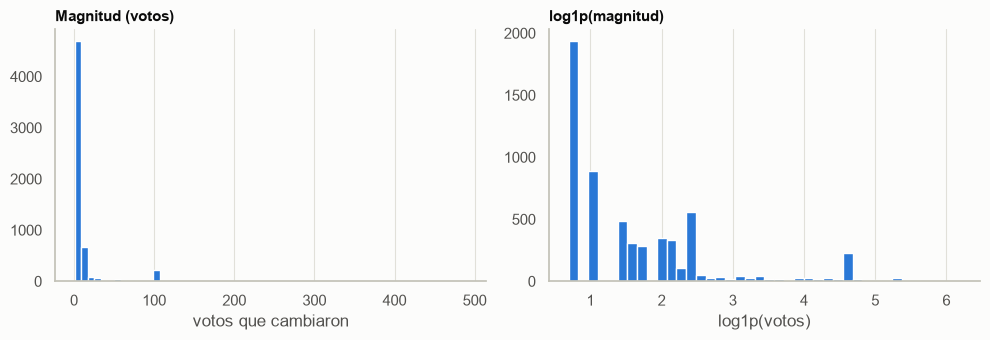

In [249]:
corr = (df["y_corregida"] == 1).to_numpy()
tr_corr = np.intersect1d(idx_tr, np.where(corr)[0])
te_corr = np.intersect1d(idx_te, np.where(corr)[0])

Xr_tr, Xr_te = X.iloc[tr_corr], X.iloc[te_corr]
yr_tr = np.log1p(df["magnitud"].iloc[tr_corr])        # objetivo en escala log
yr_te = df["magnitud"].iloc[te_corr].to_numpy()       # en votos, para evaluar
gr_tr = grupos.iloc[tr_corr]

print(f"Mesas corregidas: {len(tr_corr):,} en entrenamiento | {len(te_corr):,} en prueba")
display(df.loc[corr, "magnitud"].describe().round(2).to_frame("magnitud (votos)"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df.loc[corr, "magnitud"], bins=60, color="#2a78d6")
axes[0].set_title("Magnitud (votos)"); axes[0].set_xlabel("votos que cambiaron")
axes[1].hist(np.log1p(df.loc[corr, "magnitud"]), bins=40, color="#2a78d6")
axes[1].set_title("log1p(magnitud)"); axes[1].set_xlabel("log1p(votos)")
plt.tight_layout(); plt.show()

**Lectura:** la regresión se entrena con 4 292 mesas corregidas de los departamentos de entrenamiento y se evalúa con 1 706 de los departamentos de prueba. La magnitud está muy concentrada en valores pequeños: en 1 933 mesas (32 %) cambió un solo voto, la mitad de las correcciones es de 3 votos o menos y el 75 % de 8 o menos, con una cola larga que llega hasta 490 votos (media de 13,1 votos frente a una mediana de 3). En escala `log1p` la distribución queda más repartida, lo que justifica entrenar el modelo en esa escala para que las pocas correcciones grandes no dominen el ajuste.

Destacan dos picos: 555 mesas con exactamente 10 votos de diferencia (frente a 108 con 9 y 30 con 11) y 201 con exactamente 100. Este patrón es consistente con errores de digitación en el preconteo, donde un dígito equivocado en las decenas o centenas produce diferencias de 10 o 100 votos que el escrutinio corrige. No puede confirmarse sin los formularios físicos, pero indica que una parte de las correcciones responde a errores de transcripción y no a cambios en la votación.

#### 5.1.3. Detección no supervisada de anomalías

En concordancia con los objetivos y el alcance definidos en la fase de entendimiento del negocio, este componente desarrolla un enfoque de aprendizaje no supervisado para identificar y priorizar mesas electorales con patrones estadísticamente atípicos.

Se utiliza como fuente el `dataset_maestro.csv`, compuesto por 118.350 mesas electorales y 33 columnas. Para el experimento inicial se consideran únicamente características derivadas del preconteo, reservando las variables del escrutinio para la evaluación posterior.

El diseño metodológico comprende la selección de algoritmos, el análisis de características, la definición de estrategias de preprocesamiento y el establecimiento de un protocolo de validación.

##### 5.1.3.1. Formulación matemática del problema


Sea $X \in \mathbb{R}^{n \times p}$ la matriz de características de las mesas electorales, donde $n = 118\,350$ y $p$ corresponde al número de variables seleccionadas.

El objetivo es estimar una función de puntuación:

$$
s: \mathbb{R}^{p} \rightarrow \mathbb{R}
$$

que permita ordenar las observaciones según su grado de anomalía, estableciendo por convención que valores mayores representan comportamientos más atípicos.

Las puntuaciones se calcularán sin utilizar las etiquetas `y_corregida` ni la variable `magnitud` durante el entrenamiento.

Posteriormente, el ordenamiento obtenido se contrastará con las correcciones observadas durante el escrutinio, utilizando métricas de priorización.

Esta evaluación permitirá determinar si los algoritmos concentran una proporción de mesas corregidas superior a la prevalencia general, sin equiparar una corrección electoral con una anomalía confirmada.


##### 5.1.3.2. Selección y justificación de algoritmos


Se seleccionaron dos algoritmos de detección no supervisada de anomalías: **Isolation Forest (IF)** y **Local Outlier Factor (LOF)**. Ambos permiten asignar puntuaciones de anomalía a observaciones sin utilizar etiquetas durante el ajuste, pero se fundamentan en principios diferentes.

La comparación busca determinar si los patrones atípicos de las mesas electorales se identifican mejor mediante mecanismos de aislamiento global o mediante diferencias de densidad local.

**Isolation Forest**

Isolation Forest (Liu et al., 2008) es un algoritmo basado en conjuntos de árboles de aislamiento (*isolation trees*). Su principio consiste en que las observaciones atípicas suelen requerir menos particiones aleatorias para quedar aisladas del resto de los datos.

El algoritmo construye múltiples árboles mediante selecciones aleatorias de características y puntos de corte. La puntuación de anomalía depende de la longitud promedio de los caminos recorridos para aislar cada observación.

Se selecciona por las siguientes características:

- Permite trabajar con conjuntos de datos grandes.
- No requiere asumir una distribución probabilística específica.
- Identifica observaciones alejadas de los patrones generales.
- Proporciona puntuaciones continuas para construir rankings de anomalías.

**Local Outlier Factor (LOF)**

Local Outlier Factor (Breunig et al., 2000) identifica anomalías mediante la comparación de la densidad local de una observación con la densidad de sus vecinos.

Una observación puede considerarse atípica cuando su densidad local es considerablemente inferior a la de las observaciones cercanas, incluso si no se encuentra alejada de la distribución global.

Se selecciona porque:

- Permite detectar anomalías relativas a grupos de observaciones.
- Puede identificar comportamientos atípicos que Isolation Forest no necesariamente prioriza.
- Resulta pertinente cuando existen subpoblaciones con patrones electorales diferentes.
- Complementa el enfoque global mediante un criterio de vecindad.

LOF requiere especial atención al escalamiento de características, la elección del número de vecinos y el costo computacional de las búsquedas de proximidad.

**Modelo de referencia (*baseline*)**

Adicionalmente, se considerará una puntuación estadística simple basada en desviaciones absolutas robustas respecto a la mediana.

Este baseline permitirá establecer si los algoritmos seleccionados aportan una mejora en la priorización de mesas respecto a un criterio estadístico menos complejo.

**Comparación de los métodos**

| Criterio | Isolation Forest | LOF | Baseline robusto |
|---|---|---|---|
| Principio | Aislamiento aleatorio | Densidad local | Desviación estadística |
| Tipo de anomalía | Principalmente global | Local | Principalmente marginal |
| Escalamiento | Menos sensible | Muy importante | Necesario para combinar variables |
| Parámetro principal | `max_samples` | `n_neighbors` | Regla de agregación |
| Costo computacional | Generalmente favorable | Dependiente de vecinos y dimensionalidad | Bajo |
| Puntuación continua | Sí | Sí | Sí |

**Decisión metodológica**

Se utilizará Isolation Forest como modelo inicial debido a su escalabilidad y capacidad de detectar patrones globales en las 118.350 mesas.

Posteriormente se comparará con LOF para estudiar si la información de densidad local permite identificar patrones complementarios.

El baseline robusto servirá como referencia para determinar si el incremento de complejidad de los modelos está acompañado de mejores resultados de priorización.

La comparación se realizará bajo un protocolo común de características, preprocesamiento y evaluación. Las puntuaciones se orientarán de manera consistente, de modo que valores mayores representen mayor anomalía.


##### 5.1.3.3. Selección de características



La selección de características constituye una etapa fundamental del diseño de los modelos no supervisados, debido a que las puntuaciones de anomalía dependen directamente de la representación de las observaciones.

Para el experimento inicial se consideran las 12 variables derivadas del preconteo electoral, excluyendo los identificadores geográficos, las variables objetivo del escrutinio y los indicadores de novedades.

Esta decisión busca evitar la fuga de información y establecer una línea base de detección basada exclusivamente en los patrones observables durante el preconteo.

El análisis de selección comprende cuatro aspectos:

1. **Completitud:** identificación de valores faltantes y variables con información insuficiente.
2. **Variabilidad:** identificación de características constantes o con distribuciones altamente concentradas.
3. **Redundancia:** análisis de correlaciones y relaciones entre características.
4. **Pertinencia:** evaluación de la interpretación electoral de cada variable y su posible contribución a la detección de anomalías.

La selección definitiva se realizará después del análisis exploratorio. Se prestará especial atención a las relaciones entre conteos absolutos y proporciones, para evitar que una misma dimensión del comportamiento electoral tenga una influencia desproporcionada en el modelo.

Las transformaciones necesarias para el entrenamiento, incluyendo imputación y escalamiento, se definirán posteriormente dentro de los procedimientos de preprocesamiento.


In [250]:

import pandas as pd
import numpy as np

features_candidatas = [
    "total_votos_preconteo",
    "numero_registros",
    "opciones_reportadas",
    "votos_blancos",
    "votos_nulos",
    "votos_no_marcados",
    "proporcion_blancos",
    "proporcion_nulos",
    "proporcion_no_marcados",
    "margen_primero_segundo",
    "concentracion_maxima",
    "sin_votos_preconteo"
]

X_candidatas = maestro[features_candidatas].copy()

resumen_features = pd.DataFrame({
    "tipo": X_candidatas.dtypes.astype(str),
    "nulos": X_candidatas.isna().sum(),
    "porcentaje_nulos": X_candidatas.isna().mean() * 100,
    "valores_unicos": X_candidatas.nunique(),
    "media": X_candidatas.mean(),
    "desviacion": X_candidatas.std(),
    "minimo": X_candidatas.min(),
    "mediana": X_candidatas.median(),
    "maximo": X_candidatas.max()
})

display(resumen_features.round(4))

print("Mesas analizadas:", len(X_candidatas))
print("Características candidatas:", X_candidatas.shape[1])
print("Valores faltantes totales:", X_candidatas.isna().sum().sum())


,tipo,nulos,porcentaje_nulos,valores_unicos,media,desviacion,minimo,mediana,maximo
total_votos_preconteo,int64,0,0.0000,418,197.6213,68.1295,0.0000,206.0000,546.0000
numero_registros,int64,0,0.0000,16,12.1151,4.0542,1.0000,13.0000,16.0000
opciones_reportadas,int64,0,0.0000,16,12.1151,4.0542,1.0000,13.0000,16.0000
votos_blancos,int64,0,0.0000,33,3.4004,2.6713,0.0000,3.0000,70.0000
votos_nulos,int64,0,0.0000,43,2.0649,2.3839,0.0000,1.0000,111.0000
votos_no_marcados,int64,0,0.0000,37,0.4000,1.6711,0.0000,0.0000,227.0000
proporcion_blancos,float64,6,0.0051,2463,0.0184,0.0160,0.0000,0.0154,0.4615
proporcion_nulos,float64,6,0.0051,2229,0.0106,0.0124,0.0000,0.0077,0.3974
proporcion_no_marcados,float64,6,0.0051,1099,0.0022,0.0082,0.0000,0.0000,0.6306
margen_primero_segundo,float64,6,0.0051,22554,0.3099,0.2077,0.0000,0.2812,1.0000


Mesas analizadas: 118350
Características candidatas: 12
Valores faltantes totales: 30


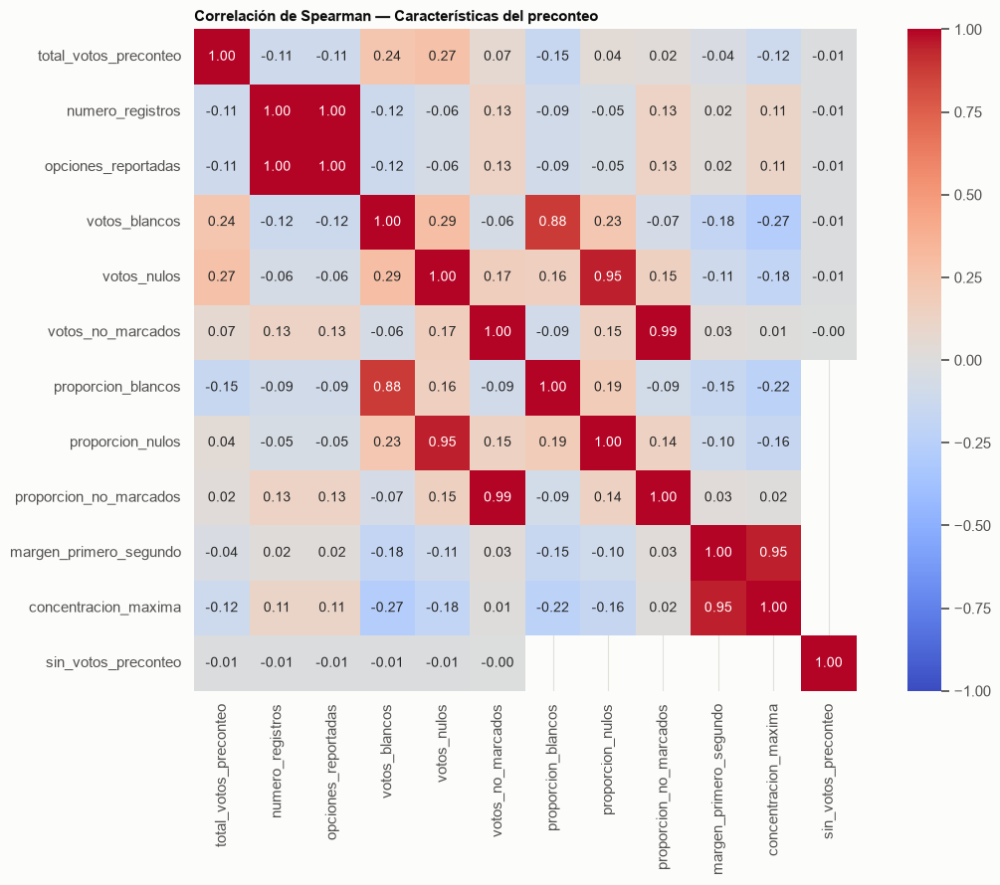

,,correlacion_absoluta
numero_registros,opciones_reportadas,1.000000
votos_no_marcados,proporcion_no_marcados,0.994537
votos_nulos,proporcion_nulos,0.947511
margen_primero_segundo,concentracion_maxima,0.946908
votos_blancos,proporcion_blancos,0.875176


In [251]:


import matplotlib.pyplot as plt
import seaborn as sns

corr = X_candidatas.corr(method="spearman")

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlación de Spearman — Características del preconteo")
plt.tight_layout()
plt.show()

# Pares de variables con correlación absoluta elevada
corr_abs = corr.abs()

triangulo_superior = np.triu(
    np.ones(corr_abs.shape, dtype=bool),
    k=1
)

pares_correlacionados = (
    corr_abs.where(triangulo_superior)
    .stack()
    .sort_values(ascending=False)
)

display(
    pares_correlacionados[
        pares_correlacionados >= 0.85
    ].rename("correlacion_absoluta").to_frame()
)


In [252]:

# 1. Verificar equivalencia exacta
iguales = (
    X_candidatas["numero_registros"]
    == X_candidatas["opciones_reportadas"]
)

print("Registros y opciones exactamente iguales:")
print(f"{iguales.mean():.4%}")

print("\nMesas donde difieren:")
print((~iguales).sum())

# 2. Distribución de valores faltantes
print("\nValores faltantes por característica:")
display(
    X_candidatas.isna()
    .sum()
    .loc[lambda x: x > 0]
    .to_frame("nulos")
)

# 3. Variabilidad de las características
print("\nValores únicos:")
display(
    X_candidatas.nunique()
    .sort_values()
    .to_frame("valores_unicos")
)

# 4. Examinar mesas sin votos
print("\nMesas sin votos:")
display(
    maestro.loc[
        maestro["sin_votos_preconteo"] == 1,
        ["dep", "mun", "zona", "puesto", "mesa"]
        + features_candidatas
    ]
)


Registros y opciones exactamente iguales:
100.0000%

Mesas donde difieren:
0

Valores faltantes por característica:


,nulos
proporcion_blancos,6
proporcion_nulos,6
proporcion_no_marcados,6
margen_primero_segundo,6
concentracion_maxima,6



Valores únicos:


,valores_unicos
sin_votos_preconteo,2
numero_registros,16
opciones_reportadas,16
votos_blancos,33
votos_no_marcados,37
votos_nulos,43
total_votos_preconteo,418
proporcion_no_marcados,1099
proporcion_nulos,2229
proporcion_blancos,2463



Mesas sin votos:


,dep,mun,zona,puesto,mesa,total_votos_preconteo,numero_registros,opciones_reportadas,votos_blancos,votos_nulos,votos_no_marcados,proporcion_blancos,proporcion_nulos,proporcion_no_marcados,margen_primero_segundo,concentracion_maxima,sin_votos_preconteo
67657,17,001,099,25,000001,0,1,1,0,0,0,NaN,NaN,NaN,NaN,NaN,1
67664,17,001,099,33,000001,0,1,1,0,0,0,NaN,NaN,NaN,NaN,NaN,1
67868,17,010,099,17,000001,0,1,1,0,0,0,NaN,NaN,NaN,NaN,NaN,1
67930,17,011,099,40,000001,0,1,1,0,0,0,NaN,NaN,NaN,NaN,NaN,1
67931,17,011,099,41,000001,0,1,1,0,0,0,NaN,NaN,NaN,NaN,NaN,1
68221,17,025,099,17,000001,0,1,1,0,0,0,NaN,NaN,NaN,NaN,NaN,1



**Resultados y justificación de la selección inicial de características**

El análisis exploratorio de las 12 características candidatas permitió identificar redundancias y valores faltantes estructurales.

Se verificó que `numero_registros` y `opciones_reportadas` son exactamente equivalentes en las 118.350 mesas, por lo que se decidió conservar únicamente `opciones_reportadas`.

Asimismo, se identificaron correlaciones elevadas entre los conteos absolutos de votos blancos, nulos y no marcados y sus respectivas proporciones. Para reducir la redundancia y facilitar la comparación entre mesas de diferentes tamaños, se priorizaron las variables proporcionales.

Las características `margen_primero_segundo` y `concentracion_maxima` presentaron una correlación de Spearman de 0,947. Se decidió conservar el margen electoral y excluir la concentración máxima, dado que ambas variables capturan prácticamente la misma dimensión de competitividad electoral.

Se identificaron 30 valores faltantes distribuidos en cinco variables y correspondientes exclusivamente a seis mesas sin votos registrados. Estos valores representan operaciones matemáticamente indefinidas, no fallos aleatorios de captura.

Por tanto, se conservarán las seis observaciones y se mantendrá el indicador `sin_votos_preconteo`. La imputación de las características indefinidas se realizará dentro del preprocesamiento del modelo, utilizando parámetros estimados exclusivamente sobre los datos de entrenamiento.

**Configuración inicial:** siete características del preconteo, seleccionadas para representar volumen de votación, opciones reportadas, proporciones de votos especiales, competitividad electoral y ausencia de votos.

La selección de siete características constituye la configuración inicial del experimento y no una selección óptima demostrada. 


In [253]:

features_if_lof = [
    "total_votos_preconteo",
    "opciones_reportadas",
    "proporcion_blancos",
    "proporcion_nulos",
    "proporcion_no_marcados",
    "margen_primero_segundo",
    "sin_votos_preconteo"
]

X_unsupervised = maestro[features_if_lof].copy()

# Etiqueta reservada exclusivamente para evaluación
y_evaluacion = maestro["y_corregida"].copy()

print("Matriz de características:", X_unsupervised.shape)
print("Variable de evaluación:", y_evaluacion.shape)
print("Valores faltantes:", X_unsupervised.isna().sum().sum())

display(X_unsupervised.head())


Matriz de características: (118350, 7)
Variable de evaluación: (118350,)
Valores faltantes: 24


,total_votos_preconteo,opciones_reportadas,proporcion_blancos,proporcion_nulos,proporcion_no_marcados,margen_primero_segundo,sin_votos_preconteo
0,127,16,0.023622,0.000000,0.007874,0.228346,0
1,65,16,0.046154,0.000000,0.000000,0.338462,0
2,107,16,0.000000,0.018692,0.000000,0.046729,0
3,143,16,0.020979,0.013986,0.000000,0.153846,0
4,177,16,0.016949,0.022599,0.005650,0.259887,0


##### 5.1.3.4. Diseño experimental y estrategia de validación

Se establece un protocolo experimental común para comparar Isolation Forest, Local Outlier Factor (LOF) y un baseline estadístico robusto, utilizando la misma matriz inicial de siete características del preconteo.

**Partición de los datos**

El conjunto de 118.350 mesas se dividirá aleatoriamente en tres subconjuntos mutuamente excluyentes:

| Subconjunto | Proporción | Finalidad |
|---|---:|---|
| Entrenamiento | 70 % | Ajustar transformaciones y modelos sin etiquetas |
| Validación | 15 % | Comparar configuraciones e hiperparámetros |
| Prueba | 15 % | Estimar el desempeño final de los modelos seleccionados |

Se utilizará `random_state=42` para garantizar reproducibilidad. La partición se realizará sin utilizar `y_corregida` como criterio de estratificación.

Este diseño permite evaluar las puntuaciones de anomalía en mesas no utilizadas durante el ajuste. Sin embargo, al tratarse de una partición aleatoria por mesa, los resultados no representan necesariamente capacidad de generalización a municipios o territorios completamente nuevos.

**Preprocesamiento**

Las transformaciones se ajustarán exclusivamente sobre el subconjunto de entrenamiento.

Se contemplan:

1. Imputación de valores faltantes estructurales mediante la mediana de entrenamiento.
2. Escalamiento robusto de características para reducir diferencias de escala entre variables.
3. Conservación del indicador `sin_votos_preconteo` para distinguir explícitamente las mesas sin votación.
4. Aplicación de las mismas transformaciones a validación y prueba, sin recalcular sus parámetros.

El escalamiento es especialmente relevante para LOF, debido a su dependencia de distancias entre observaciones.

**Ajuste de modelos**

Isolation Forest se entrenará mediante árboles de aislamiento y LOF mediante relaciones de vecindad y densidad local.

Para obtener puntuaciones comparables en observaciones reservadas, LOF se configurará con `novelty=True`, evitando utilizar sus puntuaciones internas de entrenamiento como si fueran predicciones sobre datos nuevos.

El baseline robusto se construirá utilizando estadísticas estimadas únicamente sobre entrenamiento.

**Selección de hiperparámetros**

Las configuraciones se compararán en validación. Se considerarán parámetros como:

- Isolation Forest: `n_estimators`, `max_samples` y `max_features`.
- LOF: `n_neighbors` y la métrica de distancia.
- Baseline: criterio de agregación de desviaciones robustas.

La selección se realizará con Lift@5 % en validación como criterio principal, sin consultar el conjunto de prueba.

**Evaluación externa**

Las puntuaciones de anomalía se orientarán de manera que valores mayores representen mayor atipicidad.

La variable `y_corregida` no interviene en el ajuste de los modelos. Se utiliza en validación para seleccionar hiperparámetros, lo que constituye una supervisión indirecta, y en prueba para evaluar los rankings generados, mediante:

- **Precision@K:** proporción de mesas corregidas entre las K mesas priorizadas.
- **Recall@K:** proporción de mesas corregidas recuperadas entre las K priorizadas, respecto al total de corregidas del subconjunto evaluado.
- **Lift@K:** razón entre Precision@K y la prevalencia de correcciones del subconjunto evaluado.

Se definirán presupuestos de revisión K antes de observar los resultados, para evitar seleccionar retrospectivamente el punto de corte más favorable.

Las métricas describirán la capacidad de priorizar mesas corregidas, no la detección de fraude ni la identificación exhaustiva de anomalías electorales.

**Análisis de sensibilidad**

Se comparará la configuración inicial de siete características con una variante que excluye `sin_votos_preconteo`, para examinar la influencia de este indicador binario poco frecuente sobre las puntuaciones de anomalía.

In [254]:

from sklearn.model_selection import train_test_split

# Índices de las mesas: no utilizamos etiquetas para dividir
indices = np.arange(len(X_unsupervised))

idx_train, idx_temp = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

X_train = X_unsupervised.iloc[idx_train].copy()
X_val = X_unsupervised.iloc[idx_val].copy()
X_test = X_unsupervised.iloc[idx_test].copy()

# Etiquetas separadas: solo para evaluación posterior
y_train = y_evaluacion.iloc[idx_train].copy()
y_val = y_evaluacion.iloc[idx_val].copy()
y_test = y_evaluacion.iloc[idx_test].copy()

resumen_particiones = pd.DataFrame({
    "particion": ["Entrenamiento", "Validación", "Prueba"],
    "mesas": [len(X_train), len(X_val), len(X_test)],
    "porcentaje": [
        len(X_train) / len(X_unsupervised) * 100,
        len(X_val) / len(X_unsupervised) * 100,
        len(X_test) / len(X_unsupervised) * 100
    ],
    "corregidas": [
        int(y_train.sum()),
        int(y_val.sum()),
        int(y_test.sum())
    ],
    "prevalencia_correccion": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ],
    "valores_faltantes": [
        int(X_train.isna().sum().sum()),
        int(X_val.isna().sum().sum()),
        int(X_test.isna().sum().sum())
    ]
})

display(resumen_particiones.round(3))

assert len(idx_train) + len(idx_val) + len(idx_test) == len(X_unsupervised)
assert len(set(idx_train) & set(idx_val)) == 0
assert len(set(idx_train) & set(idx_test)) == 0
assert len(set(idx_val) & set(idx_test)) == 0

print("Particiones creadas correctamente.")


,particion,mesas,porcentaje,corregidas,prevalencia_correccion,valores_faltantes
0,Entrenamiento,82845,70.0,4180,5.046,24
1,Validación,17752,15.0,894,5.036,0
2,Prueba,17753,15.0,924,5.205,0


Particiones creadas correctamente.


### **5.2. Entrenamiento del Modelo y Selección de Hiperparámetros**

#### 5.2.1. Clasificación supervisada

##### 5.2.1.1. Datos, conjuntos de variables y partición

Se aplica lo definido en 5.1.1: conjuntos A, B y B sin `dif_pre_e11`, y división 80/20 estratificada con semilla fija. La partición de prueba **no se usa** aquí; se reserva para 5.3.1.

In [255]:
import time
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.model_selection import (
    GridSearchCV, GroupKFold, StratifiedKFold, cross_val_predict, train_test_split
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEMILLA = 42
df_clf = maestro.copy()

# Variables binarias (transformación fija, no depende de los datos)
for col in ["tachaduras_enmendaduras", "recontada_jurados"]:
    df_clf[col] = (df_clf[col].astype("string").str.strip().str.upper() == "SI").astype("int8")
df_clf["estado_sobre"] = (df_clf["estado_sobre"].astype("string").str.strip().str.upper() == "MAL").astype("int8")

CONJ_A = [
    "total_votos_preconteo", "proporcion_blancos", "proporcion_nulos",
    "proporcion_no_marcados", "margen_primero_segundo", "concentracion_maxima",
    "hhi", "tasa_retirados",
]
CONJ_B = CONJ_A + [
    "dif_pre_e11", "dif_e14_e11", "dif_urna_e11", "participacion_e11",
    "tachaduras_enmendaduras", "estado_sobre", "recontada_jurados",
]
CONJUNTOS = {
    "A": CONJ_A,
    "B": CONJ_B,
    "B sin dif_pre_e11": [c for c in CONJ_B if c != "dif_pre_e11"],
}

# Partición estratificada 80/20
idx_train_clf, idx_test_clf = train_test_split(
    df_clf.index, test_size=0.20, stratify=df_clf["y_corregida"], random_state=SEMILLA
)
X_train_clf, y_train_clf = df_clf.loc[idx_train_clf], df_clf.loc[idx_train_clf, "y_corregida"]
X_test_clf, y_test_clf = df_clf.loc[idx_test_clf], df_clf.loc[idx_test_clf, "y_corregida"]
grupo_train = X_train_clf["dep"] + X_train_clf["mun"]          # municipio, para GroupKFold

resumen = pd.DataFrame({
    "mesas": [len(y_train_clf), len(y_test_clf)],
    "corregidas": [int(y_train_clf.sum()), int(y_test_clf.sum())],
    "% corregidas": [100 * y_train_clf.mean(), 100 * y_test_clf.mean()],
}, index=["entrenamiento", "prueba"]).round(2)
display(resumen)
print("Municipios en entrenamiento:", grupo_train.nunique())

,mesas,corregidas,% corregidas
entrenamiento,94680,4798,5.07
prueba,23670,1200,5.07


Municipios en entrenamiento: 1121


##### 5.2.1.2. Preprocesamiento, validación y selección del umbral

Se construye el `Pipeline` de 5.1.1.6 (imputación con la mediana; log con signo y estandarización solo para KNN) y se define la validación cruzada de 5 particiones. Para cada modelo y conjunto de variables:

1. `GridSearchCV` elige los hiperparámetros que maximizan la *average precision*.
2. Con esos hiperparámetros se obtienen probabilidades fuera de muestra y se elige el umbral $\tau$ que maximiza $F_2$.
3. Se repite la validación agrupada por municipio (`GroupKFold`) como verificación de robustez.
4. Se ajusta el modelo final con todo el entrenamiento.

In [256]:
COLS_LOG = ["dif_pre_e11", "dif_e14_e11", "dif_urna_e11"]

def log_signo(x):
    return np.sign(x) * np.log1p(np.abs(x))

def preprocesador(columnas, escalar):
    """Imputación con la mediana; para KNN, además log con signo y estandarización."""
    if not escalar:
        return SimpleImputer(strategy="median")
    en_log = [c for c in columnas if c in COLS_LOG]
    resto = [c for c in columnas if c not in COLS_LOG]
    bloques = [("num", SimpleImputer(strategy="median"), resto)]
    if en_log:
        bloques.append(("log", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("log", FunctionTransformer(log_signo)),
        ]), en_log))
    return Pipeline([("cols", ColumnTransformer(bloques)), ("esc", StandardScaler())])

def mejor_umbral(y, p, beta=2):
    """Umbral que maximiza F_beta sobre probabilidades fuera de muestra."""
    P, R, T = precision_recall_curve(y, p)
    P, R = P[:-1], R[:-1]
    f = (1 + beta**2) * P * R / np.maximum(beta**2 * P + R, 1e-12)
    j = int(np.argmax(f))
    return float(T[j]), float(f[j]), float(P[j]), float(R[j])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_grupos = GroupKFold(n_splits=5)

MODELOS = {
    "Árbol de decisión": dict(
        estimador=DecisionTreeClassifier(random_state=SEMILLA), escalar=False, n_jobs=-1,
        grilla={"max_depth": [3, 5, 8, 12, None],
                "min_samples_leaf": [5, 20, 50, 100],
                "class_weight": [None, "balanced"]},
    ),
    "Random forest": dict(
        # 100 árboles durante la búsqueda; el modelo final usa 300
        estimador=RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1),
        escalar=False, n_jobs=1,
        grilla={"max_depth": [8, 12, None],
                "min_samples_leaf": [5, 20, 50],
                "max_features": ["sqrt", 0.5],
                "class_weight": [None, "balanced_subsample"]},
    ),
    "KNN": dict(
        estimador=KNeighborsClassifier(), escalar=True, n_jobs=-1,
        grilla={"n_neighbors": [5, 11, 21, 51, 101, 201],
                "weights": ["uniform", "distance"],
                "p": [1, 2]},
    ),
}

resultados = {}            # métricas de validación por (modelo, conjunto)
modelos_entrenados = {}    # modelos finales ajustados con todo el entrenamiento

def entrenar(nombre, conjunto):
    esp, cols = MODELOS[nombre], CONJUNTOS[conjunto]
    t0 = time.time()
    pipe = Pipeline([("pre", preprocesador(cols, esp["escalar"])),
                     ("modelo", clone(esp["estimador"]))])

    # 1) Búsqueda de hiperparámetros
    gs = GridSearchCV(
        pipe, {f"modelo__{k}": v for k, v in esp["grilla"].items()},
        scoring="average_precision", cv=cv, n_jobs=esp["n_jobs"], refit=False,
    )
    gs.fit(X_train_clf[cols], y_train_clf)
    mejores = {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()}
    ap_cv = gs.best_score_
    ap_std = gs.cv_results_["std_test_score"][gs.best_index_]

    # 2) Modelo con los mejores hiperparámetros (el bosque final usa 300 árboles)
    pipe.set_params(**{f"modelo__{k}": v for k, v in mejores.items()})
    if nombre == "Random forest":
        pipe.set_params(modelo__n_estimators=300)
    oof = cross_val_predict(pipe, X_train_clf[cols], y_train_clf, cv=cv,
                            method="predict_proba")[:, 1]
    tau, f2, prec, rec = mejor_umbral(y_train_clf, oof)

    # 3) Verificación con validación agrupada por municipio
    oof_g = cross_val_predict(pipe, X_train_clf[cols], y_train_clf, cv=cv_grupos,
                              groups=grupo_train, method="predict_proba")[:, 1]
    ap_grupos = average_precision_score(y_train_clf, oof_g)

    # 4) Ajuste final con todo el entrenamiento
    pipe.fit(X_train_clf[cols], y_train_clf)
    modelos_entrenados[(nombre, conjunto)] = pipe
    resultados[(nombre, conjunto)] = dict(
        Modelo=nombre, Conjunto=conjunto, AP_cv=ap_cv, AP_std=ap_std,
        AP_grupos=ap_grupos, tau=tau, P=prec, R=rec, F2=f2, hiperparametros=mejores,
    )
    print(f"{nombre} | {conjunto}: AP_cv={ap_cv:.4f} ± {ap_std:.4f} | "
          f"AP_grupos={ap_grupos:.4f} | tau={tau:.3f} | {time.time() - t0:.0f} s")
    print("   hiperparámetros:", mejores)

##### 5.2.1.3. Árbol de decisión

In [257]:
for conjunto in CONJUNTOS:
    entrenar("Árbol de decisión", conjunto)

Árbol de decisión | A: AP_cv=0.0921 ± 0.0078 | AP_grupos=0.0909 | tau=0.417 | 77 s
   hiperparámetros: {'class_weight': 'balanced', 'max_depth': 8, 'min_samples_leaf': 20}
Árbol de decisión | B: AP_cv=0.8957 ± 0.0082 | AP_grupos=0.8995 | tau=0.268 | 81 s
   hiperparámetros: {'class_weight': None, 'max_depth': 12, 'min_samples_leaf': 100}
Árbol de decisión | B sin dif_pre_e11: AP_cv=0.1294 ± 0.0112 | AP_grupos=0.1276 | tau=0.460 | 71 s
   hiperparámetros: {'class_weight': 'balanced', 'max_depth': 12, 'min_samples_leaf': 20}


##### 5.2.1.4. Random forest

In [258]:
for conjunto in CONJUNTOS:
    entrenar("Random forest", conjunto)

Random forest | A: AP_cv=0.1097 ± 0.0074 | AP_grupos=0.1090 | tau=0.047 | 1392 s
   hiperparámetros: {'class_weight': None, 'max_depth': 12, 'max_features': 0.5, 'min_samples_leaf': 5}
Random forest | B: AP_cv=0.9076 ± 0.0066 | AP_grupos=0.9075 | tau=0.205 | 1497 s
   hiperparámetros: {'class_weight': None, 'max_depth': 12, 'max_features': 0.5, 'min_samples_leaf': 20}
Random forest | B sin dif_pre_e11: AP_cv=0.2049 ± 0.0137 | AP_grupos=0.2009 | tau=0.064 | 2192 s
   hiperparámetros: {'class_weight': None, 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5}


##### 5.2.1.5. KNN

In [259]:
for conjunto in CONJUNTOS:
    entrenar("KNN", conjunto)

KNN | A: AP_cv=0.0949 ± 0.0068 | AP_grupos=0.0935 | tau=0.033 | 523 s
   hiperparámetros: {'n_neighbors': 201, 'p': 2, 'weights': 'distance'}
KNN | B: AP_cv=0.8656 ± 0.0083 | AP_grupos=0.8643 | tau=0.095 | 2843 s
   hiperparámetros: {'n_neighbors': 51, 'p': 2, 'weights': 'distance'}
KNN | B sin dif_pre_e11: AP_cv=0.1214 ± 0.0073 | AP_grupos=0.1190 | tau=0.048 | 2776 s
   hiperparámetros: {'n_neighbors': 201, 'p': 2, 'weights': 'distance'}


##### 5.2.1.6. Resumen de la validación cruzada

`AP_cv` es la *average precision* media de las 5 particiones (± su desviación), `AP_grupos` la obtenida con validación agrupada por municipio, y $P$, $R$, $F_2$ corresponden al umbral $\tau$ elegido con las probabilidades fuera de muestra. Un modelo sin información obtiene `AP` $\approx 0{,}0507$.

In [260]:
tabla = pd.DataFrame(resultados.values())
tabla = tabla.sort_values("AP_cv", ascending=False).reset_index(drop=True)
display(
    tabla.drop(columns="hiperparametros")
         .round({"AP_cv": 4, "AP_std": 4, "AP_grupos": 4, "tau": 3, "P": 3, "R": 3, "F2": 3})
)

# Referencia: regla simple "dif_pre_e11 != 0" sobre el conjunto de entrenamiento
regla = (X_train_clf["dif_pre_e11"].fillna(0) != 0).astype(int)
tp = int(((regla == 1) & (y_train_clf == 1)).sum())
print(f"Regla dif_pre_e11 != 0 (entrenamiento): P = {tp / regla.sum():.3f}, "
      f"R = {tp / y_train_clf.sum():.3f}")

,Modelo,Conjunto,AP_cv,AP_std,AP_grupos,tau,P,R,F2
0,Random forest,B,0.9076,0.0066,0.9075,0.205,0.846,0.895,0.884
1,Árbol de decisión,B,0.8957,0.0082,0.8995,0.268,0.847,0.890,0.881
2,KNN,B,0.8656,0.0083,0.8643,0.095,0.795,0.858,0.845
3,Random forest,B sin dif_pre_e11,0.2049,0.0137,0.2009,0.064,0.106,0.518,0.292
4,Árbol de decisión,B sin dif_pre_e11,0.1294,0.0112,0.1276,0.460,0.073,0.447,0.221
5,KNN,B sin dif_pre_e11,0.1214,0.0073,0.1190,0.048,0.073,0.487,0.229
6,Random forest,A,0.1097,0.0074,0.1090,0.047,0.070,0.500,0.223
7,KNN,A,0.0949,0.0068,0.0935,0.033,0.055,0.788,0.214
8,Árbol de decisión,A,0.0921,0.0078,0.0909,0.417,0.053,0.833,0.212


Regla dif_pre_e11 != 0 (entrenamiento): P = 0.564, R = 0.897


**Lectura de la validación cruzada**

- **Con `dif_pre_e11` (conjunto B)** los tres modelos alcanzan una *average precision* de 0,87–0,91, muy por encima de la prevalencia (0,0507). El mejor es el random forest (0,908), seguido del árbol (0,896) y KNN (0,866). Frente a la regla simple "`dif_pre_e11` $\neq 0$" (P = 0,56, R = 0,90), los modelos mantienen el recall (≈ 0,89) y suben la precisión a ≈ 0,85.
- **Sin `dif_pre_e11`** la señal cae a 0,12–0,20 (2,4 a 4 veces la prevalencia); el preconteo solo (conjunto A) da 0,09–0,11. Casi toda la capacidad predictiva proviene de que el preconteo no cuadre con el E-11.
- **Dependencia territorial:** la validación agrupada por municipio da prácticamente lo mismo que la estratificada (diferencias ≤ 0,004), así que no se observa inflación por vecindad.
- **Hiperparámetros en el borde de la grilla:** $k = 201$ (KNN en A y en B sin `dif_pre_e11`), `max_depth = 12` (árbol) y `max_features = 0.5` (random forest) quedaron en un extremo; podría valer la pena ampliar la grilla en esa dirección.
- La evaluación sobre la partición de prueba se hace en 5.3.1.

#### 5.2.2. Regresión supervisada

##### 5.2.2.1. Búsqueda de hiperparámetros

Se entrenan los tres modelos de regresión con las 4 292 mesas corregidas del entrenamiento, con objetivo `log1p(magnitud)`. Los hiperparámetros se eligen con búsqueda en rejilla (`GridSearchCV`): para cada combinación se entrena el modelo con validación cruzada de 5 particiones agrupada por departamento (`GroupKFold`) y se calcula el error absoluto medio (MAE) promedio. Se elige la combinación con menor MAE, y `GridSearchCV` reentrena ese modelo con todo el entrenamiento.

El dataset conserva vacía la diferencia preconteo − E-11 en las 145 mesas con E-11 sospechoso, como se decidió en la Fase 3, y las variables de composición del voto en las 6 mesas sin votos en el preconteo. Como la regresión lineal y el Random Forest no admiten valores vacíos, dentro del `Pipeline` se rellenan con la mediana del entrenamiento; la bandera `e11_sospechoso` se mantiene como variable de entrada para que el modelo distinga esas mesas. El Gradient Boosting maneja los vacíos de forma nativa y no requiere imputación.

In [261]:
from sklearn.model_selection import GridSearchCV, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

regresores = {
    "Regresión lineal (Ridge)": (
        make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge()),
        {"ridge__alpha": [0.1, 1, 10, 100]}),
    "Random Forest": (
        make_pipeline(SimpleImputer(strategy="median"),
                      RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)),
        {"randomforestregressor__max_depth": [6, 12, None],
         "randomforestregressor__min_samples_leaf": [5, 20]}),
    "Gradient Boosting": (
        HistGradientBoostingRegressor(random_state=0),
        {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [15, 31]}),
}

busq_reg, filas = {}, []
for nombre, (modelo, rejilla) in regresores.items():
    gs = GridSearchCV(modelo, rejilla, scoring="neg_mean_absolute_error", cv=CV)
    gs.fit(Xr_tr, yr_tr, groups=gr_tr)
    busq_reg[nombre] = gs
    for params, media, desv in zip(gs.cv_results_["params"],
                                   gs.cv_results_["mean_test_score"],
                                   gs.cv_results_["std_test_score"]):
        filas.append({"modelo": nombre,
                      "hiperparámetros": {k.split("__")[-1]: v for k, v in params.items()},
                      "MAE log1p (CV)": -media,
                      "desv. estándar": desv})

tabla_rejilla = pd.DataFrame(filas).sort_values("MAE log1p (CV)").reset_index(drop=True)
display(tabla_rejilla.round(3))

mejores = tabla_rejilla.groupby("modelo").first().sort_values("MAE log1p (CV)")
MEJOR_REG = mejores.index[0]
print("Mejor configuración de cada modelo:")
display(mejores.round(3))
print("Modelo elegido:", MEJOR_REG)

,modelo,hiperparámetros,MAE log1p (CV),desv. estándar
0,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 5}",0.187,0.019
1,Random Forest,"{'max_depth': 6, 'min_samples_leaf': 5}",0.188,0.020
2,Random Forest,"{'max_depth': None, 'min_samples_leaf': 5}",0.189,0.019
3,Gradient Boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 15}",0.190,0.017
4,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 20}",0.201,0.014
5,Gradient Boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 31}",0.201,0.017
6,Random Forest,"{'max_depth': None, 'min_samples_leaf': 20}",0.201,0.014
7,Random Forest,"{'max_depth': 6, 'min_samples_leaf': 20}",0.201,0.015
8,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 31}",0.209,0.013
9,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 15}",0.210,0.011


Mejor configuración de cada modelo:


,hiperparámetros,MAE log1p (CV),desv. estándar
modelo,,,
Random Forest,"{'max_depth': 12, 'min_samples_leaf': 5}",0.187,0.019
Gradient Boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 15}",0.190,0.017
Regresión lineal (Ridge),{'alpha': 0.1},0.583,0.012


Modelo elegido: Random Forest


##### 5.2.2.2. Comparación de los modelos

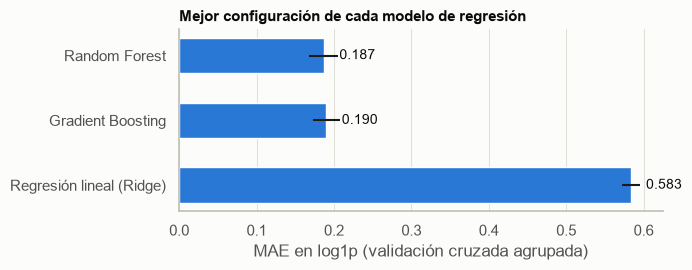

In [262]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(mejores.index[::-1], mejores["MAE log1p (CV)"][::-1],
        xerr=mejores["desv. estándar"][::-1], color="#2a78d6", height=0.55)
for i, v in enumerate(mejores["MAE log1p (CV)"][::-1]):
    ax.text(v + 0.02, i, f"{v:.3f}", va="center")
ax.set_xlabel("MAE en log1p (validación cruzada agrupada)")
ax.set_title("Mejor configuración de cada modelo de regresión")
plt.tight_layout(); plt.show()

**¿Qué significa un MAE de 0,187 y de 0,190?**

El MAE de la gráfica está en escala logarítmica, porque los modelos se entrenan con $\log(1 + \text{magnitud})$. Por eso no se lee directamente en votos: mide en promedio cuánto se aleja la predicción del valor real **en términos relativos**.

Un error de $d$ en escala logarítmica significa que la predicción se aleja del valor real por un factor de $e^{d}$:

$$
|\log(1 + \hat{m}) - \log(1 + m)| = d \quad \Longleftrightarrow \quad \frac{1 + \hat{m}}{1 + m} = e^{d} \ \text{ o } \ e^{-d}
$$

| Modelo | MAE (log1p) | Factor $e^{d}$ | Error relativo típico | Ejemplo: mesa con 10 votos de cambio |
|---|---|---|---|---|
| Random Forest | 0,187 | 1,21 | ≈ 21 % | predice entre 8 y 12 votos |
| Gradient Boosting | 0,190 | 1,21 | ≈ 21 % | predice entre 8 y 12 votos |
| Regresión lineal (Ridge) | 0,583 | 1,79 | ≈ 79 % | predice entre 5 y 19 votos |

En otras palabras, el Random Forest y el Gradient Boosting se equivocan en promedio alrededor de un 21 % del valor real de la magnitud, mientras que la regresión lineal se equivoca cerca de un 79 %. La diferencia entre 0,187 y 0,190 equivale a menos de medio punto porcentual de error relativo y es menor que la variación entre particiones (barras negras), así que en la práctica los dos modelos de árboles tienen el mismo desempeño.

Al ser un error relativo, su tamaño en votos depende del tamaño de la corrección: en una mesa que cambió 2 votos, un 21 % es menos de un voto, y en una que cambió 100 votos son unos 20 votos. El error promedio en votos se reporta en la evaluación sobre la partición de prueba (sección 5.3.2).

##### 5.2.2.3. Curva de validación del Random Forest

Para analizar el efecto del hiperparámetro principal del modelo elegido, se calcula el MAE de entrenamiento y de validación (con la misma validación cruzada agrupada por departamento) para distintas profundidades máximas de los árboles (`max_depth`). Un árbol poco profundo hace pocas preguntas y puede ser demasiado simple (subajuste); uno muy profundo puede memorizar los datos de entrenamiento (sobreajuste). Para que el cálculo sea más rápido, la curva usa 100 árboles en lugar de 200.

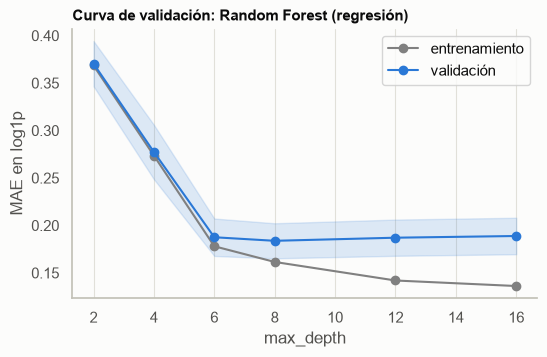

,max_depth,MAE entrenamiento,MAE validación
0,2,0.368,0.370
1,4,0.274,0.277
2,6,0.178,0.188
3,8,0.162,0.184
4,12,0.142,0.187
5,16,0.136,0.189


In [263]:
profundidades = [2, 4, 6, 8, 12, 16]
rf = make_pipeline(SimpleImputer(strategy="median"),
                   RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                         n_jobs=-1, random_state=0))
tr_sc, va_sc = validation_curve(rf, Xr_tr, yr_tr, groups=gr_tr, cv=CV,
                                param_name="randomforestregressor__max_depth",
                                param_range=profundidades,
                                scoring="neg_mean_absolute_error")

plt.figure(figsize=(6, 3.5))
plt.plot(profundidades, -tr_sc.mean(1), "o-", color="gray", label="entrenamiento")
plt.plot(profundidades, -va_sc.mean(1), "o-", color="#2a78d6", label="validación")
plt.fill_between(profundidades, -va_sc.mean(1) - va_sc.std(1), -va_sc.mean(1) + va_sc.std(1),
                 color="#2a78d6", alpha=0.15)
plt.xlabel("max_depth"); plt.ylabel("MAE en log1p")
plt.title("Curva de validación: Random Forest (regresión)"); plt.legend(); plt.show()

display(pd.DataFrame({"max_depth": profundidades,
                      "MAE entrenamiento": -tr_sc.mean(1),
                      "MAE validación": -va_sc.mean(1)}).round(3))

**Lectura:** con árboles poco profundos (profundidad 2) el error es alto y casi igual en entrenamiento y en validación (0,368 y 0,370): el modelo es demasiado simple para capturar la relación (subajuste). Al aumentar la profundidad, el error de validación baja rápidamente hasta estabilizarse entre las profundidades 6 y 8, donde alcanza su mínimo (MAE = 0,184 con profundidad 8). A partir de ahí el error de entrenamiento sigue bajando (0,142 con profundidad 12 y 0,136 con 16), pero el de validación ya no mejora e incluso sube levemente (0,187 y 0,189). La brecha entre ambos errores pasa de 0,002 a 0,053: los árboles más profundos memorizan las mesas de entrenamiento sin ganar capacidad para generalizar a departamentos no vistos (sobreajuste).

La búsqueda en rejilla eligió `max_depth = 12` porque la rejilla solo incluía 6, 12 y sin límite; la curva muestra que una profundidad de 8 daría prácticamente el mismo error (0,184 frente a 0,187). La diferencia es menor que la variación entre particiones (desviación ≈ 0,02), por lo que la elección de 12 no afecta el desempeño de forma apreciable.

#### 5.2.3. Detección no supervisada de anomalías

##### 5.2.3.1. Preprocesamiento de características

El preprocesamiento comprende dos operaciones:

1. **Imputación:** los valores faltantes estructurales se reemplazan utilizando las medianas calculadas exclusivamente sobre el conjunto de entrenamiento.
2. **Escalamiento robusto:** se utiliza `RobustScaler`, que centra las características respecto a su mediana y las escala mediante el rango intercuartílico.

Estas transformaciones permiten construir una representación numérica consistente para los algoritmos y reducen la influencia de las diferencias de escala entre variables.

Los transformadores se ajustan únicamente con entrenamiento y posteriormente se aplican, sin reajuste, a validación y prueba.

El indicador `sin_votos_preconteo` se conserva para permitir identificar las mesas sin votos registrados. Su influencia sobre las puntuaciones de anomalía será examinada mediante un análisis de sensibilidad.

In [264]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
import numpy as np
import pandas as pd

# Imputación ajustada exclusivamente con entrenamiento
imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

# Escalamiento robusto ajustado exclusivamente con entrenamiento
scaler = RobustScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_test_scaled = scaler.transform(X_test_imp)

# Verificación de dimensiones y valores no finitos
for nombre, matriz in [
    ("Entrenamiento", X_train_scaled),
    ("Validación", X_val_scaled),
    ("Prueba", X_test_scaled)
]:
    print(
        f"{nombre}: {matriz.shape} | "
        f"NaN: {np.isnan(matriz).sum()} | "
        f"Inf: {np.isinf(matriz).sum()}"
    )

assert all(
    np.isfinite(matriz).all()
    for matriz in [X_train_scaled, X_val_scaled, X_test_scaled]
)

print("\nPreprocesamiento completado correctamente.")


Entrenamiento: (82845, 7) | NaN: 0 | Inf: 0
Validación: (17752, 7) | NaN: 0 | Inf: 0
Prueba: (17753, 7) | NaN: 0 | Inf: 0

Preprocesamiento completado correctamente.



##### 5.2.3.2. Entrenamiento de Isolation Forest

Se implementa Isolation Forest como primer algoritmo de detección no supervisada de anomalías.

El método construye árboles de partición aleatoria y utiliza la longitud de los recorridos necesarios para aislar las observaciones. Las mesas que requieren menos particiones tienden a recibir mayores puntuaciones de anomalía.

Se establece una configuración inicial con 300 árboles, 256 observaciones por árbol y semilla aleatoria 42.

El modelo se ajusta exclusivamente con las características del conjunto de entrenamiento. Posteriormente, se calculan puntuaciones de anomalía para entrenamiento y validación, sin utilizar las etiquetas de corrección durante el ajuste.

Se define la puntuación como el negativo de `score_samples`, de manera que valores mayores representen observaciones más atípicas.

Esta configuración constituye una referencia inicial para la posterior comparación de hiperparámetros.


In [265]:

from sklearn.ensemble import IsolationForest
import pandas as pd
import numpy as np
import time

# Configuración inicial
iforest_base = IsolationForest(
    n_estimators=300,
    max_samples=256,
    max_features=1.0,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

# Entrenamiento
inicio = time.perf_counter()

iforest_base.fit(X_train_scaled)

tiempo_entrenamiento = time.perf_counter() - inicio

# Puntuaciones: mayor valor = mayor anomalía
scores_train_if = -iforest_base.score_samples(X_train_scaled)
scores_val_if = -iforest_base.score_samples(X_val_scaled)

# Resumen de puntuaciones
resumen_if = pd.DataFrame({
    "conjunto": ["Entrenamiento", "Validación"],
    "observaciones": [len(scores_train_if), len(scores_val_if)],
    "media": [scores_train_if.mean(), scores_val_if.mean()],
    "desviacion": [scores_train_if.std(), scores_val_if.std()],
    "minimo": [scores_train_if.min(), scores_val_if.min()],
    "mediana": [np.median(scores_train_if), np.median(scores_val_if)],
    "maximo": [scores_train_if.max(), scores_val_if.max()]
})

print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.2f} segundos")
display(resumen_if.round(4))

assert np.isfinite(scores_train_if).all()
assert np.isfinite(scores_val_if).all()

print("Isolation Forest entrenado correctamente.")


Tiempo de entrenamiento: 1.56 segundos


,conjunto,observaciones,media,desviacion,minimo,mediana,maximo
0,Entrenamiento,82845,0.4506,0.0531,0.3800,0.4366,0.7711
1,Validación,17752,0.4507,0.0533,0.3812,0.4368,0.7505


Isolation Forest entrenado correctamente.


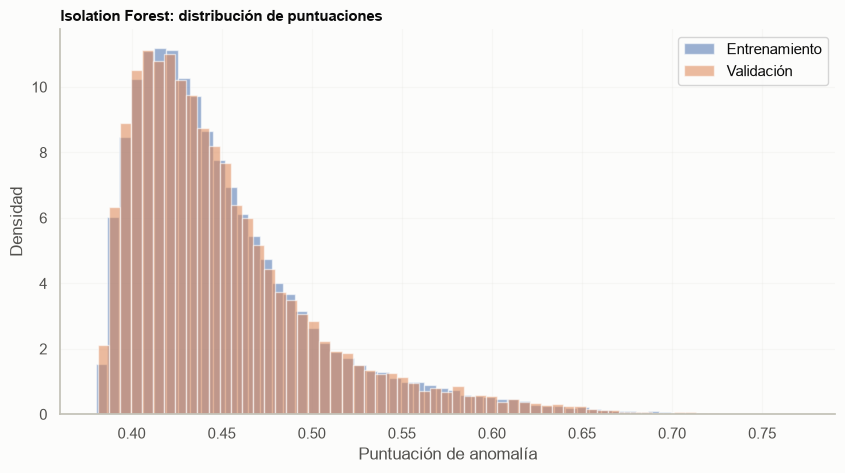

In [266]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    scores_train_if,
    bins=60,
    density=True,
    alpha=0.55,
    label="Entrenamiento"
)

plt.hist(
    scores_val_if,
    bins=60,
    density=True,
    alpha=0.55,
    label="Validación"
)

plt.xlabel("Puntuación de anomalía")
plt.ylabel("Densidad")
plt.title("Isolation Forest: distribución de puntuaciones")
plt.legend()
plt.grid(alpha=0.2)
plt.show()



##### 5.2.3.3. Selección de hiperparámetros de Isolation Forest



Se realiza una búsqueda controlada de hiperparámetros para analizar la sensibilidad de Isolation Forest a la cantidad de árboles, el tamaño de las submuestras y la proporción de características utilizadas.

Se consideran las siguientes configuraciones:

- `n_estimators`: 100, 300 y 500.
- `max_samples`: 256, 512 y 1024.
- `max_features`: 0.75 y 1.0.

Cada configuración se ajusta exclusivamente sobre entrenamiento y genera puntuaciones de anomalía para validación.

La comparación utiliza Precision@K, Recall@K y Lift@K, considerando presupuestos de revisión del 1 %, 5 % y 10 % de las mesas de validación.

La selección principal se realizará mediante Lift@5 %, mientras que los demás presupuestos permitirán examinar la estabilidad de los rankings.

La etiqueta `y_corregida` no interviene en el ajuste del detector. Sin embargo, su utilización para seleccionar hiperparámetros constituye supervisión indirecta durante la validación.

El conjunto de prueba permanecerá reservado para la evaluación final.


In [267]:

from itertools import product
from sklearn.ensemble import IsolationForest
import pandas as pd
import numpy as np
import time

# Presupuestos de revisión definidos previamente
presupuestos = [0.01, 0.05, 0.10]

def metricas_ranking(y_true, scores, fracciones=presupuestos):
    y = np.asarray(y_true).astype(int)
    scores = np.asarray(scores)

    orden = np.argsort(-scores, kind="stable")
    prevalencia = y.mean()
    total_positivos = y.sum()

    resultados = {}

    for fraccion in fracciones:
        k = max(1, int(np.ceil(len(y) * fraccion)))
        seleccion = y[orden[:k]]

        precision = seleccion.mean()
        recall = (
            seleccion.sum() / total_positivos
            if total_positivos > 0 else np.nan
        )
        lift = (
            precision / prevalencia
            if prevalencia > 0 else np.nan
        )

        sufijo = f"{int(fraccion * 100)}pct"

        resultados[f"precision_{sufijo}"] = precision
        resultados[f"recall_{sufijo}"] = recall
        resultados[f"lift_{sufijo}"] = lift

    return resultados


# Espacio de búsqueda
parametros = list(product(
    [100, 300, 500],
    [256, 512, 1024],
    [0.75, 1.0]
))

resultados_if = []

for n_estimators, max_samples, max_features in parametros:

    modelo = IsolationForest(
        n_estimators=n_estimators,
        max_samples=max_samples,
        max_features=max_features,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    )

    inicio = time.perf_counter()
    modelo.fit(X_train_scaled)
    tiempo = time.perf_counter() - inicio

    scores = -modelo.score_samples(X_val_scaled)

    metricas = metricas_ranking(y_val, scores)

    resultados_if.append({
        "n_estimators": n_estimators,
        "max_samples": max_samples,
        "max_features": max_features,
        "tiempo_entrenamiento": tiempo,
        **metricas
    })

df_resultados_if = pd.DataFrame(resultados_if)

df_resultados_if = df_resultados_if.sort_values(
    ["lift_5pct", "lift_1pct", "n_estimators"],
    ascending=[False, False, True]
).reset_index(drop=True)

display(df_resultados_if.round(4))

print("Configuraciones evaluadas:", len(df_resultados_if))
print("Prevalencia de correcciones en validación:",
      f"{y_val.mean():.2%}")


,n_estimators,max_samples,max_features,tiempo_entrenamiento,precision_1pct,recall_1pct,lift_1pct,precision_5pct,recall_5pct,lift_5pct,precision_10pct,recall_10pct,lift_10pct
0,100,512,1.00,0.8641,0.1067,0.0213,2.1195,0.0845,0.0839,1.6771,0.0704,0.1398,1.3976
1,300,512,1.00,2.2690,0.1292,0.0257,2.5658,0.0833,0.0828,1.6547,0.0709,0.1409,1.4088
2,100,512,0.75,0.8650,0.0955,0.0190,1.8964,0.0833,0.0828,1.6547,0.0681,0.1353,1.3529
3,300,1024,0.75,2.2650,0.1236,0.0246,2.4542,0.0822,0.0817,1.6324,0.0721,0.1432,1.4311
4,500,512,1.00,3.8790,0.1124,0.0224,2.2311,0.0822,0.0817,1.6324,0.0704,0.1398,1.3976
5,100,1024,0.75,0.8488,0.1067,0.0213,2.1195,0.0822,0.0817,1.6324,0.0721,0.1432,1.4311
6,500,512,0.75,4.1457,0.1067,0.0213,2.1195,0.0822,0.0817,1.6324,0.0715,0.1421,1.4199
7,300,512,0.75,2.4491,0.0955,0.0190,1.8964,0.0822,0.0817,1.6324,0.0704,0.1398,1.3976
8,300,1024,1.00,2.1706,0.1236,0.0246,2.4542,0.0811,0.0805,1.6100,0.0732,0.1454,1.4535
9,100,256,1.00,0.5837,0.1067,0.0213,2.1195,0.0811,0.0805,1.6100,0.0698,0.1387,1.3864


Configuraciones evaluadas: 18
Prevalencia de correcciones en validación: 5.04%


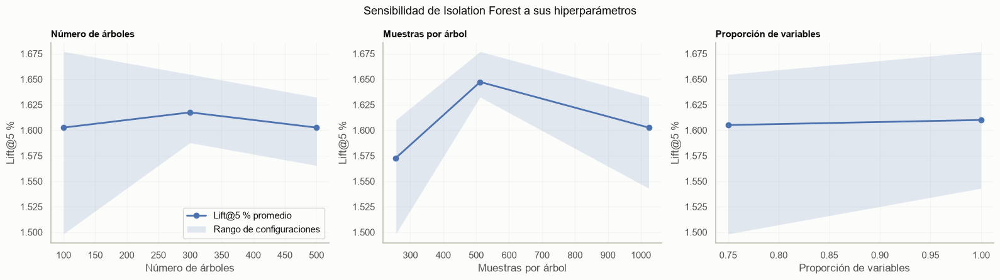

In [268]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

hiperparametros = [
    ("n_estimators", "Número de árboles"),
    ("max_samples", "Muestras por árbol"),
    ("max_features", "Proporción de variables")
]

for ax, (columna, etiqueta) in zip(axes, hiperparametros):

    resumen = (
        df_resultados_if
        .groupby(columna)["lift_5pct"]
        .agg(["mean", "min", "max"])
        .reset_index()
        .sort_values(columna)
    )

    ax.plot(
        resumen[columna],
        resumen["mean"],
        marker="o",
        linewidth=2,
        label="Lift@5 % promedio"
    )

    ax.fill_between(
        resumen[columna].to_numpy(dtype=float),
        resumen["min"].to_numpy(dtype=float),
        resumen["max"].to_numpy(dtype=float),
        alpha=0.15,
        label="Rango de configuraciones"
    )

    ax.set_xlabel(etiqueta)
    ax.set_ylabel("Lift@5 %")
    ax.set_title(etiqueta)
    ax.grid(alpha=0.25)

axes[0].legend()
fig.suptitle(
    "Sensibilidad de Isolation Forest a sus hiperparámetros",
    fontsize=13
)

plt.tight_layout()
plt.show()



**Interpretación de la sensibilidad de hiperparámetros.**

La visualización presenta el comportamiento de **Lift@5 %** en función de los hiperparámetros `n_estimators`, `max_samples` y `max_features`. Para cada valor se representa el rendimiento promedio obtenido en las configuraciones evaluadas y su rango de variación, lo que permite identificar la sensibilidad del modelo a los parámetros explorados.

La configuración seleccionada fue `n_estimators=100`, `max_samples=512` y `max_features=1.0`, con un **Lift@5 % de 1,6771 en validación**. La selección se realizó exclusivamente con el conjunto de validación, evitando utilizar los resultados de prueba para ajustar el modelo. Las diferencias entre configuraciones deben interpretarse como asociaciones descriptivas dentro de la búsqueda realizada y no como efectos causales independientes de cada hiperparámetro.



**Resultados de la búsqueda de hiperparámetros**

Se evaluaron 18 configuraciones de Isolation Forest sobre el conjunto de validación, cuya prevalencia de mesas corregidas fue del 5,04 %.

La mayor puntuación Lift@5 % (1,677) se obtuvo con `n_estimators=100`, `max_samples=512` y `max_features=1.0`. Esta configuración alcanzó Precision@5 % de 8,45 % y Recall@5 % de 8,39 %.

Los resultados indican que las mesas priorizadas por el modelo presentan una frecuencia de correcciones superior a la prevalencia general de validación. Sin embargo, las diferencias entre las configuraciones mejor posicionadas son reducidas y no permiten afirmar superioridad estadística.

Se selecciona provisionalmente esta configuración conforme al criterio Lift@5 % establecido previamente. Su desempeño final se estimará sobre el conjunto de prueba, después de completar la comparación con LOF y el baseline robusto.

Las correcciones se utilizan como señal externa de evaluación y no constituyen evidencia de fraude electoral.


In [269]:

# Selección conforme al criterio principal de validación
mejor_if = df_resultados_if.iloc[0]

params_if_seleccionados = {
    "n_estimators": int(mejor_if["n_estimators"]),
    "max_samples": int(mejor_if["max_samples"]),
    "max_features": float(mejor_if["max_features"]),
    "contamination": "auto",
    "random_state": 42,
    "n_jobs": -1
}

print("Hiperparámetros seleccionados:")
print(params_if_seleccionados)


Hiperparámetros seleccionados:
{'n_estimators': 100, 'max_samples': 512, 'max_features': 1.0, 'contamination': 'auto', 'random_state': 42, 'n_jobs': -1}



##### 5.2.3.4. Entrenamiento de Local Outlier Factor (LOF)

Se implementa Local Outlier Factor (LOF) como segundo método de detección no supervisada de anomalías.

LOF estima el grado de atipicidad de cada observación a partir de su densidad local, comparándola con la densidad de sus vecinos más cercanos.

A diferencia de Isolation Forest, que identifica observaciones mediante particiones aleatorias, LOF permite detectar anomalías locales en regiones con distintas densidades.

**Configuración inicial**

Se utiliza `n_neighbors=20`, distancia euclidiana y `novelty=True`, con el fin de calcular puntuaciones para observaciones que no participaron en el entrenamiento.

El algoritmo se ajusta exclusivamente sobre las características escaladas del conjunto de entrenamiento.

Se define la puntuación de anomalía como el negativo de `score_samples`, de modo que valores mayores representen mayor atipicidad.

Debido a que LOF depende de cálculos de proximidad, se registra el tiempo de entrenamiento y de puntuación para evaluar su viabilidad computacional.

Esta configuración constituye una referencia inicial y será comparada posteriormente con diferentes números de vecinos y métricas de distancia.


In [270]:

from sklearn.neighbors import LocalOutlierFactor
import pandas as pd
import numpy as np
import time

# Configuración inicial
lof_base = LocalOutlierFactor(
    n_neighbors=20,
    metric="euclidean",
    algorithm="auto",
    novelty=True,
    n_jobs=-1
)

# Ajuste del modelo
inicio = time.perf_counter()

lof_base.fit(X_train_scaled)

tiempo_entrenamiento_lof = time.perf_counter() - inicio

# Puntuaciones sobre observaciones no vistas
inicio = time.perf_counter()

scores_val_lof = -lof_base.score_samples(X_val_scaled)

tiempo_prediccion_lof = time.perf_counter() - inicio

# Resumen
resumen_lof = pd.DataFrame({
    "conjunto": ["Validación"],
    "observaciones": [len(scores_val_lof)],
    "media": [scores_val_lof.mean()],
    "desviacion": [scores_val_lof.std()],
    "minimo": [scores_val_lof.min()],
    "mediana": [np.median(scores_val_lof)],
    "maximo": [scores_val_lof.max()]
})

print(f"Tiempo de entrenamiento: {tiempo_entrenamiento_lof:.2f} s")
print(f"Tiempo de puntuación: {tiempo_prediccion_lof:.2f} s")

display(resumen_lof.round(4))

assert np.isfinite(scores_val_lof).all()

print("LOF entrenado correctamente.")


Tiempo de entrenamiento: 3.50 s
Tiempo de puntuación: 0.70 s


,conjunto,observaciones,media,desviacion,minimo,mediana,maximo
0,Validación,17752,1.039,0.0731,0.9431,1.0225,4.2696


LOF entrenado correctamente.


In [271]:

comparacion_inicial = pd.DataFrame([
    {
        "modelo": "Isolation Forest (base)",
        **metricas_ranking(y_val, scores_val_if)
    },
    {
        "modelo": "LOF (20 vecinos)",
        **metricas_ranking(y_val, scores_val_lof)
    }
])

display(
    comparacion_inicial[
        [
            "modelo",
            "precision_1pct",
            "lift_1pct",
            "precision_5pct",
            "recall_5pct",
            "lift_5pct",
            "precision_10pct",
            "lift_10pct"
        ]
    ].round(4)
)


,modelo,precision_1pct,lift_1pct,precision_5pct,recall_5pct,lift_5pct,precision_10pct,lift_10pct
0,Isolation Forest (base),0.1011,2.0080,0.08,0.0794,1.5877,0.0687,1.3640
1,LOF (20 vecinos),0.1292,2.5658,0.08,0.0794,1.5877,0.0743,1.4758



##### 5.2.3.5. Selección de hiperparámetros de LOF




Se realiza una búsqueda de hiperparámetros para determinar la influencia del tamaño del vecindario y la métrica de distancia sobre la detección de anomalías locales.

Se evalúan seis valores de `n_neighbors` (10, 20, 35, 50, 75 y 100) y dos métricas de distancia (euclidiana y Manhattan), para un total de 12 configuraciones.

Cada modelo se ajusta exclusivamente sobre el conjunto de entrenamiento escalado y se evalúa sobre validación utilizando Precision@K, Recall@K y Lift@K, con presupuestos de revisión del 1 %, 5 % y 10 %.

Se mantiene Lift@5 % como criterio principal de selección, de manera consistente con el procedimiento aplicado a Isolation Forest.

El conjunto de prueba permanece excluido de esta búsqueda.

In [272]:

from itertools import product
from sklearn.neighbors import LocalOutlierFactor
import pandas as pd
import numpy as np
import time

vecinos = [10, 20, 35, 50, 75, 100]
distancias = ["euclidean", "manhattan"]

resultados_lof = []

for n_neighbors, metric in product(vecinos, distancias):

    modelo = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        metric=metric,
        algorithm="auto",
        novelty=True,
        n_jobs=-1
    )

    inicio = time.perf_counter()
    modelo.fit(X_train_scaled)
    tiempo_entrenamiento = time.perf_counter() - inicio

    inicio = time.perf_counter()
    scores = -modelo.score_samples(X_val_scaled)
    tiempo_puntuacion = time.perf_counter() - inicio

    metricas = metricas_ranking(y_val, scores)

    resultados_lof.append({
        "n_neighbors": n_neighbors,
        "metric": metric,
        "tiempo_entrenamiento": tiempo_entrenamiento,
        "tiempo_puntuacion": tiempo_puntuacion,
        **metricas
    })

df_resultados_lof = pd.DataFrame(resultados_lof)

df_resultados_lof = (
    df_resultados_lof
    .sort_values(
        ["lift_5pct", "lift_1pct", "n_neighbors"],
        ascending=[False, False, True]
    )
    .reset_index(drop=True)
)

display(df_resultados_lof.round(4))

print("Configuraciones evaluadas:", len(df_resultados_lof))
print("Mejor Lift@5 %:", round(df_resultados_lof.iloc[0]["lift_5pct"], 4))


,n_neighbors,metric,tiempo_entrenamiento,tiempo_puntuacion,precision_1pct,recall_1pct,lift_1pct,precision_5pct,recall_5pct,lift_5pct,precision_10pct,recall_10pct,lift_10pct
0,10,manhattan,3.8292,0.7887,0.1461,0.0291,2.9004,0.0923,0.0917,1.8336,0.0783,0.1555,1.5541
1,20,manhattan,5.4140,1.1238,0.1404,0.0280,2.7889,0.0890,0.0884,1.7665,0.0777,0.1544,1.5429
2,35,manhattan,2.8183,0.5631,0.1292,0.0257,2.5658,0.0878,0.0872,1.7442,0.0766,0.1521,1.5206
3,35,euclidean,4.0498,0.6764,0.1236,0.0246,2.4542,0.0878,0.0872,1.7442,0.0755,0.1499,1.4982
4,10,euclidean,2.6253,0.5169,0.1854,0.0369,3.6813,0.0867,0.0861,1.7218,0.0704,0.1398,1.3976
5,20,euclidean,2.7631,0.5528,0.1292,0.0257,2.5658,0.0800,0.0794,1.5877,0.0743,0.1477,1.4758
6,50,manhattan,3.5010,0.6677,0.1292,0.0257,2.5658,0.0800,0.0794,1.5877,0.0749,0.1488,1.4870
7,75,manhattan,4.1934,0.8505,0.1236,0.0246,2.4542,0.0777,0.0772,1.5429,0.0755,0.1499,1.4982
8,50,euclidean,2.7952,0.5711,0.1124,0.0224,2.2311,0.0777,0.0772,1.5429,0.0709,0.1409,1.4088
9,100,manhattan,4.3936,0.8792,0.1180,0.0235,2.3427,0.0743,0.0738,1.4758,0.0726,0.1443,1.4423


Configuraciones evaluadas: 12
Mejor Lift@5 %: 1.8336


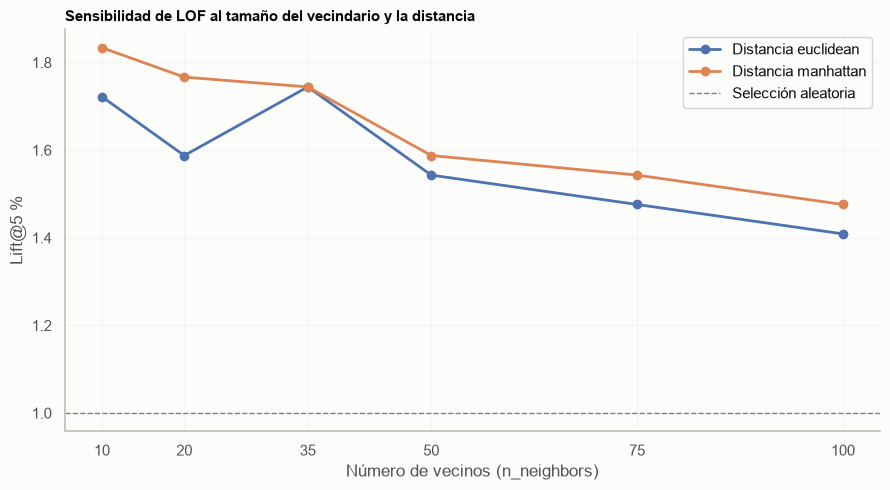

In [273]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

for distancia, grupo in df_resultados_lof.groupby("metric"):

    grupo = grupo.sort_values("n_neighbors")

    ax.plot(
        grupo["n_neighbors"],
        grupo["lift_5pct"],
        marker="o",
        linewidth=2,
        label=f"Distancia {distancia}"
    )

ax.axhline(
    1,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Selección aleatoria"
)

ax.set_title(
    "Sensibilidad de LOF al tamaño del vecindario y la distancia"
)

ax.set_xlabel("Número de vecinos (n_neighbors)")
ax.set_ylabel("Lift@5 %")
ax.set_xticks([10, 20, 35, 50, 75, 100])
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()



**Interpretación de la sensibilidad de hiperparámetros.**

La visualización compara el comportamiento de **Lift@5 %** al modificar `n_neighbors` y la métrica de distancia (`euclidean` y `manhattan`). Estos hiperparámetros determinan la estructura de vecindad utilizada por LOF para estimar la densidad local e identificar observaciones atípicas.

La configuración seleccionada fue `n_neighbors=10` y `metric='manhattan'`, con un **Lift@5 % de 1,8336 en validación**. Este resultado indica que, para el presupuesto de revisión del 5 %, dicha configuración obtuvo la mayor concentración de mesas corregidas entre las alternativas evaluadas. Sin embargo, su selección corresponde al rendimiento observado en validación y no garantiza que conserve la misma ventaja en datos independientes.



**Resultados de la selección de hiperparámetros**

Se evaluaron 12 configuraciones de LOF combinando seis tamaños de vecindario y dos métricas de distancia.

La configuración con `n_neighbors=10` y distancia Manhattan obtuvo el mayor Lift@5 % (1,834), con Precision@5 % de 9,23 % y Recall@5 % de 9,17 %.

Este resultado supera provisionalmente al mejor Isolation Forest, cuyo Lift@5 % fue de 1,677. Asimismo, LOF presentó mayores valores de Lift@1 % y Lift@10 % con la configuración seleccionada.

Se observó sensibilidad al tamaño del vecindario y a la métrica de distancia. Aunque la distancia euclidiana con 10 vecinos alcanzó el mayor Lift@1 %, se mantuvo Lift@5 % como criterio principal de selección.

La configuración seleccionada se reserva para la comparación final con los demás métodos. Las diferencias observadas corresponden al conjunto de validación y todavía no constituyen evidencia de superioridad estadística.


In [274]:

mejor_lof = df_resultados_lof.iloc[0]

params_lof_seleccionados = {
    "n_neighbors": int(mejor_lof["n_neighbors"]),
    "metric": str(mejor_lof["metric"]),
    "algorithm": "auto",
    "novelty": True,
    "n_jobs": -1
}

print("Hiperparámetros LOF seleccionados:")
print(params_lof_seleccionados)


Hiperparámetros LOF seleccionados:
{'n_neighbors': 10, 'metric': 'manhattan', 'algorithm': 'auto', 'novelty': True, 'n_jobs': -1}



##### 5.2.3.6. Baseline estadístico robusto




Se implementa un detector estadístico basado en las desviaciones absolutas respecto a la mediana de cada característica.

Las desviaciones se normalizan mediante la desviación absoluta mediana (MAD), estimada exclusivamente sobre el conjunto de entrenamiento. Cuando la MAD es cero, se utiliza la desviación estándar como escala alternativa.

Se comparan dos estrategias de agregación:

- **Media:** promedio de las desviaciones estandarizadas.
- **Máximo:** mayor desviación estandarizada entre las características.

Ambas estrategias producen puntuaciones donde valores mayores representan mayor atipicidad.

Las configuraciones se evalúan mediante Precision@K, Recall@K y Lift@K sobre el conjunto de validación, manteniendo Lift@5 % como criterio principal de selección.

El conjunto de prueba permanece reservado para la evaluación final.



In [275]:


import numpy as np
import pandas as pd

# Estadísticas calculadas únicamente con entrenamiento
medianas_baseline = np.median(X_train_imp, axis=0)

mad_baseline = np.median(
    np.abs(X_train_imp - medianas_baseline),
    axis=0
)

std_baseline = np.std(X_train_imp, axis=0)

# Escala robusta, con alternativa cuando MAD = 0
escalas_baseline = np.where(
    mad_baseline > 1e-12,
    1.4826 * mad_baseline,
    np.where(std_baseline > 1e-12, std_baseline, 1.0)
)

def calcular_scores_baseline(X, agregacion="media"):
    z = np.abs(
        (X - medianas_baseline) / escalas_baseline
    )

    if agregacion == "media":
        return z.mean(axis=1)

    if agregacion == "maximo":
        return z.max(axis=1)

    raise ValueError("Agregación no reconocida")


resultados_baseline = []

for agregacion in ["media", "maximo"]:

    scores = calcular_scores_baseline(
        X_val_imp,
        agregacion=agregacion
    )

    metricas = metricas_ranking(y_val, scores)

    resultados_baseline.append({
        "agregacion": agregacion,
        **metricas
    })

df_resultados_baseline = pd.DataFrame(
    resultados_baseline
).sort_values(
    "lift_5pct",
    ascending=False
).reset_index(drop=True)

print("Resultados del baseline:")
display(df_resultados_baseline.round(4))

print("\nEscalas por característica:")
display(
    pd.DataFrame({
        "caracteristica": features_if_lof,
        "mediana": medianas_baseline,
        "MAD": mad_baseline,
        "desviacion_estandar": std_baseline,
        "escala_utilizada": escalas_baseline
    }).round(5)
)


Resultados del baseline:


,agregacion,precision_1pct,recall_1pct,lift_1pct,precision_5pct,recall_5pct,lift_5pct,precision_10pct,recall_10pct,lift_10pct
0,media,0.1124,0.0224,2.2311,0.0766,0.0761,1.5206,0.0670,0.1331,1.3305
1,maximo,0.1236,0.0246,2.4542,0.0709,0.0705,1.4088,0.0608,0.1208,1.2075



Escalas por característica:


,caracteristica,mediana,MAD,desviacion_estandar,escala_utilizada
0,total_votos_preconteo,206.00000,45.00000,68.33687,66.71700
1,opciones_reportadas,13.00000,3.00000,4.05543,4.44780
2,proporcion_blancos,0.01533,0.00883,0.01591,0.01309
3,proporcion_nulos,0.00766,0.00766,0.01249,0.01136
4,proporcion_no_marcados,0.00000,0.00000,0.00814,0.00814
5,margen_primero_segundo,0.28191,0.15018,0.20769,0.22266
6,sin_votos_preconteo,0.00000,0.00000,0.00851,0.00851


In [276]:

from sklearn.neighbors import LocalOutlierFactor

# Excluir únicamente el indicador binario
columnas_sensibilidad = [
    i for i, nombre in enumerate(features_if_lof)
    if nombre != "sin_votos_preconteo"
]

# LOF con la configuración seleccionada
lof_sin_indicador = LocalOutlierFactor(
    **params_lof_seleccionados
)

lof_sin_indicador.fit(
    X_train_scaled[:, columnas_sensibilidad]
)

scores_lof_sin = -lof_sin_indicador.score_samples(
    X_val_scaled[:, columnas_sensibilidad]
)

# Baseline con la misma regla, excluyendo el indicador
z_sin_indicador = np.abs(
    (
        X_val_imp[:, columnas_sensibilidad]
        - medianas_baseline[columnas_sensibilidad]
    )
    / escalas_baseline[columnas_sensibilidad]
)

scores_baseline_sin = z_sin_indicador.mean(axis=1)

# Comparación de sensibilidad
comparacion_sensibilidad = pd.DataFrame([
    {
        "modelo": "LOF original",
        **metricas_ranking(
            y_val,
            -lof_base.score_samples(X_val_scaled)
        )
    },
    {
        "modelo": "LOF optimizado sin indicador",
        **metricas_ranking(y_val, scores_lof_sin)
    },
    {
        "modelo": "Baseline media original",
        **metricas_ranking(
            y_val,
            calcular_scores_baseline(X_val_imp, "media")
        )
    },
    {
        "modelo": "Baseline media sin indicador",
        **metricas_ranking(y_val, scores_baseline_sin)
    }
])

display(
    comparacion_sensibilidad[
        ["modelo", "precision_1pct", "lift_1pct",
         "precision_5pct", "lift_5pct",
         "precision_10pct", "lift_10pct"]
    ].round(4)
)


,modelo,precision_1pct,lift_1pct,precision_5pct,lift_5pct,precision_10pct,lift_10pct
0,LOF original,0.1292,2.5658,0.0800,1.5877,0.0743,1.4758
1,LOF optimizado sin indicador,0.1461,2.9004,0.0923,1.8336,0.0783,1.5541
2,Baseline media original,0.1124,2.2311,0.0766,1.5206,0.0670,1.3305
3,Baseline media sin indicador,0.1124,2.2311,0.0766,1.5206,0.0670,1.3305


In [277]:

lof_optimizado = LocalOutlierFactor(**params_lof_seleccionados)
lof_optimizado.fit(X_train_scaled)

scores_lof_optimizado = -lof_optimizado.score_samples(X_val_scaled)

comparacion_sensibilidad.loc[
    comparacion_sensibilidad["modelo"] == "LOF original",
    "modelo"
] = "LOF base (20 vecinos)"

comparacion_sensibilidad = pd.concat([
    comparacion_sensibilidad,
    pd.DataFrame([{
        "modelo": "LOF optimizado con indicador",
        **metricas_ranking(y_val, scores_lof_optimizado)
    }])
], ignore_index=True)

display(
    comparacion_sensibilidad[
        ["modelo", "precision_1pct", "lift_1pct",
         "precision_5pct", "lift_5pct",
         "precision_10pct", "lift_10pct"]
    ].round(4)
)


,modelo,precision_1pct,lift_1pct,precision_5pct,lift_5pct,precision_10pct,lift_10pct
0,LOF base (20 vecinos),0.1292,2.5658,0.0800,1.5877,0.0743,1.4758
1,LOF optimizado sin indicador,0.1461,2.9004,0.0923,1.8336,0.0783,1.5541
2,Baseline media original,0.1124,2.2311,0.0766,1.5206,0.0670,1.3305
3,Baseline media sin indicador,0.1124,2.2311,0.0766,1.5206,0.0670,1.3305
4,LOF optimizado con indicador,0.1461,2.9004,0.0923,1.8336,0.0783,1.5541


In [278]:

comparacion_lof_indicador = pd.DataFrame([
    {
        "modelo": "LOF optimizado con indicador",
        **metricas_ranking(y_val, scores_lof_optimizado)
    },
    {
        "modelo": "LOF optimizado sin indicador",
        **metricas_ranking(y_val, scores_lof_sin)
    }
])

display(
    comparacion_lof_indicador[
        [
            "modelo",
            "precision_1pct",
            "lift_1pct",
            "precision_5pct",
            "recall_5pct",
            "lift_5pct",
            "precision_10pct",
            "lift_10pct"
        ]
    ].round(4)
)

# Comparación de rankings
from scipy.stats import spearmanr

correlacion, _ = spearmanr(
    scores_lof_optimizado,
    scores_lof_sin
)

print(f"Correlación de Spearman entre puntuaciones: {correlacion:.6f}")

# Coincidencia entre las mesas del 5 % superior
k = int(np.ceil(len(y_val) * 0.05))

top_con = set(np.argsort(-scores_lof_optimizado)[:k])
top_sin = set(np.argsort(-scores_lof_sin)[:k])

coincidencia = len(top_con & top_sin) / k

print(f"Coincidencia Top 5 %: {coincidencia:.2%}")


,modelo,precision_1pct,lift_1pct,precision_5pct,recall_5pct,lift_5pct,precision_10pct,lift_10pct
0,LOF optimizado con indicador,0.1461,2.9004,0.0923,0.0917,1.8336,0.0783,1.5541
1,LOF optimizado sin indicador,0.1461,2.9004,0.0923,0.0917,1.8336,0.0783,1.5541


Correlación de Spearman entre puntuaciones: 1.000000
Coincidencia Top 5 %: 100.00%



**Análisis de sensibilidad de la característica** `sin_votos_preconteo`

Se evaluó la influencia de `sin_votos_preconteo`, una característica binaria extremadamente infrecuente, mediante su exclusión del conjunto de variables predictoras.

Para LOF se mantuvieron constantes los hiperparámetros seleccionados (10 vecinos y distancia Manhattan), mientras que para el baseline estadístico se conservó la agregación por media.

Los resultados de validación fueron idénticos en Precision@K, Recall@K y Lift@K para K = 1 %, 5 % y 10 %, tanto en LOF como en el baseline.

Por tanto, no se identificaron cambios en la capacidad de recuperación de mesas corregidas para los presupuestos de revisión evaluados. Sin embargo, esta equivalencia no implica necesariamente que los rankings completos sean idénticos.

Se conserva la configuración original de siete características para mantener la trazabilidad del experimento. La influencia de esta variable sobre el ordenamiento individual de las mesas queda sujeta al análisis de estabilidad de rankings.


In [279]:

from scipy.stats import spearmanr
import numpy as np

rho, _ = spearmanr(
    scores_lof_optimizado,
    scores_lof_sin
)

k = int(np.ceil(len(y_val) * 0.05))

top_con = set(np.argsort(-scores_lof_optimizado)[:k])
top_sin = set(np.argsort(-scores_lof_sin)[:k])

coincidencia = len(top_con & top_sin) / k

print(f"Spearman: {rho:.6f}")
print(f"Coincidencia Top 5 %: {coincidencia:.2%}")
print(f"Mesas compartidas: {len(top_con & top_sin)} de {k}")


Spearman: 1.000000
Coincidencia Top 5 %: 100.00%
Mesas compartidas: 888 de 888



El análisis de estabilidad confirmó que la exclusión de `sin_votos_preconteo` no produjo cambios en las métricas de ranking evaluadas. Adicionalmente, se obtuvo una correlación de Spearman de 1,000000 (redondeada a seis decimales) y una coincidencia del 100 % entre las 888 mesas del Top 5 % de ambas configuraciones de LOF.

Estos resultados indican que el indicador binario no ejerce una influencia relevante sobre la priorización observada en validación. Por tanto, se conserva el conjunto original de siete características para la evaluación final.


### **5.3. Evaluación del modelo**

#### 5.3.1. Clasificación supervisada

##### 5.3.1.1. Procedimiento

Se evalúan los 9 modelos ajustados en 5.2.1 sobre la **partición de prueba** (23.670 mesas, 1.200 corregidas), que no se había usado hasta ahora. **No se reajusta nada**: se emplean los mismos hiperparámetros y el mismo umbral $\tau$ de 5.2.1. Si $\tau$ se volviera a elegir con la prueba, la evaluación dejaría de ser independiente.

- **AP** (*average precision*): métrica principal, la misma de 5.2.1.
- **ROC-AUC:** probabilidad de que una mesa corregida reciba una probabilidad mayor que una no corregida.
- **P, R, F₂ y matriz de confusión** en $\tau$: VP (corregidas detectadas), FP (falsas alarmas), FN (corregidas omitidas) y VN.
- **Intervalo de confianza del 95 % de la AP (*bootstrap*):** se remuestrean 1.000 veces las mesas de prueba con reemplazo, se recalcula la AP en cada remuestreo y se toman los percentiles 2,5 y 97,5. Mide la incertidumbre por el tamaño de la prueba, no la variabilidad del entrenamiento.

In [280]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

y_arr = y_test_clf.to_numpy()
pi_test = y_arr.mean()
N_BOOT = 1000
rng = np.random.default_rng(SEMILLA)
idx_boot = rng.integers(0, len(y_arr), size=(N_BOOT, len(y_arr)), dtype=np.int32)

def ap_bootstrap(p):
    return np.array([average_precision_score(y_arr[i], p[i]) for i in idx_boot])

p_test, ap_boot, filas = {}, {}, []
for (nombre, conjunto), pipe in modelos_entrenados.items():
    p = pipe.predict_proba(X_test_clf[CONJUNTOS[conjunto]])[:, 1]
    p_test[(nombre, conjunto)] = p
    ap_boot[(nombre, conjunto)] = ap_bootstrap(p)

    tau = resultados[(nombre, conjunto)]["tau"]          # umbral de 5.2.1, sin reajustar
    marcada = p >= tau
    vp = int((marcada & (y_arr == 1)).sum()); fp = int((marcada & (y_arr == 0)).sum())
    fn = int((~marcada & (y_arr == 1)).sum()); vn = int((~marcada & (y_arr == 0)).sum())
    prec, rec = vp / max(vp + fp, 1), vp / (vp + fn)
    filas.append(dict(
        Modelo=nombre, Conjunto=conjunto,
        AP_cv=resultados[(nombre, conjunto)]["AP_cv"],
        AP_test=average_precision_score(y_arr, p),
        IC95_inf=np.percentile(ap_boot[(nombre, conjunto)], 2.5),
        IC95_sup=np.percentile(ap_boot[(nombre, conjunto)], 97.5),
        ROC_AUC=roc_auc_score(y_arr, p), tau=tau, P=prec, R=rec,
        F2=5 * prec * rec / max(4 * prec + rec, 1e-12),
        VP=vp, FP=fp, FN=fn, VN=vn, marcadas_pct=100 * marcada.mean(),
    ))

evaluacion = pd.DataFrame(filas).sort_values("AP_test", ascending=False).reset_index(drop=True)
display(evaluacion.round({"AP_cv": 4, "AP_test": 4, "IC95_inf": 4, "IC95_sup": 4,
                          "ROC_AUC": 4, "tau": 3, "P": 3, "R": 3, "F2": 3, "marcadas_pct": 2}))

# Referencias sobre la partición de prueba
regla_te = (X_test_clf["dif_pre_e11"].fillna(0) != 0).to_numpy()
vp_r = int((regla_te & (y_arr == 1)).sum())
P_r, R_r = vp_r / regla_te.sum(), vp_r / y_arr.sum()
print(f"Sin información (prevalencia en prueba): AP = {pi_test:.4f}")
print(f"Regla dif_pre_e11 != 0: P = {P_r:.3f}, R = {R_r:.3f}, F2 = {5 * P_r * R_r / (4 * P_r + R_r):.3f}")

,Modelo,Conjunto,AP_cv,AP_test,IC95_inf,IC95_sup,ROC_AUC,tau,P,R,F2,VP,FP,FN,VN,marcadas_pct
0,Random forest,B,0.9076,0.9115,0.8961,0.9255,0.9660,0.205,0.867,0.892,0.887,1071,165,129,22305,5.22
1,Árbol de decisión,B,0.8957,0.8953,0.8776,0.9117,0.9520,0.268,0.861,0.886,0.881,1063,172,137,22298,5.22
2,KNN,B,0.8656,0.8779,0.8605,0.8948,0.9579,0.095,0.819,0.859,0.851,1031,228,169,22242,5.32
3,Random forest,B sin dif_pre_e11,0.2049,0.2300,0.2067,0.2541,0.7296,0.064,0.114,0.558,0.314,670,5186,530,17284,24.74
4,Árbol de decisión,B sin dif_pre_e11,0.1294,0.1537,0.1358,0.1753,0.5942,0.460,0.065,0.551,0.221,661,9466,539,13004,42.78
5,KNN,B sin dif_pre_e11,0.1214,0.1324,0.1161,0.1503,0.6218,0.048,0.078,0.516,0.243,619,7325,581,15145,33.56
6,Random forest,A,0.1097,0.1175,0.1019,0.1338,0.5967,0.047,0.072,0.503,0.229,604,7808,596,14662,35.54
7,KNN,A,0.0949,0.0969,0.0836,0.1136,0.5769,0.033,0.054,0.776,0.211,931,16360,269,6110,73.05
8,Árbol de decisión,A,0.0921,0.0942,0.0819,0.1070,0.5789,0.417,0.055,0.756,0.213,907,15597,293,6873,69.73


Sin información (prevalencia en prueba): AP = 0.0507
Regla dif_pre_e11 != 0: P = 0.569, R = 0.896, F2 = 0.803


##### 5.3.1.2. Comparación entre modelos (*bootstrap* pareado)

Para saber si las diferencias de AP entre modelos son reales o ruido, se usan los **mismos remuestreos** para ambos y se mira la distribución de la diferencia $\Delta AP$. Si el intervalo del 95 % no contiene el 0, la diferencia es consistente.

In [281]:
comparaciones = [
    ("B", "Random forest", "Árbol de decisión"),
    ("B", "Random forest", "KNN"),
    ("B", "Árbol de decisión", "KNN"),
    ("B sin dif_pre_e11", "Random forest", "Árbol de decisión"),
    ("B sin dif_pre_e11", "Random forest", "KNN"),
]
for conjunto, a, b in comparaciones:
    d = ap_boot[(a, conjunto)] - ap_boot[(b, conjunto)]
    inf, sup = np.percentile(d, [2.5, 97.5])
    veredicto = "diferencia consistente" if inf > 0 or sup < 0 else "no concluyente"
    print(f"[{conjunto:>17}] {a} − {b}: ΔAP = {d.mean():+.4f}  IC95% [{inf:+.4f}, {sup:+.4f}]  → {veredicto}")

[                B] Random forest − Árbol de decisión: ΔAP = +0.0164  IC95% [+0.0111, +0.0222]  → diferencia consistente
[                B] Random forest − KNN: ΔAP = +0.0336  IC95% [+0.0260, +0.0411]  → diferencia consistente
[                B] Árbol de decisión − KNN: ΔAP = +0.0171  IC95% [+0.0082, +0.0262]  → diferencia consistente
[B sin dif_pre_e11] Random forest − Árbol de decisión: ΔAP = +0.0761  IC95% [+0.0594, +0.0926]  → diferencia consistente
[B sin dif_pre_e11] Random forest − KNN: ΔAP = +0.0977  IC95% [+0.0814, +0.1153]  → diferencia consistente


##### 5.3.1.3. Curvas precisión–recall

Cada curva muestra la precisión que se obtiene para cada nivel de recall al variar el umbral. El punto marca el umbral $\tau$ de 5.2.1; la cruz es la regla simple "`dif_pre_e11` $\neq 0$".

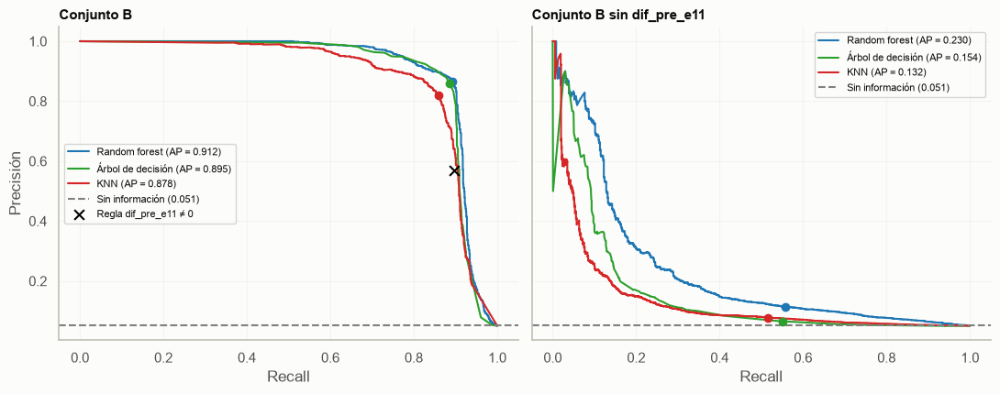

In [282]:
colores = {"Random forest": "#1f77b4", "Árbol de decisión": "#2ca02c", "KNN": "#d62728"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, conjunto in zip(axes, ["B", "B sin dif_pre_e11"]):
    for nombre, color in colores.items():
        p = p_test[(nombre, conjunto)]
        P_c, R_c, _ = precision_recall_curve(y_arr, p)
        fila = evaluacion[(evaluacion.Modelo == nombre) & (evaluacion.Conjunto == conjunto)].iloc[0]
        ax.plot(R_c, P_c, color=color, label=f"{nombre} (AP = {fila.AP_test:.3f})")
        ax.scatter(fila.R, fila.P, color=color, zorder=3)
    ax.axhline(pi_test, ls="--", color="gray", label=f"Sin información ({pi_test:.3f})")
    if conjunto == "B":
        ax.scatter(R_r, P_r, marker="x", s=60, color="black", zorder=3, label="Regla dif_pre_e11 ≠ 0")
    ax.set_title(f"Conjunto {conjunto}")
    ax.set_xlabel("Recall"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel("Precisión")
plt.tight_layout(); plt.show()

##### 5.3.1.4. Calibración de las probabilidades

Un modelo está bien calibrado si, entre las mesas a las que asigna probabilidad $\approx 0{,}3$, cerca del 30 % fue realmente corregido (la curva sigue la diagonal). El **puntaje de Brier** $\frac{1}{n}\sum_i (\hat{p}_i - y_i)^2$ mide el error de las probabilidades; el de un modelo que siempre responde la prevalencia es $\pi(1-\pi) \approx 0{,}048$.

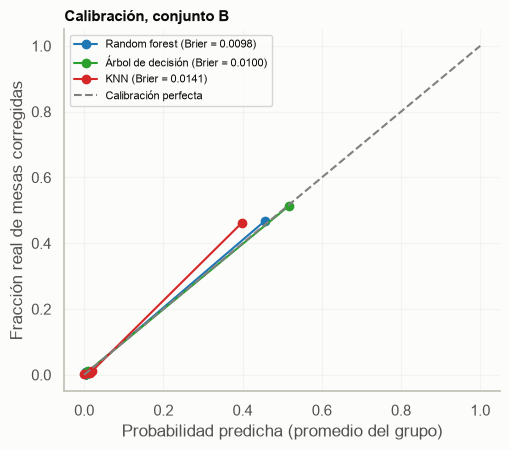

Brier de referencia (prevalencia constante): 0.0481


In [283]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(5.2, 4.6))
for nombre, color in colores.items():
    p = p_test[(nombre, "B")]
    frac, media = calibration_curve(y_arr, p, n_bins=10, strategy="quantile")
    ax.plot(media, frac, marker="o", color=color,
            label=f"{nombre} (Brier = {brier_score_loss(y_arr, p):.4f})")
ax.plot([0, 1], [0, 1], ls="--", color="gray", label="Calibración perfecta")
ax.set_xlabel("Probabilidad predicha (promedio del grupo)")
ax.set_ylabel("Fracción real de mesas corregidas")
ax.set_title("Calibración, conjunto B"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"Brier de referencia (prevalencia constante): {pi_test * (1 - pi_test):.4f}")

##### 5.3.1.5. Importancia de las variables (permutación)

Se baraja una variable a la vez en la partición de prueba y se mide cuánto cae la AP del random forest: cuanto mayor la caída, más depende el modelo de esa variable. A diferencia de la importancia por impureza, no favorece a las variables continuas.

B: dif_pre_e11 (0.842), dif_urna_e11 (0.045), dif_e14_e11 (0.005), tachaduras_enmendaduras (0.002)
B sin dif_pre_e11: participacion_e11 (0.168), total_votos_preconteo (0.165), tasa_retirados (0.079), proporcion_no_marcados (0.054)


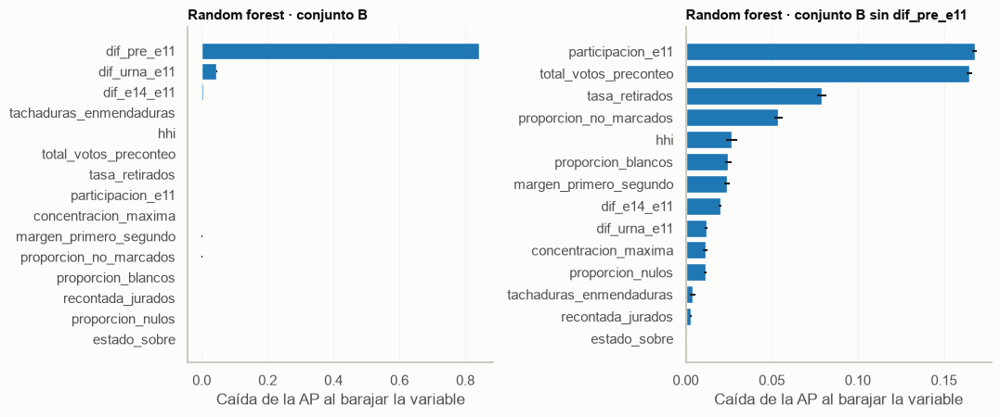

In [284]:
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, conjunto in zip(axes, ["B", "B sin dif_pre_e11"]):
    cols = CONJUNTOS[conjunto]
    imp = permutation_importance(
        modelos_entrenados[("Random forest", conjunto)], X_test_clf[cols], y_test_clf,
        scoring="average_precision", n_repeats=5, random_state=SEMILLA, n_jobs=-1,
    )
    orden = np.argsort(imp.importances_mean)
    ax.barh(np.array(cols)[orden], imp.importances_mean[orden],
            xerr=imp.importances_std[orden], color="#1f77b4")
    ax.set_title(f"Random forest · conjunto {conjunto}")
    ax.set_xlabel("Caída de la AP al barajar la variable")
    ax.grid(axis="x", alpha=0.3)
    top = [f"{cols[i]} ({imp.importances_mean[i]:.3f})" for i in orden[::-1][:4]]
    print(f"{conjunto}: {', '.join(top)}")
plt.tight_layout(); plt.show()

**Lectura de la evaluación en prueba**

- **Con `dif_pre_e11` (conjunto B)** el orden de 5.2.1 se mantiene: random forest (AP = 0,912; IC 95 % [0,896; 0,926]), árbol (0,895) y KNN (0,878). Los valores en prueba son muy cercanos a los de validación cruzada, así que no hay sobreajuste, y el umbral $\tau$ elegido en 5.2.1 se transfiere bien (random forest: P = 0,867 y R = 0,892 en prueba, frente a 0,846 y 0,895 en validación).
- **Las diferencias entre modelos son consistentes**, aunque pequeñas entre los dos primeros: random forest − árbol $\Delta AP = +0{,}016$ (IC [0,011; 0,022]) y random forest − KNN $+0{,}034$. El árbol queda a solo 1,6 puntos del bosque, lo que lo hace una alternativa explicable.
- **Matriz de confusión del random forest (B):** detecta 1.071 de las 1.200 mesas corregidas (R = 0,89) con 165 falsas alarmas, y marca el 5,2 % de las mesas. La regla simple "`dif_pre_e11` $\neq 0$" logra el mismo recall con precisión 0,57, es decir, unas 800 falsas alarmas. El modelo reduce las falsas alarmas en cerca de un 80 %.
- **Sin `dif_pre_e11` la capacidad práctica es baja.** El random forest alcanza AP = 0,230 (4,5 veces la prevalencia) y es claramente mejor que el árbol (0,154) y KNN (0,132), pero para recuperar R ≈ 0,56 debe marcar el 25 % de las mesas con P = 0,11. Con el conjunto A, o con árbol y KNN sin `dif_pre_e11`, el ROC-AUC queda entre 0,58 y 0,62 y marcan entre el 34 % y el 73 % de las mesas; su $F_2$ (0,21–0,24) es casi el de marcar todas las mesas (0,21).
- **Calibración:** en el conjunto B, el random forest y el árbol siguen la diagonal (Brier 0,0098 y 0,0100, frente a 0,048 de la referencia); KNN subestima la probabilidad en el tramo alto (Brier 0,0141). Como casi todas las mesas reciben probabilidades cercanas a 0, los deciles se concentran cerca del origen y la curva tiene pocos puntos distintos.
- **Importancia:** con el conjunto B, el random forest depende casi por completo de `dif_pre_e11` (caída de AP de 0,84), seguida de `dif_urna_e11` (0,045). Sin `dif_pre_e11`, las variables más usadas son `participacion_e11` (0,17), `total_votos_preconteo` (0,17), `tasa_retirados` (0,08) y `proporcion_no_marcados` (0,05).
- **Conclusión:** el modelo aprovecha, sobre todo, que el preconteo no cuadre con el número de votantes del E-11, y mejora la regla simple al reducir las falsas alarmas. La señal que aportan las demás variables por sí solas es débil.

##### 5.3.1.6. Análisis de ablación: ¿de dónde viene la mejora frente a la regla?

La regla `dif_pre_e11 ≠ 0` tiene una precisión cercana al 57 % y el random forest llega al 87 % con un recall similar. Este análisis responde **de dónde viene esa mejora**:

- de usar el **valor** de la diferencia preconteo − E-11 (y no solo si es distinta de cero), o
- de las **demás variables de consistencia** del formulario (E-14, urna, participación, tachaduras y recuento de jurados).

Para que la comparación sea justa y rápida, se entrena el **mismo random forest con hiperparámetros fijos** (200 árboles, `min_samples_leaf = 20`, `max_features = "sqrt"`) y se cambian únicamente las variables. Se usa la misma partición estratificada 80/20 con semilla 42 de la sección 5.2.1 y validación cruzada de 5 particiones **solo sobre entrenamiento**, sin tocar la partición de prueba. En cada conjunto se mide la **precisión con el mismo recall de la regla**, es decir, cuántas falsas alarmas tendría el modelo si encontrara la misma cantidad de mesas corregidas. Las variables de esta celda llevan el prefijo `abl_` para no modificar las de las secciones siguientes.

In [285]:
import time
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline

abl_df = pd.read_csv(Path("../../data/processed/dataset_maestro.csv"),
                     dtype={"dep": "string", "mun": "string", "zona": "string",
                            "puesto": "string", "mesa": "string"})
for abl_col in ["tachaduras_enmendaduras", "recontada_jurados"]:
    abl_df[abl_col] = (abl_df[abl_col].astype("string").str.strip().str.upper() == "SI").astype("int8")
abl_df["estado_sobre"] = (abl_df["estado_sobre"].astype("string").str.strip().str.upper() == "MAL").astype("int8")

abl_A = ["total_votos_preconteo", "proporcion_blancos", "proporcion_nulos",
         "proporcion_no_marcados", "margen_primero_segundo", "concentracion_maxima",
         "hhi", "tasa_retirados"]
abl_consistencia = ["dif_e14_e11", "dif_urna_e11", "participacion_e11",
                    "tachaduras_enmendaduras", "recontada_jurados"]
abl_B = abl_A + ["dif_pre_e11"] + abl_consistencia + ["estado_sobre"]
abl_conjuntos = {
    "Solo dif_pre_e11": ["dif_pre_e11"],
    "dif_pre_e11 + consistencia": ["dif_pre_e11"] + abl_consistencia,
    "B sin dif_pre_e11": [c for c in abl_B if c != "dif_pre_e11"],
    "B completo": abl_B,
}

abl_idx_tr, _ = train_test_split(abl_df.index, test_size=0.20,
                                 stratify=abl_df["y_corregida"], random_state=42)
abl_X, abl_y = abl_df.loc[abl_idx_tr], abl_df.loc[abl_idx_tr, "y_corregida"]

# Referencia: la regla simple
abl_regla = abl_X["dif_pre_e11"].fillna(0) != 0
abl_tp = int((abl_regla & (abl_y == 1)).sum())
abl_P_regla, abl_R_regla = abl_tp / abl_regla.sum(), abl_tp / abl_y.sum()

abl_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
abl_filas = []
for abl_nombre, abl_cols in abl_conjuntos.items():
    abl_t0 = time.time()
    abl_modelo = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                      max_features="sqrt", random_state=42, n_jobs=-1)),
    ])
    abl_p = cross_val_predict(abl_modelo, abl_X[abl_cols], abl_y, cv=abl_cv,
                              method="predict_proba")[:, 1]
    abl_P, abl_R, _ = precision_recall_curve(abl_y, abl_p)
    abl_j = np.where(abl_R[:-1] >= abl_R_regla)[0][-1]      # mismo recall de la regla
    abl_det = int(round(abl_R[abl_j] * abl_y.sum()))
    abl_filas.append({
        "Conjunto": abl_nombre,
        "N.º variables": len(abl_cols),
        "AP (CV)": average_precision_score(abl_y, abl_p),
        "Precisión con el recall de la regla": abl_P[abl_j],
        "Falsas alarmas": int(round(abl_det / abl_P[abl_j])) - abl_det,
    })
    print(f"{abl_nombre}: {time.time() - abl_t0:.0f} s")

abl_tabla = pd.DataFrame(abl_filas)
abl_tabla.loc[len(abl_tabla)] = {"Conjunto": "Regla dif_pre_e11 ≠ 0", "N.º variables": 1,
                                 "AP (CV)": np.nan,
                                 "Precisión con el recall de la regla": abl_P_regla,
                                 "Falsas alarmas": int(abl_regla.sum()) - abl_tp}
display(abl_tabla.sort_values("Precisión con el recall de la regla")
                 .round(3).reset_index(drop=True))

Solo dif_pre_e11: 13 s
dif_pre_e11 + consistencia: 34 s
B sin dif_pre_e11: 93 s
B completo: 76 s


,Conjunto,N.º variables,AP (CV),Precisión con el recall de la regla,Falsas alarmas
0,B sin dif_pre_e11,14,0.172,0.057,70622
1,Solo dif_pre_e11,1,0.845,0.564,3323
2,Regla dif_pre_e11 ≠ 0,1,NaN,0.564,3323
3,B completo,15,0.904,0.756,1388
4,dif_pre_e11 + consistencia,6,0.904,0.807,1027


**Lectura:**

| Conjunto | AP (CV) | Precisión con el recall de la regla | Falsas alarmas |
|---|---:|---:|---:|
| Regla `dif_pre_e11 ≠ 0` | — | 0,564 | 3 323 |
| Solo `dif_pre_e11` | 0,845 | 0,564 | 3 323 |
| `dif_pre_e11` + consistencia | **0,904** | **0,807** | **1 027** |
| B completo | 0,904 | 0,756 | 1 388 |
| B sin `dif_pre_e11` | 0,172 | 0,057 | 70 622 |

- **El valor de la diferencia, por sí solo, no reduce las falsas alarmas.** Con solo `dif_pre_e11`, el random forest ordena mejor las mesas (AP = 0,845), pero con el mismo recall de la regla obtiene exactamente su misma precisión (0,564): para encontrar el 90 % de las corregidas debe marcar las mismas mesas.
- **La mejora proviene de las demás variables de consistencia del formulario.** Al agregar `dif_e14_e11`, `dif_urna_e11`, `participacion_e11`, `tachaduras_enmendaduras` y `recontada_jurados`, la precisión sube a 0,807 y las falsas alarmas bajan de 3 323 a 1 027 (−69 %). Estas variables permiten distinguir, entre las mesas donde el preconteo no cuadra con el E-11, cuáles terminan corregidas.
- **Las variables del preconteo no aportan información adicional.** El conjunto B completo alcanza la misma AP (0,904) que el conjunto de seis variables y, con hiperparámetros fijos, una precisión algo menor (0,756). Es consistente con la señal débil de la detección de anomalías, que solo usa el preconteo.
- **Sin `dif_pre_e11` el modelo no es útil** (AP = 0,172).

**Alcance:** las cifras se obtienen con validación cruzada sobre entrenamiento y con hiperparámetros fijos, por lo que no son comparables directamente con las métricas de prueba de 5.3.1. Lo relevante es la comparación entre conjuntos.

##### 5.3.1.7. ¿Dónde está el error? Preconteo frente a E-11

La ablación muestra que las variables del formulario reducen las falsas alarmas. La razón se ve directamente en los datos: cuando el preconteo no cuadra con el E-11, los otros formularios de la misma mesa indican **cuál de los dos registros está mal**. Se agrupan las mesas donde el preconteo no cuadra con el E-11 según con cuál coinciden los votos en la urna y los sufragantes del E-14.

In [286]:
abl_m = pd.read_csv(Path("../../data/processed/dataset_maestro.csv"),
                    dtype={"dep": "string", "mun": "string", "zona": "string",
                           "puesto": "string", "mesa": "string"})
abl_pre, abl_e11 = abl_m["total_votos_preconteo"], abl_m["sufragantes_e11"]
abl_urna, abl_e14 = abl_m["votos_urna"], abl_m["sufragantes_e11_segun_e14"]
abl_no_cuadra = (abl_pre != abl_e11) & abl_m["dif_pre_e11"].notna()
abl_caso_a = abl_no_cuadra & (abl_urna == abl_e11) & (abl_e14 == abl_e11)
abl_caso_b = abl_no_cuadra & (abl_urna == abl_pre) & (abl_e14 == abl_pre)
abl_grupos = {
    "A: urna y E-14 coinciden con el E-11 (el distinto es el preconteo)": abl_caso_a,
    "B: urna y E-14 coinciden con el preconteo (el distinto es el E-11)": abl_caso_b,
    "Otros casos (la urna o el E-14 no coinciden con ninguno)": abl_no_cuadra & ~(abl_caso_a | abl_caso_b),
    "Total donde el preconteo no cuadra con el E-11 (regla)": abl_no_cuadra,
    "Preconteo = E-11": ~abl_no_cuadra,
}
display(pd.DataFrame({
    k: {"mesas": int(v.sum()),
        "corregidas": int(abl_m.loc[v, "y_corregida"].sum()),
        "% corregidas": round(100 * abl_m.loc[v, "y_corregida"].mean(), 1)}
    for k, v in abl_grupos.items()
}).T)

,mesas,corregidas,% corregidas
A: urna y E-14 coinciden con el E-11 (el distinto es el preconteo),5589.0,4869.0,87.1
B: urna y E-14 coinciden con el preconteo (el distinto es el E-11),409.0,94.0,23.0
Otros casos (la urna o el E-14 no coinciden con ninguno),3521.0,418.0,11.9
Total donde el preconteo no cuadra con el E-11 (regla),9519.0,5381.0,56.5
Preconteo = E-11,108831.0,617.0,0.6


**Lectura:**

| Caso | Mesas | % corregidas |
|---|---:|---:|
| A: el registro distinto es el **preconteo** | 5 589 | **87,1 %** |
| B: el registro distinto es el **E-11** | 409 | **23,0 %** |
| Otros casos | 3 521 | 11,9 % |
| Total que marca la regla | 9 519 | 56,5 % |
| Preconteo = E-11 | 108 831 | 0,6 % |

- Cuando la urna y el E-14 coinciden con el E-11, el error está en el preconteo y casi 9 de cada 10 mesas se corrigen. Cuando coinciden con el preconteo, el error está en el E-11 y solo 2 de cada 10 se corrigen.
- La regla trata igual los dos casos, por eso su precisión es del 56,5 %. El modelo, al ver los demás formularios, puede separarlos.
- Una regla escrita a mano que marque solo el caso A alcanza una precisión similar a la del modelo (87,1 %), pero deja por fuera las mesas corregidas de los casos mezclados (recall de 81,2 % frente a 89 % del modelo). El aprendizaje automático encuentra y combina estas reglas automáticamente, mantiene la precisión sin perder mesas y además entrega una probabilidad para ordenar la revisión.

#### 5.3.2. Regresión supervisada

##### 5.3.2.1. Métricas en la partición de prueba

Se evalúan los tres modelos, con los hiperparámetros elegidos en la sección 5.2.2 y reentrenados con todo el entrenamiento, sobre las 1 706 mesas corregidas de los 9 departamentos de prueba. Las predicciones se devuelven de la escala `log1p` a votos con `expm1`, de modo que el error se reporta en votos. Se comparan con la línea base, que predice para todas las mesas la mediana de la magnitud del entrenamiento.

In [287]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

filas, preds_reg = [], {}
for nombre, gs in busq_reg.items():
    pred = np.clip(np.expm1(gs.predict(Xr_te)), 0, None)    # de vuelta a votos
    preds_reg[nombre] = pred
    filas.append({"modelo": nombre,
                  "MAE (votos)": mean_absolute_error(yr_te, pred),
                  "RMSE (votos)": mean_squared_error(yr_te, pred) ** 0.5,
                  "R² (log1p)": r2_score(np.log1p(yr_te), np.log1p(pred))})

mediana = np.expm1(yr_tr).median()
base = np.full(len(yr_te), mediana)
filas.append({"modelo": f"Línea base: mediana ({mediana:.0f} votos)",
              "MAE (votos)": mean_absolute_error(yr_te, base),
              "RMSE (votos)": mean_squared_error(yr_te, base) ** 0.5,
              "R² (log1p)": r2_score(np.log1p(yr_te), np.log1p(base))})

tabla_reg_te = pd.DataFrame(filas).set_index("modelo")
display(tabla_reg_te.round(3))
print(f"Mesas corregidas evaluadas: {len(yr_te):,}")

,MAE (votos),RMSE (votos),R² (log1p)
modelo,,,
Regresión lineal (Ridge),9.295,69.009,0.529
Random Forest,3.211,20.188,0.779
Gradient Boosting,3.511,20.683,0.771
Línea base: mediana (3 votos),10.798,33.085,-0.043


Mesas corregidas evaluadas: 1,706


**Métricas de evaluación de la regresión**

Como la regresión predice un número (cuántos votos cambian) y no una categoría, no se evalúa con métricas de clasificación como *accuracy* o *recall*, que cuentan aciertos y errores. En regresión importa **qué tan lejos** queda la predicción del valor real, y para eso se usan tres métricas complementarias:

| Métrica | Qué mide | Cómo se interpreta |
|---|---|---|
| **MAE** (error absoluto medio) | Promedio de la diferencia, en valor absoluto, entre los votos reales y los predichos | Cuántos votos se equivoca el modelo en promedio. Es la métrica principal por ser directamente interpretable |
| **RMSE** (raíz del error cuadrático medio) | Similar al MAE, pero eleva los errores al cuadrado antes de promediar | Castiga más los errores grandes. Si el RMSE es mucho mayor que el MAE, hay pocas mesas con errores muy grandes |
| **R²** (en escala `log1p`) | Proporción de la variabilidad de la magnitud que explica el modelo | 1 = predicción perfecta; 0 = no mejora a predecir un valor constante; negativo = peor que un valor constante |

**Resultados en la partición de prueba (1 706 mesas corregidas de 9 departamentos no vistos)**

| Modelo | MAE (votos) | RMSE (votos) | R² (log1p) |
|---|---|---|---|
| **Random Forest** | **3,21** | **20,19** | **0,779** |
| Gradient Boosting | 3,51 | 20,68 | 0,771 |
| Regresión lineal (Ridge) | 9,30 | 69,01 | 0,529 |
| Línea base: mediana (3 votos) | 10,80 | 33,09 | −0,043 |

**Lectura:**

- **El Random Forest es el mejor modelo.** Se equivoca en promedio 3,2 votos por mesa, frente a 10,8 votos de la línea base que predice siempre la mediana: reduce el error en un 70 %. Explica cerca del 78 % de la variabilidad de la magnitud (R² = 0,779).
- **El Gradient Boosting queda muy cerca** (3,5 votos; R² = 0,771). Los dos modelos de árboles tienen un desempeño equivalente, igual que en la validación cruzada, y mantienen ese desempeño en departamentos que no vieron durante el entrenamiento.
- **La regresión lineal es casi tan mala como la línea base** (9,3 votos) y su RMSE (69 votos) es incluso el doble que el de la mediana: en algunas mesas comete errores muy grandes. Esto confirma que la relación entre las

##### 5.3.2.2. Error según el tamaño de la corrección

In [288]:
pred_mejor = preds_reg[MEJOR_REG]
rangos = pd.cut(yr_te, [0, 2, 5, 20, 100, 1000],
                labels=["1-2", "3-5", "6-20", "21-100", "más de 100"])
por_rango = (pd.DataFrame({"rango (votos)": rangos,
                           "error": np.abs(yr_te - pred_mejor),
                           "base": np.abs(yr_te - base)})
             .groupby("rango (votos)", observed=True)
             .agg(mesas=("error", "size"),
                  **{"MAE modelo": ("error", "mean"), "MAE mediana": ("base", "mean")}))
display(por_rango.round(2))

,mesas,MAE modelo,MAE mediana
rango (votos),,,
1-2,840,0.68,1.69
3-5,322,0.56,0.77
6-20,384,1.12,5.77
21-100,124,10.30,69.60
más de 100,36,83.83,164.03


**Error según el tamaño de la corrección**

La tabla agrupa las 1 706 mesas corregidas de prueba según cuántos votos cambiaron realmente entre el preconteo y el escrutinio, y compara en cada grupo el error absoluto medio (MAE) del Random Forest con el de la línea base, que predice siempre la mediana (3 votos).

| Rango real (votos) | Mesas | % de las mesas | MAE modelo (votos) | MAE mediana (votos) |
|---|---|---|---|---|
| 1 – 2 | 840 | 49 % | 0,68 | 1,69 |
| 3 – 5 | 322 | 19 % | 0,56 | 0,77 |
| 6 – 20 | 384 | 23 % | 1,12 | 5,77 |
| 21 – 100 | 124 | 7 % | 10,30 | 69,60 |
| Más de 100 | 36 | 2 % | 83,83 | 164,03 |


- **Correcciones pequeñas (1 a 5 votos).** Son 1 162 mesas, el 68 % de la prueba. El modelo se equivoca en promedio menos de un voto (0,68 y 0,56), es decir, casi siempre acierta el número exacto o queda a un voto.
- **Correcciones medianas (6 a 20 votos).** En estas 384 mesas el error es de 1,1 votos, frente a 5,8 de la línea base: el modelo es cinco veces más preciso.
- **Correcciones grandes (más de 20 votos).** El error crece: unos 10 votos en las mesas de 21 a 100 y unos 84 en las de más de 100. Aun así, el modelo sigue siendo mucho mejor que la mediana (70 y 164 votos).
- **El modelo supera a la línea base en todos los rangos.** La diferencia más pequeña está en el rango de 3 a 5 votos (0,56 frente a 0,77), porque la mediana (3 votos) cae justo dentro de ese rango.
- **Pocas mesas concentran la mayor parte del error.** Las 36 mesas con correcciones de más de 100 votos son solo el 2 % de la prueba, pero aportan cerca del 55 % del error total (36 × 83,8 ≈ 3 018 votos de un total de 1 706 × 3,21 ≈ 5 478). Esto explica por qué el RMSE (20,2 votos) es mucho mayor que el MAE (3,2 votos).

En conclusión, el modelo es muy preciso en la gran mayoría de las mesas, que tienen correcciones pequeñas o medianas, y pierde precisión en unas pocas correcciones excepcionales, que además son las menos representadas en los datos de entrenamiento.

##### 5.3.2.3. Valores reales frente a predichos

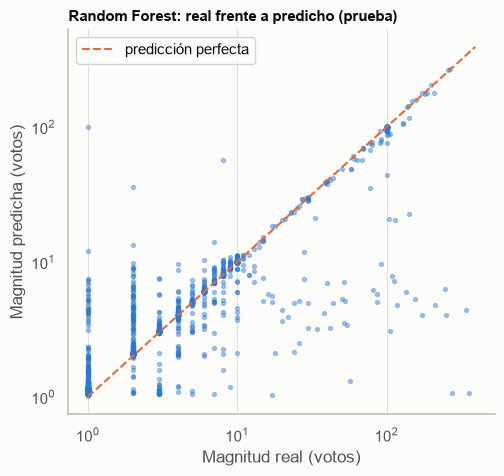

In [289]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(yr_te, pred_mejor, s=8, alpha=0.4, color="#2a78d6")
lim = [1, max(yr_te.max(), pred_mejor.max()) * 1.1]
ax.plot(lim, lim, "--", color="#eb6834", label="predicción perfecta")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Magnitud real (votos)"); ax.set_ylabel("Magnitud predicha (votos)")
ax.set_title(f"{MEJOR_REG}: real frente a predicho (prueba)"); ax.legend()
plt.show()

**Lectura:** cada punto es una mesa corregida de prueba; el eje horizontal muestra la magnitud real y el vertical la predicha por el Random Forest, ambos en escala logarítmica. La línea naranja representa la predicción perfecta.

La mayoría de los puntos se ubica sobre la diagonal o muy cerca de ella, en todos los tamaños de corrección, incluidas correcciones de 100 a 300 votos que el modelo estima casi exactamente. Estas son, probablemente, las mesas en las que la diferencia entre el total del preconteo y el E-11 coincide con el tamaño de la corrección, que es la señal principal que aprende el modelo. En las correcciones pequeñas (1 a 5 votos) las predicciones forman columnas verticales, porque la magnitud real es entera, y se dispersan poco alrededor del valor real.

El error grande se concentra en un grupo de mesas por debajo de la diagonal: correcciones reales de entre 10 y 300 votos para las que el modelo predice solo entre 2 y 10. Una explicación probable es que en esas mesas el escrutinio redistribuyó votos entre candidaturas sin cambiar el total, de modo que el preconteo sí coincide con el E-11 y el modelo no dispone de una señal que anticipe la corrección. Unos pocos puntos por encima de la diagonal corresponden a sobreestimaciones, posiblemente mesas con una diferencia grande respecto al E-11 originada en un error del propio formulario. Estas mesas mal estimadas son pocas, pero explican la diferencia entre el RMSE (20,2 votos) y el MAE (3,2 votos).

##### 5.3.2.4. Importancia de las variables

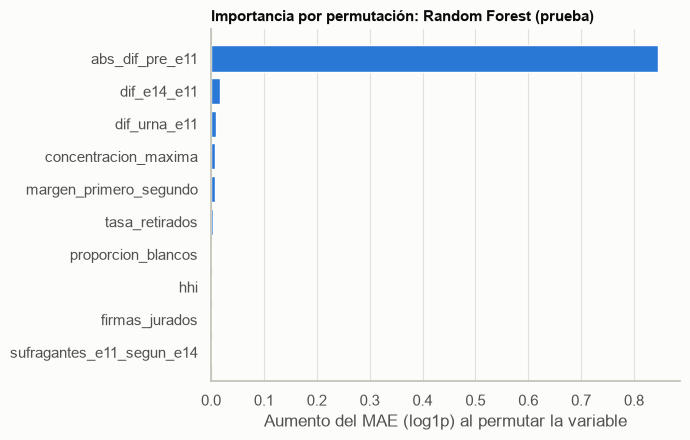

In [290]:
from sklearn.inspection import permutation_importance

mejor_reg = busq_reg[MEJOR_REG].best_estimator_
imp = permutation_importance(mejor_reg, Xr_te, np.log1p(yr_te),
                             scoring="neg_mean_absolute_error", n_repeats=5, random_state=0)
importancias = pd.Series(imp.importances_mean, index=ENTRADAS).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importancias.index[-10:], importancias.values[-10:], color="#2a78d6")
ax.set_xlabel("Aumento del MAE (log1p) al permutar la variable")
ax.set_title(f"Importancia por permutación: {MEJOR_REG} (prueba)")
plt.tight_layout(); plt.show()

**Importancia de las variables (permutación)**

La importancia por permutación mide cuánto empeora el modelo cuando se desordena al azar una variable en los datos de prueba, rompiendo su relación con la magnitud: si el error aumenta mucho, el modelo depende de esa variable; si no cambia, el modelo casi no la usa.

la diferencia absoluta entre el total del preconteo y los votantes del E-11 (`abs_dif_pre_e11`) domina por completo: al desordenarla, el MAE en escala logarítmica aumenta en 0,84, es decir, pasa de un error de alrededor del 20 % a uno de casi tres veces el valor real. Las variables de consistencia entre los formularios de la mesa (`dif_e14_e11`, `dif_urna_e11`) y las de composición del voto (`concentracion_maxima`, `margen_primero_segundo`, `tasa_retirados`) aportan ajustes pequeños, y el resto prácticamente no influye.

Esto indica que el tamaño de una corrección está ligado sobre todo al tamaño de la inconsistencia entre el preconteo y el número de votantes registrado en la mesa, y explica el patrón de la gráfica anterior: el modelo acierta cuando esa diferencia refleja la corrección y subestima las correcciones que redistribuyen votos entre candidaturas sin cambiar el total, porque en esas mesas la diferencia con el E-11 es nula. La variable con signo `dif_pre_e11` no aparece entre las más importantes porque contiene casi la misma información que su valor absoluto; la importancia por permutación tiende a subestimar variables muy correlacionadas entre sí.

##### 5.3.2.5. Resumen de la evaluación de la regresión

En los 9 departamentos de prueba, el Random Forest estima la magnitud de la corrección con un error absoluto medio de **3,2 votos**, frente a **10,8 votos** de la línea base que predice siempre la mediana, y explica cerca del **78 %** de la variabilidad de la magnitud en escala logarítmica (R² = 0,779). El Gradient Boosting queda muy cerca (**3,5 votos**) y la regresión lineal muy por detrás (**9,3 votos**), lo que confirma lo observado en la validación cruzada.

El RMSE (**20,2 votos**) es mucho mayor que el MAE: el modelo acierta bien las correcciones pequeñas, que son la mayoría, y se equivoca más en las pocas correcciones grandes. La tabla por rangos lo muestra: en las mesas con 1 a 5 votos de cambio el error es de **menos de un voto** (0,68 y 0,56), mientras que en las 36 mesas con más de 100 votos llega a **84 votos**. En la gráfica de valores reales frente a predichos, la mayoría de los puntos se concentra sobre la diagonal, y los errores grandes corresponden a un grupo de correcciones grandes que el modelo subestima.

La importancia por permutación muestra que la variable que más pesa es la diferencia entre el total del preconteo y el E-11 (`abs_dif_pre_e11`): el tamaño de la corrección está ligado al tamaño de la inconsistencia entre el preconteo y el número de votantes registrado en la mesa. Esto explica tanto el buen desempeño general del modelo como su principal limitación: las correcciones que redistribuyen votos entre candidaturas sin cambiar el total no dejan esa señal y el modelo no logra anticiparlas.

#### 5.3.3. Detección no supervisada de anomalías


##### 5.3.3.1. Protocolo de evaluación



Se evalúa la capacidad de los modelos de detección de anomalías para priorizar mesas electorales que posteriormente presentaron correcciones durante el escrutinio.

Se consideran tres enfoques: Isolation Forest, Local Outlier Factor (LOF) y un baseline estadístico robusto. Los modelos fueron ajustados exclusivamente con datos de entrenamiento, mientras que sus configuraciones se seleccionaron mediante el conjunto de validación, utilizando Lift@5 % como criterio principal.

La evaluación final se realiza sobre un conjunto independiente de 17.753 mesas, sin utilizarlo para ajustar hiperparámetros.

Se emplean Precision@K, Recall@K y Lift@K para presupuestos de revisión del 1 %, 5 % y 10 %. Estas métricas permiten evaluar la concentración y recuperación de mesas corregidas entre las observaciones con mayores puntuaciones de anomalía.

Aunque el entrenamiento es no supervisado, la selección de hiperparámetros incorpora supervisión indirecta mediante las etiquetas de corrección utilizadas en validación.

Las anomalías identificadas representan comportamientos estadísticamente atípicos y no constituyen, por sí mismas, evidencia de fraude electoral.



##### 5.3.3.2. Resultados en prueba

Se evalúan las configuraciones seleccionadas durante la fase de modelamiento sobre el conjunto independiente de prueba.

Se comparan los tres enfoques mediante Precision@K, Recall@K y Lift@K, considerando presupuestos de revisión del 1 %, 5 % y 10 % de las mesas.

El criterio principal de comparación es Lift@5 %, definido previamente durante la selección de hiperparámetros.

Esta evaluación permite estimar el desempeño de las configuraciones seleccionadas sobre observaciones que no participaron en el entrenamiento ni en la selección de modelos.


In [291]:

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
import pandas as pd

# Isolation Forest
modelo_if_final = IsolationForest(**params_if_seleccionados)
modelo_if_final.fit(X_train_scaled)

scores_test_if = -modelo_if_final.score_samples(
    X_test_scaled
)

# LOF
modelo_lof_final = LocalOutlierFactor(**params_lof_seleccionados)
modelo_lof_final.fit(X_train_scaled)

scores_test_lof = -modelo_lof_final.score_samples(
    X_test_scaled
)

# Baseline estadístico robusto
scores_test_baseline = calcular_scores_baseline(
    X_test_imp,
    agregacion="media"
)

# Evaluación sobre prueba
resultados_test = []

for nombre, scores in [
    ("Isolation Forest", scores_test_if),
    ("LOF", scores_test_lof),
    ("Baseline robusto", scores_test_baseline)
]:
    resultados_test.append({
        "modelo": nombre,
        **metricas_ranking(y_test, scores)
    })

df_resultados_test = pd.DataFrame(resultados_test)

display(df_resultados_test.round(4))


,modelo,precision_1pct,recall_1pct,lift_1pct,precision_5pct,recall_5pct,lift_5pct,precision_10pct,recall_10pct,lift_10pct
0,Isolation Forest,0.1124,0.0216,2.1588,0.0991,0.0952,1.9040,0.0850,0.1634,1.6336
1,LOF,0.0787,0.0152,1.5112,0.0608,0.0584,1.1684,0.0631,0.1212,1.2116
2,Baseline robusto,0.1236,0.0238,2.3747,0.0878,0.0844,1.6876,0.0816,0.1569,1.5686



**Análisis de los resultados**

Isolation Forest obtuvo el mayor Lift@5 % en prueba (1,9040), seguido del baseline estadístico robusto (1,6876) y LOF (1,1684).

Con un presupuesto de revisión del 5 %, Isolation Forest alcanzó una precisión del 9,91 % y recuperó el 9,52 % de las mesas corregidas del conjunto de prueba.

Por otra parte, el baseline robusto obtuvo la mayor Precision@1 % (12,36 %), mientras que Isolation Forest presentó los mejores resultados para presupuestos de revisión del 5 % y 10 %.

Estos resultados muestran que el rendimiento relativo depende del presupuesto de revisión considerado. Aunque LOF había sido seleccionado mediante validación, Isolation Forest obtuvo el mejor desempeño observado en prueba.

La evaluación final se interpreta como evidencia de capacidad de priorización de mesas corregidas, no como identificación confirmada de irregularidades electorales.



##### 5.3.3.3. Rendimiento según presupuesto de revisión


Se analiza la variación de Lift@K en función del porcentaje de mesas priorizadas para revisión.

Se consideran tres presupuestos operativos: 1 %, 5 % y 10 % del conjunto de prueba. Como referencia, Lift@K = 1 representa el rendimiento esperado de una selección aleatoria.

Esta visualización permite comparar la capacidad de concentración de mesas corregidas de los tres métodos y determinar cómo cambia su desempeño al ampliar el número de observaciones revisadas.


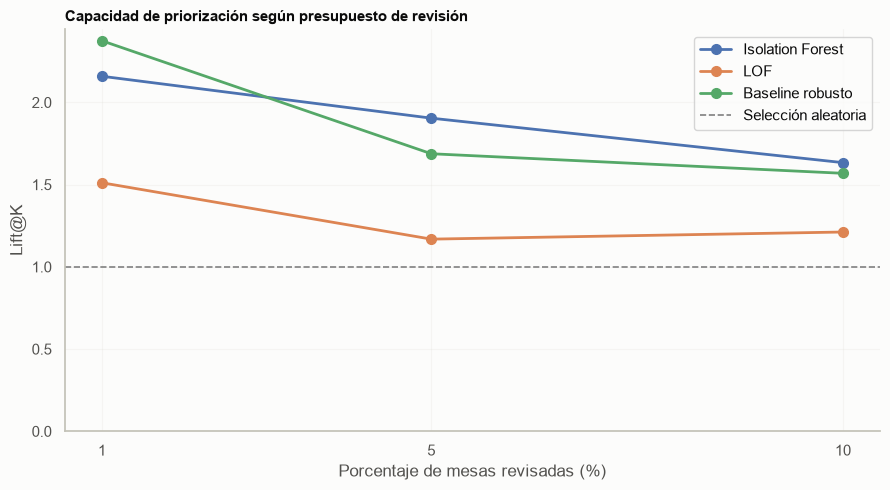

In [292]:

import matplotlib.pyplot as plt

presupuestos = [1, 5, 10]
metricas = ["lift_1pct", "lift_5pct", "lift_10pct"]

fig, ax = plt.subplots(figsize=(9, 5))

for _, fila in df_resultados_test.iterrows():
    valores = [fila[m] for m in metricas]

    ax.plot(
        presupuestos,
        valores,
        marker="o",
        linewidth=2,
        markersize=7,
        label=fila["modelo"]
    )

ax.axhline(
    y=1,
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="Selección aleatoria"
)

ax.set_title(
    "Capacidad de priorización según presupuesto de revisión"
)
ax.set_xlabel("Porcentaje de mesas revisadas (%)")
ax.set_ylabel("Lift@K")
ax.set_xticks(presupuestos)
ax.set_ylim(bottom=0)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()



**Interpretación del rendimiento según presupuesto**

El desempeño de los modelos varía según el porcentaje de mesas priorizadas.

Para el presupuesto más restrictivo (1 %), el baseline estadístico robusto obtuvo el mayor Lift@K (2,3747), seguido de Isolation Forest (2,1588) y LOF (1,5112).

Al ampliar el presupuesto al 5 %, Isolation Forest presentó el mejor rendimiento (1,9040), ventaja que mantuvo al considerar el 10 % de las mesas (1,6336).

En todos los presupuestos evaluados, los tres métodos obtuvieron valores de Lift@K superiores a 1, indicando una concentración de mesas corregidas mayor que la esperada mediante selección aleatoria.

Los resultados evidencian que la elección del método puede depender del presupuesto operativo de revisión, aunque el criterio principal del experimento se estableció previamente en Lift@5 %.



##### 5.3.3.4. Generalización: validación frente a prueba



Se compara el desempeño de los modelos entre los conjuntos de validación y prueba para examinar la estabilidad de su capacidad de priorización.

La comparación utiliza Lift@5 %, establecido previamente como criterio principal de evaluación. Los hiperparámetros permanecen fijos y no se realizan ajustes a partir de los resultados de prueba.

Este análisis permite identificar diferencias entre el rendimiento observado durante la selección experimental y el obtenido sobre datos independientes.


,modelo,validacion,prueba,diferencia
0,Isolation Forest,1.6771,1.9040,0.2269
1,LOF,1.8336,1.1684,-0.6653
2,Baseline robusto,1.5206,1.6876,0.1671


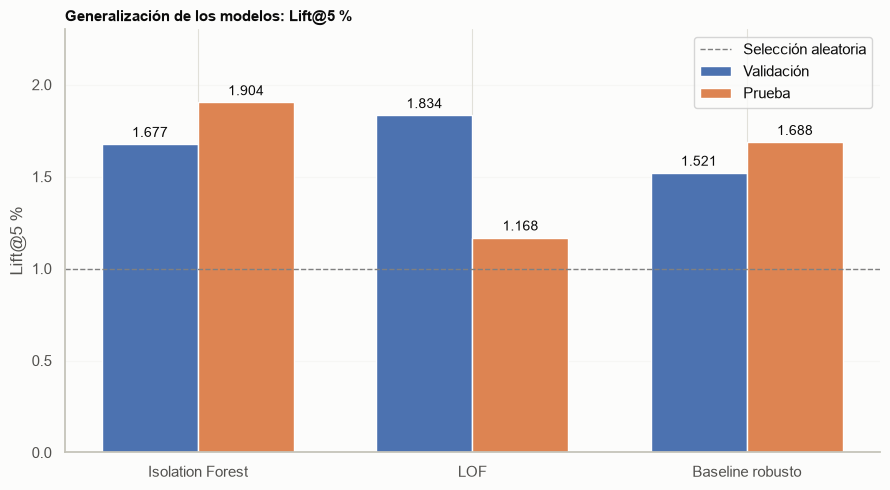

In [293]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Resultados obtenidos previamente en validación
lift_validacion = {
    "Isolation Forest": float(mejor_if["lift_5pct"]),
    "LOF": float(mejor_lof["lift_5pct"]),
    "Baseline robusto": float(
        df_resultados_baseline.loc[
            df_resultados_baseline["agregacion"] == "media",
            "lift_5pct"
        ].iloc[0]
    )
}

# Resultados de prueba, sin reajustar modelos
lift_prueba = dict(zip(
    df_resultados_test["modelo"],
    df_resultados_test["lift_5pct"]
))

df_generalizacion = pd.DataFrame({
    "modelo": list(lift_validacion.keys()),
    "validacion": list(lift_validacion.values()),
    "prueba": [
        lift_prueba[modelo]
        for modelo in lift_validacion
    ]
})

df_generalizacion["diferencia"] = (
    df_generalizacion["prueba"]
    - df_generalizacion["validacion"]
)

display(df_generalizacion.round(4))

# Gráfico de barras agrupadas
x = np.arange(len(df_generalizacion))
ancho = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

barras_val = ax.bar(
    x - ancho / 2,
    df_generalizacion["validacion"],
    ancho,
    label="Validación"
)

barras_test = ax.bar(
    x + ancho / 2,
    df_generalizacion["prueba"],
    ancho,
    label="Prueba"
)

ax.axhline(
    1,
    linestyle="--",
    color="gray",
    linewidth=1,
    label="Selección aleatoria"
)

ax.bar_label(barras_val, fmt="%.3f", padding=3)
ax.bar_label(barras_test, fmt="%.3f", padding=3)

ax.set_title("Generalización de los modelos: Lift@5 %")
ax.set_ylabel("Lift@5 %")
ax.set_xticks(x)
ax.set_xticklabels(df_generalizacion["modelo"])
ax.set_ylim(0, 2.3)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()



**Interpretación de la generalización**

La comparación evidencia diferencias importantes entre los resultados de validación y prueba.

Isolation Forest incrementó su Lift@5 % de 1,6771 a 1,9040, mientras que el baseline robusto pasó de 1,5206 a 1,6876.

Por el contrario, LOF presentó una disminución de 1,8336 a 1,1684, equivalente a una reducción relativa aproximada del 36,3 %.

Este comportamiento muestra que el modelo con mejor rendimiento durante la selección de hiperparámetros no necesariamente conserva su ventaja sobre datos independientes.

La disminución de LOF podría relacionarse con variabilidad entre particiones, sensibilidad a las estructuras locales de densidad o efectos de selección sobre validación. Sin embargo, estos resultados no permiten establecer una causa específica.

Aunque Isolation Forest presentó el mejor Lift@5 % en prueba, LOF continúa siendo el modelo seleccionado mediante el protocolo experimental previamente definido. Los resultados de prueba no se utilizan para modificar retrospectivamente dicha selección.



##### 5.3.3.5. Estabilidad de las puntuaciones de anomalía



Se examina la estabilidad de las distribuciones de puntuaciones de anomalía entre los conjuntos de validación y prueba.

Para cada modelo se comparan las distribuciones mediante histogramas de densidad, así como estadísticas descriptivas de tendencia central, dispersión y percentiles superiores.

Este análisis permite identificar posibles desplazamientos marginales en las puntuaciones. Sin embargo, distribuciones similares no garantizan una capacidad equivalente para priorizar mesas posteriormente corregidas.


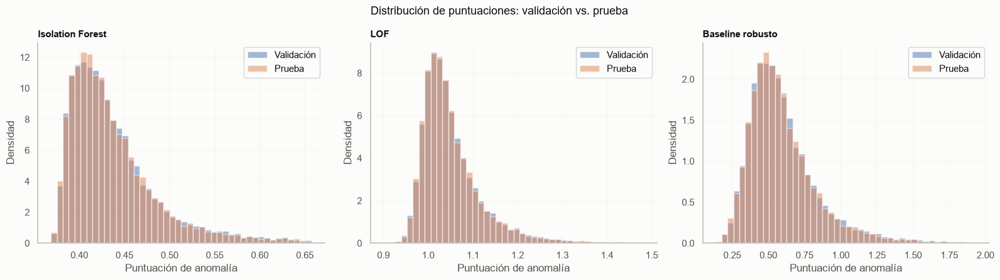

In [294]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Puntuaciones de validación con modelos ya entrenados
scores_val_if_final = -modelo_if_final.score_samples(
    X_val_scaled
)

scores_val_lof_final = -modelo_lof_final.score_samples(
    X_val_scaled
)

scores_val_baseline_final = calcular_scores_baseline(
    X_val_imp,
    agregacion="media"
)

distribuciones = {
    "Isolation Forest": (
        scores_val_if_final, scores_test_if
    ),
    "LOF": (
        scores_val_lof_final, scores_test_lof
    ),
    "Baseline robusto": (
        scores_val_baseline_final, scores_test_baseline
    )
}

fig, axes = plt.subplots(
    1, 3, figsize=(16, 4.5)
)

for ax, (nombre, (val, test)) in zip(
    axes, distribuciones.items()
):
    # Limitar la visualización al percentil 99.5
    # para evitar que valores extremos oculten el patrón
    limite = np.percentile(
        np.concatenate([val, test]), 99.5
    )

    minimo = min(val.min(), test.min())
    bins = np.linspace(minimo, limite, 45)

    ax.hist(
        val, bins=bins, density=True,
        alpha=0.5, label="Validación"
    )

    ax.hist(
        test, bins=bins, density=True,
        alpha=0.5, label="Prueba"
    )

    ax.set_title(nombre)
    ax.set_xlabel("Puntuación de anomalía")
    ax.set_ylabel("Densidad")
    ax.grid(alpha=0.2)
    ax.legend()

fig.suptitle(
    "Distribución de puntuaciones: validación vs. prueba",
    fontsize=13
)

plt.tight_layout()
plt.show()


In [295]:

registros = []

for nombre, (val, test) in distribuciones.items():
    for particion, scores in [
        ("Validación", val),
        ("Prueba", test)
    ]:
        registros.append({
            "modelo": nombre,
            "particion": particion,
            "media": np.mean(scores),
            "desviacion": np.std(scores),
            "mediana": np.median(scores),
            "p95": np.percentile(scores, 95),
            "p99": np.percentile(scores, 99)
        })

df_distribuciones = pd.DataFrame(registros)

display(df_distribuciones.round(4))


,modelo,particion,media,desviacion,mediana,p95,p99
0,Isolation Forest,Validación,0.4390,0.0519,0.4258,0.5471,0.6297
1,Isolation Forest,Prueba,0.4380,0.0513,0.4247,0.5416,0.6303
2,LOF,Validación,1.0563,0.0996,1.0354,1.1974,1.3710
3,LOF,Prueba,1.0551,0.0916,1.0349,1.1935,1.3675
4,Baseline robusto,Validación,0.6123,0.3073,0.5520,1.1094,1.6241
5,Baseline robusto,Prueba,0.6082,0.2922,0.5504,1.0854,1.6331



**Interpretación de la estabilidad de las puntuaciones**

Los tres modelos presentaron distribuciones marginales de puntuaciones similares entre validación y prueba.

Isolation Forest registró medias de 0,4390 y 0,4380; LOF, de 1,0564 y 1,0551; y el baseline robusto, de 0,6123 y 0,6082, respectivamente.

En particular, LOF mantuvo una distribución descriptivamente estable pese a que su Lift@5 % disminuyó de 1,8336 en validación a 1,1684 en prueba.

Esto evidencia que la similitud de las distribuciones marginales de puntuaciones no implica necesariamente estabilidad en la asociación entre las puntuaciones de anomalía y las correcciones posteriores.

Las diferencias observadas podrían estar relacionadas con la composición de las particiones, la variabilidad muestral o la sensibilidad del procedimiento de selección. Los resultados disponibles no permiten identificar una causa específica.



##### 5.3.3.6. Discusión y conclusiones

La evaluación de los tres enfoques evidenció diferencias en su capacidad para priorizar mesas electorales posteriormente corregidas.

**Desempeño comparativo.** Isolation Forest obtuvo el mayor Lift@5 % en prueba (1,9040), seguido del baseline estadístico robusto (1,6876) y LOF (1,1684). Sin embargo, para un presupuesto de revisión del 1 %, el baseline presentó el mejor resultado, lo que demuestra que el rendimiento relativo depende del número de mesas priorizadas.

**Generalización.** LOF fue seleccionado mediante validación, donde alcanzó un Lift@5 % de 1,8336, pero su desempeño disminuyó en prueba. En contraste, Isolation Forest y el baseline presentaron resultados superiores en prueba respecto a validación. Este comportamiento evidencia la importancia de distinguir entre selección de hiperparámetros y evaluación independiente.

**Estabilidad.** Las distribuciones marginales de puntuaciones fueron similares entre validación y prueba. Por tanto, la caída de rendimiento de LOF no estuvo acompañada de un desplazamiento global evidente de sus puntuaciones.

**Limitaciones.** El experimento utiliza una única partición aleatoria de las mesas. En consecuencia, los resultados no permiten establecer la estabilidad del rendimiento entre distintas particiones ni garantizar su generalización a municipios o procesos electorales no observados. Asimismo, las etiquetas de corrección constituyen una referencia indirecta y no una identificación exhaustiva de anomalías o irregularidades.

**Conclusión.** Los resultados respaldan la utilidad de los métodos de detección de anomalías para construir rankings de priorización. Aunque LOF fue seleccionado mediante el procedimiento de validación, Isolation Forest presentó el mejor desempeño observado en prueba para el criterio principal. Esta diferencia se reporta sin modificar retrospectivamente la selección experimental.

Finalmente, las puntuaciones de anomalía deben interpretarse como indicadores estadísticos para orientar análisis posteriores, y no como evidencia directa de fraude electoral.


### **5.4. Aplicación del modelo**

#### 5.4.1. Aplicación del modelo de clasificación

##### 5.4.1.1. Escenario de uso y modelo seleccionado

**Modelo:** random forest con el conjunto B (15 variables) y el umbral $\tau = 0{,}205$ de 5.2.1. Tiene la mayor AP en validación y en prueba y probabilidades bien calibradas (5.3.1). Si se requiere explicar cada decisión, el árbol de decisión queda a solo 1,6 puntos de AP.

**Uso propuesto: priorización de mesas para revisión.** Con el preconteo y los formularios de la mesa, el modelo asigna a cada mesa la probabilidad de ser corregida en el escrutinio. Las mesas se revisan en orden descendente de probabilidad, hasta donde alcance la capacidad de revisión. Es una herramienta de priorización: una probabilidad alta significa que la mesa se parece a mesas que fueron corregidas, **no** que exista una irregularidad o un fraude.

**Datos sobre los que se aplica**

1. Las mesas de la partición de prueba, que el modelo no vio al ajustarse (5.4.1.2 y 5.4.1.3).
2. Departamentos completos que se excluyen del entrenamiento, para simular datos realmente nuevos (5.4.1.4).

In [296]:
import matplotlib.pyplot as plt

LLAVE_clf = ["dep", "mun", "zona", "puesto", "mesa"]
MODELO, CONJ = "Random forest", "B"
modelo_final = modelos_entrenados[(MODELO, CONJ)]
TAU_clf = resultados[(MODELO, CONJ)]["tau"]
pi_test = y_test_clf.mean()

def priorizar(mesas, modelo=modelo_final, columnas=CONJUNTOS[CONJ], tau=TAU_clf):
    """Ordena las mesas de mayor a menor probabilidad estimada de corrección."""
    salida = mesas[LLAVE_clf + ["dif_pre_e11"]].copy()
    salida["prob_correccion"] = modelo.predict_proba(mesas[columnas])[:, 1]
    salida["revisar"] = salida["prob_correccion"] >= tau
    return salida.sort_values("prob_correccion", ascending=False)

ranking = priorizar(X_test_clf)
# Estas dos columnas se añaden solo para evaluar; el modelo no las usa
ranking["y_corregida"] = y_test_clf.loc[ranking.index]
ranking["magnitud"] = X_test_clf.loc[ranking.index, "magnitud"]

print(f"τ = {TAU_clf:.3f}: {int(ranking['revisar'].sum())} de {len(ranking)} mesas marcadas para revisión "
      f"({100 * ranking['revisar'].mean():.2f} %)\n")
print("Las 10 mesas con mayor probabilidad:")
display(ranking.head(10).round({"prob_correccion": 3}))

# Bandas de probabilidad
bandas = pd.cut(ranking["prob_correccion"], [0, 0.05, TAU_clf, 0.5, 0.8, 1.0],
                include_lowest=True, right=False)
por_banda = ranking.groupby(bandas, observed=True)["y_corregida"].agg(mesas="size", corregidas="sum")
por_banda["% corregidas"] = 100 * por_banda["corregidas"] / por_banda["mesas"]
print("\nMesas de prueba según la probabilidad asignada:")
display(por_banda.round(1))

τ = 0.205: 1236 de 23670 mesas marcadas para revisión (5.22 %)

Las 10 mesas con mayor probabilidad:


,dep,mun,zona,puesto,mesa,dif_pre_e11,prob_correccion,revisar,y_corregida,magnitud
64907,16,001,016,49,000003,10.0,1.0,True,1,10
23141,05,001,012,04,000007,2.0,1.0,True,1,10
104447,31,022,005,01,000006,10.0,1.0,True,1,10
107007,31,079,003,06,000001,1.0,1.0,True,1,1
101644,31,001,024,03,000009,1.0,1.0,True,1,1
103377,31,004,000,00,000024,1.0,1.0,True,1,1
23538,05,001,016,01,000006,6.0,1.0,True,1,6
97765,29,094,000,00,000023,8.0,1.0,True,1,8
19643,03,016,000,01,000003,1.0,1.0,True,1,1
43469,15,016,000,01,000025,7.0,1.0,True,1,7



Mesas de prueba según la probabilidad asignada:


,mesas,corregidas,% corregidas
prob_correccion,,,
"[0.0, 0.05)",22103,106,0.5
"[0.05, 0.205)",331,23,6.9
"[0.205, 0.5)",139,76,54.7
"[0.5, 0.8)",260,172,66.2
"[0.8, 1.0)",408,394,96.6


##### 5.4.1.2. Capacidad de priorización

Si solo se pueden revisar las $K$ mesas con mayor probabilidad:

- **Precision@K** = mesas corregidas entre las $K$ revisadas / $K$.
- **Recall@K** = mesas corregidas entre las $K$ revisadas / total de mesas corregidas.
- **Lift@K** = Precision@K / $\pi$: cuántas veces mejor que revisar al azar ($\pi = 0{,}0507$).

También se mide el porcentaje de **votos corregidos** (suma de `magnitud`) que contienen las mesas revisadas. `magnitud` se usa solo para evaluar, nunca como variable de entrada.

,K,% de mesas,Precision@K,Recall@K,Lift@K,% votos corregidos
0,100,0.42,1.000,0.083,19.7,2.5
1,250,1.06,1.000,0.208,19.7,8.4
2,500,2.11,1.000,0.417,19.7,21.0
3,1000,4.22,0.940,0.783,18.5,74.8
4,2000,8.45,0.551,0.918,10.9,88.9


Con τ: 1236 mesas marcadas; detectan el 89.2 % de las mesas corregidas y el 88.1 % de los votos corregidos.
Omitidas: 129; de ellas, 87 % tienen dif_pre_e11 = 0. Mediana de votos corregidos: 2 (omitidas) frente a 3 (detectadas).


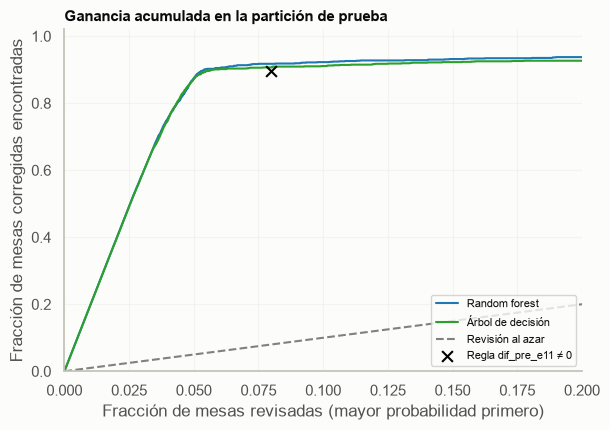

In [297]:
y_ord = ranking["y_corregida"].to_numpy()
mag_ord = ranking["magnitud"].to_numpy()
total_corr, total_mag = y_ord.sum(), mag_ord.sum()

filas = []
for K in [100, 250, 500, 1000, 2000]:
    vp = y_ord[:K].sum()
    filas.append({"K": K, "% de mesas": 100 * K / len(y_ord),
                  "Precision@K": vp / K, "Recall@K": vp / total_corr,
                  "Lift@K": (vp / K) / pi_test,
                  "% votos corregidos": 100 * mag_ord[:K].sum() / total_mag})
display(pd.DataFrame(filas).round({"% de mesas": 2, "Precision@K": 3, "Recall@K": 3,
                                   "Lift@K": 1, "% votos corregidos": 1}))

# Resultado con el umbral τ de 5.2.1
marc = ranking["revisar"].to_numpy()
print(f"Con τ: {int(marc.sum())} mesas marcadas; detectan el {100 * (marc & (y_ord == 1)).sum() / total_corr:.1f} % "
      f"de las mesas corregidas y el {100 * mag_ord[marc].sum() / total_mag:.1f} % de los votos corregidos.")

# Mesas corregidas que el modelo no marcó
omitidas = (~marc) & (y_ord == 1)
detectadas = marc & (y_ord == 1)
sin_dif = ranking["dif_pre_e11"].fillna(0).to_numpy() == 0
print(f"Omitidas: {int(omitidas.sum())}; de ellas, {100 * sin_dif[omitidas].mean():.0f} % tienen dif_pre_e11 = 0. "
      f"Mediana de votos corregidos: {np.median(mag_ord[omitidas]):.0f} (omitidas) "
      f"frente a {np.median(mag_ord[detectadas]):.0f} (detectadas).")

# Curva de ganancia acumulada: modelo, árbol y revisión al azar
ranking_arbol = priorizar(X_test_clf, modelo=modelos_entrenados[("Árbol de decisión", "B")])
fig, ax = plt.subplots(figsize=(6.2, 4.4))
for nombre, rk, color in [("Random forest", ranking, "#1f77b4"),
                          ("Árbol de decisión", ranking_arbol, "#2ca02c")]:
    acumulado = y_test_clf.loc[rk.index].to_numpy().cumsum() / total_corr
    ax.plot(np.arange(1, len(rk) + 1) / len(rk), acumulado, color=color, label=nombre)
ax.plot([0, 1], [0, 1], ls="--", color="gray", label="Revisión al azar")
regla_marcadas = (X_test_clf["dif_pre_e11"].fillna(0) != 0)
ax.scatter(regla_marcadas.mean(), y_test_clf[regla_marcadas].sum() / total_corr,
           marker="x", s=60, color="black", zorder=3, label="Regla dif_pre_e11 ≠ 0")
ax.set_xlim(0, 0.2); ax.set_ylim(0, 1.02)
ax.set_xlabel("Fracción de mesas revisadas (mayor probabilidad primero)")
ax.set_ylabel("Fracción de mesas corregidas encontradas")
ax.set_title("Ganancia acumulada en la partición de prueba")
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

##### 5.4.1.3. Generalización a departamentos no vistos

Las mesas de prueba comparten departamento con mesas de entrenamiento. Para simular datos realmente nuevos se excluye **un departamento completo**, se reentrena el random forest con los demás (mismos hiperparámetros) y se aplica al departamento excluido; el proceso se repite para cada departamento (*leave-one-department-out*). El umbral $\tau$ no se modifica.

AP con departamentos no vistos (todas las mesas): 0.9078   [validación cruzada de 5.2.1: 0.9076]

Departamentos con al menos 30 mesas corregidas: 26 de 33


,AP,P,R
min,0.812,0.706,0.823
25%,0.893,0.813,0.883
50%,0.919,0.863,0.897
75%,0.935,0.910,0.918
max,0.979,0.951,0.971


Los 5 departamentos con menor AP:


,dep,mesas,corregidas,prevalencia,AP,P,R
21,16,17164,755,0.0440,0.888,0.869,0.860
22,15,6916,352,0.0509,0.885,0.822,0.866
23,48,2095,130,0.0621,0.849,0.810,0.854
24,17,1252,112,0.0895,0.832,0.752,0.839
25,21,3228,181,0.0561,0.812,0.706,0.823


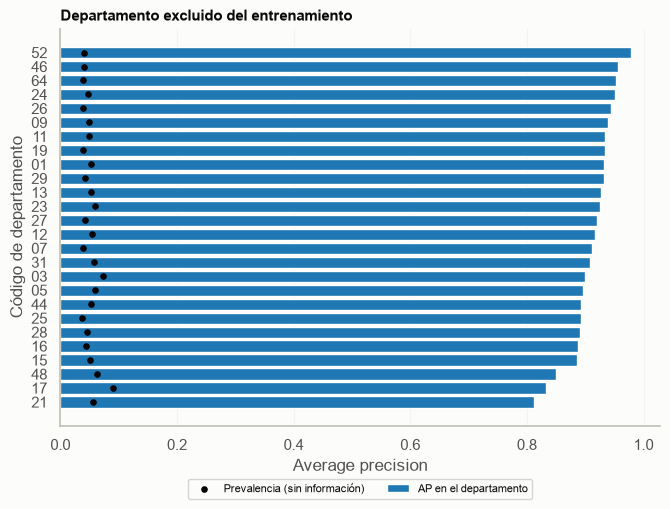

In [298]:
prob_dep = pd.Series(np.nan, index=df_clf.index)
for d in sorted(df_clf["dep"].unique()):
    fuera = df_clf["dep"] == d
    m = clone(modelo_final).fit(df_clf.loc[~fuera, CONJUNTOS[CONJ]], df_clf.loc[~fuera, "y_corregida"])
    prob_dep.loc[fuera] = m.predict_proba(df_clf.loc[fuera, CONJUNTOS[CONJ]])[:, 1]

print(f"AP con departamentos no vistos (todas las mesas): "
      f"{average_precision_score(df_clf['y_corregida'], prob_dep):.4f}   "
      f"[validación cruzada de 5.2.1: {resultados[(MODELO, CONJ)]['AP_cv']:.4f}]")

filas = []
for d, g in df_clf.groupby("dep"):
    y_dep, p = g["y_corregida"].to_numpy(), prob_dep.loc[g.index].to_numpy()
    if y_dep.sum() == 0:
        continue
    marc_d = p >= TAU_clf
    vp = int((marc_d & (y_dep == 1)).sum())
    filas.append(dict(dep=d, mesas=len(g), corregidas=int(y_dep.sum()), prevalencia=y_dep.mean(),
                      AP=average_precision_score(y_dep, p), P=vp / max(marc_d.sum(), 1), R=vp / y_dep.sum()))
por_dep = pd.DataFrame(filas)
grandes = por_dep[por_dep["corregidas"] >= 30].sort_values("AP", ascending=False).reset_index(drop=True)
print(f"\nDepartamentos con al menos 30 mesas corregidas: {len(grandes)} de {len(por_dep)}")
display(grandes[["AP", "P", "R"]].describe().loc[["min", "25%", "50%", "75%", "max"]].round(3))
print("Los 5 departamentos con menor AP:")
display(grandes.tail(5).round({"prevalencia": 4, "AP": 3, "P": 3, "R": 3}))

fig, ax = plt.subplots(figsize=(6.8, 5.2))
g_plot = grandes.sort_values("AP")
ax.barh(g_plot["dep"], g_plot["AP"], color="#1f77b4", label="AP en el departamento")
ax.scatter(g_plot["prevalencia"], g_plot["dep"], color="black", s=14, zorder=3, label="Prevalencia (sin información)")
ax.set_xlabel("Average precision"); ax.set_ylabel("Código de departamento")
ax.set_title("Departamento excluido del entrenamiento")
ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout(); plt.show()

**Lectura de la aplicación del modelo**

- **Las probabilidades ordenan bien las mesas.** De las 408 mesas de prueba con probabilidad ≥ 0,8, el 96,6 % fue corregido; entre 0,5 y 0,8, el 66,2 %; y de las 22.103 con probabilidad < 0,05, solo el 0,5 %.
- **Con poca capacidad de revisión, el modelo rinde mucho.** Revisando solo las 500 mesas de mayor probabilidad (2,1 % de la prueba) todas fueron corregidas (Lift@K = 19,7, el máximo posible con esta prevalencia). Con 1.000 mesas (4,2 %) se encuentra el 78 % de las mesas corregidas y el 75 % de los votos corregidos.
- **Con el umbral $\tau$ de 5.2.1** se marcan 1.236 mesas (5,2 %), que contienen el 89,2 % de las mesas corregidas y el 88,1 % de los votos corregidos. La curva de ganancia muestra que, tras ese punto, revisar más mesas aporta muy poco.
- **Mesas que el modelo omite (129):** el 87 % no tiene diferencia entre el preconteo y el E-11 (`dif_pre_e11 = 0`), es decir, no presentan la señal en la que se apoya el modelo. Sus correcciones son algo menores (mediana de 2 votos frente a 3 en las detectadas).
- **Generalización a departamentos no vistos:** la AP al excluir cada departamento del entrenamiento es 0,908, igual a la de la validación cruzada (0,908). Entre los 26 departamentos con al menos 30 mesas corregidas, la AP va de 0,81 a 0,98 (mediana 0,92), siempre muy por encima de la prevalencia; los más bajos son 21, 17, 48, 15 y 16 (0,81–0,89).

**Recomendaciones y límites de uso**

1. **Es una herramienta de priorización.** Una mesa corregida no es necesariamente una mesa irregular, y una probabilidad alta no prueba fraude.
2. **Depende de que exista el E-11 de la mesa.** La regla simple "`dif_pre_e11` $\neq 0$" ya recupera cerca del 90 % de las mesas corregidas; el aporte del modelo es reducir las falsas alarmas (5.3.1) y ordenar las mesas por prioridad.
3. **El número de mesas a revisar lo fija la capacidad disponible.** Con $\tau = 0{,}205$ son ≈ 5 % de las mesas; si se puede revisar menos, se toman las de mayor probabilidad.
4. **Solo se validó con esta elección.** Para otra votación habría que revalidar el modelo y recalibrar el umbral.
5. **Mesas con E-11 sospechoso (145):** no tienen `dif_pre_e11` y el modelo la reemplaza por la mediana (0), por lo que sus resultados son menos confiables.

#### 5.4.2. Aplicación del modelo de regresión

##### 5.4.2.1. Aplicación en dos etapas y listado priorizado

En la práctica, el modelo se usa en dos etapas sobre todas las mesas de un departamento, sin conocer el resultado del escrutinio:

1. **Etapa 1:** decidir qué mesas se corregirán.
2. **Etapa 2:** para esas mesas, estimar cuántos votos cambiarán con el Random Forest de regresión.

La **magnitud esperada** de cada mesa es 0 si la etapa 1 indica que no se corregirá, y la magnitud estimada por la regresión si se corregirá. Ordenar las mesas por magnitud esperada permite priorizar la revisión de las que tienen más votos en juego.

En esta versión, la etapa 1 se aproxima con la **regla de consistencia**: la mesa se marca si el total del preconteo no coincide con el número de votantes del E-11. Al integrar el clasificador de la sección 5.2.1, esta regla se reemplaza por sus predicciones. Se aplica sobre las 32 356 mesas de los 9 departamentos de prueba, que simulan departamentos nuevos para el modelo, y se compara con los valores reales del escrutinio.

In [299]:
from sklearn.metrics import mean_absolute_error

mejor_reg = busq_reg[MEJOR_REG].best_estimator_
X_te = X.iloc[idx_te]
listado = df.iloc[idx_te][LLAVE].copy()

# Etapa 1 (provisional): la mesa se corregirá si el preconteo no coincide con el E-11
listado["se_corrige"] = (X_te["abs_dif_pre_e11"].fillna(0) > 0).astype(int)
# Etapa 2: magnitud estimada si la mesa se corrige
listado["magnitud_si_se_corrige"] = np.clip(np.expm1(mejor_reg.predict(X_te)), 0, None).round()
listado["magnitud_esperada"] = listado["se_corrige"] * listado["magnitud_si_se_corrige"]
# Valores reales, para comparar
listado["corregida_real"] = df["y_corregida"].iloc[idx_te].to_numpy()
listado["magnitud_real"] = df["magnitud"].iloc[idx_te].to_numpy()

resumen_app = pd.DataFrame({
    "MAE (votos)": [mean_absolute_error(listado["magnitud_real"], listado["magnitud_esperada"]),
                    mean_absolute_error(listado["magnitud_real"], np.zeros(len(listado)))],
}, index=["Dos etapas (regla + Random Forest)", "Predecir siempre 0 votos"])
print(f"Mesas de prueba: {len(listado):,} | marcadas para revisión: {listado['se_corrige'].sum():,}")
display(resumen_app.round(3))

marcadas = listado[listado["se_corrige"] == 1]
votos_reales_total = listado["magnitud_real"].sum()
print(f"Mesas marcadas que sí fueron corregidas: {marcadas['corregida_real'].mean():.1%}")
print(f"Votos corregidos que caen en las mesas marcadas: "
      f"{marcadas['magnitud_real'].sum() / votos_reales_total:.1%} del total")
print(f"Votos estimados en mesas marcadas: {marcadas['magnitud_esperada'].sum():,.0f} | "
      f"votos reales en esas mesas: {marcadas['magnitud_real'].sum():,.0f}")

columnas = LLAVE + ["magnitud_esperada", "magnitud_real", "corregida_real"]
display(listado.sort_values("magnitud_esperada", ascending=False)[columnas].head(15))

Mesas de prueba: 32,356 | marcadas para revisión: 2,617


,MAE (votos)
Dos etapas (regla + Random Forest),0.304
Predecir siempre 0 votos,0.640


Mesas marcadas que sí fueron corregidas: 58.6%
Votos corregidos que caen en las mesas marcadas: 81.3% del total
Votos estimados en mesas marcadas: 18,768 | votos reales en esas mesas: 16,829


,dep,mun,zona,puesto,mesa,magnitud_esperada,magnitud_real,corregida_real
67764,17,006,099,17,000001,203.0,200,1
113569,48,013,099,58,000001,196.0,0,0
89163,27,058,099,08,000001,180.0,187,1
69416,19,001,006,05,000019,177.0,207,1
89164,27,058,099,08,000002,176.0,181,1
26879,05,097,099,49,000003,159.0,158,1
67931,17,011,099,41,000001,157.0,149,1
103965,31,019,005,01,000035,143.0,140,1
116684,52,080,099,45,000003,140.0,138,1
91239,27,160,004,03,000013,117.0,141,1


**Lectura:** de las 32 356 mesas de los departamentos de prueba, la regla marca 2 617 para revisión (8 %). De ellas, el 58,6 % fue efectivamente corregida en el escrutinio, frente al 5,3 % del total de mesas, y en esas 2 617 mesas se concentra el **81,3 % de todos los votos que cambiaron** en el escrutinio. Revisando menos de una de cada diez mesas, un auditor cubriría así más de cuatro quintas partes del volumen de votos corregidos.

La regresión estima bien cuántos votos están en juego en las mesas marcadas: 18 768 votos estimados frente a 16 829 reales (una sobreestimación del 12 %). Sobre todas las mesas de prueba, el modelo de dos etapas se equivoca en promedio 0,30 votos por mesa, frente a 0,64 de predecir siempre que no hay cambio.

En el listado ordenado por magnitud esperada, las primeras mesas son correcciones grandes que el modelo estima con mucha precisión (por ejemplo, 203 votos estimados frente a 200 reales, o 159 frente a 158). También aparecen falsas alarmas, como una mesa con 196 votos estimados que no fue corregida: corresponden a mesas donde el preconteo no coincide con el E-11 pero el escrutinio no cambió el resultado. Estas falsas alarmas provienen de la etapa 1; al reemplazar la regla por el clasificador de la sección 5.2.1, que tiene mayor precisión, deberían reducirse.

##### 5.4.2.2. Etapa 1 con el clasificador de la sección 5.2.1

Ahora la regla se reemplaza por el **clasificador elegido en 5.2.1**: el Random Forest con el conjunto de variables B (`max_depth = 12`, `max_features = 0.5`, `min_samples_leaf = 20`, 300 árboles) y el umbral $\tau = 0{,}205$, que maximizó $F_2$ en su validación cruzada. Para no repetir la búsqueda de hiperparámetros de 5.2.1 (≈ 70 minutos), el clasificador se entrena **una sola vez** con esos valores ya elegidos.

Para que la comparación con la regresión sea justa, se entrena con las mesas de los **24 departamentos de entrenamiento** de esta sección (`idx_tr`) y se aplica sobre los **9 departamentos de prueba** (`idx_te`), los mismos donde se evaluó la regresión. Se usan las 15 variables del conjunto B definidas en 5.1.1.2.

Con la probabilidad de corrección $\hat{p}$ de cada mesa se calculan dos versiones de la magnitud esperada:

- **Con umbral:** magnitud estimada si $\hat{p} \ge \tau$, y 0 si no (igual que con la regla).
- **Probabilística:** $\hat{p} \times$ magnitud estimada, que es el valor esperado de votos que cambiarán.

In [300]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

# Conjunto B de la sección 5.1.1.2 (variables del clasificador)
VARS_CLF = [
    "total_votos_preconteo", "proporcion_blancos", "proporcion_nulos",
    "proporcion_no_marcados", "margen_primero_segundo", "concentracion_maxima",
    "hhi", "tasa_retirados",
    "dif_pre_e11", "dif_e14_e11", "dif_urna_e11", "participacion_e11",
    "tachaduras_enmendaduras", "estado_sobre", "recontada_jurados",
]
TAU = 0.205   # umbral elegido en 5.2.1 (máximo F2 en validación cruzada)

def a_binaria(serie, positivo):
    if pd.api.types.is_numeric_dtype(serie):
        return serie.fillna(0).astype("int8")
    return (serie.astype("string").str.strip().str.upper() == positivo).astype("int8")

dfc = df.copy()
dfc["tachaduras_enmendaduras"] = a_binaria(dfc["tachaduras_enmendaduras"], "SI")
dfc["recontada_jurados"] = a_binaria(dfc["recontada_jurados"], "SI")
dfc["estado_sobre"] = a_binaria(dfc["estado_sobre"], "MAL")
Xc = dfc[VARS_CLF]

t0 = time.time()
clf = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=300, max_depth=12, max_features=0.5,
                           min_samples_leaf=20, random_state=42, n_jobs=-1),
)
clf.fit(Xc.iloc[idx_tr], y.iloc[idx_tr])
p_hat = clf.predict_proba(Xc.iloc[idx_te])[:, 1]
print(f"Clasificador entrenado en {time.time() - t0:.0f} s | "
      f"average precision en los departamentos de prueba: "
      f"{average_precision_score(y.iloc[idx_te], p_hat):.3f}")

listado["p_correccion"] = p_hat
listado["se_corrige_clf"] = (p_hat >= TAU).astype(int)
listado["magnitud_esperada_clf"] = listado["se_corrige_clf"] * listado["magnitud_si_se_corrige"]
listado["magnitud_esperada_prob"] = p_hat * listado["magnitud_si_se_corrige"]

Clasificador entrenado en 30 s | average precision en los departamentos de prueba: 0.906


##### 5.4.2.3. Comparación: regla frente a clasificador

Para cada forma de decidir la etapa 1 se calcula: cuántas mesas se marcan para revisión, qué porcentaje de ellas fue realmente corregido (precisión), qué porcentaje de las mesas corregidas se detecta (*recall*), qué porcentaje de los votos corregidos cae en las mesas marcadas, cuántos votos estima la regresión en esas mesas frente a los reales, y el MAE de la magnitud esperada sobre todas las mesas de prueba.

In [301]:
real_c = listado["corregida_real"].to_numpy()
real_m = listado["magnitud_real"].to_numpy()
ETAPA1 = {
    "Regla preconteo ≠ E-11": ("se_corrige", "magnitud_esperada"),
    f"Clasificador RF (τ = {TAU})": ("se_corrige_clf", "magnitud_esperada_clf"),
}
filas = []
for nombre, (col_marca, col_esp) in ETAPA1.items():
    marca = listado[col_marca].to_numpy() == 1
    filas.append({
        "Etapa 1": nombre,
        "mesas marcadas": int(marca.sum()),
        "% marcadas": 100 * marca.mean(),
        "precisión (%)": 100 * real_c[marca].mean(),
        "recall mesas (%)": 100 * real_c[marca].sum() / real_c.sum(),
        "% votos corregidos cubiertos": 100 * real_m[marca].sum() / real_m.sum(),
        "votos estimados": listado.loc[marca, col_esp].sum(),
        "votos reales": real_m[marca].sum(),
        "MAE (votos, todas las mesas)": mean_absolute_error(real_m, listado[col_esp]),
    })
filas.append({
    "Etapa 1": "Clasificador × regresión (p̂ · m̂)",
    "votos estimados": listado["magnitud_esperada_prob"].sum(),
    "votos reales": real_m.sum(),
    "MAE (votos, todas las mesas)": mean_absolute_error(real_m, listado["magnitud_esperada_prob"]),
})
filas.append({
    "Etapa 1": "Predecir siempre 0 votos",
    "MAE (votos, todas las mesas)": mean_absolute_error(real_m, np.zeros(len(real_m))),
})
comparacion_etapa1 = pd.DataFrame(filas).set_index("Etapa 1")
display(comparacion_etapa1.round(2).fillna("—"))

,mesas marcadas,% marcadas,precisión (%),recall mesas (%),% votos corregidos cubiertos,votos estimados,votos reales,"MAE (votos, todas las mesas)"
Etapa 1,,,,,,,,
Regla preconteo ≠ E-11,2617.0,8.09,58.58,89.86,81.32,18768.0,16829.0,0.30
Clasificador RF (τ = 0.205),1801.0,5.57,84.9,89.62,84.52,17858.0,17490.0,0.23
Clasificador × regresión (p̂ · m̂),—,—,—,—,—,16612.39,20694.0,0.28
Predecir siempre 0 votos,—,—,—,—,—,—,—,0.64


**Lectura:** el clasificador alcanza una *average precision* de **0,906** en los 9 departamentos de prueba, que no vio durante el entrenamiento.

| | Regla preconteo ≠ E-11 | Clasificador RF (τ = 0,205) |
|---|---:|---:|
| Mesas marcadas | 2 617 (8,1 %) | **1 801 (5,6 %)** |
| Precisión | 58,6 % | **84,9 %** |
| Recall de mesas corregidas | 89,9 % | 89,6 % |
| Votos corregidos cubiertos | 81,3 % | **84,5 %** |
| Votos estimados / reales en las mesas marcadas | 18 768 / 16 829 (+11,5 %) | **17 858 / 17 490 (+2,1 %)** |
| MAE (votos, todas las mesas) | 0,30 | **0,23** |

- **Menos mesas, mismas detecciones.** El clasificador marca 816 mesas menos que la regla (un tercio menos) y detecta prácticamente las mismas mesas corregidas (89,6 % frente a 89,9 %). Las mesas que deja de marcar son sobre todo falsas alarmas: mesas donde el preconteo no coincide con el E-11, pero el escrutinio no cambió el resultado. Por eso la precisión sube de 58,6 % a **84,9 %**.
- **Más votos cubiertos y mejor estimados.** Aun revisando menos mesas, el clasificador cubre más votos corregidos (84,5 % frente a 81,3 %). En las mesas marcadas, la regresión estima 17 858 votos frente a 17 490 reales (+2,1 %); con la regla, la sobreestimación era del 11,5 %.
- **Menor error del modelo de dos etapas.** Sobre todas las mesas de prueba, el error promedio es de **0,23 votos por mesa** con el clasificador, frente a 0,30 con la regla y 0,64 al predecir siempre que no hay cambio.
- **Versión probabilística ($\hat{p}\cdot\hat{m}$).** Tiene un MAE intermedio (0,28) y estima 16 612 votos corregidos en total, frente a 20 694 reales (−19,7 %). Subestima porque parte de las correcciones ocurre en mesas sin señal de inconsistencia (votos redistribuidos entre candidaturas sin cambiar el total), a las que el clasificador asigna una probabilidad baja. Por eso es más útil para **ordenar** las mesas por votos en juego (sección 5.4.2.4) que para estimar el total.

**En conclusión,** reemplazar la regla por el clasificador mantiene la detección de mesas corregidas, reduce en un tercio las mesas a revisar y mejora la estimación de los votos que cambiarán, que es el objetivo de combinar la clasificación con la regresión.

##### 5.4.2.4. Priorización con el mismo presupuesto de revisión

Como la regla y el clasificador marcan un número distinto de mesas, se comparan también con el **mismo presupuesto**: se revisa el 1, 2, 5 y 8 % de las mesas de prueba, ordenadas por (a) la diferencia preconteo − E-11 en valor absoluto, (b) la probabilidad del clasificador $\hat{p}$ y (c) la magnitud esperada $\hat{p}\cdot\hat{m}$, que combina la clasificación y la regresión.

% mesas corregidas detectadas


mesas revisadas,1% (324),2% (647),"5% (1,618)","8% (2,588)"
criterio,,,,
Clasificador (p̂),19.0,37.9,84.6,91.2
Clasificador × regresión (p̂ · m̂),17.8,35.3,82.7,91.3
Regla |dif_pre_e11|,17.1,34.2,67.1,89.1


% votos corregidos cubiertos


mesas revisadas,1% (324),2% (647),"5% (1,618)","8% (2,588)"
criterio,,,,
Clasificador (p̂),8.9,19.0,81.3,85.7
Clasificador × regresión (p̂ · m̂),62.4,73.4,84.6,86.3
Regla |dif_pre_e11|,57.7,68.1,77.1,81.0


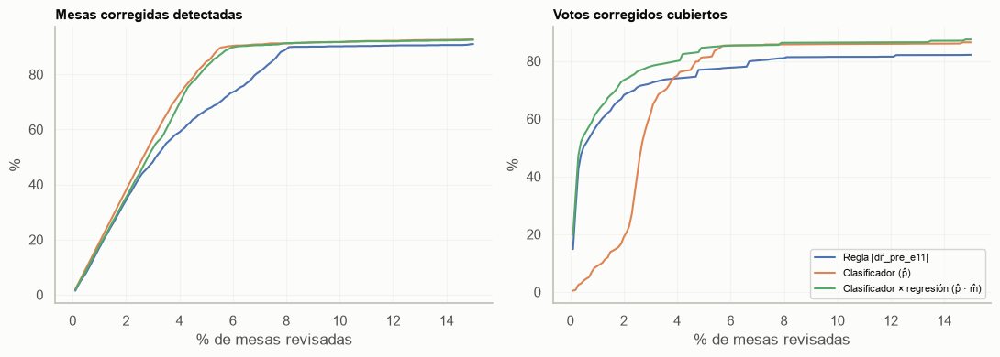

Mesas con mayor magnitud esperada (p̂ · m̂):


,dep,mun,zona,puesto,mesa,p_correccion,magnitud_si_se_corrige,magnitud_esperada_prob,magnitud_real,corregida_real
67764,17,006,099,17,000001,0.92,203.0,186.96,200,1
113569,48,013,099,58,000001,0.91,196.0,178.26,0,0
89164,27,058,099,08,000002,1.00,176.0,175.43,181,1
89163,27,058,099,08,000001,0.91,180.0,164.45,187,1
26879,05,097,099,49,000003,0.99,159.0,157.33,158,1
115415,52,005,001,05,000011,0.54,268.0,144.55,265,1
116684,52,080,099,45,000003,1.00,140.0,140.00,138,1
103965,31,019,005,01,000035,0.95,143.0,135.83,140,1
106503,31,064,099,41,000004,0.51,264.0,135.67,256,1
67931,17,011,099,41,000001,0.76,157.0,119.87,149,1


In [302]:
ORDENES = {
    "Regla |dif_pre_e11|": X_te["abs_dif_pre_e11"].fillna(0).to_numpy(),
    "Clasificador (p̂)": listado["p_correccion"].to_numpy(),
    "Clasificador × regresión (p̂ · m̂)": listado["magnitud_esperada_prob"].to_numpy(),
}
filas = []
for presupuesto in [0.01, 0.02, 0.05, 0.08]:
    n = int(round(presupuesto * len(listado)))
    for criterio, puntaje in ORDENES.items():
        top = np.argsort(-puntaje, kind="stable")[:n]
        filas.append({"mesas revisadas": f"{presupuesto:.0%} ({n:,})", "criterio": criterio,
                      "% mesas corregidas detectadas": 100 * real_c[top].sum() / real_c.sum(),
                      "% votos corregidos cubiertos": 100 * real_m[top].sum() / real_m.sum()})
prior = pd.DataFrame(filas)
orden_cols = prior["mesas revisadas"].unique()
for metrica in ["% mesas corregidas detectadas", "% votos corregidos cubiertos"]:
    print(metrica)
    display(prior.pivot(index="criterio", columns="mesas revisadas", values=metrica)[orden_cols].round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fracs = np.linspace(0.001, 0.15, 150)
for criterio, puntaje in ORDENES.items():
    orden = np.argsort(-puntaje, kind="stable")
    k = (fracs * len(orden)).astype(int)
    axes[0].plot(100 * fracs, 100 * np.cumsum(real_c[orden])[k] / real_c.sum(), label=criterio)
    axes[1].plot(100 * fracs, 100 * np.cumsum(real_m[orden])[k] / real_m.sum(), label=criterio)
axes[0].set_title("Mesas corregidas detectadas"); axes[1].set_title("Votos corregidos cubiertos")
for a in axes:
    a.set_xlabel("% de mesas revisadas"); a.set_ylabel("%"); a.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Mesas con mayor magnitud esperada (p̂ · m̂):")
display(listado.sort_values("magnitud_esperada_prob", ascending=False)
        [LLAVE + ["p_correccion", "magnitud_si_se_corrige", "magnitud_esperada_prob",
                  "magnitud_real", "corregida_real"]].head(15).round(2))

**Lectura:** las tablas comparan tres formas de ordenar las 32 356 mesas de prueba para revisarlas, con el mismo presupuesto (1, 2, 5 y 8 % de las mesas).

**Mesas corregidas detectadas.** Ordenar por la probabilidad del clasificador ($\hat{p}$) es lo mejor para encontrar **mesas** corregidas: revisando el 5 % de las mesas (1 618) detecta el **84,6 %** de las corregidas, frente al 82,7 % de $\hat{p}\cdot\hat{m}$ y el 67,1 % de la regla. Con presupuestos muy pequeños (1–2 %) los tres criterios quedan cerca, y a partir del 8 % todos se estabilizan alrededor del 90 %.

**Votos corregidos cubiertos.** Aquí la combinación con la regresión marca la diferencia:

| Mesas revisadas | Clasificador ($\hat{p}$) | Clasificador × regresión ($\hat{p}\cdot\hat{m}$) | Regla $\lvert$`dif_pre_e11`$\rvert$ |
|---|---:|---:|---:|
| 1 % (324) | 8,9 % | **62,4 %** | 57,7 % |
| 2 % (647) | 19,0 % | **73,4 %** | 68,1 % |
| 5 % (1 618) | 81,3 % | **84,6 %** | 77,1 % |
| 8 % (2 588) | 85,7 % | **86,3 %** | 81,0 % |

- Revisando solo **324 mesas (1 %)**, el orden por $\hat{p}\cdot\hat{m}$ cubre el **62,4 % de todos los votos corregidos** en los departamentos de prueba; ordenar solo por $\hat{p}$ cubre el 8,9 %.
- El clasificador solo pone primero las mesas de las que está más seguro, y la mayoría de ellas tiene correcciones pequeñas. En la gráfica de la derecha, su curva (naranja) sube despacio y solo alcanza a las otras alrededor del 3–5 % de las mesas revisadas.
- Al multiplicar por la magnitud estimada, las mesas con **más votos en juego** pasan al frente. El costo es mínimo en número de mesas detectadas (82,7 % frente a 84,6 % con el 5 % del presupuesto).
- La regla queda por debajo de $\hat{p}\cdot\hat{m}$ en todos los presupuestos, tanto en mesas como en votos.

**Listado priorizado.** De las 15 mesas con mayor magnitud esperada, **14 fueron corregidas** en el escrutinio, y la regresión estima muy bien su magnitud (por ejemplo, 203 votos estimados frente a 200 reales, 159 frente a 158 o 140 frente a 138). Dos casos muestran el aporte de la regresión: las mesas 52-005-001-05-000011 y 31-064-099-41-000004 tienen una probabilidad de corrección de apenas 0,54 y 0,51, pero sube a los primeros lugares porque se estiman correcciones de 268 y 264 votos, y en efecto cambiaron 265 y 256. Ordenando solo por $\hat{p}$ quedarían detrás de cientos de mesas con correcciones de 1 o 2 votos. La única falsa alarma (48-013-099-58-000001, con 196 votos estimados y ninguna corrección) también aparecía con la regla: el clasificador le asigna una probabilidad alta (0,91) porque el preconteo no coincide con el E-11, pero el escrutinio no cambió el resultado.

**En conclusión,** la clasificación y la regresión cumplen funciones complementarias. El clasificador es la mejor opción para decidir **qué mesas** se van a corregir, y la regresión permite **priorizar las que tienen más votos en juego**. Con un presupuesto de revisión muy pequeño, la combinación $\hat{p}\cdot\hat{m}$ cubre la mayor parte del volumen de votos corregidos, algo que ninguno de los dos modelos logra por separado.

#### 5.4.3. Priorización de mesas mediante detección de anomalías


##### 5.4.3.1. Escenario de aplicación

Se propone utilizar la detección no supervisada de anomalías como herramienta de apoyo para priorizar mesas electorales que requieren revisión adicional durante el análisis de los resultados de preconteo.

En un escenario operativo, el sistema recibiría los datos de una nueva mesa, aplicaría las mismas transformaciones utilizadas durante el entrenamiento y calcularía una puntuación de anomalía. Posteriormente, las mesas serían ordenadas de mayor a menor puntuación para generar una lista priorizada de revisión.

El enfoque permite adaptar la cantidad de mesas seleccionadas a un presupuesto operativo, por ejemplo, el 1 %, 5 % o 10 % del total disponible.

Se considera LOF como modelo seleccionado mediante el protocolo de validación, mientras que Isolation Forest y el baseline robusto permiten contextualizar su comportamiento experimental.

La aplicación propuesta no constituye un sistema automatizado de detección de fraude. Su finalidad es identificar comportamientos estadísticamente atípicos que puedan orientar procesos de verificación humana.

La evaluación realizada sobre datos independientes proporciona evidencia inicial de generalización a mesas no observadas durante el entrenamiento. Sin embargo, su utilización en elecciones futuras requeriría validaciones adicionales frente a posibles cambios en las características de los datos.



##### 5.4.3.2. Priorización de mesas electorales



Se simula un escenario de aplicación en el cual un equipo de revisión dispone de recursos limitados y necesita priorizar las mesas electorales con mayores puntuaciones de anomalía.

Para ello, se construye un ranking a partir de las puntuaciones generadas por LOF, modelo seleccionado durante la validación. Se incluyen las puntuaciones de Isolation Forest como referencia comparativa.

La simulación utiliza exclusivamente las mesas del conjunto de prueba, que no participaron en el entrenamiento ni en la selección de hiperparámetros.

Se considera un presupuesto operativo del 5 % de las mesas. La etiqueta de corrección se incorpora únicamente para analizar retrospectivamente los resultados y no interviene en la construcción del ranking.


In [303]:

import numpy as np
import pandas as pd

# Recuperar las mesas del conjunto de prueba
columnas_identificacion = [
    "dep", "mun", "zona", "puesto", "mesa"
]

df_priorizacion = maestro.iloc[idx_test][
    columnas_identificacion + features_if_lof
].copy().reset_index(drop=True)

# Agregar puntuaciones de los modelos
df_priorizacion["score_lof"] = np.asarray(
    scores_test_lof
)

df_priorizacion["score_if"] = np.asarray(
    scores_test_if
)

# Etiqueta utilizada únicamente para evaluación retrospectiva
df_priorizacion["y_corregida"] = (
    y_test.to_numpy()
)

# Ordenar por el modelo seleccionado en validación
df_priorizacion = (
    df_priorizacion
    .sort_values("score_lof", ascending=False)
    .reset_index(drop=True)
)

df_priorizacion["ranking_lof"] = (
    np.arange(1, len(df_priorizacion) + 1)
)

# Presupuesto de revisión: 5 %
presupuesto = 0.05

k = int(np.ceil(
    len(df_priorizacion) * presupuesto
))

df_mesas_prioritarias = (
    df_priorizacion.head(k).copy()
)

print("Mesas evaluadas:", len(df_priorizacion))
print("Presupuesto de revisión:", f"{presupuesto:.0%}")
print("Mesas priorizadas:", k)

display(
    df_mesas_prioritarias[
        columnas_identificacion
        + ["ranking_lof", "score_lof", "score_if"]
    ].head(20)
)


Mesas evaluadas: 17753
Presupuesto de revisión: 5%
Mesas priorizadas: 888


,dep,mun,zona,puesto,mesa,ranking_lof,score_lof,score_if
0,15,151,000,00,000003,1,3.809771,0.488206
1,29,040,099,15,000001,2,3.676538,0.521733
2,29,019,099,06,000001,3,3.582137,0.524312
3,01,001,002,02,000024,4,3.146827,0.630088
4,09,013,000,01,000005,5,2.713899,0.425643
5,07,316,000,00,000003,6,2.517757,0.424987
6,09,052,000,00,000001,7,2.423982,0.504979
7,09,079,000,00,000006,8,2.316018,0.444712
8,24,021,000,01,000015,9,2.226461,0.450020
9,09,130,001,05,000018,10,2.092272,0.434178


In [304]:

total_corregidas = int(
    df_priorizacion["y_corregida"].sum()
)

corregidas_priorizadas = int(
    df_mesas_prioritarias["y_corregida"].sum()
)

precision_operativa = (
    corregidas_priorizadas / k
)

recall_operativo = (
    corregidas_priorizadas / total_corregidas
)

prevalencia = (
    total_corregidas / len(df_priorizacion)
)

lift_operativo = (
    precision_operativa / prevalencia
)

resumen_operativo = pd.DataFrame([{
    "Mesas evaluadas": len(df_priorizacion),
    "Mesas priorizadas": k,
    "Corregidas priorizadas": corregidas_priorizadas,
    "Precision@5%": precision_operativa,
    "Recall@5%": recall_operativo,
    "Lift@5%": lift_operativo
}])

display(resumen_operativo.round(4))


,Mesas evaluadas,Mesas priorizadas,Corregidas priorizadas,Precision@5%,Recall@5%,Lift@5%
0,17753,888,54,0.0608,0.0584,1.1684



##### 5.4.3.3. Caracterización de las mesas priorizadas



Se comparan las características de las mesas priorizadas mediante LOF con las del conjunto restante de prueba, con el propósito de identificar patrones descriptivos asociados con puntuaciones elevadas de anomalía.

Para cada variable se calculan estadísticas de tendencia central en ambos grupos. Adicionalmente, se construye una visualización de diferencias estandarizadas mediante la mediana y la escala robusta estimadas sobre el conjunto de entrenamiento.

Este análisis es descriptivo: permite caracterizar las mesas seleccionadas, pero no determina qué variables causaron individualmente sus puntuaciones de anomalía.


In [305]:

# Identificar las mesas priorizadas
df_priorizacion["priorizada"] = (
    df_priorizacion["ranking_lof"] <= k
)

# Comparar medianas de las variables originales
resumen_caracteristicas = (
    df_priorizacion
    .groupby("priorizada")[features_if_lof]
    .median()
    .T
)

resumen_caracteristicas.columns = [
    "No priorizadas",
    "Priorizadas"
]

resumen_caracteristicas["diferencia"] = (
    resumen_caracteristicas["Priorizadas"]
    - resumen_caracteristicas["No priorizadas"]
)

display(resumen_caracteristicas.round(4))


,No priorizadas,Priorizadas,diferencia
total_votos_preconteo,205.0000,217.0000,12.0000
opciones_reportadas,12.0000,12.0000,0.0000
proporcion_blancos,0.0154,0.0173,0.0019
proporcion_nulos,0.0078,0.0085,0.0008
proporcion_no_marcados,0.0000,0.0000,0.0000
margen_primero_segundo,0.2778,0.3401,0.0623
sin_votos_preconteo,0.0000,0.0000,0.0000


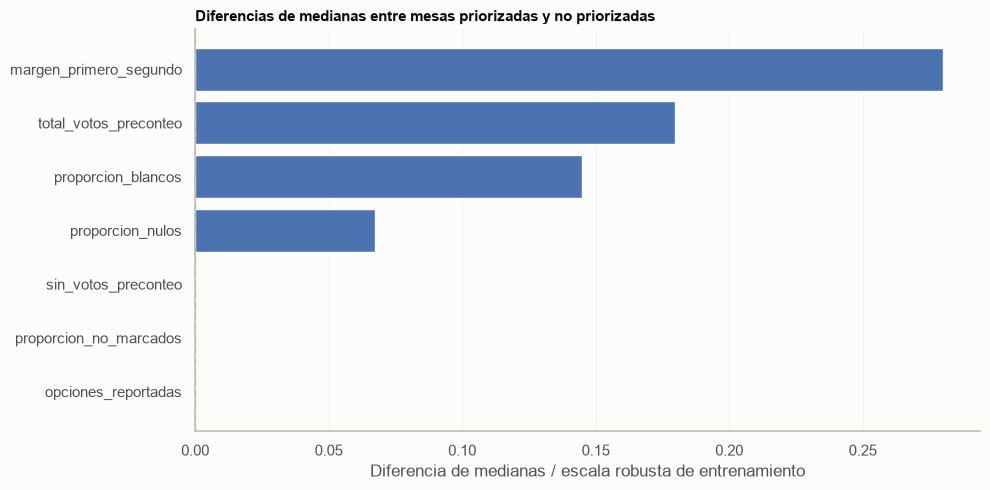

In [306]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Estadísticas calculadas exclusivamente sobre entrenamiento
medianas = pd.Series(
    np.median(X_train_imp, axis=0),
    index=features_if_lof
)

mad = pd.Series(
    np.median(
        np.abs(X_train_imp - np.median(X_train_imp, axis=0)),
        axis=0
    ),
    index=features_if_lof
)

escalas = 1.4826 * mad

# Respaldo para variables con MAD igual a cero
desviaciones = pd.Series(
    np.std(X_train_imp, axis=0),
    index=features_if_lof
)

escalas = escalas.where(
    escalas > 0,
    desviaciones
).replace(0, 1)

# Diferencia de medianas estandarizada
diferencias_robustas = (
    resumen_caracteristicas["diferencia"]
    / escalas
).sort_values()

# Visualización
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    diferencias_robustas.index,
    diferencias_robustas.values
)

ax.axvline(
    0,
    color="gray",
    linestyle="--"
)

ax.set_title(
    "Diferencias de medianas entre mesas priorizadas y no priorizadas"
)

ax.set_xlabel(
    "Diferencia de medianas / escala robusta de entrenamiento"
)

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()



**Interpretación de las características de las mesas priorizadas**

La comparación descriptiva evidencia que las mesas priorizadas mediante LOF presentan algunas diferencias respecto al conjunto restante de prueba.

La mayor diferencia estandarizada corresponde a `margen_primero_segundo`, cuya mediana aumenta de 0,2778 a 0,3401. Asimismo, las mesas priorizadas registran una mediana de 217 votos de preconteo, frente a 205 en las no priorizadas.

Las proporciones de votos blancos y nulos también presentan incrementos moderados. Por su parte, las variables `opciones_reportadas`, `proporcion_no_marcados` y `sin_votos_preconteo` mantienen medianas iguales entre ambos grupos.

En términos generales, las diferencias estandarizadas son reducidas, lo que sugiere que las mesas priorizadas no se distinguen únicamente por desplazamientos pronunciados en las medianas individuales.

Este resultado es consistente con la naturaleza multivariada de LOF, que identifica observaciones con menor densidad local relativa a sus vecinos. En consecuencia, las diferencias descriptivas observadas no deben interpretarse como explicaciones causales ni como evidencia de irregularidades electorales.



##### 5.4.3.4. Generalización a nuevos datos



Se plantea un procedimiento de inferencia para aplicar el modelo LOF seleccionado a nuevas mesas electorales sin disponer previamente de etiquetas de corrección.

El procedimiento conserva las siete variables utilizadas durante el entrenamiento y reutiliza el imputador, el escalador robusto y el modelo previamente ajustados. No se recalculan parámetros ni se utilizan etiquetas durante la generación de puntuaciones.

Como demostración, se emplean observaciones del conjunto de prueba simulando su recepción como datos nuevos. Esta simulación verifica el funcionamiento del procedimiento de inferencia, pero no constituye una evaluación prospectiva independiente adicional.

La capacidad de generalización a elecciones futuras, otros territorios o distribuciones diferentes permanece como una limitación pendiente de validación.


In [307]:

def priorizar_nuevas_mesas(
    nuevas_mesas,
    modelo,
    imputador,
    escalador,
    variables,
    presupuesto=0.05
):
    """
    Genera un ranking de anomalías sin reentrenar
    ni utilizar etiquetas de corrección.
    """
    if not 0 < presupuesto <= 1:
        raise ValueError("El presupuesto debe estar entre 0 y 1.")

    faltantes = set(variables) - set(nuevas_mesas.columns)
    if faltantes:
        raise ValueError(f"Faltan variables: {sorted(faltantes)}")

    if nuevas_mesas.empty:
        raise ValueError("No se recibieron mesas.")

    # Aplicar transformaciones previamente ajustadas
    X_nuevo = nuevas_mesas[variables]
    X_imputado = imputador.transform(X_nuevo)
    X_escalado = escalador.transform(X_imputado)

    # Mayor puntuación = mayor anomalía
    scores = -modelo.score_samples(X_escalado)

    resultado = nuevas_mesas.copy()
    resultado["score_anomalia"] = scores

    resultado = (
        resultado
        .sort_values("score_anomalia", ascending=False)
        .reset_index(drop=True)
    )

    resultado["ranking"] = np.arange(1, len(resultado) + 1)

    k_nuevo = int(np.ceil(len(resultado) * presupuesto))
    resultado["priorizada"] = resultado["ranking"] <= k_nuevo

    return resultado


In [308]:

# Simular datos recibidos sin etiquetas de corrección
columnas_entrada = [
    "dep", "mun", "zona", "puesto", "mesa"
] + features_if_lof

nuevas_mesas = df_priorizacion[
    columnas_entrada
].copy()

# Aplicar el procedimiento de inferencia
ranking_nuevas_mesas = priorizar_nuevas_mesas(
    nuevas_mesas=nuevas_mesas,
    modelo=modelo_lof_final,
    imputador=imputer,
    escalador=scaler,
    variables=features_if_lof,
    presupuesto=0.05
)

print("Mesas procesadas:", len(ranking_nuevas_mesas))
print(
    "Mesas priorizadas:",
    ranking_nuevas_mesas["priorizada"].sum()
)

display(
    ranking_nuevas_mesas[
        ["dep", "mun", "zona", "puesto", "mesa",
         "score_anomalia", "ranking", "priorizada"]
    ].head(15)
)


Mesas procesadas: 17753
Mesas priorizadas: 888


,dep,mun,zona,puesto,mesa,score_anomalia,ranking,priorizada
0,15,151,000,00,000003,3.809771,1,True
1,29,040,099,15,000001,3.676538,2,True
2,29,019,099,06,000001,3.582137,3,True
3,01,001,002,02,000024,3.146827,4,True
4,09,013,000,01,000005,2.713899,5,True
5,07,316,000,00,000003,2.517757,6,True
6,09,052,000,00,000001,2.423982,7,True
7,09,079,000,00,000006,2.316018,8,True
8,24,021,000,01,000015,2.226461,9,True
9,09,130,001,05,000018,2.092272,10,True


In [309]:

# Comparar las puntuaciones obtenidas por ambos procedimientos
comparacion = df_priorizacion[
    ["dep", "mun", "zona", "puesto", "mesa", "score_lof"]
].merge(
    ranking_nuevas_mesas[
        ["dep", "mun", "zona", "puesto", "mesa", "score_anomalia"]
    ],
    on=["dep", "mun", "zona", "puesto", "mesa"],
    how="inner",
    validate="one_to_one"
)

assert len(comparacion) == len(df_priorizacion)

diferencia_maxima = np.max(
    np.abs(
        comparacion["score_lof"]
        - comparacion["score_anomalia"]
    )
)

print("Diferencia máxima:", diferencia_maxima)
print(
    "Puntuaciones equivalentes:",
    np.allclose(
        comparacion["score_lof"],
        comparacion["score_anomalia"],
        rtol=1e-10,
        atol=1e-12
    )
)


Diferencia máxima: 0.0
Puntuaciones equivalentes: True



**Interpretación de la simulación de inferencia**

El procedimiento de inferencia procesó satisfactoriamente 17.753 mesas electorales sin utilizar etiquetas de corrección, generando un ranking de anomalías y seleccionando 888 observaciones correspondientes al presupuesto operativo del 5 %.

Las puntuaciones más elevadas se asignaron a mesas identificadas mediante sus códigos territoriales, permitiendo construir una lista trazable para su eventual revisión.

La simulación demuestra la viabilidad técnica de aplicar el modelo LOF previamente entrenado a observaciones no utilizadas durante su ajuste, conservando las transformaciones originales.

Sin embargo, los datos utilizados corresponden al conjunto de prueba del mismo proceso electoral. Por tanto, esta demostración no constituye evidencia adicional de generalización temporal o territorial.

Para evaluar su utilización en nuevos procesos electorales sería necesario realizar validaciones independientes, especialmente frente a cambios en la distribución de las variables, las características de las mesas y la prevalencia de correcciones.



##### 5.4.3.5. Consideraciones operativas y limitaciones de generalización



**Flujo de aplicación.** Se propone integrar el modelo de detección de anomalías como un mecanismo de apoyo a la revisión de resultados electorales. Su funcionamiento comprendería las siguientes etapas:

1. **Recepción de datos:** incorporar los registros de preconteo de nuevas mesas electorales, verificando su integridad, estructura y disponibilidad de las variables requeridas.
2. **Preprocesamiento:** aplicar el imputador y el escalador ajustados exclusivamente sobre los datos de entrenamiento, sin recalcular sus parámetros.
3. **Inferencia:** utilizar el modelo LOF previamente entrenado para asignar una puntuación de anomalía a cada mesa.
4. **Priorización:** ordenar las observaciones según su puntuación y seleccionar las mesas correspondientes al presupuesto de revisión disponible.
5. **Verificación humana:** contrastar las mesas priorizadas con fuentes oficiales y documentación electoral, sin interpretar automáticamente una puntuación elevada como evidencia de irregularidad.
6. **Monitoreo:** registrar las puntuaciones, las revisiones realizadas y los cambios en las distribuciones de entrada para evaluar periódicamente el comportamiento del sistema.

**Capacidad de generalización.** La evaluación sobre el conjunto independiente de prueba proporciona evidencia inicial de que el modelo puede asignar puntuaciones a mesas no utilizadas durante el entrenamiento. Sin embargo, su Lift@5 % disminuyó de 1,8336 en validación a 1,1684 en prueba, lo que evidencia variabilidad en su capacidad de priorización.

La simulación de inferencia confirmó la viabilidad técnica de procesar 17.753 mesas sin utilizar etiquetas, seleccionando 888 observaciones para revisión. Esta simulación no constituye una validación independiente adicional, dado que reutiliza el conjunto de prueba.

**Limitaciones.** La generalización a nuevas elecciones no ha sido comprobada. Cambios en la participación electoral, la distribución territorial, las opciones reportadas o las condiciones del proceso podrían modificar las relaciones estadísticas aprendidas por LOF. Además, la evaluación se basa en una única partición aleatoria y utiliza las correcciones de escrutinio como referencia indirecta.

**Validación futura.** Antes de utilizar el sistema en un entorno operativo sería recomendable realizar evaluaciones temporales y territoriales independientes, estudiar la estabilidad del ranking mediante múltiples particiones, monitorear cambios en las distribuciones de entrada y verificar la utilidad de las mesas priorizadas mediante revisión especializada.

**Conclusión.** El modelo ofrece un procedimiento reproducible para generar rankings de anomalías y orientar recursos limitados de revisión. No obstante, los resultados actuales respaldan únicamente su utilidad exploratoria sobre el conjunto estudiado. Su implementación en nuevos procesos electorales requeriría validación adicional, supervisión humana y mecanismos de seguimiento.


# **Parte V. Conclusiones**
---

### **5.5. Conclusiones generales**



Este trabajo abordó el problema de anticipar qué mesas electorales de la primera vuelta presidencial de 2026 serían corregidas en el escrutinio y en qué magnitud, a partir de la información disponible antes de este. Para ello se integraron el preconteo, el escrutinio y las novedades en un dataset maestro de 118.350 mesas, con una llave electoral validada y una prevalencia de corrección del 5,07 %. Sobre esta base se desarrollaron tres enfoques complementarios.

**Resumen de resultados en prueba**

| Componente | Modelo seleccionado | Resultado principal | Referencia |
|---|---|---|---|
| Clasificación supervisada | Random forest (conjunto B) | AP = 0,912 (IC 95 %: 0,896–0,926); P = 0,867 y R = 0,892 con τ = 0,205 | Regla `dif_pre_e11 ≠ 0`: P = 0,569, R = 0,896 |
| Regresión supervisada | Random forest sobre `log1p(magnitud)` | MAE = 3,21 votos; R² (log1p) = 0,779 | Mediana: MAE = 10,80 votos |
| Detección de anomalías | LOF (selección en validación) e Isolation Forest (mejor en prueba) | Lift@5 %: IF = 1,90; baseline = 1,69; LOF = 1,17 | Selección aleatoria: Lift = 1 |

**1. La señal principal es la consistencia entre el preconteo y el E-11.** Los tres componentes coinciden en este hallazgo. Con la diferencia entre el total del preconteo y los sufragantes del E-11, el clasificador alcanza una AP de 0,912; sin ella, cae a 0,230, y con el preconteo solo queda entre 0,09 y 0,12. De forma consistente, la detección de anomalías basada únicamente en el preconteo concentra apenas el doble de mesas corregidas que una selección aleatoria. Una parte importante de las correcciones responde a inconsistencias de registro, y no a patrones atípicos en la distribución del voto.

**2. El clasificador mejora la regla simple al reducir las falsas alarmas.** La regla `dif_pre_e11 ≠ 0` ya recupera cerca del 90 % de las mesas corregidas, pero con una precisión del 57 %. El random forest mantiene ese recall y eleva la precisión al 87 %, lo que reduce las falsas alarmas en cerca de un 80 %. Su desempeño se sostiene en departamentos no vistos: la validación *leave-one-department-out* da una AP de 0,908, con valores entre 0,81 y 0,98 por departamento.

**3. La regresión permite priorizar por votos en juego.** El random forest estima la magnitud de las correcciones con un error medio de 3,2 votos y supera a la línea base en todos los rangos de tamaño. Combinado con el clasificador en un esquema de dos etapas, marca el 5,6 % de las mesas, detecta el 89,6 % de las corregidas y estima 17.858 votos frente a 17.490 reales. Ordenando por la magnitud esperada (p̂ · m̂), revisar solo el 1 % de las mesas cubre el 62,4 % de los votos corregidos, frente al 8,9 % si se ordena solo por la probabilidad de corrección. La clasificación y la regresión cumplen así funciones complementarias: la primera decide **qué mesas** revisar y la segunda **cuáles tienen más votos en juego**.

**4. La detección no supervisada aporta una señal débil e inestable.** Los tres métodos superan la selección aleatoria en prueba, pero con Lift@5 % entre 1,17 y 1,90. LOF, seleccionado por su desempeño en validación (1,83), cayó a 1,17 en prueba, lo que indica que una sola partición de validación no basta para elegir el modelo con fiabilidad. Este componente es útil como herramienta exploratoria, pero no como mecanismo principal de priorización.

**Limitaciones**

- Los modelos se entrenaron y evaluaron con una sola elección. Su uso en otros procesos electorales requiere revalidar los modelos y recalibrar el umbral.
- Las correcciones que redistribuyen votos entre candidaturas sin alterar el total no dejan la señal de inconsistencia con el E-11, por lo que los modelos supervisados no logran anticiparlas.
- La disponibilidad temporal de algunas variables de novedades no se verificó con documentación oficial.
- La detección de anomalías se evaluó con una única partición aleatoria, sin validación cruzada.
- Una corrección en el escrutinio no equivale a una irregularidad, y una probabilidad o puntuación alta no constituye evidencia de fraude.

**Trabajo futuro**

Se propone validar los modelos en otras elecciones y por cortes temporales; evaluar la detección de anomalías con múltiples particiones o validación agrupada por territorio; incorporar al componente no supervisado información contextual y de novedades una vez verificada su disponibilidad temporal; y explorar variables que capturen la redistribución de votos entre candidaturas, el principal tipo de corrección que los modelos actuales no anticipan.

**Conclusión.** Los resultados muestran que es posible priorizar con alta precisión la revisión de mesas electorales usando información disponible antes del escrutinio. El esquema de clasificación y regresión en dos etapas es el resultado más útil del proyecto: con un presupuesto de revisión reducido concentra la mayor parte de las mesas y de los votos corregidos. Su valor es operativo, como apoyo a la verificación humana, y no como sistema de detección de irregularidades.

### **5.6. Cumplimiento de los objetivos del proyecto**
---

**Objetivo de negocio.** *Reducir el esfuerzo de revisión de los auditores y observadores electorales con un ordenamiento de mesas basado en evidencia que concentre en pocas mesas la mayor parte de los casos que ameritan revisión.*

**Se cumple.** Con información disponible antes del escrutinio, el clasificador marca el 5,6 % de las mesas y detecta el 89,6 % de las corregidas. Si el presupuesto de revisión es del 1 % de las mesas, el orden por probabilidad × magnitud cubre el 62,4 % de los votos corregidos. Frente a la regla simple preconteo ≠ E-11, el modelo reduce las falsas alarmas en cerca de un 80 %, es decir, mesas que el auditor revisaría en vano.

**Objetivos específicos**

| # | Objetivo específico (Parte I) | Resultado | Estado |
|---|---|---|---|
| 1 | Integrar y validar los registros de preconteo, escrutinio, novedades y catálogos a nivel de mesa | Dataset maestro de 118 350 mesas × 40 columnas, con llave electoral validada, huellas MD5 verificadas y cruce completo entre fuentes (Parte III, sección 5.0) | Cumplido |
| 2 | Caracterizar las mesas con indicadores de participación, distribución y concentración del voto, y consistencia entre fuentes | Análisis exploratorio de las tres fuentes (Parte II) y variables de composición y consistencia (sección 5.0.16) | Cumplido |
| 3 | Entrenar y comparar clasificadores | Se compararon árbol de decisión, random forest y KNN. Durante el entendimiento de los datos, la variable objetivo se precisó como **la mesa será corregida en el escrutinio** (`y_corregida`), que es la que responde al objetivo de negocio. Mejor modelo: random forest, AP = 0,912 | Cumplido, con objetivo ajustado |
| 4 | Entrenar y comparar modelos de regresión para la magnitud de la discrepancia | Se compararon regresión lineal (Ridge), random forest y gradient boosting. Mejor modelo: random forest, MAE = 3,2 votos frente a 10,8 de la línea base | Cumplido |
| 5 | Aplicar Isolation Forest y LOF para puntuar la atipicidad y producir un listado priorizado | Ambos modelos y un baseline robusto se evaluaron con Lift@5 %; Isolation Forest logró 1,90 en prueba y se generó un listado priorizado (sección 5.4.3) | Cumplido, con señal débil |
| 6 | Comparar contra métodos de referencia y documentar limitaciones | Cada componente se comparó con su línea base (regla simple, mediana, azar) y se documentaron las limitaciones (sección 5.5) | Cumplido |

**Ajustes respecto al planteamiento inicial.** En la Parte I se planteó clasificar las novedades documentadas y usar regresión logística. El análisis de la Parte II mostró que la pregunta útil para los auditores es si la mesa será corregida en el escrutinio, y que las variables del escrutinio (recuento de la comisión, mesa excluida, total de novedades) no pueden usarse como entrada porque solo se conocen después; por eso se redefinió la variable objetivo y se excluyeron esas variables por fuga de información. Para la clasificación se usaron árbol de decisión, random forest y KNN.

## **Referencias bibliográficas**
---

Chandola, V., Banerjee, A., & Kumar, V. (2009). Anomaly detection: A survey. ACM Computing Surveys, 41(3), Article 15. https://doi.org/10.1145/1541880.1541882

Constitución Política de Colombia [Const.]. (1991). Artículo 265. https://www.cne.gov.co/leyes-y-actos-legislativos-cne

Han, S., Hu, X., Huang, H., Jiang, M., & Zhao, Y. (2022). ADBench: Anomaly detection benchmark. Advances in Neural Information Processing Systems, 35. https://papers.neurips.cc/paper_files/paper/2022/hash/cf93972b116ca5268827d575f2cc226b-Abstract-Datasets_and_Benchmarks.html

Registraduría Nacional del Estado Civil. (2026). Estas son las diferencias entre los resultados de la transmisión y el escrutinio oficial. https://wapp.registraduria.gov.co/electoral/2026/presidente-de-la-republica/documentos/narrativas/diferencias_transmision_escrutinio.pdf

Registraduría Nacional del Estado Civil. (s. f.). Cartilla de escrutinios. https://www.registraduria.gov.co/IMG/pdf/cartilla_escrutinios.pdf

Zhang, M., Alvarez, R. M., & Levin, I. (2019). Election forensics: Using machine learning and synthetic data for possible election anomaly detection. PLOS ONE, 14(10), Article e0223950. https://doi.org/10.1371/journal.pone.0223950

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*